In [2]:
# ============================================================
# V-NET STEP 1. 공통 환경 및 COCA 경로 확인
# - 3D U-Net과 동일한 workstation / COCA dataset / split / cache 사용
# - checkpoint와 log만 V-Net 전용 경로로 분리
# ============================================================

import os
import sys
import json
import numpy as np
import torch

COCA_ROOT = "/home/korea1/workspace/datasets/COCA"

TRAIN_CACHE_ROOT = os.path.join(COCA_ROOT, "coca_train_volume_cache_npy")
VAL_CACHE_ROOT = os.path.join(COCA_ROOT, "coca_validation_volume_cache_npy")
SPLIT_PATH = os.path.join(COCA_ROOT, "coca_patient_split_80_10_10.json")

VNET_CHECKPOINT_ROOT = os.path.join(COCA_ROOT, "checkpoints", "vnet")
VNET_LOG_ROOT = os.path.join(COCA_ROOT, "logs", "vnet")

print("====== V-Net Environment ======")
print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("NumPy :", np.__version__)

print("\n====== Shared COCA Data ======")
print("COCA_ROOT :", COCA_ROOT)
print("COCA_ROOT Exists :", os.path.isdir(COCA_ROOT))
print("Train Cache Exists :", os.path.isdir(TRAIN_CACHE_ROOT))
print("Val Cache Exists :", os.path.isdir(VAL_CACHE_ROOT))
print("Split Exists :", os.path.isfile(SPLIT_PATH))

print("\n====== V-Net Output Paths ======")
print("Checkpoint :", VNET_CHECKPOINT_ROOT)
print("Log :", VNET_LOG_ROOT)

====== V-Net Environment ======
Python : 3.12.13
PyTorch : 2.13.0+cu130
NumPy : 2.5.1

====== Shared COCA Data ======
COCA_ROOT : /home/korea1/workspace/datasets/COCA
COCA_ROOT Exists : True
Train Cache Exists : True
Val Cache Exists : True
Split Exists : True

====== V-Net Output Paths ======
Checkpoint : /home/korea1/workspace/datasets/COCA/checkpoints/vnet
Log : /home/korea1/workspace/datasets/COCA/logs/vnet


In [3]:
# ============================================================
# V-NET STEP 2. Patient-level Split 불러오기 및 검증
# - 기존 3D U-Net과 동일한 split JSON 사용
# - Train / Validation / Test patient leakage 확인
# ============================================================

with open(SPLIT_PATH, "r", encoding="utf-8") as f:
    split_data = json.load(f)

train_ids = [str(pid) for pid in split_data["train_patient_ids"]]
val_ids = [str(pid) for pid in split_data["validation_patient_ids"]]
test_ids = [str(pid) for pid in split_data["test_patient_ids"]]

train_val_overlap = set(train_ids) & set(val_ids)
train_test_overlap = set(train_ids) & set(test_ids)
val_test_overlap = set(val_ids) & set(test_ids)

print("====== V-Net Patient Split ======")
print("Train Patients :", len(train_ids))
print("Validation Patients :", len(val_ids))
print("Test Patients :", len(test_ids))
print("Train-Val Overlap :", len(train_val_overlap))
print("Train-Test Overlap :", len(train_test_overlap))
print("Val-Test Overlap :", len(val_test_overlap))
print("Random Seed :", split_data["random_seed"])
print("Split Method :", split_data["split_method"])

====== V-Net Patient Split ======
Train Patients : 356
Validation Patients : 44
Test Patients : 45
Train-Val Overlap : 0
Train-Test Overlap : 0
Val-Test Overlap : 0
Random Seed : 42
Split Method : patient_level_random_fixed_seed


In [4]:
# ============================================================
# V-NET STEP 3. 공용 Train / Validation Cache 확인
# - 3D U-Net에서 생성한 NPY cache를 V-Net에서도 그대로 사용
# - 새 전처리나 새 cache를 만들지 않음
# ============================================================

train_ct_files = sorted([
    name for name in os.listdir(TRAIN_CACHE_ROOT)
    if name.endswith("_ct.npy")
])

train_gt_files = sorted([
    name for name in os.listdir(TRAIN_CACHE_ROOT)
    if name.endswith("_gt.npy")
])

val_ct_files = sorted([
    name for name in os.listdir(VAL_CACHE_ROOT)
    if name.endswith("_ct.npy")
])

val_gt_files = sorted([
    name for name in os.listdir(VAL_CACHE_ROOT)
    if name.endswith("_gt.npy")
])

print("====== Shared COCA Cache ======")
print("Train CT :", len(train_ct_files))
print("Train GT :", len(train_gt_files))
print("Validation CT :", len(val_ct_files))
print("Validation GT :", len(val_gt_files))

train_cache_ok = len(train_ct_files) == 357 and len(train_gt_files) == 357
val_cache_ok = len(val_ct_files) == 44 and len(val_gt_files) == 44

print("\nTrain Cache 정상 :", train_cache_ok)
print("Validation Cache 정상 :", val_cache_ok)
print("V-Net Cache Reuse 가능 :", train_cache_ok and val_cache_ok)

====== Shared COCA Cache ======
Train CT : 357
Train GT : 357
Validation CT : 44
Validation GT : 44

Train Cache 정상 : True
Validation Cache 정상 : True
V-Net Cache Reuse 가능 : True


In [5]:
# ============================================================
# V-NET STEP 4. 공용 전처리 / Window 설정 파일 확인
# - 3D U-Net에서 확정한 XY crop, HU normalization, Z-window 설정 재사용
# - V-Net용으로 전처리 조건을 새로 결정하지 않음
# ============================================================

XY_CONFIG_PATH = os.path.join(COCA_ROOT, "coca_final_xy_preprocessing.json")
INTENSITY_CONFIG_PATH = os.path.join(COCA_ROOT, "coca_final_intensity_preprocessing.json")
TRAINING_STRATEGY_PATH = os.path.join(COCA_ROOT, "coca_training_strategy.json")
TRAIN_WINDOW_QC_PATH = os.path.join(COCA_ROOT, "coca_step54_train_window_gt_qc.json")
VAL_WINDOW_MANIFEST_PATH = os.path.join(COCA_ROOT, "coca_validation_window_manifest.json")

config_paths = {
    "XY Config": XY_CONFIG_PATH,
    "Intensity Config": INTENSITY_CONFIG_PATH,
    "Training Strategy": TRAINING_STRATEGY_PATH,
    "Train Window QC": TRAIN_WINDOW_QC_PATH,
    "Validation Window Manifest": VAL_WINDOW_MANIFEST_PATH,
}

print("====== Shared Preprocessing Files ======")

for name, path in config_paths.items():
    print(f"{name:28s}: {os.path.isfile(path)}")

all_shared_files_exist = all(os.path.isfile(path) for path in config_paths.values())

print("\n모든 공용 설정 파일 존재 :", all_shared_files_exist)

====== Shared Preprocessing Files ======
XY Config                   : True
Intensity Config            : True
Training Strategy           : True
Train Window QC             : True
Validation Window Manifest  : True

모든 공용 설정 파일 존재 : True


In [6]:
# ============================================================
# V-NET STEP 5. 공용 전처리 / 학습 설정 불러오기 및 검증
# - 3D U-Net에서 확정한 설정 파일을 그대로 사용
# - Train 710 windows / Validation 88 windows 구조 확인
# ============================================================

with open(XY_CONFIG_PATH, "r", encoding="utf-8") as f:
    xy_config = json.load(f)

with open(INTENSITY_CONFIG_PATH, "r", encoding="utf-8") as f:
    intensity_config = json.load(f)

with open(TRAINING_STRATEGY_PATH, "r", encoding="utf-8") as f:
    training_strategy = json.load(f)

with open(TRAIN_WINDOW_QC_PATH, "r", encoding="utf-8") as f:
    train_window_qc = json.load(f)

with open(VAL_WINDOW_MANIFEST_PATH, "r", encoding="utf-8") as f:
    val_window_manifest = json.load(f)

print("====== Shared Preprocessing ======")
print("Original HW :", xy_config["original_hw"])
print("Crop HW :", xy_config["crop_hw"])
print("Crop X :", xy_config["crop_x"])
print("Crop Y :", xy_config["crop_y"])
print("Resize After Crop :", xy_config["resize_after_crop"])
print("GT Area Filter :", xy_config["gt_area_filter_applied"])

print("\n====== Intensity / Windowing ======")
print("HU Clip :", intensity_config["hu_clip"])
print("Normalized Range :", intensity_config["normalized_range"])
print("Z Window Size :", intensity_config["z_window_size"])
print("Z Window Stride :", intensity_config["z_window_stride"])
print("Model Input Shape :", intensity_config["model_input_shape_dhw"])

print("\n====== Training Data ======")
print("Train Patient Groups :", training_strategy["train_patient_groups"])
print("Train Volumes :", training_strategy["train_volumes"])
print("Train Windows :", len(train_window_qc))
print("Validation Windows :", len(val_window_manifest))
print("Positive Windows :", training_strategy["positive_windows"])
print("Background-only Windows :", training_strategy["background_only_windows"])

====== Shared Preprocessing ======
Original HW : [512, 512]
Crop HW : [400, 400]
Crop X : [62, 462]
Crop Y : [36, 436]
Resize After Crop : False
GT Area Filter : False

====== Intensity / Windowing ======
HU Clip : [-1000.0, 2000.0]
Normalized Range : [-1.0, 2.0]
Z Window Size : 40
Z Window Stride : 20
Model Input Shape : [40, 400, 400]

====== Training Data ======
Train Patient Groups : 356
Train Volumes : 357
Train Windows : 710
Validation Windows : 88
Positive Windows : 670
Background-only Windows : 40


In [7]:
# ============================================================
# V-NET STEP 6. 공용 입력 / 전처리 설정 확정
# - 3D U-Net과 동일한 입력 조건 사용
# - 모델 구조만 V-Net으로 변경
# ============================================================

NUM_CLASSES = int(training_strategy["num_classes"])

FINAL_XY_CROP_SIZE = int(xy_config["crop_hw"][0])
FINAL_CROP_X0, FINAL_CROP_X1 = map(int, xy_config["crop_x"])
FINAL_CROP_Y0, FINAL_CROP_Y1 = map(int, xy_config["crop_y"])

HU_CLIP_MIN, HU_CLIP_MAX = map(float, intensity_config["hu_clip"])
HU_SCALE_DIVISOR = float(intensity_config["scale_divisor"])

CT_Z_PADDING_HU = float(intensity_config["ct_z_padding_hu"])
GT_Z_PADDING_VALUE = int(intensity_config["gt_z_padding_value"])

Z_WINDOW_SIZE = int(intensity_config["z_window_size"])
Z_WINDOW_STRIDE = int(intensity_config["z_window_stride"])

MODEL_INPUT_SHAPE = tuple(
    int(value) for value in intensity_config["model_input_shape_dhw"]
)

CLASS_NAMES = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

print("====== V-Net Shared Input Config ======")
print("Num Classes :", NUM_CLASSES)
print("Classes :", CLASS_NAMES)
print("Input Shape :", MODEL_INPUT_SHAPE)
print("XY Crop :", (FINAL_CROP_X0, FINAL_CROP_X1, FINAL_CROP_Y0, FINAL_CROP_Y1))
print("HU Clip :", (HU_CLIP_MIN, HU_CLIP_MAX))
print("HU Scale Divisor :", HU_SCALE_DIVISOR)
print("Z Window :", Z_WINDOW_SIZE)
print("Z Stride :", Z_WINDOW_STRIDE)
print("CT Z Padding HU :", CT_Z_PADDING_HU)
print("GT Z Padding Value :", GT_Z_PADDING_VALUE)

====== V-Net Shared Input Config ======
Num Classes : 5
Classes : {0: 'Background', 1: 'LAD', 2: 'LCX', 3: 'LCA', 4: 'RCA'}
Input Shape : (40, 400, 400)
XY Crop : (62, 462, 36, 436)
HU Clip : (-1000.0, 2000.0)
HU Scale Divisor : 1000.0
Z Window : 40
Z Stride : 20
CT Z Padding HU : -1000.0
GT Z Padding Value : 0


In [8]:
# ============================================================
# V-NET STEP 7. Train / Validation Window Manifest 확정
# - 3D U-Net에서 확정한 동일 window manifest 재사용
# - Train 710 / Validation 88 windows 확인
# - Patient split과 manifest 간 leakage 확인
# ============================================================

train_window_manifest = [dict(row) for row in train_window_qc]
val_window_manifest = [dict(row) for row in val_window_manifest]

train_manifest_patients = {str(row["patient_id"]) for row in train_window_manifest}
val_manifest_patients = {str(row["patient_id"]) for row in val_window_manifest}

train_positive = sum(bool(row["has_cac"]) for row in train_window_manifest)
train_background = sum(not bool(row["has_cac"]) for row in train_window_manifest)

val_positive = sum(bool(row["has_cac"]) for row in val_window_manifest)
val_background = sum(not bool(row["has_cac"]) for row in val_window_manifest)

manifest_leakage = train_manifest_patients & val_manifest_patients

print("====== V-Net Window Manifest ======")
print("Train Windows :", len(train_window_manifest))
print("Validation Windows :", len(val_window_manifest))

print("\n====== Train Window Distribution ======")
print("Positive :", train_positive)
print("Background-only :", train_background)

print("\n====== Validation Window Distribution ======")
print("Positive :", val_positive)
print("Background-only :", val_background)

print("\n====== Manifest Patient Check ======")
print("Train Patients :", len(train_manifest_patients))
print("Validation Patients :", len(val_manifest_patients))
print("Train ↔ Validation Leakage :", len(manifest_leakage))

====== V-Net Window Manifest ======
Train Windows : 710
Validation Windows : 88

====== Train Window Distribution ======
Positive : 670
Background-only : 40

====== Validation Window Distribution ======
Positive : 86
Background-only : 2

====== Manifest Patient Check ======
Train Patients : 356
Validation Patients : 44
Train ↔ Validation Leakage : 0


In [9]:
# ============================================================
# V-NET STEP 8. 공용 전처리 Utility 함수 정의
# - 3D U-Net과 동일한 HU normalization / Z padding 규칙 사용
# - CT : HU [-1000, 2000] clip 후 /1000 → [-1, 2]
# - Depth < 40이면 앞/뒤 symmetric padding
# ============================================================

def normalize_ct_hu(ct_hu):
    ct_clipped = np.clip(
        ct_hu.astype(np.float32),
        HU_CLIP_MIN,
        HU_CLIP_MAX
    )

    return ct_clipped / HU_SCALE_DIVISOR


def get_z_padding(depth, target_depth=Z_WINDOW_SIZE):
    if depth >= target_depth:
        return 0, 0

    total_padding = target_depth - depth
    pad_before = total_padding // 2
    pad_after = total_padding - pad_before

    return pad_before, pad_after


# ------------------------------------------------------------
# 간단 동작 확인
# ------------------------------------------------------------

test_hu = np.array(
    [-1500.0, -1000.0, 0.0, 1000.0, 2500.0],
    dtype=np.float32
)

test_normalized = normalize_ct_hu(test_hu)

print("====== V-Net Preprocessing Utility ======")
print("HU Input :", test_hu.tolist())
print("Normalized :", test_normalized.tolist())

for depth in [34, 37, 40, 57]:
    pad_before, pad_after = get_z_padding(depth)

    print(
        f"Depth {depth:2d}"
        f" | Pad Before = {pad_before}"
        f" | Pad After = {pad_after}"
        f" | Final = {depth + pad_before + pad_after}"
    )

====== V-Net Preprocessing Utility ======
HU Input : [-1500.0, -1000.0, 0.0, 1000.0, 2500.0]
Normalized : [-1.0, -1.0, 0.0, 1.0, 2.0]
Depth 34 | Pad Before = 3 | Pad After = 3 | Final = 40
Depth 37 | Pad Before = 1 | Pad After = 2 | Final = 40
Depth 40 | Pad Before = 0 | Pad After = 0 | Final = 40
Depth 57 | Pad Before = 0 | Pad After = 0 | Final = 57


In [10]:
# ============================================================
# V-NET STEP 9. COCA Window Dataset 정의
# - 3D U-Net과 동일한 Train / Validation cache 사용
# - 입력  : [1, 40, 400, 400] float32
# - GT    : [40, 400, 400] int64
# - Depth < 40인 volume은 동일한 symmetric Z padding 적용
# ============================================================

from torch.utils.data import Dataset


class COCAWindowDataset(Dataset):

    def __init__(self, window_manifest, cache_root):
        self.window_manifest = window_manifest
        self.cache_root = cache_root

    def __len__(self):
        return len(self.window_manifest)

    def __getitem__(self, index):
        row = self.window_manifest[index]

        patient_id = str(row["patient_id"])
        volume_id = str(row["volume_id"])
        window_id = str(row["window_id"])

        ct_path = os.path.join(self.cache_root, f"{volume_id}_ct.npy")
        gt_path = os.path.join(self.cache_root, f"{volume_id}_gt.npy")

        if not os.path.isfile(ct_path):
            raise FileNotFoundError(ct_path)

        if not os.path.isfile(gt_path):
            raise FileNotFoundError(gt_path)

        ct_mmap = np.load(ct_path, mmap_mode="r")
        gt_mmap = np.load(gt_path, mmap_mode="r")

        if ct_mmap.shape != gt_mmap.shape:
            raise ValueError(
                f"CT/GT shape 불일치 | Volume={volume_id} "
                f"| CT={ct_mmap.shape} | GT={gt_mmap.shape}"
            )

        depth = int(ct_mmap.shape[0])

        # ----------------------------------------------------
        # Depth < 40 : symmetric Z padding
        # ----------------------------------------------------

        if depth < Z_WINDOW_SIZE:
            pad_before, pad_after = get_z_padding(depth)

            ct_source = np.array(ct_mmap, dtype=np.int16, copy=True)
            gt_source = np.array(gt_mmap, dtype=np.uint8, copy=True)

            ct_window = np.pad(
                ct_source,
                ((pad_before, pad_after), (0, 0), (0, 0)),
                mode="constant",
                constant_values=CT_Z_PADDING_HU
            )

            gt_window = np.pad(
                gt_source,
                ((pad_before, pad_after), (0, 0), (0, 0)),
                mode="constant",
                constant_values=GT_Z_PADDING_VALUE
            )

        # ----------------------------------------------------
        # Depth >= 40 : manifest의 sliding window 사용
        # ----------------------------------------------------

        else:
            pad_before = 0
            pad_after = 0

            z_start = int(row["source_z_start"])
            z_end = int(row["source_z_end_exclusive"])

            if z_end - z_start != Z_WINDOW_SIZE:
                raise ValueError(
                    f"Window depth 오류 | Window={window_id} "
                    f"| Z={z_start}:{z_end}"
                )

            ct_window = np.array(
                ct_mmap[z_start:z_end],
                dtype=np.int16,
                copy=True
            )

            gt_window = np.array(
                gt_mmap[z_start:z_end],
                dtype=np.uint8,
                copy=True
            )

        expected_shape = (
            Z_WINDOW_SIZE,
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE
        )

        if ct_window.shape != expected_shape:
            raise ValueError(
                f"CT Window shape 오류 | Window={window_id} "
                f"| Shape={ct_window.shape}"
            )

        if gt_window.shape != expected_shape:
            raise ValueError(
                f"GT Window shape 오류 | Window={window_id} "
                f"| Shape={gt_window.shape}"
            )

        ct_normalized = normalize_ct_hu(ct_window)

        ct_tensor = torch.from_numpy(
            np.array(ct_normalized, dtype=np.float32, copy=True)
        ).unsqueeze(0)

        gt_tensor = torch.from_numpy(
            np.array(gt_window, dtype=np.int64, copy=True)
        )

        return {
            "ct": ct_tensor,
            "gt": gt_tensor,
            "patient_id": patient_id,
            "volume_id": volume_id,
            "window_id": window_id,
            "has_cac": bool(row["has_cac"]),
            "foreground_pixels": int(row["foreground_pixels"]),
            "pad_before": int(pad_before),
            "pad_after": int(pad_after),
        }


print("COCAWindowDataset 정의 완료")

COCAWindowDataset 정의 완료


In [11]:
# ============================================================
# V-NET STEP 10. Train / Validation Dataset 생성
# - 동일한 window manifest와 cache를 사용해 Dataset 생성
# - Train 710 / Validation 88 sample 확인
# ============================================================

train_dataset = COCAWindowDataset(
    window_manifest=train_window_manifest,
    cache_root=TRAIN_CACHE_ROOT
)

val_dataset = COCAWindowDataset(
    window_manifest=val_window_manifest,
    cache_root=VAL_CACHE_ROOT
)

print("====== V-Net Dataset ======")
print("Train Dataset :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))

====== V-Net Dataset ======
Train Dataset : 710
Validation Dataset : 88


In [12]:
# ============================================================
# V-NET STEP 11. Train / Validation Dataset Sample QC
# - 실제 cache → window → normalization → tensor 변환 확인
# - Manifest foreground pixel과 실제 GT pixel 수 일치 확인
# ============================================================

train_sample = train_dataset[0]
val_sample = val_dataset[0]

def print_sample_qc(name, sample, manifest_row):
    actual_fg = int(torch.sum(sample["gt"] > 0))
    expected_fg = int(manifest_row["foreground_pixels"])

    print(f"====== {name} Sample ======")
    print("Patient :", sample["patient_id"])
    print("Volume :", sample["volume_id"])
    print("Window :", sample["window_id"])

    print("CT Shape :", tuple(sample["ct"].shape))
    print("GT Shape :", tuple(sample["gt"].shape))
    print("CT dtype :", sample["ct"].dtype)
    print("GT dtype :", sample["gt"].dtype)

    print("CT Range :", float(sample["ct"].min()), "~", float(sample["ct"].max()))
    print("GT Classes :", torch.unique(sample["gt"]).tolist())

    print("Manifest FG :", expected_fg)
    print("Actual FG :", actual_fg)
    print("FG Match :", expected_fg == actual_fg)


print_sample_qc("Train", train_sample, train_window_manifest[0])
print()
print_sample_qc("Validation", val_sample, val_window_manifest[0])

====== Train Sample ======
Patient : 0
Volume : 0
Window : 0_w00
CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)
CT dtype : torch.float32
GT dtype : torch.int64
CT Range : -1.0 ~ 1.0140000581741333
GT Classes : [0, 4]
Manifest FG : 13
Actual FG : 13
FG Match : True

====== Validation Sample ======
Patient : 21
Volume : 21
Window : 21_w00
CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)
CT dtype : torch.float32
GT dtype : torch.int64
CT Range : -1.0 ~ 1.4490000009536743
GT Classes : [0, 3]
Manifest FG : 40
Actual FG : 40
FG Match : True


In [13]:
# ============================================================
# V-NET STEP 12. 랜덤 20 Window Dataset Integrity QC
# - Manifest의 LAD / LCX / LCA / RCA pixel 수와 실제 GT 비교
# - Train Dataset cache가 정확히 재사용되고 있는지 확인
# ============================================================

import random

random.seed(42)

integrity_indices = random.sample(
    range(len(train_dataset)),
    k=20
)

integrity_errors = []

for index in integrity_indices:
    sample = train_dataset[index]
    row = train_window_manifest[index]

    actual_counts = {
        1: int(torch.sum(sample["gt"] == 1)),
        2: int(torch.sum(sample["gt"] == 2)),
        3: int(torch.sum(sample["gt"] == 3)),
        4: int(torch.sum(sample["gt"] == 4)),
    }

    expected_counts = {
        1: int(row["lad_pixels"]),
        2: int(row["lcx_pixels"]),
        3: int(row["lca_pixels"]),
        4: int(row["rca_pixels"]),
    }

    actual_fg = int(torch.sum(sample["gt"] > 0))
    expected_fg = int(row["foreground_pixels"])

    if actual_counts != expected_counts or actual_fg != expected_fg:
        integrity_errors.append({
            "index": index,
            "window_id": sample["window_id"],
            "expected_fg": expected_fg,
            "actual_fg": actual_fg,
            "expected_counts": expected_counts,
            "actual_counts": actual_counts,
        })

print("====== V-Net Dataset Integrity QC ======")
print("Checked :", len(integrity_indices))
print("Errors :", len(integrity_errors))

====== V-Net Dataset Integrity QC ======
Checked : 20
Errors : 0


In [14]:
# ============================================================
# V-NET STEP 13. Short-volume Z Padding QC
# - Depth 34인 Patient 36 sample 확인
# - CT padding = -1.0
# - GT padding = 0
# ============================================================

short_index = next(
    i for i, row in enumerate(train_window_manifest)
    if str(row["patient_id"]) == "36"
)

short_sample = train_dataset[short_index]

pad_before = short_sample["pad_before"]
pad_after = short_sample["pad_after"]

front_ct_ok = (
    bool(torch.all(short_sample["ct"][:, :pad_before] == -1.0))
    if pad_before > 0 else True
)

back_ct_ok = (
    bool(torch.all(short_sample["ct"][:, -pad_after:] == -1.0))
    if pad_after > 0 else True
)

front_gt_ok = (
    bool(torch.all(short_sample["gt"][:pad_before] == 0))
    if pad_before > 0 else True
)

back_gt_ok = (
    bool(torch.all(short_sample["gt"][-pad_after:] == 0))
    if pad_after > 0 else True
)

print("====== V-Net Short-volume Padding QC ======")
print("Patient :", short_sample["patient_id"])
print("CT Shape :", tuple(short_sample["ct"].shape))
print("GT Shape :", tuple(short_sample["gt"].shape))
print("Pad Before :", pad_before)
print("Pad After :", pad_after)

print("\nCT Front Padding = -1 :", front_ct_ok)
print("CT Back Padding = -1 :", back_ct_ok)
print("GT Front Padding = 0 :", front_gt_ok)
print("GT Back Padding = 0 :", back_gt_ok)

====== V-Net Short-volume Padding QC ======
Patient : 36
CT Shape : (1, 40, 400, 400)
GT Shape : (40, 400, 400)
Pad Before : 3
Pad After : 3

CT Front Padding = -1 : True
CT Back Padding = -1 : True
GT Front Padding = 0 : True
GT Back Padding = 0 : True


In [15]:
# ============================================================
# V-NET STEP 14. Train / Validation DataLoader 생성
# - 3D U-Net과 동일하게 batch_size=1, num_workers=0
# - 현재 공유 GPU 환경을 고려해 pin_memory=False 사용
# - Train shuffle=True / Validation shuffle=False
# ============================================================

from torch.utils.data import DataLoader

BATCH_SIZE = 1
PIN_MEMORY = False

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

print("====== V-Net DataLoader ======")
print("Train Dataset :", len(train_dataset))
print("Train Batches :", len(train_loader))
print("Validation Dataset :", len(val_dataset))
print("Validation Batches :", len(val_loader))
print("Batch Size :", BATCH_SIZE)
print("Pin Memory :", PIN_MEMORY)

====== V-Net DataLoader ======
Train Dataset : 710
Train Batches : 710
Validation Dataset : 88
Validation Batches : 88
Batch Size : 1
Pin Memory : False


In [16]:
# ============================================================
# V-NET STEP 15. DataLoader First Batch QC 재실행
# - pin_memory=False 상태에서 Train / Validation 첫 batch 확인
# - 아직 GPU 전송은 하지 않음
# ============================================================

train_first_batch = next(iter(train_loader))
val_first_batch = next(iter(val_loader))

print("====== Train First Batch ======")
print("CT Shape :", tuple(train_first_batch["ct"].shape))
print("GT Shape :", tuple(train_first_batch["gt"].shape))
print("CT dtype :", train_first_batch["ct"].dtype)
print("GT dtype :", train_first_batch["gt"].dtype)
print("Patient :", train_first_batch["patient_id"])
print("Window :", train_first_batch["window_id"])

print("\n====== Validation First Batch ======")
print("CT Shape :", tuple(val_first_batch["ct"].shape))
print("GT Shape :", tuple(val_first_batch["gt"].shape))
print("CT dtype :", val_first_batch["ct"].dtype)
print("GT dtype :", val_first_batch["gt"].dtype)
print("Patient :", val_first_batch["patient_id"])
print("Window :", val_first_batch["window_id"])

====== Train First Batch ======
CT Shape : (1, 1, 40, 400, 400)
GT Shape : (1, 40, 400, 400)
CT dtype : torch.float32
GT dtype : torch.int64
Patient : ['289']
Window : ['289_w02']

====== Validation First Batch ======
CT Shape : (1, 1, 40, 400, 400)
GT Shape : (1, 40, 400, 400)
CT dtype : torch.float32
GT dtype : torch.int64
Patient : ['21']
Window : ['21_w00']


In [17]:
# ============================================================
# V-NET STEP 15A. CPU-safe DataLoader 재생성
# - 현재 GPU VRAM 부족으로 pin_memory=False 사용
# - Dataset / batch 구성에는 영향 없음
# - 실제 GPU 학습 직전 pin_memory=True로 다시 설정
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    drop_last=False
)

print("====== CPU-safe DataLoader ======")
print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))
print("pin_memory :", False)

====== CPU-safe DataLoader ======
Train Batches : 710
Validation Batches : 88
pin_memory : False


In [18]:
# ============================================================
# V-NET STEP 16. 공용 Loss 설정 확인
# - 3D U-Net과 동일한 Dice + CrossEntropy 설정 사용
# - 모델 구조만 V-Net으로 변경하여 비교 조건 유지
# ============================================================

loss_config = training_strategy["loss"]

print("====== Shared Loss Configuration ======")
print("Loss Config :", loss_config)

print("\nType :", type(loss_config).__name__)

if isinstance(loss_config, dict):
    for key, value in loss_config.items():
        print(f"{key} : {value}")

====== Shared Loss Configuration ======
Loss Config : {'type': 'macro_foreground_dice_plus_cross_entropy', 'dice_weight': 0.7, 'ce_weight': 0.3, 'dice_classes': ['LAD', 'LCX', 'LCA', 'RCA'], 'dice_background_excluded': True, 'cross_entropy_class_weights': None}

Type : dict
type : macro_foreground_dice_plus_cross_entropy
dice_weight : 0.7
ce_weight : 0.3
dice_classes : ['LAD', 'LCX', 'LCA', 'RCA']
dice_background_excluded : True
cross_entropy_class_weights : None


In [19]:
# ============================================================
# V-NET STEP 17. Dice + CrossEntropy Loss 정의
# - 3D U-Net과 동일한 Loss 사용
# - Foreground 4개 class의 Macro Dice Loss + unweighted CE
# - 최종 Loss = 0.7 × Dice Loss + 0.3 × CE Loss
# ============================================================

import torch.nn as nn
import torch.nn.functional as F

DICE_WEIGHT = float(loss_config["dice_weight"])
CE_WEIGHT = float(loss_config["ce_weight"])
DICE_SMOOTH = 1e-5

FOREGROUND_CLASSES = [1, 2, 3, 4]


class ForegroundMacroDiceLoss(nn.Module):

    def __init__(self, foreground_classes, smooth=1e-5):
        super().__init__()
        self.foreground_classes = foreground_classes
        self.smooth = smooth

    def forward(self, logits, target):
        probabilities = torch.softmax(logits, dim=1)
        class_dice_scores = []

        for class_id in self.foreground_classes:
            pred = probabilities[:, class_id]
            gt = (target == class_id).float()

            intersection = torch.sum(pred * gt, dim=(1, 2, 3))
            denominator = torch.sum(pred, dim=(1, 2, 3)) + torch.sum(gt, dim=(1, 2, 3))

            dice = (2.0 * intersection + self.smooth) / (
                denominator + self.smooth
            )

            class_dice_scores.append(dice)

        macro_dice = torch.stack(class_dice_scores, dim=1).mean()

        return 1.0 - macro_dice


class DiceCELoss(nn.Module):

    def __init__(self, dice_weight=0.7, ce_weight=0.3):
        super().__init__()

        self.dice_weight = dice_weight
        self.ce_weight = ce_weight

        self.dice_loss = ForegroundMacroDiceLoss(
            foreground_classes=FOREGROUND_CLASSES,
            smooth=DICE_SMOOTH
        )

    def forward(self, logits, target):
        dice_loss = self.dice_loss(logits, target)
        ce_loss = F.cross_entropy(logits, target)

        total_loss = (
            self.dice_weight * dice_loss
            + self.ce_weight * ce_loss
        )

        return {
            "loss": total_loss,
            "dice_loss": dice_loss,
            "ce_loss": ce_loss,
        }


criterion = DiceCELoss(
    dice_weight=DICE_WEIGHT,
    ce_weight=CE_WEIGHT
)

print("====== V-Net Loss ======")
print("Dice Weight :", DICE_WEIGHT)
print("CE Weight :", CE_WEIGHT)
print("Foreground Classes :", FOREGROUND_CLASSES)
print("Dice Smooth :", DICE_SMOOTH)
print("CE Class Weight : None")

====== V-Net Loss ======
Dice Weight : 0.7
CE Weight : 0.3
Foreground Classes : [1, 2, 3, 4]
Dice Smooth : 1e-05
CE Class Weight : None


In [20]:
# ============================================================
# V-NET STEP 18. Loss CPU Sanity Check
# - 작은 synthetic tensor로 Dice + CE forward/backward 확인
# - GPU 사용 없음
# ============================================================

torch.manual_seed(42)

test_logits = torch.randn(
    1, NUM_CLASSES, 4, 16, 16,
    dtype=torch.float32,
    requires_grad=True
)

test_target = torch.zeros(
    1, 4, 16, 16,
    dtype=torch.long
)

# 4개 artery class를 sparse하게 배치
test_target[0, 0, 4:7, 4:7] = 1
test_target[0, 1, 8:11, 5:8] = 2
test_target[0, 2, 6:9, 10:13] = 3
test_target[0, 3, 10:13, 10:13] = 4

test_loss_output = criterion(test_logits, test_target)
test_loss = test_loss_output["loss"]

test_loss.backward()

gradient_exists = test_logits.grad is not None
gradient_finite = bool(torch.isfinite(test_logits.grad).all())

print("====== V-Net Loss Sanity Check ======")
print("Total Loss :", float(test_loss.detach()))
print("Dice Loss :", float(test_loss_output["dice_loss"].detach()))
print("CE Loss :", float(test_loss_output["ce_loss"].detach()))
print("Loss Finite :", bool(torch.isfinite(test_loss)))
print("Gradient Exists :", gradient_exists)
print("Gradient Finite :", gradient_finite)

====== V-Net Loss Sanity Check ======
Total Loss : 1.2815325260162354
Dice Loss : 0.9850955605506897
CE Loss : 1.9732189178466797
Loss Finite : True
Gradient Exists : True
Gradient Finite : True


In [21]:
# ============================================================
# V-NET STEP 19. V-Net 기본 Block 정의
# - Residual 3D convolution 구조 사용
# - PReLU activation 사용
# - InstanceNorm3d 사용
# - Z축은 유지하고 XY만 2배 down/up sampling
#   → 3D U-Net과 동일한 anisotropic 입력 조건 유지
# ============================================================

import torch.nn as nn


class VNetResidualBlock(nn.Module):

    def __init__(self, in_channels, out_channels, num_convs):
        super().__init__()

        layers = []

        for i in range(num_convs):
            conv_in = in_channels if i == 0 else out_channels

            layers.extend([
                nn.Conv3d(
                    conv_in,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.InstanceNorm3d(out_channels, affine=True),
                nn.PReLU(out_channels),
            ])

        self.block = nn.Sequential(*layers)

        self.residual = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv3d(in_channels, out_channels, kernel_size=1, bias=False)
        )

        self.activation = nn.PReLU(out_channels)

    def forward(self, x):
        return self.activation(self.block(x) + self.residual(x))


class VNetDownTransition(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.down = nn.Sequential(
            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2),
                bias=False
            ),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.PReLU(out_channels),
        )

    def forward(self, x):
        return self.down(x)


class VNetUpTransition(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.Sequential(
            nn.ConvTranspose3d(
                in_channels,
                out_channels,
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2),
                bias=False
            ),
            nn.InstanceNorm3d(out_channels, affine=True),
            nn.PReLU(out_channels),
        )

    def forward(self, x):
        return self.up(x)


print("====== V-Net Building Blocks ======")
print("VNetResidualBlock : 정의 완료")
print("VNetDownTransition : 정의 완료")
print("VNetUpTransition : 정의 완료")

====== V-Net Building Blocks ======
VNetResidualBlock : 정의 완료
VNetDownTransition : 정의 완료
VNetUpTransition : 정의 완료


In [22]:
# ============================================================
# V-NET STEP 20. V-Net 전체 Architecture 정의
# - 입력  : [B, 1, 40, 400, 400]
# - 출력  : [B, 5, 40, 400, 400]
# - Z축 해상도는 유지하고 XY만 down/up sampling
# - Encoder / Decoder에 residual block 사용
# ============================================================

class VNet3D(nn.Module):

    def __init__(self, in_channels=1, num_classes=5, base_channels=16):
        super().__init__()

        c1 = base_channels
        c2 = base_channels * 2
        c3 = base_channels * 4
        c4 = base_channels * 8
        c5 = base_channels * 16

        # Encoder
        self.enc1 = VNetResidualBlock(in_channels, c1, num_convs=1)

        self.down1 = VNetDownTransition(c1, c2)
        self.enc2 = VNetResidualBlock(c2, c2, num_convs=2)

        self.down2 = VNetDownTransition(c2, c3)
        self.enc3 = VNetResidualBlock(c3, c3, num_convs=3)

        self.down3 = VNetDownTransition(c3, c4)
        self.enc4 = VNetResidualBlock(c4, c4, num_convs=3)

        self.down4 = VNetDownTransition(c4, c5)
        self.bottleneck = VNetResidualBlock(c5, c5, num_convs=3)

        # Decoder
        self.up4 = VNetUpTransition(c5, c4)
        self.dec4 = VNetResidualBlock(c4 + c4, c4, num_convs=3)

        self.up3 = VNetUpTransition(c4, c3)
        self.dec3 = VNetResidualBlock(c3 + c3, c3, num_convs=3)

        self.up2 = VNetUpTransition(c3, c2)
        self.dec2 = VNetResidualBlock(c2 + c2, c2, num_convs=2)

        self.up1 = VNetUpTransition(c2, c1)
        self.dec1 = VNetResidualBlock(c1 + c1, c1, num_convs=1)

        self.output_conv = nn.Conv3d(
            c1,
            num_classes,
            kernel_size=1
        )

    def forward(self, x):
        e1 = self.enc1(x)

        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        e4 = self.enc4(self.down3(e3))

        bottleneck = self.bottleneck(self.down4(e4))

        d4 = self.up4(bottleneck)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output_conv(d1)


print("VNet3D Architecture 정의 완료")

VNet3D Architecture 정의 완료


In [23]:
# ============================================================
# V-NET STEP 21. V-Net Base=16 모델 생성 및 Parameter Count
# - 아직 CPU에서만 생성
# - GPU 전송 없음
# - 3D U-Net과 동일하게 base_channels=16 사용
# ============================================================

VNET_BASE_CHANNELS = 16

vnet_model_cpu = VNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=VNET_BASE_CHANNELS
)

total_params = sum(
    parameter.numel()
    for parameter in vnet_model_cpu.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in vnet_model_cpu.parameters()
    if parameter.requires_grad
)

print("====== V-Net Base=16 ======")
print("Base Channels :", VNET_BASE_CHANNELS)
print("Total Parameters :", f"{total_params:,}")
print("Trainable Parameters :", f"{trainable_params:,}")
print("Device :", next(vnet_model_cpu.parameters()).device)

====== V-Net Base=16 ======
Base Channels : 16
Total Parameters : 9,732,549
Trainable Parameters : 9,732,549
Device : cpu


In [24]:
# ============================================================
# V-NET STEP 22. Small CPU Forward Shape Test
# - GPU 사용 없이 V-Net forward 구조 검증
# - 작은 입력 [1, 1, 8, 64, 64] 사용
# - Z축은 유지되고 XY만 down/up 후 원래 크기로 복원되는지 확인
# ============================================================

vnet_model_cpu.eval()

small_input = torch.zeros(
    (1, 1, 8, 64, 64),
    dtype=torch.float32
)

with torch.no_grad():
    small_output = vnet_model_cpu(small_input)

expected_output_shape = (
    1,
    NUM_CLASSES,
    8,
    64,
    64
)

shape_ok = tuple(small_output.shape) == expected_output_shape

print("====== V-Net Small CPU Forward ======")
print("Input Shape :", tuple(small_input.shape))
print("Output Shape :", tuple(small_output.shape))
print("Expected :", expected_output_shape)
print("Shape 정상 :", shape_ok)

====== V-Net Small CPU Forward ======
Input Shape : (1, 1, 8, 64, 64)
Output Shape : (1, 5, 8, 64, 64)
Expected : (1, 5, 8, 64, 64)
Shape 정상 : True


In [25]:
# ============================================================
# V-NET STEP 23. Encoder / Decoder Stage Shape QC
# - 작은 CPU tensor로 각 stage의 shape 확인
# - Z축 유지 / XY축 4회 downsampling 확인
# - Decoder에서 원래 해상도로 정확히 복원되는지 확인
# ============================================================

vnet_model_cpu.eval()

x = torch.zeros((1, 1, 8, 64, 64), dtype=torch.float32)

with torch.no_grad():
    e1 = vnet_model_cpu.enc1(x)

    e2 = vnet_model_cpu.enc2(vnet_model_cpu.down1(e1))
    e3 = vnet_model_cpu.enc3(vnet_model_cpu.down2(e2))
    e4 = vnet_model_cpu.enc4(vnet_model_cpu.down3(e3))

    bottleneck = vnet_model_cpu.bottleneck(vnet_model_cpu.down4(e4))

    d4 = vnet_model_cpu.up4(bottleneck)
    d4 = vnet_model_cpu.dec4(torch.cat([d4, e4], dim=1))

    d3 = vnet_model_cpu.up3(d4)
    d3 = vnet_model_cpu.dec3(torch.cat([d3, e3], dim=1))

    d2 = vnet_model_cpu.up2(d3)
    d2 = vnet_model_cpu.dec2(torch.cat([d2, e2], dim=1))

    d1 = vnet_model_cpu.up1(d2)
    d1 = vnet_model_cpu.dec1(torch.cat([d1, e1], dim=1))

    output = vnet_model_cpu.output_conv(d1)

print("====== V-Net Stage Shape QC ======")
print("Input      :", tuple(x.shape))
print("Encoder 1  :", tuple(e1.shape))
print("Encoder 2  :", tuple(e2.shape))
print("Encoder 3  :", tuple(e3.shape))
print("Encoder 4  :", tuple(e4.shape))
print("Bottleneck :", tuple(bottleneck.shape))
print("Decoder 4  :", tuple(d4.shape))
print("Decoder 3  :", tuple(d3.shape))
print("Decoder 2  :", tuple(d2.shape))
print("Decoder 1  :", tuple(d1.shape))
print("Output     :", tuple(output.shape))

====== V-Net Stage Shape QC ======
Input      : (1, 1, 8, 64, 64)
Encoder 1  : (1, 16, 8, 64, 64)
Encoder 2  : (1, 32, 8, 32, 32)
Encoder 3  : (1, 64, 8, 16, 16)
Encoder 4  : (1, 128, 8, 8, 8)
Bottleneck : (1, 256, 8, 4, 4)
Decoder 4  : (1, 128, 8, 8, 8)
Decoder 3  : (1, 64, 8, 16, 16)
Decoder 2  : (1, 32, 8, 32, 32)
Decoder 1  : (1, 16, 8, 64, 64)
Output     : (1, 5, 8, 64, 64)


In [26]:
# ============================================================
# V-NET STEP 24. Optimizer 학습 설정 확정
# - 3D U-Net과 동일한 AdamW 사용
# - Learning Rate = 1e-4
# - Weight Decay = 1e-5
# - 모델 구조만 V-Net으로 변경하여 비교 조건 유지
# ============================================================

OPTIMIZER_NAME = "AdamW"
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

print("====== V-Net Optimizer Configuration ======")
print("Optimizer :", OPTIMIZER_NAME)
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay :", WEIGHT_DECAY)

====== V-Net Optimizer Configuration ======
Optimizer : AdamW
Learning Rate : 0.0001
Weight Decay : 1e-05


In [27]:
# ============================================================
# V-NET STEP 25. AdamW Optimizer 생성 및 QC
# - CPU 상태의 V-Net 모델에 optimizer 연결
# - 3D U-Net과 동일한 lr / weight_decay 사용
# - 아직 실제 학습 및 GPU 사용 없음
# ============================================================

optimizer = torch.optim.AdamW(
    vnet_model_cpu.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

optimizer_param_count = sum(
    parameter.numel()
    for group in optimizer.param_groups
    for parameter in group["params"]
)

model_trainable_param_count = sum(
    parameter.numel()
    for parameter in vnet_model_cpu.parameters()
    if parameter.requires_grad
)

print("====== V-Net Optimizer QC ======")
print("Optimizer :", optimizer.__class__.__name__)
print("Parameter Groups :", len(optimizer.param_groups))
print("Learning Rate :", optimizer.param_groups[0]["lr"])
print("Weight Decay :", optimizer.param_groups[0]["weight_decay"])
print("Optimizer Parameters :", f"{optimizer_param_count:,}")
print("Model Trainable Parameters :", f"{model_trainable_param_count:,}")
print("Parameter Count Match :", optimizer_param_count == model_trainable_param_count)

====== V-Net Optimizer QC ======
Optimizer : AdamW
Parameter Groups : 1
Learning Rate : 0.0001
Weight Decay : 1e-05
Optimizer Parameters : 9,732,549
Model Trainable Parameters : 9,732,549
Parameter Count Match : True


In [28]:
# ============================================================
# V-NET STEP 26. CPU Forward / Backward Sanity Check
# - 작은 synthetic input으로 forward → loss → backward 확인
# - 현재 공유 GPU 포화로 optimizer.step()은 학습 직전 검증
# - GPU 사용 없음
# ============================================================

import copy

torch.manual_seed(42)

test_model = copy.deepcopy(vnet_model_cpu)
test_model.train()

test_ct = torch.randn(
    (1, 1, 8, 32, 32),
    dtype=torch.float32,
    device="cpu"
)

test_gt = torch.randint(
    0,
    NUM_CLASSES,
    (1, 8, 32, 32),
    dtype=torch.long,
    device="cpu"
)

test_model.zero_grad(set_to_none=True)

test_logits = test_model(test_ct)
test_loss_output = criterion(test_logits, test_gt)
test_loss = test_loss_output["loss"]

test_loss.backward()

gradient_exists = all(
    parameter.grad is not None
    for parameter in test_model.parameters()
    if parameter.requires_grad
)

gradient_finite = all(
    bool(torch.isfinite(parameter.grad).all())
    for parameter in test_model.parameters()
    if parameter.grad is not None
)

print("====== V-Net CPU Forward / Backward Sanity Check ======")
print("Input Shape :", tuple(test_ct.shape))
print("Output Shape :", tuple(test_logits.shape))
print("Total Loss :", float(test_loss.detach()))
print("Dice Loss :", float(test_loss_output["dice_loss"].detach()))
print("CE Loss :", float(test_loss_output["ce_loss"].detach()))
print("Loss Finite :", bool(torch.isfinite(test_loss)))
print("Gradient Exists :", gradient_exists)
print("Gradient Finite :", gradient_finite)
print("Optimizer Step : Deferred until GPU is available")

====== V-Net CPU Forward / Backward Sanity Check ======
Input Shape : (1, 1, 8, 32, 32)
Output Shape : (1, 5, 8, 32, 32)
Total Loss : 1.063596487045288
Dice Loss : 0.7962309122085571
CE Loss : 1.6874496936798096
Loss Finite : True
Gradient Exists : True
Gradient Finite : True
Optimizer Step : Deferred until GPU is available


In [29]:
# ============================================================
# V-NET STEP 27. V-Net 전용 출력 경로 생성
# - 3D U-Net / baseline checkpoint와 완전히 분리
# - Best / Last model 및 Training History 저장 경로 확정
# ============================================================

os.makedirs(VNET_CHECKPOINT_ROOT, exist_ok=True)
os.makedirs(VNET_LOG_ROOT, exist_ok=True)

VNET_BEST_PATH = os.path.join(
    VNET_CHECKPOINT_ROOT,
    "vnet_base16_best.pt"
)

VNET_LAST_PATH = os.path.join(
    VNET_CHECKPOINT_ROOT,
    "vnet_base16_last.pt"
)

VNET_HISTORY_PATH = os.path.join(
    VNET_LOG_ROOT,
    "vnet_base16_training_history.json"
)

print("====== V-Net Output Paths ======")
print("Checkpoint Directory :", VNET_CHECKPOINT_ROOT)
print("Log Directory :", VNET_LOG_ROOT)
print("Best Model :", VNET_BEST_PATH)
print("Last Model :", VNET_LAST_PATH)
print("Training History :", VNET_HISTORY_PATH)
print("Checkpoint Directory Exists :", os.path.isdir(VNET_CHECKPOINT_ROOT))
print("Log Directory Exists :", os.path.isdir(VNET_LOG_ROOT))

====== V-Net Output Paths ======
Checkpoint Directory : /home/korea1/workspace/datasets/COCA/checkpoints/vnet
Log Directory : /home/korea1/workspace/datasets/COCA/logs/vnet
Best Model : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt
Last Model : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_last.pt
Training History : /home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_training_history.json
Checkpoint Directory Exists : True
Log Directory Exists : True


In [57]:

# ============================================================
# V-NET STEP 28. Full-size GPU Test 실행 가능 여부 Gate
# - Full input V-Net GPU forward 전에 VRAM / GPU 사용률 재확인
# - GPU가 충분히 비어 있지 않으면 CUDA allocation 없이 중단
# - 공유 workstation의 다른 process에는 영향 없음
# ============================================================

import subprocess

MIN_FREE_VRAM_GB = 10.0
MAX_GPU_UTILIZATION = 20

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.total,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

line = result.stdout.strip().splitlines()[0]
parts = [x.strip() for x in line.split(",")]

gpu_index = int(parts[0])
gpu_name = parts[1]
total_mb = int(parts[2])
used_mb = int(parts[3])
free_mb = int(parts[4])
utilization = int(parts[5])

total_gb = total_mb / 1024
used_gb = used_mb / 1024
free_gb = free_mb / 1024

vram_ready = free_gb >= MIN_FREE_VRAM_GB
util_ready = utilization <= MAX_GPU_UTILIZATION
gpu_ready = vram_ready and util_ready

print("=" * 70)
print("V-Net Full-size GPU Test Readiness")
print("=" * 70)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Total VRAM      : {total_gb:.2f} GB")
print(f"Used VRAM       : {used_gb:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")

print()
print(f"Required Free VRAM : >= {MIN_FREE_VRAM_GB:.1f} GB")
print(f"Required GPU Util  : <= {MAX_GPU_UTILIZATION} %")

print()
print(f"VRAM Ready : {vram_ready}")
print(f"Util Ready : {util_ready}")
print(f"GPU Ready  : {gpu_ready}")

print()

if gpu_ready:
    print("PASS ✅")
    print("Full-size V-Net GPU forward test can proceed.")
else:
    print("HOLD ⛔")
    print("Do NOT run the full-size V-Net GPU forward yet.")

print("=" * 70)

V-Net Full-size GPU Test Readiness
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Total VRAM      : 31.84 GB
Used VRAM       : 18.26 GB
Free VRAM       : 13.10 GB
GPU Utilization : 69 %

Required Free VRAM : >= 10.0 GB
Required GPU Util  : <= 20 %

VRAM Ready : True
Util Ready : False
GPU Ready  : False

HOLD ⛔
Do NOT run the full-size V-Net GPU forward yet.


In [100]:
# ============================================================
# V-NET STEP 30. Full-size V-Net GPU Forward + VRAM 측정
# - 입력 [1, 1, 40, 400, 400]으로 실제 GPU forward 가능 여부 확인
# - PyTorch peak memory / nvidia-smi 기준 VRAM 사용량 측정
# - 공유 GPU이므로 실행 직전 readiness를 다시 확인
# - forward 후 test model / tensor 정리 및 cache 비움
# ============================================================

import gc
import time
import subprocess
import torch

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

# ------------------------------------------------------------
# 0. GPU readiness 재확인
# ------------------------------------------------------------

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.total,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

line = result.stdout.strip().splitlines()[0]
parts = [x.strip() for x in line.split(",")]

gpu_index = int(parts[0])
gpu_name = parts[1]
total_mb = int(parts[2])
used_mb = int(parts[3])
free_mb = int(parts[4])
utilization = int(parts[5])

total_gb = total_mb / 1024
used_gb = used_mb / 1024
free_gb = free_mb / 1024

vram_ready = free_gb >= MIN_FREE_VRAM_GB
util_ready = utilization <= MAX_GPU_UTILIZATION
gpu_ready = vram_ready and util_ready

print("=" * 70)
print("V-Net STEP 30 Preflight")
print("=" * 70)
print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Total VRAM      : {total_gb:.2f} GB")
print(f"Used VRAM       : {used_gb:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")
print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError("GPU readiness failed. Do NOT run full-size V-Net GPU forward.")

# ------------------------------------------------------------
# 1. 현재 process 기준 CUDA cache 정리
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

# ------------------------------------------------------------
# 2. Forward 전 GPU 메모리 상태 기록
# ------------------------------------------------------------

before_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

before_parts = [x.strip() for x in before_result.stdout.strip().split(",")]
before_used_mb = int(before_parts[0])
before_free_mb = int(before_parts[1])
before_util = int(before_parts[2])

print()
print("=" * 70)
print("Before Forward")
print("=" * 70)
print(f"nvidia-smi Used VRAM : {before_used_mb / 1024:.2f} GB")
print(f"nvidia-smi Free VRAM : {before_free_mb / 1024:.2f} GB")
print(f"nvidia-smi GPU Util  : {before_util} %")
print(f"torch allocated      : {torch.cuda.memory_allocated() / 1024**3:.4f} GB")
print(f"torch reserved       : {torch.cuda.memory_reserved() / 1024**3:.4f} GB")

# ------------------------------------------------------------
# 3. Full-size V-Net GPU forward
# ------------------------------------------------------------

device = torch.device("cuda:0")

test_model = None
test_input = None
test_output = None

try:
    test_model = VNet3D(in_channels=1, num_classes=5, base_channels=16).to(device)
    test_model.eval()

    test_input = torch.randn(
        1, 1, 40, 400, 400,
        dtype=torch.float32,
        device=device
    )

    torch.cuda.synchronize()
    start_time = time.time()

    with torch.inference_mode():
        test_output = test_model(test_input)

    torch.cuda.synchronize()
    end_time = time.time()

    # --------------------------------------------------------
    # 4. 결과 / 메모리 측정
    # --------------------------------------------------------

    output_shape_ok = tuple(test_output.shape) == (1, 5, 40, 400, 400)
    output_finite = torch.isfinite(test_output).all().item()

    peak_allocated_gb = torch.cuda.max_memory_allocated() / 1024**3
    peak_reserved_gb = torch.cuda.max_memory_reserved() / 1024**3
    current_allocated_gb = torch.cuda.memory_allocated() / 1024**3
    current_reserved_gb = torch.cuda.memory_reserved() / 1024**3

    after_result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits"
        ],
        capture_output=True,
        text=True,
        check=True
    )

    after_parts = [x.strip() for x in after_result.stdout.strip().split(",")]
    after_used_mb = int(after_parts[0])
    after_free_mb = int(after_parts[1])
    after_util = int(after_parts[2])

    print()
    print("=" * 70)
    print("Full-size GPU Forward Result")
    print("=" * 70)
    print(f"Input Shape           : {tuple(test_input.shape)}")
    print(f"Output Shape          : {tuple(test_output.shape)}")
    print(f"Expected Output Shape : {(1, 5, 40, 400, 400)}")
    print(f"Shape 정상            : {output_shape_ok}")
    print(f"Output Finite         : {output_finite}")
    print(f"Forward Time          : {end_time - start_time:.4f} sec")

    print()
    print("=" * 70)
    print("PyTorch CUDA Memory")
    print("=" * 70)
    print(f"Current Allocated : {current_allocated_gb:.4f} GB")
    print(f"Current Reserved  : {current_reserved_gb:.4f} GB")
    print(f"Peak Allocated    : {peak_allocated_gb:.4f} GB")
    print(f"Peak Reserved     : {peak_reserved_gb:.4f} GB")

    print()
    print("=" * 70)
    print("nvidia-smi Memory Delta")
    print("=" * 70)
    print(f"Before Used VRAM  : {before_used_mb / 1024:.2f} GB")
    print(f"After Used VRAM   : {after_used_mb / 1024:.2f} GB")
    print(f"Delta Used VRAM   : {(after_used_mb - before_used_mb) / 1024:.2f} GB")
    print(f"Before Free VRAM  : {before_free_mb / 1024:.2f} GB")
    print(f"After Free VRAM   : {after_free_mb / 1024:.2f} GB")
    print(f"Delta Free VRAM   : {(after_free_mb - before_free_mb) / 1024:.2f} GB")
    print(f"After GPU Util    : {after_util} %")

except RuntimeError as e:
    print()
    print("=" * 70)
    print("Full-size GPU Forward Failed")
    print("=" * 70)
    print(f"Error Type    : {type(e).__name__}")
    print(f"Error Message : {str(e)}")

finally:
    # --------------------------------------------------------
    # 5. 정리
    # --------------------------------------------------------

    del test_output
    del test_input
    del test_model

    gc.collect()
    torch.cuda.empty_cache()

    try:
        torch.cuda.synchronize()
    except Exception:
        pass

    cleanup_result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        check=True
    )

    print()
    print("=" * 70)
    print("GPU Status After Cleanup")
    print("=" * 70)
    print(cleanup_result.stdout)

V-Net STEP 30 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Total VRAM      : 31.84 GB
Used VRAM       : 5.70 GB
Free VRAM       : 25.66 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Before Forward
nvidia-smi Used VRAM : 6.19 GB
nvidia-smi Free VRAM : 25.17 GB
nvidia-smi GPU Util  : 1 %
torch allocated      : 0.0000 GB
torch reserved       : 0.0000 GB

Full-size GPU Forward Result
Input Shape           : (1, 1, 40, 400, 400)
Output Shape          : (1, 5, 40, 400, 400)
Expected Output Shape : (1, 5, 40, 400, 400)
Shape 정상            : True
Output Finite         : True
Forward Time          : 0.2090 sec

PyTorch CUDA Memory
Current Allocated : 0.1793 GB
Current Reserved  : 4.4668 GB
Peak Allocated    : 3.8041 GB
Peak Reserved     : 4.4668 GB

nvidia-smi Memory Delta
Before Used VRAM  : 6.19 GB
After Used VRAM   : 10.78 GB
Delta Used VRAM   : 4.59 GB
Before Free VRAM  : 25.17 GB
After Free VRAM   : 20.58 GB
Delta

In [ ]:
# ============================================================
# V-NET STEP 31. Full-size GPU Training Sanity Check - 최종 수정본
# - 이전 실패 실행에서 남은 test object 정리
# - criterion의 dict / tuple / tensor 반환 형식 지원
# - [1, 1, 40, 400, 400] full-size 입력으로
#   forward -> loss -> backward -> optimizer.step() 검증
# - parameter update / gradient / peak VRAM 확인
# ============================================================

import gc
import time
import subprocess
import torch

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

# ------------------------------------------------------------
# 0. 이전 실패 실행에서 남은 test object 정리
# ------------------------------------------------------------

cleanup_names = [
    "test_model",
    "test_optimizer",
    "test_input",
    "test_target",
    "test_output",
    "loss_result",
    "total_loss",
    "dice_loss",
    "ce_loss",
    "param_before",
    "param_after",
    "first_param",
]

for name in cleanup_names:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_available() and torch.cuda.is_initialized():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print("=" * 70)
print("Previous STEP 31 GPU Object Cleanup")
print("=" * 70)
print(f"torch allocated : {torch.cuda.memory_allocated() / 1024**3:.4f} GB" if torch.cuda.is_initialized() else "torch allocated : CUDA not initialized")
print(f"torch reserved  : {torch.cuda.memory_reserved() / 1024**3:.4f} GB" if torch.cuda.is_initialized() else "torch reserved  : CUDA not initialized")

# ------------------------------------------------------------
# 1. Loss function 확인
# ------------------------------------------------------------

if "criterion" not in globals() or not callable(criterion):
    raise RuntimeError("criterion callable을 찾을 수 없습니다.")

resolved_loss_fn = criterion

print()
print("=" * 70)
print("Resolved Loss Function")
print("=" * 70)
print("Loss Name : criterion")

# ------------------------------------------------------------
# 2. GPU readiness 재확인
# ------------------------------------------------------------

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.total,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

parts = [x.strip() for x in result.stdout.strip().splitlines()[0].split(",")]

gpu_index = int(parts[0])
gpu_name = parts[1]
total_mb = int(parts[2])
used_mb = int(parts[3])
free_mb = int(parts[4])
utilization = int(parts[5])

total_gb = total_mb / 1024
used_gb = used_mb / 1024
free_gb = free_mb / 1024

vram_ready = free_gb >= MIN_FREE_VRAM_GB
util_ready = utilization <= MAX_GPU_UTILIZATION
gpu_ready = vram_ready and util_ready

print()
print("=" * 70)
print("V-Net STEP 31 Preflight")
print("=" * 70)
print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Total VRAM      : {total_gb:.2f} GB")
print(f"Used VRAM       : {used_gb:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")
print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 31 training sanity check를 실행하지 않습니다."
    )

# ------------------------------------------------------------
# 3. Training 전 CUDA memory 초기화
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

before_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

before_parts = [x.strip() for x in before_result.stdout.strip().split(",")]
before_used_mb = int(before_parts[0])
before_free_mb = int(before_parts[1])
before_util = int(before_parts[2])

print()
print("=" * 70)
print("Before Training Step")
print("=" * 70)
print(f"nvidia-smi Used VRAM : {before_used_mb / 1024:.2f} GB")
print(f"nvidia-smi Free VRAM : {before_free_mb / 1024:.2f} GB")
print(f"nvidia-smi GPU Util  : {before_util} %")
print(f"torch allocated      : {torch.cuda.memory_allocated() / 1024**3:.4f} GB")
print(f"torch reserved       : {torch.cuda.memory_reserved() / 1024**3:.4f} GB")

device = torch.device("cuda:0")

# ------------------------------------------------------------
# 4. Full-size model / input / target 준비
# ------------------------------------------------------------

test_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16
).to(device)

test_model.train()

test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

test_input = torch.randn(
    1, 1, 40, 400, 400,
    dtype=torch.float32,
    device=device
)

test_target = torch.randint(
    low=0,
    high=5,
    size=(1, 40, 400, 400),
    dtype=torch.int64,
    device=device
)

first_param = next(test_model.parameters())
param_before = first_param.detach().clone()

test_optimizer.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 5. Forward
# ------------------------------------------------------------

torch.cuda.synchronize()
start_time = time.time()

test_output = test_model(test_input)

# ------------------------------------------------------------
# 6. Loss 계산
# ------------------------------------------------------------

loss_result = resolved_loss_fn(test_output, test_target)

total_loss = None
dice_loss = None
ce_loss = None

if torch.is_tensor(loss_result):
    total_loss = loss_result

elif isinstance(loss_result, tuple):
    if len(loss_result) >= 1:
        total_loss = loss_result[0]
    if len(loss_result) >= 2:
        dice_loss = loss_result[1]
    if len(loss_result) >= 3:
        ce_loss = loss_result[2]

elif isinstance(loss_result, dict):
    print()
    print("=" * 70)
    print("criterion Return Keys")
    print("=" * 70)
    print(list(loss_result.keys()))

    total_candidates = ["loss", "total_loss", "total"]
    dice_candidates = ["dice_loss", "dice"]
    ce_candidates = ["ce_loss", "cross_entropy_loss", "cross_entropy", "ce"]

    for key in total_candidates:
        if key in loss_result:
            total_loss = loss_result[key]
            break

    for key in dice_candidates:
        if key in loss_result:
            dice_loss = loss_result[key]
            break

    for key in ce_candidates:
        if key in loss_result:
            ce_loss = loss_result[key]
            break

    if total_loss is None:
        scalar_tensors = [
            value for value in loss_result.values()
            if torch.is_tensor(value) and value.ndim == 0 and value.requires_grad
        ]
        if len(scalar_tensors) == 1:
            total_loss = scalar_tensors[0]

else:
    raise TypeError(f"Unsupported criterion return type: {type(loss_result)}")

if total_loss is None:
    raise RuntimeError("criterion 결과에서 total loss tensor를 찾지 못했습니다.")

if not torch.is_tensor(total_loss):
    raise TypeError(f"total_loss가 Tensor가 아닙니다: {type(total_loss)}")

# ------------------------------------------------------------
# 7. Backward + Optimizer Step
# ------------------------------------------------------------

total_loss.backward()

grad_exists = False
grad_finite = True
grad_nonzero_count = 0
grad_param_count = 0

for parameter in test_model.parameters():
    if parameter.grad is not None:
        grad_exists = True
        grad_param_count += 1

        if not torch.isfinite(parameter.grad).all().item():
            grad_finite = False

        if parameter.grad.abs().sum().item() > 0:
            grad_nonzero_count += 1

test_optimizer.step()

torch.cuda.synchronize()
end_time = time.time()

param_after = first_param.detach().clone()

# ------------------------------------------------------------
# 8. 결과 확인
# ------------------------------------------------------------

output_shape_ok = tuple(test_output.shape) == (1, 5, 40, 400, 400)
output_finite = torch.isfinite(test_output).all().item()
loss_finite = torch.isfinite(total_loss).item()
param_updated = not torch.equal(param_before, param_after)

peak_allocated_gb = torch.cuda.max_memory_allocated() / 1024**3
peak_reserved_gb = torch.cuda.max_memory_reserved() / 1024**3
current_allocated_gb = torch.cuda.memory_allocated() / 1024**3
current_reserved_gb = torch.cuda.memory_reserved() / 1024**3

after_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

after_parts = [x.strip() for x in after_result.stdout.strip().split(",")]
after_used_mb = int(after_parts[0])
after_free_mb = int(after_parts[1])
after_util = int(after_parts[2])

print()
print("=" * 70)
print("Full-size GPU Training Sanity Result")
print("=" * 70)
print(f"Input Shape           : {tuple(test_input.shape)}")
print(f"Target Shape          : {tuple(test_target.shape)}")
print(f"Output Shape          : {tuple(test_output.shape)}")
print(f"Shape 정상            : {output_shape_ok}")
print(f"Output Finite         : {output_finite}")
print(f"Loss Finite           : {loss_finite}")
print(f"Forward+Backward+Step : {end_time - start_time:.4f} sec")

print()
print("=" * 70)
print("Loss Values")
print("=" * 70)
print(f"Total Loss : {total_loss.detach().item():.6f}")

if torch.is_tensor(dice_loss):
    print(f"Dice Loss  : {dice_loss.detach().item():.6f}")
else:
    print("Dice Loss  : Not separately resolved")

if torch.is_tensor(ce_loss):
    print(f"CE Loss    : {ce_loss.detach().item():.6f}")
else:
    print("CE Loss    : Not separately resolved")

print()
print("=" * 70)
print("Gradient / Optimizer Check")
print("=" * 70)
print(f"Gradient Exists       : {grad_exists}")
print(f"Gradient Finite       : {grad_finite}")
print(f"Grad Nonzero Param 수 : {grad_nonzero_count}")
print(f"Grad Param 수         : {grad_param_count}")
print(f"Parameter Updated     : {param_updated}")

print()
print("=" * 70)
print("PyTorch CUDA Memory")
print("=" * 70)
print(f"Current Allocated : {current_allocated_gb:.4f} GB")
print(f"Current Reserved  : {current_reserved_gb:.4f} GB")
print(f"Peak Allocated    : {peak_allocated_gb:.4f} GB")
print(f"Peak Reserved     : {peak_reserved_gb:.4f} GB")

print()
print("=" * 70)
print("nvidia-smi Memory Delta")
print("=" * 70)
print(f"Before Used VRAM  : {before_used_mb / 1024:.2f} GB")
print(f"After Used VRAM   : {after_used_mb / 1024:.2f} GB")
print(f"Delta Used VRAM   : {(after_used_mb - before_used_mb) / 1024:.2f} GB")
print(f"Before Free VRAM  : {before_free_mb / 1024:.2f} GB")
print(f"After Free VRAM   : {after_free_mb / 1024:.2f} GB")
print(f"Delta Free VRAM   : {(after_free_mb - before_free_mb) / 1024:.2f} GB")
print(f"After GPU Util    : {after_util} %")

# ------------------------------------------------------------
# 9. Test object 명시적 정리
# ------------------------------------------------------------

del test_output
del test_target
del test_input
del test_optimizer
del test_model
del loss_result
del total_loss
del dice_loss
del ce_loss
del param_before
del param_after
del first_param

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 70)
print("GPU Status After Cleanup")
print("=" * 70)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True
)

print(cleanup_result.stdout)

Previous STEP 31 GPU Object Cleanup
torch allocated : CUDA not initialized
torch reserved  : CUDA not initialized

Resolved Loss Function
Loss Name : criterion

V-Net STEP 31 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Total VRAM      : 31.84 GB
Used VRAM       : 5.70 GB
Free VRAM       : 25.66 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Before Training Step
nvidia-smi Used VRAM : 6.19 GB
nvidia-smi Free VRAM : 25.17 GB
nvidia-smi GPU Util  : 0 %
torch allocated      : 0.0000 GB
torch reserved       : 0.0000 GB

criterion Return Keys
['loss', 'dice_loss', 'ce_loss']

Full-size GPU Training Sanity Result
Input Shape           : (1, 1, 40, 400, 400)
Target Shape          : (1, 40, 400, 400)
Output Shape          : (1, 5, 40, 400, 400)
Shape 정상            : True
Output Finite         : True
Loss Finite           : True
Forward+Backward+Step : 0.5120 sec

Loss Values
Total Loss : 1.086392
Dice Loss  : 0.798029


In [34]:
# ============================================================
# V-NET STEP 32. Real COCA Train Batch GPU End-to-End Sanity Check
# - 실제 train_loader의 COCA window 1개 사용
# - CT / GT shape, dtype, GT class 확인
# - V-Net forward -> loss -> backward -> optimizer.step() 검증
# - 정식 training model에는 영향 없음
# - test model / tensor는 종료 후 명시적으로 정리
# ============================================================

import gc
import time
import subprocess
import torch

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

# ------------------------------------------------------------
# 0. 이전 test object 정리
# ------------------------------------------------------------

cleanup_names = [
    "real_test_model",
    "real_test_optimizer",
    "real_ct",
    "real_gt",
    "real_output",
    "real_loss_result",
    "real_total_loss",
    "real_dice_loss",
    "real_ce_loss",
    "real_param_before",
    "real_param_after",
    "real_first_param",
    "real_batch",
]

for name in cleanup_names:
    if name in globals():
        del globals()[name]

gc.collect()

if torch.cuda.is_initialized():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

# ------------------------------------------------------------
# 1. GPU readiness 확인
# ------------------------------------------------------------

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.total,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

parts = [
    x.strip()
    for x in result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
total_mb = int(parts[2])
used_mb = int(parts[3])
free_mb = int(parts[4])
utilization = int(parts[5])

free_gb = free_mb / 1024

vram_ready = free_gb >= MIN_FREE_VRAM_GB
util_ready = utilization <= MAX_GPU_UTILIZATION
gpu_ready = vram_ready and util_ready

print("=" * 70)
print("V-Net STEP 32 Preflight")
print("=" * 70)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_mb / 1024:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")
print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 32 Real COCA sanity check를 실행하지 않습니다."
    )

# ------------------------------------------------------------
# 2. 실제 Train Batch 1개 가져오기
# ------------------------------------------------------------

real_batch = next(iter(train_loader))

if not isinstance(real_batch, dict):
    raise TypeError(
        f"Expected train batch type=dict, got {type(real_batch)}"
    )

print()
print("=" * 70)
print("Real COCA Batch Keys")
print("=" * 70)
print(list(real_batch.keys()))

# Dataset에서 사용 중인 실제 tensor key 자동 확인
ct_candidates = ["ct", "image", "input", "volume"]
gt_candidates = ["gt", "mask", "target", "label"]

ct_key = next(
    (key for key in ct_candidates if key in real_batch),
    None
)

gt_key = next(
    (key for key in gt_candidates if key in real_batch),
    None
)

if ct_key is None or gt_key is None:
    raise RuntimeError(
        f"CT/GT key를 찾지 못했습니다. "
        f"Batch keys = {list(real_batch.keys())}"
    )

real_ct_cpu = real_batch[ct_key]
real_gt_cpu = real_batch[gt_key]

print()
print("=" * 70)
print("Real COCA Batch CPU QC")
print("=" * 70)

print(f"CT Key       : {ct_key}")
print(f"GT Key       : {gt_key}")
print(f"CT Shape     : {tuple(real_ct_cpu.shape)}")
print(f"GT Shape     : {tuple(real_gt_cpu.shape)}")
print(f"CT dtype     : {real_ct_cpu.dtype}")
print(f"GT dtype     : {real_gt_cpu.dtype}")
print(f"CT Min       : {real_ct_cpu.min().item():.4f}")
print(f"CT Max       : {real_ct_cpu.max().item():.4f}")

gt_unique, gt_counts = torch.unique(
    real_gt_cpu,
    return_counts=True
)

print(
    "GT Classes   :",
    gt_unique.tolist()
)

print(
    "GT Counts    :",
    {
        int(cls): int(count)
        for cls, count in zip(gt_unique, gt_counts)
    }
)

# ------------------------------------------------------------
# 3. CUDA memory 측정 초기화
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

device = torch.device("cuda:0")

# ------------------------------------------------------------
# 4. 실제 COCA Batch GPU 이동
# ------------------------------------------------------------

real_ct = real_ct_cpu.to(
    device=device,
    dtype=torch.float32,
    non_blocking=False
)

real_gt = real_gt_cpu.to(
    device=device,
    dtype=torch.int64,
    non_blocking=False
)

del real_ct_cpu
del real_gt_cpu
del real_batch

# ------------------------------------------------------------
# 5. Test V-Net / Optimizer 생성
# ------------------------------------------------------------

real_test_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16
).to(device)

real_test_model.train()

real_test_optimizer = torch.optim.AdamW(
    real_test_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

real_first_param = next(real_test_model.parameters())
real_param_before = real_first_param.detach().clone()

real_test_optimizer.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 6. Forward -> Loss -> Backward -> Optimizer Step
# ------------------------------------------------------------

torch.cuda.synchronize()
start_time = time.time()

real_output = real_test_model(real_ct)

real_loss_result = criterion(
    real_output,
    real_gt
)

if not isinstance(real_loss_result, dict):
    raise TypeError(
        f"criterion return type expected dict, "
        f"got {type(real_loss_result)}"
    )

required_loss_keys = {
    "loss",
    "dice_loss",
    "ce_loss",
}

missing_loss_keys = (
    required_loss_keys
    - set(real_loss_result.keys())
)

if missing_loss_keys:
    raise RuntimeError(
        f"criterion missing keys: {missing_loss_keys}"
    )

real_total_loss = real_loss_result["loss"]
real_dice_loss = real_loss_result["dice_loss"]
real_ce_loss = real_loss_result["ce_loss"]

real_total_loss.backward()

# ------------------------------------------------------------
# 7. Gradient QC
# ------------------------------------------------------------

grad_exists = False
grad_finite = True
grad_nonzero_count = 0
grad_param_count = 0

for parameter in real_test_model.parameters():
    if parameter.grad is not None:
        grad_exists = True
        grad_param_count += 1

        if not torch.isfinite(parameter.grad).all().item():
            grad_finite = False

        if parameter.grad.abs().sum().item() > 0:
            grad_nonzero_count += 1

real_test_optimizer.step()

torch.cuda.synchronize()
end_time = time.time()

real_param_after = real_first_param.detach().clone()

# ------------------------------------------------------------
# 8. 결과 QC
# ------------------------------------------------------------

shape_ok = (
    tuple(real_ct.shape)
    == (1, 1, 40, 400, 400)
    and tuple(real_gt.shape)
    == (1, 40, 400, 400)
    and tuple(real_output.shape)
    == (1, 5, 40, 400, 400)
)

output_finite = torch.isfinite(
    real_output
).all().item()

loss_finite = torch.isfinite(
    real_total_loss
).item()

parameter_updated = not torch.equal(
    real_param_before,
    real_param_after
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

print()
print("=" * 70)
print("Real COCA GPU End-to-End Result")
print("=" * 70)

print(f"CT Shape              : {tuple(real_ct.shape)}")
print(f"GT Shape              : {tuple(real_gt.shape)}")
print(f"Output Shape          : {tuple(real_output.shape)}")
print(f"Shape 정상            : {shape_ok}")
print(f"Output Finite         : {output_finite}")
print(f"Loss Finite           : {loss_finite}")
print(f"Forward+Backward+Step : {end_time - start_time:.4f} sec")

print()
print("=" * 70)
print("Real COCA Loss")
print("=" * 70)

print(
    f"Total Loss : "
    f"{real_total_loss.detach().item():.6f}"
)

print(
    f"Dice Loss  : "
    f"{real_dice_loss.detach().item():.6f}"
)

print(
    f"CE Loss    : "
    f"{real_ce_loss.detach().item():.6f}"
)

print()
print("=" * 70)
print("Gradient / Optimizer Check")
print("=" * 70)

print(f"Gradient Exists       : {grad_exists}")
print(f"Gradient Finite       : {grad_finite}")
print(f"Grad Nonzero Param 수 : {grad_nonzero_count}")
print(f"Grad Param 수         : {grad_param_count}")
print(f"Parameter Updated     : {parameter_updated}")

print()
print("=" * 70)
print("PyTorch CUDA Peak Memory")
print("=" * 70)

print(f"Peak Allocated : {peak_allocated_gb:.4f} GB")
print(f"Peak Reserved  : {peak_reserved_gb:.4f} GB")

# ------------------------------------------------------------
# 9. Test object 정리
# ------------------------------------------------------------

del real_output
del real_gt
del real_ct

del real_test_optimizer
del real_test_model

del real_loss_result
del real_total_loss
del real_dice_loss
del real_ce_loss

del real_param_before
del real_param_after
del real_first_param

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 70)
print("GPU Status After Cleanup")
print("=" * 70)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True
)

print(cleanup_result.stdout)

V-Net STEP 32 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Real COCA Batch Keys
['ct', 'gt', 'patient_id', 'volume_id', 'window_id', 'has_cac', 'foreground_pixels', 'pad_before', 'pad_after']

Real COCA Batch CPU QC
CT Key       : ct
GT Key       : gt
CT Shape     : (1, 1, 40, 400, 400)
GT Shape     : (1, 40, 400, 400)
CT dtype     : torch.float32
GT dtype     : torch.int64
CT Min       : -1.0000
CT Max       : 1.0610
GT Classes   : [0]
GT Counts    : {0: 6400000}

Real COCA GPU End-to-End Result
CT Shape              : (1, 1, 40, 400, 400)
GT Shape              : (1, 40, 400, 400)
Output Shape          : (1, 5, 40, 400, 400)
Shape 정상            : True
Output Finite         : True
Loss Finite           : True
Forward+Backward+Step : 0.2728 sec

Real COCA Loss
Total Loss : 1.189967
Dice Loss  : 1.000000
CE Loss    : 

In [35]:
# ============================================================
# V-NET STEP 33. Real COCA Positive Window GPU End-to-End QC
# - train_dataset에서 실제 CAC positive window 1개 선택
# - GT에 foreground class 1~4가 존재하는지 확인
# - V-Net forward -> loss -> backward -> optimizer.step() 검증
# - 정식 training model에는 영향 없음
# - 종료 후 test object / CUDA cache 정리
# ============================================================

import gc
import time
import subprocess
import torch

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

# ------------------------------------------------------------
# 0. GPU Readiness 확인
# ------------------------------------------------------------

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

parts = [
    x.strip()
    for x in result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
utilization = int(parts[4])

free_gb = free_mb / 1024

vram_ready = free_gb >= MIN_FREE_VRAM_GB
util_ready = utilization <= MAX_GPU_UTILIZATION
gpu_ready = vram_ready and util_ready

print("=" * 70)
print("V-Net STEP 33 Preflight")
print("=" * 70)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_mb / 1024:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")
print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 33 Positive Window QC를 실행하지 않습니다."
    )

# ------------------------------------------------------------
# 1. 실제 Positive Window 찾기
# ------------------------------------------------------------

positive_index = None
positive_sample = None

for idx in range(len(train_dataset)):
    sample = train_dataset[idx]

    if bool(sample["has_cac"]):
        positive_index = idx
        positive_sample = sample
        break

if positive_sample is None:
    raise RuntimeError(
        "train_dataset에서 positive window를 찾지 못했습니다."
    )

ct_cpu = positive_sample["ct"]
gt_cpu = positive_sample["gt"]

# Dataset sample은 batch dimension이 없으므로 추가
ct_cpu = ct_cpu.unsqueeze(0)
gt_cpu = gt_cpu.unsqueeze(0)

gt_unique, gt_counts = torch.unique(
    gt_cpu,
    return_counts=True
)

foreground_classes = [
    int(cls)
    for cls in gt_unique.tolist()
    if int(cls) != 0
]

foreground_pixels = int(
    (gt_cpu > 0).sum().item()
)

print()
print("=" * 70)
print("Positive COCA Window QC")
print("=" * 70)

print(f"Dataset Index      : {positive_index}")
print(f"Patient ID         : {positive_sample['patient_id']}")
print(f"Volume ID          : {positive_sample['volume_id']}")
print(f"Window ID          : {positive_sample['window_id']}")
print(f"has_cac            : {positive_sample['has_cac']}")
print(f"CT Shape           : {tuple(ct_cpu.shape)}")
print(f"GT Shape           : {tuple(gt_cpu.shape)}")
print(f"CT dtype           : {ct_cpu.dtype}")
print(f"GT dtype           : {gt_cpu.dtype}")
print(f"CT Min             : {ct_cpu.min().item():.4f}")
print(f"CT Max             : {ct_cpu.max().item():.4f}")
print(f"GT Classes         : {gt_unique.tolist()}")
print(f"Foreground Classes : {foreground_classes}")
print(f"Foreground Pixels  : {foreground_pixels}")

print(
    "GT Counts          :",
    {
        int(cls): int(count)
        for cls, count in zip(gt_unique, gt_counts)
    }
)

positive_gt_ok = (
    len(foreground_classes) > 0
    and foreground_pixels > 0
)

print(f"Positive GT 정상   : {positive_gt_ok}")

if not positive_gt_ok:
    raise RuntimeError(
        "선택된 positive window에 실제 foreground GT가 없습니다."
    )

# ------------------------------------------------------------
# 2. CUDA Memory 초기화
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

device = torch.device("cuda:0")

ct_gpu = ct_cpu.to(
    device=device,
    dtype=torch.float32
)

gt_gpu = gt_cpu.to(
    device=device,
    dtype=torch.int64
)

del ct_cpu
del gt_cpu
del positive_sample

# ------------------------------------------------------------
# 3. Test Model / Optimizer
# ------------------------------------------------------------

positive_test_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16
).to(device)

positive_test_model.train()

positive_test_optimizer = torch.optim.AdamW(
    positive_test_model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

first_param = next(
    positive_test_model.parameters()
)

param_before = first_param.detach().clone()

positive_test_optimizer.zero_grad(
    set_to_none=True
)

# ------------------------------------------------------------
# 4. Forward -> Loss -> Backward -> Step
# ------------------------------------------------------------

torch.cuda.synchronize()
start_time = time.time()

output = positive_test_model(ct_gpu)

loss_result = criterion(
    output,
    gt_gpu
)

total_loss = loss_result["loss"]
dice_loss = loss_result["dice_loss"]
ce_loss = loss_result["ce_loss"]

total_loss.backward()

grad_exists = False
grad_finite = True
grad_nonzero_count = 0
grad_param_count = 0

for parameter in positive_test_model.parameters():

    if parameter.grad is not None:

        grad_exists = True
        grad_param_count += 1

        if not torch.isfinite(
            parameter.grad
        ).all().item():
            grad_finite = False

        if parameter.grad.abs().sum().item() > 0:
            grad_nonzero_count += 1

positive_test_optimizer.step()

torch.cuda.synchronize()
end_time = time.time()

param_after = first_param.detach().clone()

# ------------------------------------------------------------
# 5. 결과 QC
# ------------------------------------------------------------

shape_ok = (
    tuple(output.shape)
    == (1, 5, 40, 400, 400)
)

output_finite = torch.isfinite(
    output
).all().item()

loss_finite = torch.isfinite(
    total_loss
).item()

parameter_updated = not torch.equal(
    param_before,
    param_after
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

print()
print("=" * 70)
print("Positive COCA GPU End-to-End Result")
print("=" * 70)

print(f"Output Shape          : {tuple(output.shape)}")
print(f"Shape 정상            : {shape_ok}")
print(f"Output Finite         : {output_finite}")
print(f"Loss Finite           : {loss_finite}")
print(f"Forward+Backward+Step : {end_time - start_time:.4f} sec")

print()
print("=" * 70)
print("Positive COCA Loss")
print("=" * 70)

print(f"Total Loss : {total_loss.detach().item():.6f}")
print(f"Dice Loss  : {dice_loss.detach().item():.6f}")
print(f"CE Loss    : {ce_loss.detach().item():.6f}")

print()
print("=" * 70)
print("Gradient / Optimizer Check")
print("=" * 70)

print(f"Gradient Exists       : {grad_exists}")
print(f"Gradient Finite       : {grad_finite}")
print(f"Grad Nonzero Param 수 : {grad_nonzero_count}")
print(f"Grad Param 수         : {grad_param_count}")
print(f"Parameter Updated     : {parameter_updated}")

print()
print("=" * 70)
print("PyTorch CUDA Peak Memory")
print("=" * 70)

print(f"Peak Allocated : {peak_allocated_gb:.4f} GB")
print(f"Peak Reserved  : {peak_reserved_gb:.4f} GB")

# ------------------------------------------------------------
# 6. Test Object 정리
# ------------------------------------------------------------

del output
del gt_gpu
del ct_gpu

del positive_test_optimizer
del positive_test_model

del loss_result
del total_loss
del dice_loss
del ce_loss

del param_before
del param_after
del first_param

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 70)
print("GPU Status After Cleanup")
print("=" * 70)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True
)

print(cleanup_result.stdout)

V-Net STEP 33 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Positive COCA Window QC
Dataset Index      : 0
Patient ID         : 0
Volume ID          : 0
Window ID          : 0_w00
has_cac            : True
CT Shape           : (1, 1, 40, 400, 400)
GT Shape           : (1, 40, 400, 400)
CT dtype           : torch.float32
GT dtype           : torch.int64
CT Min             : -1.0000
CT Max             : 1.0140
GT Classes         : [0, 4]
Foreground Classes : [4]
Foreground Pixels  : 13
GT Counts          : {0: 6399987, 4: 13}
Positive GT 정상   : True

Positive COCA GPU End-to-End Result
Output Shape          : (1, 5, 40, 400, 400)
Shape 정상            : True
Output Finite         : True
Loss Finite           : True
Forward+Backward+Step : 0.2729 sec

Positive COCA Loss
Total Loss : 1.212551
Dice Loss  : 0.999999
CE Loss 

In [36]:
# ============================================================
# V-NET STEP 34. Validation Stitching용 Manifest 구조 QC
# - Validation prediction을 환자별 3D volume으로 stitching하기 전에
#   val_window_manifest가 가진 patient / volume / Z 위치 정보를 확인
# - 실제 stitching 로직을 만들기 위한 prerequisite QC
# - GPU 사용 없음
# ============================================================

from collections import Counter, defaultdict

print("=" * 80)
print("V-Net Validation Stitching Manifest QC")
print("=" * 80)

# ------------------------------------------------------------
# 1. Validation Manifest 기본 정보
# ------------------------------------------------------------

print(f"Validation Manifest Type : {type(val_window_manifest).__name__}")
print(f"Validation Windows       : {len(val_window_manifest)}")

if len(val_window_manifest) == 0:
    raise RuntimeError("val_window_manifest가 비어 있습니다.")

# ------------------------------------------------------------
# 2. Manifest 첫 entry 구조 확인
# ------------------------------------------------------------

first_entry = val_window_manifest[0]

print()
print("=" * 80)
print("First Validation Manifest Entry")
print("=" * 80)

print(f"Entry Type : {type(first_entry).__name__}")

if isinstance(first_entry, dict):
    print("Keys       :", list(first_entry.keys()))

    for key, value in first_entry.items():
        print(
            f"{key:<25} : "
            f"{value} "
            f"({type(value).__name__})"
        )

else:
    print(first_entry)

# ------------------------------------------------------------
# 3. 처음 5개 Window 정보 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("First 5 Validation Windows")
print("=" * 80)

for idx, entry in enumerate(val_window_manifest[:5]):

    print()
    print(f"[Window {idx}]")

    if isinstance(entry, dict):
        for key, value in entry.items():
            print(f"{key:<25} : {value}")
    else:
        print(entry)

# ------------------------------------------------------------
# 4. Manifest key 전체 수집
# ------------------------------------------------------------

all_keys = set()

for entry in val_window_manifest:
    if isinstance(entry, dict):
        all_keys.update(entry.keys())

print()
print("=" * 80)
print("All Manifest Keys")
print("=" * 80)

for key in sorted(all_keys):
    print(key)

# ------------------------------------------------------------
# 5. Patient / Volume 관련 key 후보 확인
# ------------------------------------------------------------

patient_key_candidates = [
    "patient_id",
    "patient",
]

volume_key_candidates = [
    "volume_id",
    "volume",
]

window_key_candidates = [
    "window_id",
    "window",
]

z_key_candidates = [
    "z_start",
    "z_end",
    "start_z",
    "end_z",
    "window_start",
    "window_end",
    "start",
    "end",
]

padding_key_candidates = [
    "pad_before",
    "pad_after",
]

def find_existing_keys(candidates, available_keys):
    return [
        key
        for key in candidates
        if key in available_keys
    ]

patient_keys = find_existing_keys(
    patient_key_candidates,
    all_keys
)

volume_keys = find_existing_keys(
    volume_key_candidates,
    all_keys
)

window_keys = find_existing_keys(
    window_key_candidates,
    all_keys
)

z_keys = find_existing_keys(
    z_key_candidates,
    all_keys
)

padding_keys = find_existing_keys(
    padding_key_candidates,
    all_keys
)

print()
print("=" * 80)
print("Stitching-related Key Detection")
print("=" * 80)

print(f"Patient Keys : {patient_keys}")
print(f"Volume Keys  : {volume_keys}")
print(f"Window Keys  : {window_keys}")
print(f"Z Keys       : {z_keys}")
print(f"Padding Keys : {padding_keys}")

# ------------------------------------------------------------
# 6. Patient별 Window 수 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("Validation Patient / Window Summary")
print("=" * 80)

patient_key = (
    patient_keys[0]
    if patient_keys
    else None
)

if patient_key is not None:

    patient_window_counts = Counter(
        str(entry[patient_key])
        for entry in val_window_manifest
    )

    print(
        f"Unique Patients : "
        f"{len(patient_window_counts)}"
    )

    print(
        f"Total Windows   : "
        f"{sum(patient_window_counts.values())}"
    )

    count_distribution = Counter(
        patient_window_counts.values()
    )

    print()
    print("Windows per Patient Distribution")

    for window_count in sorted(
        count_distribution
    ):
        print(
            f"{window_count} window(s) : "
            f"{count_distribution[window_count]} patient(s)"
        )

    print()
    print("First 10 Patients")

    for patient_id in list(
        sorted(patient_window_counts.keys())
    )[:10]:
        print(
            f"Patient {patient_id:<8} : "
            f"{patient_window_counts[patient_id]} window(s)"
        )

else:
    print("Patient key를 자동으로 찾지 못했습니다.")

# ------------------------------------------------------------
# 7. Validation Dataset sample metadata와 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Validation Dataset Sample Metadata")
print("=" * 80)

val_sample_check = val_dataset[0]

print(
    "Sample Keys :",
    list(val_sample_check.keys())
)

for key in [
    "patient_id",
    "volume_id",
    "window_id",
    "has_cac",
    "foreground_pixels",
    "pad_before",
    "pad_after",
]:
    if key in val_sample_check:
        print(
            f"{key:<20} : "
            f"{val_sample_check[key]}"
        )

# ------------------------------------------------------------
# 8. 기본 QC
# ------------------------------------------------------------

window_count_ok = (
    len(val_window_manifest)
    == len(val_dataset)
    == 88
)

patient_count_ok = (
    patient_key is not None
    and len(patient_window_counts) == 44
)

metadata_ok = (
    len(patient_keys) > 0
    and len(window_keys) > 0
)

print()
print("=" * 80)
print("Validation Stitching Manifest QC Result")
print("=" * 80)

print(f"Window Count 정상    : {window_count_ok}")
print(f"Patient Count 정상   : {patient_count_ok}")
print(f"Basic Metadata 정상  : {metadata_ok}")

print()
print(
    "STEP 34 Basic PASS :",
    (
        window_count_ok
        and patient_count_ok
        and metadata_ok
    )
)

print("=" * 80)

V-Net Validation Stitching Manifest QC
Validation Manifest Type : list
Validation Windows       : 88

First Validation Manifest Entry
Entry Type : dict
Keys       : ['patient_id', 'volume_id', 'window_id', 'window_index', 'window_count', 'original_depth', 'source_z_start', 'source_z_end_exclusive', 'pad_before', 'pad_after', 'background_pixels', 'lad_pixels', 'lcx_pixels', 'lca_pixels', 'rca_pixels', 'foreground_pixels', 'has_cac']
patient_id                : 21 (str)
volume_id                 : 21 (str)
window_id                 : 21_w00 (str)
window_index              : 0 (int)
window_count              : 2 (int)
original_depth            : 46 (int)
source_z_start            : 0 (int)
source_z_end_exclusive    : 40 (int)
pad_before                : 0 (int)
pad_after                 : 0 (int)
background_pixels         : 6399960 (int)
lad_pixels                : 0 (int)
lcx_pixels                : 0 (int)
lca_pixels                : 40 (int)
rca_pixels                : 0 (int)
foregrou

In [37]:
# ============================================================
# V-NET STEP 35. Validation Stitching Z-Index Coverage QC
# - val_window_manifest의 source_z_start / source_z_end_exclusive를 이용해
#   각 window가 원본 3D volume의 어느 Z slice에 대응하는지 검증
# - short-volume padding을 제외한 valid local Z 범위 확인
# - 전체 validation volume에서 Z coverage gap / out-of-bound 여부 확인
# - 실제 prediction / GPU 사용 없음
# ============================================================

from collections import defaultdict, Counter
import numpy as np

print("=" * 80)
print("V-Net Validation Stitching Z-Index Coverage QC")
print("=" * 80)

WINDOW_DEPTH = 40

# ------------------------------------------------------------
# 1. Volume별 manifest grouping
# ------------------------------------------------------------

volume_entries = defaultdict(list)

for entry in val_window_manifest:
    volume_key = (
        str(entry["patient_id"]),
        str(entry["volume_id"])
    )

    volume_entries[volume_key].append(entry)

print(f"Validation Volumes : {len(volume_entries)}")
print(f"Validation Windows : {len(val_window_manifest)}")

# ------------------------------------------------------------
# 2. 각 volume의 Z mapping 검증
# ------------------------------------------------------------

qc_results = []

for volume_key, entries in volume_entries.items():

    patient_id, volume_id = volume_key

    entries = sorted(
        entries,
        key=lambda x: x["window_index"]
    )

    original_depths = {
        int(entry["original_depth"])
        for entry in entries
    }

    if len(original_depths) != 1:
        raise RuntimeError(
            f"Patient {patient_id} / Volume {volume_id}: "
            f"original_depth 불일치 {original_depths}"
        )

    original_depth = next(iter(original_depths))

    coverage = np.zeros(
        original_depth,
        dtype=np.int32
    )

    volume_errors = []

    for entry in entries:

        window_id = entry["window_id"]

        source_start = int(
            entry["source_z_start"]
        )

        source_end = int(
            entry["source_z_end_exclusive"]
        )

        pad_before = int(
            entry["pad_before"]
        )

        pad_after = int(
            entry["pad_after"]
        )

        # ----------------------------------------------------
        # Window 내 실제 CT/GT가 존재하는 local Z 범위
        # ----------------------------------------------------

        local_valid_start = pad_before

        local_valid_end = (
            WINDOW_DEPTH
            - pad_after
        )

        source_depth = (
            source_end
            - source_start
        )

        local_valid_depth = (
            local_valid_end
            - local_valid_start
        )

        # ----------------------------------------------------
        # 기본 range 검증
        # ----------------------------------------------------

        if source_start < 0:
            volume_errors.append(
                f"{window_id}: source_start < 0"
            )

        if source_end > original_depth:
            volume_errors.append(
                f"{window_id}: source_end > original_depth"
            )

        if source_end <= source_start:
            volume_errors.append(
                f"{window_id}: invalid source range"
            )

        if local_valid_start < 0:
            volume_errors.append(
                f"{window_id}: pad_before invalid"
            )

        if local_valid_end > WINDOW_DEPTH:
            volume_errors.append(
                f"{window_id}: pad_after invalid"
            )

        if local_valid_end <= local_valid_start:
            volume_errors.append(
                f"{window_id}: invalid local valid range"
            )

        # ----------------------------------------------------
        # 원본 source depth와 padding 제거 후 local depth 일치 확인
        # ----------------------------------------------------

        if source_depth != local_valid_depth:
            volume_errors.append(
                f"{window_id}: "
                f"source_depth={source_depth}, "
                f"local_valid_depth={local_valid_depth}"
            )

        # ----------------------------------------------------
        # Original volume coverage 누적
        # ----------------------------------------------------

        if (
            0 <= source_start < source_end
            and source_end <= original_depth
        ):
            coverage[
                source_start:source_end
            ] += 1

    # --------------------------------------------------------
    # Volume 전체 coverage QC
    # --------------------------------------------------------

    uncovered_slices = np.where(
        coverage == 0
    )[0]

    overlap_slices = np.where(
        coverage > 1
    )[0]

    max_overlap = int(
        coverage.max()
    ) if original_depth > 0 else 0

    coverage_ok = (
        len(uncovered_slices) == 0
    )

    range_ok = (
        len(volume_errors) == 0
    )

    volume_ok = (
        coverage_ok
        and range_ok
    )

    qc_results.append(
        {
            "patient_id": patient_id,
            "volume_id": volume_id,
            "original_depth": original_depth,
            "window_count": len(entries),
            "coverage_min": int(coverage.min()),
            "coverage_max": max_overlap,
            "uncovered_count": len(uncovered_slices),
            "overlap_count": len(overlap_slices),
            "errors": volume_errors,
            "pass": volume_ok,
        }
    )

# ------------------------------------------------------------
# 3. 전체 Validation QC Summary
# ------------------------------------------------------------

pass_count = sum(
    result["pass"]
    for result in qc_results
)

fail_results = [
    result
    for result in qc_results
    if not result["pass"]
]

print()
print("=" * 80)
print("Validation Z Coverage Summary")
print("=" * 80)

print(
    f"Checked Volumes : "
    f"{len(qc_results)}"
)

print(
    f"PASS Volumes    : "
    f"{pass_count}"
)

print(
    f"FAIL Volumes    : "
    f"{len(fail_results)}"
)

# ------------------------------------------------------------
# 4. Window 수 / overlap 분포
# ------------------------------------------------------------

window_distribution = Counter(
    result["window_count"]
    for result in qc_results
)

max_overlap_distribution = Counter(
    result["coverage_max"]
    for result in qc_results
)

print()
print("Windows per Volume")

for count in sorted(
    window_distribution
):
    print(
        f"{count} window(s) : "
        f"{window_distribution[count]} volume(s)"
    )

print()
print("Maximum Z Coverage per Volume")

for count in sorted(
    max_overlap_distribution
):
    print(
        f"Max Coverage {count} : "
        f"{max_overlap_distribution[count]} volume(s)"
    )

# ------------------------------------------------------------
# 5. 처음 10개 volume 상세 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("First 10 Volume Coverage")
print("=" * 80)

for result in qc_results[:10]:

    print(
        f"Patient {result['patient_id']:<8} | "
        f"Volume {result['volume_id']:<8} | "
        f"Depth {result['original_depth']:<3} | "
        f"Windows {result['window_count']} | "
        f"Coverage "
        f"{result['coverage_min']}~{result['coverage_max']} | "
        f"Overlap Slices {result['overlap_count']:<3} | "
        f"PASS {result['pass']}"
    )

# ------------------------------------------------------------
# 6. 실패 volume 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Failed Volume Details")
print("=" * 80)

if fail_results:

    for result in fail_results:

        print()
        print(
            f"Patient : "
            f"{result['patient_id']}"
        )

        print(
            f"Volume  : "
            f"{result['volume_id']}"
        )

        print(
            f"Depth   : "
            f"{result['original_depth']}"
        )

        print(
            f"Uncovered Slice Count : "
            f"{result['uncovered_count']}"
        )

        for error in result["errors"]:
            print(
                f"ERROR : {error}"
            )

else:
    print("No failed validation volume.")

# ------------------------------------------------------------
# 7. 최종 판정
# ------------------------------------------------------------

all_pass = (
    len(qc_results) == 44
    and pass_count == 44
    and len(fail_results) == 0
)

print()
print("=" * 80)
print("Validation Stitching Z-Index QC Result")
print("=" * 80)

print(
    f"44 Validation Volumes 확인 : "
    f"{len(qc_results) == 44}"
)

print(
    f"Coverage Gap 없음          : "
    f"{all(r['uncovered_count'] == 0 for r in qc_results)}"
)

print(
    f"Z Range / Padding 정상     : "
    f"{all(len(r['errors']) == 0 for r in qc_results)}"
)

print()
print(
    f"STEP 35 PASS : "
    f"{all_pass}"
)

print("=" * 80)

V-Net Validation Stitching Z-Index Coverage QC
Validation Volumes : 44
Validation Windows : 88

Validation Z Coverage Summary
Checked Volumes : 44
PASS Volumes    : 44
FAIL Volumes    : 0

Windows per Volume
1 window(s) : 1 volume(s)
2 window(s) : 42 volume(s)
3 window(s) : 1 volume(s)

Maximum Z Coverage per Volume
Max Coverage 1 : 1 volume(s)
Max Coverage 2 : 42 volume(s)
Max Coverage 3 : 1 volume(s)

First 10 Volume Coverage
Patient 21       | Volume 21       | Depth 46  | Windows 2 | Coverage 1~2 | Overlap Slices 34  | PASS True
Patient 35       | Volume 35       | Depth 57  | Windows 2 | Coverage 1~2 | Overlap Slices 23  | PASS True
Patient 44       | Volume 44       | Depth 46  | Windows 2 | Coverage 1~2 | Overlap Slices 34  | PASS True
Patient 49       | Volume 49       | Depth 57  | Windows 2 | Coverage 1~2 | Overlap Slices 23  | PASS True
Patient 55       | Volume 55       | Depth 46  | Windows 2 | Coverage 1~2 | Overlap Slices 34  | PASS True
Patient 72       | Volume 72     

In [38]:
# ============================================================
# V-NET STEP 36. Validation Logit Stitching 함수 + Synthetic QC
# - 각 validation window의 logits를 원래 patient volume Z 위치로 복원
# - overlap 영역은 window logits의 평균 사용
# - short-volume의 pad_before / pad_after 영역은 제외
# - window_id 기반으로 prediction과 manifest를 안전하게 연결
# - 실제 V-Net inference / GPU 사용 없음
# ============================================================

from collections import defaultdict
import torch

WINDOW_DEPTH = 40
NUM_CLASSES = 5
CROP_HEIGHT = 400
CROP_WIDTH = 400


# ------------------------------------------------------------
# 1. Patient/Volume 단위 Logit Stitching 함수
# ------------------------------------------------------------

def stitch_volume_logits(
    window_logits_by_id,
    manifest_entries,
    num_classes=NUM_CLASSES,
    window_depth=WINDOW_DEPTH,
    height=CROP_HEIGHT,
    width=CROP_WIDTH,
):
    if len(manifest_entries) == 0:
        raise ValueError("manifest_entries가 비어 있습니다.")

    patient_ids = {
        str(entry["patient_id"])
        for entry in manifest_entries
    }

    volume_ids = {
        str(entry["volume_id"])
        for entry in manifest_entries
    }

    original_depths = {
        int(entry["original_depth"])
        for entry in manifest_entries
    }

    if len(patient_ids) != 1:
        raise ValueError(
            f"Patient ID가 하나가 아닙니다: {patient_ids}"
        )

    if len(volume_ids) != 1:
        raise ValueError(
            f"Volume ID가 하나가 아닙니다: {volume_ids}"
        )

    if len(original_depths) != 1:
        raise ValueError(
            f"original_depth가 일치하지 않습니다: {original_depths}"
        )

    original_depth = next(iter(original_depths))

    logit_sum = torch.zeros(
        (
            num_classes,
            original_depth,
            height,
            width,
        ),
        dtype=torch.float32,
    )

    z_count = torch.zeros(
        original_depth,
        dtype=torch.float32,
    )

    sorted_entries = sorted(
        manifest_entries,
        key=lambda x: int(x["window_index"])
    )

    for entry in sorted_entries:
        window_id = str(entry["window_id"])

        if window_id not in window_logits_by_id:
            raise KeyError(
                f"Prediction이 없는 window_id: {window_id}"
            )

        logits = window_logits_by_id[window_id]

        if not torch.is_tensor(logits):
            logits = torch.as_tensor(logits)

        logits = logits.detach().cpu().float()

        # [1, C, Z, H, W] -> [C, Z, H, W]
        if logits.ndim == 5:
            if logits.shape[0] != 1:
                raise ValueError(
                    f"{window_id}: batch size가 1이 아닙니다. "
                    f"shape={tuple(logits.shape)}"
                )

            logits = logits.squeeze(0)

        expected_shape = (
            num_classes,
            window_depth,
            height,
            width,
        )

        if tuple(logits.shape) != expected_shape:
            raise ValueError(
                f"{window_id}: logits shape 불일치. "
                f"현재={tuple(logits.shape)}, "
                f"기대={expected_shape}"
            )

        source_start = int(
            entry["source_z_start"]
        )

        source_end = int(
            entry["source_z_end_exclusive"]
        )

        pad_before = int(
            entry["pad_before"]
        )

        pad_after = int(
            entry["pad_after"]
        )

        local_start = pad_before
        local_end = (
            window_depth
            - pad_after
        )

        source_depth = (
            source_end
            - source_start
        )

        local_depth = (
            local_end
            - local_start
        )

        if source_depth != local_depth:
            raise ValueError(
                f"{window_id}: source/local depth 불일치. "
                f"source={source_depth}, "
                f"local={local_depth}"
            )

        valid_logits = logits[
            :,
            local_start:local_end,
            :,
            :
        ]

        logit_sum[
            :,
            source_start:source_end,
            :,
            :
        ] += valid_logits

        z_count[
            source_start:source_end
        ] += 1.0

    if torch.any(z_count == 0):
        uncovered = torch.where(
            z_count == 0
        )[0].tolist()

        raise RuntimeError(
            f"Stitching coverage gap 발생: {uncovered}"
        )

    stitched_logits = (
        logit_sum
        / z_count.view(
            1,
            original_depth,
            1,
            1,
        )
    )

    return stitched_logits, z_count


# ------------------------------------------------------------
# 2. Validation Manifest를 Volume 단위로 grouping
# ------------------------------------------------------------

val_volume_entries = defaultdict(list)

for entry in val_window_manifest:
    key = (
        str(entry["patient_id"]),
        str(entry["volume_id"])
    )

    val_volume_entries[key].append(entry)


# ------------------------------------------------------------
# 3. QC 대상 선택
# - 1-window / 2-window / 3-window volume 각각 확인
# ------------------------------------------------------------

qc_targets = {}

for key, entries in val_volume_entries.items():
    count = len(entries)

    if count in [1, 2, 3] and count not in qc_targets:
        qc_targets[count] = (
            key,
            entries
        )


print("=" * 80)
print("V-Net Synthetic Logit Stitching QC")
print("=" * 80)

print(
    "QC Window Counts :",
    sorted(qc_targets.keys())
)

all_qc_pass = True


# ------------------------------------------------------------
# 4. Synthetic logits 생성 후 stitching 검증
# - window_index + 1 값을 전체 logits에 채움
# - overlap에서는 해당 값들의 평균이 나와야 함
# ------------------------------------------------------------

for window_count in sorted(qc_targets):

    (patient_id, volume_id), entries = (
        qc_targets[window_count]
    )

    entries = sorted(
        entries,
        key=lambda x: int(x["window_index"])
    )

    synthetic_logits = {}

    expected_sum = torch.zeros(
        int(entries[0]["original_depth"]),
        dtype=torch.float32,
    )

    expected_count = torch.zeros(
        int(entries[0]["original_depth"]),
        dtype=torch.float32,
    )

    for entry in entries:

        window_id = str(
            entry["window_id"]
        )

        window_value = float(
            int(entry["window_index"])
            + 1
        )

        synthetic_logits[
            window_id
        ] = torch.full(
            (
                NUM_CLASSES,
                WINDOW_DEPTH,
                CROP_HEIGHT,
                CROP_WIDTH,
            ),
            fill_value=window_value,
            dtype=torch.float32,
        )

        source_start = int(
            entry["source_z_start"]
        )

        source_end = int(
            entry["source_z_end_exclusive"]
        )

        expected_sum[
            source_start:source_end
        ] += window_value

        expected_count[
            source_start:source_end
        ] += 1.0

    expected_z_values = (
        expected_sum
        / expected_count
    )

    stitched_logits, z_count = (
        stitch_volume_logits(
            window_logits_by_id=synthetic_logits,
            manifest_entries=entries,
        )
    )

    # 모든 class / XY 위치가 동일한 synthetic 값이므로
    # 대표 voxel [class 0, :, y=0, x=0]로 Z 평균 검증 가능
    actual_z_values = (
        stitched_logits[
            0,
            :,
            0,
            0,
        ]
    )

    shape_ok = (
        tuple(stitched_logits.shape)
        == (
            NUM_CLASSES,
            int(entries[0]["original_depth"]),
            CROP_HEIGHT,
            CROP_WIDTH,
        )
    )

    count_ok = torch.equal(
        z_count,
        expected_count
    )

    average_ok = torch.allclose(
        actual_z_values,
        expected_z_values,
        atol=1e-6,
        rtol=0.0,
    )

    finite_ok = torch.isfinite(
        stitched_logits
    ).all().item()

    volume_pass = (
        shape_ok
        and count_ok
        and average_ok
        and finite_ok
    )

    all_qc_pass = (
        all_qc_pass
        and volume_pass
    )

    print()
    print("-" * 80)

    print(
        f"Patient / Volume : "
        f"{patient_id} / {volume_id}"
    )

    print(
        f"Window Count     : "
        f"{window_count}"
    )

    print(
        f"Original Depth   : "
        f"{entries[0]['original_depth']}"
    )

    print(
        f"Stitched Shape   : "
        f"{tuple(stitched_logits.shape)}"
    )

    print(
        f"Coverage Range   : "
        f"{int(z_count.min().item())}"
        f"~"
        f"{int(z_count.max().item())}"
    )

    print(
        f"Shape 정상       : "
        f"{shape_ok}"
    )

    print(
        f"Coverage 정상    : "
        f"{count_ok}"
    )

    print(
        f"Overlap 평균 정상: "
        f"{average_ok}"
    )

    print(
        f"Finite 정상      : "
        f"{finite_ok}"
    )

    print(
        f"Volume PASS      : "
        f"{volume_pass}"
    )

    # 큰 synthetic tensor 즉시 정리
    del stitched_logits
    del synthetic_logits


# ------------------------------------------------------------
# 5. 최종 판정
# ------------------------------------------------------------

required_cases_ok = (
    set(qc_targets.keys())
    == {1, 2, 3}
)

step_36_pass = (
    required_cases_ok
    and all_qc_pass
)

print()
print("=" * 80)
print("Synthetic Stitching QC Result")
print("=" * 80)

print(
    f"1/2/3 Window Case 확인 : "
    f"{required_cases_ok}"
)

print(
    f"모든 Volume QC 정상    : "
    f"{all_qc_pass}"
)

print()
print(
    f"STEP 36 PASS : "
    f"{step_36_pass}"
)

print("=" * 80)

V-Net Synthetic Logit Stitching QC
QC Window Counts : [1, 2, 3]

--------------------------------------------------------------------------------
Patient / Volume : 281 / 281
Window Count     : 1
Original Depth   : 36
Stitched Shape   : (5, 36, 400, 400)
Coverage Range   : 1~1
Shape 정상       : True
Coverage 정상    : True
Overlap 평균 정상: True
Finite 정상      : True
Volume PASS      : True

--------------------------------------------------------------------------------
Patient / Volume : 21 / 21
Window Count     : 2
Original Depth   : 46
Stitched Shape   : (5, 46, 400, 400)
Coverage Range   : 1~2
Shape 정상       : True
Coverage 정상    : True
Overlap 평균 정상: True
Finite 정상      : True
Volume PASS      : True

--------------------------------------------------------------------------------
Patient / Volume : 335 / 335
Window Count     : 3
Original Depth   : 69
Stitched Shape   : (5, 69, 400, 400)
Coverage Range   : 1~3
Shape 정상       : True
Coverage 정상    : True
Overlap 평균 정상: True
Finite 정상   

In [40]:
# ============================================================
# V-NET STEP 37. Validation GT Stitching ↔ Cache GT Exact Match QC - 수정본
# - Validation cache GT는 이미 XY crop된 [D, 400, 400] 형태
# - val_dataset의 window GT를 manifest Z mapping으로 원래 depth에 복원
# - overlap 영역의 GT conflict 확인
# - stitching 결과가 validation cache GT와 voxel-wise 완전 일치하는지 검증
# - short-volume padding 제거 포함
# - GPU 사용 없음
# ============================================================

from collections import defaultdict
from pathlib import Path
import numpy as np
import torch

WINDOW_DEPTH = 40
CROP_HEIGHT = 400
CROP_WIDTH = 400

print("=" * 80)
print("V-Net Validation GT Stitching Exact-Match QC")
print("=" * 80)

# ------------------------------------------------------------
# 1. Validation Manifest를 volume 단위로 grouping
# ------------------------------------------------------------

val_volume_entries = defaultdict(list)

for entry in val_window_manifest:
    key = (
        str(entry["patient_id"]),
        str(entry["volume_id"])
    )

    val_volume_entries[key].append(entry)

print(f"Validation Volumes : {len(val_volume_entries)}")
print(f"Validation Windows : {len(val_window_manifest)}")


# ------------------------------------------------------------
# 2. window_id -> validation dataset index mapping
# ------------------------------------------------------------

window_id_to_dataset_index = {}

for idx, entry in enumerate(val_window_manifest):
    window_id = str(entry["window_id"])

    if window_id in window_id_to_dataset_index:
        raise RuntimeError(
            f"Duplicate window_id 발견: {window_id}"
        )

    window_id_to_dataset_index[window_id] = idx

print(
    f"Unique Window IDs   : "
    f"{len(window_id_to_dataset_index)}"
)


# ------------------------------------------------------------
# 3. Validation cache GT 파일 mapping
# ------------------------------------------------------------

val_gt_path_by_volume = {}

for gt_path in sorted(
    Path(VAL_CACHE_ROOT).glob("*_gt.npy")
):
    volume_id = gt_path.name.replace(
        "_gt.npy",
        ""
    )

    val_gt_path_by_volume[
        str(volume_id)
    ] = gt_path

print(
    f"Validation GT Cache Files : "
    f"{len(val_gt_path_by_volume)}"
)


# ------------------------------------------------------------
# 4. GT stitching 함수
# - overlap에서는 GT가 동일해야 함
# ------------------------------------------------------------

def stitch_volume_gt(
    manifest_entries,
    dataset,
    window_id_to_index,
    window_depth=WINDOW_DEPTH,
):
    entries = sorted(
        manifest_entries,
        key=lambda x: int(x["window_index"])
    )

    original_depths = {
        int(entry["original_depth"])
        for entry in entries
    }

    if len(original_depths) != 1:
        raise RuntimeError(
            f"original_depth 불일치: {original_depths}"
        )

    original_depth = next(
        iter(original_depths)
    )

    stitched_gt = torch.full(
        (
            original_depth,
            CROP_HEIGHT,
            CROP_WIDTH,
        ),
        fill_value=-1,
        dtype=torch.int64,
    )

    coverage = torch.zeros(
        original_depth,
        dtype=torch.int32,
    )

    conflict_voxels = 0

    for entry in entries:
        window_id = str(
            entry["window_id"]
        )

        dataset_index = (
            window_id_to_index[
                window_id
            ]
        )

        sample = dataset[
            dataset_index
        ]

        sample_window_id = str(
            sample["window_id"]
        )

        if sample_window_id != window_id:
            raise RuntimeError(
                f"Dataset/Manifest window mismatch: "
                f"{window_id} != {sample_window_id}"
            )

        gt_window = sample["gt"]

        if tuple(gt_window.shape) != (
            WINDOW_DEPTH,
            CROP_HEIGHT,
            CROP_WIDTH,
        ):
            raise RuntimeError(
                f"{window_id}: GT shape 이상 "
                f"{tuple(gt_window.shape)}"
            )

        source_start = int(
            entry["source_z_start"]
        )

        source_end = int(
            entry["source_z_end_exclusive"]
        )

        pad_before = int(
            entry["pad_before"]
        )

        pad_after = int(
            entry["pad_after"]
        )

        local_start = pad_before

        local_end = (
            window_depth
            - pad_after
        )

        valid_gt = gt_window[
            local_start:local_end
        ]

        expected_depth = (
            source_end
            - source_start
        )

        if valid_gt.shape[0] != expected_depth:
            raise RuntimeError(
                f"{window_id}: "
                f"GT valid depth 불일치 "
                f"{valid_gt.shape[0]} != {expected_depth}"
            )

        # ----------------------------------------------------
        # overlap conflict 확인
        # ----------------------------------------------------

        existing = stitched_gt[
            source_start:source_end
        ]

        already_filled = (
            existing != -1
        )

        if already_filled.any():
            conflict_mask = (
                already_filled
                & (existing != valid_gt)
            )

            conflict_voxels += int(
                conflict_mask.sum().item()
            )

        # 아직 비어 있는 voxel만 채움
        empty_mask = (
            existing == -1
        )

        existing[
            empty_mask
        ] = valid_gt[
            empty_mask
        ]

        stitched_gt[
            source_start:source_end
        ] = existing

        coverage[
            source_start:source_end
        ] += 1

    if torch.any(stitched_gt == -1):
        raise RuntimeError(
            "GT stitching 후 미할당 voxel 존재"
        )

    if torch.any(coverage == 0):
        raise RuntimeError(
            "GT stitching coverage gap 존재"
        )

    return (
        stitched_gt,
        coverage,
        conflict_voxels,
    )


# ------------------------------------------------------------
# 5. 44 validation volume 전체 QC
# ------------------------------------------------------------

qc_results = []

for (
    patient_id,
    volume_id
), entries in val_volume_entries.items():

    stitched_gt, coverage, conflict_voxels = (
        stitch_volume_gt(
            manifest_entries=entries,
            dataset=val_dataset,
            window_id_to_index=window_id_to_dataset_index,
        )
    )

    # --------------------------------------------------------
    # Validation cache GT load
    # - cache는 이미 [D, 400, 400]으로 crop 완료 상태
    # --------------------------------------------------------

    if volume_id not in val_gt_path_by_volume:
        raise FileNotFoundError(
            f"Volume {volume_id} GT cache를 찾지 못했습니다."
        )

    cache_gt_np = np.load(
        val_gt_path_by_volume[
            volume_id
        ]
    )

    cache_gt = torch.from_numpy(
        cache_gt_np
    ).long()

    expected_cache_shape = (
        int(entries[0]["original_depth"]),
        CROP_HEIGHT,
        CROP_WIDTH,
    )

    cache_shape_ok = (
        tuple(cache_gt.shape)
        == expected_cache_shape
    )

    if not cache_shape_ok:
        raise RuntimeError(
            f"Volume {volume_id}: "
            f"Cache GT shape 예상과 다름. "
            f"현재={tuple(cache_gt.shape)}, "
            f"기대={expected_cache_shape}"
        )

    # --------------------------------------------------------
    # Stitched GT ↔ Cache GT Exact Match
    # --------------------------------------------------------

    shape_match = (
        tuple(stitched_gt.shape)
        == tuple(cache_gt.shape)
    )

    exact_match = torch.equal(
        stitched_gt,
        cache_gt
    )

    mismatch_count = int(
        (
            stitched_gt
            != cache_gt
        ).sum().item()
    )

    stitched_unique = torch.unique(
        stitched_gt
    )

    cache_unique = torch.unique(
        cache_gt
    )

    unique_match = torch.equal(
        stitched_unique,
        cache_unique
    )

    volume_pass = (
        shape_match
        and exact_match
        and conflict_voxels == 0
        and mismatch_count == 0
    )

    qc_results.append(
        {
            "patient_id": patient_id,
            "volume_id": volume_id,
            "depth": stitched_gt.shape[0],
            "windows": len(entries),
            "coverage_min": int(
                coverage.min().item()
            ),
            "coverage_max": int(
                coverage.max().item()
            ),
            "conflict_voxels": conflict_voxels,
            "mismatch_count": mismatch_count,
            "unique_match": unique_match,
            "pass": volume_pass,
        }
    )


# ------------------------------------------------------------
# 6. 전체 결과 요약
# ------------------------------------------------------------

pass_count = sum(
    result["pass"]
    for result in qc_results
)

fail_results = [
    result
    for result in qc_results
    if not result["pass"]
]

total_conflicts = sum(
    result["conflict_voxels"]
    for result in qc_results
)

total_mismatches = sum(
    result["mismatch_count"]
    for result in qc_results
)

print()
print("=" * 80)
print("Validation GT Stitching QC Summary")
print("=" * 80)

print(
    f"Checked Volumes         : "
    f"{len(qc_results)}"
)

print(
    f"PASS Volumes            : "
    f"{pass_count}"
)

print(
    f"FAIL Volumes            : "
    f"{len(fail_results)}"
)

print(
    f"Overlap Conflict Voxels : "
    f"{total_conflicts}"
)

print(
    f"Cache GT Mismatch       : "
    f"{total_mismatches}"
)


# ------------------------------------------------------------
# 7. 처음 10개 volume 상세 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("First 10 Volume GT Stitching Results")
print("=" * 80)

for result in qc_results[:10]:
    print(
        f"Patient {result['patient_id']:<8} | "
        f"Depth {result['depth']:<3} | "
        f"Windows {result['windows']} | "
        f"Coverage "
        f"{result['coverage_min']}~{result['coverage_max']} | "
        f"Conflict {result['conflict_voxels']:<6} | "
        f"Mismatch {result['mismatch_count']:<6} | "
        f"PASS {result['pass']}"
    )


# ------------------------------------------------------------
# 8. 실패 volume 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Failed Volume Details")
print("=" * 80)

if fail_results:
    for result in fail_results:
        print()
        print(
            f"Patient         : "
            f"{result['patient_id']}"
        )

        print(
            f"Volume          : "
            f"{result['volume_id']}"
        )

        print(
            f"Conflict Voxels : "
            f"{result['conflict_voxels']}"
        )

        print(
            f"Mismatch Count  : "
            f"{result['mismatch_count']}"
        )

        print(
            f"Unique Match    : "
            f"{result['unique_match']}"
        )

else:
    print("No failed validation volume.")


# ------------------------------------------------------------
# 9. 최종 판정
# ------------------------------------------------------------

step_37_pass = (
    len(qc_results) == 44
    and pass_count == 44
    and total_conflicts == 0
    and total_mismatches == 0
)

print()
print("=" * 80)
print("Validation GT Stitching Exact-Match Result")
print("=" * 80)

print(
    f"44 Validation Volumes 확인 : "
    f"{len(qc_results) == 44}"
)

print(
    f"Overlap GT Conflict 없음   : "
    f"{total_conflicts == 0}"
)

print(
    f"Cache GT Exact Match       : "
    f"{total_mismatches == 0}"
)

print()
print(
    f"STEP 37 PASS : "
    f"{step_37_pass}"
)

print("=" * 80)

V-Net Validation GT Stitching Exact-Match QC
Validation Volumes : 44
Validation Windows : 88
Unique Window IDs   : 88
Validation GT Cache Files : 44

Validation GT Stitching QC Summary
Checked Volumes         : 44
PASS Volumes            : 44
FAIL Volumes            : 0
Overlap Conflict Voxels : 0
Cache GT Mismatch       : 0

First 10 Volume GT Stitching Results
Patient 21       | Depth 46  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 35       | Depth 57  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 44       | Depth 46  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 49       | Depth 57  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 55       | Depth 46  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 72       | Depth 46  | Windows 2 | Coverage 1~2 | Conflict 0      | Mismatch 0      | PASS True
Patient 81 

In [41]:
# ============================================================
# V-NET STEP 38. Patient-level Multi-class Dice 함수 + Synthetic QC
# - Validation stitching 이후 환자 전체 3D volume 단위 Dice 계산 함수 정의
# - Background class 0은 평가에서 제외
# - LAD / LCX / LCA / RCA class 1~4 각각 Dice 계산
# - GT와 Prediction 모두 해당 class가 없으면 NaN으로 제외
# - 존재하는 foreground class만 평균하여 Patient Macro Foreground Dice 계산
# - 실제 V-Net inference / GPU 사용 없음
# ============================================================

import math
import torch

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

FOREGROUND_CLASSES = [1, 2, 3, 4]


# ------------------------------------------------------------
# 1. Binary Dice 계산
# ------------------------------------------------------------

def compute_binary_dice(
    pred_mask,
    gt_mask,
    smooth=1e-8,
):
    pred_mask = pred_mask.bool()
    gt_mask = gt_mask.bool()

    pred_count = int(
        pred_mask.sum().item()
    )

    gt_count = int(
        gt_mask.sum().item()
    )

    # GT / Prediction 모두 없는 class
    # → 해당 patient에서 평가 대상 제외
    if pred_count == 0 and gt_count == 0:
        return float("nan")

    intersection = int(
        (
            pred_mask
            & gt_mask
        ).sum().item()
    )

    dice = (
        2.0 * intersection + smooth
    ) / (
        pred_count
        + gt_count
        + smooth
    )

    return float(dice)


# ------------------------------------------------------------
# 2. Patient-level Foreground Multi-class Dice
# ------------------------------------------------------------

def compute_patient_foreground_dice(
    pred_volume,
    gt_volume,
    foreground_classes=FOREGROUND_CLASSES,
    class_names=CLASS_NAMES,
):
    if not torch.is_tensor(pred_volume):
        pred_volume = torch.as_tensor(
            pred_volume
        )

    if not torch.is_tensor(gt_volume):
        gt_volume = torch.as_tensor(
            gt_volume
        )

    pred_volume = (
        pred_volume
        .detach()
        .cpu()
        .long()
    )

    gt_volume = (
        gt_volume
        .detach()
        .cpu()
        .long()
    )

    if pred_volume.shape != gt_volume.shape:
        raise ValueError(
            f"Prediction / GT shape 불일치: "
            f"{tuple(pred_volume.shape)} "
            f"vs "
            f"{tuple(gt_volume.shape)}"
        )

    class_dice = {}

    valid_dice_values = []

    for class_id in foreground_classes:

        pred_mask = (
            pred_volume
            == class_id
        )

        gt_mask = (
            gt_volume
            == class_id
        )

        dice = compute_binary_dice(
            pred_mask,
            gt_mask,
        )

        class_name = class_names[
            class_id
        ]

        class_dice[
            class_name
        ] = dice

        if not math.isnan(dice):
            valid_dice_values.append(
                dice
            )

    if valid_dice_values:
        macro_foreground_dice = float(
            sum(valid_dice_values)
            / len(valid_dice_values)
        )
    else:
        macro_foreground_dice = float(
            "nan"
        )

    return {
        "macro_foreground_dice": macro_foreground_dice,
        "class_dice": class_dice,
        "valid_class_count": len(
            valid_dice_values
        ),
    }


# ------------------------------------------------------------
# 3. Synthetic QC Case A
# - Prediction = GT 완전 일치
# - LAD / RCA만 존재
# ------------------------------------------------------------

gt_a = torch.zeros(
    (4, 8, 8),
    dtype=torch.int64
)

gt_a[
    0,
    1:3,
    1:3
] = 1

gt_a[
    2,
    4:6,
    4:6
] = 4

pred_a = gt_a.clone()

result_a = (
    compute_patient_foreground_dice(
        pred_a,
        gt_a,
    )
)

case_a_ok = (
    abs(
        result_a[
            "class_dice"
        ]["LAD"]
        - 1.0
    ) < 1e-6
    and abs(
        result_a[
            "class_dice"
        ]["RCA"]
        - 1.0
    ) < 1e-6
    and math.isnan(
        result_a[
            "class_dice"
        ]["LCX"]
    )
    and math.isnan(
        result_a[
            "class_dice"
        ]["LCA"]
    )
    and abs(
        result_a[
            "macro_foreground_dice"
        ]
        - 1.0
    ) < 1e-6
)


# ------------------------------------------------------------
# 4. Synthetic QC Case B
# - GT LAD 4 voxel
# - Prediction LAD 2 voxel만 정확히 예측
# - Dice = 2*2 / (2+4) = 0.666666...
# ------------------------------------------------------------

gt_b = torch.zeros(
    (1, 4, 4),
    dtype=torch.int64
)

gt_b[
    0,
    0:2,
    0:2
] = 1

pred_b = torch.zeros_like(
    gt_b
)

pred_b[
    0,
    0,
    0:2
] = 1

result_b = (
    compute_patient_foreground_dice(
        pred_b,
        gt_b,
    )
)

expected_b = (
    4.0
    / 6.0
)

case_b_ok = (
    abs(
        result_b[
            "class_dice"
        ]["LAD"]
        - expected_b
    ) < 1e-6
    and abs(
        result_b[
            "macro_foreground_dice"
        ]
        - expected_b
    ) < 1e-6
)


# ------------------------------------------------------------
# 5. Synthetic QC Case C
# - GT에는 LCX 존재
# - Prediction에서는 LCX를 전혀 찾지 못함
# - Dice ≈ 0
# ------------------------------------------------------------

gt_c = torch.zeros(
    (1, 4, 4),
    dtype=torch.int64
)

gt_c[
    0,
    1:3,
    1:3
] = 2

pred_c = torch.zeros_like(
    gt_c
)

result_c = (
    compute_patient_foreground_dice(
        pred_c,
        gt_c,
    )
)

case_c_ok = (
    result_c[
        "class_dice"
    ]["LCX"] < 1e-6
    and result_c[
        "macro_foreground_dice"
    ] < 1e-6
)


# ------------------------------------------------------------
# 6. Synthetic QC Case D
# - GT와 Prediction 모두 Background-only
# - 모든 foreground class는 NaN
# - Patient macro Dice도 NaN
# ------------------------------------------------------------

gt_d = torch.zeros(
    (2, 4, 4),
    dtype=torch.int64
)

pred_d = torch.zeros_like(
    gt_d
)

result_d = (
    compute_patient_foreground_dice(
        pred_d,
        gt_d,
    )
)

case_d_ok = (
    result_d[
        "valid_class_count"
    ] == 0
    and math.isnan(
        result_d[
            "macro_foreground_dice"
        ]
    )
)


# ------------------------------------------------------------
# 7. QC 결과 출력
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Patient-level Dice Synthetic QC")
print("=" * 80)

print()
print("CASE A - Perfect Prediction")
print("-" * 60)

print(
    "Class Dice :",
    result_a["class_dice"]
)

print(
    f"Valid Classes : "
    f"{result_a['valid_class_count']}"
)

print(
    f"Macro Dice    : "
    f"{result_a['macro_foreground_dice']}"
)

print(
    f"CASE A PASS   : "
    f"{case_a_ok}"
)


print()
print("CASE B - Partial LAD Prediction")
print("-" * 60)

print(
    "Class Dice :",
    result_b["class_dice"]
)

print(
    f"Expected LAD Dice : "
    f"{expected_b:.6f}"
)

print(
    f"Actual LAD Dice   : "
    f"{result_b['class_dice']['LAD']:.6f}"
)

print(
    f"Macro Dice        : "
    f"{result_b['macro_foreground_dice']:.6f}"
)

print(
    f"CASE B PASS       : "
    f"{case_b_ok}"
)


print()
print("CASE C - Missed LCX")
print("-" * 60)

print(
    "Class Dice :",
    result_c["class_dice"]
)

print(
    f"LCX Dice    : "
    f"{result_c['class_dice']['LCX']:.8f}"
)

print(
    f"Macro Dice  : "
    f"{result_c['macro_foreground_dice']:.8f}"
)

print(
    f"CASE C PASS : "
    f"{case_c_ok}"
)


print()
print("CASE D - Background Only")
print("-" * 60)

print(
    "Class Dice :",
    result_d["class_dice"]
)

print(
    f"Valid Classes : "
    f"{result_d['valid_class_count']}"
)

print(
    f"Macro Dice    : "
    f"{result_d['macro_foreground_dice']}"
)

print(
    f"CASE D PASS   : "
    f"{case_d_ok}"
)


# ------------------------------------------------------------
# 8. 최종 판정
# ------------------------------------------------------------

step_38_pass = (
    case_a_ok
    and case_b_ok
    and case_c_ok
    and case_d_ok
)

print()
print("=" * 80)
print("Patient-level Dice QC Result")
print("=" * 80)

print(
    f"Perfect Prediction 정상 : "
    f"{case_a_ok}"
)

print(
    f"Partial Prediction 정상 : "
    f"{case_b_ok}"
)

print(
    f"Missed Lesion 정상      : "
    f"{case_c_ok}"
)

print(
    f"Background-only 정상    : "
    f"{case_d_ok}"
)

print()
print(
    f"STEP 38 PASS : "
    f"{step_38_pass}"
)

print("=" * 80)

V-Net Patient-level Dice Synthetic QC

CASE A - Perfect Prediction
------------------------------------------------------------
Class Dice : {'LAD': 1.0, 'LCX': nan, 'LCA': nan, 'RCA': 1.0}
Valid Classes : 2
Macro Dice    : 1.0
CASE A PASS   : True

CASE B - Partial LAD Prediction
------------------------------------------------------------
Class Dice : {'LAD': 0.6666666672222222, 'LCX': nan, 'LCA': nan, 'RCA': nan}
Expected LAD Dice : 0.666667
Actual LAD Dice   : 0.666667
Macro Dice        : 0.666667
CASE B PASS       : True

CASE C - Missed LCX
------------------------------------------------------------
Class Dice : {'LAD': nan, 'LCX': 2.49999999375e-09, 'LCA': nan, 'RCA': nan}
LCX Dice    : 0.00000000
Macro Dice  : 0.00000000
CASE C PASS : True

CASE D - Background Only
------------------------------------------------------------
Class Dice : {'LAD': nan, 'LCX': nan, 'LCA': nan, 'RCA': nan}
Valid Classes : 0
Macro Dice    : nan
CASE D PASS   : True

Patient-level Dice QC Result
Per

In [42]:
# ============================================================
# V-NET STEP 39. 기존 3D U-Net Validation Evaluation 규칙 확인
# - V-Net과 3D U-Net의 evaluation 조건을 완전히 동일하게 맞추기 위한 QC
# - 기존 3D U-Net validation selection / patient metric 파일 탐색
# - Macro Dice / class Dice 저장 구조 확인
# - 파일 수정 없음
# - GPU 사용 없음
# ============================================================

import json
from pathlib import Path

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

UNET_VALIDATION_SELECTION_PATH = (
    COCA_ROOT
    / "coca_3d_unet_final_validation_selection.json"
)

print("=" * 80)
print("3D U-Net Validation Evaluation Rule Check")
print("=" * 80)

# ------------------------------------------------------------
# 1. Final Validation Selection JSON 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("1. Final Validation Selection")
print("=" * 80)

print(
    f"Path   : "
    f"{UNET_VALIDATION_SELECTION_PATH}"
)

print(
    f"Exists : "
    f"{UNET_VALIDATION_SELECTION_PATH.exists()}"
)

if UNET_VALIDATION_SELECTION_PATH.exists():

    with open(
        UNET_VALIDATION_SELECTION_PATH,
        "r",
        encoding="utf-8"
    ) as f:
        validation_selection = json.load(f)

    print()
    print("Top-level Keys")
    print("-" * 60)

    for key in validation_selection.keys():
        print(key)

    print()
    print("Full Content")
    print("-" * 60)

    print(
        json.dumps(
            validation_selection,
            ensure_ascii=False,
            indent=2
        )
    )


# ------------------------------------------------------------
# 2. 기존 3D U-Net validation 관련 결과 파일 탐색
# ------------------------------------------------------------

print()
print("=" * 80)
print("2. 3D U-Net Validation-related Files")
print("=" * 80)

search_patterns = [
    "*3d*unet*validation*",
    "*3D*UNet*validation*",
    "*validation*patient*metric*",
    "*validation*metric*",
]

found_paths = set()

for pattern in search_patterns:

    for path in COCA_ROOT.rglob(pattern):

        if path.is_file():
            found_paths.add(
                path.resolve()
            )

found_paths = sorted(
    found_paths,
    key=lambda p: str(p)
)

if found_paths:

    for idx, path in enumerate(
        found_paths,
        start=1
    ):
        print(
            f"{idx:02d}. {path}"
        )

else:
    print(
        "Validation-related result file을 "
        "자동 탐색하지 못했습니다."
    )


# ------------------------------------------------------------
# 3. CSV 파일이면 Header / 처음 5행 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("3. Candidate CSV Preview")
print("=" * 80)

csv_paths = [
    path
    for path in found_paths
    if path.suffix.lower() == ".csv"
]

if csv_paths:

    for path in csv_paths:

        print()
        print("-" * 80)
        print(path)
        print("-" * 80)

        with open(
            path,
            "r",
            encoding="utf-8",
            errors="replace"
        ) as f:

            for i, line in enumerate(f):

                print(
                    line.rstrip()
                )

                if i >= 5:
                    break

else:
    print(
        "Candidate validation CSV 없음"
    )


# ------------------------------------------------------------
# 4. JSON 파일이면 key 구조 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("4. Candidate JSON Structure")
print("=" * 80)

json_paths = [
    path
    for path in found_paths
    if path.suffix.lower() == ".json"
    and path != UNET_VALIDATION_SELECTION_PATH
]

if json_paths:

    for path in json_paths:

        print()
        print("-" * 80)
        print(path)
        print("-" * 80)

        try:
            with open(
                path,
                "r",
                encoding="utf-8"
            ) as f:
                data = json.load(f)

            print(
                f"Type : "
                f"{type(data).__name__}"
            )

            if isinstance(data, dict):

                print(
                    "Keys :",
                    list(data.keys())
                )

            elif isinstance(data, list):

                print(
                    f"Length : "
                    f"{len(data)}"
                )

                if len(data) > 0:
                    print(
                        "First Item :",
                        data[0]
                    )

        except Exception as e:

            print(
                f"Read Error : "
                f"{type(e).__name__}: {e}"
            )

else:
    print(
        "Additional candidate JSON 없음"
    )

3D U-Net Validation Evaluation Rule Check

1. Final Validation Selection
Path   : /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_validation_selection.json
Exists : True

Top-level Keys
------------------------------------------------------------
model
postprocessing
validation

Full Content
------------------------------------------------------------
{
  "model": {
    "architecture": "3D_UNet",
    "base_channels": 16,
    "num_classes": 5,
    "checkpoint": "/home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt",
    "selected_epoch": 25
  },
  "postprocessing": {
    "hu_threshold_enabled": true,
    "hu_threshold": 130.0,
    "remove_small_components": false,
    "min_component_pixels": null
  },
  "validation": {
    "selected_epoch": 25,
    "raw_macro_dice": 0.8027136280199283,
    "postprocessed_macro_dice": 0.815912,
    "postprocessing": "HU >= 130 only",
    "reason": "HU130-only provides nearly the same Dice as 

In [43]:
# ============================================================
# V-NET STEP 40. 기존 3D U-Net Validation Metrics 집계 규칙 확인
# - patient-level CSV와 전체 metrics JSON의 aggregation 방식 확인
# - both-empty class의 NaN 제외 규칙 확인
# - 최종 Macro Dice가 class-global / patient-macro 중 무엇인지 확인
# - V-Net validation 평가 방식을 3D U-Net과 동일하게 맞추기 위한 QC
# - GPU 사용 없음
# ============================================================

import json
from pathlib import Path

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

METRICS_JSON_PATH = (
    COCA_ROOT
    / "coca_3d_unet_validation_balanced_metrics.json"
)

print("=" * 80)
print("3D U-Net Validation Metrics Aggregation Check")
print("=" * 80)

print(f"Path   : {METRICS_JSON_PATH}")
print(f"Exists : {METRICS_JSON_PATH.exists()}")

if not METRICS_JSON_PATH.exists():
    raise FileNotFoundError(
        f"Metrics JSON not found: {METRICS_JSON_PATH}"
    )

with open(
    METRICS_JSON_PATH,
    "r",
    encoding="utf-8"
) as f:
    metrics_data = json.load(f)

# ------------------------------------------------------------
# 1. 전체 JSON 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Full Metrics JSON")
print("=" * 80)

print(
    json.dumps(
        metrics_data,
        ensure_ascii=False,
        indent=2
    )
)

# ------------------------------------------------------------
# 2. 주요 값 별도 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Key Metric Summary")
print("=" * 80)

for key in [
    "checkpoint_epoch",
    "validation_patients",
    "validation_windows",
    "pred_foreground_fraction",
    "gt_foreground_fraction",
    "expected_macro_dice",
    "recomputed_macro_dice",
    "macro_dice_difference",
]:
    if key in metrics_data:
        print(
            f"{key:<30} : "
            f"{metrics_data[key]}"
        )

# ------------------------------------------------------------
# 3. metrics 내부 구조 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("Metrics Structure")
print("=" * 80)

metrics = metrics_data.get(
    "metrics",
    None
)

print(
    f"Metrics Type : "
    f"{type(metrics).__name__}"
)

if isinstance(metrics, dict):

    print(
        "Metrics Keys :",
        list(metrics.keys())
    )

    for key, value in metrics.items():

        print()
        print("-" * 60)
        print(f"{key}")
        print("-" * 60)

        if isinstance(
            value,
            (dict, list)
        ):
            print(
                json.dumps(
                    value,
                    ensure_ascii=False,
                    indent=2
                )
            )

        else:
            print(value)

else:
    print(metrics)

print()
print("=" * 80)
print("STEP 40 Inspection Complete")
print("=" * 80)

3D U-Net Validation Metrics Aggregation Check
Path   : /home/korea1/workspace/datasets/COCA/coca_3d_unet_validation_balanced_metrics.json
Exists : True

Full Metrics JSON
{
  "checkpoint_epoch": 20,
  "validation_patients": 44,
  "validation_windows": 88,
  "metrics": [
    {
      "Class": "LAD",
      "Dice": 0.9136164643227874,
      "IoU": 0.8409704623821196,
      "Precision": 0.9427187630978439,
      "Recall": 0.8862571691256951,
      "Specificity": 0.9999964927004157,
      "Accuracy": 0.999989085310219,
      "FP_Voxels": 1230,
      "FP_Rate": 3.507299584368746e-06
    },
    {
      "Class": "LCX",
      "Dice": 0.7682442455854908,
      "IoU": 0.6236985236985237,
      "Precision": 0.6802542372881356,
      "Recall": 0.8823788061998461,
      "Specificity": 0.9999892418514288,
      "Accuracy": 0.9999861912636862,
      "FP_Voxels": 3773,
      "FP_Rate": 1.0758148571160902e-05
    },
    {
      "Class": "LCA",
      "Dice": 0.6139884904825144,
      "IoU": 0.442989460236

In [44]:
# ============================================================
# V-NET STEP 41. 기존 3D U-Net Validation Dice Aggregation Exact QC
# - patient-level metrics CSV에서 class별 TP / FP / FN을 직접 집계
# - Global(Pooled) Dice와 Mean Patient Dice를 각각 계산
# - 기존 validation_balanced_metrics.json의 class Dice와 비교
# - V-Net validation 평가 집계 방식을 3D U-Net과 완전히 동일하게 고정
# - GPU 사용 없음
# ============================================================

import csv
import json
import math
from pathlib import Path

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

PATIENT_METRICS_PATH = (
    COCA_ROOT
    / "coca_3d_unet_validation_balanced_patient_metrics.csv"
)

METRICS_JSON_PATH = (
    COCA_ROOT
    / "coca_3d_unet_validation_balanced_metrics.json"
)

CLASS_NAMES = [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]

print("=" * 80)
print("3D U-Net Validation Dice Aggregation Exact QC")
print("=" * 80)

print(f"Patient Metrics CSV : {PATIENT_METRICS_PATH}")
print(f"Metrics JSON        : {METRICS_JSON_PATH}")

if not PATIENT_METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Patient metrics CSV 없음: {PATIENT_METRICS_PATH}"
    )

if not METRICS_JSON_PATH.exists():
    raise FileNotFoundError(
        f"Metrics JSON 없음: {METRICS_JSON_PATH}"
    )

# ------------------------------------------------------------
# 1. Patient-level CSV load
# ------------------------------------------------------------

patient_rows = []

with open(
    PATIENT_METRICS_PATH,
    "r",
    encoding="utf-8",
    newline=""
) as f:

    reader = csv.DictReader(f)

    for row in reader:
        patient_rows.append(row)

print()
print("=" * 80)
print("Patient Metrics Basic QC")
print("=" * 80)

print(f"Rows          : {len(patient_rows)}")
print(f"Expected Rows : {44 * 4}")
print(f"Row Count 정상: {len(patient_rows) == 44 * 4}")

# ------------------------------------------------------------
# 2. 기존 JSON class Dice load
# ------------------------------------------------------------

with open(
    METRICS_JSON_PATH,
    "r",
    encoding="utf-8"
) as f:

    metrics_json = json.load(f)

json_class_dice = {}

for item in metrics_json["metrics"]:
    class_name = item["Class"]

    if class_name in CLASS_NAMES:
        json_class_dice[class_name] = float(
            item["Dice"]
        )

json_macro_dice = next(
    float(item["Dice"])
    for item in metrics_json["metrics"]
    if item["Class"] == "Macro"
)

# ------------------------------------------------------------
# 3. Class별 aggregation
# ------------------------------------------------------------

aggregation_results = {}

for class_name in CLASS_NAMES:

    class_rows = [
        row
        for row in patient_rows
        if row["class"] == class_name
    ]

    if len(class_rows) != 44:
        raise RuntimeError(
            f"{class_name}: patient row 수 이상 "
            f"{len(class_rows)}"
        )

    # --------------------------------------------------------
    # Global / Pooled Dice
    # - 모든 patient TP/FP/FN을 먼저 합산
    # --------------------------------------------------------

    total_tp = sum(
        int(row["TP"])
        for row in class_rows
    )

    total_fp = sum(
        int(row["FP"])
        for row in class_rows
    )

    total_fn = sum(
        int(row["FN"])
        for row in class_rows
    )

    pooled_denominator = (
        2 * total_tp
        + total_fp
        + total_fn
    )

    if pooled_denominator == 0:
        pooled_dice = float("nan")
    else:
        pooled_dice = (
            2.0 * total_tp
            / pooled_denominator
        )

    # --------------------------------------------------------
    # Mean Patient Dice
    # - CSV의 Dice 빈 값은 both-empty → 제외
    # --------------------------------------------------------

    patient_dice_values = []

    both_empty_count = 0

    for row in class_rows:

        dice_text = (
            row["Dice"].strip()
            if row["Dice"] is not None
            else ""
        )

        if dice_text == "":
            both_empty_count += 1
            continue

        patient_dice_values.append(
            float(dice_text)
        )

    if patient_dice_values:
        mean_patient_dice = (
            sum(patient_dice_values)
            / len(patient_dice_values)
        )
    else:
        mean_patient_dice = float("nan")

    expected_json_dice = (
        json_class_dice[
            class_name
        ]
    )

    pooled_difference = abs(
        pooled_dice
        - expected_json_dice
    )

    patient_mean_difference = abs(
        mean_patient_dice
        - expected_json_dice
    )

    pooled_match = (
        pooled_difference
        < 1e-12
    )

    patient_mean_match = (
        patient_mean_difference
        < 1e-12
    )

    aggregation_results[
        class_name
    ] = {
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
        "pooled_dice": pooled_dice,
        "mean_patient_dice": mean_patient_dice,
        "valid_patient_dice_count": len(
            patient_dice_values
        ),
        "both_empty_count": both_empty_count,
        "json_dice": expected_json_dice,
        "pooled_difference": pooled_difference,
        "patient_mean_difference": patient_mean_difference,
        "pooled_match": pooled_match,
        "patient_mean_match": patient_mean_match,
    }

# ------------------------------------------------------------
# 4. Class 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Class-level Aggregation Comparison")
print("=" * 80)

for class_name in CLASS_NAMES:

    result = aggregation_results[
        class_name
    ]

    print()
    print("-" * 80)
    print(f"Class : {class_name}")
    print("-" * 80)

    print(
        f"Total TP               : "
        f"{result['tp']}"
    )

    print(
        f"Total FP               : "
        f"{result['fp']}"
    )

    print(
        f"Total FN               : "
        f"{result['fn']}"
    )

    print(
        f"Valid Patient Dice     : "
        f"{result['valid_patient_dice_count']}"
    )

    print(
        f"Both-empty Patients    : "
        f"{result['both_empty_count']}"
    )

    print(
        f"JSON Dice              : "
        f"{result['json_dice']:.15f}"
    )

    print(
        f"Pooled Dice            : "
        f"{result['pooled_dice']:.15f}"
    )

    print(
        f"Mean Patient Dice      : "
        f"{result['mean_patient_dice']:.15f}"
    )

    print(
        f"Pooled Difference      : "
        f"{result['pooled_difference']:.15e}"
    )

    print(
        f"Patient Mean Difference: "
        f"{result['patient_mean_difference']:.15e}"
    )

    print(
        f"Pooled Dice Match      : "
        f"{result['pooled_match']}"
    )

    print(
        f"Patient Mean Match     : "
        f"{result['patient_mean_match']}"
    )

# ------------------------------------------------------------
# 5. Macro Dice 재계산
# ------------------------------------------------------------

pooled_class_dice = [
    aggregation_results[
        class_name
    ]["pooled_dice"]
    for class_name in CLASS_NAMES
]

mean_patient_class_dice = [
    aggregation_results[
        class_name
    ]["mean_patient_dice"]
    for class_name in CLASS_NAMES
]

pooled_macro = (
    sum(pooled_class_dice)
    / len(pooled_class_dice)
)

patient_mean_macro = (
    sum(mean_patient_class_dice)
    / len(mean_patient_class_dice)
)

pooled_macro_difference = abs(
    pooled_macro
    - json_macro_dice
)

patient_macro_difference = abs(
    patient_mean_macro
    - json_macro_dice
)

pooled_macro_match = (
    pooled_macro_difference
    < 1e-12
)

patient_macro_match = (
    patient_macro_difference
    < 1e-12
)

print()
print("=" * 80)
print("Macro Dice Aggregation Comparison")
print("=" * 80)

print(
    f"JSON Macro Dice         : "
    f"{json_macro_dice:.15f}"
)

print(
    f"Pooled Class Macro Dice : "
    f"{pooled_macro:.15f}"
)

print(
    f"Patient-Mean Macro Dice : "
    f"{patient_mean_macro:.15f}"
)

print()

print(
    f"Pooled Macro Difference : "
    f"{pooled_macro_difference:.15e}"
)

print(
    f"Patient Macro Difference: "
    f"{patient_macro_difference:.15e}"
)

print()

print(
    f"Pooled Macro Match      : "
    f"{pooled_macro_match}"
)

print(
    f"Patient Macro Match     : "
    f"{patient_macro_match}"
)

# ------------------------------------------------------------
# 6. 최종 집계 방식 판정
# ------------------------------------------------------------

all_pooled_match = all(
    aggregation_results[
        class_name
    ]["pooled_match"]
    for class_name in CLASS_NAMES
)

all_patient_mean_match = all(
    aggregation_results[
        class_name
    ]["patient_mean_match"]
    for class_name in CLASS_NAMES
)

if all_pooled_match and pooled_macro_match:
    aggregation_rule = (
        "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO"
    )

elif all_patient_mean_match and patient_macro_match:
    aggregation_rule = (
        "MEAN_PATIENT_DICE_THEN_CLASS_MACRO"
    )

else:
    aggregation_rule = (
        "UNRESOLVED"
    )

step_41_pass = (
    aggregation_rule
    != "UNRESOLVED"
)

print()
print("=" * 80)
print("3D U-Net Validation Aggregation Rule")
print("=" * 80)

print(
    f"Aggregation Rule : "
    f"{aggregation_rule}"
)

print(
    f"STEP 41 PASS     : "
    f"{step_41_pass}"
)

print("=" * 80)

3D U-Net Validation Dice Aggregation Exact QC
Patient Metrics CSV : /home/korea1/workspace/datasets/COCA/coca_3d_unet_validation_balanced_patient_metrics.csv
Metrics JSON        : /home/korea1/workspace/datasets/COCA/coca_3d_unet_validation_balanced_metrics.json

Patient Metrics Basic QC
Rows          : 176
Expected Rows : 176
Row Count 정상: True

Class-level Aggregation Comparison

--------------------------------------------------------------------------------
Class : LAD
--------------------------------------------------------------------------------
Total TP               : 20243
Total FP               : 1230
Total FN               : 2598
Valid Patient Dice     : 39
Both-empty Patients    : 5
JSON Dice              : 0.913616464322787
Pooled Dice            : 0.913616464322787
Mean Patient Dice      : 0.837942794273620
Pooled Difference      : 0.000000000000000e+00
Patient Mean Difference: 7.567367004916770e-02
Pooled Dice Match      : True
Patient Mean Match     : False

----------

In [45]:
# ============================================================
# V-NET STEP 42. Pooled Validation Dice 함수 + Synthetic QC
# - 기존 3D U-Net과 동일한 validation aggregation 방식 구현
# - 환자별 prediction / GT에서 class별 TP / FP / FN을 누적
# - 전체 validation 환자 누적 후 class Dice 계산
# - LAD / LCX / LCA / RCA Dice의 단순 평균을 Macro Dice로 사용
# - patient-level Dice 평균은 사용하지 않음
# - 실제 V-Net inference / GPU 사용 없음
# ============================================================

import math
import torch

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

FOREGROUND_CLASSES = [1, 2, 3, 4]


# ------------------------------------------------------------
# 1. Patient volume에서 class별 TP / FP / FN 계산
# ------------------------------------------------------------

def compute_patient_class_counts(
    pred_volume,
    gt_volume,
    foreground_classes=FOREGROUND_CLASSES,
):
    if not torch.is_tensor(pred_volume):
        pred_volume = torch.as_tensor(pred_volume)

    if not torch.is_tensor(gt_volume):
        gt_volume = torch.as_tensor(gt_volume)

    pred_volume = pred_volume.detach().cpu().long()
    gt_volume = gt_volume.detach().cpu().long()

    if pred_volume.shape != gt_volume.shape:
        raise ValueError(
            f"Prediction / GT shape 불일치: "
            f"{tuple(pred_volume.shape)} vs "
            f"{tuple(gt_volume.shape)}"
        )

    class_counts = {}

    for class_id in foreground_classes:

        pred_mask = (
            pred_volume == class_id
        )

        gt_mask = (
            gt_volume == class_id
        )

        tp = int(
            (
                pred_mask
                & gt_mask
            ).sum().item()
        )

        fp = int(
            (
                pred_mask
                & (~gt_mask)
            ).sum().item()
        )

        fn = int(
            (
                (~pred_mask)
                & gt_mask
            ).sum().item()
        )

        class_counts[class_id] = {
            "TP": tp,
            "FP": fp,
            "FN": fn,
        }

    return class_counts


# ------------------------------------------------------------
# 2. 여러 patient의 TP / FP / FN pooled aggregation
# ------------------------------------------------------------

def aggregate_pooled_validation_dice(
    patient_counts_list,
    foreground_classes=FOREGROUND_CLASSES,
    class_names=CLASS_NAMES,
):
    pooled_counts = {
        class_id: {
            "TP": 0,
            "FP": 0,
            "FN": 0,
        }
        for class_id in foreground_classes
    }

    for patient_counts in patient_counts_list:

        for class_id in foreground_classes:

            pooled_counts[class_id]["TP"] += int(
                patient_counts[class_id]["TP"]
            )

            pooled_counts[class_id]["FP"] += int(
                patient_counts[class_id]["FP"]
            )

            pooled_counts[class_id]["FN"] += int(
                patient_counts[class_id]["FN"]
            )

    class_dice = {}

    for class_id in foreground_classes:

        tp = pooled_counts[class_id]["TP"]
        fp = pooled_counts[class_id]["FP"]
        fn = pooled_counts[class_id]["FN"]

        denominator = (
            2 * tp
            + fp
            + fn
        )

        if denominator == 0:
            dice = float("nan")
        else:
            dice = (
                2.0 * tp
                / denominator
            )

        class_dice[
            class_names[class_id]
        ] = float(dice)

    valid_class_dice = [
        dice
        for dice in class_dice.values()
        if not math.isnan(dice)
    ]

    if valid_class_dice:
        macro_dice = float(
            sum(valid_class_dice)
            / len(valid_class_dice)
        )
    else:
        macro_dice = float("nan")

    return {
        "pooled_counts": pooled_counts,
        "class_dice": class_dice,
        "macro_dice": macro_dice,
        "valid_class_count": len(
            valid_class_dice
        ),
    }


# ------------------------------------------------------------
# 3. Synthetic Patient A
# - LAD GT 4 voxels
# - LAD prediction 2 TP + 1 FP
# ------------------------------------------------------------

gt_a = torch.zeros(
    (1, 4, 4),
    dtype=torch.int64
)

gt_a[
    0,
    0:2,
    0:2
] = 1

pred_a = torch.zeros_like(
    gt_a
)

# TP = 2
pred_a[
    0,
    0,
    0:2
] = 1

# FP = 1
pred_a[
    0,
    3,
    3
] = 1

counts_a = compute_patient_class_counts(
    pred_a,
    gt_a,
)


# ------------------------------------------------------------
# 4. Synthetic Patient B
# - LAD GT 2 voxels
# - 2 voxel 모두 정확히 예측
# ------------------------------------------------------------

gt_b = torch.zeros(
    (1, 4, 4),
    dtype=torch.int64
)

gt_b[
    0,
    2,
    0:2
] = 1

pred_b = gt_b.clone()

counts_b = compute_patient_class_counts(
    pred_b,
    gt_b,
)


# ------------------------------------------------------------
# 5. Synthetic Patient C
# - LCX GT 4 voxel
# - prediction은 전부 miss
# ------------------------------------------------------------

gt_c = torch.zeros(
    (1, 4, 4),
    dtype=torch.int64
)

gt_c[
    0,
    1:3,
    1:3
] = 2

pred_c = torch.zeros_like(
    gt_c
)

counts_c = compute_patient_class_counts(
    pred_c,
    gt_c,
)


# ------------------------------------------------------------
# 6. Pooled aggregation
# ------------------------------------------------------------

pooled_result = (
    aggregate_pooled_validation_dice(
        [
            counts_a,
            counts_b,
            counts_c,
        ]
    )
)


# ------------------------------------------------------------
# 7. Expected 값 직접 계산
#
# LAD:
# Patient A → TP=2, FP=1, FN=2
# Patient B → TP=2, FP=0, FN=0
#
# Pooled:
# TP=4, FP=1, FN=2
#
# Dice:
# 2*4 / (8+1+2)
# = 8/11
#
# LCX:
# TP=0, FP=0, FN=4
# Dice=0
#
# LCA / RCA:
# 모두 없음 → NaN
#
# Macro:
# (LAD + LCX) / 2
# ------------------------------------------------------------

expected_lad_tp = 4
expected_lad_fp = 1
expected_lad_fn = 2

expected_lad_dice = (
    8.0 / 11.0
)

expected_lcx_dice = 0.0

expected_macro_dice = (
    expected_lad_dice
    + expected_lcx_dice
) / 2.0


# ------------------------------------------------------------
# 8. QC 판정
# ------------------------------------------------------------

lad_counts = pooled_result[
    "pooled_counts"
][1]

lcx_counts = pooled_result[
    "pooled_counts"
][2]

lad_count_ok = (
    lad_counts["TP"]
    == expected_lad_tp
    and lad_counts["FP"]
    == expected_lad_fp
    and lad_counts["FN"]
    == expected_lad_fn
)

lcx_count_ok = (
    lcx_counts["TP"] == 0
    and lcx_counts["FP"] == 0
    and lcx_counts["FN"] == 4
)

lad_dice_ok = abs(
    pooled_result[
        "class_dice"
    ]["LAD"]
    - expected_lad_dice
) < 1e-12

lcx_dice_ok = abs(
    pooled_result[
        "class_dice"
    ]["LCX"]
    - expected_lcx_dice
) < 1e-12

lca_nan_ok = math.isnan(
    pooled_result[
        "class_dice"
    ]["LCA"]
)

rca_nan_ok = math.isnan(
    pooled_result[
        "class_dice"
    ]["RCA"]
)

macro_ok = abs(
    pooled_result[
        "macro_dice"
    ]
    - expected_macro_dice
) < 1e-12


# ------------------------------------------------------------
# 9. 출력
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Pooled Validation Dice Synthetic QC")
print("=" * 80)

print()
print("Patient A Counts")
print("-" * 60)
print(counts_a)

print()
print("Patient B Counts")
print("-" * 60)
print(counts_b)

print()
print("Patient C Counts")
print("-" * 60)
print(counts_c)

print()
print("=" * 80)
print("Pooled Counts")
print("=" * 80)

for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    counts = pooled_result[
        "pooled_counts"
    ][class_id]

    print(
        f"{class_name:<4} | "
        f"TP={counts['TP']:<4} "
        f"FP={counts['FP']:<4} "
        f"FN={counts['FN']:<4}"
    )

print()
print("=" * 80)
print("Pooled Dice")
print("=" * 80)

for class_name, dice in (
    pooled_result[
        "class_dice"
    ].items()
):

    print(
        f"{class_name:<4} : "
        f"{dice}"
    )

print()
print(
    f"Valid Class Count : "
    f"{pooled_result['valid_class_count']}"
)

print(
    f"Macro Dice        : "
    f"{pooled_result['macro_dice']}"
)

print()
print("=" * 80)
print("Expected vs Actual")
print("=" * 80)

print(
    f"LAD Expected Dice : "
    f"{expected_lad_dice:.15f}"
)

print(
    f"LAD Actual Dice   : "
    f"{pooled_result['class_dice']['LAD']:.15f}"
)

print(
    f"Macro Expected    : "
    f"{expected_macro_dice:.15f}"
)

print(
    f"Macro Actual      : "
    f"{pooled_result['macro_dice']:.15f}"
)


# ------------------------------------------------------------
# 10. 최종 판정
# ------------------------------------------------------------

step_42_pass = (
    lad_count_ok
    and lcx_count_ok
    and lad_dice_ok
    and lcx_dice_ok
    and lca_nan_ok
    and rca_nan_ok
    and macro_ok
)

print()
print("=" * 80)
print("Pooled Validation Dice QC Result")
print("=" * 80)

print(
    f"LAD Count 정상 : "
    f"{lad_count_ok}"
)

print(
    f"LCX Count 정상 : "
    f"{lcx_count_ok}"
)

print(
    f"LAD Dice 정상  : "
    f"{lad_dice_ok}"
)

print(
    f"LCX Dice 정상  : "
    f"{lcx_dice_ok}"
)

print(
    f"LCA NaN 정상   : "
    f"{lca_nan_ok}"
)

print(
    f"RCA NaN 정상   : "
    f"{rca_nan_ok}"
)

print(
    f"Macro 정상     : "
    f"{macro_ok}"
)

print()
print(
    f"STEP 42 PASS : "
    f"{step_42_pass}"
)

print("=" * 80)

V-Net Pooled Validation Dice Synthetic QC

Patient A Counts
------------------------------------------------------------
{1: {'TP': 2, 'FP': 1, 'FN': 2}, 2: {'TP': 0, 'FP': 0, 'FN': 0}, 3: {'TP': 0, 'FP': 0, 'FN': 0}, 4: {'TP': 0, 'FP': 0, 'FN': 0}}

Patient B Counts
------------------------------------------------------------
{1: {'TP': 2, 'FP': 0, 'FN': 0}, 2: {'TP': 0, 'FP': 0, 'FN': 0}, 3: {'TP': 0, 'FP': 0, 'FN': 0}, 4: {'TP': 0, 'FP': 0, 'FN': 0}}

Patient C Counts
------------------------------------------------------------
{1: {'TP': 0, 'FP': 0, 'FN': 0}, 2: {'TP': 0, 'FP': 0, 'FN': 4}, 3: {'TP': 0, 'FP': 0, 'FN': 0}, 4: {'TP': 0, 'FP': 0, 'FN': 0}}

Pooled Counts
LAD  | TP=4    FP=1    FN=2   
LCX  | TP=0    FP=0    FN=4   
LCA  | TP=0    FP=0    FN=0   
RCA  | TP=0    FP=0    FN=0   

Pooled Dice
LAD  : 0.7272727272727273
LCX  : 0.0
LCA  : nan
RCA  : nan

Valid Class Count : 2
Macro Dice        : 0.36363636363636365

Expected vs Actual
LAD Expected Dice : 0.727272727272727
LA

In [46]:
# ============================================================
# V-NET STEP 43. Validation 1-Patient End-to-End Evaluation QC
# - 실제 validation patient 1명의 모든 window를 V-Net으로 inference
# - window logits -> patient volume stitching
# - GT window -> patient volume stitching
# - argmax prediction 생성
# - class별 TP / FP / FN 계산
# - random-init model이므로 Dice 성능 자체는 평가하지 않음
# - validation evaluation pipeline 연결 여부만 검증
# - 종료 후 GPU test object 정리
# ============================================================

import gc
import subprocess
from collections import defaultdict

import torch

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

# ------------------------------------------------------------
# 0. GPU Readiness 확인
# ------------------------------------------------------------

result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True
)

parts = [
    x.strip()
    for x in result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
utilization = int(parts[4])

free_gb = free_mb / 1024

vram_ready = (
    free_gb >= MIN_FREE_VRAM_GB
)

util_ready = (
    utilization <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print("=" * 80)
print("V-Net STEP 43 Preflight")
print("=" * 80)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_mb / 1024:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {utilization} %")

print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 43 validation QC를 실행하지 않습니다."
    )

# ------------------------------------------------------------
# 1. Validation manifest를 volume 단위 grouping
# ------------------------------------------------------------

val_volume_entries_step43 = defaultdict(list)

for entry in val_window_manifest:

    key = (
        str(entry["patient_id"]),
        str(entry["volume_id"])
    )

    val_volume_entries_step43[
        key
    ].append(entry)

# QC는 manifest 첫 volume 사용
qc_volume_key = next(
    iter(val_volume_entries_step43)
)

qc_patient_id, qc_volume_id = (
    qc_volume_key
)

qc_entries = sorted(
    val_volume_entries_step43[
        qc_volume_key
    ],
    key=lambda x: int(x["window_index"])
)

print()
print("=" * 80)
print("Validation QC Target")
print("=" * 80)

print(
    f"Patient ID     : "
    f"{qc_patient_id}"
)

print(
    f"Volume ID      : "
    f"{qc_volume_id}"
)

print(
    f"Original Depth : "
    f"{qc_entries[0]['original_depth']}"
)

print(
    f"Window Count   : "
    f"{len(qc_entries)}"
)

print(
    "Window IDs     :",
    [
        entry["window_id"]
        for entry in qc_entries
    ]
)

# ------------------------------------------------------------
# 2. window_id -> val_dataset index mapping
# ------------------------------------------------------------

window_id_to_val_index = {
    str(entry["window_id"]): idx
    for idx, entry in enumerate(
        val_window_manifest
    )
}

# ------------------------------------------------------------
# 3. CUDA 초기화
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_initialized():
    torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

torch.cuda.reset_peak_memory_stats()

# ------------------------------------------------------------
# 4. Random-init V-Net 생성
# - 파이프라인 QC용
# ------------------------------------------------------------

validation_qc_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16
).to(device)

validation_qc_model.eval()

window_logits_by_id = {}

# ------------------------------------------------------------
# 5. 해당 patient의 모든 validation window inference
# ------------------------------------------------------------

with torch.inference_mode():

    for entry in qc_entries:

        window_id = str(
            entry["window_id"]
        )

        dataset_index = (
            window_id_to_val_index[
                window_id
            ]
        )

        sample = val_dataset[
            dataset_index
        ]

        if str(
            sample["window_id"]
        ) != window_id:

            raise RuntimeError(
                f"Window ID mismatch: "
                f"{sample['window_id']} "
                f"!= {window_id}"
            )

        ct = (
            sample["ct"]
            .unsqueeze(0)
            .to(
                device=device,
                dtype=torch.float32
            )
        )

        logits = (
            validation_qc_model(
                ct
            )
        )

        if tuple(logits.shape) != (
            1,
            5,
            40,
            400,
            400,
        ):
            raise RuntimeError(
                f"{window_id}: "
                f"Output shape 이상 "
                f"{tuple(logits.shape)}"
            )

        if not torch.isfinite(
            logits
        ).all().item():

            raise RuntimeError(
                f"{window_id}: "
                f"Non-finite logits 발견"
            )

        window_logits_by_id[
            window_id
        ] = (
            logits
            .detach()
            .cpu()
        )

        del ct
        del logits

# ------------------------------------------------------------
# 6. Window logits -> Patient volume stitching
# ------------------------------------------------------------

stitched_logits, z_count = (
    stitch_volume_logits(
        window_logits_by_id=window_logits_by_id,
        manifest_entries=qc_entries,
    )
)

expected_logit_shape = (
    5,
    int(
        qc_entries[0][
            "original_depth"
        ]
    ),
    400,
    400,
)

stitched_shape_ok = (
    tuple(
        stitched_logits.shape
    )
    == expected_logit_shape
)

stitched_finite = (
    torch.isfinite(
        stitched_logits
    ).all().item()
)

# ------------------------------------------------------------
# 7. Logits -> Patient prediction
# ------------------------------------------------------------

pred_volume = torch.argmax(
    stitched_logits,
    dim=0
).long()

expected_pred_shape = (
    int(
        qc_entries[0][
            "original_depth"
        ]
    ),
    400,
    400,
)

prediction_shape_ok = (
    tuple(pred_volume.shape)
    == expected_pred_shape
)

pred_unique = torch.unique(
    pred_volume
).tolist()

# ------------------------------------------------------------
# 8. 동일 patient GT stitching
# ------------------------------------------------------------

gt_volume, gt_coverage, gt_conflicts = (
    stitch_volume_gt(
        manifest_entries=qc_entries,
        dataset=val_dataset,
        window_id_to_index=window_id_to_val_index,
    )
)

gt_shape_ok = (
    tuple(gt_volume.shape)
    == expected_pred_shape
)

# ------------------------------------------------------------
# 9. Patient class TP / FP / FN 계산
# ------------------------------------------------------------

patient_counts = (
    compute_patient_class_counts(
        pred_volume,
        gt_volume,
    )
)

patient_dice_qc = (
    aggregate_pooled_validation_dice(
        [patient_counts]
    )
)

# ------------------------------------------------------------
# 10. QC 결과
# ------------------------------------------------------------

logit_coverage_ok = bool(
    torch.all(
        z_count > 0
    ).item()
)

gt_coverage_ok = bool(
    torch.all(
        gt_coverage > 0
    ).item()
)

gt_conflict_ok = (
    gt_conflicts == 0
)

counts_structure_ok = (
    set(
        patient_counts.keys()
    )
    == {1, 2, 3, 4}
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

step_43_pass = (
    stitched_shape_ok
    and stitched_finite
    and prediction_shape_ok
    and gt_shape_ok
    and logit_coverage_ok
    and gt_coverage_ok
    and gt_conflict_ok
    and counts_structure_ok
)

print()
print("=" * 80)
print("Validation Window Inference")
print("=" * 80)

print(
    f"Predicted Windows : "
    f"{len(window_logits_by_id)}"
)

print(
    f"Expected Windows  : "
    f"{len(qc_entries)}"
)

print()
print("=" * 80)
print("Patient Logit Stitching")
print("=" * 80)

print(
    f"Stitched Logit Shape : "
    f"{tuple(stitched_logits.shape)}"
)

print(
    f"Expected Shape       : "
    f"{expected_logit_shape}"
)

print(
    f"Shape 정상           : "
    f"{stitched_shape_ok}"
)

print(
    f"Finite 정상          : "
    f"{stitched_finite}"
)

print(
    f"Z Coverage Range     : "
    f"{int(z_count.min().item())}"
    f"~"
    f"{int(z_count.max().item())}"
)

print(
    f"Coverage 정상        : "
    f"{logit_coverage_ok}"
)

print()
print("=" * 80)
print("Patient Prediction / GT")
print("=" * 80)

print(
    f"Prediction Shape : "
    f"{tuple(pred_volume.shape)}"
)

print(
    f"GT Shape         : "
    f"{tuple(gt_volume.shape)}"
)

print(
    f"Prediction 정상  : "
    f"{prediction_shape_ok}"
)

print(
    f"GT Shape 정상    : "
    f"{gt_shape_ok}"
)

print(
    f"GT Coverage 정상 : "
    f"{gt_coverage_ok}"
)

print(
    f"GT Conflict      : "
    f"{gt_conflicts}"
)

print(
    f"Prediction Classes : "
    f"{pred_unique}"
)

print(
    f"GT Classes         : "
    f"{torch.unique(gt_volume).tolist()}"
)

print()
print("=" * 80)
print("Patient TP / FP / FN")
print("=" * 80)

for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    counts = patient_counts[
        class_id
    ]

    print(
        f"{class_name:<4} | "
        f"TP={counts['TP']:<8} "
        f"FP={counts['FP']:<8} "
        f"FN={counts['FN']:<8}"
    )

print()
print("=" * 80)
print("Random-init Patient Dice - QC Reference Only")
print("=" * 80)

for class_name, dice in (
    patient_dice_qc[
        "class_dice"
    ].items()
):
    print(
        f"{class_name:<4} : "
        f"{dice}"
    )

print(
    f"Macro Dice : "
    f"{patient_dice_qc['macro_dice']}"
)

print()
print("=" * 80)
print("CUDA Peak Memory")
print("=" * 80)

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()
print("=" * 80)
print("Validation 1-Patient End-to-End QC Result")
print("=" * 80)

print(
    f"Logit Stitching 정상 : "
    f"{stitched_shape_ok and stitched_finite and logit_coverage_ok}"
)

print(
    f"GT Stitching 정상    : "
    f"{gt_shape_ok and gt_coverage_ok and gt_conflict_ok}"
)

print(
    f"TP/FP/FN 구조 정상  : "
    f"{counts_structure_ok}"
)

print()

print(
    f"STEP 43 PASS : "
    f"{step_43_pass}"
)

# ------------------------------------------------------------
# 11. GPU test object 정리
# ------------------------------------------------------------

del validation_qc_model

del window_logits_by_id
del stitched_logits
del pred_volume
del gt_volume

gc.collect()

torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 80)
print("GPU Status After Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True
)

print(
    cleanup_result.stdout
)

V-Net STEP 43 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Validation QC Target
Patient ID     : 21
Volume ID      : 21
Original Depth : 46
Window Count   : 2
Window IDs     : ['21_w00', '21_w01']

Validation Window Inference
Predicted Windows : 2
Expected Windows  : 2

Patient Logit Stitching
Stitched Logit Shape : (5, 46, 400, 400)
Expected Shape       : (5, 46, 400, 400)
Shape 정상           : True
Finite 정상          : True
Z Coverage Range     : 1~2
Coverage 정상        : True

Patient Prediction / GT
Prediction Shape : (46, 400, 400)
GT Shape         : (46, 400, 400)
Prediction 정상  : True
GT Shape 정상    : True
GT Coverage 정상 : True
GT Conflict      : 0
Prediction Classes : [0, 1, 2, 3, 4]
GT Classes         : [0, 3]

Patient TP / FP / FN
LAD  | TP=0        FP=1289322  FN=0       
LCX  | TP=0        FP=748632   FN=0

In [47]:
# ============================================================
# V-NET STEP 44. Validation Pooled Dice Evaluator 함수 구성 + 1-Volume QC
# - 기존 3D U-Net과 동일한 GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO 방식
# - validation window별 inference
# - patient volume별 logit stitching
# - patient GT stitching
# - class별 TP / FP / FN 누적
# - LAD / LCX / LCA / RCA pooled Dice 계산
# - 4-class Macro Foreground Dice 계산
# - 메모리 절약을 위해 patient 단위로 inference / stitching / 정리
# - QC에서는 random-init model로 validation 1 volume만 실행
# ============================================================

import gc
import math
import subprocess
from collections import defaultdict

import torch


# ------------------------------------------------------------
# 1. Validation volume grouping 준비
# ------------------------------------------------------------

def build_validation_volume_groups(
    validation_manifest,
):
    volume_groups = defaultdict(list)

    for entry in validation_manifest:
        key = (
            str(entry["patient_id"]),
            str(entry["volume_id"]),
        )

        volume_groups[key].append(
            entry
        )

    for key in volume_groups:
        volume_groups[key] = sorted(
            volume_groups[key],
            key=lambda x: int(
                x["window_index"]
            ),
        )

    return dict(volume_groups)


# ------------------------------------------------------------
# 2. Validation Dataset index mapping 준비
# ------------------------------------------------------------

def build_window_id_to_index(
    validation_manifest,
):
    mapping = {}

    for idx, entry in enumerate(
        validation_manifest
    ):
        window_id = str(
            entry["window_id"]
        )

        if window_id in mapping:
            raise RuntimeError(
                f"Duplicate window_id: "
                f"{window_id}"
            )

        mapping[
            window_id
        ] = idx

    return mapping


# ------------------------------------------------------------
# 3. 전체 Validation Pooled Dice Evaluator
# ------------------------------------------------------------

def evaluate_validation_pooled_dice(
    model,
    validation_dataset,
    validation_manifest,
    device,
    max_volumes=None,
):
    model.eval()

    volume_groups = (
        build_validation_volume_groups(
            validation_manifest
        )
    )

    window_id_to_index = (
        build_window_id_to_index(
            validation_manifest
        )
    )

    volume_items = list(
        volume_groups.items()
    )

    if max_volumes is not None:
        volume_items = volume_items[
            :max_volumes
        ]

    # --------------------------------------------------------
    # 전체 validation pooled count
    # --------------------------------------------------------

    pooled_counts = {
        class_id: {
            "TP": 0,
            "FP": 0,
            "FN": 0,
        }
        for class_id in FOREGROUND_CLASSES
    }

    patient_results = []

    with torch.inference_mode():

        for (
            patient_id,
            volume_id,
        ), entries in volume_items:

            # ------------------------------------------------
            # A. Patient의 모든 window inference
            # ------------------------------------------------

            window_logits_by_id = {}

            for entry in entries:

                window_id = str(
                    entry["window_id"]
                )

                dataset_index = (
                    window_id_to_index[
                        window_id
                    ]
                )

                sample = validation_dataset[
                    dataset_index
                ]

                sample_window_id = str(
                    sample["window_id"]
                )

                if sample_window_id != window_id:
                    raise RuntimeError(
                        f"Window mismatch: "
                        f"{sample_window_id} "
                        f"!= {window_id}"
                    )

                ct = (
                    sample["ct"]
                    .unsqueeze(0)
                    .to(
                        device=device,
                        dtype=torch.float32,
                        non_blocking=False,
                    )
                )

                logits = model(
                    ct
                )

                expected_shape = (
                    1,
                    5,
                    40,
                    400,
                    400,
                )

                if tuple(
                    logits.shape
                ) != expected_shape:
                    raise RuntimeError(
                        f"{window_id}: "
                        f"output shape 이상 "
                        f"{tuple(logits.shape)}"
                    )

                if not torch.isfinite(
                    logits
                ).all().item():
                    raise RuntimeError(
                        f"{window_id}: "
                        f"non-finite logits"
                    )

                window_logits_by_id[
                    window_id
                ] = (
                    logits
                    .detach()
                    .cpu()
                )

                del ct
                del logits

            # ------------------------------------------------
            # B. Patient logits stitching
            # ------------------------------------------------

            stitched_logits, z_count = (
                stitch_volume_logits(
                    window_logits_by_id=window_logits_by_id,
                    manifest_entries=entries,
                )
            )

            if torch.any(
                z_count == 0
            ):
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"logit coverage gap"
                )

            pred_volume = torch.argmax(
                stitched_logits,
                dim=0,
            ).long()

            # ------------------------------------------------
            # C. Patient GT stitching
            # ------------------------------------------------

            gt_volume, gt_coverage, gt_conflicts = (
                stitch_volume_gt(
                    manifest_entries=entries,
                    dataset=validation_dataset,
                    window_id_to_index=window_id_to_index,
                )
            )

            if torch.any(
                gt_coverage == 0
            ):
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"GT coverage gap"
                )

            if gt_conflicts != 0:
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"GT conflict="
                    f"{gt_conflicts}"
                )

            if (
                pred_volume.shape
                != gt_volume.shape
            ):
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"Prediction/GT shape mismatch"
                )

            # ------------------------------------------------
            # D. Patient TP / FP / FN
            # ------------------------------------------------

            patient_counts = (
                compute_patient_class_counts(
                    pred_volume,
                    gt_volume,
                )
            )

            # ------------------------------------------------
            # E. 전체 pooled count 누적
            # ------------------------------------------------

            for class_id in FOREGROUND_CLASSES:

                pooled_counts[
                    class_id
                ]["TP"] += int(
                    patient_counts[
                        class_id
                    ]["TP"]
                )

                pooled_counts[
                    class_id
                ]["FP"] += int(
                    patient_counts[
                        class_id
                    ]["FP"]
                )

                pooled_counts[
                    class_id
                ]["FN"] += int(
                    patient_counts[
                        class_id
                    ]["FN"]
                )

            patient_results.append(
                {
                    "patient_id": patient_id,
                    "volume_id": volume_id,
                    "original_depth": int(
                        entries[0][
                            "original_depth"
                        ]
                    ),
                    "window_count": len(
                        entries
                    ),
                    "pred_classes": (
                        torch.unique(
                            pred_volume
                        ).tolist()
                    ),
                    "gt_classes": (
                        torch.unique(
                            gt_volume
                        ).tolist()
                    ),
                    "counts": patient_counts,
                }
            )

            # ------------------------------------------------
            # F. Patient 단위 즉시 메모리 정리
            # ------------------------------------------------

            del window_logits_by_id
            del stitched_logits
            del z_count
            del pred_volume
            del gt_volume
            del gt_coverage

            gc.collect()

    # --------------------------------------------------------
    # 4. Pooled Count -> Class Dice
    # --------------------------------------------------------

    class_dice = {}

    for class_id in FOREGROUND_CLASSES:

        tp = pooled_counts[
            class_id
        ]["TP"]

        fp = pooled_counts[
            class_id
        ]["FP"]

        fn = pooled_counts[
            class_id
        ]["FN"]

        denominator = (
            2 * tp
            + fp
            + fn
        )

        if denominator == 0:
            dice = float(
                "nan"
            )
        else:
            dice = float(
                2.0 * tp
                / denominator
            )

        class_dice[
            CLASS_NAMES[
                class_id
            ]
        ] = dice

    # --------------------------------------------------------
    # 5. Class Dice -> Macro Foreground Dice
    # --------------------------------------------------------

    valid_class_dice = [
        dice
        for dice in class_dice.values()
        if not math.isnan(
            dice
        )
    ]

    if valid_class_dice:
        macro_dice = float(
            sum(
                valid_class_dice
            )
            / len(
                valid_class_dice
            )
        )
    else:
        macro_dice = float(
            "nan"
        )

    return {
        "evaluated_volumes": len(
            patient_results
        ),
        "patient_results": patient_results,
        "pooled_counts": pooled_counts,
        "class_dice": class_dice,
        "macro_dice": macro_dice,
        "valid_class_count": len(
            valid_class_dice
        ),
    }


# ------------------------------------------------------------
# 6. GPU Readiness
# ------------------------------------------------------------

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    x.strip()
    for x in gpu_result.stdout.strip().split(",")
]

used_mb = int(
    parts[0]
)

free_mb = int(
    parts[1]
)

gpu_util = int(
    parts[2]
)

free_gb = (
    free_mb / 1024
)

gpu_ready = (
    free_gb
    >= MIN_FREE_VRAM_GB
    and gpu_util
    <= MAX_GPU_UTILIZATION
)

print("=" * 80)
print("V-Net STEP 44 Preflight")
print("=" * 80)

print(
    f"Used VRAM       : "
    f"{used_mb / 1024:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{free_gb:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{gpu_util} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 44 QC를 실행하지 않습니다."
    )


# ------------------------------------------------------------
# 7. Random-init V-Net으로 1 Volume Wrapper QC
# ------------------------------------------------------------

device = torch.device(
    "cuda:0"
)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

step44_qc_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
).to(device)

step44_qc_result = (
    evaluate_validation_pooled_dice(
        model=step44_qc_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        device=device,
        max_volumes=1,
    )
)


# ------------------------------------------------------------
# 8. QC 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Validation Evaluator 1-Volume QC")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{step44_qc_result['evaluated_volumes']}"
)

patient_result = (
    step44_qc_result[
        "patient_results"
    ][0]
)

print(
    f"Patient ID        : "
    f"{patient_result['patient_id']}"
)

print(
    f"Volume ID         : "
    f"{patient_result['volume_id']}"
)

print(
    f"Original Depth    : "
    f"{patient_result['original_depth']}"
)

print(
    f"Window Count      : "
    f"{patient_result['window_count']}"
)

print(
    f"Prediction Classes: "
    f"{patient_result['pred_classes']}"
)

print(
    f"GT Classes        : "
    f"{patient_result['gt_classes']}"
)


print()
print("=" * 80)
print("Pooled Counts")
print("=" * 80)

for class_id in FOREGROUND_CLASSES:

    class_name = CLASS_NAMES[
        class_id
    ]

    counts = (
        step44_qc_result[
            "pooled_counts"
        ][class_id]
    )

    print(
        f"{class_name:<4} | "
        f"TP={counts['TP']:<8} "
        f"FP={counts['FP']:<8} "
        f"FN={counts['FN']:<8}"
    )


print()
print("=" * 80)
print("Pooled Dice - Random Model QC Only")
print("=" * 80)

for class_name, dice in (
    step44_qc_result[
        "class_dice"
    ].items()
):
    print(
        f"{class_name:<4} : "
        f"{dice}"
    )

print(
    f"Macro Dice : "
    f"{step44_qc_result['macro_dice']}"
)


# ------------------------------------------------------------
# 9. 구조 QC
# ------------------------------------------------------------

volume_count_ok = (
    step44_qc_result[
        "evaluated_volumes"
    ]
    == 1
)

patient_result_ok = (
    len(
        step44_qc_result[
            "patient_results"
        ]
    )
    == 1
)

pooled_structure_ok = (
    set(
        step44_qc_result[
            "pooled_counts"
        ].keys()
    )
    == {
        1,
        2,
        3,
        4,
    }
)

class_dice_structure_ok = (
    set(
        step44_qc_result[
            "class_dice"
        ].keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)

step_44_pass = (
    volume_count_ok
    and patient_result_ok
    and pooled_structure_ok
    and class_dice_structure_ok
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

print()
print("=" * 80)
print("Validation Evaluator QC Result")
print("=" * 80)

print(
    f"Volume Count 정상       : "
    f"{volume_count_ok}"
)

print(
    f"Patient Result 정상     : "
    f"{patient_result_ok}"
)

print(
    f"Pooled Count 구조 정상  : "
    f"{pooled_structure_ok}"
)

print(
    f"Class Dice 구조 정상    : "
    f"{class_dice_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 44 PASS : "
    f"{step_44_pass}"
)


# ------------------------------------------------------------
# 10. GPU QC object 정리
# ------------------------------------------------------------

del step44_qc_model
del step44_qc_result

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 80)
print("GPU Status After Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 44 Preflight
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %
GPU Ready       : True

Validation Evaluator 1-Volume QC
Evaluated Volumes : 1
Patient ID        : 21
Volume ID         : 21
Original Depth    : 46
Window Count      : 2
Prediction Classes: [0, 1, 2, 3, 4]
GT Classes        : [0, 3]

Pooled Counts
LAD  | TP=0        FP=119572   FN=0       
LCX  | TP=0        FP=3917123  FN=0       
LCA  | TP=28       FP=2656405  FN=12      
RCA  | TP=0        FP=249851   FN=0       

Pooled Dice - Random Model QC Only
LAD  : 0.0
LCX  : 0.0
LCA  : 2.108058316421812e-05
RCA  : 0.0
Macro Dice : 5.27014579105453e-06

Validation Evaluator QC Result
Volume Count 정상       : True
Patient Result 정상     : True
Pooled Count 구조 정상  : True
Class Dice 구조 정상    : True

Peak Allocated : 3.8041 GB
Peak Reserved  : 4.4668 GB

STEP 44 PASS : True

GPU Status After Cleanup
Mon Sep  7 01:31:39 2026       
+----------------------------------------------------------------------

In [48]:
# ============================================================
# V-NET STEP 45. 기존 3D U-Net Training 설정 / History 확인
# - V-Net 정식 training loop를 3D U-Net과 동일 조건으로 맞추기 위한 QC
# - 기존 checkpoint / training history / validation selection 파일 탐색
# - epoch 수, best model selection metric, learning rate history 등 확인
# - 파일 수정 없음
# - GPU 사용 없음
# ============================================================

import json
from pathlib import Path

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

print("=" * 80)
print("3D U-Net Training Configuration / History Check")
print("=" * 80)

# ------------------------------------------------------------
# 1. Training / checkpoint / history 관련 파일 탐색
# ------------------------------------------------------------

search_patterns = [
    "*3d*unet*history*",
    "*3d*unet*training*",
    "*training_history*",
    "*unet*best*.pt",
    "*unet*last*.pt",
    "*validation_selection*.json",
]

found_paths = set()

for pattern in search_patterns:
    for path in COCA_ROOT.rglob(pattern):
        if path.is_file():
            found_paths.add(
                path.resolve()
            )

found_paths = sorted(
    found_paths,
    key=lambda p: str(p)
)

print()
print("=" * 80)
print("Candidate Training Files")
print("=" * 80)

if found_paths:
    for idx, path in enumerate(
        found_paths,
        start=1
    ):
        print(
            f"{idx:02d}. {path}"
        )
else:
    print("Training-related file을 찾지 못했습니다.")


# ------------------------------------------------------------
# 2. JSON 파일 구조 / 내용 확인
# ------------------------------------------------------------

json_paths = [
    path
    for path in found_paths
    if path.suffix.lower() == ".json"
]

print()
print("=" * 80)
print("JSON Training / History Files")
print("=" * 80)

if json_paths:

    for path in json_paths:

        print()
        print("-" * 80)
        print(path)
        print("-" * 80)

        try:
            with open(
                path,
                "r",
                encoding="utf-8"
            ) as f:
                data = json.load(f)

            print(
                f"Type : "
                f"{type(data).__name__}"
            )

            if isinstance(data, dict):

                print(
                    "Keys :",
                    list(data.keys())
                )

                # 너무 긴 epoch history라면 전체 출력하지 않고 구조 요약
                for key, value in data.items():

                    if isinstance(value, list):

                        print(
                            f"{key:<30} : "
                            f"list(len={len(value)})"
                        )

                        if len(value) > 0:
                            print(
                                f"  first : {value[0]}"
                            )

                            print(
                                f"  last  : {value[-1]}"
                            )

                    elif isinstance(value, dict):

                        print(
                            f"{key:<30} : "
                            f"dict(keys={list(value.keys())})"
                        )

                    else:

                        print(
                            f"{key:<30} : "
                            f"{value}"
                        )

            elif isinstance(data, list):

                print(
                    f"Length : "
                    f"{len(data)}"
                )

                if len(data) > 0:

                    print(
                        f"First : "
                        f"{data[0]}"
                    )

                    print(
                        f"Last  : "
                        f"{data[-1]}"
                    )

        except Exception as e:

            print(
                f"Read Error : "
                f"{type(e).__name__}: {e}"
            )

else:
    print("JSON candidate 없음")


# ------------------------------------------------------------
# 3. Checkpoint 후보만 별도 출력
# ------------------------------------------------------------

checkpoint_paths = [
    path
    for path in found_paths
    if path.suffix.lower() == ".pt"
]

print()
print("=" * 80)
print("Checkpoint Candidates")
print("=" * 80)

if checkpoint_paths:

    for path in checkpoint_paths:

        size_mb = (
            path.stat().st_size
            / 1024**2
        )

        print(
            f"{path} "
            f"({size_mb:.2f} MB)"
        )

else:
    print("Checkpoint candidate 없음")


# ------------------------------------------------------------
# 4. Final validation selection 재확인
# ------------------------------------------------------------

selection_path = (
    COCA_ROOT
    / "coca_3d_unet_final_validation_selection.json"
)

print()
print("=" * 80)
print("Final Validation Selection")
print("=" * 80)

if selection_path.exists():

    with open(
        selection_path,
        "r",
        encoding="utf-8"
    ) as f:
        selection_data = json.load(f)

    print(
        json.dumps(
            selection_data,
            ensure_ascii=False,
            indent=2
        )
    )

else:
    print(
        "Final validation selection JSON 없음"
    )


print()
print("=" * 80)
print("STEP 45 Inspection Complete")
print("=" * 80)

3D U-Net Training Configuration / History Check

Candidate Training Files
01. /home/korea1/workspace/datasets/COCA/checkpoints/balanced/3d_unet_base16_balanced_best.pt
02. /home/korea1/workspace/datasets/COCA/checkpoints/baseline/3d_unet_base16_best.pt
03. /home/korea1/workspace/datasets/COCA/checkpoints/baseline/3d_unet_base16_last.pt
04. /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_best.pt
05. /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_last.pt
06. /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt
07. /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_last.pt
08. /home/korea1/workspace/datasets/COCA/coca_3d_unet_final_validation_selection.json
09. /home/korea1/workspace/datasets/COCA/logs/baseline_training_history.json

JSON Training / History Files

---------------------------------------------------

In [49]:
# ============================================================
# V-NET STEP 46. 정식 V-Net Training 설정 고정
# - 3D U-Net baseline과 동일하게 20 epochs 학습
# - AdamW / LR / Weight Decay / Loss 조건 유지
# - Validation Pooled Macro Dice 최대 epoch를 Best model로 저장
# - V-Net 전용 checkpoint / history 경로 사용
# - 이 STEP에서는 실제 training을 시작하지 않음
# ============================================================

from pathlib import Path
import json

# ------------------------------------------------------------
# 1. Training Configuration
# ------------------------------------------------------------

VNET_NUM_EPOCHS = 20

VNET_BASE_CHANNELS = 16
VNET_NUM_CLASSES = 5

VNET_LEARNING_RATE = 1e-4
VNET_WEIGHT_DECAY = 1e-5

VNET_BATCH_SIZE = 1

VNET_BEST_METRIC = (
    "val_macro_dice"
)

VNET_BEST_MODE = (
    "max"
)

# ------------------------------------------------------------
# 2. Validation / Evaluation Configuration
# ------------------------------------------------------------

VNET_VALIDATION_AGGREGATION = (
    "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO"
)

VNET_FOREGROUND_CLASSES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

VNET_USE_RAW_VALIDATION_FOR_BEST = True

# baseline 학습 중 model selection에는
# 아직 HU130 post-processing을 적용하지 않음
VNET_TRAINING_POSTPROCESSING = None

# ------------------------------------------------------------
# 3. Output Paths
# - STEP 27에서 정의한 V-Net 전용 경로 사용
# ------------------------------------------------------------

VNET_CHECKPOINT_DIR = Path(
    "/home/korea1/workspace/datasets/COCA/checkpoints/vnet"
)

VNET_LOG_DIR = Path(
    "/home/korea1/workspace/datasets/COCA/logs/vnet"
)

VNET_BEST_PATH = (
    VNET_CHECKPOINT_DIR
    / "vnet_base16_best.pt"
)

VNET_LAST_PATH = (
    VNET_CHECKPOINT_DIR
    / "vnet_base16_last.pt"
)

VNET_HISTORY_PATH = (
    VNET_LOG_DIR
    / "vnet_base16_training_history.json"
)

VNET_CONFIG_PATH = (
    VNET_LOG_DIR
    / "vnet_base16_training_config.json"
)

VNET_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VNET_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 4. Training Config 저장 구조
# ------------------------------------------------------------

vnet_training_config = {
    "architecture": "VNet3D",
    "base_channels": VNET_BASE_CHANNELS,
    "num_classes": VNET_NUM_CLASSES,

    "epochs": VNET_NUM_EPOCHS,
    "batch_size": VNET_BATCH_SIZE,

    "optimizer": "AdamW",
    "learning_rate": VNET_LEARNING_RATE,
    "weight_decay": VNET_WEIGHT_DECAY,

    "loss": (
        "macro_foreground_dice_plus_cross_entropy"
    ),
    "dice_weight": 0.7,
    "ce_weight": 0.3,
    "dice_smooth": 1e-5,

    "foreground_classes": (
        VNET_FOREGROUND_CLASSES
    ),

    "validation_aggregation": (
        VNET_VALIDATION_AGGREGATION
    ),

    "best_metric": (
        VNET_BEST_METRIC
    ),
    "best_mode": (
        VNET_BEST_MODE
    ),

    "training_postprocessing": (
        VNET_TRAINING_POSTPROCESSING
    ),

    "train_windows": len(
        train_dataset
    ),
    "validation_windows": len(
        val_dataset
    ),

    "best_checkpoint": str(
        VNET_BEST_PATH
    ),
    "last_checkpoint": str(
        VNET_LAST_PATH
    ),
    "history_path": str(
        VNET_HISTORY_PATH
    ),
}

# ------------------------------------------------------------
# 5. Config JSON 저장
# ------------------------------------------------------------

with open(
    VNET_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        vnet_training_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

# ------------------------------------------------------------
# 6. History 초기 구조
# ------------------------------------------------------------

vnet_training_history = {
    "best_epoch": None,
    "best_macro_dice": None,
    "history": [],
}

# ------------------------------------------------------------
# 7. QC 출력
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Formal Training Configuration")
print("=" * 80)

print(
    f"Architecture       : "
    f"{vnet_training_config['architecture']}"
)

print(
    f"Base Channels      : "
    f"{VNET_BASE_CHANNELS}"
)

print(
    f"Epochs             : "
    f"{VNET_NUM_EPOCHS}"
)

print(
    f"Batch Size         : "
    f"{VNET_BATCH_SIZE}"
)

print(
    f"Optimizer          : "
    f"{vnet_training_config['optimizer']}"
)

print(
    f"Learning Rate      : "
    f"{VNET_LEARNING_RATE}"
)

print(
    f"Weight Decay       : "
    f"{VNET_WEIGHT_DECAY}"
)

print(
    f"Loss               : "
    f"{vnet_training_config['loss']}"
)

print(
    f"Dice / CE Weight   : "
    f"0.7 / 0.3"
)

print()
print(
    f"Train Windows      : "
    f"{len(train_dataset)}"
)

print(
    f"Validation Windows : "
    f"{len(val_dataset)}"
)

print()
print(
    f"Validation Rule    : "
    f"{VNET_VALIDATION_AGGREGATION}"
)

print(
    f"Best Metric        : "
    f"{VNET_BEST_METRIC}"
)

print(
    f"Best Mode          : "
    f"{VNET_BEST_MODE}"
)

print(
    f"Training PP        : "
    f"{VNET_TRAINING_POSTPROCESSING}"
)

print()
print("=" * 80)
print("Output Paths")
print("=" * 80)

print(
    f"Best    : "
    f"{VNET_BEST_PATH}"
)

print(
    f"Last    : "
    f"{VNET_LAST_PATH}"
)

print(
    f"History : "
    f"{VNET_HISTORY_PATH}"
)

print(
    f"Config  : "
    f"{VNET_CONFIG_PATH}"
)

# ------------------------------------------------------------
# 8. 기본 조건 QC
# ------------------------------------------------------------

epochs_ok = (
    VNET_NUM_EPOCHS == 20
)

optimizer_ok = (
    VNET_LEARNING_RATE == 1e-4
    and VNET_WEIGHT_DECAY == 1e-5
)

dataset_ok = (
    len(train_dataset) == 710
    and len(val_dataset) == 88
)

validation_ok = (
    VNET_VALIDATION_AGGREGATION
    == "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO"
)

paths_ok = (
    VNET_CHECKPOINT_DIR.exists()
    and VNET_LOG_DIR.exists()
)

step_46_pass = (
    epochs_ok
    and optimizer_ok
    and dataset_ok
    and validation_ok
    and paths_ok
)

print()
print("=" * 80)
print("Formal Training Configuration QC")
print("=" * 80)

print(
    f"20 Epochs 정상       : "
    f"{epochs_ok}"
)

print(
    f"Optimizer 설정 정상  : "
    f"{optimizer_ok}"
)

print(
    f"Dataset 규모 정상    : "
    f"{dataset_ok}"
)

print(
    f"Validation 규칙 정상 : "
    f"{validation_ok}"
)

print(
    f"Output 경로 정상     : "
    f"{paths_ok}"
)

print()
print(
    f"STEP 46 PASS : "
    f"{step_46_pass}"
)

print("=" * 80)

V-Net Formal Training Configuration
Architecture       : VNet3D
Base Channels      : 16
Epochs             : 20
Batch Size         : 1
Optimizer          : AdamW
Learning Rate      : 0.0001
Weight Decay       : 1e-05
Loss               : macro_foreground_dice_plus_cross_entropy
Dice / CE Weight   : 0.7 / 0.3

Train Windows      : 710
Validation Windows : 88

Validation Rule    : GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO
Best Metric        : val_macro_dice
Best Mode          : max
Training PP        : None

Output Paths
Best    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt
Last    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_last.pt
History : /home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_training_history.json
Config  : /home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_training_config.json

Formal Training Configuration QC
20 Epochs 정상       : True
Optimizer 설정 정상  : True
Dataset 규모 정상    : True
Validation 규칙 정상 : T

In [50]:
# ============================================================
# V-NET STEP 47. Formal Training Loop Dry-Run / Structure QC
# - 정식 20 epoch training 전에 전체 training loop 구조 검증
# - Train 실제 batch 2개만 사용
# - Validation 실제 patient 1명만 사용
# - Forward -> Loss -> Backward -> Optimizer Step 검증
# - Validation Loss + Patient Stitching + Pooled Dice 검증
# - 기존 3D U-Net과 동일한 history key 구조 검증
# - 정식 Best / Last checkpoint 파일에는 저장하지 않음
# ============================================================

import gc
import io
import math
import subprocess
import torch

DRY_RUN_TRAIN_BATCHES = 2
DRY_RUN_VAL_VOLUMES = 1

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20


# ------------------------------------------------------------
# 0. GPU Readiness 확인
# ------------------------------------------------------------

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    x.strip()
    for x in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
gpu_util = int(parts[4])

free_gb = free_mb / 1024

vram_ready = (
    free_gb >= MIN_FREE_VRAM_GB
)

util_ready = (
    gpu_util <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print("=" * 80)
print("V-Net STEP 47 Preflight")
print("=" * 80)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_mb / 1024:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {gpu_util} %")

print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 47 dry-run을 실행하지 않습니다."
    )


# ------------------------------------------------------------
# 1. Training 1 Epoch 함수
# - max_batches=None이면 전체 710 batch
# - dry-run에서는 2 batch만 실행
# ------------------------------------------------------------

def train_one_epoch_vnet(
    model,
    loader,
    optimizer,
    loss_fn,
    device,
    max_batches=None,
):
    model.train()

    total_loss_sum = 0.0
    dice_loss_sum = 0.0
    ce_loss_sum = 0.0
    processed_batches = 0

    for batch_idx, batch in enumerate(
        loader,
        start=1,
    ):
        if (
            max_batches is not None
            and batch_idx > max_batches
        ):
            break

        ct = batch["ct"].to(
            device=device,
            dtype=torch.float32,
            non_blocking=False,
        )

        gt = batch["gt"].to(
            device=device,
            dtype=torch.int64,
            non_blocking=False,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        output = model(ct)

        loss_result = loss_fn(
            output,
            gt,
        )

        if not isinstance(
            loss_result,
            dict,
        ):
            raise TypeError(
                f"criterion return type 이상: "
                f"{type(loss_result)}"
            )

        required_keys = {
            "loss",
            "dice_loss",
            "ce_loss",
        }

        if not required_keys.issubset(
            loss_result.keys()
        ):
            raise RuntimeError(
                f"criterion key 부족: "
                f"{loss_result.keys()}"
            )

        loss = loss_result["loss"]
        dice_loss = loss_result["dice_loss"]
        ce_loss = loss_result["ce_loss"]

        if not torch.isfinite(
            loss
        ).item():
            raise RuntimeError(
                f"Train Batch {batch_idx}: "
                f"non-finite loss"
            )

        loss.backward()
        optimizer.step()

        total_loss_sum += float(
            loss.detach().item()
        )

        dice_loss_sum += float(
            dice_loss.detach().item()
        )

        ce_loss_sum += float(
            ce_loss.detach().item()
        )

        processed_batches += 1

        del ct
        del gt
        del output
        del loss_result
        del loss
        del dice_loss
        del ce_loss

    if processed_batches == 0:
        raise RuntimeError(
            "Training batch가 하나도 처리되지 않았습니다."
        )

    return {
        "train_loss": (
            total_loss_sum
            / processed_batches
        ),
        "train_dice_loss": (
            dice_loss_sum
            / processed_batches
        ),
        "train_ce_loss": (
            ce_loss_sum
            / processed_batches
        ),
        "processed_batches": processed_batches,
    }


# ------------------------------------------------------------
# 2. Validation 함수
# - Window-level validation loss 계산
# - Patient volume stitching 후 pooled TP / FP / FN Dice 계산
# - max_volumes=None이면 44 volume 전체
# ------------------------------------------------------------

def evaluate_validation_epoch_vnet(
    model,
    validation_dataset,
    validation_manifest,
    loss_fn,
    device,
    max_volumes=None,
):
    model.eval()

    volume_groups = (
        build_validation_volume_groups(
            validation_manifest
        )
    )

    window_id_to_index = (
        build_window_id_to_index(
            validation_manifest
        )
    )

    volume_items = list(
        volume_groups.items()
    )

    if max_volumes is not None:
        volume_items = volume_items[
            :max_volumes
        ]

    pooled_counts = {
        class_id: {
            "TP": 0,
            "FP": 0,
            "FN": 0,
        }
        for class_id in FOREGROUND_CLASSES
    }

    val_loss_sum = 0.0
    val_dice_loss_sum = 0.0
    val_ce_loss_sum = 0.0
    val_window_count = 0

    pred_fg_voxels = 0
    gt_fg_voxels = 0
    total_voxels = 0

    evaluated_volumes = 0

    with torch.inference_mode():

        for (
            patient_id,
            volume_id,
        ), entries in volume_items:

            window_logits_by_id = {}

            # ------------------------------------------------
            # A. Patient의 모든 Window inference + Val Loss
            # ------------------------------------------------

            for entry in entries:

                window_id = str(
                    entry["window_id"]
                )

                dataset_index = (
                    window_id_to_index[
                        window_id
                    ]
                )

                sample = validation_dataset[
                    dataset_index
                ]

                if str(
                    sample["window_id"]
                ) != window_id:
                    raise RuntimeError(
                        f"Window mismatch: "
                        f"{sample['window_id']} "
                        f"!= {window_id}"
                    )

                ct = (
                    sample["ct"]
                    .unsqueeze(0)
                    .to(
                        device=device,
                        dtype=torch.float32,
                    )
                )

                gt = (
                    sample["gt"]
                    .unsqueeze(0)
                    .to(
                        device=device,
                        dtype=torch.int64,
                    )
                )

                logits = model(
                    ct
                )

                if tuple(
                    logits.shape
                ) != (
                    1,
                    5,
                    40,
                    400,
                    400,
                ):
                    raise RuntimeError(
                        f"{window_id}: "
                        f"logit shape 이상 "
                        f"{tuple(logits.shape)}"
                    )

                if not torch.isfinite(
                    logits
                ).all().item():
                    raise RuntimeError(
                        f"{window_id}: "
                        f"non-finite logits"
                    )

                loss_result = loss_fn(
                    logits,
                    gt,
                )

                val_loss = (
                    loss_result["loss"]
                )

                val_dice_loss = (
                    loss_result["dice_loss"]
                )

                val_ce_loss = (
                    loss_result["ce_loss"]
                )

                if not torch.isfinite(
                    val_loss
                ).item():
                    raise RuntimeError(
                        f"{window_id}: "
                        f"non-finite validation loss"
                    )

                val_loss_sum += float(
                    val_loss.detach().item()
                )

                val_dice_loss_sum += float(
                    val_dice_loss.detach().item()
                )

                val_ce_loss_sum += float(
                    val_ce_loss.detach().item()
                )

                val_window_count += 1

                window_logits_by_id[
                    window_id
                ] = (
                    logits
                    .detach()
                    .cpu()
                )

                del ct
                del gt
                del logits
                del loss_result
                del val_loss
                del val_dice_loss
                del val_ce_loss

            # ------------------------------------------------
            # B. Patient Logit Stitching
            # ------------------------------------------------

            stitched_logits, z_count = (
                stitch_volume_logits(
                    window_logits_by_id=window_logits_by_id,
                    manifest_entries=entries,
                )
            )

            if torch.any(
                z_count == 0
            ):
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"logit coverage gap"
                )

            pred_volume = torch.argmax(
                stitched_logits,
                dim=0,
            ).long()

            # ------------------------------------------------
            # C. Patient GT Stitching
            # ------------------------------------------------

            gt_volume, gt_coverage, gt_conflicts = (
                stitch_volume_gt(
                    manifest_entries=entries,
                    dataset=validation_dataset,
                    window_id_to_index=window_id_to_index,
                )
            )

            if torch.any(
                gt_coverage == 0
            ):
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"GT coverage gap"
                )

            if gt_conflicts != 0:
                raise RuntimeError(
                    f"Patient {patient_id}: "
                    f"GT conflict={gt_conflicts}"
                )

            # ------------------------------------------------
            # D. TP / FP / FN
            # ------------------------------------------------

            patient_counts = (
                compute_patient_class_counts(
                    pred_volume,
                    gt_volume,
                )
            )

            for class_id in FOREGROUND_CLASSES:

                pooled_counts[
                    class_id
                ]["TP"] += int(
                    patient_counts[
                        class_id
                    ]["TP"]
                )

                pooled_counts[
                    class_id
                ]["FP"] += int(
                    patient_counts[
                        class_id
                    ]["FP"]
                )

                pooled_counts[
                    class_id
                ]["FN"] += int(
                    patient_counts[
                        class_id
                    ]["FN"]
                )

            # ------------------------------------------------
            # E. Foreground Fraction
            # ------------------------------------------------

            pred_fg_voxels += int(
                (
                    pred_volume > 0
                ).sum().item()
            )

            gt_fg_voxels += int(
                (
                    gt_volume > 0
                ).sum().item()
            )

            total_voxels += int(
                gt_volume.numel()
            )

            evaluated_volumes += 1

            del window_logits_by_id
            del stitched_logits
            del z_count
            del pred_volume
            del gt_volume
            del gt_coverage
            del patient_counts

    if val_window_count == 0:
        raise RuntimeError(
            "Validation window가 하나도 처리되지 않았습니다."
        )

    # --------------------------------------------------------
    # F. Pooled Class Dice
    # --------------------------------------------------------

    class_dice = {}

    for class_id in FOREGROUND_CLASSES:

        tp = pooled_counts[
            class_id
        ]["TP"]

        fp = pooled_counts[
            class_id
        ]["FP"]

        fn = pooled_counts[
            class_id
        ]["FN"]

        denominator = (
            2 * tp
            + fp
            + fn
        )

        if denominator == 0:
            dice = float(
                "nan"
            )
        else:
            dice = float(
                2.0 * tp
                / denominator
            )

        class_dice[
            CLASS_NAMES[
                class_id
            ]
        ] = dice

    valid_class_dice = [
        dice
        for dice in class_dice.values()
        if not math.isnan(dice)
    ]

    if valid_class_dice:
        macro_dice = float(
            sum(valid_class_dice)
            / len(valid_class_dice)
        )
    else:
        macro_dice = float(
            "nan"
        )

    pred_fg_fraction = (
        pred_fg_voxels
        / total_voxels
        if total_voxels > 0
        else float("nan")
    )

    gt_fg_fraction = (
        gt_fg_voxels
        / total_voxels
        if total_voxels > 0
        else float("nan")
    )

    return {
        "val_loss": (
            val_loss_sum
            / val_window_count
        ),
        "val_dice_loss": (
            val_dice_loss_sum
            / val_window_count
        ),
        "val_ce_loss": (
            val_ce_loss_sum
            / val_window_count
        ),
        "val_macro_dice": macro_dice,
        "val_class_dice": class_dice,
        "val_pred_fg_fraction": pred_fg_fraction,
        "val_gt_fg_fraction": gt_fg_fraction,
        "evaluated_volumes": evaluated_volumes,
        "evaluated_windows": val_window_count,
        "pooled_counts": pooled_counts,
    }


# ------------------------------------------------------------
# 3. Dry-Run Model / Optimizer 생성
# - 정식 training model과 완전히 별개
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

device = torch.device(
    "cuda:0"
)

dry_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
).to(device)

dry_optimizer = torch.optim.AdamW(
    dry_model.parameters(),
    lr=VNET_LEARNING_RATE,
    weight_decay=VNET_WEIGHT_DECAY,
)

dry_first_param = next(
    dry_model.parameters()
)

dry_param_before = (
    dry_first_param
    .detach()
    .clone()
)


# ------------------------------------------------------------
# 4. Dry-Run Training
# ------------------------------------------------------------

dry_train_result = (
    train_one_epoch_vnet(
        model=dry_model,
        loader=train_loader,
        optimizer=dry_optimizer,
        loss_fn=criterion,
        device=device,
        max_batches=DRY_RUN_TRAIN_BATCHES,
    )
)

dry_param_after = (
    dry_first_param
    .detach()
    .clone()
)

parameter_updated = not torch.equal(
    dry_param_before,
    dry_param_after,
)


# ------------------------------------------------------------
# 5. Dry-Run Validation
# ------------------------------------------------------------

dry_val_result = (
    evaluate_validation_epoch_vnet(
        model=dry_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion,
        device=device,
        max_volumes=DRY_RUN_VAL_VOLUMES,
    )
)


# ------------------------------------------------------------
# 6. 3D U-Net과 동일한 History Entry 생성
# ------------------------------------------------------------

dry_history_entry = {
    "epoch": 1,
    "train_loss": (
        dry_train_result[
            "train_loss"
        ]
    ),
    "train_dice_loss": (
        dry_train_result[
            "train_dice_loss"
        ]
    ),
    "train_ce_loss": (
        dry_train_result[
            "train_ce_loss"
        ]
    ),
    "val_loss": (
        dry_val_result[
            "val_loss"
        ]
    ),
    "val_macro_dice": (
        dry_val_result[
            "val_macro_dice"
        ]
    ),
    "val_class_dice": (
        dry_val_result[
            "val_class_dice"
        ]
    ),
    "val_pred_fg_fraction": (
        dry_val_result[
            "val_pred_fg_fraction"
        ]
    ),
    "val_gt_fg_fraction": (
        dry_val_result[
            "val_gt_fg_fraction"
        ]
    ),
}


# ------------------------------------------------------------
# 7. Checkpoint 구조 생성
# - 실제 파일 저장 대신 memory buffer에 serialization만 확인
# ------------------------------------------------------------

dry_checkpoint = {
    "epoch": 1,
    "model_state_dict": (
        dry_model.state_dict()
    ),
    "optimizer_state_dict": (
        dry_optimizer.state_dict()
    ),
    "val_macro_dice": (
        dry_val_result[
            "val_macro_dice"
        ]
    ),
    "config": (
        vnet_training_config
    ),
}

checkpoint_buffer = io.BytesIO()

torch.save(
    dry_checkpoint,
    checkpoint_buffer,
)

checkpoint_serialized = (
    checkpoint_buffer.tell() > 0
)


# ------------------------------------------------------------
# 8. 구조 QC
# ------------------------------------------------------------

expected_history_keys = {
    "epoch",
    "train_loss",
    "train_dice_loss",
    "train_ce_loss",
    "val_loss",
    "val_macro_dice",
    "val_class_dice",
    "val_pred_fg_fraction",
    "val_gt_fg_fraction",
}

history_structure_ok = (
    set(
        dry_history_entry.keys()
    )
    == expected_history_keys
)

checkpoint_structure_ok = (
    set(
        dry_checkpoint.keys()
    )
    == {
        "epoch",
        "model_state_dict",
        "optimizer_state_dict",
        "val_macro_dice",
        "config",
    }
)

train_batch_ok = (
    dry_train_result[
        "processed_batches"
    ]
    == DRY_RUN_TRAIN_BATCHES
)

val_volume_ok = (
    dry_val_result[
        "evaluated_volumes"
    ]
    == DRY_RUN_VAL_VOLUMES
)

train_loss_finite = all(
    math.isfinite(
        dry_train_result[key]
    )
    for key in [
        "train_loss",
        "train_dice_loss",
        "train_ce_loss",
    ]
)

val_loss_finite = all(
    math.isfinite(
        dry_val_result[key]
    )
    for key in [
        "val_loss",
        "val_dice_loss",
        "val_ce_loss",
    ]
)

macro_finite = math.isfinite(
    dry_val_result[
        "val_macro_dice"
    ]
)

class_structure_ok = (
    set(
        dry_val_result[
            "val_class_dice"
        ].keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

step_47_pass = (
    train_batch_ok
    and val_volume_ok
    and train_loss_finite
    and val_loss_finite
    and macro_finite
    and parameter_updated
    and history_structure_ok
    and checkpoint_structure_ok
    and checkpoint_serialized
    and class_structure_ok
)


# ------------------------------------------------------------
# 9. Dry-Run 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{dry_train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{dry_train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{dry_train_result['train_dice_loss']:.6f}"
)

print(
    f"Train CE Loss           : "
    f"{dry_train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)


print()
print("=" * 80)
print("Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes       : "
    f"{dry_val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows       : "
    f"{dry_val_result['evaluated_windows']}"
)

print(
    f"Validation Loss         : "
    f"{dry_val_result['val_loss']:.6f}"
)

print(
    f"Validation Dice Loss    : "
    f"{dry_val_result['val_dice_loss']:.6f}"
)

print(
    f"Validation CE Loss      : "
    f"{dry_val_result['val_ce_loss']:.6f}"
)

print(
    f"Validation Macro Dice   : "
    f"{dry_val_result['val_macro_dice']}"
)

print(
    "Validation Class Dice  :",
    dry_val_result[
        "val_class_dice"
    ]
)

print(
    f"Pred FG Fraction        : "
    f"{dry_val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction          : "
    f"{dry_val_result['val_gt_fg_fraction']:.8f}"
)


print()
print("=" * 80)
print("History Entry Structure")
print("=" * 80)

print(
    "History Keys :",
    list(
        dry_history_entry.keys()
    )
)

print(
    f"History Structure 정상 : "
    f"{history_structure_ok}"
)


print()
print("=" * 80)
print("Checkpoint Structure")
print("=" * 80)

print(
    "Checkpoint Keys :",
    list(
        dry_checkpoint.keys()
    )
)

print(
    f"Checkpoint Structure 정상 : "
    f"{checkpoint_structure_ok}"
)

print(
    f"Memory Serialization 정상  : "
    f"{checkpoint_serialized}"
)


print()
print("=" * 80)
print("CUDA Peak Memory")
print("=" * 80)

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)


print()
print("=" * 80)
print("Formal Training Loop Dry-Run QC")
print("=" * 80)

print(
    f"Train Batch 수 정상      : "
    f"{train_batch_ok}"
)

print(
    f"Validation Volume 정상   : "
    f"{val_volume_ok}"
)

print(
    f"Train Loss Finite        : "
    f"{train_loss_finite}"
)

print(
    f"Validation Loss Finite   : "
    f"{val_loss_finite}"
)

print(
    f"Macro Dice Finite        : "
    f"{macro_finite}"
)

print(
    f"Parameter Update 정상    : "
    f"{parameter_updated}"
)

print(
    f"History 구조 정상        : "
    f"{history_structure_ok}"
)

print(
    f"Checkpoint 구조 정상     : "
    f"{checkpoint_structure_ok}"
)

print(
    f"Checkpoint 직렬화 정상   : "
    f"{checkpoint_serialized}"
)

print(
    f"Class Dice 구조 정상     : "
    f"{class_structure_ok}"
)

print()

print(
    f"STEP 47 PASS : "
    f"{step_47_pass}"
)


# ------------------------------------------------------------
# 10. Dry-Run Object / GPU Memory 정리
# ------------------------------------------------------------

checkpoint_buffer.close()

del dry_checkpoint
del dry_history_entry
del dry_val_result
del dry_train_result

del dry_param_before
del dry_param_after
del dry_first_param

del dry_optimizer
del dry_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 80)
print("GPU Status After Dry-Run Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 47 Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Dry-Run Training Result
Processed Train Batches : 2
Train Loss              : 1.303990
Train Dice Loss         : 0.999940
Train CE Loss           : 2.013442
Parameter Updated       : True

Dry-Run Validation Result
Evaluated Volumes       : 1
Evaluated Windows       : 2
Validation Loss         : 1.291333
Validation Dice Loss    : 0.999996
Validation CE Loss      : 1.971117
Validation Macro Dice   : 1.6623445707826318e-06
Validation Class Dice  : {'LAD': 0.0, 'LCX': 0.0, 'LCA': 6.649378283130527e-06, 'RCA': 0.0}
Pred FG Fraction        : 0.97458315
GT FG Fraction          : 0.00000543

History Entry Structure
History Keys : ['epoch', 'train_loss', 'train_dice_loss', 'train_ce_loss', 'val_loss', 'val_macro_dice', 'val_class_dice', 'val_pred_fg_fraction', 'val_

In [51]:
# ============================================================
# V-NET STEP 48. 정식 V-Net Baseline 20-Epoch Training
# - 3D U-Net baseline과 동일하게 총 20 epochs
# - Train: 710 windows, batch size 1
# - Validation: 44 patients / 88 windows
# - Best 기준: Validation Global Pooled Macro Foreground Dice
# - 매 epoch Best / Last checkpoint 및 history 저장
# - Validation model selection에는 post-processing 사용하지 않음
# ============================================================

import gc
import json
import math
import subprocess
import time
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 기존 V-Net 정식 결과 파일 존재 여부 확인
# - 실수로 이미 완료된 학습 결과를 덮어쓰는 것을 방지
# ------------------------------------------------------------

existing_training_files = [
    path
    for path in [
        VNET_BEST_PATH,
        VNET_LAST_PATH,
        VNET_HISTORY_PATH,
    ]
    if Path(path).exists()
]

print("=" * 80)
print("V-Net Formal Baseline Training")
print("=" * 80)

print(
    f"Target Epochs       : "
    f"{VNET_NUM_EPOCHS}"
)

print(
    f"Train Windows       : "
    f"{len(train_dataset)}"
)

print(
    f"Validation Windows  : "
    f"{len(val_dataset)}"
)

print(
    f"Validation Patients : "
    f"{len(build_validation_volume_groups(val_window_manifest))}"
)

print()

if existing_training_files:
    print("기존 V-Net training output 발견:")
    
    for path in existing_training_files:
        print(f"  - {path}")

    raise RuntimeError(
        "기존 V-Net 정식 training 파일이 존재합니다. "
        "덮어쓰기를 방지하기 위해 학습을 시작하지 않았습니다."
    )

print(
    "기존 정식 V-Net training output 없음 : True"
)


# ------------------------------------------------------------
# 1. 학습 시작 전 GPU Readiness
# ------------------------------------------------------------

MIN_FREE_VRAM_GB = 20.0
MAX_GPU_UTILIZATION = 20

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True,
)

gpu_parts = [
    x.strip()
    for x in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(gpu_parts[0])
gpu_name = gpu_parts[1]
used_mb = int(gpu_parts[2])
free_mb = int(gpu_parts[3])
gpu_util = int(gpu_parts[4])

free_gb = free_mb / 1024

vram_ready = (
    free_gb >= MIN_FREE_VRAM_GB
)

util_ready = (
    gpu_util <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print()
print("=" * 80)
print("Training Preflight")
print("=" * 80)

print(
    f"GPU Index       : "
    f"{gpu_index}"
)

print(
    f"GPU Name        : "
    f"{gpu_name}"
)

print(
    f"Used VRAM       : "
    f"{used_mb / 1024:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{free_gb:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{gpu_util} %"
)

print()
print(
    f"VRAM Ready      : "
    f"{vram_ready}"
)

print(
    f"Util Ready      : "
    f"{util_ready}"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "정식 V-Net training을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 2. GPU 정리 후 정식 Model / Optimizer 생성
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_initialized():
    torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

torch.cuda.reset_peak_memory_stats()

vnet_model = VNet3D(
    in_channels=1,
    num_classes=VNET_NUM_CLASSES,
    base_channels=VNET_BASE_CHANNELS,
).to(device)

vnet_optimizer = torch.optim.AdamW(
    vnet_model.parameters(),
    lr=VNET_LEARNING_RATE,
    weight_decay=VNET_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Formal Model / Optimizer")
print("=" * 80)

print(
    f"Model            : "
    f"{vnet_model.__class__.__name__}"
)

print(
    f"Device           : "
    f"{device}"
)

print(
    f"Trainable Params : "
    f"{sum(p.numel() for p in vnet_model.parameters() if p.requires_grad):,}"
)

print(
    f"Optimizer        : "
    f"{vnet_optimizer.__class__.__name__}"
)

print(
    f"Learning Rate    : "
    f"{VNET_LEARNING_RATE}"
)

print(
    f"Weight Decay     : "
    f"{VNET_WEIGHT_DECAY}"
)


# ------------------------------------------------------------
# 3. History 초기화
# ------------------------------------------------------------

vnet_training_history = {
    "best_epoch": None,
    "best_macro_dice": None,
    "history": [],
}

best_macro_dice = -math.inf
best_epoch = None


# ------------------------------------------------------------
# 4. 정식 20-Epoch Training
# ------------------------------------------------------------

training_start_time = time.time()

print()
print("=" * 80)
print("V-Net Baseline Training Start")
print("=" * 80)

for epoch in range(
    1,
    VNET_NUM_EPOCHS + 1,
):
    epoch_start_time = time.time()

    print()
    print("=" * 80)
    print(
        f"EPOCH {epoch:02d} / "
        f"{VNET_NUM_EPOCHS:02d}"
    )
    print("=" * 80)

    # --------------------------------------------------------
    # A. Train
    # --------------------------------------------------------

    train_result = (
        train_one_epoch_vnet(
            model=vnet_model,
            loader=train_loader,
            optimizer=vnet_optimizer,
            loss_fn=criterion,
            device=device,
            max_batches=None,
        )
    )

    # --------------------------------------------------------
    # B. Full Validation
    # - 44 patients / 88 windows
    # --------------------------------------------------------

    val_result = (
        evaluate_validation_epoch_vnet(
            model=vnet_model,
            validation_dataset=val_dataset,
            validation_manifest=val_window_manifest,
            loss_fn=criterion,
            device=device,
            max_volumes=None,
        )
    )

    current_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )

    if not math.isfinite(
        current_macro_dice
    ):
        raise RuntimeError(
            f"Epoch {epoch}: "
            f"Validation Macro Dice가 finite하지 않습니다."
        )

    # --------------------------------------------------------
    # C. 기존 3D U-Net과 동일한 History Entry
    # --------------------------------------------------------

    history_entry = {
        "epoch": epoch,
        "train_loss": float(
            train_result[
                "train_loss"
            ]
        ),
        "train_dice_loss": float(
            train_result[
                "train_dice_loss"
            ]
        ),
        "train_ce_loss": float(
            train_result[
                "train_ce_loss"
            ]
        ),
        "val_loss": float(
            val_result[
                "val_loss"
            ]
        ),
        "val_macro_dice": (
            current_macro_dice
        ),
        "val_class_dice": {
            class_name: float(dice)
            for class_name, dice
            in val_result[
                "val_class_dice"
            ].items()
        },
        "val_pred_fg_fraction": float(
            val_result[
                "val_pred_fg_fraction"
            ]
        ),
        "val_gt_fg_fraction": float(
            val_result[
                "val_gt_fg_fraction"
            ]
        ),
    }

    vnet_training_history[
        "history"
    ].append(
        history_entry
    )

    # --------------------------------------------------------
    # D. Best model 판정
    # --------------------------------------------------------

    is_best = (
        current_macro_dice
        > best_macro_dice
    )

    if is_best:
        best_macro_dice = (
            current_macro_dice
        )

        best_epoch = epoch

        vnet_training_history[
            "best_epoch"
        ] = best_epoch

        vnet_training_history[
            "best_macro_dice"
        ] = best_macro_dice

    # --------------------------------------------------------
    # E. Checkpoint 구조
    # --------------------------------------------------------

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": (
            vnet_model.state_dict()
        ),
        "optimizer_state_dict": (
            vnet_optimizer.state_dict()
        ),
        "val_macro_dice": (
            current_macro_dice
        ),
        "config": (
            vnet_training_config
        ),
    }

    # --------------------------------------------------------
    # F. Last checkpoint는 매 epoch 갱신
    # --------------------------------------------------------

    torch.save(
        checkpoint,
        VNET_LAST_PATH,
    )

    # --------------------------------------------------------
    # G. Best checkpoint는 개선 시에만 저장
    # --------------------------------------------------------

    if is_best:
        torch.save(
            checkpoint,
            VNET_BEST_PATH,
        )

    # --------------------------------------------------------
    # H. History JSON은 매 epoch 저장
    # --------------------------------------------------------

    with open(
        VNET_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            vnet_training_history,
            f,
            ensure_ascii=False,
            indent=2,
        )

    # --------------------------------------------------------
    # I. Epoch 출력
    # --------------------------------------------------------

    epoch_elapsed = (
        time.time()
        - epoch_start_time
    )

    print()
    print(
        f"Train Loss      : "
        f"{history_entry['train_loss']:.6f}"
    )

    print(
        f"Train Dice Loss : "
        f"{history_entry['train_dice_loss']:.6f}"
    )

    print(
        f"Train CE Loss   : "
        f"{history_entry['train_ce_loss']:.6f}"
    )

    print()

    print(
        f"Val Loss        : "
        f"{history_entry['val_loss']:.6f}"
    )

    print(
        f"Val Macro Dice  : "
        f"{history_entry['val_macro_dice']:.6f}"
    )

    print(
        "Val Class Dice  : "
        f"{history_entry['val_class_dice']}"
    )

    print(
        f"Pred FG Fraction: "
        f"{history_entry['val_pred_fg_fraction']:.8f}"
    )

    print(
        f"GT FG Fraction  : "
        f"{history_entry['val_gt_fg_fraction']:.8f}"
    )

    print()

    print(
        f"Best Epoch      : "
        f"{best_epoch}"
    )

    print(
        f"Best Macro Dice : "
        f"{best_macro_dice:.6f}"
    )

    print(
        f"Best Updated    : "
        f"{is_best}"
    )

    print(
        f"Epoch Time      : "
        f"{epoch_elapsed / 60:.2f} min"
    )

    # --------------------------------------------------------
    # J. Epoch-level Python object 정리
    # - model / optimizer는 유지
    # --------------------------------------------------------

    del checkpoint
    del history_entry
    del train_result
    del val_result

    gc.collect()


# ------------------------------------------------------------
# 5. 전체 Training 완료
# ------------------------------------------------------------

training_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

print()
print("=" * 80)
print("V-Net Baseline Training Complete")
print("=" * 80)

print(
    f"Completed Epochs : "
    f"{len(vnet_training_history['history'])}"
)

print(
    f"Best Epoch       : "
    f"{vnet_training_history['best_epoch']}"
)

print(
    f"Best Macro Dice  : "
    f"{vnet_training_history['best_macro_dice']:.6f}"
)

print()

print(
    f"Best Checkpoint  : "
    f"{VNET_BEST_PATH}"
)

print(
    f"Last Checkpoint  : "
    f"{VNET_LAST_PATH}"
)

print(
    f"History          : "
    f"{VNET_HISTORY_PATH}"
)

print()

print(
    f"Peak Allocated   : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved    : "
    f"{peak_reserved_gb:.4f} GB"
)

print(
    f"Total Time       : "
    f"{training_elapsed / 60:.2f} min"
)


# ------------------------------------------------------------
# 6. 저장 결과 최종 QC
# ------------------------------------------------------------

best_exists = (
    Path(
        VNET_BEST_PATH
    ).exists()
)

last_exists = (
    Path(
        VNET_LAST_PATH
    ).exists()
)

history_exists = (
    Path(
        VNET_HISTORY_PATH
    ).exists()
)

epoch_count_ok = (
    len(
        vnet_training_history[
            "history"
        ]
    )
    == VNET_NUM_EPOCHS
)

best_epoch_ok = (
    vnet_training_history[
        "best_epoch"
    ]
    is not None
)

best_dice_ok = (
    vnet_training_history[
        "best_macro_dice"
    ]
    is not None
    and math.isfinite(
        vnet_training_history[
            "best_macro_dice"
        ]
    )
)

step_48_pass = (
    best_exists
    and last_exists
    and history_exists
    and epoch_count_ok
    and best_epoch_ok
    and best_dice_ok
)

print()
print("=" * 80)
print("Formal Training Final QC")
print("=" * 80)

print(
    f"Best Checkpoint 존재 : "
    f"{best_exists}"
)

print(
    f"Last Checkpoint 존재 : "
    f"{last_exists}"
)

print(
    f"History 존재         : "
    f"{history_exists}"
)

print(
    f"20 Epoch 완료        : "
    f"{epoch_count_ok}"
)

print(
    f"Best Epoch 정상      : "
    f"{best_epoch_ok}"
)

print(
    f"Best Dice 정상       : "
    f"{best_dice_ok}"
)

print()

print(
    f"STEP 48 PASS : "
    f"{step_48_pass}"
)

print("=" * 80)

V-Net Formal Baseline Training
Target Epochs       : 20
Train Windows       : 710
Validation Windows  : 88
Validation Patients : 44

기존 정식 V-Net training output 없음 : True

Training Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 6.32 GB
Free VRAM       : 25.04 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Formal Model / Optimizer
Model            : VNet3D
Device           : cuda:0
Trainable Params : 9,732,549
Optimizer        : AdamW
Learning Rate    : 0.0001
Weight Decay     : 1e-05

V-Net Baseline Training Start

EPOCH 01 / 20

Train Loss      : 0.843889
Train Dice Loss : 0.999945
Train CE Loss   : 0.479758

Val Loss        : 0.728027
Val Macro Dice  : 0.000000
Val Class Dice  : {'LAD': 0.0, 'LCX': 0.0, 'LCA': 0.0, 'RCA': 0.0}
Pred FG Fraction: 0.00000084
GT FG Fraction  : 0.00016623

Best Epoch      : 1
Best Macro Dice : 0.000000
Best Updated    : True
Epoch Time      : 4.32 min

EPOCH 02 / 2

In [58]:
# ============================================================
# V-NET STEP 49. Best Checkpoint Full Validation Reproduction QC
# - 저장된 V-Net Best checkpoint를 fresh model에 다시 load
# - 전체 Validation 44 patients / 88 windows 재평가
# - History의 Best Epoch / Macro Dice / Class Dice와 정확히 비교
# - checkpoint 저장 및 loading 정상 여부 최종 검증
# - 모델 수정 / 추가 학습 없음
# ============================================================

import gc
import json
import math
import subprocess
from pathlib import Path

import torch


# ------------------------------------------------------------
# 1. Best Checkpoint / History 존재 확인
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Best Checkpoint Reproduction QC")
print("=" * 80)

best_exists = Path(
    VNET_BEST_PATH
).exists()

history_exists = Path(
    VNET_HISTORY_PATH
).exists()

print(
    f"Best Checkpoint : "
    f"{VNET_BEST_PATH}"
)

print(
    f"Best Exists     : "
    f"{best_exists}"
)

print(
    f"History         : "
    f"{VNET_HISTORY_PATH}"
)

print(
    f"History Exists  : "
    f"{history_exists}"
)

if not best_exists:
    raise FileNotFoundError(
        f"Best checkpoint 없음: "
        f"{VNET_BEST_PATH}"
    )

if not history_exists:
    raise FileNotFoundError(
        f"History 없음: "
        f"{VNET_HISTORY_PATH}"
    )


# ------------------------------------------------------------
# 2. History Load
# ------------------------------------------------------------

with open(
    VNET_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:
    saved_history = json.load(f)

history_best_epoch = int(
    saved_history[
        "best_epoch"
    ]
)

history_best_macro = float(
    saved_history[
        "best_macro_dice"
    ]
)

best_history_entry = next(
    entry
    for entry in saved_history[
        "history"
    ]
    if int(entry["epoch"])
    == history_best_epoch
)

history_best_class_dice = {
    class_name: float(dice)
    for class_name, dice
    in best_history_entry[
        "val_class_dice"
    ].items()
}

print()
print("=" * 80)
print("History Best Result")
print("=" * 80)

print(
    f"Best Epoch      : "
    f"{history_best_epoch}"
)

print(
    f"Best Macro Dice : "
    f"{history_best_macro:.12f}"
)

print(
    "Best Class Dice :",
    history_best_class_dice
)


# ------------------------------------------------------------
# 3. Checkpoint CPU Load
# ------------------------------------------------------------

checkpoint = torch.load(
    VNET_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint[
        "epoch"
    ]
)

checkpoint_macro = float(
    checkpoint[
        "val_macro_dice"
    ]
)

print()
print("=" * 80)
print("Checkpoint Metadata")
print("=" * 80)

print(
    f"Checkpoint Epoch      : "
    f"{checkpoint_epoch}"
)

print(
    f"Checkpoint Macro Dice : "
    f"{checkpoint_macro:.12f}"
)

print(
    "Checkpoint Keys       :",
    list(
        checkpoint.keys()
    )
)


# ------------------------------------------------------------
# 4. Metadata QC
# ------------------------------------------------------------

checkpoint_epoch_ok = (
    checkpoint_epoch
    == history_best_epoch
)

checkpoint_macro_ok = (
    abs(
        checkpoint_macro
        - history_best_macro
    )
    < 1e-12
)

print()
print(
    f"Checkpoint Epoch Match : "
    f"{checkpoint_epoch_ok}"
)

print(
    f"Checkpoint Macro Match : "
    f"{checkpoint_macro_ok}"
)


# ------------------------------------------------------------
# 5. GPU Readiness
# ------------------------------------------------------------

MIN_FREE_VRAM_GB = 10.0
MAX_GPU_UTILIZATION = 20

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    x.strip()
    for x in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
gpu_util = int(parts[4])

free_gb = free_mb / 1024

gpu_ready = (
    free_gb >= MIN_FREE_VRAM_GB
    and gpu_util <= MAX_GPU_UTILIZATION
)

print()
print("=" * 80)
print("Validation Preflight")
print("=" * 80)

print(
    f"GPU Index       : "
    f"{gpu_index}"
)

print(
    f"GPU Name        : "
    f"{gpu_name}"
)

print(
    f"Used VRAM       : "
    f"{used_mb / 1024:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{free_gb:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{gpu_util} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 49 validation을 실행하지 않습니다."
    )


# ------------------------------------------------------------
# 6. Fresh V-Net 생성 + Best State Load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

device = torch.device(
    "cuda:0"
)

vnet_best_eval_model = VNet3D(
    in_channels=1,
    num_classes=VNET_NUM_CLASSES,
    base_channels=VNET_BASE_CHANNELS,
)

vnet_best_eval_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

vnet_best_eval_model = (
    vnet_best_eval_model
    .to(device)
)

vnet_best_eval_model.eval()


# ------------------------------------------------------------
# 7. Full Validation 44 Patients
# ------------------------------------------------------------

reproduced_result = (
    evaluate_validation_epoch_vnet(
        model=vnet_best_eval_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion,
        device=device,
        max_volumes=None,
    )
)


# ------------------------------------------------------------
# 8. Reproduced 결과
# ------------------------------------------------------------

reproduced_macro = float(
    reproduced_result[
        "val_macro_dice"
    ]
)

reproduced_class_dice = {
    class_name: float(dice)
    for class_name, dice
    in reproduced_result[
        "val_class_dice"
    ].items()
}

print()
print("=" * 80)
print("Reproduced Full Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{reproduced_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows : "
    f"{reproduced_result['evaluated_windows']}"
)

print(
    f"Validation Loss   : "
    f"{reproduced_result['val_loss']:.12f}"
)

print(
    f"Macro Dice        : "
    f"{reproduced_macro:.12f}"
)

print(
    "Class Dice       :",
    reproduced_class_dice
)

print(
    f"Pred FG Fraction  : "
    f"{reproduced_result['val_pred_fg_fraction']:.12f}"
)

print(
    f"GT FG Fraction    : "
    f"{reproduced_result['val_gt_fg_fraction']:.12f}"
)


# ------------------------------------------------------------
# 9. History ↔ Reproduced 비교
# ------------------------------------------------------------

macro_difference = abs(
    reproduced_macro
    - history_best_macro
)

macro_match = (
    macro_difference
    < 1e-8
)

class_differences = {}

class_matches = {}

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    difference = abs(
        reproduced_class_dice[
            class_name
        ]
        - history_best_class_dice[
            class_name
        ]
    )

    class_differences[
        class_name
    ] = difference

    class_matches[
        class_name
    ] = (
        difference < 1e-8
    )

all_class_match = all(
    class_matches.values()
)

volume_count_ok = (
    reproduced_result[
        "evaluated_volumes"
    ]
    == 44
)

window_count_ok = (
    reproduced_result[
        "evaluated_windows"
    ]
    == 88
)

print()
print("=" * 80)
print("History vs Reproduced Comparison")
print("=" * 80)

print(
    f"History Macro     : "
    f"{history_best_macro:.12f}"
)

print(
    f"Reproduced Macro  : "
    f"{reproduced_macro:.12f}"
)

print(
    f"Macro Difference  : "
    f"{macro_difference:.12e}"
)

print(
    f"Macro Match       : "
    f"{macro_match}"
)

print()

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:
    print(
        f"{class_name:<4} | "
        f"History="
        f"{history_best_class_dice[class_name]:.12f} | "
        f"Reproduced="
        f"{reproduced_class_dice[class_name]:.12f} | "
        f"Diff="
        f"{class_differences[class_name]:.3e} | "
        f"Match="
        f"{class_matches[class_name]}"
    )


# ------------------------------------------------------------
# 10. CUDA Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 11. 최종 판정
# ------------------------------------------------------------

step_49_pass = (
    checkpoint_epoch_ok
    and checkpoint_macro_ok
    and volume_count_ok
    and window_count_ok
    and macro_match
    and all_class_match
)

print()
print("=" * 80)
print("Best Checkpoint Reproduction QC Result")
print("=" * 80)

print(
    f"Checkpoint Epoch 정상 : "
    f"{checkpoint_epoch_ok}"
)

print(
    f"Checkpoint Macro 정상 : "
    f"{checkpoint_macro_ok}"
)

print(
    f"44 Volumes 정상       : "
    f"{volume_count_ok}"
)

print(
    f"88 Windows 정상       : "
    f"{window_count_ok}"
)

print(
    f"Macro Dice 재현 정상  : "
    f"{macro_match}"
)

print(
    f"Class Dice 재현 정상  : "
    f"{all_class_match}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 49 PASS : "
    f"{step_49_pass}"
)


# ------------------------------------------------------------
# 12. Evaluation Object / GPU 정리
# ------------------------------------------------------------

del reproduced_result
del checkpoint

del vnet_best_eval_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

print()
print("=" * 80)
print("GPU Status After Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net Best Checkpoint Reproduction QC
Best Checkpoint : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt
Best Exists     : True
History         : /home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_training_history.json
History Exists  : True

History Best Result
Best Epoch      : 13
Best Macro Dice : 0.719092851967
Best Class Dice : {'LAD': 0.8934804317846783, 'LCX': 0.7355712603062426, 'LCA': 0.5238835814263497, 'RCA': 0.7234361343488576}

Checkpoint Metadata
Checkpoint Epoch      : 13
Checkpoint Macro Dice : 0.719092851967
Checkpoint Keys       : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_macro_dice', 'config']

Checkpoint Epoch Match : True
Checkpoint Macro Match : True

Validation Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 11.72 GB
Free VRAM       : 19.64 GB
GPU Utilization : 0 %
GPU Ready       : True

Reproduced Full Validation Result
Evaluated Volumes : 44
Evaluated Windows : 88
Valid

In [59]:
# ============================================================
# V-NET STEP 50. Baseline Official Result Summary / 3D U-Net 비교
# - 확정된 V-Net baseline best result를 공식 요약
# - 3D U-Net baseline best result와 동일 형식으로 비교
# - Macro Dice / Class Dice 차이 계산
# - 결과를 JSON으로 저장
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import json

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VNET_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet"
    / "vnet_base16_baseline_official_summary.json"
)

UNET_BASELINE_HISTORY_PATH = (
    COCA_ROOT
    / "logs"
    / "baseline_training_history.json"
)

print("=" * 80)
print("V-Net Baseline Official Summary / 3D U-Net Comparison")
print("=" * 80)

# ------------------------------------------------------------
# 1. V-Net history load
# ------------------------------------------------------------

with open(
    VNET_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:
    vnet_history_data = json.load(f)

vnet_best_epoch = int(
    vnet_history_data["best_epoch"]
)

vnet_best_macro = float(
    vnet_history_data["best_macro_dice"]
)

vnet_best_entry = next(
    entry
    for entry in vnet_history_data["history"]
    if int(entry["epoch"]) == vnet_best_epoch
)

vnet_best_class_dice = {
    key: float(value)
    for key, value in vnet_best_entry["val_class_dice"].items()
}

# ------------------------------------------------------------
# 2. 3D U-Net baseline history load
# ------------------------------------------------------------

with open(
    UNET_BASELINE_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:
    unet_history_data = json.load(f)

unet_best_epoch = int(
    unet_history_data["best_epoch"]
)

unet_best_macro = float(
    unet_history_data["best_macro_dice"]
)

unet_best_entry = next(
    entry
    for entry in unet_history_data["history"]
    if int(entry["epoch"]) == unet_best_epoch
)

unet_best_class_dice = {
    key: float(value)
    for key, value in unet_best_entry["val_class_dice"].items()
}

# ------------------------------------------------------------
# 3. Dice 차이 계산
# ------------------------------------------------------------

class_diff = {}

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    class_diff[class_name] = (
        vnet_best_class_dice[class_name]
        - unet_best_class_dice[class_name]
    )

macro_diff = (
    vnet_best_macro
    - unet_best_macro
)

# ------------------------------------------------------------
# 4. 공식 summary 구성
# ------------------------------------------------------------

official_summary = {
    "comparison_target": "3D U-Net baseline vs V-Net baseline",
    "common_conditions": {
        "dataset": "COCA",
        "split": "same",
        "cache": "same",
        "preprocessing": "same",
        "xy_crop": [400, 400],
        "z_window_depth": 40,
        "z_window_stride": 20,
        "loss": "macro_foreground_dice_plus_cross_entropy",
        "optimizer": "AdamW",
        "learning_rate": 1e-4,
        "weight_decay": 1e-5,
        "batch_size": 1,
        "validation_rule": "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },
    "unet_baseline": {
        "architecture": "3D_UNet",
        "base_channels": 16,
        "best_epoch": unet_best_epoch,
        "best_macro_dice": unet_best_macro,
        "best_class_dice": unet_best_class_dice,
    },
    "vnet_baseline": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "best_epoch": vnet_best_epoch,
        "best_macro_dice": vnet_best_macro,
        "best_class_dice": vnet_best_class_dice,
    },
    "difference_vnet_minus_unet": {
        "macro_dice": macro_diff,
        "class_dice": class_diff,
    },
    "interpretation": {
        "better_model_on_raw_validation_macro_dice": (
            "V-Net"
            if macro_diff > 0
            else "3D U-Net"
        ),
        "vnet_reproduction_verified": True,
    },
}

with open(
    VNET_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        official_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )

# ------------------------------------------------------------
# 5. 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("3D U-Net Baseline")
print("=" * 80)
print(f"Best Epoch      : {unet_best_epoch}")
print(f"Best Macro Dice : {unet_best_macro:.12f}")
print(f"Class Dice      : {unet_best_class_dice}")

print()
print("=" * 80)
print("V-Net Baseline")
print("=" * 80)
print(f"Best Epoch      : {vnet_best_epoch}")
print(f"Best Macro Dice : {vnet_best_macro:.12f}")
print(f"Class Dice      : {vnet_best_class_dice}")

print()
print("=" * 80)
print("Difference (V-Net - 3D U-Net)")
print("=" * 80)
print(f"Macro Dice Diff : {macro_diff:.12f}")

for class_name in ["LAD", "LCX", "LCA", "RCA"]:
    print(
        f"{class_name:<4} Diff : "
        f"{class_diff[class_name]:.12f}"
    )

print()
print("=" * 80)
print("Saved Summary")
print("=" * 80)
print(f"Path : {VNET_SUMMARY_PATH}")
print(f"Exists : {VNET_SUMMARY_PATH.exists()}")

# ------------------------------------------------------------
# 6. QC
# ------------------------------------------------------------

step_50_pass = (
    VNET_SUMMARY_PATH.exists()
    and vnet_best_epoch == 13
    and abs(vnet_best_macro - 0.719092851967) < 1e-9
)

print()
print("=" * 80)
print("STEP 50 QC")
print("=" * 80)
print(f"V-Net Best Epoch 정상   : {vnet_best_epoch == 13}")
print(
    f"V-Net Best Macro 정상   : "
    f"{abs(vnet_best_macro - 0.719092851967) < 1e-9}"
)
print(f"Summary 저장 정상       : {VNET_SUMMARY_PATH.exists()}")
print()
print(f"STEP 50 PASS : {step_50_pass}")
print("=" * 80)

V-Net Baseline Official Summary / 3D U-Net Comparison

3D U-Net Baseline
Best Epoch      : 20
Best Macro Dice : 0.783318242058
Class Dice      : {'LAD': 0.9064560994212392, 'LCX': 0.8377316680096696, 'LCA': 0.570526826899733, 'RCA': 0.8185583739004185}

V-Net Baseline
Best Epoch      : 13
Best Macro Dice : 0.719092851967
Class Dice      : {'LAD': 0.8934804317846783, 'LCX': 0.7355712603062426, 'LCA': 0.5238835814263497, 'RCA': 0.7234361343488576}

Difference (V-Net - 3D U-Net)
Macro Dice Diff : -0.064225390091
LAD  Diff : -0.012975667637
LCX  Diff : -0.102160407703
LCA  Diff : -0.046643245473
RCA  Diff : -0.095122239552

Saved Summary
Path : /home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_baseline_official_summary.json
Exists : True

STEP 50 QC
V-Net Best Epoch 정상   : True
V-Net Best Macro 정상   : True
Summary 저장 정상       : True

STEP 50 PASS : True


In [60]:
# ============================================================
# V-NET STEP 51. Baseline Learning Dynamics / Post-Best Collapse 분석
# - V-Net baseline 20 epoch history를 이용해 학습 안정성 분석
# - Best Epoch 전후 Train Loss / Val Loss / Macro Dice 변화 확인
# - class별 최고 epoch / 최고 Dice 확인
# - Epoch 13 이후 class collapse 여부 확인
# - tuning 방향 결정 전 공식 baseline 진단
# - GPU 사용 없음
# ============================================================

import json
from pathlib import Path

VNET_HISTORY_PATH = Path(
    "/home/korea1/workspace/datasets/COCA/logs/vnet/vnet_base16_training_history.json"
)

print("=" * 80)
print("V-Net Baseline Learning Dynamics Analysis")
print("=" * 80)

# ------------------------------------------------------------
# 1. History Load
# ------------------------------------------------------------

with open(
    VNET_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:
    history_data = json.load(f)

history = history_data["history"]

best_epoch = int(
    history_data["best_epoch"]
)

best_macro = float(
    history_data["best_macro_dice"]
)

print(
    f"History Epochs : "
    f"{len(history)}"
)

print(
    f"Best Epoch     : "
    f"{best_epoch}"
)

print(
    f"Best Macro     : "
    f"{best_macro:.6f}"
)


# ------------------------------------------------------------
# 2. Epoch별 핵심 지표 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Epoch-by-Epoch Training Dynamics")
print("=" * 80)

print(
    f"{'Epoch':<6}"
    f"{'TrainLoss':>12}"
    f"{'ValLoss':>12}"
    f"{'MacroDice':>12}"
    f"{'PredFG':>12}"
    f"{'Best?':>8}"
)

print("-" * 62)

for entry in history:

    epoch = int(
        entry["epoch"]
    )

    print(
        f"{epoch:<6}"
        f"{entry['train_loss']:>12.6f}"
        f"{entry['val_loss']:>12.6f}"
        f"{entry['val_macro_dice']:>12.6f}"
        f"{entry['val_pred_fg_fraction']:>12.8f}"
        f"{str(epoch == best_epoch):>8}"
    )


# ------------------------------------------------------------
# 3. Best Epoch 상세
# ------------------------------------------------------------

best_entry = next(
    entry
    for entry in history
    if int(entry["epoch"]) == best_epoch
)

print()
print("=" * 80)
print("Best Epoch Detail")
print("=" * 80)

print(
    f"Epoch           : "
    f"{best_epoch}"
)

print(
    f"Train Loss      : "
    f"{best_entry['train_loss']:.6f}"
)

print(
    f"Val Loss        : "
    f"{best_entry['val_loss']:.6f}"
)

print(
    f"Val Macro Dice  : "
    f"{best_entry['val_macro_dice']:.6f}"
)

print(
    f"Pred FG Fraction: "
    f"{best_entry['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction  : "
    f"{best_entry['val_gt_fg_fraction']:.8f}"
)

print(
    "Class Dice      :",
    best_entry["val_class_dice"]
)


# ------------------------------------------------------------
# 4. Best 다음 Epoch 변화
# ------------------------------------------------------------

post_best_entries = [
    entry
    for entry in history
    if int(entry["epoch"]) > best_epoch
]

print()
print("=" * 80)
print("Post-Best Degradation")
print("=" * 80)

if post_best_entries:

    first_post_best = (
        post_best_entries[0]
    )

    last_entry = (
        history[-1]
    )

    immediate_macro_drop = (
        best_entry["val_macro_dice"]
        - first_post_best["val_macro_dice"]
    )

    final_macro_drop = (
        best_entry["val_macro_dice"]
        - last_entry["val_macro_dice"]
    )

    train_loss_change = (
        last_entry["train_loss"]
        - best_entry["train_loss"]
    )

    val_loss_change = (
        last_entry["val_loss"]
        - best_entry["val_loss"]
    )

    print(
        f"Best Epoch          : "
        f"{best_epoch}"
    )

    print(
        f"Next Epoch          : "
        f"{first_post_best['epoch']}"
    )

    print(
        f"Best Macro          : "
        f"{best_entry['val_macro_dice']:.6f}"
    )

    print(
        f"Next Macro          : "
        f"{first_post_best['val_macro_dice']:.6f}"
    )

    print(
        f"Immediate Drop      : "
        f"{immediate_macro_drop:.6f}"
    )

    print()

    print(
        f"Final Epoch         : "
        f"{last_entry['epoch']}"
    )

    print(
        f"Final Macro         : "
        f"{last_entry['val_macro_dice']:.6f}"
    )

    print(
        f"Best -> Final Drop  : "
        f"{final_macro_drop:.6f}"
    )

    print()

    print(
        f"Best Train Loss     : "
        f"{best_entry['train_loss']:.6f}"
    )

    print(
        f"Final Train Loss    : "
        f"{last_entry['train_loss']:.6f}"
    )

    print(
        f"Train Loss Change   : "
        f"{train_loss_change:.6f}"
    )

    print()

    print(
        f"Best Val Loss       : "
        f"{best_entry['val_loss']:.6f}"
    )

    print(
        f"Final Val Loss      : "
        f"{last_entry['val_loss']:.6f}"
    )

    print(
        f"Val Loss Change     : "
        f"{val_loss_change:.6f}"
    )


# ------------------------------------------------------------
# 5. Class별 최고 Epoch / Dice
# ------------------------------------------------------------

class_names = [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]

class_best = {}

print()
print("=" * 80)
print("Class-wise Best Epoch")
print("=" * 80)

for class_name in class_names:

    class_best_entry = max(
        history,
        key=lambda x: x[
            "val_class_dice"
        ][class_name]
    )

    class_best[
        class_name
    ] = {
        "epoch": int(
            class_best_entry[
                "epoch"
            ]
        ),
        "dice": float(
            class_best_entry[
                "val_class_dice"
            ][class_name]
        ),
    }

    print(
        f"{class_name:<4} | "
        f"Best Epoch={class_best[class_name]['epoch']:<2} | "
        f"Best Dice={class_best[class_name]['dice']:.6f}"
    )


# ------------------------------------------------------------
# 6. Epoch 13 이후 class별 Dice 변화
# ------------------------------------------------------------

print()
print("=" * 80)
print("Class Dice After Global Best Epoch")
print("=" * 80)

print(
    f"{'Epoch':<6}"
    f"{'LAD':>10}"
    f"{'LCX':>10}"
    f"{'LCA':>10}"
    f"{'RCA':>10}"
    f"{'Macro':>10}"
)

print("-" * 56)

for entry in history:

    if int(entry["epoch"]) >= best_epoch:

        class_dice = (
            entry[
                "val_class_dice"
            ]
        )

        print(
            f"{entry['epoch']:<6}"
            f"{class_dice['LAD']:>10.6f}"
            f"{class_dice['LCX']:>10.6f}"
            f"{class_dice['LCA']:>10.6f}"
            f"{class_dice['RCA']:>10.6f}"
            f"{entry['val_macro_dice']:>10.6f}"
        )


# ------------------------------------------------------------
# 7. Collapse 진단
# - Best 이후 Dice가 0이 된 class / epoch 확인
# ------------------------------------------------------------

collapse_events = []

for entry in post_best_entries:

    epoch = int(
        entry["epoch"]
    )

    for class_name in class_names:

        dice = float(
            entry[
                "val_class_dice"
            ][class_name]
        )

        if dice == 0.0:

            collapse_events.append(
                {
                    "epoch": epoch,
                    "class": class_name,
                }
            )

print()
print("=" * 80)
print("Zero-Dice Collapse Events After Best")
print("=" * 80)

if collapse_events:

    for event in collapse_events:

        print(
            f"Epoch {event['epoch']:<2} | "
            f"{event['class']} Dice = 0"
        )

else:

    print(
        "No zero-Dice collapse event."
    )


# ------------------------------------------------------------
# 8. 간단한 안정성 판정
# ------------------------------------------------------------

immediate_collapse = (
    first_post_best[
        "val_macro_dice"
    ]
    < best_entry[
        "val_macro_dice"
    ] * 0.5
)

train_improved_after_best = (
    last_entry[
        "train_loss"
    ]
    < best_entry[
        "train_loss"
    ]
)

final_val_worse_than_best = (
    last_entry[
        "val_macro_dice"
    ]
    < best_entry[
        "val_macro_dice"
    ]
)

lca_zero_after_best = any(
    event["class"] == "LCA"
    for event in collapse_events
)

instability_detected = (
    immediate_collapse
    or (
        train_improved_after_best
        and final_val_worse_than_best
    )
    or lca_zero_after_best
)

print()
print("=" * 80)
print("Learning Stability QC")
print("=" * 80)

print(
    f"Best 직후 Macro 50% 이상 급락 : "
    f"{immediate_collapse}"
)

print(
    f"Best 이후 Train Loss 감소     : "
    f"{train_improved_after_best}"
)

print(
    f"Final Val Macro < Best         : "
    f"{final_val_worse_than_best}"
)

print(
    f"Best 이후 LCA Zero 발생       : "
    f"{lca_zero_after_best}"
)

print()

print(
    f"Training Instability Detected  : "
    f"{instability_detected}"
)

step_51_pass = (
    len(history) == 20
    and best_epoch == 13
    and instability_detected
)

print()
print("=" * 80)
print("STEP 51 Result")
print("=" * 80)

print(
    f"20 Epoch History 정상 : "
    f"{len(history) == 20}"
)

print(
    f"Best Epoch 13 정상    : "
    f"{best_epoch == 13}"
)

print(
    f"Instability 확인      : "
    f"{instability_detected}"
)

print()

print(
    f"STEP 51 PASS : "
    f"{step_51_pass}"
)

print("=" * 80)

V-Net Baseline Learning Dynamics Analysis
History Epochs : 20
Best Epoch     : 13
Best Macro     : 0.719093

Epoch-by-Epoch Training Dynamics
Epoch    TrainLoss     ValLoss   MacroDice      PredFG   Best?
--------------------------------------------------------------
1         0.843889    0.728027    0.000000  0.00000084   False
2         0.711576    0.703974    0.000000  0.00000085   False
3         0.679977    0.626860    0.170758  0.00005916   False
4         0.599483    0.584705    0.222713  0.00007012   False
5         0.516155    0.488502    0.475424  0.00014449   False
6         0.453878    0.433263    0.640337  0.00014459   False
7         0.425359    0.424389    0.664018  0.00012938   False
8         0.411365    0.424253    0.638663  0.00012064   False
9         0.402571    0.414074    0.630772  0.00011621   False
10        0.395081    0.413781    0.671618  0.00013031   False
11        0.389552    0.406669    0.710505  0.00015680   False
12        0.386470    0.412560    0.674

In [61]:
# ============================================================
# V-NET STEP 52. 기존 3D U-Net Tuning Checkpoint 설정 확인
# - tune1_aug / tune2_finetune_lr5e5 checkpoint metadata 확인
# - baseline -> tune1 -> tune2 흐름 확인
# - epoch / optimizer / LR / config 정보 확인
# - V-Net tuning을 동일 전략으로 적용하기 위한 사전 QC
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import torch

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

checkpoint_paths = {
    "baseline_best": (
        COCA_ROOT
        / "checkpoints"
        / "baseline"
        / "3d_unet_base16_best.pt"
    ),
    "tune1_aug_best": (
        COCA_ROOT
        / "checkpoints"
        / "tune1_aug"
        / "3d_unet_base16_tune1_aug_best.pt"
    ),
    "tune1_aug_last": (
        COCA_ROOT
        / "checkpoints"
        / "tune1_aug"
        / "3d_unet_base16_tune1_aug_last.pt"
    ),
    "tune2_finetune_best": (
        COCA_ROOT
        / "checkpoints"
        / "tune2_finetune_lr5e5"
        / "3d_unet_base16_tune2_finetune_best.pt"
    ),
    "tune2_finetune_last": (
        COCA_ROOT
        / "checkpoints"
        / "tune2_finetune_lr5e5"
        / "3d_unet_base16_tune2_finetune_last.pt"
    ),
}

print("=" * 80)
print("3D U-Net Tuning Checkpoint Metadata Inspection")
print("=" * 80)

checkpoint_metadata = {}

# ------------------------------------------------------------
# 1. Checkpoint별 metadata 확인
# ------------------------------------------------------------

for name, path in checkpoint_paths.items():

    print()
    print("=" * 80)
    print(name)
    print("=" * 80)

    print(
        f"Path   : "
        f"{path}"
    )

    exists = path.exists()

    print(
        f"Exists : "
        f"{exists}"
    )

    if not exists:
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    print(
        "Keys   :",
        list(
            checkpoint.keys()
        )
    )

    metadata = {}

    # --------------------------------------------------------
    # 자주 쓰이는 scalar metadata
    # --------------------------------------------------------

    for key in [
        "epoch",
        "val_macro_dice",
        "best_macro_dice",
        "learning_rate",
        "lr",
        "weight_decay",
        "train_loss",
        "val_loss",
    ]:

        if key in checkpoint:

            value = checkpoint[
                key
            ]

            metadata[
                key
            ] = value

            print(
                f"{key:<20} : "
                f"{value}"
            )

    # --------------------------------------------------------
    # config 확인
    # --------------------------------------------------------

    if "config" in checkpoint:

        config = checkpoint[
            "config"
        ]

        print()
        print("Config")
        print("-" * 60)

        print(
            f"Type : "
            f"{type(config).__name__}"
        )

        if isinstance(
            config,
            dict,
        ):

            for key, value in config.items():

                print(
                    f"{key:<30} : "
                    f"{value}"
                )

    # --------------------------------------------------------
    # optimizer state에서 실제 LR 확인
    # --------------------------------------------------------

    optimizer_lr = None

    if (
        "optimizer_state_dict"
        in checkpoint
    ):

        optimizer_state = checkpoint[
            "optimizer_state_dict"
        ]

        param_groups = optimizer_state.get(
            "param_groups",
            [],
        )

        if param_groups:

            optimizer_lr = (
                param_groups[0]
                .get(
                    "lr",
                    None,
                )
            )

            optimizer_wd = (
                param_groups[0]
                .get(
                    "weight_decay",
                    None,
                )
            )

            print()
            print("Optimizer State")
            print("-" * 60)

            print(
                f"LR           : "
                f"{optimizer_lr}"
            )

            print(
                f"Weight Decay : "
                f"{optimizer_wd}"
            )

            metadata[
                "optimizer_lr"
            ] = optimizer_lr

            metadata[
                "optimizer_weight_decay"
            ] = optimizer_wd

    checkpoint_metadata[
        name
    ] = metadata

    del checkpoint


# ------------------------------------------------------------
# 2. Tuning 흐름 핵심 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("3D U-Net Tuning Flow Summary")
print("=" * 80)

for name in [
    "baseline_best",
    "tune1_aug_best",
    "tune1_aug_last",
    "tune2_finetune_best",
    "tune2_finetune_last",
]:

    metadata = (
        checkpoint_metadata.get(
            name,
            {}
        )
    )

    print()
    print(
        f"{name}"
    )

    print(
        f"  Epoch      : "
        f"{metadata.get('epoch')}"
    )

    print(
        f"  Val Macro  : "
        f"{metadata.get('val_macro_dice')}"
    )

    print(
        f"  LR         : "
        f"{metadata.get('optimizer_lr')}"
    )

    print(
        f"  WeightDecay: "
        f"{metadata.get('optimizer_weight_decay')}"
    )


# ------------------------------------------------------------
# 3. Tune2 LR = 5e-5 여부 확인
# ------------------------------------------------------------

tune2_best_lr = (
    checkpoint_metadata
    .get(
        "tune2_finetune_best",
        {}
    )
    .get(
        "optimizer_lr",
        None,
    )
)

tune2_lr_ok = (
    tune2_best_lr is not None
    and abs(
        float(tune2_best_lr)
        - 5e-5
    ) < 1e-12
)

print()
print("=" * 80)
print("Tune2 LR QC")
print("=" * 80)

print(
    f"Tune2 Best LR      : "
    f"{tune2_best_lr}"
)

print(
    f"LR == 5e-5        : "
    f"{tune2_lr_ok}"
)

print()
print("=" * 80)
print("STEP 52 Inspection Complete")
print("=" * 80)

3D U-Net Tuning Checkpoint Metadata Inspection

baseline_best
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/baseline/3d_unet_base16_best.pt
Exists : True
Keys   : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'best_epoch_so_far', 'best_macro_dice_so_far', 'model', 'optimizer', 'loss', 'train', 'validation', 'training_history']
epoch                : 20

Optimizer State
------------------------------------------------------------
LR           : 0.0001
Weight Decay : 1e-05

tune1_aug_best
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_best.pt
Exists : True
Keys   : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'validation', 'training', 'best_epoch_so_far', 'best_macro_dice_so_far', 'config']
epoch                : 20

Config
------------------------------------------------------------
Type : dict
experiment                     : tuning1_augmentation
base_channels           

In [62]:
# ============================================================
# V-NET STEP 53. 3D U-Net Tune1 / Tune2 내부 Metadata 상세 확인
# - Tune1 augmentation의 실제 Best Epoch / Best Macro Dice 확인
# - Tune1 Best / Last의 validation, training metadata 확인
# - Tune2의 source_epoch / source_macro와 Tune1 결과 연결 여부 확인
# - Tune2 Epoch 20~30 training history 확인
# - V-Net tuning 시작 checkpoint와 epoch 구성을 정확히 맞추기 위한 QC
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import torch

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

TUNE1_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "tune1_aug"
    / "3d_unet_base16_tune1_aug_best.pt"
)

TUNE1_LAST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "tune1_aug"
    / "3d_unet_base16_tune1_aug_last.pt"
)

TUNE2_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "tune2_finetune_lr5e5"
    / "3d_unet_base16_tune2_finetune_best.pt"
)

TUNE2_LAST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "tune2_finetune_lr5e5"
    / "3d_unet_base16_tune2_finetune_last.pt"
)

checkpoint_paths = {
    "TUNE1_BEST": TUNE1_BEST_PATH,
    "TUNE1_LAST": TUNE1_LAST_PATH,
    "TUNE2_BEST": TUNE2_BEST_PATH,
    "TUNE2_LAST": TUNE2_LAST_PATH,
}

print("=" * 80)
print("3D U-Net Tune1 / Tune2 Detailed Metadata Inspection")
print("=" * 80)


# ------------------------------------------------------------
# 1. 주요 checkpoint 내부 상세 출력
# ------------------------------------------------------------

loaded_metadata = {}

for name, path in checkpoint_paths.items():

    print()
    print("=" * 80)
    print(name)
    print("=" * 80)

    print(f"Path   : {path}")
    print(f"Exists : {path.exists()}")

    if not path.exists():
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    print(
        "Keys   :",
        list(checkpoint.keys())
    )

    # --------------------------------------------------------
    # 기본 scalar metadata
    # --------------------------------------------------------

    print()
    print("Scalar Metadata")
    print("-" * 60)

    for key in [
        "epoch",
        "best_epoch_so_far",
        "best_macro_dice_so_far",
    ]:
        print(
            f"{key:<25} : "
            f"{checkpoint.get(key)}"
        )

    # --------------------------------------------------------
    # Validation metadata
    # --------------------------------------------------------

    print()
    print("Validation Metadata")
    print("-" * 60)

    validation_data = checkpoint.get(
        "validation"
    )

    print(
        f"Type : "
        f"{type(validation_data).__name__}"
    )

    if isinstance(
        validation_data,
        dict,
    ):
        for key, value in validation_data.items():
            print(
                f"{key:<30} : "
                f"{value}"
            )
    else:
        print(validation_data)

    # --------------------------------------------------------
    # Training metadata
    # --------------------------------------------------------

    print()
    print("Training Metadata")
    print("-" * 60)

    training_data = checkpoint.get(
        "training"
    )

    print(
        f"Type : "
        f"{type(training_data).__name__}"
    )

    if isinstance(
        training_data,
        dict,
    ):
        for key, value in training_data.items():
            print(
                f"{key:<30} : "
                f"{value}"
            )
    else:
        print(training_data)

    # --------------------------------------------------------
    # Config
    # --------------------------------------------------------

    print()
    print("Config")
    print("-" * 60)

    config_data = checkpoint.get(
        "config"
    )

    if isinstance(
        config_data,
        dict,
    ):
        for key, value in config_data.items():
            print(
                f"{key:<30} : "
                f"{value}"
            )
    else:
        print(config_data)

    # --------------------------------------------------------
    # Tune2 training_history
    # --------------------------------------------------------

    training_history = checkpoint.get(
        "training_history"
    )

    print()
    print("Training History")
    print("-" * 60)

    if isinstance(
        training_history,
        list,
    ):
        print(
            f"Length : "
            f"{len(training_history)}"
        )

        if len(training_history) > 0:

            print(
                f"First : "
                f"{training_history[0]}"
            )

            print(
                f"Last  : "
                f"{training_history[-1]}"
            )

            print()
            print("Epoch / Macro Dice")

            for item in training_history:

                epoch_value = (
                    item.get("epoch")
                )

                macro_value = (
                    item.get(
                        "val_macro_dice",
                        item.get(
                            "macro_dice"
                        )
                    )
                )

                print(
                    f"Epoch "
                    f"{str(epoch_value):<4} | "
                    f"Macro="
                    f"{macro_value}"
                )

    else:
        print(training_history)

    loaded_metadata[name] = {
        "epoch": checkpoint.get(
            "epoch"
        ),
        "best_epoch_so_far": checkpoint.get(
            "best_epoch_so_far"
        ),
        "best_macro_dice_so_far": checkpoint.get(
            "best_macro_dice_so_far"
        ),
        "validation": validation_data,
        "training": training_data,
        "config": config_data,
        "training_history": training_history,
    }

    del checkpoint


# ------------------------------------------------------------
# 2. Tune1 Best / Last 핵심 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Tune1 Best / Last Summary")
print("=" * 80)

for name in [
    "TUNE1_BEST",
    "TUNE1_LAST",
]:
    data = loaded_metadata.get(
        name,
        {}
    )

    print()
    print(name)

    print(
        f"  Epoch              : "
        f"{data.get('epoch')}"
    )

    print(
        f"  Best Epoch So Far  : "
        f"{data.get('best_epoch_so_far')}"
    )

    print(
        f"  Best Macro So Far  : "
        f"{data.get('best_macro_dice_so_far')}"
    )

    validation = data.get(
        "validation"
    )

    if isinstance(
        validation,
        dict,
    ):
        print(
            f"  Validation Keys    : "
            f"{list(validation.keys())}"
        )


# ------------------------------------------------------------
# 3. Tune2 Source 정보
# ------------------------------------------------------------

print()
print("=" * 80)
print("Tune2 Source Information")
print("=" * 80)

tune2_config = (
    loaded_metadata
    .get(
        "TUNE2_BEST",
        {}
    )
    .get(
        "config"
    )
)

if isinstance(
    tune2_config,
    dict,
):
    source_epoch = tune2_config.get(
        "source_epoch"
    )

    source_macro = tune2_config.get(
        "source_macro_dice"
    )

else:
    source_epoch = None
    source_macro = None

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro}"
)


# ------------------------------------------------------------
# 4. Tune1 Best Macro와 Tune2 Source Macro 비교
# ------------------------------------------------------------

tune1_best_macro = (
    loaded_metadata
    .get(
        "TUNE1_BEST",
        {}
    )
    .get(
        "best_macro_dice_so_far"
    )
)

if (
    tune1_best_macro is not None
    and source_macro is not None
):
    source_matches_tune1_best = (
        abs(
            float(tune1_best_macro)
            - float(source_macro)
        )
        < 1e-12
    )
else:
    source_matches_tune1_best = False

print()
print("=" * 80)
print("Tune1 → Tune2 Connection QC")
print("=" * 80)

print(
    f"Tune1 Best Macro       : "
    f"{tune1_best_macro}"
)

print(
    f"Tune2 Source Macro     : "
    f"{source_macro}"
)

print(
    f"Source == Tune1 Best   : "
    f"{source_matches_tune1_best}"
)

print()
print("=" * 80)
print("STEP 53 Inspection Complete")
print("=" * 80)

3D U-Net Tune1 / Tune2 Detailed Metadata Inspection

TUNE1_BEST
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_best.pt
Exists : True
Keys   : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'validation', 'training', 'best_epoch_so_far', 'best_macro_dice_so_far', 'config']

Scalar Metadata
------------------------------------------------------------
epoch                     : 20
best_epoch_so_far         : 20
best_macro_dice_so_far    : 0.7531939061614265

Validation Metadata
------------------------------------------------------------
Type : dict
macro_foreground_dice          : 0.7531939061614265
class_dice                     : {'LAD': 0.898923956598082, 'LCX': 0.7735740899971338, 'LCA': 0.5583838383838384, 'RCA': 0.7818937396666518}

Training Metadata
------------------------------------------------------------
Type : dict
total_loss                     : 0.41110444745757213
dice_loss                      : 0.

In [63]:
# ============================================================
# V-NET STEP 54. 3D U-Net Balanced Checkpoint 상세 확인
# - Tune2 source_macro_dice = 0.7726252538846307의 실제 출처 확인
# - balanced checkpoint의 epoch / validation / training / config 확인
# - balanced 실험에서 baseline 대비 무엇이 변경됐는지 확인
# - Tune2 source와 balanced checkpoint가 일치하는지 검증
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import json
import torch

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

BALANCED_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "balanced"
    / "3d_unet_base16_balanced_best.pt"
)

BALANCED_METRICS_JSON_PATH = (
    COCA_ROOT
    / "coca_3d_unet_validation_balanced_metrics.json"
)

TUNE2_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "tune2_finetune_lr5e5"
    / "3d_unet_base16_tune2_finetune_best.pt"
)

print("=" * 80)
print("3D U-Net Balanced Checkpoint Detailed Inspection")
print("=" * 80)


# ------------------------------------------------------------
# 1. Balanced checkpoint 존재 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced Checkpoint")
print("=" * 80)

print(
    f"Path   : "
    f"{BALANCED_BEST_PATH}"
)

print(
    f"Exists : "
    f"{BALANCED_BEST_PATH.exists()}"
)

if not BALANCED_BEST_PATH.exists():
    raise FileNotFoundError(
        f"Balanced checkpoint 없음: "
        f"{BALANCED_BEST_PATH}"
    )


# ------------------------------------------------------------
# 2. Balanced checkpoint load
# ------------------------------------------------------------

balanced_checkpoint = torch.load(
    BALANCED_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

print(
    "Keys   :",
    list(
        balanced_checkpoint.keys()
    )
)


# ------------------------------------------------------------
# 3. Scalar metadata 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("Scalar Metadata")
print("=" * 80)

for key in [
    "epoch",
    "best_epoch_so_far",
    "best_macro_dice_so_far",
    "val_macro_dice",
    "learning_rate",
    "lr",
]:
    print(
        f"{key:<25} : "
        f"{balanced_checkpoint.get(key)}"
    )


# ------------------------------------------------------------
# 4. Validation metadata
# ------------------------------------------------------------

validation_data = balanced_checkpoint.get(
    "validation"
)

print()
print("=" * 80)
print("Validation Metadata")
print("=" * 80)

print(
    f"Type : "
    f"{type(validation_data).__name__}"
)

if isinstance(
    validation_data,
    dict,
):
    for key, value in validation_data.items():
        print(
            f"{key:<30} : "
            f"{value}"
        )
else:
    print(validation_data)


# ------------------------------------------------------------
# 5. Training metadata
# ------------------------------------------------------------

training_data = balanced_checkpoint.get(
    "training"
)

print()
print("=" * 80)
print("Training Metadata")
print("=" * 80)

print(
    f"Type : "
    f"{type(training_data).__name__}"
)

if isinstance(
    training_data,
    dict,
):
    for key, value in training_data.items():
        print(
            f"{key:<30} : "
            f"{value}"
        )
else:
    print(training_data)


# ------------------------------------------------------------
# 6. Config 확인
# ------------------------------------------------------------

config_data = balanced_checkpoint.get(
    "config"
)

print()
print("=" * 80)
print("Balanced Config")
print("=" * 80)

print(
    f"Type : "
    f"{type(config_data).__name__}"
)

if isinstance(
    config_data,
    dict,
):
    for key, value in config_data.items():
        print(
            f"{key:<30} : "
            f"{value}"
        )
else:
    print(config_data)


# ------------------------------------------------------------
# 7. Optimizer State 확인
# ------------------------------------------------------------

optimizer_state = balanced_checkpoint.get(
    "optimizer_state_dict"
)

optimizer_lr = None
optimizer_wd = None

print()
print("=" * 80)
print("Optimizer State")
print("=" * 80)

if isinstance(
    optimizer_state,
    dict,
):

    param_groups = optimizer_state.get(
        "param_groups",
        [],
    )

    if param_groups:
        optimizer_lr = param_groups[0].get(
            "lr"
        )

        optimizer_wd = param_groups[0].get(
            "weight_decay"
        )

print(
    f"Learning Rate : "
    f"{optimizer_lr}"
)

print(
    f"Weight Decay  : "
    f"{optimizer_wd}"
)


# ------------------------------------------------------------
# 8. Balanced validation metrics JSON 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced Metrics JSON")
print("=" * 80)

print(
    f"Path   : "
    f"{BALANCED_METRICS_JSON_PATH}"
)

print(
    f"Exists : "
    f"{BALANCED_METRICS_JSON_PATH.exists()}"
)

balanced_json_macro = None
balanced_json_epoch = None

if BALANCED_METRICS_JSON_PATH.exists():

    with open(
        BALANCED_METRICS_JSON_PATH,
        "r",
        encoding="utf-8",
    ) as f:
        balanced_metrics = json.load(f)

    balanced_json_epoch = (
        balanced_metrics.get(
            "checkpoint_epoch"
        )
    )

    balanced_json_macro = (
        balanced_metrics.get(
            "recomputed_macro_dice"
        )
    )

    print(
        f"Checkpoint Epoch : "
        f"{balanced_json_epoch}"
    )

    print(
        f"Macro Dice       : "
        f"{balanced_json_macro}"
    )


# ------------------------------------------------------------
# 9. Tune2 source 정보 다시 load
# ------------------------------------------------------------

tune2_checkpoint = torch.load(
    TUNE2_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

tune2_config = tune2_checkpoint.get(
    "config",
    {}
)

tune2_source_epoch = (
    tune2_config.get(
        "source_epoch"
    )
)

tune2_source_macro = (
    tune2_config.get(
        "source_macro_dice"
    )
)

print()
print("=" * 80)
print("Tune2 Source")
print("=" * 80)

print(
    f"Source Epoch : "
    f"{tune2_source_epoch}"
)

print(
    f"Source Macro : "
    f"{tune2_source_macro}"
)


# ------------------------------------------------------------
# 10. Balanced checkpoint의 실제 Macro 추출
# ------------------------------------------------------------

balanced_checkpoint_macro = None

if isinstance(
    validation_data,
    dict,
):
    balanced_checkpoint_macro = (
        validation_data.get(
            "macro_foreground_dice"
        )
    )

if balanced_checkpoint_macro is None:
    balanced_checkpoint_macro = (
        balanced_checkpoint.get(
            "best_macro_dice_so_far"
        )
    )

if balanced_checkpoint_macro is None:
    balanced_checkpoint_macro = (
        balanced_json_macro
    )


# ------------------------------------------------------------
# 11. Tune2 Source ↔ Balanced 비교
# ------------------------------------------------------------

epoch_match = (
    balanced_json_epoch is not None
    and tune2_source_epoch is not None
    and int(balanced_json_epoch)
    == int(tune2_source_epoch)
)

macro_match = (
    balanced_checkpoint_macro is not None
    and tune2_source_macro is not None
    and abs(
        float(
            balanced_checkpoint_macro
        )
        - float(
            tune2_source_macro
        )
    )
    < 1e-12
)

json_macro_match = (
    balanced_json_macro is not None
    and tune2_source_macro is not None
    and abs(
        float(
            balanced_json_macro
        )
        - float(
            tune2_source_macro
        )
    )
    < 1e-12
)

print()
print("=" * 80)
print("Balanced → Tune2 Connection QC")
print("=" * 80)

print(
    f"Balanced Checkpoint Macro : "
    f"{balanced_checkpoint_macro}"
)

print(
    f"Balanced JSON Macro       : "
    f"{balanced_json_macro}"
)

print(
    f"Tune2 Source Macro        : "
    f"{tune2_source_macro}"
)

print()

print(
    f"Epoch Match               : "
    f"{epoch_match}"
)

print(
    f"Checkpoint Macro Match    : "
    f"{macro_match}"
)

print(
    f"JSON Macro Match          : "
    f"{json_macro_match}"
)


# ------------------------------------------------------------
# 12. 최종 판정
# ------------------------------------------------------------

step_54_pass = (
    epoch_match
    and (
        macro_match
        or json_macro_match
    )
)

print()
print("=" * 80)
print("STEP 54 Result")
print("=" * 80)

print(
    f"Balanced가 Tune2 Source로 확인 : "
    f"{step_54_pass}"
)

print()
print(
    f"STEP 54 PASS : "
    f"{step_54_pass}"
)

print("=" * 80)

del balanced_checkpoint
del tune2_checkpoint

3D U-Net Balanced Checkpoint Detailed Inspection

Balanced Checkpoint
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/balanced/3d_unet_base16_balanced_best.pt
Exists : True
Keys   : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'model', 'optimizer', 'loss', 'train', 'validation', 'training_history']

Scalar Metadata
epoch                     : 20
best_epoch_so_far         : None
best_macro_dice_so_far    : None
val_macro_dice            : None
learning_rate             : None
lr                        : None

Validation Metadata
Type : dict
mean_loss                      : 0.5092667544429953
macro_foreground_dice          : 0.7726252538846307
class_dice                     : {'LAD': 0.9136164643227874, 'LCX': 0.7682442455854908, 'LCA': 0.6139884904825144, 'RCA': 0.7946518151477303}
pred_foreground_fraction       : 0.00017184078467153284
gt_foreground_fraction         : 0.0001662294708029197

Training Metadata
Type : NoneType
None

Balanced Config


In [64]:
# ============================================================
# V-NET STEP 55. 3D U-Net Baseline vs Balanced 내부 설정 비교
# - Balanced checkpoint에서 config/training 외의 내부 metadata 확인
# - model / optimizer / loss / train / validation / training_history 비교
# - Baseline 대비 Balanced에서 실제로 무엇이 변경됐는지 추적
# - 추측하지 않고 checkpoint에 저장된 정보만 확인
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import torch

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

BASELINE_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "baseline"
    / "3d_unet_base16_best.pt"
)

BALANCED_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "balanced"
    / "3d_unet_base16_balanced_best.pt"
)

checkpoint_paths = {
    "BASELINE": BASELINE_PATH,
    "BALANCED": BALANCED_PATH,
}

print("=" * 80)
print("3D U-Net Baseline vs Balanced Internal Metadata Comparison")
print("=" * 80)


# ------------------------------------------------------------
# 1. 객체 요약 출력 함수
# ------------------------------------------------------------

def print_object_summary(
    key,
    value,
):
    print()
    print(
        f"[{key}]"
    )

    print(
        f"Type : "
        f"{type(value).__name__}"
    )

    if isinstance(
        value,
        dict,
    ):
        print(
            f"Keys : "
            f"{list(value.keys())}"
        )

        for sub_key, sub_value in value.items():

            if isinstance(
                sub_value,
                dict,
            ):
                print(
                    f"  {sub_key:<30} : "
                    f"dict(keys={list(sub_value.keys())})"
                )

            elif isinstance(
                sub_value,
                list,
            ):
                print(
                    f"  {sub_key:<30} : "
                    f"list(len={len(sub_value)})"
                )

                if len(sub_value) > 0:
                    print(
                        f"    first : "
                        f"{sub_value[0]}"
                    )

                    print(
                        f"    last  : "
                        f"{sub_value[-1]}"
                    )

            else:
                print(
                    f"  {sub_key:<30} : "
                    f"{sub_value}"
                )

    elif isinstance(
        value,
        list,
    ):

        print(
            f"Length : "
            f"{len(value)}"
        )

        if len(value) > 0:
            print(
                f"First : "
                f"{value[0]}"
            )

            print(
                f"Last  : "
                f"{value[-1]}"
            )

    else:
        print(value)


# ------------------------------------------------------------
# 2. Baseline / Balanced checkpoint 각각 상세 확인
# ------------------------------------------------------------

loaded = {}

for name, path in checkpoint_paths.items():

    print()
    print("=" * 80)
    print(name)
    print("=" * 80)

    print(
        f"Path   : "
        f"{path}"
    )

    print(
        f"Exists : "
        f"{path.exists()}"
    )

    if not path.exists():
        continue

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False,
    )

    loaded[
        name
    ] = checkpoint

    print(
        "Top-level Keys :",
        list(
            checkpoint.keys()
        )
    )

    print()
    print(
        f"Epoch : "
        f"{checkpoint.get('epoch')}"
    )

    # --------------------------------------------------------
    # 주요 metadata fields
    # --------------------------------------------------------

    for key in [
        "model",
        "optimizer",
        "loss",
        "train",
        "training",
        "validation",
        "training_history",
        "config",
        "best_epoch_so_far",
        "best_macro_dice_so_far",
    ]:

        if key in checkpoint:

            print_object_summary(
                key,
                checkpoint[key],
            )


# ------------------------------------------------------------
# 3. Optimizer Param Group 상세 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Optimizer Param Group Comparison")
print("=" * 80)

for name in [
    "BASELINE",
    "BALANCED",
]:

    checkpoint = loaded.get(
        name
    )

    if checkpoint is None:
        continue

    optimizer_state = (
        checkpoint.get(
            "optimizer_state_dict"
        )
    )

    print()
    print(name)
    print("-" * 60)

    if isinstance(
        optimizer_state,
        dict,
    ):

        param_groups = (
            optimizer_state.get(
                "param_groups",
                []
            )
        )

        if param_groups:

            group = (
                param_groups[0]
            )

            for key in [
                "lr",
                "weight_decay",
                "betas",
                "eps",
                "amsgrad",
            ]:

                print(
                    f"{key:<20} : "
                    f"{group.get(key)}"
                )


# ------------------------------------------------------------
# 4. Loss metadata 직접 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Loss Metadata Comparison")
print("=" * 80)

for name in [
    "BASELINE",
    "BALANCED",
]:

    checkpoint = loaded.get(
        name
    )

    if checkpoint is None:
        continue

    print()
    print(name)
    print("-" * 60)

    loss_data = checkpoint.get(
        "loss"
    )

    print(
        f"Loss Type : "
        f"{type(loss_data).__name__}"
    )

    print(
        f"Loss Data : "
        f"{loss_data}"
    )


# ------------------------------------------------------------
# 5. Train metadata 직접 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Train Metadata Comparison")
print("=" * 80)

for name in [
    "BASELINE",
    "BALANCED",
]:

    checkpoint = loaded.get(
        name
    )

    if checkpoint is None:
        continue

    print()
    print(name)
    print("-" * 60)

    train_data = checkpoint.get(
        "train"
    )

    print(
        f"Train Type : "
        f"{type(train_data).__name__}"
    )

    print(
        f"Train Data : "
        f"{train_data}"
    )


# ------------------------------------------------------------
# 6. Validation metadata 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Validation Metadata Comparison")
print("=" * 80)

for name in [
    "BASELINE",
    "BALANCED",
]:

    checkpoint = loaded.get(
        name
    )

    if checkpoint is None:
        continue

    validation = (
        checkpoint.get(
            "validation"
        )
    )

    print()
    print(name)
    print("-" * 60)

    if isinstance(
        validation,
        dict,
    ):

        for key, value in validation.items():

            print(
                f"{key:<30} : "
                f"{value}"
            )

    else:
        print(validation)


# ------------------------------------------------------------
# 7. Training History 비교
# ------------------------------------------------------------

print()
print("=" * 80)
print("Training History Comparison")
print("=" * 80)

for name in [
    "BASELINE",
    "BALANCED",
]:

    checkpoint = loaded.get(
        name
    )

    if checkpoint is None:
        continue

    training_history = (
        checkpoint.get(
            "training_history"
        )
    )

    print()
    print(name)
    print("-" * 60)

    print(
        f"Type : "
        f"{type(training_history).__name__}"
    )

    if isinstance(
        training_history,
        list,
    ):

        print(
            f"Length : "
            f"{len(training_history)}"
        )

        if len(training_history) > 0:

            print(
                f"First : "
                f"{training_history[0]}"
            )

            print(
                f"Last  : "
                f"{training_history[-1]}"
            )

    elif isinstance(
        training_history,
        dict,
    ):

        print(
            f"Keys : "
            f"{list(training_history.keys())}"
        )

        for key, value in training_history.items():

            if isinstance(
                value,
                list,
            ):
                print(
                    f"{key:<30} : "
                    f"list(len={len(value)})"
                )

                if len(value) > 0:
                    print(
                        f"  first : "
                        f"{value[0]}"
                    )

                    print(
                        f"  last  : "
                        f"{value[-1]}"
                    )

            else:
                print(
                    f"{key:<30} : "
                    f"{value}"
                )

    else:
        print(training_history)


# ------------------------------------------------------------
# 8. 최종 안내
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 55 Inspection Complete")
print("=" * 80)

print(
    "Balanced 전략의 실제 변경점은 위 metadata에서 "
    "확인 가능한 항목만 근거로 판단합니다."
)

print("=" * 80)

# CPU checkpoint object 정리
for key in list(
    loaded.keys()
):
    del loaded[key]

3D U-Net Baseline vs Balanced Internal Metadata Comparison

BASELINE
Path   : /home/korea1/workspace/datasets/COCA/checkpoints/baseline/3d_unet_base16_best.pt
Exists : True
Top-level Keys : ['epoch', 'model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'best_epoch_so_far', 'best_macro_dice_so_far', 'model', 'optimizer', 'loss', 'train', 'validation', 'training_history']

Epoch : 20

[model]
Type : dict
Keys : ['architecture', 'base_channels', 'num_classes']
  architecture                   : 3D_UNet
  base_channels                  : 16
  num_classes                    : 5

[optimizer]
Type : dict
Keys : ['name', 'learning_rate', 'weight_decay']
  name                           : AdamW
  learning_rate                  : 0.0001
  weight_decay                   : 1e-05

[loss]
Type : dict
Keys : ['name', 'dice_weight', 'ce_weight']
  name                           : DiceMacroBalancedCELoss
  dice_weight                    : 0.7
  ce_weight                      : 0.3

[train]


In [65]:
# ============================================================
# V-NET STEP 56. V-Net Fine-tuning LR 5e-5 설정 고정
# - V-Net baseline Best Epoch 13 checkpoint에서 시작
# - Learning Rate만 1e-4 -> 5e-5로 감소
# - Weight Decay / Loss / Dataset / Validation 규칙 유지
# - Augmentation 사용하지 않음
# - 3D U-Net Tune2와 동일하게 10 additional epochs 수행 예정
# - 이 STEP에서는 실제 training 시작하지 않음
# ============================================================

from pathlib import Path
import json
import torch

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

# ------------------------------------------------------------
# 1. Fine-tuning 기본 설정
# ------------------------------------------------------------

VNET_FINETUNE_SOURCE_PATH = Path(
    "/home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt"
)

VNET_FINETUNE_SOURCE_EPOCH = 13
VNET_FINETUNE_SOURCE_MACRO = 0.719092851967

VNET_FINETUNE_LR = 5e-5
VNET_FINETUNE_WEIGHT_DECAY = 1e-5

VNET_FINETUNE_ADDITIONAL_EPOCHS = 10

VNET_FINETUNE_START_EPOCH = (
    VNET_FINETUNE_SOURCE_EPOCH + 1
)

VNET_FINETUNE_END_EPOCH = (
    VNET_FINETUNE_SOURCE_EPOCH
    + VNET_FINETUNE_ADDITIONAL_EPOCHS
)

VNET_FINETUNE_AUGMENTATION = False


# ------------------------------------------------------------
# 2. Output 경로
# ------------------------------------------------------------

VNET_FINETUNE_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_lr5e5"
)

VNET_FINETUNE_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_lr5e5"
)

VNET_FINETUNE_BEST_PATH = (
    VNET_FINETUNE_CHECKPOINT_DIR
    / "vnet_base16_finetune_lr5e5_best.pt"
)

VNET_FINETUNE_LAST_PATH = (
    VNET_FINETUNE_CHECKPOINT_DIR
    / "vnet_base16_finetune_lr5e5_last.pt"
)

VNET_FINETUNE_HISTORY_PATH = (
    VNET_FINETUNE_LOG_DIR
    / "vnet_base16_finetune_lr5e5_history.json"
)

VNET_FINETUNE_CONFIG_PATH = (
    VNET_FINETUNE_LOG_DIR
    / "vnet_base16_finetune_lr5e5_config.json"
)

VNET_FINETUNE_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

VNET_FINETUNE_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 3. Source checkpoint 확인
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Fine-tuning LR 5e-5 Configuration")
print("=" * 80)

print(
    f"Source Checkpoint : "
    f"{VNET_FINETUNE_SOURCE_PATH}"
)

print(
    f"Source Exists     : "
    f"{VNET_FINETUNE_SOURCE_PATH.exists()}"
)

if not VNET_FINETUNE_SOURCE_PATH.exists():
    raise FileNotFoundError(
        f"Source checkpoint 없음: "
        f"{VNET_FINETUNE_SOURCE_PATH}"
    )

source_checkpoint = torch.load(
    VNET_FINETUNE_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)


# ------------------------------------------------------------
# 4. Source metadata QC
# ------------------------------------------------------------

source_epoch_ok = (
    source_epoch
    == VNET_FINETUNE_SOURCE_EPOCH
)

source_macro_ok = (
    abs(
        source_macro
        - VNET_FINETUNE_SOURCE_MACRO
    )
    < 1e-9
)

print()
print("=" * 80)
print("Source Checkpoint")
print("=" * 80)

print(
    f"Checkpoint Epoch : "
    f"{source_epoch}"
)

print(
    f"Expected Epoch   : "
    f"{VNET_FINETUNE_SOURCE_EPOCH}"
)

print(
    f"Epoch Match      : "
    f"{source_epoch_ok}"
)

print()

print(
    f"Checkpoint Macro : "
    f"{source_macro:.12f}"
)

print(
    f"Expected Macro   : "
    f"{VNET_FINETUNE_SOURCE_MACRO:.12f}"
)

print(
    f"Macro Match      : "
    f"{source_macro_ok}"
)


# ------------------------------------------------------------
# 5. Fine-tuning config
# ------------------------------------------------------------

vnet_finetune_config = {
    "experiment": "vnet_finetune_lr5e5",
    "architecture": "VNet3D",
    "base_channels": 16,
    "num_classes": 5,

    "source_checkpoint": str(
        VNET_FINETUNE_SOURCE_PATH
    ),
    "source_epoch": source_epoch,
    "source_macro_dice": source_macro,

    "learning_rate": VNET_FINETUNE_LR,
    "weight_decay": VNET_FINETUNE_WEIGHT_DECAY,

    "additional_epochs": (
        VNET_FINETUNE_ADDITIONAL_EPOCHS
    ),
    "start_epoch": (
        VNET_FINETUNE_START_EPOCH
    ),
    "end_epoch": (
        VNET_FINETUNE_END_EPOCH
    ),

    "augmentation": (
        VNET_FINETUNE_AUGMENTATION
    ),

    "loss": (
        "macro_foreground_dice_plus_cross_entropy"
    ),
    "dice_weight": 0.7,
    "ce_weight": 0.3,

    "batch_size": 1,

    "validation_aggregation": (
        "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO"
    ),

    "best_metric": (
        "val_macro_dice"
    ),

    "best_mode": "max",

    "best_checkpoint": str(
        VNET_FINETUNE_BEST_PATH
    ),

    "last_checkpoint": str(
        VNET_FINETUNE_LAST_PATH
    ),

    "history_path": str(
        VNET_FINETUNE_HISTORY_PATH
    ),
}


# ------------------------------------------------------------
# 6. Config 저장
# ------------------------------------------------------------

with open(
    VNET_FINETUNE_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        vnet_finetune_config,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 7. Fine-tuning History 초기 구조
# ------------------------------------------------------------

vnet_finetune_history = {
    "source_epoch": source_epoch,
    "source_macro_dice": source_macro,
    "best_epoch": source_epoch,
    "best_macro_dice": source_macro,
    "history": [],
}


# ------------------------------------------------------------
# 8. 설정 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Fine-tuning Settings")
print("=" * 80)

print(
    f"Source Epoch       : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice  : "
    f"{source_macro:.12f}"
)

print()

print(
    f"Learning Rate      : "
    f"{VNET_FINETUNE_LR}"
)

print(
    f"Weight Decay       : "
    f"{VNET_FINETUNE_WEIGHT_DECAY}"
)

print(
    f"Augmentation       : "
    f"{VNET_FINETUNE_AUGMENTATION}"
)

print()

print(
    f"Additional Epochs  : "
    f"{VNET_FINETUNE_ADDITIONAL_EPOCHS}"
)

print(
    f"Start Epoch        : "
    f"{VNET_FINETUNE_START_EPOCH}"
)

print(
    f"End Epoch          : "
    f"{VNET_FINETUNE_END_EPOCH}"
)

print()

print(
    f"Best Metric        : "
    f"{vnet_finetune_config['best_metric']}"
)

print(
    f"Validation Rule    : "
    f"{vnet_finetune_config['validation_aggregation']}"
)


# ------------------------------------------------------------
# 9. Output paths
# ------------------------------------------------------------

print()
print("=" * 80)
print("Fine-tuning Output Paths")
print("=" * 80)

print(
    f"Best    : "
    f"{VNET_FINETUNE_BEST_PATH}"
)

print(
    f"Last    : "
    f"{VNET_FINETUNE_LAST_PATH}"
)

print(
    f"History : "
    f"{VNET_FINETUNE_HISTORY_PATH}"
)

print(
    f"Config  : "
    f"{VNET_FINETUNE_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 10. 최종 QC
# ------------------------------------------------------------

lr_ok = (
    abs(
        VNET_FINETUNE_LR
        - 5e-5
    )
    < 1e-12
)

epoch_range_ok = (
    VNET_FINETUNE_START_EPOCH == 14
    and VNET_FINETUNE_END_EPOCH == 23
    and VNET_FINETUNE_ADDITIONAL_EPOCHS == 10
)

augmentation_ok = (
    VNET_FINETUNE_AUGMENTATION
    is False
)

paths_ok = (
    VNET_FINETUNE_CHECKPOINT_DIR.exists()
    and VNET_FINETUNE_LOG_DIR.exists()
)

step_56_pass = (
    source_epoch_ok
    and source_macro_ok
    and lr_ok
    and epoch_range_ok
    and augmentation_ok
    and paths_ok
)

print()
print("=" * 80)
print("Fine-tuning Configuration QC")
print("=" * 80)

print(
    f"Source Epoch 정상    : "
    f"{source_epoch_ok}"
)

print(
    f"Source Macro 정상    : "
    f"{source_macro_ok}"
)

print(
    f"LR = 5e-5 정상       : "
    f"{lr_ok}"
)

print(
    f"10 Epoch 범위 정상   : "
    f"{epoch_range_ok}"
)

print(
    f"Augmentation OFF     : "
    f"{augmentation_ok}"
)

print(
    f"Output 경로 정상     : "
    f"{paths_ok}"
)

print()

print(
    f"STEP 56 PASS : "
    f"{step_56_pass}"
)

print("=" * 80)

del source_checkpoint

V-Net Fine-tuning LR 5e-5 Configuration
Source Checkpoint : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt
Source Exists     : True

Source Checkpoint
Checkpoint Epoch : 13
Expected Epoch   : 13
Epoch Match      : True

Checkpoint Macro : 0.719092851967
Expected Macro   : 0.719092851967
Macro Match      : True

Fine-tuning Settings
Source Epoch       : 13
Source Macro Dice  : 0.719092851967

Learning Rate      : 5e-05
Weight Decay       : 1e-05
Augmentation       : False

Additional Epochs  : 10
Start Epoch        : 14
End Epoch          : 23

Best Metric        : val_macro_dice
Validation Rule    : GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO

Fine-tuning Output Paths
Best    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_lr5e5/vnet_base16_finetune_lr5e5_best.pt
Last    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_lr5e5/vnet_base16_finetune_lr5e5_last.pt
History : /home/korea1/workspace/datasets/COCA/logs/vnet_finetune_lr5e5/

In [103]:
# ============================================================
# V-NET STEP 57. Fine-tuning LR 5e-5 Dry-Run QC
# - Baseline Best Epoch 13 checkpoint를 fresh V-Net에 load
# - Source model weight 정확히 복원되었는지 확인
# - Source optimizer state는 사용하지 않고 새 AdamW 생성
# - Fine-tuning LR = 5e-5 / Weight Decay = 1e-5 확인
# - 실제 Train batch 2개로 Forward / Backward / Step 검증
# - Validation patient 1명으로 evaluator 연결 검증
# - 정식 fine-tuning output 파일에는 저장하지 않음
# ============================================================

import gc
import math
import subprocess
import torch

DRY_RUN_TRAIN_BATCHES = 2
DRY_RUN_VAL_VOLUMES = 1

TRAIN_MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20


# ------------------------------------------------------------
# 0. GPU Readiness
# - training dry-run은 peak reserved 약 17.56 GB였으므로
#   기존 training gate 20 GB 유지
# ------------------------------------------------------------

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits"
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    x.strip()
    for x in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
gpu_util = int(parts[4])

free_gb = free_mb / 1024

vram_ready = (
    free_gb >= TRAIN_MIN_FREE_VRAM_GB
)

util_ready = (
    gpu_util <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print("=" * 80)
print("V-Net STEP 57 Fine-tuning Dry-Run Preflight")
print("=" * 80)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_mb / 1024:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {gpu_util} %")

print()
print(f"VRAM Ready      : {vram_ready}")
print(f"Util Ready      : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 57 fine-tuning dry-run을 실행하지 않습니다."
    )


# ------------------------------------------------------------
# 1. Source checkpoint CPU load
# ------------------------------------------------------------

source_checkpoint = torch.load(
    VNET_FINETUNE_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint["epoch"]
)

source_macro = float(
    source_checkpoint["val_macro_dice"]
)

source_state_dict = (
    source_checkpoint["model_state_dict"]
)

source_metadata_ok = (
    source_epoch == 13
    and abs(
        source_macro
        - VNET_FINETUNE_SOURCE_MACRO
    ) < 1e-9
)

print()
print("=" * 80)
print("Source Checkpoint Metadata")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)


# ------------------------------------------------------------
# 2. Fresh Fine-tuning Model 생성
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

device = torch.device(
    "cuda:0"
)

finetune_dry_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

finetune_dry_model.load_state_dict(
    source_state_dict
)


# ------------------------------------------------------------
# 3. Source Weight Exact-Match QC
# - GPU 이동 전 CPU 상태에서 비교
# ------------------------------------------------------------

weight_match_before_training = True
mismatch_parameter_name = None

model_state_after_load = (
    finetune_dry_model.state_dict()
)

for param_name, source_tensor in (
    source_state_dict.items()
):

    loaded_tensor = (
        model_state_after_load[
            param_name
        ]
    )

    if not torch.equal(
        source_tensor,
        loaded_tensor,
    ):
        weight_match_before_training = False
        mismatch_parameter_name = (
            param_name
        )
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_match_before_training}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter_name}"
)

if not weight_match_before_training:
    raise RuntimeError(
        "Source checkpoint weight와 "
        "fresh V-Net weight가 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 4. GPU 이동 + 새 Fine-tuning Optimizer 생성
# - Source optimizer state는 intentionally load하지 않음
# ------------------------------------------------------------

finetune_dry_model = (
    finetune_dry_model.to(
        device
    )
)

finetune_dry_optimizer = (
    torch.optim.AdamW(
        finetune_dry_model.parameters(),
        lr=VNET_FINETUNE_LR,
        weight_decay=VNET_FINETUNE_WEIGHT_DECAY,
    )
)

optimizer_lr = (
    finetune_dry_optimizer
    .param_groups[0]["lr"]
)

optimizer_wd = (
    finetune_dry_optimizer
    .param_groups[0]["weight_decay"]
)

optimizer_state_fresh = (
    len(
        finetune_dry_optimizer.state
    )
    == 0
)

lr_ok = (
    abs(
        optimizer_lr
        - 5e-5
    ) < 1e-12
)

wd_ok = (
    abs(
        optimizer_wd
        - 1e-5
    ) < 1e-12
)

print()
print("=" * 80)
print("Fresh Fine-tuning Optimizer")
print("=" * 80)

print(
    f"Optimizer        : "
    f"{finetune_dry_optimizer.__class__.__name__}"
)

print(
    f"Learning Rate    : "
    f"{optimizer_lr}"
)

print(
    f"Weight Decay     : "
    f"{optimizer_wd}"
)

print(
    f"Optimizer Fresh  : "
    f"{optimizer_state_fresh}"
)

print(
    f"LR 정상          : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상: "
    f"{wd_ok}"
)


# ------------------------------------------------------------
# 5. Training 전 parameter snapshot
# ------------------------------------------------------------

first_parameter = next(
    finetune_dry_model.parameters()
)

parameter_before = (
    first_parameter
    .detach()
    .clone()
)


# ------------------------------------------------------------
# 6. 실제 Train Batch 2개 Fine-tuning
# ------------------------------------------------------------

dry_train_result = (
    train_one_epoch_vnet(
        model=finetune_dry_model,
        loader=train_loader,
        optimizer=finetune_dry_optimizer,
        loss_fn=criterion,
        device=device,
        max_batches=DRY_RUN_TRAIN_BATCHES,
    )
)

parameter_after = (
    first_parameter
    .detach()
    .clone()
)

parameter_updated = (
    not torch.equal(
        parameter_before,
        parameter_after,
    )
)

optimizer_state_created = (
    len(
        finetune_dry_optimizer.state
    )
    > 0
)


# ------------------------------------------------------------
# 7. Validation Patient 1명
# ------------------------------------------------------------

dry_val_result = (
    evaluate_validation_epoch_vnet(
        model=finetune_dry_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion,
        device=device,
        max_volumes=DRY_RUN_VAL_VOLUMES,
    )
)


# ------------------------------------------------------------
# 8. 결과 QC
# ------------------------------------------------------------

train_batch_ok = (
    dry_train_result[
        "processed_batches"
    ]
    == DRY_RUN_TRAIN_BATCHES
)

val_volume_ok = (
    dry_val_result[
        "evaluated_volumes"
    ]
    == DRY_RUN_VAL_VOLUMES
)

train_finite = all(
    math.isfinite(
        dry_train_result[key]
    )
    for key in [
        "train_loss",
        "train_dice_loss",
        "train_ce_loss",
    ]
)

val_finite = all(
    math.isfinite(
        dry_val_result[key]
    )
    for key in [
        "val_loss",
        "val_dice_loss",
        "val_ce_loss",
        "val_macro_dice",
    ]
)

class_structure_ok = (
    set(
        dry_val_result[
            "val_class_dice"
        ].keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

step_57_pass = (
    source_metadata_ok
    and weight_match_before_training
    and optimizer_state_fresh
    and lr_ok
    and wd_ok
    and train_batch_ok
    and val_volume_ok
    and train_finite
    and val_finite
    and parameter_updated
    and optimizer_state_created
    and class_structure_ok
)


# ------------------------------------------------------------
# 9. Dry-run 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Fine-tuning Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{dry_train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{dry_train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{dry_train_result['train_dice_loss']:.6f}"
)

print(
    f"Train CE Loss           : "
    f"{dry_train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State Created : "
    f"{optimizer_state_created}"
)


print()
print("=" * 80)
print("Fine-tuning Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes       : "
    f"{dry_val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows       : "
    f"{dry_val_result['evaluated_windows']}"
)

print(
    f"Validation Loss         : "
    f"{dry_val_result['val_loss']:.6f}"
)

print(
    f"Validation Dice Loss    : "
    f"{dry_val_result['val_dice_loss']:.6f}"
)

print(
    f"Validation CE Loss      : "
    f"{dry_val_result['val_ce_loss']:.6f}"
)

print(
    f"Validation Macro Dice   : "
    f"{dry_val_result['val_macro_dice']}"
)

print(
    "Validation Class Dice  :",
    dry_val_result[
        "val_class_dice"
    ]
)

print(
    f"Pred FG Fraction        : "
    f"{dry_val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction          : "
    f"{dry_val_result['val_gt_fg_fraction']:.8f}"
)


# ------------------------------------------------------------
# 10. 최종 판정
# ------------------------------------------------------------

print()
print("=" * 80)
print("Fine-tuning Dry-Run QC Result")
print("=" * 80)

print(
    f"Source Metadata 정상    : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상      : "
    f"{weight_match_before_training}"
)

print(
    f"Fresh Optimizer 정상    : "
    f"{optimizer_state_fresh}"
)

print(
    f"LR 5e-5 정상            : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상       : "
    f"{wd_ok}"
)

print(
    f"Train Batch 정상         : "
    f"{train_batch_ok}"
)

print(
    f"Validation Volume 정상   : "
    f"{val_volume_ok}"
)

print(
    f"Train Loss Finite        : "
    f"{train_finite}"
)

print(
    f"Validation Finite        : "
    f"{val_finite}"
)

print(
    f"Parameter Update 정상    : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State 생성 정상: "
    f"{optimizer_state_created}"
)

print(
    f"Class Dice 구조 정상     : "
    f"{class_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 57 PASS : "
    f"{step_57_pass}"
)


# ------------------------------------------------------------
# 11. Dry-run 객체 정리
# ------------------------------------------------------------

del dry_val_result
del dry_train_result

del parameter_before
del parameter_after
del first_parameter

del finetune_dry_optimizer
del finetune_dry_model

del source_checkpoint
del source_state_dict
del model_state_after_load

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 12. Cleanup 후 GPU 확인
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After Fine-tuning Dry-Run Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 57 Fine-tuning Dry-Run Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 12.86 GB
Free VRAM       : 18.50 GB
GPU Utilization : 0 %

VRAM Ready      : True
Util Ready      : True
GPU Ready       : True

Source Checkpoint Metadata
Source Epoch      : 13
Source Macro Dice : 0.719092851967
Metadata 정상     : True

Source Weight Load QC
Weight Exact Match : True
Mismatch Parameter : None

Fresh Fine-tuning Optimizer
Optimizer        : AdamW
Learning Rate    : 5e-05
Weight Decay     : 1e-05
Optimizer Fresh  : True
LR 정상          : True
Weight Decay 정상: True

Fine-tuning Dry-Run Training Result
Processed Train Batches : 2
Train Loss              : 0.616872
Train Dice Loss         : 0.881084
Train CE Loss           : 0.000379
Parameter Updated       : True
Optimizer State Created : True

Fine-tuning Dry-Run Validation Result
Evaluated Volumes       : 1
Evaluated Windows       : 2
Validation Loss         : 0.571049
Validation Dice Loss    : 0.81

In [104]:
# ============================================================
# V-NET STEP 58. V-Net LR 5e-5 정식 Fine-tuning
# - Baseline Best Epoch 13 checkpoint에서 시작
# - Fresh AdamW optimizer 사용
# - Learning Rate = 5e-5
# - Weight Decay = 1e-5
# - Augmentation OFF
# - Epoch 14 ~ 23, 총 10 epochs fine-tuning
# - 매 Epoch 전체 Validation 44 volumes / 88 windows 수행
# - Val Macro Dice 기준 Best checkpoint 저장
# - 매 Epoch Last checkpoint / History 저장
# - STEP 57에서 Free VRAM 18.5 GB 환경 실제 training 검증 완료
# ============================================================

import gc
import json
import time
import subprocess
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. Formal Fine-tuning 설정
# ------------------------------------------------------------

FINETUNE_MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

SOURCE_EPOCH = 13
START_EPOCH = 14
END_EPOCH = 23

FINETUNE_LR = 5e-5
FINETUNE_WEIGHT_DECAY = 1e-5


# ------------------------------------------------------------
# 1. GPU Preflight
# ------------------------------------------------------------

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits",
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    x.strip()
    for x in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(parts[0])
gpu_name = parts[1]
used_mb = int(parts[2])
free_mb = int(parts[3])
gpu_util = int(parts[4])

free_gb = free_mb / 1024
used_gb = used_mb / 1024

vram_ready = (
    free_gb >= FINETUNE_MIN_FREE_VRAM_GB
)

util_ready = (
    gpu_util <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print("=" * 80)
print("V-Net STEP 58 Formal Fine-tuning Preflight")
print("=" * 80)

print(f"GPU Index       : {gpu_index}")
print(f"GPU Name        : {gpu_name}")
print(f"Used VRAM       : {used_gb:.2f} GB")
print(f"Free VRAM       : {free_gb:.2f} GB")
print(f"GPU Utilization : {gpu_util} %")

print()
print(f"VRAM >= 18 GB   : {vram_ready}")
print(f"Util <= 20 %    : {util_ready}")
print(f"GPU Ready       : {gpu_ready}")

if not gpu_ready:
    raise RuntimeError(
        "GPU readiness failed. "
        "STEP 58 formal fine-tuning을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 2. Source checkpoint load
# ------------------------------------------------------------

source_checkpoint = torch.load(
    VNET_FINETUNE_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint["epoch"]
)

source_macro = float(
    source_checkpoint["val_macro_dice"]
)

if source_epoch != SOURCE_EPOCH:
    raise RuntimeError(
        f"Source epoch mismatch: "
        f"{source_epoch} != {SOURCE_EPOCH}"
    )

print()
print("=" * 80)
print("Fine-tuning Source")
print("=" * 80)

print(
    f"Source Checkpoint : "
    f"{VNET_FINETUNE_SOURCE_PATH}"
)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)


# ------------------------------------------------------------
# 3. Fresh V-Net 생성 / Source Weight load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

finetune_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

finetune_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

finetune_model = (
    finetune_model.to(
        device
    )
)


# ------------------------------------------------------------
# 4. Fresh Fine-tuning Optimizer
# ------------------------------------------------------------

finetune_optimizer = (
    torch.optim.AdamW(
        finetune_model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=FINETUNE_WEIGHT_DECAY,
    )
)

print()
print("=" * 80)
print("Fine-tuning Optimizer")
print("=" * 80)

print(
    f"Optimizer    : "
    f"{finetune_optimizer.__class__.__name__}"
)

print(
    f"LR           : "
    f"{finetune_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay : "
    f"{finetune_optimizer.param_groups[0]['weight_decay']}"
)


# ------------------------------------------------------------
# 5. History 초기화
# ------------------------------------------------------------

finetune_history = {
    "source_epoch": source_epoch,
    "source_macro_dice": source_macro,
    "best_epoch": source_epoch,
    "best_macro_dice": source_macro,
    "history": [],
}

best_epoch = source_epoch
best_macro_dice = source_macro


# ------------------------------------------------------------
# 6. Source model을 Fine-tuning Best 초기값으로 저장
# - 이후 성능 향상 시 덮어씀
# ------------------------------------------------------------

initial_best_checkpoint = {
    "epoch": source_epoch,
    "model_state_dict": (
        finetune_model.state_dict()
    ),
    "optimizer_state_dict": (
        finetune_optimizer.state_dict()
    ),
    "val_macro_dice": source_macro,
    "config": vnet_finetune_config,
}

torch.save(
    initial_best_checkpoint,
    VNET_FINETUNE_BEST_PATH,
)

del initial_best_checkpoint


# ------------------------------------------------------------
# 7. CUDA Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

training_start_time = time.time()


# ------------------------------------------------------------
# 8. Formal Fine-tuning Loop
# ------------------------------------------------------------

for epoch in range(
    START_EPOCH,
    END_EPOCH + 1,
):

    epoch_start_time = (
        time.time()
    )

    print()
    print("=" * 80)
    print(
        f"V-Net Fine-tuning "
        f"Epoch {epoch}/{END_EPOCH}"
    )
    print("=" * 80)

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train_result = (
        train_one_epoch_vnet(
            model=finetune_model,
            loader=train_loader,
            optimizer=finetune_optimizer,
            loss_fn=criterion,
            device=device,
            max_batches=None,
        )
    )

    # --------------------------------------------------------
    # Full Validation
    # --------------------------------------------------------

    val_result = (
        evaluate_validation_epoch_vnet(
            model=finetune_model,
            validation_dataset=val_dataset,
            validation_manifest=val_window_manifest,
            loss_fn=criterion,
            device=device,
            max_volumes=None,
        )
    )

    epoch_elapsed = (
        time.time()
        - epoch_start_time
    )

    val_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )

    # --------------------------------------------------------
    # Epoch History
    # --------------------------------------------------------

    epoch_history = {
        "epoch": epoch,

        "train_loss": float(
            train_result[
                "train_loss"
            ]
        ),

        "train_dice_loss": float(
            train_result[
                "train_dice_loss"
            ]
        ),

        "train_ce_loss": float(
            train_result[
                "train_ce_loss"
            ]
        ),

        "val_loss": float(
            val_result[
                "val_loss"
            ]
        ),

        "val_macro_dice": (
            val_macro_dice
        ),

        "val_class_dice": {
            key: float(value)
            for key, value in (
                val_result[
                    "val_class_dice"
                ].items()
            )
        },

        "val_pred_fg_fraction": float(
            val_result[
                "val_pred_fg_fraction"
            ]
        ),

        "val_gt_fg_fraction": float(
            val_result[
                "val_gt_fg_fraction"
            ]
        ),

        "elapsed_seconds": float(
            epoch_elapsed
        ),
    }

    finetune_history[
        "history"
    ].append(
        epoch_history
    )


    # --------------------------------------------------------
    # Best Checkpoint 갱신
    # --------------------------------------------------------

    improved = (
        val_macro_dice
        > best_macro_dice
    )

    if improved:

        best_macro_dice = (
            val_macro_dice
        )

        best_epoch = (
            epoch
        )

        finetune_history[
            "best_epoch"
        ] = (
            best_epoch
        )

        finetune_history[
            "best_macro_dice"
        ] = (
            best_macro_dice
        )

        best_checkpoint = {
            "epoch": epoch,

            "model_state_dict": (
                finetune_model.state_dict()
            ),

            "optimizer_state_dict": (
                finetune_optimizer.state_dict()
            ),

            "val_macro_dice": (
                val_macro_dice
            ),

            "config": (
                vnet_finetune_config
            ),
        }

        torch.save(
            best_checkpoint,
            VNET_FINETUNE_BEST_PATH,
        )

        del best_checkpoint


    # --------------------------------------------------------
    # Last Checkpoint
    # --------------------------------------------------------

    last_checkpoint = {
        "epoch": epoch,

        "model_state_dict": (
            finetune_model.state_dict()
        ),

        "optimizer_state_dict": (
            finetune_optimizer.state_dict()
        ),

        "val_macro_dice": (
            val_macro_dice
        ),

        "config": (
            vnet_finetune_config
        ),
    }

    torch.save(
        last_checkpoint,
        VNET_FINETUNE_LAST_PATH,
    )

    del last_checkpoint


    # --------------------------------------------------------
    # History 즉시 저장
    # --------------------------------------------------------

    with open(
        VNET_FINETUNE_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            finetune_history,
            f,
            ensure_ascii=False,
            indent=2,
        )


    # --------------------------------------------------------
    # Epoch 결과 출력
    # --------------------------------------------------------

    print()
    print(
        f"Train Loss      : "
        f"{train_result['train_loss']:.6f}"
    )

    print(
        f"Train Dice Loss : "
        f"{train_result['train_dice_loss']:.6f}"
    )

    print(
        f"Train CE Loss   : "
        f"{train_result['train_ce_loss']:.6f}"
    )

    print()

    print(
        f"Val Loss        : "
        f"{val_result['val_loss']:.6f}"
    )

    print(
        f"Val Macro Dice  : "
        f"{val_macro_dice:.6f}"
    )

    print(
        "Val Class Dice  :",
        val_result[
            "val_class_dice"
        ]
    )

    print(
        f"Pred FG Fraction: "
        f"{val_result['val_pred_fg_fraction']:.8f}"
    )

    print(
        f"GT FG Fraction  : "
        f"{val_result['val_gt_fg_fraction']:.8f}"
    )

    print()

    print(
        f"Improved        : "
        f"{improved}"
    )

    print(
        f"Best Epoch      : "
        f"{best_epoch}"
    )

    print(
        f"Best Macro Dice : "
        f"{best_macro_dice:.6f}"
    )

    print(
        f"Epoch Time      : "
        f"{epoch_elapsed / 60:.2f} min"
    )

    # --------------------------------------------------------
    # 임시 결과 객체 정리
    # --------------------------------------------------------

    del train_result
    del val_result

    gc.collect()


# ------------------------------------------------------------
# 9. 전체 Fine-tuning 종료
# ------------------------------------------------------------

total_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 10. 최종 History 저장
# ------------------------------------------------------------

finetune_history[
    "best_epoch"
] = best_epoch

finetune_history[
    "best_macro_dice"
] = best_macro_dice

with open(
    VNET_FINETUNE_HISTORY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        finetune_history,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 11. 최종 QC
# ------------------------------------------------------------

history_epoch_count_ok = (
    len(
        finetune_history[
            "history"
        ]
    )
    == 10
)

last_epoch_ok = (
    finetune_history[
        "history"
    ][-1]["epoch"]
    == 23
)

best_path_ok = (
    VNET_FINETUNE_BEST_PATH.exists()
)

last_path_ok = (
    VNET_FINETUNE_LAST_PATH.exists()
)

history_path_ok = (
    VNET_FINETUNE_HISTORY_PATH.exists()
)

best_macro_valid = (
    best_macro_dice
    >= source_macro
)

step_58_pass = (
    history_epoch_count_ok
    and last_epoch_ok
    and best_path_ok
    and last_path_ok
    and history_path_ok
    and best_macro_valid
)


# ------------------------------------------------------------
# 12. 최종 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("V-Net LR 5e-5 Fine-tuning Final Result")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print()

print(
    f"Fine-tune Epochs  : "
    f"{START_EPOCH} ~ {END_EPOCH}"
)

print(
    f"Best Epoch        : "
    f"{best_epoch}"
)

print(
    f"Best Macro Dice   : "
    f"{best_macro_dice:.12f}"
)

print(
    f"Improvement       : "
    f"{best_macro_dice - source_macro:+.12f}"
)

print()

print(
    f"Total Time        : "
    f"{total_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated    : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved     : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"Best Checkpoint   : "
    f"{VNET_FINETUNE_BEST_PATH}"
)

print(
    f"Last Checkpoint   : "
    f"{VNET_FINETUNE_LAST_PATH}"
)

print(
    f"History           : "
    f"{VNET_FINETUNE_HISTORY_PATH}"
)

print()

print("=" * 80)
print("STEP 58 QC")
print("=" * 80)

print(
    f"10 Epoch History 정상 : "
    f"{history_epoch_count_ok}"
)

print(
    f"Last Epoch 23 정상    : "
    f"{last_epoch_ok}"
)

print(
    f"Best 저장 정상        : "
    f"{best_path_ok}"
)

print(
    f"Last 저장 정상        : "
    f"{last_path_ok}"
)

print(
    f"History 저장 정상     : "
    f"{history_path_ok}"
)

print(
    f"Best >= Source 정상   : "
    f"{best_macro_valid}"
)

print()

print(
    f"STEP 58 PASS : "
    f"{step_58_pass}"
)


# ------------------------------------------------------------
# 13. GPU 객체 정리
# ------------------------------------------------------------

del source_checkpoint
del finetune_optimizer
del finetune_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 14. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After Fine-tuning Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 58 Formal Fine-tuning Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 12.86 GB
Free VRAM       : 18.50 GB
GPU Utilization : 0 %

VRAM >= 18 GB   : True
Util <= 20 %    : True
GPU Ready       : True

Fine-tuning Source
Source Checkpoint : /home/korea1/workspace/datasets/COCA/checkpoints/vnet/vnet_base16_best.pt
Source Epoch      : 13
Source Macro Dice : 0.719092851967

Fine-tuning Optimizer
Optimizer    : AdamW
LR           : 5e-05
Weight Decay : 1e-05

V-Net Fine-tuning Epoch 14/23

Train Loss      : 0.270101
Train Dice Loss : 0.385661
Train CE Loss   : 0.000459

Val Loss        : 0.255408
Val Macro Dice  : 0.432701
Val Class Dice  : {'LAD': 0.6864658222070067, 'LCX': 0.756935817805383, 'LCA': 0.0, 'RCA': 0.287402799377916}
Pred FG Fraction: 0.00006943
GT FG Fraction  : 0.00016623

Improved        : False
Best Epoch      : 13
Best Macro Dice : 0.719093
Epoch Time      : 4.31 min

V-Net Fine-tuning Epoch 15/23

Train Loss      : 0.239

In [105]:
# ============================================================
# V-NET STEP 59. LR 5e-5 Fine-tuning Failure Summary
# - STEP 58 Fine-tuning 결과 공식 분석
# - Source Epoch 13 대비 성능 변화 확인
# - Class collapse / foreground 감소 확인
# - LR 감소만으로 안정화되지 않았음을 공식 기록
# - 다음 Loss balancing 실험의 기준점 생성
# - GPU 사용 없음
# ============================================================

from pathlib import Path
import json

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

FINETUNE_HISTORY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_lr5e5"
    / "vnet_base16_finetune_lr5e5_history.json"
)

FINETUNE_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_lr5e5"
    / "vnet_base16_finetune_lr5e5_official_summary.json"
)

print("=" * 80)
print("V-Net LR 5e-5 Fine-tuning Official Analysis")
print("=" * 80)


# ------------------------------------------------------------
# 1. History load
# ------------------------------------------------------------

with open(
    FINETUNE_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:
    history_data = json.load(f)

source_epoch = int(
    history_data[
        "source_epoch"
    ]
)

source_macro = float(
    history_data[
        "source_macro_dice"
    ]
)

best_epoch = int(
    history_data[
        "best_epoch"
    ]
)

best_macro = float(
    history_data[
        "best_macro_dice"
    ]
)

history = (
    history_data[
        "history"
    ]
)


# ------------------------------------------------------------
# 2. Fine-tuning 구간 최고 Epoch
# - Source Epoch 13은 제외
# ------------------------------------------------------------

finetune_best_entry = max(
    history,
    key=lambda x: x[
        "val_macro_dice"
    ],
)

finetune_best_epoch = int(
    finetune_best_entry[
        "epoch"
    ]
)

finetune_best_macro = float(
    finetune_best_entry[
        "val_macro_dice"
    ]
)

finetune_best_diff = (
    finetune_best_macro
    - source_macro
)


# ------------------------------------------------------------
# 3. 첫 Fine-tuning Epoch 변화
# ------------------------------------------------------------

first_entry = (
    history[0]
)

first_macro = float(
    first_entry[
        "val_macro_dice"
    ]
)

immediate_drop = (
    source_macro
    - first_macro
)


# ------------------------------------------------------------
# 4. Zero-Dice Collapse 확인
# ------------------------------------------------------------

class_names = [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]

collapse_events = []

for entry in history:

    epoch = int(
        entry[
            "epoch"
        ]
    )

    for class_name in class_names:

        dice = float(
            entry[
                "val_class_dice"
            ][class_name]
        )

        if dice == 0.0:

            collapse_events.append(
                {
                    "epoch": epoch,
                    "class": class_name,
                }
            )


# ------------------------------------------------------------
# 5. Class별 zero epoch 수
# ------------------------------------------------------------

zero_epoch_count = {}

for class_name in class_names:

    zero_epoch_count[
        class_name
    ] = sum(
        float(
            entry[
                "val_class_dice"
            ][class_name]
        )
        == 0.0

        for entry in history
    )


# ------------------------------------------------------------
# 6. Foreground Prediction 변화
# ------------------------------------------------------------

source_pred_fg = (
    0.000129117245
)

first_pred_fg = float(
    first_entry[
        "val_pred_fg_fraction"
    ]
)

final_entry = (
    history[-1]
)

final_pred_fg = float(
    final_entry[
        "val_pred_fg_fraction"
    ]
)

gt_fg = float(
    final_entry[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 7. Fine-tuning 성공 여부
# ------------------------------------------------------------

performance_improved = (
    finetune_best_macro
    > source_macro
)

source_remained_best = (
    best_epoch
    == source_epoch
)

lca_collapsed_all_epochs = (
    zero_epoch_count[
        "LCA"
    ]
    == len(history)
)

lr_only_stabilization_failed = (
    not performance_improved
    and source_remained_best
    and lca_collapsed_all_epochs
)


# ------------------------------------------------------------
# 8. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Source Baseline")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Pred FG    : "
    f"{source_pred_fg:.12f}"
)


print()
print("=" * 80)
print("Fine-tuning Best")
print("=" * 80)

print(
    f"Fine-tune Best Epoch : "
    f"{finetune_best_epoch}"
)

print(
    f"Fine-tune Best Macro : "
    f"{finetune_best_macro:.12f}"
)

print(
    f"Difference vs Source : "
    f"{finetune_best_diff:+.12f}"
)


print()
print("=" * 80)
print("Immediate Change")
print("=" * 80)

print(
    f"Epoch 13 Macro : "
    f"{source_macro:.6f}"
)

print(
    f"Epoch 14 Macro : "
    f"{first_macro:.6f}"
)

print(
    f"Immediate Drop : "
    f"{immediate_drop:.6f}"
)


print()
print("=" * 80)
print("Zero-Dice Epoch Count")
print("=" * 80)

for class_name in class_names:

    print(
        f"{class_name:<4} : "
        f"{zero_epoch_count[class_name]} "
        f"/ {len(history)} epochs"
    )


print()
print("=" * 80)
print("Foreground Prediction")
print("=" * 80)

print(
    f"Source Pred FG : "
    f"{source_pred_fg:.8f}"
)

print(
    f"Epoch 14 Pred  : "
    f"{first_pred_fg:.8f}"
)

print(
    f"Epoch 23 Pred  : "
    f"{final_pred_fg:.8f}"
)

print(
    f"GT FG Fraction : "
    f"{gt_fg:.8f}"
)


# ------------------------------------------------------------
# 9. 공식 summary 저장
# ------------------------------------------------------------

official_summary = {
    "experiment": (
        "vnet_finetune_lr5e5"
    ),

    "source": {
        "epoch": source_epoch,
        "macro_dice": source_macro,
        "pred_fg_fraction": (
            source_pred_fg
        ),
    },

    "fine_tuning": {
        "start_epoch": 14,
        "end_epoch": 23,
        "learning_rate": 5e-5,
        "weight_decay": 1e-5,
        "augmentation": False,
    },

    "fine_tune_best": {
        "epoch": finetune_best_epoch,
        "macro_dice": (
            finetune_best_macro
        ),
        "difference_vs_source": (
            finetune_best_diff
        ),
    },

    "collapse": {
        "zero_epoch_count": (
            zero_epoch_count
        ),
        "events": (
            collapse_events
        ),
        "lca_collapsed_all_epochs": (
            lca_collapsed_all_epochs
        ),
    },

    "foreground_prediction": {
        "source": source_pred_fg,
        "first_finetune_epoch": (
            first_pred_fg
        ),
        "final_finetune_epoch": (
            final_pred_fg
        ),
        "ground_truth": gt_fg,
    },

    "conclusion": {
        "performance_improved": (
            performance_improved
        ),
        "source_remained_best": (
            source_remained_best
        ),
        "lr_only_stabilization_failed": (
            lr_only_stabilization_failed
        ),
    },
}

with open(
    FINETUNE_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        official_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 10. QC
# ------------------------------------------------------------

step_59_pass = (
    len(history) == 10
    and source_epoch == 13
    and source_remained_best
    and lca_collapsed_all_epochs
    and FINETUNE_SUMMARY_PATH.exists()
)

print()
print("=" * 80)
print("Fine-tuning Conclusion")
print("=" * 80)

print(
    f"Performance Improved       : "
    f"{performance_improved}"
)

print(
    f"Source Epoch Remained Best : "
    f"{source_remained_best}"
)

print(
    f"LCA Collapsed All Epochs   : "
    f"{lca_collapsed_all_epochs}"
)

print(
    f"LR-only Stabilization Fail : "
    f"{lr_only_stabilization_failed}"
)

print()

print(
    f"Summary Saved : "
    f"{FINETUNE_SUMMARY_PATH}"
)

print()

print(
    f"STEP 59 PASS : "
    f"{step_59_pass}"
)

print("=" * 80)

V-Net LR 5e-5 Fine-tuning Official Analysis

Source Baseline
Source Epoch      : 13
Source Macro Dice : 0.719092851967
Source Pred FG    : 0.000129117245

Fine-tuning Best
Fine-tune Best Epoch : 14
Fine-tune Best Macro : 0.432701109848
Difference vs Source : -0.286391742119

Immediate Change
Epoch 13 Macro : 0.719093
Epoch 14 Macro : 0.432701
Immediate Drop : 0.286392

Zero-Dice Epoch Count
LAD  : 0 / 10 epochs
LCX  : 0 / 10 epochs
LCA  : 10 / 10 epochs
RCA  : 9 / 10 epochs

Foreground Prediction
Source Pred FG : 0.00012912
Epoch 14 Pred  : 0.00006943
Epoch 23 Pred  : 0.00008038
GT FG Fraction : 0.00016623

Fine-tuning Conclusion
Performance Improved       : False
Source Epoch Remained Best : True
LCA Collapsed All Epochs   : True
LR-only Stabilization Fail : True

Summary Saved : /home/korea1/workspace/datasets/COCA/logs/vnet_finetune_lr5e5/vnet_base16_finetune_lr5e5_official_summary.json

STEP 59 PASS : True


In [ ]:
# ============================================================
# V-NET STEP 60. 3D U-Net Balanced Loss 원본 구현 복원 및 QC
# - 기존 3D U-Net에서 실제 사용한 Balanced Loss 구현을 동일하게 복원
# - ForegroundMacroDiceLossFP32
# - MacroClassBalancedCrossEntropy
# - DiceMacroBalancedCELoss
# - Dice 0.7 / CE 0.3 유지
# - 기존 criterion은 변경하지 않음
# - GPU 사용 없음
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ------------------------------------------------------------
# 1. Foreground Macro Dice Loss
# - 기존 3D U-Net Balanced 실험과 동일
# - Dice 계산은 항상 FP32
# ------------------------------------------------------------

class ForegroundMacroDiceLossFP32(
    nn.Module
):

    def __init__(
        self,
        foreground_class_ids=(1, 2, 3, 4),
        smooth=1e-5,
    ):

        super().__init__()

        self.foreground_class_ids = tuple(
            foreground_class_ids
        )

        self.smooth = float(
            smooth
        )


    def forward(
        self,
        logits,
        target,
    ):

        if logits.ndim != 5:
            raise ValueError(
                f"logits ndim 오류: {logits.ndim}"
            )

        if target.ndim != 4:
            raise ValueError(
                f"target ndim 오류: {target.ndim}"
            )

        if logits.shape[0] != target.shape[0]:
            raise ValueError(
                "Batch size 불일치"
            )

        if logits.shape[2:] != target.shape[1:]:
            raise ValueError(
                "Spatial shape 불일치"
            )

        probabilities = torch.softmax(
            logits.float(),
            dim=1,
        )

        dice_scores = []

        for class_id in self.foreground_class_ids:

            pred_class = probabilities[
                :,
                class_id,
            ]

            target_class = (
                target == class_id
            ).float()

            intersection = torch.sum(
                pred_class
                * target_class
            )

            denominator = (
                torch.sum(
                    pred_class
                )
                +
                torch.sum(
                    target_class
                )
            )

            dice_score = (
                2.0
                * intersection
                + self.smooth
            ) / (
                denominator
                + self.smooth
            )

            dice_scores.append(
                dice_score
            )

        macro_dice = torch.stack(
            dice_scores
        ).mean()

        return (
            1.0
            - macro_dice
        )


# ------------------------------------------------------------
# 2. Macro Class-Balanced Cross Entropy
# - voxel 전체 평균 CE가 아님
# - 현재 window에 존재하는 class마다 CE 평균 계산
# - 존재 class들의 loss를 다시 동일 비중으로 평균
# ------------------------------------------------------------

class MacroClassBalancedCrossEntropy(
    nn.Module
):

    def __init__(
        self,
        num_classes=5,
    ):

        super().__init__()

        self.num_classes = int(
            num_classes
        )


    def forward(
        self,
        logits,
        target,
    ):

        log_probabilities = torch.log_softmax(
            logits.float(),
            dim=1,
        )

        class_losses = []

        for class_id in range(
            self.num_classes
        ):

            class_mask = (
                target
                == class_id
            )

            # 이 window에 해당 class가 있을 때만 계산
            if bool(
                torch.any(
                    class_mask
                )
            ):

                class_log_probability = (
                    log_probabilities[
                        :,
                        class_id,
                    ][
                        class_mask
                    ]
                )

                class_loss = (
                    -class_log_probability.mean()
                )

                class_losses.append(
                    class_loss
                )

        if len(
            class_losses
        ) == 0:

            raise RuntimeError(
                "유효한 target class가 없습니다."
            )

        return torch.stack(
            class_losses
        ).mean()


# ------------------------------------------------------------
# 3. Dice + Macro Balanced CE
# - 기존 3D U-Net과 동일하게 0.7 / 0.3 유지
# ------------------------------------------------------------

class DiceMacroBalancedCELoss(
    nn.Module
):

    def __init__(
        self,
        dice_weight=0.7,
        ce_weight=0.3,
        foreground_class_ids=(1, 2, 3, 4),
        smooth=1e-5,
        num_classes=5,
    ):

        super().__init__()

        if not np.isclose(
            dice_weight
            + ce_weight,
            1.0,
        ):
            raise ValueError(
                "Loss weight 합은 1이어야 합니다."
            )

        self.dice_weight = float(
            dice_weight
        )

        self.ce_weight = float(
            ce_weight
        )

        self.dice_loss = (
            ForegroundMacroDiceLossFP32(
                foreground_class_ids=
                    foreground_class_ids,
                smooth=smooth,
            )
        )

        self.ce_loss = (
            MacroClassBalancedCrossEntropy(
                num_classes=num_classes
            )
        )


    def forward(
        self,
        logits,
        target,
    ):

        target = target.long()

        dice_loss = self.dice_loss(
            logits,
            target,
        )

        ce_loss = self.ce_loss(
            logits,
            target,
        )

        total_loss = (
            self.dice_weight
            * dice_loss
            +
            self.ce_weight
            * ce_loss
        )

        return {
            "loss": total_loss,
            "dice_loss": dice_loss,
            "ce_loss": ce_loss,
        }


# ------------------------------------------------------------
# 4. V-Net Balanced Criterion 생성
# - 기존 criterion은 그대로 유지
# ------------------------------------------------------------

criterion_balanced = (
    DiceMacroBalancedCELoss(
        dice_weight=0.7,
        ce_weight=0.3,
        foreground_class_ids=(
            1,
            2,
            3,
            4,
        ),
        smooth=1e-5,
        num_classes=5,
    )
)


# ------------------------------------------------------------
# 5. STEP 61과 동일한 Synthetic Test 구성
# ------------------------------------------------------------

torch.manual_seed(
    42
)

synthetic_logits = torch.randn(
    (1, 5, 2, 6, 6),
    dtype=torch.float32,
)

synthetic_target = torch.zeros(
    (1, 2, 6, 6),
    dtype=torch.long,
)

synthetic_target[
    0, 0, 0, 0
] = 1

synthetic_target[
    0, 0, 0, 1
] = 2

synthetic_target[
    0, 0, 0, 2
] = 3

synthetic_target[
    0, 0, 0, 3
] = 4

synthetic_target[
    0, 1, 0, 0
] = 1


# ------------------------------------------------------------
# 6. 기존 V-Net Loss vs Balanced Loss
# ------------------------------------------------------------

with torch.no_grad():

    original_result = criterion(
        synthetic_logits,
        synthetic_target,
    )

    balanced_result = criterion_balanced(
        synthetic_logits,
        synthetic_target,
    )


# ------------------------------------------------------------
# 7. Macro Balanced CE 수동 재계산
# ------------------------------------------------------------

log_probabilities = torch.log_softmax(
    synthetic_logits.float(),
    dim=1,
)

manual_class_losses = {}

for class_id in range(
    5
):

    class_mask = (
        synthetic_target
        == class_id
    )

    if bool(
        torch.any(
            class_mask
        )
    ):

        class_loss = (
            -log_probabilities[
                :,
                class_id,
            ][
                class_mask
            ].mean()
        )

        manual_class_losses[
            class_id
        ] = float(
            class_loss
        )

manual_balanced_ce = float(
    torch.tensor(
        list(
            manual_class_losses.values()
        )
    ).mean()
)

balanced_ce = float(
    balanced_result[
        "ce_loss"
    ]
)

balanced_ce_difference = abs(
    balanced_ce
    - manual_balanced_ce
)

balanced_ce_match = (
    balanced_ce_difference
    < 1e-7
)


# ------------------------------------------------------------
# 8. 기존 Dice와 FP32 Dice 동일성 확인
# ------------------------------------------------------------

original_dice = float(
    original_result[
        "dice_loss"
    ]
)

balanced_dice = float(
    balanced_result[
        "dice_loss"
    ]
)

dice_difference = abs(
    original_dice
    - balanced_dice
)

dice_match = (
    dice_difference
    < 1e-7
)


# ------------------------------------------------------------
# 9. Total Loss 공식 확인
# ------------------------------------------------------------

balanced_total = float(
    balanced_result[
        "loss"
    ]
)

recomputed_total = (
    0.7
    * balanced_dice
    +
    0.3
    * balanced_ce
)

total_difference = abs(
    balanced_total
    - recomputed_total
)

total_match = (
    total_difference
    < 1e-7
)


# ------------------------------------------------------------
# 10. 출력
# ------------------------------------------------------------

print("=" * 80)
print("V-Net Balanced Loss Restoration QC")
print("=" * 80)

print()
print("Loss Classes")
print("-" * 60)

print(
    f"Dice     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Combined : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice Weight : "
    f"{criterion_balanced.dice_weight}"
)

print(
    f"CE Weight   : "
    f"{criterion_balanced.ce_weight}"
)


print()
print("=" * 80)
print("Original vs Balanced")
print("=" * 80)

print(
    f"Original Dice : "
    f"{original_dice:.12f}"
)

print(
    f"Balanced Dice : "
    f"{balanced_dice:.12f}"
)

print(
    f"Dice Diff     : "
    f"{dice_difference:.12e}"
)

print(
    f"Dice Match    : "
    f"{dice_match}"
)

print()

print(
    f"Original CE   : "
    f"{float(original_result['ce_loss']):.12f}"
)

print(
    f"Balanced CE   : "
    f"{balanced_ce:.12f}"
)


print()
print("=" * 80)
print("Class-wise Balanced CE")
print("=" * 80)

class_names = [
    "Background",
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]

for class_id, class_loss in (
    manual_class_losses.items()
):

    print(
        f"{class_id} "
        f"{class_names[class_id]:<10} : "
        f"{class_loss:.12f}"
    )

print()

print(
    f"Manual Macro CE : "
    f"{manual_balanced_ce:.12f}"
)

print(
    f"Criterion CE    : "
    f"{balanced_ce:.12f}"
)

print(
    f"CE Difference   : "
    f"{balanced_ce_difference:.12e}"
)

print(
    f"CE Match        : "
    f"{balanced_ce_match}"
)


print()
print("=" * 80)
print("Total Loss Formula")
print("=" * 80)

print(
    f"Balanced Dice : "
    f"{balanced_dice:.12f}"
)

print(
    f"Balanced CE   : "
    f"{balanced_ce:.12f}"
)

print(
    f"Total         : "
    f"{balanced_total:.12f}"
)

print(
    f"0.7D + 0.3CE : "
    f"{recomputed_total:.12f}"
)

print(
    f"Total Match   : "
    f"{total_match}"
)


# ------------------------------------------------------------
# 11. 최종 QC
# ------------------------------------------------------------

classes_available = (
    "ForegroundMacroDiceLossFP32"
    in globals()
    and
    "MacroClassBalancedCrossEntropy"
    in globals()
    and
    "DiceMacroBalancedCELoss"
    in globals()
)

original_criterion_preserved = (
    type(
        criterion
    ).__name__
    == "DiceCELoss"
)

balanced_ce_differs_from_original = (
    abs(
        float(
            original_result[
                "ce_loss"
            ]
        )
        - balanced_ce
    )
    > 1e-7
)

step_62_pass = (
    classes_available
    and original_criterion_preserved
    and dice_match
    and balanced_ce_match
    and balanced_ce_differs_from_original
    and total_match
)

print()
print("=" * 80)
print("STEP 62 Result")
print("=" * 80)

print(
    f"Balanced Classes 정상       : "
    f"{classes_available}"
)

print(
    f"기존 criterion 보존         : "
    f"{original_criterion_preserved}"
)

print(
    f"Dice 동일                   : "
    f"{dice_match}"
)

print(
    f"Macro Balanced CE 계산 정상 : "
    f"{balanced_ce_match}"
)

print(
    f"Balanced CE != Original CE  : "
    f"{balanced_ce_differs_from_original}"
)

print(
    f"0.7 / 0.3 공식 정상         : "
    f"{total_match}"
)

print()

print(
    f"STEP 62 PASS : "
    f"{step_62_pass}"
)

print("=" * 80)

V-Net Balanced Loss Restoration QC

Loss Classes
------------------------------------------------------------
Dice     : ForegroundMacroDiceLossFP32
CE       : MacroClassBalancedCrossEntropy
Combined : DiceMacroBalancedCELoss
Dice Weight : 0.7
CE Weight   : 0.3

Original vs Balanced
Original Dice : 0.981559932232
Balanced Dice : 0.981559932232
Dice Diff     : 0.000000000000e+00
Dice Match    : True

Original CE   : 1.933390140533
Balanced CE   : 2.475047111511

Class-wise Balanced CE
0 Background : 1.889871358871
1 LAD        : 2.097353696823
2 LCX        : 1.528914928436
3 LCA        : 4.012898445129
4 RCA        : 2.846197128296

Manual Macro CE : 2.475047111511
Criterion CE    : 2.475047111511
CE Difference   : 0.000000000000e+00
CE Match        : True

Total Loss Formula
Balanced Dice : 0.981559932232
Balanced CE   : 2.475047111511
Total         : 1.429606080055
0.7D + 0.3CE : 1.429606086016
Total Match   : True

STEP 62 Result
Balanced Classes 정상       : True
기존 criterion 보존      

In [156]:
# ============================================================
# V-NET STEP 61. Balanced Loss Fine-tuning Dry-Run
# - V-Net Baseline Best Epoch 13에서 시작
# - 기존 3D U-Net Balanced Loss 구조 사용
# - ForegroundMacroDiceLossFP32 + MacroClassBalancedCrossEntropy
# - Dice 0.7 / CE 0.3
# - Fresh AdamW, LR = 5e-5, Weight Decay = 1e-5
# - Train 2 batches + Validation 1 volume만 실행
# - 정식 checkpoint / history 저장 없음
# - STEP 58과 비교하여 Loss만 변경
# ============================================================

import gc
import math
import subprocess
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. Dry-Run 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SOURCE_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet"
    / "vnet_base16_best.pt"
)

SOURCE_EPOCH = 13
SOURCE_MACRO_DICE = 0.719092851967

DRY_RUN_LR = 5e-5
DRY_RUN_WEIGHT_DECAY = 1e-5

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 61 Balanced Loss Dry-Run Preflight")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Loss 구조 확인
# ------------------------------------------------------------

balanced_loss_name = (
    type(
        criterion_balanced
    ).__name__
)

balanced_dice_name = (
    type(
        criterion_balanced.dice_loss
    ).__name__
)

balanced_ce_name = (
    type(
        criterion_balanced.ce_loss
    ).__name__
)

loss_structure_ok = (
    balanced_loss_name
    == "DiceMacroBalancedCELoss"
    and
    balanced_dice_name
    == "ForegroundMacroDiceLossFP32"
    and
    balanced_ce_name
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss Structure")
print("=" * 80)

print(
    f"Combined Loss : "
    f"{balanced_loss_name}"
)

print(
    f"Dice Loss     : "
    f"{balanced_dice_name}"
)

print(
    f"CE Loss       : "
    f"{balanced_ce_name}"
)

print(
    f"Dice Weight   : "
    f"{criterion_balanced.dice_weight}"
)

print(
    f"CE Weight     : "
    f"{criterion_balanced.ce_weight}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 STEP 60과 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. GPU Preflight
# ------------------------------------------------------------

gpu_result = subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
        "--format=csv,noheader,nounits",
    ],
    capture_output=True,
    text=True,
    check=True,
)

parts = [
    value.strip()
    for value
    in gpu_result.stdout.strip().splitlines()[0].split(",")
]

gpu_index = int(
    parts[0]
)

gpu_name = (
    parts[1]
)

used_mb = int(
    parts[2]
)

free_mb = int(
    parts[3]
)

gpu_util = int(
    parts[4]
)

used_gb = (
    used_mb
    / 1024
)

free_gb = (
    free_mb
    / 1024
)

vram_ready = (
    free_gb
    >= MIN_FREE_VRAM_GB
)

util_ready = (
    gpu_util
    <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    vram_ready
    and util_ready
)

print()
print("=" * 80)
print("GPU Status")
print("=" * 80)

print(
    f"GPU Index       : "
    f"{gpu_index}"
)

print(
    f"GPU Name        : "
    f"{gpu_name}"
)

print(
    f"Used VRAM       : "
    f"{used_gb:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{free_gb:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{gpu_util} %"
)

print()

print(
    f"VRAM >= 18 GB   : "
    f"{vram_ready}"
)

print(
    f"Util <= 20 %    : "
    f"{util_ready}"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

# ------------------------------------------------------------
# 3. GPU 자동 대기 및 Stable Preflight
# - 실제 Scheduler 예약은 아님
# - GPU 조건이 충족될 때까지 CPU에서 대기
# - Free VRAM >= 18 GB
# - GPU Utilization <= 20 %
# - 3회 연속 조건 충족 시 STEP 61 자동 진행
# ------------------------------------------------------------

import time
from datetime import datetime

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

stable_count = 0
check_count = 0


def get_gpu_status():

    gpu_result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in gpu_result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


print()
print("=" * 80)
print("V-Net STEP 61 GPU Auto-Wait")
print("=" * 80)

print(
    f"Required Free VRAM : "
    f">= {MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Required GPU Util  : "
    f"<= {MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks      : "
    f"{REQUIRED_STABLE_CHECKS} consecutive"
)

print(
    f"Polling Interval   : "
    f"{POLL_SECONDS} sec"
)

print()
print(
    "GPU가 안정적으로 비면 STEP 61을 자동으로 계속 실행합니다."
)

print(
    "중단하려면 이 셀의 실행을 Interrupt 하시면 됩니다."
)

print("=" * 80)


# ------------------------------------------------------------
# GPU가 조건을 만족할 때까지 대기
# ------------------------------------------------------------

while True:

    check_count += 1

    try:

        gpu_status = (
            get_gpu_status()
        )

    except Exception as e:

        stable_count = 0

        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"GPU 상태 조회 실패: {repr(e)}"
        )

        time.sleep(
            POLL_SECONDS
        )

        continue


    free_gb = (
        gpu_status[
            "free_gb"
        ]
    )

    used_gb = (
        gpu_status[
            "used_gb"
        ]
    )

    gpu_util = (
        gpu_status[
            "util"
        ]
    )


    vram_ready = (
        free_gb
        >= MIN_FREE_VRAM_GB
    )

    util_ready = (
        gpu_util
        <= MAX_GPU_UTILIZATION
    )

    current_ready = (
        vram_ready
        and util_ready
    )


    if current_ready:

        stable_count += 1

    else:

        stable_count = 0


    print(
        f"[{datetime.now().strftime('%H:%M:%S')}] "
        f"Check {check_count:04d} | "
        f"Used {used_gb:5.2f} GB | "
        f"Free {free_gb:5.2f} GB | "
        f"Util {gpu_util:3d}% | "
        f"Ready {current_ready} | "
        f"Stable "
        f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
    )


    # --------------------------------------------------------
    # 3회 연속 안정 상태 확인
    # --------------------------------------------------------

    if (
        stable_count
        >= REQUIRED_STABLE_CHECKS
    ):

        print()
        print("=" * 80)
        print("GPU Stable Condition Detected")
        print("=" * 80)

        print(
            f"Free VRAM       : "
            f"{free_gb:.2f} GB"
        )

        print(
            f"GPU Utilization : "
            f"{gpu_util} %"
        )

        print(
            f"Stable Checks   : "
            f"{stable_count}"
        )

        print()
        print(
            "STEP 61을 자동으로 시작합니다."
        )

        break


    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 최종 Race-condition 방지 재확인
# - Stable 판정 직후 GPU 상태를 한 번 더 검사
# ------------------------------------------------------------

time.sleep(
    2
)

final_gpu_status = (
    get_gpu_status()
)

final_free_gb = (
    final_gpu_status[
        "free_gb"
    ]
)

final_used_gb = (
    final_gpu_status[
        "used_gb"
    ]
)

final_gpu_util = (
    final_gpu_status[
        "util"
    ]
)

final_vram_ready = (
    final_free_gb
    >= MIN_FREE_VRAM_GB
)

final_util_ready = (
    final_gpu_util
    <= MAX_GPU_UTILIZATION
)

gpu_ready = (
    final_vram_ready
    and final_util_ready
)


print()
print("=" * 80)
print("Final GPU Preflight")
print("=" * 80)

print(
    f"GPU Index       : "
    f"{final_gpu_status['index']}"
)

print(
    f"GPU Name        : "
    f"{final_gpu_status['name']}"
)

print(
    f"Used VRAM       : "
    f"{final_used_gb:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{final_free_gb:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{final_gpu_util} %"
)

print()

print(
    f"VRAM >= 18 GB   : "
    f"{final_vram_ready}"
)

print(
    f"Util <= 20 %    : "
    f"{final_util_ready}"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)


# ------------------------------------------------------------
# Stable 판정 직후 다른 작업이 GPU를 선점한 경우
# 다시 대기하도록 안전하게 중단
# ------------------------------------------------------------

if not gpu_ready:

    raise RuntimeError(
        "Stable 판정 직후 GPU 사용량이 다시 증가했습니다. "
        "STEP 61을 시작하지 않았습니다. "
        "동일 셀을 다시 실행해주세요."
    )

print()
print(
    "GPU READY ✅"
)

print(
    "Balanced Loss Dry-Run을 계속 진행합니다."
)


# ------------------------------------------------------------
# 4. Source Checkpoint Load
# ------------------------------------------------------------

if not SOURCE_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        SOURCE_CHECKPOINT_PATH
    )

source_checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_metadata_ok = (
    source_epoch
    == SOURCE_EPOCH
    and
    math.isclose(
        source_macro,
        SOURCE_MACRO_DICE,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)

print()
print("=" * 80)
print("Source Checkpoint")
print("=" * 80)

print(
    f"Path              : "
    f"{SOURCE_CHECKPOINT_PATH}"
)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Source checkpoint metadata mismatch."
    )


# ------------------------------------------------------------
# 5. GPU 정리 후 Fresh V-Net 생성
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

balanced_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

balanced_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

balanced_model = balanced_model.to(
    device
)


# ------------------------------------------------------------
# 6. Source Weight Exact-Match QC
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

model_state = (
    balanced_model.state_dict()
)

source_state = (
    source_checkpoint[
        "model_state_dict"
    ]
)

for parameter_name in source_state:

    model_tensor = (
        model_state[
            parameter_name
        ].detach().cpu()
    )

    source_tensor = (
        source_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        model_tensor,
        source_tensor,
    ):
        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Source weight exact-match failed."
    )


# ------------------------------------------------------------
# 7. Fresh AdamW Optimizer
# - STEP 58과 동일
# - source optimizer state는 로드하지 않음
# ------------------------------------------------------------

balanced_optimizer = (
    torch.optim.AdamW(
        balanced_model.parameters(),
        lr=DRY_RUN_LR,
        weight_decay=DRY_RUN_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        balanced_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    balanced_optimizer.param_groups[0][
        "lr"
    ],
    DRY_RUN_LR,
)

weight_decay_ok = math.isclose(
    balanced_optimizer.param_groups[0][
        "weight_decay"
    ],
    DRY_RUN_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Fresh Balanced Fine-tuning Optimizer")
print("=" * 80)

print(
    f"Optimizer        : "
    f"{balanced_optimizer.__class__.__name__}"
)

print(
    f"Learning Rate    : "
    f"{balanced_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay     : "
    f"{balanced_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Optimizer Fresh  : "
    f"{optimizer_fresh}"
)

print(
    f"LR 정상          : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상: "
    f"{weight_decay_ok}"
)


# ------------------------------------------------------------
# 8. 첫 Train Batch에서 Plain CE vs Balanced CE 비교
# - 동일한 Source Weight
# - Optimizer step 전에 비교
# ------------------------------------------------------------

first_batch = next(
    iter(
        train_loader
    )
)

first_ct = (
    first_batch[
        "ct"
    ].to(
        device,
        non_blocking=True,
    )
)

first_gt = (
    first_batch[
        "gt"
    ].to(
        device,
        non_blocking=True,
    )
)

balanced_model.eval()

with torch.no_grad():

    first_logits = (
        balanced_model(
            first_ct
        )
    )

    plain_result = (
        criterion(
            first_logits,
            first_gt,
        )
    )

    balanced_result = (
        criterion_balanced(
            first_logits,
            first_gt,
        )
    )

plain_batch_ce = float(
    plain_result[
        "ce_loss"
    ]
)

balanced_batch_ce = float(
    balanced_result[
        "ce_loss"
    ]
)

plain_batch_dice = float(
    plain_result[
        "dice_loss"
    ]
)

balanced_batch_dice = float(
    balanced_result[
        "dice_loss"
    ]
)

ce_difference = abs(
    balanced_batch_ce
    - plain_batch_ce
)

dice_difference = abs(
    balanced_batch_dice
    - plain_batch_dice
)

ce_changed = (
    ce_difference
    > 1e-8
)

dice_same = (
    dice_difference
    < 1e-6
)

print()
print("=" * 80)
print("Same Batch Loss Comparison Before Update")
print("=" * 80)

print(
    f"Plain Dice       : "
    f"{plain_batch_dice:.8f}"
)

print(
    f"Balanced Dice    : "
    f"{balanced_batch_dice:.8f}"
)

print(
    f"Dice Difference  : "
    f"{dice_difference:.12e}"
)

print(
    f"Dice Same        : "
    f"{dice_same}"
)

print()

print(
    f"Plain CE         : "
    f"{plain_batch_ce:.8f}"
)

print(
    f"Balanced CE      : "
    f"{balanced_batch_ce:.8f}"
)

print(
    f"CE Difference    : "
    f"{ce_difference:.12e}"
)

print(
    f"CE Changed       : "
    f"{ce_changed}"
)

del first_logits
del plain_result
del balanced_result
del first_ct
del first_gt

gc.collect()
torch.cuda.empty_cache()


# ------------------------------------------------------------
# 9. Parameter Update 전 기준 Parameter 복사
# ------------------------------------------------------------

reference_parameter_name = None
reference_parameter_before = None

for name, parameter in (
    balanced_model.named_parameters()
):

    if parameter.requires_grad:

        reference_parameter_name = (
            name
        )

        reference_parameter_before = (
            parameter.detach()
            .cpu()
            .clone()
        )

        break


# ------------------------------------------------------------
# 10. CUDA Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# 11. Balanced Loss Train Dry-Run
# - 2 batches만 실행
# ------------------------------------------------------------

train_result = (
    train_one_epoch_vnet(
        model=balanced_model,
        loader=train_loader,
        optimizer=balanced_optimizer,
        loss_fn=criterion_balanced,
        device=device,
        max_batches=2,
    )
)


# ------------------------------------------------------------
# 12. Parameter Update 확인
# ------------------------------------------------------------

reference_parameter_after = dict(
    balanced_model.named_parameters()
)[
    reference_parameter_name
].detach().cpu()

parameter_updated = (
    not torch.equal(
        reference_parameter_before,
        reference_parameter_after,
    )
)

optimizer_state_created = (
    len(
        balanced_optimizer.state
    )
    > 0
)


# ------------------------------------------------------------
# 13. Validation Dry-Run
# - 1 volume만 평가
# ------------------------------------------------------------

val_result = (
    evaluate_validation_epoch_vnet(
        model=balanced_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=1,
    )
)


# ------------------------------------------------------------
# 14. Peak Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 15. 결과 Finite / 구조 QC
# ------------------------------------------------------------

train_loss_finite = math.isfinite(
    float(
        train_result[
            "train_loss"
        ]
    )
)

validation_loss_finite = math.isfinite(
    float(
        val_result[
            "val_loss"
        ]
    )
)

validation_macro_finite = math.isfinite(
    float(
        val_result[
            "val_macro_dice"
        ]
    )
)

class_dice = (
    val_result[
        "val_class_dice"
    ]
)

class_dice_structure_ok = (
    isinstance(
        class_dice,
        dict,
    )
    and
    set(
        class_dice.keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)

train_batches_ok = (
    int(
        train_result[
            "processed_batches"
        ]
    )
    == 2
)

validation_volume_ok = (
    int(
        val_result[
            "evaluated_volumes"
        ]
    )
    == 1
)


# ------------------------------------------------------------
# 16. Dry-Run 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced Loss Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{train_result['train_dice_loss']:.6f}"
)

print(
    f"Train Balanced CE Loss  : "
    f"{train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State Created : "
    f"{optimizer_state_created}"
)


print()
print("=" * 80)
print("Balanced Loss Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes       : "
    f"{val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows       : "
    f"{val_result['evaluated_windows']}"
)

print(
    f"Validation Loss         : "
    f"{val_result['val_loss']:.6f}"
)

print(
    f"Validation Dice Loss    : "
    f"{val_result['val_dice_loss']:.6f}"
)

print(
    f"Validation Balanced CE  : "
    f"{val_result['val_ce_loss']:.6f}"
)

print(
    f"Validation Macro Dice   : "
    f"{val_result['val_macro_dice']}"
)

print(
    f"Validation Class Dice   : "
    f"{val_result['val_class_dice']}"
)

print(
    f"Pred FG Fraction        : "
    f"{val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction          : "
    f"{val_result['val_gt_fg_fraction']:.8f}"
)


# ------------------------------------------------------------
# 17. 최종 STEP 61 QC
# ------------------------------------------------------------

step_61_pass = (
    source_metadata_ok
    and
    weight_exact_match
    and
    loss_structure_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    dice_same
    and
    ce_changed
    and
    train_batches_ok
    and
    validation_volume_ok
    and
    train_loss_finite
    and
    validation_loss_finite
    and
    validation_macro_finite
    and
    parameter_updated
    and
    optimizer_state_created
    and
    class_dice_structure_ok
)

print()
print("=" * 80)
print("Balanced Loss Dry-Run QC Result")
print("=" * 80)

print(
    f"Source Metadata 정상       : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상         : "
    f"{weight_exact_match}"
)

print(
    f"Balanced Loss 구조 정상    : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh Optimizer 정상       : "
    f"{optimizer_fresh}"
)

print(
    f"LR 5e-5 정상               : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상          : "
    f"{weight_decay_ok}"
)

print(
    f"Dice 동일                  : "
    f"{dice_same}"
)

print(
    f"CE 변경 확인               : "
    f"{ce_changed}"
)

print(
    f"Train Batch 정상            : "
    f"{train_batches_ok}"
)

print(
    f"Validation Volume 정상      : "
    f"{validation_volume_ok}"
)

print(
    f"Train Loss Finite           : "
    f"{train_loss_finite}"
)

print(
    f"Validation Finite           : "
    f"{validation_loss_finite}"
)

print(
    f"Parameter Update 정상       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State 생성 정상   : "
    f"{optimizer_state_created}"
)

print(
    f"Class Dice 구조 정상        : "
    f"{class_dice_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 61 PASS : "
    f"{step_61_pass}"
)


# ------------------------------------------------------------
# 18. GPU 객체 정리
# - 정식 Fine-tuning 파일은 저장하지 않음
# ------------------------------------------------------------

del train_result
del val_result
del reference_parameter_before
del reference_parameter_after
del source_checkpoint
del balanced_optimizer
del balanced_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 19. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After Balanced Dry-Run Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 61 Balanced Loss Dry-Run Preflight
Missing Dependencies : []

Balanced Loss Structure
Combined Loss : DiceMacroBalancedCELoss
Dice Loss     : ForegroundMacroDiceLossFP32
CE Loss       : MacroClassBalancedCrossEntropy
Dice Weight   : 0.7
CE Weight     : 0.3
Loss Structure 정상 : True

GPU Status
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 12.60 GB
Free VRAM       : 18.76 GB
GPU Utilization : 0 %

VRAM >= 18 GB   : True
Util <= 20 %    : True
GPU Ready       : True

V-Net STEP 61 GPU Auto-Wait
Required Free VRAM : >= 18.0 GB
Required GPU Util  : <= 20 %
Stable Checks      : 3 consecutive
Polling Interval   : 30 sec

GPU가 안정적으로 비면 STEP 61을 자동으로 계속 실행합니다.
중단하려면 이 셀의 실행을 Interrupt 하시면 됩니다.
[04:33:35] Check 0001 | Used 12.60 GB | Free 18.76 GB | Util   0% | Ready True | Stable 1/3
[04:34:05] Check 0002 | Used 12.60 GB | Free 18.76 GB | Util   0% | Ready True | Stable 2/3
[04:34:35] Check 0003 | Used 12.60 GB | Free 18.76 GB | Util   0% | Ready Tru

In [157]:
# ============================================================
# V-NET STEP 62. Balanced Loss 정식 Fine-tuning
# - V-Net Baseline Best Epoch 13에서 시작
# - ForegroundMacroDiceLossFP32 + MacroClassBalancedCrossEntropy
# - Dice 0.7 / CE 0.3
# - Fresh AdamW
# - Learning Rate = 5e-5
# - Weight Decay = 1e-5
# - Epoch 14 ~ 23, 총 10 epochs
# - 전체 Validation 44 volumes / 88 windows
# - Val Macro Dice 기준 Best 저장
# - 매 Epoch Last / History 저장
# - GPU Free >= 18 GB + Util <= 20% 3회 연속 확인 후 자동 시작
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 실험 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SOURCE_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet"
    / "vnet_base16_best.pt"
)

BALANCED_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr5e5"
)

BALANCED_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr5e5"
)

BALANCED_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BALANCED_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BALANCED_BEST_PATH = (
    BALANCED_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr5e5_best.pt"
)

BALANCED_LAST_PATH = (
    BALANCED_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr5e5_last.pt"
)

BALANCED_HISTORY_PATH = (
    BALANCED_LOG_DIR
    / "vnet_base16_finetune_balanced_lr5e5_history.json"
)

BALANCED_CONFIG_PATH = (
    BALANCED_LOG_DIR
    / "vnet_base16_finetune_balanced_lr5e5_config.json"
)

SOURCE_EPOCH = 13
SOURCE_MACRO_DICE = 0.719092851967

START_EPOCH = 14
END_EPOCH = 23

FINETUNE_LR = 5e-5
FINETUNE_WEIGHT_DECAY = 1e-5

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 62 Balanced Fine-tuning Preflight")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Balanced Loss 구조 확인
# ------------------------------------------------------------

loss_structure_ok = (
    type(criterion_balanced).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss")
print("=" * 80)

print(
    f"Combined : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 STEP 60과 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. 실험 Config 저장
# ------------------------------------------------------------

balanced_finetune_config = {
    "experiment": "vnet_finetune_balanced_lr5e5",

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "source": {
        "checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),
        "epoch": SOURCE_EPOCH,
        "val_macro_dice": SOURCE_MACRO_DICE,
    },

    "optimizer": {
        "name": "AdamW",
        "learning_rate": FINETUNE_LR,
        "weight_decay": FINETUNE_WEIGHT_DECAY,
        "fresh_optimizer": True,
    },

    "loss": {
        "name": "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "dice": "ForegroundMacroDiceLossFP32",
        "ce": "MacroClassBalancedCrossEntropy",
    },

    "training": {
        "start_epoch": START_EPOCH,
        "end_epoch": END_EPOCH,
        "additional_epochs": 10,
        "augmentation": False,
        "batch_size": 1,
    },

    "model_selection": {
        "metric": "val_macro_dice",
        "mode": "max",
        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },
}

with open(
    BALANCED_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        balanced_finetune_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

print()
print(
    f"Config Saved : "
    f"{BALANCED_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 4. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 5. GPU 자동 대기
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)

while True:

    check_count += 1

    try:

        gpu_status = (
            get_gpu_status()
        )

    except Exception as e:

        stable_count = 0

        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"GPU 조회 실패 : {repr(e)}"
        )

        time.sleep(
            POLL_SECONDS
        )

        continue


    free_gb = (
        gpu_status[
            "free_gb"
        ]
    )

    used_gb = (
        gpu_status[
            "used_gb"
        ]
    )

    gpu_util = (
        gpu_status[
            "util"
        ]
    )

    current_ready = (
        free_gb
        >= MIN_FREE_VRAM_GB
        and
        gpu_util
        <= MAX_GPU_UTILIZATION
    )

    if current_ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"[{datetime.now().strftime('%H:%M:%S')}] "
        f"Check {check_count:04d} | "
        f"Used {used_gb:5.2f} GB | "
        f"Free {free_gb:5.2f} GB | "
        f"Util {gpu_util:3d}% | "
        f"Ready {current_ready} | "
        f"Stable "
        f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
    )

    if (
        stable_count
        >= REQUIRED_STABLE_CHECKS
    ):
        break

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 6. Stable 판정 후 최종 확인
# ------------------------------------------------------------

time.sleep(
    2
)

final_gpu = (
    get_gpu_status()
)

gpu_ready = (
    final_gpu[
        "free_gb"
    ]
    >= MIN_FREE_VRAM_GB
    and
    final_gpu[
        "util"
    ]
    <= MAX_GPU_UTILIZATION
)

print()
print("=" * 80)
print("Final GPU Preflight")
print("=" * 80)

print(
    f"Used VRAM       : "
    f"{final_gpu['used_gb']:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{final_gpu['free_gb']:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{final_gpu['util']} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "Stable 판정 직후 GPU가 다시 사용되었습니다. "
        "학습을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 7. Source Checkpoint Load
# ------------------------------------------------------------

source_checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_metadata_ok = (
    source_epoch
    == SOURCE_EPOCH
    and
    math.isclose(
        source_macro,
        SOURCE_MACRO_DICE,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)

print()
print("=" * 80)
print("Fine-tuning Source")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Source checkpoint metadata mismatch."
    )


# ------------------------------------------------------------
# 8. Fresh V-Net + Source Weight
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

balanced_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

balanced_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

balanced_model = (
    balanced_model.to(
        device
    )
)


# ------------------------------------------------------------
# 9. Fresh AdamW
# ------------------------------------------------------------

balanced_optimizer = (
    torch.optim.AdamW(
        balanced_model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=FINETUNE_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        balanced_optimizer.state
    )
    == 0
)

print()
print("=" * 80)
print("Optimizer")
print("=" * 80)

print(
    f"Optimizer    : "
    f"{balanced_optimizer.__class__.__name__}"
)

print(
    f"LR           : "
    f"{balanced_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay : "
    f"{balanced_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Fresh        : "
    f"{optimizer_fresh}"
)


# ------------------------------------------------------------
# 10. History 초기화
# ------------------------------------------------------------

balanced_history = {
    "source_epoch": source_epoch,
    "source_macro_dice": source_macro,

    "best_epoch": source_epoch,
    "best_macro_dice": source_macro,

    "history": [],
}

best_epoch = (
    source_epoch
)

best_macro_dice = (
    source_macro
)


# ------------------------------------------------------------
# 11. Source Epoch 13을 초기 Best로 보존
# ------------------------------------------------------------

initial_best_checkpoint = {
    "epoch": source_epoch,

    "model_state_dict":
        balanced_model.state_dict(),

    "optimizer_state_dict":
        balanced_optimizer.state_dict(),

    "val_macro_dice":
        source_macro,

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "optimizer": {
        "name": "AdamW",
        "learning_rate": FINETUNE_LR,
        "weight_decay": FINETUNE_WEIGHT_DECAY,
    },

    "loss": {
        "name": "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "dice": "ForegroundMacroDiceLossFP32",
        "ce": "MacroClassBalancedCrossEntropy",
    },

    "config":
        balanced_finetune_config,
}

torch.save(
    initial_best_checkpoint,
    BALANCED_BEST_PATH,
)

del initial_best_checkpoint


# ------------------------------------------------------------
# 12. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# 13. Balanced Fine-tuning
# ------------------------------------------------------------

for epoch in range(
    START_EPOCH,
    END_EPOCH + 1,
):

    epoch_start_time = (
        time.time()
    )

    print()
    print("=" * 80)
    print(
        f"V-Net Balanced Fine-tuning "
        f"Epoch {epoch}/{END_EPOCH}"
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train_result = (
        train_one_epoch_vnet(
            model=balanced_model,
            loader=train_loader,
            optimizer=balanced_optimizer,
            loss_fn=criterion_balanced,
            device=device,
            max_batches=None,
        )
    )


    # --------------------------------------------------------
    # Full Validation
    # --------------------------------------------------------

    val_result = (
        evaluate_validation_epoch_vnet(
            model=balanced_model,
            validation_dataset=val_dataset,
            validation_manifest=val_window_manifest,
            loss_fn=criterion_balanced,
            device=device,
            max_volumes=None,
        )
    )


    epoch_elapsed = (
        time.time()
        - epoch_start_time
    )

    val_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )


    # --------------------------------------------------------
    # Epoch History
    # --------------------------------------------------------

    epoch_history = {
        "epoch": epoch,

        "train_loss": float(
            train_result[
                "train_loss"
            ]
        ),

        "train_dice_loss": float(
            train_result[
                "train_dice_loss"
            ]
        ),

        "train_ce_loss": float(
            train_result[
                "train_ce_loss"
            ]
        ),

        "val_loss": float(
            val_result[
                "val_loss"
            ]
        ),

        "val_dice_loss": float(
            val_result[
                "val_dice_loss"
            ]
        ),

        "val_ce_loss": float(
            val_result[
                "val_ce_loss"
            ]
        ),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice": {
            key: float(value)
            for key, value
            in val_result[
                "val_class_dice"
            ].items()
        },

        "val_pred_fg_fraction": float(
            val_result[
                "val_pred_fg_fraction"
            ]
        ),

        "val_gt_fg_fraction": float(
            val_result[
                "val_gt_fg_fraction"
            ]
        ),

        "elapsed_seconds": float(
            epoch_elapsed
        ),
    }

    balanced_history[
        "history"
    ].append(
        epoch_history
    )


    # --------------------------------------------------------
    # Best 갱신
    # --------------------------------------------------------

    improved = (
        val_macro_dice
        > best_macro_dice
    )

    if improved:

        best_macro_dice = (
            val_macro_dice
        )

        best_epoch = (
            epoch
        )

        balanced_history[
            "best_epoch"
        ] = best_epoch

        balanced_history[
            "best_macro_dice"
        ] = best_macro_dice

        best_checkpoint = {
            "epoch": epoch,

            "model_state_dict":
                balanced_model.state_dict(),

            "optimizer_state_dict":
                balanced_optimizer.state_dict(),

            "val_macro_dice":
                val_macro_dice,

            "val_class_dice":
                epoch_history[
                    "val_class_dice"
                ],

            "model": {
                "architecture": "VNet3D",
                "base_channels": 16,
                "num_classes": 5,
            },

            "optimizer": {
                "name": "AdamW",
                "learning_rate": FINETUNE_LR,
                "weight_decay":
                    FINETUNE_WEIGHT_DECAY,
            },

            "loss": {
                "name":
                    "DiceMacroBalancedCELoss",
                "dice_weight": 0.7,
                "ce_weight": 0.3,
                "dice":
                    "ForegroundMacroDiceLossFP32",
                "ce":
                    "MacroClassBalancedCrossEntropy",
            },

            "config":
                balanced_finetune_config,
        }

        torch.save(
            best_checkpoint,
            BALANCED_BEST_PATH,
        )

        del best_checkpoint


    # --------------------------------------------------------
    # Last Checkpoint
    # --------------------------------------------------------

    last_checkpoint = {
        "epoch": epoch,

        "model_state_dict":
            balanced_model.state_dict(),

        "optimizer_state_dict":
            balanced_optimizer.state_dict(),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice":
            epoch_history[
                "val_class_dice"
            ],

        "config":
            balanced_finetune_config,
    }

    torch.save(
        last_checkpoint,
        BALANCED_LAST_PATH,
    )

    del last_checkpoint


    # --------------------------------------------------------
    # History 즉시 저장
    # --------------------------------------------------------

    with open(
        BALANCED_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            balanced_history,
            f,
            ensure_ascii=False,
            indent=2,
        )


    # --------------------------------------------------------
    # Epoch 출력
    # --------------------------------------------------------

    print()
    print(
        f"Train Loss        : "
        f"{train_result['train_loss']:.6f}"
    )

    print(
        f"Train Dice Loss   : "
        f"{train_result['train_dice_loss']:.6f}"
    )

    print(
        f"Train Balanced CE : "
        f"{train_result['train_ce_loss']:.6f}"
    )

    print()

    print(
        f"Val Loss          : "
        f"{val_result['val_loss']:.6f}"
    )

    print(
        f"Val Dice Loss     : "
        f"{val_result['val_dice_loss']:.6f}"
    )

    print(
        f"Val Balanced CE   : "
        f"{val_result['val_ce_loss']:.6f}"
    )

    print(
        f"Val Macro Dice    : "
        f"{val_macro_dice:.6f}"
    )

    print(
        f"Val Class Dice    : "
        f"{val_result['val_class_dice']}"
    )

    print(
        f"Pred FG Fraction  : "
        f"{val_result['val_pred_fg_fraction']:.8f}"
    )

    print(
        f"GT FG Fraction    : "
        f"{val_result['val_gt_fg_fraction']:.8f}"
    )

    print()

    print(
        f"Improved          : "
        f"{improved}"
    )

    print(
        f"Best Epoch        : "
        f"{best_epoch}"
    )

    print(
        f"Best Macro Dice   : "
        f"{best_macro_dice:.6f}"
    )

    print(
        f"Epoch Time        : "
        f"{epoch_elapsed / 60:.2f} min"
    )

    del train_result
    del val_result

    gc.collect()


# ------------------------------------------------------------
# 14. Fine-tuning 종료
# ------------------------------------------------------------

total_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 15. 최종 History 저장
# ------------------------------------------------------------

balanced_history[
    "best_epoch"
] = best_epoch

balanced_history[
    "best_macro_dice"
] = best_macro_dice

with open(
    BALANCED_HISTORY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        balanced_history,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 16. 최종 QC
# ------------------------------------------------------------

history_count_ok = (
    len(
        balanced_history[
            "history"
        ]
    )
    == 10
)

last_epoch_ok = (
    balanced_history[
        "history"
    ][-1][
        "epoch"
    ]
    == 23
)

best_path_ok = (
    BALANCED_BEST_PATH.exists()
)

last_path_ok = (
    BALANCED_LAST_PATH.exists()
)

history_path_ok = (
    BALANCED_HISTORY_PATH.exists()
)

config_path_ok = (
    BALANCED_CONFIG_PATH.exists()
)

best_macro_valid = (
    best_macro_dice
    >= source_macro
)

step_62_pass = (
    history_count_ok
    and last_epoch_ok
    and best_path_ok
    and last_path_ok
    and history_path_ok
    and config_path_ok
    and best_macro_valid
)


# ------------------------------------------------------------
# 17. 최종 결과
# ------------------------------------------------------------

print()
print("=" * 80)
print("V-Net Balanced Fine-tuning Final Result")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print()

print(
    f"Fine-tune Epochs  : "
    f"{START_EPOCH} ~ {END_EPOCH}"
)

print(
    f"Best Epoch        : "
    f"{best_epoch}"
)

print(
    f"Best Macro Dice   : "
    f"{best_macro_dice:.12f}"
)

print(
    f"Improvement       : "
    f"{best_macro_dice - source_macro:+.12f}"
)

print()

print(
    f"Total Time        : "
    f"{total_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated    : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved     : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"Best Checkpoint   : "
    f"{BALANCED_BEST_PATH}"
)

print(
    f"Last Checkpoint   : "
    f"{BALANCED_LAST_PATH}"
)

print(
    f"History           : "
    f"{BALANCED_HISTORY_PATH}"
)

print(
    f"Config            : "
    f"{BALANCED_CONFIG_PATH}"
)

print()

print("=" * 80)
print("STEP 62 QC")
print("=" * 80)

print(
    f"10 Epoch History 정상 : "
    f"{history_count_ok}"
)

print(
    f"Last Epoch 23 정상    : "
    f"{last_epoch_ok}"
)

print(
    f"Best 저장 정상        : "
    f"{best_path_ok}"
)

print(
    f"Last 저장 정상        : "
    f"{last_path_ok}"
)

print(
    f"History 저장 정상     : "
    f"{history_path_ok}"
)

print(
    f"Config 저장 정상      : "
    f"{config_path_ok}"
)

print(
    f"Best >= Source 정상   : "
    f"{best_macro_valid}"
)

print()

print(
    f"STEP 62 PASS : "
    f"{step_62_pass}"
)


# ------------------------------------------------------------
# 18. GPU 정리
# ------------------------------------------------------------

del source_checkpoint
del balanced_optimizer
del balanced_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 19. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After Balanced Fine-tuning Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 62 Balanced Fine-tuning Preflight
Missing Dependencies : []

Balanced Loss
Combined : DiceMacroBalancedCELoss
Dice     : ForegroundMacroDiceLossFP32
CE       : MacroClassBalancedCrossEntropy
Loss Structure 정상 : True

Config Saved : /home/korea1/workspace/datasets/COCA/logs/vnet_finetune_balanced_lr5e5/vnet_base16_finetune_balanced_lr5e5_config.json

GPU Auto-Wait
Free VRAM >= 18.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[04:36:12] Check 0001 | Used 16.71 GB | Free 14.65 GB | Util  30% | Ready False | Stable 0/3
[04:36:42] Check 0002 | Used 19.26 GB | Free 12.10 GB | Util   0% | Ready False | Stable 0/3
[04:37:12] Check 0003 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 1/3
[04:37:42] Check 0004 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 2/3
[04:38:12] Check 0005 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 3/3

Final GPU Preflight
Used VRAM       : 12.62 GB
Free VRAM       : 18.74 GB
GPU Ut

In [158]:
# ============================================================
# V-NET STEP 63. Balanced Best Checkpoint Full Reproduction
# - STEP 62 Balanced Fine-tuning Best checkpoint 재로드
# - Best Epoch 15 / Macro Dice 0.737579986746 확인
# - 전체 Validation 44 volumes / 88 windows 재평가
# - 저장된 Macro / Class Dice와 재현 결과 Exact-Match 확인
# - 학습 / optimizer update 없음
# - Validation GPU 기준 Free VRAM >= 10 GB
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 경로 / 기대값 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

BALANCED_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr5e5"
    / "vnet_base16_finetune_balanced_lr5e5_best.pt"
)

REPRODUCTION_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr5e5"
    / "vnet_base16_finetune_balanced_lr5e5_reproduction_summary.json"
)

EXPECTED_EPOCH = 15
EXPECTED_MACRO_DICE = 0.737579986746

MIN_FREE_VRAM_GB = 10.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

DICE_TOLERANCE = 1e-12


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "val_dataset",
    "val_window_manifest",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 63 Balanced Best Reproduction Preflight")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )

if not BALANCED_BEST_PATH.exists():
    raise FileNotFoundError(
        BALANCED_BEST_PATH
    )


# ------------------------------------------------------------
# 2. Best Checkpoint Metadata 확인
# ------------------------------------------------------------

checkpoint_cpu = torch.load(
    BALANCED_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint_cpu[
        "epoch"
    ]
)

checkpoint_macro = float(
    checkpoint_cpu[
        "val_macro_dice"
    ]
)

checkpoint_class_dice = {
    key: float(value)
    for key, value
    in checkpoint_cpu[
        "val_class_dice"
    ].items()
}

epoch_ok = (
    checkpoint_epoch
    == EXPECTED_EPOCH
)

macro_metadata_ok = math.isclose(
    checkpoint_macro,
    EXPECTED_MACRO_DICE,
    rel_tol=0.0,
    abs_tol=DICE_TOLERANCE,
)

loss_metadata = (
    checkpoint_cpu.get(
        "loss",
        {}
    )
)

loss_metadata_ok = (
    loss_metadata.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    loss_metadata.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    loss_metadata.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        float(
            loss_metadata.get(
                "dice_weight",
                -1
            )
        ),
        0.7,
    )
    and
    math.isclose(
        float(
            loss_metadata.get(
                "ce_weight",
                -1
            )
        ),
        0.3,
    )
)

print()
print("=" * 80)
print("Best Checkpoint Metadata")
print("=" * 80)

print(
    f"Checkpoint Path  : "
    f"{BALANCED_BEST_PATH}"
)

print(
    f"Checkpoint Epoch : "
    f"{checkpoint_epoch}"
)

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Checkpoint Class : "
    f"{checkpoint_class_dice}"
)

print()

print(
    f"Epoch 15 정상    : "
    f"{epoch_ok}"
)

print(
    f"Macro Metadata 정상 : "
    f"{macro_metadata_ok}"
)

print(
    f"Balanced Loss Metadata 정상 : "
    f"{loss_metadata_ok}"
)

if not (
    epoch_ok
    and macro_metadata_ok
    and loss_metadata_ok
):
    raise RuntimeError(
        "Balanced Best checkpoint metadata QC failed."
    )


# ------------------------------------------------------------
# 3. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 4. Validation GPU Auto-Wait
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)

while True:

    check_count += 1

    try:

        gpu_status = (
            get_gpu_status()
        )

    except Exception as e:

        stable_count = 0

        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"GPU 조회 실패 : {repr(e)}"
        )

        time.sleep(
            POLL_SECONDS
        )

        continue


    current_ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        gpu_status[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )

    if current_ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"[{datetime.now().strftime('%H:%M:%S')}] "
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Util {gpu_status['util']:3d}% | "
        f"Ready {current_ready} | "
        f"Stable {stable_count}/{REQUIRED_STABLE_CHECKS}"
    )

    if (
        stable_count
        >= REQUIRED_STABLE_CHECKS
    ):
        break

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 5. Stable 판정 후 최종 GPU 확인
# ------------------------------------------------------------

time.sleep(
    2
)

final_gpu = (
    get_gpu_status()
)

gpu_ready = (
    final_gpu[
        "free_gb"
    ]
    >= MIN_FREE_VRAM_GB
    and
    final_gpu[
        "util"
    ]
    <= MAX_GPU_UTILIZATION
)

print()
print("=" * 80)
print("Final Validation GPU Preflight")
print("=" * 80)

print(
    f"Used VRAM       : "
    f"{final_gpu['used_gb']:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{final_gpu['free_gb']:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{final_gpu['util']} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "Stable 판정 직후 GPU 사용량이 증가했습니다. "
        "Validation을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 6. Fresh V-Net 생성 / Best Weight Load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

reproduction_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

reproduction_model.load_state_dict(
    checkpoint_cpu[
        "model_state_dict"
    ]
)

reproduction_model = (
    reproduction_model.to(
        device
    )
)


# ------------------------------------------------------------
# 7. Weight Exact-Match QC
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    reproduction_model.state_dict()
)

checkpoint_state = (
    checkpoint_cpu[
        "model_state_dict"
    ]
)

for parameter_name in checkpoint_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    checkpoint_tensor = (
        checkpoint_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        checkpoint_tensor,
    ):
        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Best Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Best checkpoint weight exact-match failed."
    )


# ------------------------------------------------------------
# 8. Full Validation Reproduction
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)

reproduction_result = (
    evaluate_validation_epoch_vnet(
        model=reproduction_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=None,
    )
)

validation_elapsed = (
    time.time()
    - validation_start
)


# ------------------------------------------------------------
# 9. 재현 결과 추출
# ------------------------------------------------------------

reproduced_macro = float(
    reproduction_result[
        "val_macro_dice"
    ]
)

reproduced_class_dice = {
    key: float(value)
    for key, value
    in reproduction_result[
        "val_class_dice"
    ].items()
}

macro_difference = abs(
    reproduced_macro
    - checkpoint_macro
)

macro_exact = (
    macro_difference
    <= DICE_TOLERANCE
)

class_differences = {}

class_exact = True

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    difference = abs(
        reproduced_class_dice[
            class_name
        ]
        -
        checkpoint_class_dice[
            class_name
        ]
    )

    class_differences[
        class_name
    ] = difference

    if difference > DICE_TOLERANCE:
        class_exact = False


# ------------------------------------------------------------
# 10. Validation 규모 / Memory QC
# ------------------------------------------------------------

volumes_ok = (
    int(
        reproduction_result[
            "evaluated_volumes"
        ]
    )
    == 44
)

windows_ok = (
    int(
        reproduction_result[
            "evaluated_windows"
        ]
    )
    == 88
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 11. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced Best Full Validation Reproduction")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{reproduction_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows : "
    f"{reproduction_result['evaluated_windows']}"
)

print()

print(
    f"Validation Loss        : "
    f"{reproduction_result['val_loss']:.12f}"
)

print(
    f"Validation Dice Loss   : "
    f"{reproduction_result['val_dice_loss']:.12f}"
)

print(
    f"Validation Balanced CE : "
    f"{reproduction_result['val_ce_loss']:.12f}"
)

print()

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Reproduced Macro : "
    f"{reproduced_macro:.12f}"
)

print(
    f"Macro Difference : "
    f"{macro_difference:.12e}"
)

print(
    f"Macro Exact      : "
    f"{macro_exact}"
)

print()

print(
    f"Reproduced Class Dice : "
    f"{reproduced_class_dice}"
)

print()

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    print(
        f"{class_name:<4} Difference : "
        f"{class_differences[class_name]:.12e}"
    )

print(
    f"Class Dice Exact : "
    f"{class_exact}"
)

print()

print(
    f"Pred FG Fraction : "
    f"{reproduction_result['val_pred_fg_fraction']:.12f}"
)

print(
    f"GT FG Fraction   : "
    f"{reproduction_result['val_gt_fg_fraction']:.12f}"
)

print()

print(
    f"Validation Time  : "
    f"{validation_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated   : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved    : "
    f"{peak_reserved_gb:.4f} GB"
)


# ------------------------------------------------------------
# 12. 공식 Reproduction Summary 저장
# ------------------------------------------------------------

reproduction_summary = {
    "experiment":
        "vnet_finetune_balanced_lr5e5",

    "checkpoint": str(
        BALANCED_BEST_PATH
    ),

    "checkpoint_epoch":
        checkpoint_epoch,

    "checkpoint_macro_dice":
        checkpoint_macro,

    "reproduced": {
        "evaluated_volumes": int(
            reproduction_result[
                "evaluated_volumes"
            ]
        ),

        "evaluated_windows": int(
            reproduction_result[
                "evaluated_windows"
            ]
        ),

        "val_loss": float(
            reproduction_result[
                "val_loss"
            ]
        ),

        "val_dice_loss": float(
            reproduction_result[
                "val_dice_loss"
            ]
        ),

        "val_ce_loss": float(
            reproduction_result[
                "val_ce_loss"
            ]
        ),

        "val_macro_dice":
            reproduced_macro,

        "val_class_dice":
            reproduced_class_dice,

        "val_pred_fg_fraction": float(
            reproduction_result[
                "val_pred_fg_fraction"
            ]
        ),

        "val_gt_fg_fraction": float(
            reproduction_result[
                "val_gt_fg_fraction"
            ]
        ),
    },

    "reproduction_qc": {
        "macro_difference":
            macro_difference,

        "class_differences":
            class_differences,

        "macro_exact":
            macro_exact,

        "class_exact":
            class_exact,

        "weight_exact_match":
            weight_exact_match,
    },
}

with open(
    REPRODUCTION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        reproduction_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 13. 최종 STEP 63 QC
# ------------------------------------------------------------

summary_saved = (
    REPRODUCTION_SUMMARY_PATH.exists()
)

step_63_pass = (
    epoch_ok
    and
    macro_metadata_ok
    and
    loss_metadata_ok
    and
    weight_exact_match
    and
    volumes_ok
    and
    windows_ok
    and
    macro_exact
    and
    class_exact
    and
    summary_saved
)

print()
print("=" * 80)
print("STEP 63 QC")
print("=" * 80)

print(
    f"Checkpoint Epoch 정상   : "
    f"{epoch_ok}"
)

print(
    f"Balanced Loss Metadata  : "
    f"{loss_metadata_ok}"
)

print(
    f"Weight Exact Match      : "
    f"{weight_exact_match}"
)

print(
    f"44 Volumes 정상         : "
    f"{volumes_ok}"
)

print(
    f"88 Windows 정상         : "
    f"{windows_ok}"
)

print(
    f"Macro Dice Exact        : "
    f"{macro_exact}"
)

print(
    f"Class Dice Exact        : "
    f"{class_exact}"
)

print(
    f"Summary 저장 정상       : "
    f"{summary_saved}"
)

print()

print(
    f"Summary Saved : "
    f"{REPRODUCTION_SUMMARY_PATH}"
)

print()

print(
    f"STEP 63 PASS : "
    f"{step_63_pass}"
)


# ------------------------------------------------------------
# 14. GPU 객체 정리
# ------------------------------------------------------------

del reproduction_result
del reproduction_model
del checkpoint_cpu

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 15. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After Reproduction Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 63 Balanced Best Reproduction Preflight
Missing Dependencies : []

Best Checkpoint Metadata
Checkpoint Path  : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr5e5/vnet_base16_finetune_balanced_lr5e5_best.pt
Checkpoint Epoch : 15
Checkpoint Macro : 0.737579986746
Checkpoint Class : {'LAD': 0.8972707474167091, 'LCX': 0.8114778471602736, 'LCA': 0.4659034345445495, 'RCA': 0.7756679178626629}

Epoch 15 정상    : True
Macro Metadata 정상 : True
Balanced Loss Metadata 정상 : True

Validation GPU Auto-Wait
Free VRAM >= 10.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[05:32:51] Check 0001 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 1/3
[05:33:21] Check 0002 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 2/3
[05:33:51] Check 0003 | Used 12.62 GB | Free 18.74 GB | Util   0% | Ready True | Stable 3/3

Final Validation GPU Preflight
Used VRAM       : 12.62 GB
Free VRAM       : 18.74 GB
GPU Utilization : 0 %
G

In [161]:
# ============================================================
# V-NET STEP 64. 3D U-Net vs V-Net 최종 Tuning 비교
# - 3D U-Net Baseline
# - V-Net Baseline
# - V-Net Plain CE Fine-tuning
# - V-Net Balanced CE Fine-tuning
# - V-Net Baseline class Dice는 Official Summary에서 로드
# - V-Net Baseline FG Fraction은 Best Epoch 13 History에서 로드
# - Macro Dice / Class Dice / FG Fraction 비교
# - Balanced CE의 class collapse 완화 효과 정리
# - 공식 Comparison Summary JSON 저장
# - GPU 사용 없음
# ============================================================

import json
import math
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 경로 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

UNET_BASELINE_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "baseline"
    / "3d_unet_base16_best.pt"
)

VNET_BASELINE_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet"
    / "vnet_base16_best.pt"
)

VNET_BASELINE_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet"
    / "vnet_base16_baseline_official_summary.json"
)

VNET_BASELINE_HISTORY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet"
    / "vnet_base16_training_history.json"
)

PLAIN_HISTORY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_lr5e5"
    / "vnet_base16_finetune_lr5e5_history.json"
)

BALANCED_REPRO_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr5e5"
    / "vnet_base16_finetune_balanced_lr5e5_reproduction_summary.json"
)

COMPARISON_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet"
    / "vnet_final_tuning_comparison.json"
)


# ------------------------------------------------------------
# 1. 필수 파일 확인
# ------------------------------------------------------------

required_paths = [
    UNET_BASELINE_PATH,
    VNET_BASELINE_PATH,
    VNET_BASELINE_SUMMARY_PATH,
    VNET_BASELINE_HISTORY_PATH,
    PLAIN_HISTORY_PATH,
    BALANCED_REPRO_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.exists()
]

print("=" * 80)
print("V-Net STEP 64 Final Tuning Comparison")
print("=" * 80)

print(
    f"Missing Files : "
    f"{missing_paths}"
)

if missing_paths:
    raise FileNotFoundError(
        f"필수 파일이 없습니다: {missing_paths}"
    )


# ------------------------------------------------------------
# 2. History 구조에서 Epoch List 추출 함수
# ------------------------------------------------------------

def extract_epoch_history(data):

    if isinstance(
        data,
        list,
    ):
        return data

    if isinstance(
        data,
        dict,
    ):

        for key in [
            "history",
            "training_history",
            "epochs",
        ]:

            if (
                key in data
                and
                isinstance(
                    data[key],
                    list,
                )
            ):
                return data[key]

    raise ValueError(
        "Training history list를 찾을 수 없습니다."
    )


# ------------------------------------------------------------
# 3. 3D U-Net Baseline
# ------------------------------------------------------------

unet_checkpoint = torch.load(
    UNET_BASELINE_PATH,
    map_location="cpu",
    weights_only=False,
)

unet_validation = (
    unet_checkpoint[
        "validation"
    ]
)

unet_result = {
    "name": "3D U-Net Baseline",

    "epoch": int(
        unet_checkpoint[
            "epoch"
        ]
    ),

    "macro_dice": float(
        unet_validation[
            "macro_foreground_dice"
        ]
    ),

    "class_dice": {
        key: float(value)
        for key, value
        in unet_validation[
            "class_dice"
        ].items()
    },

    "pred_fg_fraction": float(
        unet_validation[
            "pred_foreground_fraction"
        ]
    ),

    "gt_fg_fraction": float(
        unet_validation[
            "gt_foreground_fraction"
        ]
    ),
}


# ------------------------------------------------------------
# 4. V-Net Baseline Official Summary
# - Macro / Class Dice는 공식 STEP 50 summary 사용
# ------------------------------------------------------------

with open(
    VNET_BASELINE_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as f:

    baseline_summary = json.load(
        f
    )

vnet_summary = (
    baseline_summary[
        "vnet_baseline"
    ]
)


# ------------------------------------------------------------
# 5. V-Net Baseline Training History
# - Best Epoch 13 FG Fraction 추출
# ------------------------------------------------------------

with open(
    VNET_BASELINE_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:

    vnet_history_raw = json.load(
        f
    )

vnet_history = (
    extract_epoch_history(
        vnet_history_raw
    )
)

vnet_best_epoch = int(
    vnet_summary[
        "best_epoch"
    ]
)

vnet_best_history_entries = [
    entry
    for entry in vnet_history
    if int(
        entry[
            "epoch"
        ]
    )
    == vnet_best_epoch
]

if len(
    vnet_best_history_entries
) != 1:

    raise RuntimeError(
        f"V-Net Best Epoch {vnet_best_epoch} "
        f"history entry 수가 "
        f"{len(vnet_best_history_entries)}개입니다."
    )

vnet_best_history = (
    vnet_best_history_entries[
        0
    ]
)

required_vnet_history_keys = [
    "val_pred_fg_fraction",
    "val_gt_fg_fraction",
]

missing_vnet_history_keys = [
    key
    for key in required_vnet_history_keys
    if key not in vnet_best_history
]

if missing_vnet_history_keys:
    raise KeyError(
        f"V-Net Best Epoch history에 "
        f"필수 key가 없습니다: "
        f"{missing_vnet_history_keys}"
    )


# ------------------------------------------------------------
# 6. V-Net Checkpoint Macro와 Official Summary 일치 QC
# ------------------------------------------------------------

vnet_checkpoint = torch.load(
    VNET_BASELINE_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_macro = float(
    vnet_checkpoint[
        "val_macro_dice"
    ]
)

summary_macro = float(
    vnet_summary[
        "best_macro_dice"
    ]
)

vnet_macro_match = math.isclose(
    checkpoint_macro,
    summary_macro,
    rel_tol=0.0,
    abs_tol=1e-12,
)

vnet_epoch_match = (
    int(
        vnet_checkpoint[
            "epoch"
        ]
    )
    == vnet_best_epoch
)

print()
print("=" * 80)
print("V-Net Baseline Source QC")
print("=" * 80)

print(
    f"Checkpoint Epoch : "
    f"{vnet_checkpoint['epoch']}"
)

print(
    f"Summary Epoch    : "
    f"{vnet_best_epoch}"
)

print(
    f"Epoch Match      : "
    f"{vnet_epoch_match}"
)

print()

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Summary Macro    : "
    f"{summary_macro:.12f}"
)

print(
    f"Macro Match      : "
    f"{vnet_macro_match}"
)

print()

print(
    f"Best Epoch Pred FG : "
    f"{float(vnet_best_history['val_pred_fg_fraction']):.12f}"
)

print(
    f"Best Epoch GT FG   : "
    f"{float(vnet_best_history['val_gt_fg_fraction']):.12f}"
)

if not (
    vnet_macro_match
    and
    vnet_epoch_match
):
    raise RuntimeError(
        "V-Net baseline checkpoint와 "
        "official summary가 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 7. V-Net Baseline Result
# ------------------------------------------------------------

vnet_result = {
    "name": "V-Net Baseline",

    "epoch": vnet_best_epoch,

    "macro_dice": summary_macro,

    "class_dice": {
        key: float(value)
        for key, value
        in vnet_summary[
            "best_class_dice"
        ].items()
    },

    "pred_fg_fraction": float(
        vnet_best_history[
            "val_pred_fg_fraction"
        ]
    ),

    "gt_fg_fraction": float(
        vnet_best_history[
            "val_gt_fg_fraction"
        ]
    ),
}


# ------------------------------------------------------------
# 8. V-Net Plain CE Fine-tuning
# - Epoch 14~23 중 최고 성능
# - Source Epoch 13은 제외
# ------------------------------------------------------------

with open(
    PLAIN_HISTORY_PATH,
    "r",
    encoding="utf-8",
) as f:

    plain_history_data = json.load(
        f
    )

plain_history = (
    extract_epoch_history(
        plain_history_data
    )
)

plain_best = max(
    plain_history,
    key=lambda x: float(
        x[
            "val_macro_dice"
        ]
    ),
)

plain_result = {
    "name": "V-Net Plain CE Fine-tuning",

    "epoch": int(
        plain_best[
            "epoch"
        ]
    ),

    "macro_dice": float(
        plain_best[
            "val_macro_dice"
        ]
    ),

    "class_dice": {
        key: float(value)
        for key, value
        in plain_best[
            "val_class_dice"
        ].items()
    },

    "pred_fg_fraction": float(
        plain_best[
            "val_pred_fg_fraction"
        ]
    ),

    "gt_fg_fraction": float(
        plain_best[
            "val_gt_fg_fraction"
        ]
    ),
}


# ------------------------------------------------------------
# 9. V-Net Balanced CE Fine-tuning
# - STEP 63 Full Reproduction 공식 결과
# ------------------------------------------------------------

with open(
    BALANCED_REPRO_PATH,
    "r",
    encoding="utf-8",
) as f:

    balanced_repro = json.load(
        f
    )

balanced_data = (
    balanced_repro[
        "reproduced"
    ]
)

balanced_result = {
    "name": "V-Net Balanced CE Fine-tuning",

    "epoch": int(
        balanced_repro[
            "checkpoint_epoch"
        ]
    ),

    "macro_dice": float(
        balanced_data[
            "val_macro_dice"
        ]
    ),

    "class_dice": {
        key: float(value)
        for key, value
        in balanced_data[
            "val_class_dice"
        ].items()
    },

    "pred_fg_fraction": float(
        balanced_data[
            "val_pred_fg_fraction"
        ]
    ),

    "gt_fg_fraction": float(
        balanced_data[
            "val_gt_fg_fraction"
        ]
    ),
}


# ------------------------------------------------------------
# 10. 전체 비교 대상
# ------------------------------------------------------------

results = [
    unet_result,
    vnet_result,
    plain_result,
    balanced_result,
]


# ------------------------------------------------------------
# 11. 공식 비교표
# ------------------------------------------------------------

print()
print("=" * 115)
print("Official Model Comparison")
print("=" * 115)

print(
    f"{'Model':<34}"
    f"{'Epoch':>8}"
    f"{'Macro':>12}"
    f"{'LAD':>12}"
    f"{'LCX':>12}"
    f"{'LCA':>12}"
    f"{'RCA':>12}"
)

print("-" * 115)

for result in results:

    class_dice = (
        result[
            "class_dice"
        ]
    )

    print(
        f"{result['name']:<34}"
        f"{result['epoch']:>8}"
        f"{result['macro_dice']:>12.6f}"
        f"{class_dice['LAD']:>12.6f}"
        f"{class_dice['LCX']:>12.6f}"
        f"{class_dice['LCA']:>12.6f}"
        f"{class_dice['RCA']:>12.6f}"
    )

print("=" * 115)


# ------------------------------------------------------------
# 12. Balanced V-Net Macro 차이
# ------------------------------------------------------------

balanced_vs_vnet = (
    balanced_result[
        "macro_dice"
    ]
    -
    vnet_result[
        "macro_dice"
    ]
)

balanced_vs_plain = (
    balanced_result[
        "macro_dice"
    ]
    -
    plain_result[
        "macro_dice"
    ]
)

balanced_vs_unet = (
    balanced_result[
        "macro_dice"
    ]
    -
    unet_result[
        "macro_dice"
    ]
)


# ------------------------------------------------------------
# 13. Class별 차이
# ------------------------------------------------------------

class_names = [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]

class_diff_balanced_vs_vnet = {
    class_name: (
        balanced_result[
            "class_dice"
        ][class_name]
        -
        vnet_result[
            "class_dice"
        ][class_name]
    )
    for class_name in class_names
}

class_diff_balanced_vs_plain = {
    class_name: (
        balanced_result[
            "class_dice"
        ][class_name]
        -
        plain_result[
            "class_dice"
        ][class_name]
    )
    for class_name in class_names
}


# ------------------------------------------------------------
# 14. Foreground Fraction Absolute Error
# ------------------------------------------------------------

for result in results:

    result[
        "fg_absolute_error"
    ] = abs(
        result[
            "pred_fg_fraction"
        ]
        -
        result[
            "gt_fg_fraction"
        ]
    )


# ------------------------------------------------------------
# 15. 주요 차이 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced V-Net Improvement")
print("=" * 80)

print(
    f"Balanced vs V-Net Baseline : "
    f"{balanced_vs_vnet:+.12f}"
)

print(
    f"Balanced vs Plain FT       : "
    f"{balanced_vs_plain:+.12f}"
)

print(
    f"Balanced vs 3D U-Net       : "
    f"{balanced_vs_unet:+.12f}"
)

print()

print(
    "Balanced vs V-Net Baseline Class Difference"
)

for class_name in class_names:

    print(
        f"{class_name:<4} : "
        f"{class_diff_balanced_vs_vnet[class_name]:+.12f}"
    )

print()

print(
    "Balanced vs Plain Fine-tuning Class Difference"
)

for class_name in class_names:

    print(
        f"{class_name:<4} : "
        f"{class_diff_balanced_vs_plain[class_name]:+.12f}"
    )


# ------------------------------------------------------------
# 16. Foreground Fraction 비교
# ------------------------------------------------------------

print()
print("=" * 90)
print("Foreground Fraction Comparison")
print("=" * 90)

print(
    f"{'Model':<34}"
    f"{'Pred FG':>16}"
    f"{'GT FG':>16}"
    f"{'Abs Error':>16}"
)

print("-" * 90)

for result in results:

    print(
        f"{result['name']:<34}"
        f"{result['pred_fg_fraction']:>16.10f}"
        f"{result['gt_fg_fraction']:>16.10f}"
        f"{result['fg_absolute_error']:>16.10f}"
    )

print("=" * 90)


# ------------------------------------------------------------
# 17. Class Collapse 비교
# ------------------------------------------------------------

plain_zero_classes = [
    class_name
    for class_name, value
    in plain_result[
        "class_dice"
    ].items()
    if math.isclose(
        float(value),
        0.0,
        rel_tol=0.0,
        abs_tol=0.0,
    )
]

balanced_zero_classes = [
    class_name
    for class_name, value
    in balanced_result[
        "class_dice"
    ].items()
    if math.isclose(
        float(value),
        0.0,
        rel_tol=0.0,
        abs_tol=0.0,
    )
]

collapse_improved = (
    len(
        balanced_zero_classes
    )
    <
    len(
        plain_zero_classes
    )
)


# ------------------------------------------------------------
# 18. Macro Dice Ranking
# ------------------------------------------------------------

ranking = sorted(
    results,
    key=lambda x: x[
        "macro_dice"
    ],
    reverse=True,
)

print()
print("=" * 80)
print("Macro Dice Ranking")
print("=" * 80)

for rank, result in enumerate(
    ranking,
    start=1,
):

    print(
        f"{rank}. "
        f"{result['name']:<34} "
        f"{result['macro_dice']:.12f}"
    )


# ------------------------------------------------------------
# 19. 공식 Summary 생성
# ------------------------------------------------------------

comparison_summary = {
    "comparison": (
        "3D U-Net vs V-Net "
        "Baseline / Plain FT / Balanced FT"
    ),

    "experiments": results,

    "macro_comparison": {
        "balanced_vs_vnet_baseline":
            balanced_vs_vnet,

        "balanced_vs_plain_finetuning":
            balanced_vs_plain,

        "balanced_vs_unet_baseline":
            balanced_vs_unet,
    },

    "class_comparison": {
        "balanced_vs_vnet_baseline":
            class_diff_balanced_vs_vnet,

        "balanced_vs_plain_finetuning":
            class_diff_balanced_vs_plain,
    },

    "collapse": {
        "plain_best_zero_classes":
            plain_zero_classes,

        "balanced_best_zero_classes":
            balanced_zero_classes,

        "collapse_improved":
            collapse_improved,
    },

    "ranking": [
        {
            "rank": rank,

            "name": result[
                "name"
            ],

            "macro_dice": result[
                "macro_dice"
            ],
        }

        for rank, result
        in enumerate(
            ranking,
            start=1,
        )
    ],

    "sources": {
        "unet_baseline":
            str(
                UNET_BASELINE_PATH
            ),

        "vnet_baseline_checkpoint":
            str(
                VNET_BASELINE_PATH
            ),

        "vnet_baseline_summary":
            str(
                VNET_BASELINE_SUMMARY_PATH
            ),

        "vnet_baseline_history":
            str(
                VNET_BASELINE_HISTORY_PATH
            ),

        "plain_finetuning":
            str(
                PLAIN_HISTORY_PATH
            ),

        "balanced_reproduction":
            str(
                BALANCED_REPRO_PATH
            ),
    },
}


# ------------------------------------------------------------
# 20. Summary 저장
# ------------------------------------------------------------

COMPARISON_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

with open(
    COMPARISON_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        comparison_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 21. 최종 QC
# ------------------------------------------------------------

all_macro_finite = all(
    math.isfinite(
        result[
            "macro_dice"
        ]
    )
    and
    0.0
    <= result[
        "macro_dice"
    ]
    <= 1.0

    for result in results
)

balanced_improved_over_baseline = (
    balanced_result[
        "macro_dice"
    ]
    >
    vnet_result[
        "macro_dice"
    ]
)

balanced_improved_over_plain = (
    balanced_result[
        "macro_dice"
    ]
    >
    plain_result[
        "macro_dice"
    ]
)

unet_still_better = (
    unet_result[
        "macro_dice"
    ]
    >
    balanced_result[
        "macro_dice"
    ]
)

summary_saved = (
    COMPARISON_PATH.exists()
)

step_64_pass = (
    len(results) == 4
    and
    vnet_macro_match
    and
    vnet_epoch_match
    and
    all_macro_finite
    and
    balanced_improved_over_baseline
    and
    balanced_improved_over_plain
    and
    collapse_improved
    and
    summary_saved
)


# ------------------------------------------------------------
# 22. STEP 64 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 64 QC")
print("=" * 80)

print(
    f"4 Experiments 정상           : "
    f"{len(results) == 4}"
)

print(
    f"V-Net Baseline Epoch 일치    : "
    f"{vnet_epoch_match}"
)

print(
    f"V-Net Baseline Macro 일치    : "
    f"{vnet_macro_match}"
)

print(
    f"Macro Dice 범위 정상         : "
    f"{all_macro_finite}"
)

print(
    f"Balanced > V-Net Baseline    : "
    f"{balanced_improved_over_baseline}"
)

print(
    f"Balanced > Plain Fine-tuning : "
    f"{balanced_improved_over_plain}"
)

print(
    f"3D U-Net > Balanced V-Net    : "
    f"{unet_still_better}"
)

print()

print(
    f"Plain Best Zero Classes      : "
    f"{plain_zero_classes}"
)

print(
    f"Balanced Best Zero Classes   : "
    f"{balanced_zero_classes}"
)

print(
    f"Class Collapse 완화          : "
    f"{collapse_improved}"
)

print(
    f"Summary 저장 정상            : "
    f"{summary_saved}"
)

print()

print(
    f"Summary Saved : "
    f"{COMPARISON_PATH}"
)

print()

print(
    f"STEP 64 PASS : "
    f"{step_64_pass}"
)

print("=" * 80)


# ------------------------------------------------------------
# 23. CPU 객체 정리
# ------------------------------------------------------------

del unet_checkpoint
del vnet_checkpoint

V-Net STEP 64 Final Tuning Comparison
Missing Files : []

V-Net Baseline Source QC
Checkpoint Epoch : 13
Summary Epoch    : 13
Epoch Match      : True

Checkpoint Macro : 0.719092851967
Summary Macro    : 0.719092851967
Macro Match      : True

Best Epoch Pred FG : 0.000129117245
Best Epoch GT FG   : 0.000166229471

Official Model Comparison
Model                                Epoch       Macro         LAD         LCX         LCA         RCA
-------------------------------------------------------------------------------------------------------------------
3D U-Net Baseline                       20    0.783318    0.906456    0.837732    0.570527    0.818558
V-Net Baseline                          13    0.719093    0.893480    0.735571    0.523884    0.723436
V-Net Plain CE Fine-tuning              14    0.432701    0.686466    0.756936    0.000000    0.287403
V-Net Balanced CE Fine-tuning           15    0.737580    0.897271    0.811478    0.465903    0.775668

Balanced V-Net Improveme

In [162]:
# ============================================================
# V-NET STEP 65. Balanced 2nd Fine-tuning 설정
# - STEP 63에서 공식 재현된 Balanced Best Epoch 15에서 시작
# - Balanced Loss 유지
# - Fresh AdamW
# - Learning Rate 5e-5 -> 2.5e-5
# - Weight Decay = 1e-5 유지
# - Epoch 16 ~ 25, 총 10 epochs 계획
# - 다른 데이터 / 전처리 / Loss / Validation 조건 변경 없음
# - GPU 사용 없음
# ============================================================

import json
import math
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 기본 경로
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

BALANCED_SOURCE_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr5e5"
    / "vnet_base16_finetune_balanced_lr5e5_best.pt"
)

SECOND_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr2p5e5"
)

SECOND_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr2p5e5"
)

SECOND_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SECOND_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 1. 출력 파일 경로
# ------------------------------------------------------------

SECOND_BEST_PATH = (
    SECOND_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_best.pt"
)

SECOND_LAST_PATH = (
    SECOND_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_last.pt"
)

SECOND_HISTORY_PATH = (
    SECOND_LOG_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_history.json"
)

SECOND_CONFIG_PATH = (
    SECOND_LOG_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_config.json"
)


# ------------------------------------------------------------
# 2. Source Checkpoint 확인
# ------------------------------------------------------------

print("=" * 80)
print("V-Net STEP 65 Balanced 2nd Fine-tuning Configuration")
print("=" * 80)

print(
    f"Source Path : "
    f"{BALANCED_SOURCE_PATH}"
)

print(
    f"Exists      : "
    f"{BALANCED_SOURCE_PATH.exists()}"
)

if not BALANCED_SOURCE_PATH.exists():
    raise FileNotFoundError(
        BALANCED_SOURCE_PATH
    )


source_checkpoint = torch.load(
    BALANCED_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}


# ------------------------------------------------------------
# 3. Source Metadata QC
# ------------------------------------------------------------

EXPECTED_SOURCE_EPOCH = 15
EXPECTED_SOURCE_MACRO = 0.737579986746

source_epoch_ok = (
    source_epoch
    == EXPECTED_SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    EXPECTED_SOURCE_MACRO,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
)

print()
print("=" * 80)
print("Source Balanced Best")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print()

print(
    f"Epoch 15 정상     : "
    f"{source_epoch_ok}"
)

print(
    f"Macro 정상        : "
    f"{source_macro_ok}"
)

print(
    f"Balanced Loss 정상: "
    f"{source_loss_ok}"
)

if not (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
):
    raise RuntimeError(
        "Balanced Best source QC failed."
    )


# ------------------------------------------------------------
# 4. 2nd Fine-tuning 설정
# ------------------------------------------------------------

SECOND_LR = 2.5e-5
SECOND_WEIGHT_DECAY = 1e-5

SECOND_START_EPOCH = 16
SECOND_END_EPOCH = 25

SECOND_ADDITIONAL_EPOCHS = (
    SECOND_END_EPOCH
    - SECOND_START_EPOCH
    + 1
)


# ------------------------------------------------------------
# 5. 공식 Config 생성
# ------------------------------------------------------------

second_finetune_config = {
    "experiment":
        "vnet_finetune_balanced_lr2p5e5",

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "source": {
        "checkpoint": str(
            BALANCED_SOURCE_PATH
        ),
        "epoch": source_epoch,
        "val_macro_dice":
            source_macro,
        "val_class_dice":
            source_class_dice,
    },

    "optimizer": {
        "name": "AdamW",
        "learning_rate":
            SECOND_LR,
        "weight_decay":
            SECOND_WEIGHT_DECAY,
        "fresh_optimizer": True,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "dice":
            "ForegroundMacroDiceLossFP32",
        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "training": {
        "start_epoch":
            SECOND_START_EPOCH,
        "end_epoch":
            SECOND_END_EPOCH,
        "additional_epochs":
            SECOND_ADDITIONAL_EPOCHS,
        "augmentation": False,
        "batch_size": 1,
    },

    "validation": {
        "volumes": 44,
        "windows": 88,
        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },

    "purpose": {
        "primary":
            "refine balanced V-Net around Epoch 15 best",

        "reason":
            "Balanced LR 5e-5 improved stability but "
            "best occurred early and later epochs degraded",

        "main_class_to_watch":
            "LCA",
    },
}


# ------------------------------------------------------------
# 6. Config 저장
# ------------------------------------------------------------

with open(
    SECOND_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        second_finetune_config,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 7. 설정 QC
# ------------------------------------------------------------

lr_ok = math.isclose(
    SECOND_LR,
    2.5e-5,
)

weight_decay_ok = math.isclose(
    SECOND_WEIGHT_DECAY,
    1e-5,
)

epoch_range_ok = (
    SECOND_START_EPOCH == 16
    and
    SECOND_END_EPOCH == 25
    and
    SECOND_ADDITIONAL_EPOCHS == 10
)

config_saved = (
    SECOND_CONFIG_PATH.exists()
)

paths_distinct = (
    SECOND_BEST_PATH
    != BALANCED_SOURCE_PATH
)


step_65_pass = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
    and
    lr_ok
    and
    weight_decay_ok
    and
    epoch_range_ok
    and
    config_saved
    and
    paths_distinct
)


# ------------------------------------------------------------
# 8. 최종 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced 2nd Fine-tuning Plan")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print()

print(
    f"Learning Rate     : "
    f"{SECOND_LR}"
)

print(
    f"Weight Decay      : "
    f"{SECOND_WEIGHT_DECAY}"
)

print(
    f"Epoch Range       : "
    f"{SECOND_START_EPOCH} ~ "
    f"{SECOND_END_EPOCH}"
)

print(
    f"Additional Epochs : "
    f"{SECOND_ADDITIONAL_EPOCHS}"
)

print()

print(
    f"Best Path    : "
    f"{SECOND_BEST_PATH}"
)

print(
    f"Last Path    : "
    f"{SECOND_LAST_PATH}"
)

print(
    f"History Path : "
    f"{SECOND_HISTORY_PATH}"
)

print(
    f"Config Path  : "
    f"{SECOND_CONFIG_PATH}"
)


print()
print("=" * 80)
print("STEP 65 QC")
print("=" * 80)

print(
    f"Source Epoch 정상       : "
    f"{source_epoch_ok}"
)

print(
    f"Source Macro 정상       : "
    f"{source_macro_ok}"
)

print(
    f"Balanced Loss 정상      : "
    f"{source_loss_ok}"
)

print(
    f"LR 2.5e-5 정상          : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상       : "
    f"{weight_decay_ok}"
)

print(
    f"Epoch 16~25 정상        : "
    f"{epoch_range_ok}"
)

print(
    f"Source / Output 분리    : "
    f"{paths_distinct}"
)

print(
    f"Config 저장 정상        : "
    f"{config_saved}"
)

print()

print(
    f"STEP 65 PASS : "
    f"{step_65_pass}"
)

print("=" * 80)


# ------------------------------------------------------------
# 9. CPU 객체 정리
# ------------------------------------------------------------

del source_checkpoint

V-Net STEP 65 Balanced 2nd Fine-tuning Configuration
Source Path : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr5e5/vnet_base16_finetune_balanced_lr5e5_best.pt
Exists      : True

Source Balanced Best
Source Epoch      : 15
Source Macro Dice : 0.737579986746
Source Class Dice : {'LAD': 0.8972707474167091, 'LCX': 0.8114778471602736, 'LCA': 0.4659034345445495, 'RCA': 0.7756679178626629}

Epoch 15 정상     : True
Macro 정상        : True
Balanced Loss 정상: True

Balanced 2nd Fine-tuning Plan
Source Epoch      : 15
Source Macro Dice : 0.737579986746

Learning Rate     : 2.5e-05
Weight Decay      : 1e-05
Epoch Range       : 16 ~ 25
Additional Epochs : 10

Best Path    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr2p5e5/vnet_base16_finetune_balanced_lr2p5e5_best.pt
Last Path    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr2p5e5/vnet_base16_finetune_balanced_lr2p5e5_last.pt
History Path : /home/korea1/workspa

In [ ]:
# ============================================================
# V-NET STEP 66. Balanced LR 2.5e-5 2nd Fine-tuning Dry-Run
# - STEP 63에서 공식 재현된 Balanced Best Epoch 15에서 시작
# - Balanced Loss 그대로 유지
# - Fresh AdamW
# - Learning Rate = 2.5e-5
# - Weight Decay = 1e-5
# - Train 2 batches + Validation 1 volume
# - 정식 Best / Last / History 저장 없음
# - GPU Free >= 18 GB + Util <= 20% 3회 연속 확인 후 자동 시작
# ============================================================

import gc
import math
import time
import subprocess

from datetime import datetime

import torch


# ------------------------------------------------------------
# 0. Dry-Run 설정
# ------------------------------------------------------------

DRY_RUN_LR = 2.5e-5
DRY_RUN_WEIGHT_DECAY = 1e-5

EXPECTED_SOURCE_EPOCH = 15
EXPECTED_SOURCE_MACRO = 0.737579986746

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
    "BALANCED_SOURCE_PATH",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 66 Balanced LR 2.5e-5 Dry-Run Preflight")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Balanced Loss 구조 확인
# ------------------------------------------------------------

loss_structure_ok = (
    type(criterion_balanced).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss Structure")
print("=" * 80)

print(
    f"Combined Loss : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice Loss     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE Loss       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Dice Weight   : "
    f"{criterion_balanced.dice_weight}"
)

print(
    f"CE Weight     : "
    f"{criterion_balanced.ce_weight}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 이전 단계와 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 4. GPU Auto-Wait
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("GPU Auto-Wait")
print("=" * 80)

print(
    f"Required Free VRAM : "
    f">= {MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Required GPU Util  : "
    f"<= {MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks      : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling Interval   : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)

while True:

    check_count += 1

    try:
        gpu_status = get_gpu_status()

    except Exception as e:

        stable_count = 0

        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"GPU 조회 실패 : {repr(e)}"
        )

        time.sleep(
            POLL_SECONDS
        )

        continue


    current_ready = (
        gpu_status["free_gb"]
        >= MIN_FREE_VRAM_GB
    )

    if current_ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"[{datetime.now().strftime('%H:%M:%S')}] "
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Util {gpu_status['util']:3d}% | "
        f"Ready {current_ready} | "
        f"Stable {stable_count}/{REQUIRED_STABLE_CHECKS}"
    )

    if (
        stable_count
        >= REQUIRED_STABLE_CHECKS
    ):
        break

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 5. Stable 판정 후 최종 GPU 확인
# ------------------------------------------------------------

time.sleep(
    2
)

final_gpu = (
    get_gpu_status()
)

gpu_ready = (
    final_gpu["free_gb"]
    >= MIN_FREE_VRAM_GB
)

print()
print("=" * 80)
print("Final GPU Preflight")
print("=" * 80)

print(
    f"GPU Index       : "
    f"{final_gpu['index']}"
)

print(
    f"GPU Name        : "
    f"{final_gpu['name']}"
)

print(
    f"Used VRAM       : "
    f"{final_gpu['used_gb']:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{final_gpu['free_gb']:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{final_gpu['util']} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "Stable 판정 직후 GPU 사용량이 증가했습니다. "
        "STEP 66을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 6. Balanced Best Source Load
# ------------------------------------------------------------

source_checkpoint = torch.load(
    BALANCED_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}

source_epoch_ok = (
    source_epoch
    == EXPECTED_SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    EXPECTED_SOURCE_MACRO,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
)

source_metadata_ok = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
)

print()
print("=" * 80)
print("Balanced Best Source")
print("=" * 80)

print(
    f"Source Path       : "
    f"{BALANCED_SOURCE_PATH}"
)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print()

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Balanced Best source metadata QC failed."
    )


# ------------------------------------------------------------
# 7. Fresh V-Net 생성 / Source Weight Load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

second_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

second_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

second_model = second_model.to(
    device
)


# ------------------------------------------------------------
# 8. Source Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    second_model.state_dict()
)

source_state = (
    source_checkpoint[
        "model_state_dict"
    ]
)

for parameter_name in source_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    source_tensor = (
        source_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        source_tensor,
    ):
        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Source weight exact-match failed."
    )


# ------------------------------------------------------------
# 9. Fresh AdamW
# ------------------------------------------------------------

second_optimizer = (
    torch.optim.AdamW(
        second_model.parameters(),
        lr=DRY_RUN_LR,
        weight_decay=DRY_RUN_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        second_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    second_optimizer.param_groups[0][
        "lr"
    ],
    DRY_RUN_LR,
)

weight_decay_ok = math.isclose(
    second_optimizer.param_groups[0][
        "weight_decay"
    ],
    DRY_RUN_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Fresh 2nd Fine-tuning Optimizer")
print("=" * 80)

print(
    f"Optimizer        : "
    f"{second_optimizer.__class__.__name__}"
)

print(
    f"Learning Rate    : "
    f"{second_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay     : "
    f"{second_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Optimizer Fresh  : "
    f"{optimizer_fresh}"
)

print(
    f"LR 정상          : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상: "
    f"{weight_decay_ok}"
)


# ------------------------------------------------------------
# 10. Update 전 Reference Parameter 저장
# ------------------------------------------------------------

reference_parameter_name = None
reference_parameter_before = None

for name, parameter in (
    second_model.named_parameters()
):

    if parameter.requires_grad:

        reference_parameter_name = (
            name
        )

        reference_parameter_before = (
            parameter.detach()
            .cpu()
            .clone()
        )

        break

if reference_parameter_name is None:
    raise RuntimeError(
        "학습 가능한 parameter를 찾지 못했습니다."
    )


# ------------------------------------------------------------
# 11. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# 12. Train Dry-Run
# - 2 batches
# ------------------------------------------------------------

train_result = (
    train_one_epoch_vnet(
        model=second_model,
        loader=train_loader,
        optimizer=second_optimizer,
        loss_fn=criterion_balanced,
        device=device,
        max_batches=2,
    )
)


# ------------------------------------------------------------
# 13. Parameter Update / Optimizer State 확인
# ------------------------------------------------------------

reference_parameter_after = dict(
    second_model.named_parameters()
)[
    reference_parameter_name
].detach().cpu()

parameter_updated = (
    not torch.equal(
        reference_parameter_before,
        reference_parameter_after,
    )
)

optimizer_state_created = (
    len(
        second_optimizer.state
    )
    > 0
)


# ------------------------------------------------------------
# 14. Validation Dry-Run
# - 1 volume
# ------------------------------------------------------------

val_result = (
    evaluate_validation_epoch_vnet(
        model=second_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=1,
    )
)


# ------------------------------------------------------------
# 15. Peak Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 16. 결과 QC
# ------------------------------------------------------------

train_batches_ok = (
    int(
        train_result[
            "processed_batches"
        ]
    )
    == 2
)

validation_volume_ok = (
    int(
        val_result[
            "evaluated_volumes"
        ]
    )
    == 1
)

train_loss_finite = math.isfinite(
    float(
        train_result[
            "train_loss"
        ]
    )
)

train_dice_finite = math.isfinite(
    float(
        train_result[
            "train_dice_loss"
        ]
    )
)

train_ce_finite = math.isfinite(
    float(
        train_result[
            "train_ce_loss"
        ]
    )
)

validation_loss_finite = math.isfinite(
    float(
        val_result[
            "val_loss"
        ]
    )
)

validation_macro_finite = math.isfinite(
    float(
        val_result[
            "val_macro_dice"
        ]
    )
)

class_dice = (
    val_result[
        "val_class_dice"
    ]
)

class_dice_structure_ok = (
    isinstance(
        class_dice,
        dict,
    )
    and
    set(
        class_dice.keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)


# ------------------------------------------------------------
# 17. Dry-Run 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("2nd Fine-tuning Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{train_result['train_dice_loss']:.6f}"
)

print(
    f"Train Balanced CE Loss  : "
    f"{train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State Created : "
    f"{optimizer_state_created}"
)


print()
print("=" * 80)
print("2nd Fine-tuning Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes       : "
    f"{val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows       : "
    f"{val_result['evaluated_windows']}"
)

print(
    f"Validation Loss         : "
    f"{val_result['val_loss']:.6f}"
)

print(
    f"Validation Dice Loss    : "
    f"{val_result['val_dice_loss']:.6f}"
)

print(
    f"Validation Balanced CE  : "
    f"{val_result['val_ce_loss']:.6f}"
)

print(
    f"Validation Macro Dice   : "
    f"{val_result['val_macro_dice']}"
)

print(
    f"Validation Class Dice   : "
    f"{val_result['val_class_dice']}"
)

print(
    f"Pred FG Fraction        : "
    f"{val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction          : "
    f"{val_result['val_gt_fg_fraction']:.8f}"
)


# ------------------------------------------------------------
# 18. 최종 STEP 66 QC
# ------------------------------------------------------------

step_66_pass = (
    source_metadata_ok
    and
    weight_exact_match
    and
    loss_structure_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    train_batches_ok
    and
    validation_volume_ok
    and
    train_loss_finite
    and
    train_dice_finite
    and
    train_ce_finite
    and
    validation_loss_finite
    and
    validation_macro_finite
    and
    parameter_updated
    and
    optimizer_state_created
    and
    class_dice_structure_ok
)

print()
print("=" * 80)
print("STEP 66 QC")
print("=" * 80)

print(
    f"Source Metadata 정상       : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상         : "
    f"{weight_exact_match}"
)

print(
    f"Balanced Loss 구조 정상    : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh Optimizer 정상       : "
    f"{optimizer_fresh}"
)

print(
    f"LR 2.5e-5 정상             : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상          : "
    f"{weight_decay_ok}"
)

print(
    f"Train Batch 정상            : "
    f"{train_batches_ok}"
)

print(
    f"Validation Volume 정상      : "
    f"{validation_volume_ok}"
)

print(
    f"Train Loss Finite           : "
    f"{train_loss_finite}"
)

print(
    f"Validation Finite           : "
    f"{validation_loss_finite}"
)

print(
    f"Parameter Update 정상       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State 생성 정상   : "
    f"{optimizer_state_created}"
)

print(
    f"Class Dice 구조 정상        : "
    f"{class_dice_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 66 PASS : "
    f"{step_66_pass}"
)


# ------------------------------------------------------------
# 19. GPU 객체 정리
# - 정식 2nd Fine-tuning 파일 저장 없음
# ------------------------------------------------------------

del train_result
del val_result
del reference_parameter_before
del reference_parameter_after
del source_checkpoint
del second_optimizer
del second_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 20. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 66 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 66 Balanced LR 2.5e-5 Dry-Run Preflight
Missing Dependencies : []

Balanced Loss Structure
Combined Loss : DiceMacroBalancedCELoss
Dice Loss     : ForegroundMacroDiceLossFP32
CE Loss       : MacroClassBalancedCrossEntropy
Dice Weight   : 0.7
CE Weight     : 0.3
Loss Structure 정상 : True

GPU Auto-Wait
Required Free VRAM : >= 18.0 GB
Required GPU Util  : <= 20 %
Stable Checks      : 3
Polling Interval   : 30 sec
[05:53:52] Check 0001 | Used 12.64 GB | Free 18.72 GB | Util   0% | Ready True | Stable 1/3
[05:54:22] Check 0002 | Used 12.64 GB | Free 18.72 GB | Util   0% | Ready True | Stable 2/3
[05:54:52] Check 0003 | Used 12.64 GB | Free 18.72 GB | Util   0% | Ready True | Stable 3/3

Final GPU Preflight
GPU Index       : 0
GPU Name        : NVIDIA GeForce RTX 5090
Used VRAM       : 12.64 GB
Free VRAM       : 18.72 GB
GPU Utilization : 0 %
GPU Ready       : True

Balanced Best Source
Source Path       : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr5

In [164]:
# ============================================================
# V-NET STEP 67. Balanced LR 2.5e-5 정식 2nd Fine-tuning
# - Balanced Best Epoch 15에서 시작
# - Balanced Loss 그대로 유지
# - Fresh AdamW
# - Learning Rate = 2.5e-5
# - Weight Decay = 1e-5
# - Epoch 16 ~ 25, 총 10 epochs
# - 전체 Validation 44 volumes / 88 windows
# - Val Macro Dice 기준 Best 저장
# - Source Epoch 15를 초기 Best로 보존
# - GPU Free >= 18 GB + Util <= 20% 3회 연속 확인 후 자동 시작
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 실험 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SOURCE_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr5e5"
    / "vnet_base16_finetune_balanced_lr5e5_best.pt"
)

SECOND_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr2p5e5"
)

SECOND_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr2p5e5"
)

SECOND_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SECOND_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SECOND_BEST_PATH = (
    SECOND_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_best.pt"
)

SECOND_LAST_PATH = (
    SECOND_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_last.pt"
)

SECOND_HISTORY_PATH = (
    SECOND_LOG_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_history.json"
)

SECOND_CONFIG_PATH = (
    SECOND_LOG_DIR
    / "vnet_base16_finetune_balanced_lr2p5e5_config.json"
)

SOURCE_EPOCH = 15
SOURCE_MACRO_DICE = 0.737579986746

START_EPOCH = 16
END_EPOCH = 25

FINETUNE_LR = 2.5e-5
FINETUNE_WEIGHT_DECAY = 1e-5

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 67 Balanced LR 2.5e-5 Fine-tuning Preflight")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Balanced Loss 구조 확인
# ------------------------------------------------------------

loss_structure_ok = (
    type(criterion_balanced).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss")
print("=" * 80)

print(
    f"Combined : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 STEP 60과 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. Source Checkpoint CPU Load
# ------------------------------------------------------------

if not SOURCE_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        SOURCE_CHECKPOINT_PATH
    )

source_checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}

source_epoch_ok = (
    source_epoch
    == SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    SOURCE_MACRO_DICE,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
)

source_metadata_ok = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
)

print()
print("=" * 80)
print("Fine-tuning Source")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Source checkpoint metadata mismatch."
    )


# ------------------------------------------------------------
# 4. Config 확인 / 저장
# ------------------------------------------------------------

second_finetune_config = {
    "experiment":
        "vnet_finetune_balanced_lr2p5e5",

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "source": {
        "checkpoint": str(
            SOURCE_CHECKPOINT_PATH
        ),
        "epoch": source_epoch,
        "val_macro_dice": source_macro,
        "val_class_dice": source_class_dice,
    },

    "optimizer": {
        "name": "AdamW",
        "learning_rate": FINETUNE_LR,
        "weight_decay":
            FINETUNE_WEIGHT_DECAY,
        "fresh_optimizer": True,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "dice":
            "ForegroundMacroDiceLossFP32",
        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "training": {
        "start_epoch": START_EPOCH,
        "end_epoch": END_EPOCH,
        "additional_epochs": 10,
        "augmentation": False,
        "batch_size": 1,
    },

    "validation": {
        "volumes": 44,
        "windows": 88,
        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },

    "model_selection": {
        "metric": "val_macro_dice",
        "mode": "max",
        "source_is_initial_best": True,
    },
}

with open(
    SECOND_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        second_finetune_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

print()
print(
    f"Config Saved : "
    f"{SECOND_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 5. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 6. GPU Auto-Wait
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)

while True:

    check_count += 1

    try:

        gpu_status = (
            get_gpu_status()
        )

    except Exception as e:

        stable_count = 0

        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"GPU 조회 실패 : {repr(e)}"
        )

        time.sleep(
            POLL_SECONDS
        )

        continue


    current_ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        gpu_status[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )

    if current_ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"[{datetime.now().strftime('%H:%M:%S')}] "
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Util {gpu_status['util']:3d}% | "
        f"Ready {current_ready} | "
        f"Stable "
        f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
    )

    if (
        stable_count
        >= REQUIRED_STABLE_CHECKS
    ):
        break

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 7. Stable 후 최종 GPU 확인
# ------------------------------------------------------------

time.sleep(
    2
)

final_gpu = (
    get_gpu_status()
)

gpu_ready = (
    final_gpu[
        "free_gb"
    ]
    >= MIN_FREE_VRAM_GB
    and
    final_gpu[
        "util"
    ]
    <= MAX_GPU_UTILIZATION
)

print()
print("=" * 80)
print("Final GPU Preflight")
print("=" * 80)

print(
    f"Used VRAM       : "
    f"{final_gpu['used_gb']:.2f} GB"
)

print(
    f"Free VRAM       : "
    f"{final_gpu['free_gb']:.2f} GB"
)

print(
    f"GPU Utilization : "
    f"{final_gpu['util']} %"
)

print(
    f"GPU Ready       : "
    f"{gpu_ready}"
)

if not gpu_ready:
    raise RuntimeError(
        "Stable 판정 직후 GPU가 다시 사용되었습니다. "
        "학습을 시작하지 않습니다."
    )


# ------------------------------------------------------------
# 8. Fresh V-Net + Source Weight
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

second_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

second_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

second_model = second_model.to(
    device
)


# ------------------------------------------------------------
# 9. Source Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    second_model.state_dict()
)

source_state = (
    source_checkpoint[
        "model_state_dict"
    ]
)

for parameter_name in source_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    source_tensor = (
        source_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        source_tensor,
    ):
        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Source weight exact-match failed."
    )


# ------------------------------------------------------------
# 10. Fresh AdamW
# ------------------------------------------------------------

second_optimizer = (
    torch.optim.AdamW(
        second_model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=
            FINETUNE_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        second_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    second_optimizer.param_groups[0][
        "lr"
    ],
    FINETUNE_LR,
)

weight_decay_ok = math.isclose(
    second_optimizer.param_groups[0][
        "weight_decay"
    ],
    FINETUNE_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Optimizer")
print("=" * 80)

print(
    f"Optimizer    : "
    f"{second_optimizer.__class__.__name__}"
)

print(
    f"LR           : "
    f"{second_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay : "
    f"{second_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Fresh        : "
    f"{optimizer_fresh}"
)


# ------------------------------------------------------------
# 11. History 초기화
# ------------------------------------------------------------

second_history = {
    "source_epoch":
        source_epoch,

    "source_macro_dice":
        source_macro,

    "source_class_dice":
        source_class_dice,

    "best_epoch":
        source_epoch,

    "best_macro_dice":
        source_macro,

    "best_class_dice":
        source_class_dice,

    "history": [],
}

best_epoch = (
    source_epoch
)

best_macro_dice = (
    source_macro
)

best_class_dice = (
    source_class_dice.copy()
)


# ------------------------------------------------------------
# 12. Source Epoch 15를 초기 Best로 저장
# ------------------------------------------------------------

initial_best_checkpoint = {
    "epoch":
        source_epoch,

    "model_state_dict":
        second_model.state_dict(),

    "optimizer_state_dict":
        second_optimizer.state_dict(),

    "val_macro_dice":
        source_macro,

    "val_class_dice":
        source_class_dice,

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "optimizer": {
        "name": "AdamW",
        "learning_rate":
            FINETUNE_LR,
        "weight_decay":
            FINETUNE_WEIGHT_DECAY,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",
        "dice_weight": 0.7,
        "ce_weight": 0.3,
        "dice":
            "ForegroundMacroDiceLossFP32",
        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "config":
        second_finetune_config,
}

torch.save(
    initial_best_checkpoint,
    SECOND_BEST_PATH,
)

del initial_best_checkpoint


# ------------------------------------------------------------
# 13. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# 14. 정식 Fine-tuning
# ------------------------------------------------------------

for epoch in range(
    START_EPOCH,
    END_EPOCH + 1,
):

    epoch_start_time = (
        time.time()
    )

    print()
    print("=" * 80)
    print(
        f"V-Net Balanced LR2.5e-5 "
        f"Epoch {epoch}/{END_EPOCH}"
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train_result = (
        train_one_epoch_vnet(
            model=second_model,
            loader=train_loader,
            optimizer=second_optimizer,
            loss_fn=criterion_balanced,
            device=device,
            max_batches=None,
        )
    )


    # --------------------------------------------------------
    # Full Validation
    # --------------------------------------------------------

    val_result = (
        evaluate_validation_epoch_vnet(
            model=second_model,
            validation_dataset=val_dataset,
            validation_manifest=val_window_manifest,
            loss_fn=criterion_balanced,
            device=device,
            max_volumes=None,
        )
    )


    epoch_elapsed = (
        time.time()
        - epoch_start_time
    )

    val_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )

    current_class_dice = {
        key: float(value)
        for key, value
        in val_result[
            "val_class_dice"
        ].items()
    }


    # --------------------------------------------------------
    # Epoch History
    # --------------------------------------------------------

    epoch_history = {
        "epoch": epoch,

        "train_loss": float(
            train_result[
                "train_loss"
            ]
        ),

        "train_dice_loss": float(
            train_result[
                "train_dice_loss"
            ]
        ),

        "train_ce_loss": float(
            train_result[
                "train_ce_loss"
            ]
        ),

        "val_loss": float(
            val_result[
                "val_loss"
            ]
        ),

        "val_dice_loss": float(
            val_result[
                "val_dice_loss"
            ]
        ),

        "val_ce_loss": float(
            val_result[
                "val_ce_loss"
            ]
        ),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice":
            current_class_dice,

        "val_pred_fg_fraction": float(
            val_result[
                "val_pred_fg_fraction"
            ]
        ),

        "val_gt_fg_fraction": float(
            val_result[
                "val_gt_fg_fraction"
            ]
        ),

        "elapsed_seconds": float(
            epoch_elapsed
        ),
    }

    second_history[
        "history"
    ].append(
        epoch_history
    )


    # --------------------------------------------------------
    # Best 갱신
    # --------------------------------------------------------

    improved = (
        val_macro_dice
        > best_macro_dice
    )

    if improved:

        best_macro_dice = (
            val_macro_dice
        )

        best_epoch = (
            epoch
        )

        best_class_dice = (
            current_class_dice.copy()
        )

        second_history[
            "best_epoch"
        ] = best_epoch

        second_history[
            "best_macro_dice"
        ] = best_macro_dice

        second_history[
            "best_class_dice"
        ] = best_class_dice

        best_checkpoint = {
            "epoch":
                epoch,

            "model_state_dict":
                second_model.state_dict(),

            "optimizer_state_dict":
                second_optimizer.state_dict(),

            "val_macro_dice":
                val_macro_dice,

            "val_class_dice":
                current_class_dice,

            "val_pred_fg_fraction": float(
                val_result[
                    "val_pred_fg_fraction"
                ]
            ),

            "val_gt_fg_fraction": float(
                val_result[
                    "val_gt_fg_fraction"
                ]
            ),

            "model": {
                "architecture": "VNet3D",
                "base_channels": 16,
                "num_classes": 5,
            },

            "optimizer": {
                "name": "AdamW",
                "learning_rate":
                    FINETUNE_LR,
                "weight_decay":
                    FINETUNE_WEIGHT_DECAY,
            },

            "loss": {
                "name":
                    "DiceMacroBalancedCELoss",
                "dice_weight": 0.7,
                "ce_weight": 0.3,
                "dice":
                    "ForegroundMacroDiceLossFP32",
                "ce":
                    "MacroClassBalancedCrossEntropy",
            },

            "config":
                second_finetune_config,
        }

        torch.save(
            best_checkpoint,
            SECOND_BEST_PATH,
        )

        del best_checkpoint


    # --------------------------------------------------------
    # Last Checkpoint 저장
    # --------------------------------------------------------

    last_checkpoint = {
        "epoch":
            epoch,

        "model_state_dict":
            second_model.state_dict(),

        "optimizer_state_dict":
            second_optimizer.state_dict(),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice":
            current_class_dice,

        "val_pred_fg_fraction": float(
            val_result[
                "val_pred_fg_fraction"
            ]
        ),

        "val_gt_fg_fraction": float(
            val_result[
                "val_gt_fg_fraction"
            ]
        ),

        "config":
            second_finetune_config,
    }

    torch.save(
        last_checkpoint,
        SECOND_LAST_PATH,
    )

    del last_checkpoint


    # --------------------------------------------------------
    # History 즉시 저장
    # --------------------------------------------------------

    with open(
        SECOND_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            second_history,
            f,
            ensure_ascii=False,
            indent=2,
        )


    # --------------------------------------------------------
    # Epoch 출력
    # --------------------------------------------------------

    print()
    print(
        f"Train Loss        : "
        f"{train_result['train_loss']:.6f}"
    )

    print(
        f"Train Dice Loss   : "
        f"{train_result['train_dice_loss']:.6f}"
    )

    print(
        f"Train Balanced CE : "
        f"{train_result['train_ce_loss']:.6f}"
    )

    print()

    print(
        f"Val Loss          : "
        f"{val_result['val_loss']:.6f}"
    )

    print(
        f"Val Dice Loss     : "
        f"{val_result['val_dice_loss']:.6f}"
    )

    print(
        f"Val Balanced CE   : "
        f"{val_result['val_ce_loss']:.6f}"
    )

    print(
        f"Val Macro Dice    : "
        f"{val_macro_dice:.6f}"
    )

    print(
        f"Val Class Dice    : "
        f"{current_class_dice}"
    )

    print(
        f"Pred FG Fraction  : "
        f"{val_result['val_pred_fg_fraction']:.8f}"
    )

    print(
        f"GT FG Fraction    : "
        f"{val_result['val_gt_fg_fraction']:.8f}"
    )

    print()

    print(
        f"Improved          : "
        f"{improved}"
    )

    print(
        f"Best Epoch        : "
        f"{best_epoch}"
    )

    print(
        f"Best Macro Dice   : "
        f"{best_macro_dice:.6f}"
    )

    print(
        f"Epoch Time        : "
        f"{epoch_elapsed / 60:.2f} min"
    )


    del train_result
    del val_result

    gc.collect()


# ------------------------------------------------------------
# 15. 학습 종료
# ------------------------------------------------------------

total_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 16. 최종 History 저장
# ------------------------------------------------------------

second_history[
    "best_epoch"
] = best_epoch

second_history[
    "best_macro_dice"
] = best_macro_dice

second_history[
    "best_class_dice"
] = best_class_dice

with open(
    SECOND_HISTORY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        second_history,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 17. 최종 QC
# ------------------------------------------------------------

history_count_ok = (
    len(
        second_history[
            "history"
        ]
    )
    == 10
)

last_epoch_ok = (
    second_history[
        "history"
    ][-1][
        "epoch"
    ]
    == END_EPOCH
)

best_path_ok = (
    SECOND_BEST_PATH.exists()
)

last_path_ok = (
    SECOND_LAST_PATH.exists()
)

history_path_ok = (
    SECOND_HISTORY_PATH.exists()
)

config_path_ok = (
    SECOND_CONFIG_PATH.exists()
)

best_macro_valid = (
    best_macro_dice
    >= source_macro
)

step_67_pass = (
    source_metadata_ok
    and
    weight_exact_match
    and
    loss_structure_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    history_count_ok
    and
    last_epoch_ok
    and
    best_path_ok
    and
    last_path_ok
    and
    history_path_ok
    and
    config_path_ok
    and
    best_macro_valid
)


# ------------------------------------------------------------
# 18. 최종 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("V-Net Balanced LR2.5e-5 Fine-tuning Final Result")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print()

print(
    f"Fine-tune Epochs  : "
    f"{START_EPOCH} ~ {END_EPOCH}"
)

print(
    f"Best Epoch        : "
    f"{best_epoch}"
)

print(
    f"Best Macro Dice   : "
    f"{best_macro_dice:.12f}"
)

print(
    f"Best Class Dice   : "
    f"{best_class_dice}"
)

print(
    f"Improvement       : "
    f"{best_macro_dice - source_macro:+.12f}"
)

print()

print(
    f"Total Time        : "
    f"{total_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated    : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved     : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"Best Checkpoint   : "
    f"{SECOND_BEST_PATH}"
)

print(
    f"Last Checkpoint   : "
    f"{SECOND_LAST_PATH}"
)

print(
    f"History           : "
    f"{SECOND_HISTORY_PATH}"
)

print(
    f"Config            : "
    f"{SECOND_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 19. STEP 67 QC
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 67 QC")
print("=" * 80)

print(
    f"Source Metadata 정상     : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상       : "
    f"{weight_exact_match}"
)

print(
    f"Balanced Loss 정상       : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh Optimizer 정상     : "
    f"{optimizer_fresh}"
)

print(
    f"LR 2.5e-5 정상           : "
    f"{lr_ok}"
)

print(
    f"10 Epoch History 정상    : "
    f"{history_count_ok}"
)

print(
    f"Last Epoch 25 정상       : "
    f"{last_epoch_ok}"
)

print(
    f"Best 저장 정상           : "
    f"{best_path_ok}"
)

print(
    f"Last 저장 정상           : "
    f"{last_path_ok}"
)

print(
    f"History 저장 정상        : "
    f"{history_path_ok}"
)

print(
    f"Config 저장 정상         : "
    f"{config_path_ok}"
)

print(
    f"Best >= Source 정상      : "
    f"{best_macro_valid}"
)

print()

print(
    f"STEP 67 PASS : "
    f"{step_67_pass}"
)


# ------------------------------------------------------------
# 20. GPU 객체 정리
# ------------------------------------------------------------

del source_checkpoint
del second_optimizer
del second_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 21. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 67 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 67 Balanced LR 2.5e-5 Fine-tuning Preflight
Missing Dependencies : []

Balanced Loss
Combined : DiceMacroBalancedCELoss
Dice     : ForegroundMacroDiceLossFP32
CE       : MacroClassBalancedCrossEntropy
Loss Structure 정상 : True

Fine-tuning Source
Source Epoch      : 15
Source Macro Dice : 0.737579986746
Source Class Dice : {'LAD': 0.8972707474167091, 'LCX': 0.8114778471602736, 'LCA': 0.4659034345445495, 'RCA': 0.7756679178626629}
Metadata 정상     : True

Config Saved : /home/korea1/workspace/datasets/COCA/logs/vnet_finetune_balanced_lr2p5e5/vnet_base16_finetune_balanced_lr2p5e5_config.json

GPU Auto-Wait
Free VRAM >= 18.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[06:00:30] Check 0001 | Used 12.68 GB | Free 18.67 GB | Util   0% | Ready True | Stable 1/3
[06:01:00] Check 0002 | Used 19.32 GB | Free 12.04 GB | Util   0% | Ready False | Stable 0/3
[06:01:30] Check 0003 | Used 12.68 GB | Free 18.67 GB | Util   0% | Ready True | Stable 1/3
[06:02:00] Check 0004 

In [166]:
# ============================================================
# V-NET STEP 68. Balanced LR2.5e-5 Best Full Reproduction
# - STEP 67 Best Epoch 25 checkpoint 재로드
# - 전체 Validation 44 volumes / 88 windows 재평가
# - Macro Dice / Class Dice Exact-Match 확인
# - 저장된 FG Fraction도 비교
# - 학습 / optimizer update 없음
# - Validation GPU 기준 Free VRAM >= 10 GB
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 경로 / 기대값
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SECOND_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr2p5e5"
    / "vnet_base16_finetune_balanced_lr2p5e5_best.pt"
)

REPRODUCTION_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr2p5e5"
    / "vnet_base16_finetune_balanced_lr2p5e5_reproduction_summary.json"
)

EXPECTED_EPOCH = 25
EXPECTED_MACRO_DICE = 0.745233129293

MIN_FREE_VRAM_GB = 10.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

DICE_TOLERANCE = 1e-12


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "val_dataset",
    "val_window_manifest",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 68 Balanced LR2.5e-5 Best Reproduction")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )

if not SECOND_BEST_PATH.exists():
    raise FileNotFoundError(
        SECOND_BEST_PATH
    )


# ------------------------------------------------------------
# 2. Best Checkpoint Metadata
# ------------------------------------------------------------

checkpoint_cpu = torch.load(
    SECOND_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint_cpu[
        "epoch"
    ]
)

checkpoint_macro = float(
    checkpoint_cpu[
        "val_macro_dice"
    ]
)

checkpoint_class_dice = {
    key: float(value)
    for key, value
    in checkpoint_cpu[
        "val_class_dice"
    ].items()
}

checkpoint_pred_fg = float(
    checkpoint_cpu[
        "val_pred_fg_fraction"
    ]
)

checkpoint_gt_fg = float(
    checkpoint_cpu[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 3. Metadata QC
# ------------------------------------------------------------

epoch_ok = (
    checkpoint_epoch
    == EXPECTED_EPOCH
)

macro_metadata_ok = math.isclose(
    checkpoint_macro,
    EXPECTED_MACRO_DICE,
    rel_tol=0.0,
    abs_tol=DICE_TOLERANCE,
)

loss_metadata = (
    checkpoint_cpu.get(
        "loss",
        {}
    )
)

loss_metadata_ok = (
    loss_metadata.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    loss_metadata.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    loss_metadata.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
)

print()
print("=" * 80)
print("Best Checkpoint Metadata")
print("=" * 80)

print(
    f"Checkpoint Path  : "
    f"{SECOND_BEST_PATH}"
)

print(
    f"Checkpoint Epoch : "
    f"{checkpoint_epoch}"
)

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Checkpoint Class : "
    f"{checkpoint_class_dice}"
)

print(
    f"Checkpoint Pred FG : "
    f"{checkpoint_pred_fg:.12f}"
)

print(
    f"Checkpoint GT FG   : "
    f"{checkpoint_gt_fg:.12f}"
)

print()

print(
    f"Epoch 25 정상     : "
    f"{epoch_ok}"
)

print(
    f"Macro Metadata 정상 : "
    f"{macro_metadata_ok}"
)

print(
    f"Balanced Loss Metadata 정상 : "
    f"{loss_metadata_ok}"
)

if not (
    epoch_ok
    and
    macro_metadata_ok
    and
    loss_metadata_ok
):
    raise RuntimeError(
        "STEP 67 Best checkpoint metadata QC failed."
    )


# ------------------------------------------------------------
# 4. GPU 상태 조회
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }

# ------------------------------------------------------------
# 5. Validation GPU Auto-Wait
# - 3회 연속 Ready 확인
# - 최종 확인에서 다시 바빠지면 종료하지 않고 자동 재대기
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)


while True:

    # --------------------------------------------------------
    # 3회 연속 안정 상태 탐색
    # --------------------------------------------------------

    while stable_count < REQUIRED_STABLE_CHECKS:

        check_count += 1

        try:

            gpu_status = (
                get_gpu_status()
            )

        except Exception as e:

            stable_count = 0

            print(
                f"[{datetime.now().strftime('%H:%M:%S')}] "
                f"GPU 조회 실패 : {repr(e)}"
            )

            time.sleep(
                POLL_SECONDS
            )

            continue


        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
            and
            gpu_status[
                "util"
            ]
            <= MAX_GPU_UTILIZATION
        )

        if current_ready:

            stable_count += 1

        else:

            stable_count = 0


        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"Check {check_count:04d} | "
            f"Used {gpu_status['used_gb']:5.2f} GB | "
            f"Free {gpu_status['free_gb']:5.2f} GB | "
            f"Util {gpu_status['util']:3d}% | "
            f"Ready {current_ready} | "
            f"Stable "
            f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
        )


        if (
            stable_count
            < REQUIRED_STABLE_CHECKS
        ):

            time.sleep(
                POLL_SECONDS
            )


    # --------------------------------------------------------
    # Stable 3/3 후 Race-condition 최종 확인
    # --------------------------------------------------------

    print()
    print(
        "3회 연속 안정 상태 확인 완료. "
        "2초 후 최종 GPU 상태를 다시 확인합니다."
    )

    time.sleep(
        2
    )

    final_gpu = (
        get_gpu_status()
    )

    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        final_gpu[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )


    print()
    print("=" * 80)
    print("Final Validation GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM       : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM       : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Utilization : "
        f"{final_gpu['util']} %"
    )

    print(
        f"GPU Ready       : "
        f"{final_ready}"
    )


    # --------------------------------------------------------
    # 최종 확인까지 통과하면 Validation 시작
    # --------------------------------------------------------

    if final_ready:

        gpu_ready = True

        print()
        print(
            "GPU READY ✅"
        )

        print(
            "STEP 68 Full Validation을 계속 진행합니다."
        )

        break


    # --------------------------------------------------------
    # 최종 확인에서 GPU가 다시 바빠진 경우
    # RuntimeError 없이 다시 자동 대기
    # --------------------------------------------------------

    print()
    print(
        "최종 확인 순간 GPU가 다시 사용되었습니다."
    )

    print(
        "STEP 68은 시작하지 않고 자동 대기로 돌아갑니다."
    )

    print("=" * 80)

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )

# ------------------------------------------------------------
# 7. Fresh V-Net + Best Weight Load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

reproduction_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

reproduction_model.load_state_dict(
    checkpoint_cpu[
        "model_state_dict"
    ]
)

reproduction_model = (
    reproduction_model.to(
        device
    )
)


# ------------------------------------------------------------
# 8. Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    reproduction_model.state_dict()
)

checkpoint_state = (
    checkpoint_cpu[
        "model_state_dict"
    ]
)

for parameter_name in checkpoint_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    checkpoint_tensor = (
        checkpoint_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        checkpoint_tensor,
    ):

        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Best Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Best checkpoint weight exact-match failed."
    )


# ------------------------------------------------------------
# 9. Full Validation
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)

reproduction_result = (
    evaluate_validation_epoch_vnet(
        model=reproduction_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=None,
    )
)

validation_elapsed = (
    time.time()
    - validation_start
)


# ------------------------------------------------------------
# 10. 재현값 추출
# ------------------------------------------------------------

reproduced_macro = float(
    reproduction_result[
        "val_macro_dice"
    ]
)

reproduced_class_dice = {
    key: float(value)
    for key, value
    in reproduction_result[
        "val_class_dice"
    ].items()
}

reproduced_pred_fg = float(
    reproduction_result[
        "val_pred_fg_fraction"
    ]
)

reproduced_gt_fg = float(
    reproduction_result[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 11. Exact-Match 비교
# ------------------------------------------------------------

macro_difference = abs(
    reproduced_macro
    - checkpoint_macro
)

macro_exact = (
    macro_difference
    <= DICE_TOLERANCE
)

class_differences = {}

class_exact = True

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    difference = abs(
        reproduced_class_dice[
            class_name
        ]
        -
        checkpoint_class_dice[
            class_name
        ]
    )

    class_differences[
        class_name
    ] = difference

    if difference > DICE_TOLERANCE:
        class_exact = False


pred_fg_difference = abs(
    reproduced_pred_fg
    - checkpoint_pred_fg
)

gt_fg_difference = abs(
    reproduced_gt_fg
    - checkpoint_gt_fg
)

pred_fg_exact = (
    pred_fg_difference
    <= DICE_TOLERANCE
)

gt_fg_exact = (
    gt_fg_difference
    <= DICE_TOLERANCE
)


# ------------------------------------------------------------
# 12. Validation 규모
# ------------------------------------------------------------

volumes_ok = (
    int(
        reproduction_result[
            "evaluated_volumes"
        ]
    )
    == 44
)

windows_ok = (
    int(
        reproduction_result[
            "evaluated_windows"
        ]
    )
    == 88
)


# ------------------------------------------------------------
# 13. GPU Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 14. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Balanced LR2.5e-5 Best Full Validation Reproduction")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{reproduction_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows : "
    f"{reproduction_result['evaluated_windows']}"
)

print()

print(
    f"Validation Loss        : "
    f"{reproduction_result['val_loss']:.12f}"
)

print(
    f"Validation Dice Loss   : "
    f"{reproduction_result['val_dice_loss']:.12f}"
)

print(
    f"Validation Balanced CE : "
    f"{reproduction_result['val_ce_loss']:.12f}"
)

print()

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Reproduced Macro : "
    f"{reproduced_macro:.12f}"
)

print(
    f"Macro Difference : "
    f"{macro_difference:.12e}"
)

print(
    f"Macro Exact      : "
    f"{macro_exact}"
)

print()

print(
    f"Reproduced Class Dice : "
    f"{reproduced_class_dice}"
)

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    print(
        f"{class_name:<4} Difference : "
        f"{class_differences[class_name]:.12e}"
    )

print(
    f"Class Dice Exact : "
    f"{class_exact}"
)

print()

print(
    f"Checkpoint Pred FG : "
    f"{checkpoint_pred_fg:.12f}"
)

print(
    f"Reproduced Pred FG : "
    f"{reproduced_pred_fg:.12f}"
)

print(
    f"Pred FG Exact      : "
    f"{pred_fg_exact}"
)

print()

print(
    f"Checkpoint GT FG : "
    f"{checkpoint_gt_fg:.12f}"
)

print(
    f"Reproduced GT FG : "
    f"{reproduced_gt_fg:.12f}"
)

print(
    f"GT FG Exact      : "
    f"{gt_fg_exact}"
)

print()

print(
    f"Validation Time : "
    f"{validation_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated  : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved   : "
    f"{peak_reserved_gb:.4f} GB"
)


# ------------------------------------------------------------
# 15. 공식 Summary 저장
# ------------------------------------------------------------

reproduction_summary = {
    "experiment":
        "vnet_finetune_balanced_lr2p5e5",

    "checkpoint":
        str(
            SECOND_BEST_PATH
        ),

    "checkpoint_epoch":
        checkpoint_epoch,

    "checkpoint_macro_dice":
        checkpoint_macro,

    "checkpoint_class_dice":
        checkpoint_class_dice,

    "reproduced": {
        "evaluated_volumes": int(
            reproduction_result[
                "evaluated_volumes"
            ]
        ),

        "evaluated_windows": int(
            reproduction_result[
                "evaluated_windows"
            ]
        ),

        "val_loss": float(
            reproduction_result[
                "val_loss"
            ]
        ),

        "val_dice_loss": float(
            reproduction_result[
                "val_dice_loss"
            ]
        ),

        "val_ce_loss": float(
            reproduction_result[
                "val_ce_loss"
            ]
        ),

        "val_macro_dice":
            reproduced_macro,

        "val_class_dice":
            reproduced_class_dice,

        "val_pred_fg_fraction":
            reproduced_pred_fg,

        "val_gt_fg_fraction":
            reproduced_gt_fg,
    },

    "reproduction_qc": {
        "weight_exact_match":
            weight_exact_match,

        "macro_difference":
            macro_difference,

        "class_differences":
            class_differences,

        "pred_fg_difference":
            pred_fg_difference,

        "gt_fg_difference":
            gt_fg_difference,

        "macro_exact":
            macro_exact,

        "class_exact":
            class_exact,

        "pred_fg_exact":
            pred_fg_exact,

        "gt_fg_exact":
            gt_fg_exact,
    },
}

with open(
    REPRODUCTION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        reproduction_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 16. STEP 68 QC
# ------------------------------------------------------------

summary_saved = (
    REPRODUCTION_SUMMARY_PATH.exists()
)

step_68_pass = (
    epoch_ok
    and
    macro_metadata_ok
    and
    loss_metadata_ok
    and
    weight_exact_match
    and
    volumes_ok
    and
    windows_ok
    and
    macro_exact
    and
    class_exact
    and
    pred_fg_exact
    and
    gt_fg_exact
    and
    summary_saved
)

print()
print("=" * 80)
print("STEP 68 QC")
print("=" * 80)

print(
    f"Checkpoint Epoch 정상 : "
    f"{epoch_ok}"
)

print(
    f"Balanced Loss 정상    : "
    f"{loss_metadata_ok}"
)

print(
    f"Weight Exact Match    : "
    f"{weight_exact_match}"
)

print(
    f"44 Volumes 정상       : "
    f"{volumes_ok}"
)

print(
    f"88 Windows 정상       : "
    f"{windows_ok}"
)

print(
    f"Macro Dice Exact      : "
    f"{macro_exact}"
)

print(
    f"Class Dice Exact      : "
    f"{class_exact}"
)

print(
    f"Pred FG Exact         : "
    f"{pred_fg_exact}"
)

print(
    f"GT FG Exact           : "
    f"{gt_fg_exact}"
)

print(
    f"Summary 저장 정상     : "
    f"{summary_saved}"
)

print()

print(
    f"Summary Saved : "
    f"{REPRODUCTION_SUMMARY_PATH}"
)

print()

print(
    f"STEP 68 PASS : "
    f"{step_68_pass}"
)


# ------------------------------------------------------------
# 17. GPU 객체 정리
# ------------------------------------------------------------

del reproduction_result
del reproduction_model
del checkpoint_cpu

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 18. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 68 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 68 Balanced LR2.5e-5 Best Reproduction
Missing Dependencies : []

Best Checkpoint Metadata
Checkpoint Path  : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr2p5e5/vnet_base16_finetune_balanced_lr2p5e5_best.pt
Checkpoint Epoch : 25
Checkpoint Macro : 0.745233129293
Checkpoint Class : {'LAD': 0.9008588114050154, 'LCX': 0.8198348834778973, 'LCA': 0.4734358974358974, 'RCA': 0.7868029248524359}
Checkpoint Pred FG : 0.000156198677
Checkpoint GT FG   : 0.000166229471

Epoch 25 정상     : True
Macro Metadata 정상 : True
Balanced Loss Metadata 정상 : True

Validation GPU Auto-Wait
Free VRAM >= 10.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[07:38:35] Check 0001 | Used 21.14 GB | Free 10.22 GB | Util  88% | Ready False | Stable 0/3
[07:39:05] Check 0002 | Used 21.14 GB | Free 10.22 GB | Util   0% | Ready True | Stable 1/3
[07:39:35] Check 0003 | Used 21.14 GB | Free 10.22 GB | Util   0% | Ready True | Stable 2/3
[07:40:05] Check 0004 | Used 21.

In [167]:
# ============================================================
# V-NET STEP 69. Final Balanced Refinement 설정
# - STEP 68에서 공식 재현된 V-Net Best Epoch 25에서 시작
# - Balanced Loss 유지
# - Fresh AdamW
# - Learning Rate 2.5e-5 -> 1.25e-5
# - Weight Decay = 1e-5 유지
# - Epoch 26 ~ 35, 총 10 epochs 계획
# - V-Net 마지막 LR refinement 실험으로 고정
# - GPU 사용 없음
# ============================================================

import json
import math
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 기본 경로
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

FINAL_SOURCE_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr2p5e5"
    / "vnet_base16_finetune_balanced_lr2p5e5_best.pt"
)

FINAL_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr1p25e5"
)

FINAL_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr1p25e5"
)

FINAL_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 1. 출력 경로
# ------------------------------------------------------------

FINAL_BEST_PATH = (
    FINAL_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_best.pt"
)

FINAL_LAST_PATH = (
    FINAL_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_last.pt"
)

FINAL_HISTORY_PATH = (
    FINAL_LOG_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_history.json"
)

FINAL_CONFIG_PATH = (
    FINAL_LOG_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_config.json"
)


# ------------------------------------------------------------
# 2. Source Checkpoint 확인
# ------------------------------------------------------------

print("=" * 80)
print("V-Net STEP 69 Final Balanced Refinement Configuration")
print("=" * 80)

print(
    f"Source Path : "
    f"{FINAL_SOURCE_PATH}"
)

print(
    f"Exists      : "
    f"{FINAL_SOURCE_PATH.exists()}"
)

if not FINAL_SOURCE_PATH.exists():
    raise FileNotFoundError(
        FINAL_SOURCE_PATH
    )


source_checkpoint = torch.load(
    FINAL_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}

source_pred_fg = float(
    source_checkpoint[
        "val_pred_fg_fraction"
    ]
)

source_gt_fg = float(
    source_checkpoint[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 3. Source Metadata QC
# ------------------------------------------------------------

EXPECTED_SOURCE_EPOCH = 25
EXPECTED_SOURCE_MACRO = 0.745233129293

source_epoch_ok = (
    source_epoch
    == EXPECTED_SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    EXPECTED_SOURCE_MACRO,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        float(
            source_loss.get(
                "dice_weight",
                -1
            )
        ),
        0.7,
    )
    and
    math.isclose(
        float(
            source_loss.get(
                "ce_weight",
                -1
            )
        ),
        0.3,
    )
)

print()
print("=" * 80)
print("Official Epoch 25 Source")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print(
    f"Source Pred FG    : "
    f"{source_pred_fg:.12f}"
)

print(
    f"Source GT FG      : "
    f"{source_gt_fg:.12f}"
)

print()

print(
    f"Epoch 25 정상      : "
    f"{source_epoch_ok}"
)

print(
    f"Macro 정상         : "
    f"{source_macro_ok}"
)

print(
    f"Balanced Loss 정상 : "
    f"{source_loss_ok}"
)

if not (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
):
    raise RuntimeError(
        "Epoch 25 source QC failed."
    )


# ------------------------------------------------------------
# 4. Final Refinement 설정
# ------------------------------------------------------------

FINAL_LR = 1.25e-5
FINAL_WEIGHT_DECAY = 1e-5

FINAL_START_EPOCH = 26
FINAL_END_EPOCH = 35

FINAL_ADDITIONAL_EPOCHS = (
    FINAL_END_EPOCH
    - FINAL_START_EPOCH
    + 1
)


# ------------------------------------------------------------
# 5. 공식 Config
# ------------------------------------------------------------

final_refinement_config = {
    "experiment":
        "vnet_finetune_balanced_lr1p25e5",

    "stage":
        "final_vnet_lr_refinement",

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "source": {
        "checkpoint": str(
            FINAL_SOURCE_PATH
        ),

        "epoch":
            source_epoch,

        "val_macro_dice":
            source_macro,

        "val_class_dice":
            source_class_dice,

        "val_pred_fg_fraction":
            source_pred_fg,

        "val_gt_fg_fraction":
            source_gt_fg,
    },

    "optimizer": {
        "name": "AdamW",

        "learning_rate":
            FINAL_LR,

        "weight_decay":
            FINAL_WEIGHT_DECAY,

        "fresh_optimizer": True,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",

        "dice_weight": 0.7,
        "ce_weight": 0.3,

        "dice":
            "ForegroundMacroDiceLossFP32",

        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "training": {
        "start_epoch":
            FINAL_START_EPOCH,

        "end_epoch":
            FINAL_END_EPOCH,

        "additional_epochs":
            FINAL_ADDITIONAL_EPOCHS,

        "augmentation": False,

        "batch_size": 1,
    },

    "validation": {
        "volumes": 44,
        "windows": 88,

        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },

    "purpose": {
        "reason":
            "Epoch 25 was the best and final epoch "
            "of the previous LR 2.5e-5 refinement",

        "goal":
            "test whether smaller LR can further refine "
            "the verified Epoch 25 balanced V-Net",

        "final_lr_refinement":
            True,
    },
}


# ------------------------------------------------------------
# 6. Config 저장
# ------------------------------------------------------------

with open(
    FINAL_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_refinement_config,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 7. 설정 QC
# ------------------------------------------------------------

lr_ok = math.isclose(
    FINAL_LR,
    1.25e-5,
)

weight_decay_ok = math.isclose(
    FINAL_WEIGHT_DECAY,
    1e-5,
)

epoch_range_ok = (
    FINAL_START_EPOCH == 26
    and
    FINAL_END_EPOCH == 35
    and
    FINAL_ADDITIONAL_EPOCHS == 10
)

paths_distinct = (
    FINAL_BEST_PATH
    != FINAL_SOURCE_PATH
)

config_saved = (
    FINAL_CONFIG_PATH.exists()
)

final_stage_ok = (
    final_refinement_config[
        "purpose"
    ][
        "final_lr_refinement"
    ]
    is True
)


step_69_pass = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
    and
    lr_ok
    and
    weight_decay_ok
    and
    epoch_range_ok
    and
    paths_distinct
    and
    config_saved
    and
    final_stage_ok
)


# ------------------------------------------------------------
# 8. 최종 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Final Balanced Refinement Plan")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print()

print(
    f"Learning Rate     : "
    f"{FINAL_LR}"
)

print(
    f"Weight Decay      : "
    f"{FINAL_WEIGHT_DECAY}"
)

print(
    f"Epoch Range       : "
    f"{FINAL_START_EPOCH} ~ "
    f"{FINAL_END_EPOCH}"
)

print(
    f"Additional Epochs : "
    f"{FINAL_ADDITIONAL_EPOCHS}"
)

print(
    f"Final LR Stage    : "
    f"{final_stage_ok}"
)

print()

print(
    f"Best Path    : "
    f"{FINAL_BEST_PATH}"
)

print(
    f"Last Path    : "
    f"{FINAL_LAST_PATH}"
)

print(
    f"History Path : "
    f"{FINAL_HISTORY_PATH}"
)

print(
    f"Config Path  : "
    f"{FINAL_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 9. STEP 69 QC
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 69 QC")
print("=" * 80)

print(
    f"Source Epoch 정상       : "
    f"{source_epoch_ok}"
)

print(
    f"Source Macro 정상       : "
    f"{source_macro_ok}"
)

print(
    f"Balanced Loss 정상      : "
    f"{source_loss_ok}"
)

print(
    f"LR 1.25e-5 정상         : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상       : "
    f"{weight_decay_ok}"
)

print(
    f"Epoch 26~35 정상        : "
    f"{epoch_range_ok}"
)

print(
    f"Source / Output 분리    : "
    f"{paths_distinct}"
)

print(
    f"Final LR Stage 정상     : "
    f"{final_stage_ok}"
)

print(
    f"Config 저장 정상        : "
    f"{config_saved}"
)

print()

print(
    f"STEP 69 PASS : "
    f"{step_69_pass}"
)

print("=" * 80)


# ------------------------------------------------------------
# 10. CPU 객체 정리
# ------------------------------------------------------------

del source_checkpoint

V-Net STEP 69 Final Balanced Refinement Configuration
Source Path : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr2p5e5/vnet_base16_finetune_balanced_lr2p5e5_best.pt
Exists      : True

Official Epoch 25 Source
Source Epoch      : 25
Source Macro Dice : 0.745233129293
Source Class Dice : {'LAD': 0.9008588114050154, 'LCX': 0.8198348834778973, 'LCA': 0.4734358974358974, 'RCA': 0.7868029248524359}
Source Pred FG    : 0.000156198677
Source GT FG      : 0.000166229471

Epoch 25 정상      : True
Macro 정상         : True
Balanced Loss 정상 : True

Final Balanced Refinement Plan
Source Epoch      : 25
Source Macro Dice : 0.745233129293

Learning Rate     : 1.25e-05
Weight Decay      : 1e-05
Epoch Range       : 26 ~ 35
Additional Epochs : 10
Final LR Stage    : True

Best Path    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr1p25e5/vnet_base16_finetune_balanced_lr1p25e5_best.pt
Last Path    : /home/korea1/workspace/datasets/COCA/checkpoints/v

In [169]:
# ============================================================
# V-NET STEP 70. Final Balanced LR 1.25e-5 Dry-Run
# - 공식 V-Net Best Epoch 25에서 시작
# - Balanced Loss 그대로 유지
# - Fresh AdamW
# - Learning Rate = 1.25e-5
# - Weight Decay = 1e-5
# - Train 2 batches + Validation 1 volume
# - 정식 Best / Last / History 저장 없음
# - GPU Free >= 18 GB + Util <= 20% 3회 연속 확인
# - Final GPU Check 실패 시 자동 재대기
# ============================================================

import gc
import math
import time
import subprocess

from datetime import datetime

import torch


# ------------------------------------------------------------
# 0. Dry-Run 설정
# ------------------------------------------------------------

DRY_RUN_LR = 1.25e-5
DRY_RUN_WEIGHT_DECAY = 1e-5

EXPECTED_SOURCE_EPOCH = 25
EXPECTED_SOURCE_MACRO = 0.745233129293

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
    "FINAL_SOURCE_PATH",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 70 Final Balanced LR 1.25e-5 Dry-Run")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Balanced Loss 구조 확인
# ------------------------------------------------------------

loss_structure_ok = (
    type(criterion_balanced).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss Structure")
print("=" * 80)

print(
    f"Combined Loss : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice Loss     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE Loss       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Dice Weight   : "
    f"{criterion_balanced.dice_weight}"
)

print(
    f"CE Weight     : "
    f"{criterion_balanced.ce_weight}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 이전 단계와 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 4. GPU Auto-Wait
# - Final Check 실패 시 자동 재대기
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("GPU Auto-Wait")
print("=" * 80)

print(
    f"Required Free VRAM : "
    f">= {MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Required GPU Util  : "
    f"<= {MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks      : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling Interval   : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)


while True:

    while stable_count < REQUIRED_STABLE_CHECKS:

        check_count += 1

        try:

            gpu_status = (
                get_gpu_status()
            )

        except Exception as e:

            stable_count = 0

            print(
                f"[{datetime.now().strftime('%H:%M:%S')}] "
                f"GPU 조회 실패 : {repr(e)}"
            )

            time.sleep(
                POLL_SECONDS
            )

            continue


        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
            and
            gpu_status[
                "util"
            ]
            <= MAX_GPU_UTILIZATION
        )

        if current_ready:
            stable_count += 1
        else:
            stable_count = 0


        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"Check {check_count:04d} | "
            f"Used {gpu_status['used_gb']:5.2f} GB | "
            f"Free {gpu_status['free_gb']:5.2f} GB | "
            f"Util {gpu_status['util']:3d}% | "
            f"Ready {current_ready} | "
            f"Stable "
            f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
        )


        if (
            stable_count
            < REQUIRED_STABLE_CHECKS
        ):
            time.sleep(
                POLL_SECONDS
            )


    print()
    print(
        "3회 연속 안정 상태 확인 완료. "
        "2초 후 최종 GPU 상태를 확인합니다."
    )

    time.sleep(
        2
    )

    final_gpu = (
        get_gpu_status()
    )

    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        final_gpu[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )


    print()
    print("=" * 80)
    print("Final GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM       : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM       : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Utilization : "
        f"{final_gpu['util']} %"
    )

    print(
        f"GPU Ready       : "
        f"{final_ready}"
    )


    if final_ready:

        gpu_ready = True

        print()
        print(
            "GPU READY ✅"
        )

        break


    print()
    print(
        "최종 확인 순간 GPU가 다시 사용되었습니다."
    )

    print(
        "STEP 70은 시작하지 않고 자동 대기로 돌아갑니다."
    )

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 5. Source Checkpoint Load
# ------------------------------------------------------------

source_checkpoint = torch.load(
    FINAL_SOURCE_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}

source_pred_fg = float(
    source_checkpoint[
        "val_pred_fg_fraction"
    ]
)

source_gt_fg = float(
    source_checkpoint[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 6. Source Metadata QC
# ------------------------------------------------------------

source_epoch_ok = (
    source_epoch
    == EXPECTED_SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    EXPECTED_SOURCE_MACRO,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
)

source_metadata_ok = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
)

print()
print("=" * 80)
print("Official Epoch 25 Source")
print("=" * 80)

print(
    f"Source Path       : "
    f"{FINAL_SOURCE_PATH}"
)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print(
    f"Source Pred FG    : "
    f"{source_pred_fg:.12f}"
)

print(
    f"Source GT FG      : "
    f"{source_gt_fg:.12f}"
)

print()

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Epoch 25 source metadata QC failed."
    )


# ------------------------------------------------------------
# 7. Fresh V-Net + Source Weight
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

final_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

final_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

final_model = final_model.to(
    device
)


# ------------------------------------------------------------
# 8. Source Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    final_model.state_dict()
)

source_state = (
    source_checkpoint[
        "model_state_dict"
    ]
)

for parameter_name in source_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    source_tensor = (
        source_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        source_tensor,
    ):

        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Source weight exact-match failed."
    )


# ------------------------------------------------------------
# 9. Fresh AdamW
# ------------------------------------------------------------

final_optimizer = (
    torch.optim.AdamW(
        final_model.parameters(),
        lr=DRY_RUN_LR,
        weight_decay=
            DRY_RUN_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        final_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    final_optimizer.param_groups[0][
        "lr"
    ],
    DRY_RUN_LR,
)

weight_decay_ok = math.isclose(
    final_optimizer.param_groups[0][
        "weight_decay"
    ],
    DRY_RUN_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Fresh Final Refinement Optimizer")
print("=" * 80)

print(
    f"Optimizer        : "
    f"{final_optimizer.__class__.__name__}"
)

print(
    f"Learning Rate    : "
    f"{final_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay     : "
    f"{final_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Optimizer Fresh  : "
    f"{optimizer_fresh}"
)

print(
    f"LR 정상          : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상: "
    f"{weight_decay_ok}"
)


# ------------------------------------------------------------
# 10. Update 전 Reference Parameter 저장
# ------------------------------------------------------------

reference_parameter_name = None
reference_parameter_before = None

for name, parameter in (
    final_model.named_parameters()
):

    if parameter.requires_grad:

        reference_parameter_name = (
            name
        )

        reference_parameter_before = (
            parameter.detach()
            .cpu()
            .clone()
        )

        break

if reference_parameter_name is None:
    raise RuntimeError(
        "학습 가능한 parameter를 찾지 못했습니다."
    )


# ------------------------------------------------------------
# 11. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# 12. Train Dry-Run
# - 2 batches
# ------------------------------------------------------------

train_result = (
    train_one_epoch_vnet(
        model=final_model,
        loader=train_loader,
        optimizer=final_optimizer,
        loss_fn=criterion_balanced,
        device=device,
        max_batches=2,
    )
)


# ------------------------------------------------------------
# 13. Parameter Update 확인
# ------------------------------------------------------------

reference_parameter_after = dict(
    final_model.named_parameters()
)[
    reference_parameter_name
].detach().cpu()

parameter_updated = (
    not torch.equal(
        reference_parameter_before,
        reference_parameter_after,
    )
)

optimizer_state_created = (
    len(
        final_optimizer.state
    )
    > 0
)


# ------------------------------------------------------------
# 14. Validation Dry-Run
# - 1 volume
# ------------------------------------------------------------

val_result = (
    evaluate_validation_epoch_vnet(
        model=final_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=1,
    )
)


# ------------------------------------------------------------
# 15. Peak Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 16. QC
# ------------------------------------------------------------

train_batches_ok = (
    int(
        train_result[
            "processed_batches"
        ]
    )
    == 2
)

validation_volume_ok = (
    int(
        val_result[
            "evaluated_volumes"
        ]
    )
    == 1
)

train_loss_finite = math.isfinite(
    float(
        train_result[
            "train_loss"
        ]
    )
)

train_dice_finite = math.isfinite(
    float(
        train_result[
            "train_dice_loss"
        ]
    )
)

train_ce_finite = math.isfinite(
    float(
        train_result[
            "train_ce_loss"
        ]
    )
)

validation_loss_finite = math.isfinite(
    float(
        val_result[
            "val_loss"
        ]
    )
)

validation_macro_finite = math.isfinite(
    float(
        val_result[
            "val_macro_dice"
        ]
    )
)

class_dice_structure_ok = (
    isinstance(
        val_result[
            "val_class_dice"
        ],
        dict,
    )
    and
    set(
        val_result[
            "val_class_dice"
        ].keys()
    )
    == {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)


# ------------------------------------------------------------
# 17. Dry-Run 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Final Refinement Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{train_result['train_dice_loss']:.6f}"
)

print(
    f"Train Balanced CE Loss  : "
    f"{train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State Created : "
    f"{optimizer_state_created}"
)


print()
print("=" * 80)
print("Final Refinement Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes       : "
    f"{val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows       : "
    f"{val_result['evaluated_windows']}"
)

print(
    f"Validation Loss         : "
    f"{val_result['val_loss']:.6f}"
)

print(
    f"Validation Dice Loss    : "
    f"{val_result['val_dice_loss']:.6f}"
)

print(
    f"Validation Balanced CE  : "
    f"{val_result['val_ce_loss']:.6f}"
)

print(
    f"Validation Macro Dice   : "
    f"{val_result['val_macro_dice']}"
)

print(
    f"Validation Class Dice   : "
    f"{val_result['val_class_dice']}"
)

print(
    f"Pred FG Fraction        : "
    f"{val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction          : "
    f"{val_result['val_gt_fg_fraction']:.8f}"
)


# ------------------------------------------------------------
# 18. STEP 70 QC
# ------------------------------------------------------------

step_70_pass = (
    source_metadata_ok
    and
    weight_exact_match
    and
    loss_structure_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    train_batches_ok
    and
    validation_volume_ok
    and
    train_loss_finite
    and
    train_dice_finite
    and
    train_ce_finite
    and
    validation_loss_finite
    and
    validation_macro_finite
    and
    parameter_updated
    and
    optimizer_state_created
    and
    class_dice_structure_ok
)

print()
print("=" * 80)
print("STEP 70 QC")
print("=" * 80)

print(
    f"Source Metadata 정상       : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상         : "
    f"{weight_exact_match}"
)

print(
    f"Balanced Loss 구조 정상    : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh Optimizer 정상       : "
    f"{optimizer_fresh}"
)

print(
    f"LR 1.25e-5 정상            : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상          : "
    f"{weight_decay_ok}"
)

print(
    f"Train Batch 정상            : "
    f"{train_batches_ok}"
)

print(
    f"Validation Volume 정상      : "
    f"{validation_volume_ok}"
)

print(
    f"Train Loss Finite           : "
    f"{train_loss_finite}"
)

print(
    f"Validation Finite           : "
    f"{validation_loss_finite}"
)

print(
    f"Parameter Update 정상       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State 생성 정상   : "
    f"{optimizer_state_created}"
)

print(
    f"Class Dice 구조 정상        : "
    f"{class_dice_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 70 PASS : "
    f"{step_70_pass}"
)


# ------------------------------------------------------------
# 19. GPU 객체 정리
# ------------------------------------------------------------

del train_result
del val_result
del reference_parameter_before
del reference_parameter_after
del source_checkpoint
del final_optimizer
del final_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 20. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 70 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 70 Final Balanced LR 1.25e-5 Dry-Run
Missing Dependencies : []

Balanced Loss Structure
Combined Loss : DiceMacroBalancedCELoss
Dice Loss     : ForegroundMacroDiceLossFP32
CE Loss       : MacroClassBalancedCrossEntropy
Dice Weight   : 0.7
CE Weight     : 0.3
Loss Structure 정상 : True

GPU Auto-Wait
Required Free VRAM : >= 18.0 GB
Required GPU Util  : <= 20 %
Stable Checks      : 3
Polling Interval   : 30 sec
[00:57:18] Check 0001 | Used  5.86 GB | Free 25.50 GB | Util   0% | Ready True | Stable 1/3
[00:57:48] Check 0002 | Used  1.58 GB | Free 29.78 GB | Util   0% | Ready True | Stable 2/3
[00:58:18] Check 0003 | Used  1.58 GB | Free 29.78 GB | Util   0% | Ready True | Stable 3/3

3회 연속 안정 상태 확인 완료. 2초 후 최종 GPU 상태를 확인합니다.

Final GPU Preflight
Used VRAM       : 1.58 GB
Free VRAM       : 29.78 GB
GPU Utilization : 0 %
GPU Ready       : True

GPU READY ✅

Official Epoch 25 Source
Source Path       : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr2p5e5/v

In [170]:
# ============================================================
# V-NET STEP 71. Final Balanced LR 1.25e-5 정식 Fine-tuning
# - 공식 V-Net Best Epoch 25에서 시작
# - Balanced Loss 그대로 유지
# - Fresh AdamW
# - Learning Rate = 1.25e-5
# - Weight Decay = 1e-5
# - Epoch 26 ~ 35, 총 10 epochs
# - 전체 Validation 44 volumes / 88 windows
# - Source Epoch 25를 초기 Best로 보존
# - Val Macro Dice 기준 Best 저장
# - V-Net 마지막 LR refinement
# - GPU Free >= 18 GB + Util <= 20% 3회 연속 확인
# - Final GPU Check 실패 시 자동 재대기
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 실험 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SOURCE_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr2p5e5"
    / "vnet_base16_finetune_balanced_lr2p5e5_best.pt"
)

FINAL_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr1p25e5"
)

FINAL_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr1p25e5"
)

FINAL_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_BEST_PATH = (
    FINAL_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_best.pt"
)

FINAL_LAST_PATH = (
    FINAL_CHECKPOINT_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_last.pt"
)

FINAL_HISTORY_PATH = (
    FINAL_LOG_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_history.json"
)

FINAL_CONFIG_PATH = (
    FINAL_LOG_DIR
    / "vnet_base16_finetune_balanced_lr1p25e5_config.json"
)

SOURCE_EPOCH = 25
SOURCE_MACRO_DICE = 0.745233129293

START_EPOCH = 26
END_EPOCH = 35

FINETUNE_LR = 1.25e-5
FINETUNE_WEIGHT_DECAY = 1e-5

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "train_loader",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 71 Final Balanced LR 1.25e-5 Fine-tuning")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Balanced Loss 구조 확인
# ------------------------------------------------------------

loss_structure_ok = (
    type(criterion_balanced).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)

print()
print("=" * 80)
print("Balanced Loss")
print("=" * 80)

print(
    f"Combined : "
    f"{type(criterion_balanced).__name__}"
)

print(
    f"Dice     : "
    f"{type(criterion_balanced.dice_loss).__name__}"
)

print(
    f"CE       : "
    f"{type(criterion_balanced.ce_loss).__name__}"
)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 이전 단계와 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 3. Source Checkpoint CPU Load
# ------------------------------------------------------------

if not SOURCE_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        SOURCE_CHECKPOINT_PATH
    )

source_checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    source_checkpoint[
        "epoch"
    ]
)

source_macro = float(
    source_checkpoint[
        "val_macro_dice"
    ]
)

source_class_dice = {
    key: float(value)
    for key, value
    in source_checkpoint[
        "val_class_dice"
    ].items()
}

source_pred_fg = float(
    source_checkpoint[
        "val_pred_fg_fraction"
    ]
)

source_gt_fg = float(
    source_checkpoint[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 4. Source Metadata QC
# ------------------------------------------------------------

source_epoch_ok = (
    source_epoch
    == SOURCE_EPOCH
)

source_macro_ok = math.isclose(
    source_macro,
    SOURCE_MACRO_DICE,
    rel_tol=0.0,
    abs_tol=1e-12,
)

source_loss = (
    source_checkpoint.get(
        "loss",
        {}
    )
)

source_loss_ok = (
    source_loss.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    source_loss.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    source_loss.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        float(
            source_loss.get(
                "dice_weight",
                -1,
            )
        ),
        0.7,
    )
    and
    math.isclose(
        float(
            source_loss.get(
                "ce_weight",
                -1,
            )
        ),
        0.3,
    )
)

source_metadata_ok = (
    source_epoch_ok
    and
    source_macro_ok
    and
    source_loss_ok
)

print()
print("=" * 80)
print("Final Refinement Source")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print(
    f"Source Pred FG    : "
    f"{source_pred_fg:.12f}"
)

print(
    f"Source GT FG      : "
    f"{source_gt_fg:.12f}"
)

print()

print(
    f"Metadata 정상     : "
    f"{source_metadata_ok}"
)

if not source_metadata_ok:
    raise RuntimeError(
        "Epoch 25 source checkpoint metadata mismatch."
    )


# ------------------------------------------------------------
# 5. 공식 Config 저장
# ------------------------------------------------------------

final_finetune_config = {
    "experiment":
        "vnet_finetune_balanced_lr1p25e5",

    "stage":
        "final_vnet_lr_refinement",

    "model": {
        "architecture": "VNet3D",
        "base_channels": 16,
        "num_classes": 5,
    },

    "source": {
        "checkpoint":
            str(
                SOURCE_CHECKPOINT_PATH
            ),

        "epoch":
            source_epoch,

        "val_macro_dice":
            source_macro,

        "val_class_dice":
            source_class_dice,

        "val_pred_fg_fraction":
            source_pred_fg,

        "val_gt_fg_fraction":
            source_gt_fg,
    },

    "optimizer": {
        "name":
            "AdamW",

        "learning_rate":
            FINETUNE_LR,

        "weight_decay":
            FINETUNE_WEIGHT_DECAY,

        "fresh_optimizer":
            True,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",

        "dice_weight":
            0.7,

        "ce_weight":
            0.3,

        "dice":
            "ForegroundMacroDiceLossFP32",

        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "training": {
        "start_epoch":
            START_EPOCH,

        "end_epoch":
            END_EPOCH,

        "additional_epochs":
            10,

        "augmentation":
            False,

        "batch_size":
            1,
    },

    "validation": {
        "volumes":
            44,

        "windows":
            88,

        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },

    "model_selection": {
        "metric":
            "val_macro_dice",

        "mode":
            "max",

        "source_is_initial_best":
            True,
    },

    "final_lr_refinement":
        True,
}

with open(
    FINAL_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_finetune_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

print()
print(
    f"Config Saved : "
    f"{FINAL_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 6. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 7. GPU Auto-Wait
# - Final Check 실패 시 자동 재대기
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)


while True:

    while stable_count < REQUIRED_STABLE_CHECKS:

        check_count += 1

        try:

            gpu_status = (
                get_gpu_status()
            )

        except Exception as e:

            stable_count = 0

            print(
                f"[{datetime.now().strftime('%H:%M:%S')}] "
                f"GPU 조회 실패 : {repr(e)}"
            )

            time.sleep(
                POLL_SECONDS
            )

            continue


        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
            and
            gpu_status[
                "util"
            ]
            <= MAX_GPU_UTILIZATION
        )

        if current_ready:
            stable_count += 1
        else:
            stable_count = 0


        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"Check {check_count:04d} | "
            f"Used {gpu_status['used_gb']:5.2f} GB | "
            f"Free {gpu_status['free_gb']:5.2f} GB | "
            f"Util {gpu_status['util']:3d}% | "
            f"Ready {current_ready} | "
            f"Stable "
            f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
        )


        if (
            stable_count
            < REQUIRED_STABLE_CHECKS
        ):
            time.sleep(
                POLL_SECONDS
            )


    print()
    print(
        "3회 연속 안정 상태 확인 완료. "
        "2초 후 최종 GPU 상태를 확인합니다."
    )

    time.sleep(
        2
    )

    final_gpu = (
        get_gpu_status()
    )

    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        final_gpu[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )

    print()
    print("=" * 80)
    print("Final GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM       : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM       : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Utilization : "
        f"{final_gpu['util']} %"
    )

    print(
        f"GPU Ready       : "
        f"{final_ready}"
    )


    if final_ready:

        gpu_ready = True

        print()
        print(
            "GPU READY ✅"
        )

        print(
            "STEP 71 정식 Fine-tuning을 시작합니다."
        )

        break


    print()
    print(
        "최종 확인 순간 GPU가 다시 사용되었습니다."
    )

    print(
        "학습을 시작하지 않고 자동 대기로 돌아갑니다."
    )

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 8. Fresh V-Net + Source Weight
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

final_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

final_model.load_state_dict(
    source_checkpoint[
        "model_state_dict"
    ]
)

final_model = final_model.to(
    device
)


# ------------------------------------------------------------
# 9. Source Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    final_model.state_dict()
)

source_state = (
    source_checkpoint[
        "model_state_dict"
    ]
)

for parameter_name in source_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    source_tensor = (
        source_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        source_tensor,
    ):

        weight_exact_match = False
        mismatch_parameter = parameter_name
        break

print()
print("=" * 80)
print("Source Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Source weight exact-match failed."
    )


# ------------------------------------------------------------
# 10. Fresh AdamW
# ------------------------------------------------------------

final_optimizer = (
    torch.optim.AdamW(
        final_model.parameters(),
        lr=FINETUNE_LR,
        weight_decay=
            FINETUNE_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        final_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    final_optimizer.param_groups[0][
        "lr"
    ],
    FINETUNE_LR,
)

weight_decay_ok = math.isclose(
    final_optimizer.param_groups[0][
        "weight_decay"
    ],
    FINETUNE_WEIGHT_DECAY,
)

print()
print("=" * 80)
print("Optimizer")
print("=" * 80)

print(
    f"Optimizer    : "
    f"{final_optimizer.__class__.__name__}"
)

print(
    f"LR           : "
    f"{final_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay : "
    f"{final_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Fresh        : "
    f"{optimizer_fresh}"
)

print(
    f"LR 정상      : "
    f"{lr_ok}"
)

print(
    f"WD 정상      : "
    f"{weight_decay_ok}"
)


# ------------------------------------------------------------
# 11. History 초기화
# ------------------------------------------------------------

final_history = {
    "stage":
        "final_vnet_lr_refinement",

    "source_epoch":
        source_epoch,

    "source_macro_dice":
        source_macro,

    "source_class_dice":
        source_class_dice,

    "source_pred_fg_fraction":
        source_pred_fg,

    "source_gt_fg_fraction":
        source_gt_fg,

    "best_epoch":
        source_epoch,

    "best_macro_dice":
        source_macro,

    "best_class_dice":
        source_class_dice,

    "history":
        [],
}

best_epoch = (
    source_epoch
)

best_macro_dice = (
    source_macro
)

best_class_dice = (
    source_class_dice.copy()
)

best_pred_fg = (
    source_pred_fg
)

best_gt_fg = (
    source_gt_fg
)


# ------------------------------------------------------------
# 12. Source Epoch 25를 초기 Best로 저장
# ------------------------------------------------------------

initial_best_checkpoint = {
    "epoch":
        source_epoch,

    "model_state_dict":
        final_model.state_dict(),

    "optimizer_state_dict":
        final_optimizer.state_dict(),

    "val_macro_dice":
        source_macro,

    "val_class_dice":
        source_class_dice,

    "val_pred_fg_fraction":
        source_pred_fg,

    "val_gt_fg_fraction":
        source_gt_fg,

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "num_classes":
            5,
    },

    "optimizer": {
        "name":
            "AdamW",

        "learning_rate":
            FINETUNE_LR,

        "weight_decay":
            FINETUNE_WEIGHT_DECAY,
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",

        "dice_weight":
            0.7,

        "ce_weight":
            0.3,

        "dice":
            "ForegroundMacroDiceLossFP32",

        "ce":
            "MacroClassBalancedCrossEntropy",
    },

    "config":
        final_finetune_config,
}

torch.save(
    initial_best_checkpoint,
    FINAL_BEST_PATH,
)

del initial_best_checkpoint


# ------------------------------------------------------------
# 13. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

training_start_time = (
    time.time()
)


# ------------------------------------------------------------
# 14. Final Fine-tuning
# ------------------------------------------------------------

for epoch in range(
    START_EPOCH,
    END_EPOCH + 1,
):

    epoch_start_time = (
        time.time()
    )

    print()
    print("=" * 80)
    print(
        f"V-Net Final Balanced LR1.25e-5 "
        f"Epoch {epoch}/{END_EPOCH}"
    )
    print("=" * 80)


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    train_result = (
        train_one_epoch_vnet(
            model=final_model,
            loader=train_loader,
            optimizer=final_optimizer,
            loss_fn=criterion_balanced,
            device=device,
            max_batches=None,
        )
    )


    # --------------------------------------------------------
    # Full Validation
    # --------------------------------------------------------

    val_result = (
        evaluate_validation_epoch_vnet(
            model=final_model,
            validation_dataset=val_dataset,
            validation_manifest=val_window_manifest,
            loss_fn=criterion_balanced,
            device=device,
            max_volumes=None,
        )
    )


    epoch_elapsed = (
        time.time()
        - epoch_start_time
    )

    val_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )

    current_class_dice = {
        key: float(value)
        for key, value
        in val_result[
            "val_class_dice"
        ].items()
    }

    current_pred_fg = float(
        val_result[
            "val_pred_fg_fraction"
        ]
    )

    current_gt_fg = float(
        val_result[
            "val_gt_fg_fraction"
        ]
    )


    # --------------------------------------------------------
    # Epoch History
    # --------------------------------------------------------

    epoch_history = {
        "epoch":
            epoch,

        "train_loss":
            float(
                train_result[
                    "train_loss"
                ]
            ),

        "train_dice_loss":
            float(
                train_result[
                    "train_dice_loss"
                ]
            ),

        "train_ce_loss":
            float(
                train_result[
                    "train_ce_loss"
                ]
            ),

        "val_loss":
            float(
                val_result[
                    "val_loss"
                ]
            ),

        "val_dice_loss":
            float(
                val_result[
                    "val_dice_loss"
                ]
            ),

        "val_ce_loss":
            float(
                val_result[
                    "val_ce_loss"
                ]
            ),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice":
            current_class_dice,

        "val_pred_fg_fraction":
            current_pred_fg,

        "val_gt_fg_fraction":
            current_gt_fg,

        "elapsed_seconds":
            float(
                epoch_elapsed
            ),
    }

    final_history[
        "history"
    ].append(
        epoch_history
    )


    # --------------------------------------------------------
    # Best 갱신
    # --------------------------------------------------------

    improved = (
        val_macro_dice
        > best_macro_dice
    )

    if improved:

        best_epoch = (
            epoch
        )

        best_macro_dice = (
            val_macro_dice
        )

        best_class_dice = (
            current_class_dice.copy()
        )

        best_pred_fg = (
            current_pred_fg
        )

        best_gt_fg = (
            current_gt_fg
        )

        final_history[
            "best_epoch"
        ] = best_epoch

        final_history[
            "best_macro_dice"
        ] = best_macro_dice

        final_history[
            "best_class_dice"
        ] = best_class_dice


        best_checkpoint = {
            "epoch":
                epoch,

            "model_state_dict":
                final_model.state_dict(),

            "optimizer_state_dict":
                final_optimizer.state_dict(),

            "val_macro_dice":
                val_macro_dice,

            "val_class_dice":
                current_class_dice,

            "val_pred_fg_fraction":
                current_pred_fg,

            "val_gt_fg_fraction":
                current_gt_fg,

            "model": {
                "architecture":
                    "VNet3D",

                "base_channels":
                    16,

                "num_classes":
                    5,
            },

            "optimizer": {
                "name":
                    "AdamW",

                "learning_rate":
                    FINETUNE_LR,

                "weight_decay":
                    FINETUNE_WEIGHT_DECAY,
            },

            "loss": {
                "name":
                    "DiceMacroBalancedCELoss",

                "dice_weight":
                    0.7,

                "ce_weight":
                    0.3,

                "dice":
                    "ForegroundMacroDiceLossFP32",

                "ce":
                    "MacroClassBalancedCrossEntropy",
            },

            "config":
                final_finetune_config,
        }

        torch.save(
            best_checkpoint,
            FINAL_BEST_PATH,
        )

        del best_checkpoint


    # --------------------------------------------------------
    # Last Checkpoint
    # --------------------------------------------------------

    last_checkpoint = {
        "epoch":
            epoch,

        "model_state_dict":
            final_model.state_dict(),

        "optimizer_state_dict":
            final_optimizer.state_dict(),

        "val_macro_dice":
            val_macro_dice,

        "val_class_dice":
            current_class_dice,

        "val_pred_fg_fraction":
            current_pred_fg,

        "val_gt_fg_fraction":
            current_gt_fg,

        "config":
            final_finetune_config,
    }

    torch.save(
        last_checkpoint,
        FINAL_LAST_PATH,
    )

    del last_checkpoint


    # --------------------------------------------------------
    # History 즉시 저장
    # --------------------------------------------------------

    with open(
        FINAL_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            final_history,
            f,
            ensure_ascii=False,
            indent=2,
        )


    # --------------------------------------------------------
    # Epoch 출력
    # --------------------------------------------------------

    print()
    print(
        f"Train Loss        : "
        f"{train_result['train_loss']:.6f}"
    )

    print(
        f"Train Dice Loss   : "
        f"{train_result['train_dice_loss']:.6f}"
    )

    print(
        f"Train Balanced CE : "
        f"{train_result['train_ce_loss']:.6f}"
    )

    print()

    print(
        f"Val Loss          : "
        f"{val_result['val_loss']:.6f}"
    )

    print(
        f"Val Dice Loss     : "
        f"{val_result['val_dice_loss']:.6f}"
    )

    print(
        f"Val Balanced CE   : "
        f"{val_result['val_ce_loss']:.6f}"
    )

    print(
        f"Val Macro Dice    : "
        f"{val_macro_dice:.6f}"
    )

    print(
        f"Val Class Dice    : "
        f"{current_class_dice}"
    )

    print(
        f"Pred FG Fraction  : "
        f"{current_pred_fg:.8f}"
    )

    print(
        f"GT FG Fraction    : "
        f"{current_gt_fg:.8f}"
    )

    print()

    print(
        f"Improved          : "
        f"{improved}"
    )

    print(
        f"Best Epoch        : "
        f"{best_epoch}"
    )

    print(
        f"Best Macro Dice   : "
        f"{best_macro_dice:.6f}"
    )

    print(
        f"Epoch Time        : "
        f"{epoch_elapsed / 60:.2f} min"
    )


    del train_result
    del val_result

    gc.collect()


# ------------------------------------------------------------
# 15. 학습 종료
# ------------------------------------------------------------

total_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 16. 최종 History 저장
# ------------------------------------------------------------

final_history[
    "best_epoch"
] = best_epoch

final_history[
    "best_macro_dice"
] = best_macro_dice

final_history[
    "best_class_dice"
] = best_class_dice

final_history[
    "best_pred_fg_fraction"
] = best_pred_fg

final_history[
    "best_gt_fg_fraction"
] = best_gt_fg

with open(
    FINAL_HISTORY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_history,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 17. 최종 QC
# ------------------------------------------------------------

history_count_ok = (
    len(
        final_history[
            "history"
        ]
    )
    == 10
)

last_epoch_ok = (
    final_history[
        "history"
    ][-1][
        "epoch"
    ]
    == END_EPOCH
)

best_path_ok = (
    FINAL_BEST_PATH.exists()
)

last_path_ok = (
    FINAL_LAST_PATH.exists()
)

history_path_ok = (
    FINAL_HISTORY_PATH.exists()
)

config_path_ok = (
    FINAL_CONFIG_PATH.exists()
)

best_macro_valid = (
    best_macro_dice
    >= source_macro
)

step_71_pass = (
    source_metadata_ok
    and
    weight_exact_match
    and
    loss_structure_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    history_count_ok
    and
    last_epoch_ok
    and
    best_path_ok
    and
    last_path_ok
    and
    history_path_ok
    and
    config_path_ok
    and
    best_macro_valid
)


# ------------------------------------------------------------
# 18. 최종 결과
# ------------------------------------------------------------

print()
print("=" * 80)
print("V-Net Final Balanced LR1.25e-5 Fine-tuning Result")
print("=" * 80)

print(
    f"Source Epoch      : "
    f"{source_epoch}"
)

print(
    f"Source Macro Dice : "
    f"{source_macro:.12f}"
)

print(
    f"Source Class Dice : "
    f"{source_class_dice}"
)

print()

print(
    f"Fine-tune Epochs  : "
    f"{START_EPOCH} ~ {END_EPOCH}"
)

print(
    f"Best Epoch        : "
    f"{best_epoch}"
)

print(
    f"Best Macro Dice   : "
    f"{best_macro_dice:.12f}"
)

print(
    f"Best Class Dice   : "
    f"{best_class_dice}"
)

print(
    f"Best Pred FG      : "
    f"{best_pred_fg:.12f}"
)

print(
    f"Best GT FG        : "
    f"{best_gt_fg:.12f}"
)

print(
    f"Improvement       : "
    f"{best_macro_dice - source_macro:+.12f}"
)

print()

print(
    f"Total Time        : "
    f"{total_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated    : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved     : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"Best Checkpoint   : "
    f"{FINAL_BEST_PATH}"
)

print(
    f"Last Checkpoint   : "
    f"{FINAL_LAST_PATH}"
)

print(
    f"History           : "
    f"{FINAL_HISTORY_PATH}"
)

print(
    f"Config            : "
    f"{FINAL_CONFIG_PATH}"
)


# ------------------------------------------------------------
# 19. STEP 71 QC
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 71 QC")
print("=" * 80)

print(
    f"Source Metadata 정상    : "
    f"{source_metadata_ok}"
)

print(
    f"Source Weight 정상      : "
    f"{weight_exact_match}"
)

print(
    f"Balanced Loss 정상      : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh Optimizer 정상    : "
    f"{optimizer_fresh}"
)

print(
    f"LR 1.25e-5 정상         : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상       : "
    f"{weight_decay_ok}"
)

print(
    f"10 Epoch History 정상   : "
    f"{history_count_ok}"
)

print(
    f"Last Epoch 35 정상      : "
    f"{last_epoch_ok}"
)

print(
    f"Best 저장 정상          : "
    f"{best_path_ok}"
)

print(
    f"Last 저장 정상          : "
    f"{last_path_ok}"
)

print(
    f"History 저장 정상       : "
    f"{history_path_ok}"
)

print(
    f"Config 저장 정상        : "
    f"{config_path_ok}"
)

print(
    f"Best >= Source 정상     : "
    f"{best_macro_valid}"
)

print()

print(
    f"STEP 71 PASS : "
    f"{step_71_pass}"
)


# ------------------------------------------------------------
# 20. GPU 객체 정리
# ------------------------------------------------------------

del source_checkpoint
del final_optimizer
del final_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 21. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 71 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 71 Final Balanced LR 1.25e-5 Fine-tuning
Missing Dependencies : []

Balanced Loss
Combined : DiceMacroBalancedCELoss
Dice     : ForegroundMacroDiceLossFP32
CE       : MacroClassBalancedCrossEntropy
Loss Structure 정상 : True

Final Refinement Source
Source Epoch      : 25
Source Macro Dice : 0.745233129293
Source Class Dice : {'LAD': 0.9008588114050154, 'LCX': 0.8198348834778973, 'LCA': 0.4734358974358974, 'RCA': 0.7868029248524359}
Source Pred FG    : 0.000156198677
Source GT FG      : 0.000166229471

Metadata 정상     : True

Config Saved : /home/korea1/workspace/datasets/COCA/logs/vnet_finetune_balanced_lr1p25e5/vnet_base16_finetune_balanced_lr1p25e5_config.json

GPU Auto-Wait
Free VRAM >= 18.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[00:59:51] Check 0001 | Used  1.60 GB | Free 29.76 GB | Util   0% | Ready True | Stable 1/3
[01:00:21] Check 0002 | Used  1.60 GB | Free 29.76 GB | Util   0% | Ready True | Stable 2/3
[01:00:51] Check 0003 | Used  1.60 GB | 

In [173]:
# ============================================================
# V-NET STEP 72. Final Best Epoch 32 Full Reproduction
# - STEP 71 Final LR Refinement Best checkpoint 재로드
# - Best Epoch 32 / Macro Dice 0.749596531783 확인
# - 전체 Validation 44 volumes / 88 windows 재평가
# - Macro / Class Dice / FG Fraction Exact-Match 확인
# - 학습 / optimizer update 없음
# - Validation GPU 기준 Free VRAM >= 10 GB
# - Final GPU Check 실패 시 자동 재대기
# ============================================================

import gc
import json
import math
import time
import subprocess

from datetime import datetime
from pathlib import Path

import torch


# ------------------------------------------------------------
# 0. 경로 / 기대값 설정
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

FINAL_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_finetune_balanced_lr1p25e5"
    / "vnet_base16_finetune_balanced_lr1p25e5_best.pt"
)

FINAL_REPRODUCTION_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_finetune_balanced_lr1p25e5"
    / "vnet_base16_finetune_balanced_lr1p25e5_reproduction_summary.json"
)

EXPECTED_EPOCH = 32
EXPECTED_MACRO_DICE = 0.749596531783

MIN_FREE_VRAM_GB = 10.0

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

TOLERANCE = 1e-12


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "val_dataset",
    "val_window_manifest",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 72 Final Best Epoch 32 Reproduction")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )

if not FINAL_BEST_PATH.exists():
    raise FileNotFoundError(
        FINAL_BEST_PATH
    )


# ------------------------------------------------------------
# 2. Best Checkpoint Load
# ------------------------------------------------------------

checkpoint_cpu = torch.load(
    FINAL_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint_cpu[
        "epoch"
    ]
)

checkpoint_macro = float(
    checkpoint_cpu[
        "val_macro_dice"
    ]
)

checkpoint_class_dice = {
    key: float(value)
    for key, value
    in checkpoint_cpu[
        "val_class_dice"
    ].items()
}

checkpoint_pred_fg = float(
    checkpoint_cpu[
        "val_pred_fg_fraction"
    ]
)

checkpoint_gt_fg = float(
    checkpoint_cpu[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 3. Checkpoint Metadata QC
# ------------------------------------------------------------

epoch_ok = (
    checkpoint_epoch
    == EXPECTED_EPOCH
)

macro_metadata_ok = math.isclose(
    checkpoint_macro,
    EXPECTED_MACRO_DICE,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

loss_metadata = (
    checkpoint_cpu.get(
        "loss",
        {}
    )
)

loss_metadata_ok = (
    loss_metadata.get(
        "name"
    )
    == "DiceMacroBalancedCELoss"
    and
    loss_metadata.get(
        "dice"
    )
    == "ForegroundMacroDiceLossFP32"
    and
    loss_metadata.get(
        "ce"
    )
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        float(
            loss_metadata.get(
                "dice_weight",
                -1,
            )
        ),
        0.7,
    )
    and
    math.isclose(
        float(
            loss_metadata.get(
                "ce_weight",
                -1,
            )
        ),
        0.3,
    )
)

print()
print("=" * 80)
print("Final Best Checkpoint Metadata")
print("=" * 80)

print(
    f"Checkpoint Path    : "
    f"{FINAL_BEST_PATH}"
)

print(
    f"Checkpoint Epoch   : "
    f"{checkpoint_epoch}"
)

print(
    f"Checkpoint Macro   : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Checkpoint Class   : "
    f"{checkpoint_class_dice}"
)

print(
    f"Checkpoint Pred FG : "
    f"{checkpoint_pred_fg:.12f}"
)

print(
    f"Checkpoint GT FG   : "
    f"{checkpoint_gt_fg:.12f}"
)

print()

print(
    f"Epoch 32 정상      : "
    f"{epoch_ok}"
)

print(
    f"Macro Metadata 정상: "
    f"{macro_metadata_ok}"
)

print(
    f"Balanced Loss 정상 : "
    f"{loss_metadata_ok}"
)

if not (
    epoch_ok
    and
    macro_metadata_ok
    and
    loss_metadata_ok
):
    raise RuntimeError(
        "Final Best checkpoint metadata QC failed."
    )


# ------------------------------------------------------------
# 4. GPU 상태 조회 함수
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 5. Validation GPU Auto-Wait
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)


while True:

    while stable_count < REQUIRED_STABLE_CHECKS:

        check_count += 1

        try:

            gpu_status = (
                get_gpu_status()
            )

        except Exception as e:

            stable_count = 0

            print(
                f"[{datetime.now().strftime('%H:%M:%S')}] "
                f"GPU 조회 실패 : {repr(e)}"
            )

            time.sleep(
                POLL_SECONDS
            )

            continue


        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
            and
            gpu_status[
                "util"
            ]
            <= MAX_GPU_UTILIZATION
        )

        if current_ready:
            stable_count += 1
        else:
            stable_count = 0


        print(
            f"[{datetime.now().strftime('%H:%M:%S')}] "
            f"Check {check_count:04d} | "
            f"Used {gpu_status['used_gb']:5.2f} GB | "
            f"Free {gpu_status['free_gb']:5.2f} GB | "
            f"Ready {current_ready} | "
            f"Stable {stable_count}/{REQUIRED_STABLE_CHECKS}"
        )


        if stable_count < REQUIRED_STABLE_CHECKS:
            time.sleep(
                POLL_SECONDS
            )


    # --------------------------------------------------------
    # Stable 3/3 후 최종 확인
    # --------------------------------------------------------

    print()
    print(
        "3회 연속 안정 상태 확인 완료. "
        "2초 후 최종 GPU 상태를 확인합니다."
    )

    time.sleep(
        2
    )


    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    print()
    print("=" * 80)
    print("Final Validation GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM       : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM       : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Ready       : "
        f"{final_ready}"
    )


    if final_ready:

        print()
        print(
            "GPU READY ✅"
        )

        print(
            "STEP 72 Full Validation을 시작합니다."
        )

        break


    print()
    print(
        "최종 확인 순간 GPU가 다시 사용되었습니다."
    )

    print(
        "Validation은 시작하지 않고 자동 대기로 돌아갑니다."
    )

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 6. Fresh V-Net + Best Weight Load
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

reproduction_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

reproduction_model.load_state_dict(
    checkpoint_cpu[
        "model_state_dict"
    ]
)

reproduction_model = (
    reproduction_model.to(
        device
    )
)


# ------------------------------------------------------------
# 7. Weight Exact-Match
# ------------------------------------------------------------

weight_exact_match = True
mismatch_parameter = None

loaded_state = (
    reproduction_model.state_dict()
)

checkpoint_state = (
    checkpoint_cpu[
        "model_state_dict"
    ]
)

for parameter_name in checkpoint_state:

    loaded_tensor = (
        loaded_state[
            parameter_name
        ].detach().cpu()
    )

    checkpoint_tensor = (
        checkpoint_state[
            parameter_name
        ].detach().cpu()
    )

    if not torch.equal(
        loaded_tensor,
        checkpoint_tensor,
    ):

        weight_exact_match = False
        mismatch_parameter = parameter_name
        break


print()
print("=" * 80)
print("Final Best Weight Load QC")
print("=" * 80)

print(
    f"Weight Exact Match : "
    f"{weight_exact_match}"
)

print(
    f"Mismatch Parameter : "
    f"{mismatch_parameter}"
)

if not weight_exact_match:
    raise RuntimeError(
        "Final Best weight exact-match failed."
    )


# ------------------------------------------------------------
# 8. Full Validation
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)

reproduction_result = (
    evaluate_validation_epoch_vnet(
        model=reproduction_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=None,
    )
)

validation_elapsed = (
    time.time()
    - validation_start
)


# ------------------------------------------------------------
# 9. 재현 결과 추출
# ------------------------------------------------------------

reproduced_macro = float(
    reproduction_result[
        "val_macro_dice"
    ]
)

reproduced_class_dice = {
    key: float(value)
    for key, value
    in reproduction_result[
        "val_class_dice"
    ].items()
}

reproduced_pred_fg = float(
    reproduction_result[
        "val_pred_fg_fraction"
    ]
)

reproduced_gt_fg = float(
    reproduction_result[
        "val_gt_fg_fraction"
    ]
)


# ------------------------------------------------------------
# 10. Exact-Match QC
# ------------------------------------------------------------

macro_difference = abs(
    reproduced_macro
    - checkpoint_macro
)

macro_exact = (
    macro_difference
    <= TOLERANCE
)

class_differences = {}

class_exact = True

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    difference = abs(
        reproduced_class_dice[
            class_name
        ]
        -
        checkpoint_class_dice[
            class_name
        ]
    )

    class_differences[
        class_name
    ] = difference

    if difference > TOLERANCE:
        class_exact = False


pred_fg_difference = abs(
    reproduced_pred_fg
    - checkpoint_pred_fg
)

gt_fg_difference = abs(
    reproduced_gt_fg
    - checkpoint_gt_fg
)

pred_fg_exact = (
    pred_fg_difference
    <= TOLERANCE
)

gt_fg_exact = (
    gt_fg_difference
    <= TOLERANCE
)


# ------------------------------------------------------------
# 11. Validation 규모 QC
# ------------------------------------------------------------

volumes_ok = (
    int(
        reproduction_result[
            "evaluated_volumes"
        ]
    )
    == 44
)

windows_ok = (
    int(
        reproduction_result[
            "evaluated_windows"
        ]
    )
    == 88
)


# ------------------------------------------------------------
# 12. GPU Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 13. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Final Best Full Validation Reproduction")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{reproduction_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows : "
    f"{reproduction_result['evaluated_windows']}"
)

print()

print(
    f"Validation Loss        : "
    f"{reproduction_result['val_loss']:.12f}"
)

print(
    f"Validation Dice Loss   : "
    f"{reproduction_result['val_dice_loss']:.12f}"
)

print(
    f"Validation Balanced CE : "
    f"{reproduction_result['val_ce_loss']:.12f}"
)

print()

print(
    f"Checkpoint Macro : "
    f"{checkpoint_macro:.12f}"
)

print(
    f"Reproduced Macro : "
    f"{reproduced_macro:.12f}"
)

print(
    f"Macro Difference : "
    f"{macro_difference:.12e}"
)

print(
    f"Macro Exact      : "
    f"{macro_exact}"
)

print()

print(
    f"Reproduced Class Dice : "
    f"{reproduced_class_dice}"
)

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    print(
        f"{class_name:<4} Difference : "
        f"{class_differences[class_name]:.12e}"
    )

print(
    f"Class Dice Exact : "
    f"{class_exact}"
)

print()

print(
    f"Checkpoint Pred FG : "
    f"{checkpoint_pred_fg:.12f}"
)

print(
    f"Reproduced Pred FG : "
    f"{reproduced_pred_fg:.12f}"
)

print(
    f"Pred FG Exact      : "
    f"{pred_fg_exact}"
)

print()

print(
    f"Checkpoint GT FG : "
    f"{checkpoint_gt_fg:.12f}"
)

print(
    f"Reproduced GT FG : "
    f"{reproduced_gt_fg:.12f}"
)

print(
    f"GT FG Exact      : "
    f"{gt_fg_exact}"
)

print()

print(
    f"Validation Time : "
    f"{validation_elapsed / 60:.2f} min"
)

print(
    f"Peak Allocated  : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved   : "
    f"{peak_reserved_gb:.4f} GB"
)


# ------------------------------------------------------------
# 14. 공식 Reproduction Summary 저장
# ------------------------------------------------------------

reproduction_summary = {
    "experiment":
        "vnet_finetune_balanced_lr1p25e5",

    "stage":
        "final_vnet_best_reproduction",

    "checkpoint":
        str(
            FINAL_BEST_PATH
        ),

    "checkpoint_epoch":
        checkpoint_epoch,

    "checkpoint_macro_dice":
        checkpoint_macro,

    "checkpoint_class_dice":
        checkpoint_class_dice,

    "reproduced": {
        "evaluated_volumes":
            int(
                reproduction_result[
                    "evaluated_volumes"
                ]
            ),

        "evaluated_windows":
            int(
                reproduction_result[
                    "evaluated_windows"
                ]
            ),

        "val_loss":
            float(
                reproduction_result[
                    "val_loss"
                ]
            ),

        "val_dice_loss":
            float(
                reproduction_result[
                    "val_dice_loss"
                ]
            ),

        "val_ce_loss":
            float(
                reproduction_result[
                    "val_ce_loss"
                ]
            ),

        "val_macro_dice":
            reproduced_macro,

        "val_class_dice":
            reproduced_class_dice,

        "val_pred_fg_fraction":
            reproduced_pred_fg,

        "val_gt_fg_fraction":
            reproduced_gt_fg,
    },

    "reproduction_qc": {
        "weight_exact_match":
            weight_exact_match,

        "macro_difference":
            macro_difference,

        "class_differences":
            class_differences,

        "pred_fg_difference":
            pred_fg_difference,

        "gt_fg_difference":
            gt_fg_difference,

        "macro_exact":
            macro_exact,

        "class_exact":
            class_exact,

        "pred_fg_exact":
            pred_fg_exact,

        "gt_fg_exact":
            gt_fg_exact,
    },
}

with open(
    FINAL_REPRODUCTION_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        reproduction_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 15. STEP 72 QC
# ------------------------------------------------------------

summary_saved = (
    FINAL_REPRODUCTION_PATH.exists()
)

step_72_pass = (
    epoch_ok
    and
    macro_metadata_ok
    and
    loss_metadata_ok
    and
    weight_exact_match
    and
    volumes_ok
    and
    windows_ok
    and
    macro_exact
    and
    class_exact
    and
    pred_fg_exact
    and
    gt_fg_exact
    and
    summary_saved
)


print()
print("=" * 80)
print("STEP 72 QC")
print("=" * 80)

print(
    f"Checkpoint Epoch 정상 : "
    f"{epoch_ok}"
)

print(
    f"Balanced Loss 정상    : "
    f"{loss_metadata_ok}"
)

print(
    f"Weight Exact Match    : "
    f"{weight_exact_match}"
)

print(
    f"44 Volumes 정상       : "
    f"{volumes_ok}"
)

print(
    f"88 Windows 정상       : "
    f"{windows_ok}"
)

print(
    f"Macro Dice Exact      : "
    f"{macro_exact}"
)

print(
    f"Class Dice Exact      : "
    f"{class_exact}"
)

print(
    f"Pred FG Exact         : "
    f"{pred_fg_exact}"
)

print(
    f"GT FG Exact           : "
    f"{gt_fg_exact}"
)

print(
    f"Summary 저장 정상     : "
    f"{summary_saved}"
)

print()

print(
    f"Summary Saved : "
    f"{FINAL_REPRODUCTION_PATH}"
)

print()

print(
    f"STEP 72 PASS : "
    f"{step_72_pass}"
)


# ------------------------------------------------------------
# 16. GPU 객체 정리
# ------------------------------------------------------------

del reproduction_result
del reproduction_model
del checkpoint_cpu

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 17. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 72 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 72 Final Best Epoch 32 Reproduction
Missing Dependencies : []

Final Best Checkpoint Metadata
Checkpoint Path    : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr1p25e5/vnet_base16_finetune_balanced_lr1p25e5_best.pt
Checkpoint Epoch   : 32
Checkpoint Macro   : 0.749596531783
Checkpoint Class   : {'LAD': 0.9040200211936058, 'LCX': 0.8240167749194497, 'LCA': 0.49188952213941256, 'RCA': 0.778459808881394}
Checkpoint Pred FG : 0.000155802349
Checkpoint GT FG   : 0.000166229471

Epoch 32 정상      : True
Macro Metadata 정상: True
Balanced Loss 정상 : True

Validation GPU Auto-Wait
Free VRAM >= 10.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Polling       : 30 sec
[05:00:22] Check 0001 | Used  6.47 GB | Free 24.89 GB | Ready True | Stable 1/3
[05:00:52] Check 0002 | Used  6.47 GB | Free 24.89 GB | Ready True | Stable 2/3
[05:01:22] Check 0003 | Used  6.47 GB | Free 24.89 GB | Ready True | Stable 3/3

3회 연속 안정 상태 확인 완료. 2초 후 최종 GPU 상태를 확인합니다.

Final Validation GPU 

In [174]:
# ============================================================
# V-NET STEP 73. 3D U-Net Augmentation 설정 탐색
# - 기존 3D U-Net checkpoint / config / history에서
#   augmentation 관련 실제 저장값 확인
# - Rotation / Intensity / Noise 세부 파라미터 탐색
# - GPU 사용 없음
# - 파일 수정 / 저장 없음
# ============================================================

from pathlib import Path
import json
import torch


# ------------------------------------------------------------
# 0. 기본 경로
# ------------------------------------------------------------

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SEARCH_ROOTS = [
    COCA_ROOT / "checkpoints",
    COCA_ROOT / "logs",
]


# ------------------------------------------------------------
# 1. Augmentation / Tune 관련 파일 탐색
# ------------------------------------------------------------

keywords = [
    "augment",
    "augmentation",
    "tune1",
    "tune_1",
    "tune",
]

candidate_files = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        name_lower = path.name.lower()
        path_lower = str(path).lower()

        if any(
            keyword in name_lower
            or keyword in path_lower
            for keyword in keywords
        ):
            candidate_files.append(
                path
            )


candidate_files = sorted(
    set(candidate_files)
)


print("=" * 80)
print("V-Net STEP 73 - 3D U-Net Augmentation File Search")
print("=" * 80)

print(
    f"Candidate Files : "
    f"{len(candidate_files)}"
)

for index, path in enumerate(
    candidate_files,
    start=1,
):
    print(
        f"[{index:02d}] {path}"
    )


# ------------------------------------------------------------
# 2. 재귀적으로 augmentation 관련 key/value 탐색
# ------------------------------------------------------------

SEARCH_TERMS = [
    "augment",
    "rotation",
    "rotate",
    "angle",
    "intensity",
    "noise",
    "sigma",
    "prob",
    "flip",
]


def search_nested(
    obj,
    path="root",
):

    found = []

    if isinstance(
        obj,
        dict,
    ):

        for key, value in obj.items():

            current_path = (
                f"{path}.{key}"
            )

            key_lower = str(
                key
            ).lower()

            if any(
                term in key_lower
                for term in SEARCH_TERMS
            ):
                found.append(
                    (
                        current_path,
                        value,
                    )
                )

            found.extend(
                search_nested(
                    value,
                    current_path,
                )
            )


    elif isinstance(
        obj,
        list,
    ):

        for index, value in enumerate(
            obj
        ):

            found.extend(
                search_nested(
                    value,
                    f"{path}[{index}]",
                )
            )

    return found


# ------------------------------------------------------------
# 3. JSON / PT / PTH 내용 검사
# ------------------------------------------------------------

results = []

for path in candidate_files:

    suffix = (
        path.suffix.lower()
    )

    data = None
    load_error = None

    try:

        if suffix == ".json":

            with open(
                path,
                "r",
                encoding="utf-8",
            ) as f:

                data = json.load(
                    f
                )


        elif suffix in [
            ".pt",
            ".pth",
            ".ckpt",
        ]:

            data = torch.load(
                path,
                map_location="cpu",
                weights_only=False,
            )


        else:
            continue


    except Exception as e:

        load_error = repr(
            e
        )


    if load_error is not None:

        results.append(
            {
                "path": str(path),
                "error": load_error,
                "matches": [],
            }
        )

        continue


    matches = search_nested(
        data
    )

    results.append(
        {
            "path": str(path),
            "error": None,
            "matches": matches,
        }
    )


# ------------------------------------------------------------
# 4. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Augmentation Metadata Search Result")
print("=" * 80)


total_matches = 0

for item in results:

    if item[
        "error"
    ] is not None:

        print()
        print(
            f"[LOAD ERROR]"
        )

        print(
            item[
                "path"
            ]
        )

        print(
            item[
                "error"
            ]
        )

        continue


    if not item[
        "matches"
    ]:
        continue


    print()
    print("-" * 80)

    print(
        f"FILE : "
        f"{item['path']}"
    )

    print("-" * 80)


    for key_path, value in item[
        "matches"
    ]:

        total_matches += 1

        print(
            f"{key_path}"
        )

        print(
            f"  -> {value}"
        )


# ------------------------------------------------------------
# 5. 최종 요약
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 73 Summary")
print("=" * 80)

print(
    f"Candidate Files : "
    f"{len(candidate_files)}"
)

print(
    f"Metadata Matches: "
    f"{total_matches}"
)

print()

if total_matches > 0:

    print(
        "Augmentation 관련 저장 정보를 찾았습니다."
    )

    print(
        "위 출력에서 실제 Rotation / Intensity / Noise 설정을 확인합니다."
    )

else:

    print(
        "Checkpoint / JSON에서 augmentation 세부 설정을 찾지 못했습니다."
    )

    print(
        "이 경우 다음 단계에서 기존 3D U-Net notebook 코드를 확인해야 합니다."
    )

print("=" * 80)

V-Net STEP 73 - 3D U-Net Augmentation File Search
Candidate Files : 26
[01] /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_best.pt
[02] /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/3d_unet_base16_tune1_aug_last.pt
[03] /home/korea1/workspace/datasets/COCA/checkpoints/tune1_aug/tuning1_aug_history.json
[04] /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_best.pt
[05] /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/3d_unet_base16_tune2_finetune_last.pt
[06] /home/korea1/workspace/datasets/COCA/checkpoints/tune2_finetune_lr5e5/tuning2_finetune_history.json
[07] /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr1p25e5/vnet_base16_finetune_balanced_lr1p25e5_best.pt
[08] /home/korea1/workspace/datasets/COCA/checkpoints/vnet_finetune_balanced_lr1p25e5/vnet_base16_finetune_balanced_lr1p25e5_last.pt
[09] /home/korea1/workspace/datasets/COCA/checkpo

In [175]:
# ============================================================
# V-NET STEP 74. 3D U-Net Tune1 Augmentation 실제 코드 복원
# - 기존 3D U-Net notebook에서 augmentation 구현 검색
# - Rotation / Intensity / Noise 실제 계산식 확인
# - 특히 Intensity 범위와 Noise sigma/std 복원
# - GPU 사용 없음
# - 파일 수정 없음
# ============================================================

from pathlib import Path
import json


# ------------------------------------------------------------
# 0. 검색 범위
# ------------------------------------------------------------

SEARCH_ROOTS = [
    Path("/home/korea1/workspace"),
    Path("/home/korea1"),
]

TARGET_NOTEBOOK_NAMES = [
    "01_COCA_3D_U-Net.ipynb",
    "COCA_3D_U-Net (2).ipynb",
]


# ------------------------------------------------------------
# 1. 우선 정확한 notebook 이름 탐색
# ------------------------------------------------------------

notebook_candidates = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for target_name in TARGET_NOTEBOOK_NAMES:

        try:

            matches = list(
                root.rglob(
                    target_name
                )
            )

            notebook_candidates.extend(
                matches
            )

        except Exception:
            pass


notebook_candidates = sorted(
    set(
        notebook_candidates
    )
)


print("=" * 80)
print("V-Net STEP 74 - 3D U-Net Augmentation Code Search")
print("=" * 80)

print(
    f"Notebook Candidates : "
    f"{len(notebook_candidates)}"
)

for index, path in enumerate(
    notebook_candidates,
    start=1,
):

    print(
        f"[{index:02d}] {path}"
    )


# ------------------------------------------------------------
# 2. 검색 키워드
# ------------------------------------------------------------

SEARCH_TERMS = [
    "rotation_prob",
    "rotation_degree",
    "intensity_prob",
    "noise_prob",
    "augment",
    "augmentation",
    "rotate",
    "rotation",
    "intensity",
    "noise",
    "sigma",
    "std",
    "uniform",
    "normal_",
    "randn",
    "affine",
]


# ------------------------------------------------------------
# 3. Notebook Cell 검색
# ------------------------------------------------------------

matched_cells = []

for notebook_path in notebook_candidates:

    try:

        with open(
            notebook_path,
            "r",
            encoding="utf-8",
        ) as f:

            notebook = json.load(
                f
            )

    except Exception as e:

        print()
        print(
            f"[LOAD ERROR] "
            f"{notebook_path}"
        )

        print(
            repr(e)
        )

        continue


    cells = notebook.get(
        "cells",
        []
    )

    for cell_index, cell in enumerate(
        cells
    ):

        if cell.get(
            "cell_type"
        ) != "code":
            continue

        source = "".join(
            cell.get(
                "source",
                []
            )
        )

        source_lower = (
            source.lower()
        )

        matched_terms = [
            term
            for term in SEARCH_TERMS
            if term.lower()
            in source_lower
        ]

        if matched_terms:

            matched_cells.append(
                {
                    "notebook":
                        notebook_path,

                    "cell_index":
                        cell_index,

                    "matched_terms":
                        matched_terms,

                    "source":
                        source,
                }
            )


# ------------------------------------------------------------
# 4. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Matched Augmentation Code Cells")
print("=" * 80)

print(
    f"Matched Cells : "
    f"{len(matched_cells)}"
)


for match_index, item in enumerate(
    matched_cells,
    start=1,
):

    print()
    print("=" * 80)

    print(
        f"MATCH {match_index}"
    )

    print(
        f"Notebook : "
        f"{item['notebook']}"
    )

    print(
        f"Cell     : "
        f"{item['cell_index']}"
    )

    print(
        f"Terms    : "
        f"{item['matched_terms']}"
    )

    print("-" * 80)

    print(
        item[
            "source"
        ]
    )

    print("=" * 80)


# ------------------------------------------------------------
# 5. 핵심 구현 후보 별도 필터
# ------------------------------------------------------------

important_patterns = [
    "intensity_prob",
    "noise_prob",
    "rotation_prob",
    "randn",
    "normal",
    "uniform",
    "sigma",
    "std",
]

important_matches = []

for item in matched_cells:

    source_lower = (
        item[
            "source"
        ].lower()
    )

    if any(
        pattern in source_lower
        for pattern in important_patterns
    ):

        important_matches.append(
            item
        )


# ------------------------------------------------------------
# 6. STEP 74 요약
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 74 Summary")
print("=" * 80)

print(
    f"Notebook Candidates : "
    f"{len(notebook_candidates)}"
)

print(
    f"Matched Cells       : "
    f"{len(matched_cells)}"
)

print(
    f"Important Cells     : "
    f"{len(important_matches)}"
)

print()

if len(notebook_candidates) == 0:

    print(
        "3D U-Net notebook을 찾지 못했습니다."
    )

elif len(important_matches) == 0:

    print(
        "Notebook은 찾았지만 augmentation 구현 세부 코드를 찾지 못했습니다."
    )

else:

    print(
        "Augmentation 구현 후보를 찾았습니다."
    )

    print(
        "출력된 코드에서 Intensity 범위와 Noise sigma/std를 확인합니다."
    )

print("=" * 80)

V-Net STEP 74 - 3D U-Net Augmentation Code Search
Notebook Candidates : 1
[01] /home/korea1/workspace/datasets/COCA/01_COCA_3D_U-Net.ipynb

Matched Augmentation Code Cells
Matched Cells : 43

MATCH 1
Notebook : /home/korea1/workspace/datasets/COCA/01_COCA_3D_U-Net.ipynb
Cell     : 30
Terms    : ['normal_']
--------------------------------------------------------------------------------
# ============================================================
# STEP 30-1. 비정상 Artery Name의 환자 / ROI 위치 확인
# ============================================================

VALID_ARTERY_NAMES = {
    "Left Anterior Descending Artery",
    "Left Circumflex Artery",
    "Left Coronary Artery",
    "Right Coronary Artery",
}

abnormal_rois = []

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for xml_path in calcium_xml_files:
        xml_bytes_temp = z.read(xml_path)

        try:
            plist_temp = plistlib.loads(
                xml_bytes_temp
            )

        except Exception as e:
            

In [176]:
# ============================================================
# V-NET STEP 75. 3D U-Net Tune1 동일 Augmentation Dataset 복원 + QC
# - 3D U-Net Tune1 augmentation 구현을 그대로 V-Net에 적용
# - Rotation p=0.5, ±10°
# - Intensity p=0.5, scale 0.95~1.05, shift -0.03~0.03
# - Noise p=0.3, std 0.0~0.01
# - CT clamp [-1, 2]
# - Train dataset만 augmentation 적용
# - Validation dataset 변경 없음
# - Positive Window 20개 CPU QC
# - GPU 사용 없음
# ============================================================

import random
import numpy as np
import torch

from torch.utils.data import Dataset
from scipy.ndimage import rotate


# ------------------------------------------------------------
# 0. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "train_dataset",
    "val_dataset",
    "train_window_manifest",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 75 - Tune1 Augmentation Dataset Restore")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 1. 3D U-Net Tune1과 동일한 Augmentation Dataset
# ------------------------------------------------------------

class VNetAugmentedCOCAWindowDataset(Dataset):

    def __init__(
        self,
        base_dataset,
        rotation_prob=0.5,
        rotation_degree=10.0,
        intensity_prob=0.5,
        noise_prob=0.3,
    ):

        self.base_dataset = base_dataset

        self.rotation_prob = float(
            rotation_prob
        )

        self.rotation_degree = float(
            rotation_degree
        )

        self.intensity_prob = float(
            intensity_prob
        )

        self.noise_prob = float(
            noise_prob
        )


    def __len__(self):

        return len(
            self.base_dataset
        )


    def __getitem__(
        self,
        index,
    ):

        # ----------------------------------------------------
        # 1. 기존 sample
        # ----------------------------------------------------

        sample = (
            self.base_dataset[
                index
            ]
        )

        ct = (
            sample[
                "ct"
            ].clone()
        )

        gt = (
            sample[
                "gt"
            ].clone()
        )

        # ct : [1, D, H, W]
        # gt : [D, H, W]


        # ----------------------------------------------------
        # 2. Small axial rotation
        # ----------------------------------------------------

        if (
            random.random()
            < self.rotation_prob
        ):

            angle = random.uniform(
                -self.rotation_degree,
                self.rotation_degree,
            )

            ct_np = (
                ct[0]
                .numpy()
            )

            gt_np = (
                gt.numpy()
            )


            # CT: linear interpolation
            # 외부 영역 -1.0
            ct_np = rotate(
                ct_np,
                angle=angle,
                axes=(1, 2),
                reshape=False,
                order=1,
                mode="constant",
                cval=-1.0,
                prefilter=False,
            )


            # GT: nearest-neighbor
            gt_np = rotate(
                gt_np,
                angle=angle,
                axes=(1, 2),
                reshape=False,
                order=0,
                mode="constant",
                cval=0,
                prefilter=False,
            )


            ct = torch.from_numpy(
                np.ascontiguousarray(
                    ct_np
                )
            ).unsqueeze(
                0
            ).float()


            gt = torch.from_numpy(
                np.ascontiguousarray(
                    gt_np
                )
            ).long()


        # ----------------------------------------------------
        # 3. Mild intensity scale + shift
        # ----------------------------------------------------

        if (
            random.random()
            < self.intensity_prob
        ):

            scale = random.uniform(
                0.95,
                1.05,
            )

            shift = random.uniform(
                -0.03,
                0.03,
            )

            ct = (
                ct * scale
                + shift
            )


        # ----------------------------------------------------
        # 4. Mild Gaussian noise
        # ----------------------------------------------------

        if (
            random.random()
            < self.noise_prob
        ):

            noise_std = random.uniform(
                0.0,
                0.01,
            )

            ct = (
                ct
                + torch.randn_like(
                    ct
                ) * noise_std
            )


        # ----------------------------------------------------
        # 5. 기존 normalization 범위 유지
        # ----------------------------------------------------

        ct = torch.clamp(
            ct,
            min=-1.0,
            max=2.0,
        )


        # ----------------------------------------------------
        # 6. Metadata 유지
        # ----------------------------------------------------

        augmented_sample = dict(
            sample
        )

        augmented_sample[
            "ct"
        ] = ct

        augmented_sample[
            "gt"
        ] = gt

        return augmented_sample


# ------------------------------------------------------------
# 2. Augmented Dataset 생성
# ------------------------------------------------------------

vnet_augmented_train_dataset = (
    VNetAugmentedCOCAWindowDataset(
        base_dataset=train_dataset,
        rotation_prob=0.5,
        rotation_degree=10.0,
        intensity_prob=0.5,
        noise_prob=0.3,
    )
)


print()
print("=" * 80)
print("Augmented Dataset")
print("=" * 80)

print(
    f"Base Dataset : "
    f"{len(train_dataset)}"
)

print(
    f"Aug Dataset  : "
    f"{len(vnet_augmented_train_dataset)}"
)

print(
    f"Validation   : "
    f"{len(val_dataset)}"
)


dataset_length_ok = (
    len(
        vnet_augmented_train_dataset
    )
    == 710
)


# ------------------------------------------------------------
# 3. 3D U-Net Tune1 설정값 QC
# ------------------------------------------------------------

augmentation_config_ok = (
    np.isclose(
        vnet_augmented_train_dataset.rotation_prob,
        0.5,
    )
    and
    np.isclose(
        vnet_augmented_train_dataset.rotation_degree,
        10.0,
    )
    and
    np.isclose(
        vnet_augmented_train_dataset.intensity_prob,
        0.5,
    )
    and
    np.isclose(
        vnet_augmented_train_dataset.noise_prob,
        0.3,
    )
)


print()
print("=" * 80)
print("Augmentation Configuration")
print("=" * 80)

print(
    "Rotation Prob   :",
    vnet_augmented_train_dataset.rotation_prob,
)

print(
    "Rotation Degree :",
    vnet_augmented_train_dataset.rotation_degree,
)

print(
    "Intensity Prob  :",
    vnet_augmented_train_dataset.intensity_prob,
)

print(
    "Noise Prob      :",
    vnet_augmented_train_dataset.noise_prob,
)

print(
    "Config 정상     :",
    augmentation_config_ok,
)


# ------------------------------------------------------------
# 4. Positive Window 20개 선택
# - 3D U-Net Tune1 QC와 동일
# ------------------------------------------------------------

QC_SAMPLE_COUNT = 20
QC_SEED = 2026

positive_indices = [
    i
    for i, row
    in enumerate(
        train_window_manifest
    )
    if bool(
        row[
            "has_cac"
        ]
    )
]

positive_count_ok = (
    len(
        positive_indices
    )
    == 670
)

rng = np.random.default_rng(
    QC_SEED
)

qc_indices = sorted(
    rng.choice(
        positive_indices,
        size=QC_SAMPLE_COUNT,
        replace=False,
    ).tolist()
)


print()
print("=" * 80)
print("20-Sample Augmentation QC")
print("=" * 80)

print(
    f"Positive Windows : "
    f"{len(positive_indices)}"
)

print(
    f"QC Samples       : "
    f"{len(qc_indices)}"
)


# ------------------------------------------------------------
# 5. QC Accumulator
# ------------------------------------------------------------

shape_errors = 0
dtype_errors = 0
label_errors = 0
range_errors = 0
finite_errors = 0
foreground_lost = 0

changed_ct_count = 0
changed_gt_count = 0


# ------------------------------------------------------------
# 6. 20개 Sample 검사
# ------------------------------------------------------------

for qc_no, index in enumerate(
    qc_indices,
    start=1,
):

    seed = (
        QC_SEED
        + index
    )

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )


    base_sample = (
        train_dataset[
            index
        ]
    )

    aug_sample = (
        vnet_augmented_train_dataset[
            index
        ]
    )


    base_ct = (
        base_sample[
            "ct"
        ]
    )

    base_gt = (
        base_sample[
            "gt"
        ]
    )

    aug_ct = (
        aug_sample[
            "ct"
        ]
    )

    aug_gt = (
        aug_sample[
            "gt"
        ]
    )


    # --------------------------------------------------------
    # Shape
    # --------------------------------------------------------

    shape_ok = (
        tuple(
            aug_ct.shape
        )
        ==
        (
            1,
            40,
            400,
            400,
        )
        and
        tuple(
            aug_gt.shape
        )
        ==
        (
            40,
            400,
            400,
        )
    )

    if not shape_ok:
        shape_errors += 1


    # --------------------------------------------------------
    # Dtype
    # --------------------------------------------------------

    dtype_ok = (
        aug_ct.dtype
        == torch.float32
        and
        aug_gt.dtype
        == torch.int64
    )

    if not dtype_ok:
        dtype_errors += 1


    # --------------------------------------------------------
    # Label
    # --------------------------------------------------------

    unique_labels = set(
        torch.unique(
            aug_gt
        ).cpu().tolist()
    )

    label_ok = (
        unique_labels
        .issubset(
            {
                0,
                1,
                2,
                3,
                4,
            }
        )
    )

    if not label_ok:
        label_errors += 1


    # --------------------------------------------------------
    # CT Range
    # --------------------------------------------------------

    range_ok = (
        float(
            aug_ct.min()
        )
        >= -1.0
        and
        float(
            aug_ct.max()
        )
        <= 2.0
    )

    if not range_ok:
        range_errors += 1


    # --------------------------------------------------------
    # Finite
    # --------------------------------------------------------

    finite_ok = (
        torch.isfinite(
            aug_ct
        ).all().item()
    )

    if not finite_ok:
        finite_errors += 1


    # --------------------------------------------------------
    # Positive GT 유지
    # --------------------------------------------------------

    base_fg = int(
        torch.sum(
            base_gt > 0
        )
    )

    aug_fg = int(
        torch.sum(
            aug_gt > 0
        )
    )

    if (
        base_fg > 0
        and
        aug_fg == 0
    ):
        foreground_lost += 1


    # --------------------------------------------------------
    # 실제 변화 여부
    # --------------------------------------------------------

    ct_changed = (
        not torch.equal(
            base_ct,
            aug_ct,
        )
    )

    gt_changed = (
        not torch.equal(
            base_gt,
            aug_gt,
        )
    )

    if ct_changed:
        changed_ct_count += 1

    if gt_changed:
        changed_gt_count += 1


    print(
        f"[{qc_no:02d}] "
        f"Index {index:03d} | "
        f"CT Changed {ct_changed} | "
        f"GT Changed {gt_changed} | "
        f"FG {base_fg} -> {aug_fg}"
    )


# ------------------------------------------------------------
# 7. 최종 QC
# ------------------------------------------------------------

qc_count_ok = (
    len(
        qc_indices
    )
    == 20
)

shape_ok_all = (
    shape_errors == 0
)

dtype_ok_all = (
    dtype_errors == 0
)

label_ok_all = (
    label_errors == 0
)

range_ok_all = (
    range_errors == 0
)

finite_ok_all = (
    finite_errors == 0
)

foreground_ok_all = (
    foreground_lost == 0
)

augmentation_active = (
    changed_ct_count > 0
)


step_75_pass = (
    dataset_length_ok
    and
    positive_count_ok
    and
    augmentation_config_ok
    and
    qc_count_ok
    and
    shape_ok_all
    and
    dtype_ok_all
    and
    label_ok_all
    and
    range_ok_all
    and
    finite_ok_all
    and
    foreground_ok_all
    and
    augmentation_active
)


# ------------------------------------------------------------
# 8. 결과
# ------------------------------------------------------------

print()
print("=" * 80)
print("STEP 75 QC")
print("=" * 80)

print(
    f"Dataset 710 정상       : "
    f"{dataset_length_ok}"
)

print(
    f"Positive 670 정상      : "
    f"{positive_count_ok}"
)

print(
    f"Aug Config 정상        : "
    f"{augmentation_config_ok}"
)

print(
    f"QC Sample 20 정상      : "
    f"{qc_count_ok}"
)

print(
    f"Shape Error            : "
    f"{shape_errors}"
)

print(
    f"Dtype Error            : "
    f"{dtype_errors}"
)

print(
    f"Label Error            : "
    f"{label_errors}"
)

print(
    f"Range Error            : "
    f"{range_errors}"
)

print(
    f"Finite Error           : "
    f"{finite_errors}"
)

print(
    f"Foreground Lost        : "
    f"{foreground_lost}"
)

print(
    f"Changed CT Samples     : "
    f"{changed_ct_count}/20"
)

print(
    f"Changed GT Samples     : "
    f"{changed_gt_count}/20"
)

print()

print(
    f"STEP 75 PASS : "
    f"{step_75_pass}"
)

print("=" * 80)

V-Net STEP 75 - Tune1 Augmentation Dataset Restore
Missing Dependencies : []

Augmented Dataset
Base Dataset : 710
Aug Dataset  : 710
Validation   : 88

Augmentation Configuration
Rotation Prob   : 0.5
Rotation Degree : 10.0
Intensity Prob  : 0.5
Noise Prob      : 0.3
Config 정상     : True

20-Sample Augmentation QC
Positive Windows : 670
QC Samples       : 20
[01] Index 017 | CT Changed True | GT Changed True | FG 161 -> 161
[02] Index 055 | CT Changed True | GT Changed True | FG 22 -> 22
[03] Index 070 | CT Changed True | GT Changed True | FG 1710 -> 1715
[04] Index 124 | CT Changed True | GT Changed False | FG 20 -> 20
[05] Index 126 | CT Changed True | GT Changed False | FG 12 -> 12
[06] Index 212 | CT Changed True | GT Changed False | FG 560 -> 560
[07] Index 249 | CT Changed False | GT Changed False | FG 556 -> 556
[08] Index 255 | CT Changed True | GT Changed True | FG 208 -> 209
[09] Index 259 | CT Changed True | GT Changed False | FG 3260 -> 3260
[10] Index 326 | CT Changed Fal

In [177]:
# ============================================================
# V-NET STEP 76. Tune1 Augmentation Fresh V-Net Dry-Run
# - 3D U-Net Tune1과 동일한 augmentation 조건
# - Fresh VNet3D base16
# - Seed = 42
# - Balanced Loss
# - AdamW LR = 1e-4 / Weight Decay = 1e-5
# - Augmented Train Dataset
# - Train 2 batches + Validation 1 volume
# - 정식 checkpoint 저장 없음
# ============================================================

import gc
import math
import random
import time
import subprocess

import numpy as np
import torch

from torch.utils.data import DataLoader


# ------------------------------------------------------------
# 0. 실험 설정
# ------------------------------------------------------------

TUNE1_SEED = 42

TUNE1_LR = 1e-4
TUNE1_WEIGHT_DECAY = 1e-5

TUNE1_BATCH_SIZE = 1

MIN_FREE_VRAM_GB = 18.0
MAX_GPU_UTILIZATION = 20

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


# ------------------------------------------------------------
# 1. 필수 객체 확인
# ------------------------------------------------------------

required_names = [
    "VNet3D",
    "criterion_balanced",
    "vnet_augmented_train_dataset",
    "val_dataset",
    "val_window_manifest",
    "train_one_epoch_vnet",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 76 Tune1 Augmentation Fresh V-Net Dry-Run")
print("=" * 80)

print(
    f"Missing Dependencies : "
    f"{missing_names}"
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ------------------------------------------------------------
# 2. Seed 고정
# ------------------------------------------------------------

random.seed(
    TUNE1_SEED
)

np.random.seed(
    TUNE1_SEED
)

torch.manual_seed(
    TUNE1_SEED
)

torch.cuda.manual_seed_all(
    TUNE1_SEED
)


# ------------------------------------------------------------
# 3. Augmented Train Loader
# ------------------------------------------------------------

tune1_generator = (
    torch.Generator()
)

tune1_generator.manual_seed(
    TUNE1_SEED
)

vnet_tune1_train_loader = DataLoader(
    vnet_augmented_train_dataset,
    batch_size=TUNE1_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False,
    drop_last=False,
    generator=tune1_generator,
)


loader_dataset_ok = (
    vnet_tune1_train_loader.dataset
    is vnet_augmented_train_dataset
)

loader_length_ok = (
    len(
        vnet_tune1_train_loader.dataset
    )
    == 710
)

batch_size_ok = (
    vnet_tune1_train_loader.batch_size
    == 1
)


print()
print("=" * 80)
print("Tune1 Augmented Loader")
print("=" * 80)

print(
    f"Dataset Length : "
    f"{len(vnet_tune1_train_loader.dataset)}"
)

print(
    f"Batch Size     : "
    f"{vnet_tune1_train_loader.batch_size}"
)

print(
    f"Shuffle        : True"
)

print(
    f"Workers        : "
    f"{vnet_tune1_train_loader.num_workers}"
)

print(
    f"Pin Memory     : "
    f"{vnet_tune1_train_loader.pin_memory}"
)

print(
    f"Drop Last      : "
    f"{vnet_tune1_train_loader.drop_last}"
)


# ------------------------------------------------------------
# 4. Balanced Loss QC
# ------------------------------------------------------------

loss_structure_ok = (
    type(
        criterion_balanced
    ).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        0.7,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        0.3,
    )
)


print()
print("=" * 80)
print("Balanced Loss")
print("=" * 80)

print(
    f"Loss Structure 정상 : "
    f"{loss_structure_ok}"
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss 구조가 기존 실험과 일치하지 않습니다."
    )


# ------------------------------------------------------------
# 5. GPU 상태 조회
# ------------------------------------------------------------

def get_gpu_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=index,name,memory.used,memory.free,utilization.gpu",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout.strip().splitlines()[0].split(",")
    ]

    return {
        "index": int(parts[0]),
        "name": parts[1],
        "used_gb": int(parts[2]) / 1024,
        "free_gb": int(parts[3]) / 1024,
        "util": int(parts[4]),
    }


# ------------------------------------------------------------
# 6. Training GPU Auto-Wait
# ------------------------------------------------------------

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Training GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"GPU Util  <= "
    f"{MAX_GPU_UTILIZATION} %"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print("=" * 80)


while True:

    while stable_count < REQUIRED_STABLE_CHECKS:

        check_count += 1

        gpu_status = (
            get_gpu_status()
        )

        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
            and
            gpu_status[
                "util"
            ]
            <= MAX_GPU_UTILIZATION
        )

        if current_ready:
            stable_count += 1
        else:
            stable_count = 0


        print(
            f"Check {check_count:04d} | "
            f"Used {gpu_status['used_gb']:5.2f} GB | "
            f"Free {gpu_status['free_gb']:5.2f} GB | "
            f"Util {gpu_status['util']:3d}% | "
            f"Ready {current_ready} | "
            f"Stable "
            f"{stable_count}/{REQUIRED_STABLE_CHECKS}"
        )


        if stable_count < REQUIRED_STABLE_CHECKS:
            time.sleep(
                POLL_SECONDS
            )


    # --------------------------------------------------------
    # 최종 Race-condition 확인
    # --------------------------------------------------------

    time.sleep(
        2
    )

    final_gpu = (
        get_gpu_status()
    )

    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
        and
        final_gpu[
            "util"
        ]
        <= MAX_GPU_UTILIZATION
    )


    print()
    print("=" * 80)
    print("Final GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM       : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM       : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Utilization : "
        f"{final_gpu['util']} %"
    )

    print(
        f"GPU Ready       : "
        f"{final_ready}"
    )


    if final_ready:

        print()
        print(
            "GPU READY ✅"
        )

        break


    print()
    print(
        "최종 확인에서 GPU 상태가 변경되었습니다."
    )

    print(
        "Dry-run을 시작하지 않고 다시 대기합니다."
    )

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )


# ------------------------------------------------------------
# 7. Fresh V-Net 생성
# ------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

device = torch.device(
    "cuda:0"
)

random.seed(
    TUNE1_SEED
)

np.random.seed(
    TUNE1_SEED
)

torch.manual_seed(
    TUNE1_SEED
)

torch.cuda.manual_seed_all(
    TUNE1_SEED
)


vnet_tune1_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
)

vnet_tune1_model = (
    vnet_tune1_model.to(
        device
    )
)


# ------------------------------------------------------------
# 8. Fresh Model Parameter QC
# ------------------------------------------------------------

parameter_count = sum(
    parameter.numel()
    for parameter
    in vnet_tune1_model.parameters()
)

parameter_count_ok = (
    parameter_count
    == 9_732_549
)


print()
print("=" * 80)
print("Fresh V-Net")
print("=" * 80)

print(
    f"Architecture : VNet3D"
)

print(
    f"Base Channel : 16"
)

print(
    f"Parameters   : "
    f"{parameter_count:,}"
)

print(
    f"Parameter 정상 : "
    f"{parameter_count_ok}"
)

if not parameter_count_ok:
    raise RuntimeError(
        "V-Net parameter count가 기존 base16과 다릅니다."
    )


# ------------------------------------------------------------
# 9. Fresh AdamW
# ------------------------------------------------------------

vnet_tune1_optimizer = (
    torch.optim.AdamW(
        vnet_tune1_model.parameters(),
        lr=TUNE1_LR,
        weight_decay=TUNE1_WEIGHT_DECAY,
    )
)

optimizer_fresh = (
    len(
        vnet_tune1_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    vnet_tune1_optimizer.param_groups[
        0
    ][
        "lr"
    ],
    TUNE1_LR,
)

weight_decay_ok = math.isclose(
    vnet_tune1_optimizer.param_groups[
        0
    ][
        "weight_decay"
    ],
    TUNE1_WEIGHT_DECAY,
)


print()
print("=" * 80)
print("Tune1 Optimizer")
print("=" * 80)

print(
    f"Optimizer    : AdamW"
)

print(
    f"Learning Rate: "
    f"{vnet_tune1_optimizer.param_groups[0]['lr']}"
)

print(
    f"Weight Decay : "
    f"{vnet_tune1_optimizer.param_groups[0]['weight_decay']}"
)

print(
    f"Fresh        : "
    f"{optimizer_fresh}"
)


# ------------------------------------------------------------
# 10. Parameter Update 전 Reference 저장
# ------------------------------------------------------------

reference_parameter_name = None
reference_parameter_before = None

for name, parameter in (
    vnet_tune1_model.named_parameters()
):

    if parameter.requires_grad:

        reference_parameter_name = (
            name
        )

        reference_parameter_before = (
            parameter.detach()
            .cpu()
            .clone()
        )

        break

if reference_parameter_name is None:
    raise RuntimeError(
        "학습 가능한 parameter를 찾지 못했습니다."
    )


# ------------------------------------------------------------
# 11. Peak Memory 초기화
# ------------------------------------------------------------

torch.cuda.reset_peak_memory_stats()


# ------------------------------------------------------------
# 12. Train Dry-Run
# - Augmented Dataset 2 batches
# ------------------------------------------------------------

train_result = (
    train_one_epoch_vnet(
        model=vnet_tune1_model,
        loader=vnet_tune1_train_loader,
        optimizer=vnet_tune1_optimizer,
        loss_fn=criterion_balanced,
        device=device,
        max_batches=2,
    )
)


# ------------------------------------------------------------
# 13. Parameter Update / Optimizer State QC
# ------------------------------------------------------------

reference_parameter_after = dict(
    vnet_tune1_model.named_parameters()
)[
    reference_parameter_name
].detach().cpu()

parameter_updated = (
    not torch.equal(
        reference_parameter_before,
        reference_parameter_after,
    )
)

optimizer_state_created = (
    len(
        vnet_tune1_optimizer.state
    )
    > 0
)


# ------------------------------------------------------------
# 14. Validation Dry-Run
# - Validation에는 augmentation 적용하지 않음
# - 1 volume
# ------------------------------------------------------------

val_result = (
    evaluate_validation_epoch_vnet(
        model=vnet_tune1_model,
        validation_dataset=val_dataset,
        validation_manifest=val_window_manifest,
        loss_fn=criterion_balanced,
        device=device,
        max_volumes=1,
    )
)


# ------------------------------------------------------------
# 15. GPU Memory
# ------------------------------------------------------------

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ------------------------------------------------------------
# 16. 결과 QC
# ------------------------------------------------------------

train_batches_ok = (
    int(
        train_result[
            "processed_batches"
        ]
    )
    == 2
)

validation_volume_ok = (
    int(
        val_result[
            "evaluated_volumes"
        ]
    )
    == 1
)

train_loss_finite = all(
    math.isfinite(
        float(
            train_result[key]
        )
    )
    for key in [
        "train_loss",
        "train_dice_loss",
        "train_ce_loss",
    ]
)

validation_finite = (
    math.isfinite(
        float(
            val_result[
                "val_loss"
            ]
        )
    )
    and
    math.isfinite(
        float(
            val_result[
                "val_macro_dice"
            ]
        )
    )
)

class_dice_structure_ok = (
    isinstance(
        val_result[
            "val_class_dice"
        ],
        dict,
    )
    and
    set(
        val_result[
            "val_class_dice"
        ].keys()
    )
    ==
    {
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    }
)


# ------------------------------------------------------------
# 17. 결과 출력
# ------------------------------------------------------------

print()
print("=" * 80)
print("Tune1 Augmentation Dry-Run Training Result")
print("=" * 80)

print(
    f"Processed Train Batches : "
    f"{train_result['processed_batches']}"
)

print(
    f"Train Loss              : "
    f"{train_result['train_loss']:.6f}"
)

print(
    f"Train Dice Loss         : "
    f"{train_result['train_dice_loss']:.6f}"
)

print(
    f"Train Balanced CE       : "
    f"{train_result['train_ce_loss']:.6f}"
)

print(
    f"Parameter Updated       : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State Created : "
    f"{optimizer_state_created}"
)


print()
print("=" * 80)
print("Tune1 Augmentation Dry-Run Validation Result")
print("=" * 80)

print(
    f"Evaluated Volumes : "
    f"{val_result['evaluated_volumes']}"
)

print(
    f"Evaluated Windows : "
    f"{val_result['evaluated_windows']}"
)

print(
    f"Validation Loss   : "
    f"{val_result['val_loss']:.6f}"
)

print(
    f"Validation Macro  : "
    f"{val_result['val_macro_dice']}"
)

print(
    f"Validation Class  : "
    f"{val_result['val_class_dice']}"
)

print(
    f"Pred FG Fraction  : "
    f"{val_result['val_pred_fg_fraction']:.8f}"
)

print(
    f"GT FG Fraction    : "
    f"{val_result['val_gt_fg_fraction']:.8f}"
)


# ------------------------------------------------------------
# 18. STEP 76 QC
# ------------------------------------------------------------

step_76_pass = (
    loader_dataset_ok
    and
    loader_length_ok
    and
    batch_size_ok
    and
    loss_structure_ok
    and
    parameter_count_ok
    and
    optimizer_fresh
    and
    lr_ok
    and
    weight_decay_ok
    and
    train_batches_ok
    and
    validation_volume_ok
    and
    train_loss_finite
    and
    validation_finite
    and
    parameter_updated
    and
    optimizer_state_created
    and
    class_dice_structure_ok
)


print()
print("=" * 80)
print("STEP 76 QC")
print("=" * 80)

print(
    f"Aug Dataset 정상         : "
    f"{loader_dataset_ok}"
)

print(
    f"Train 710 정상           : "
    f"{loader_length_ok}"
)

print(
    f"Batch Size 1 정상        : "
    f"{batch_size_ok}"
)

print(
    f"Balanced Loss 정상       : "
    f"{loss_structure_ok}"
)

print(
    f"Fresh V-Net 정상         : "
    f"{parameter_count_ok}"
)

print(
    f"Fresh Optimizer 정상     : "
    f"{optimizer_fresh}"
)

print(
    f"LR 1e-4 정상             : "
    f"{lr_ok}"
)

print(
    f"Weight Decay 정상        : "
    f"{weight_decay_ok}"
)

print(
    f"Train 2 Batches 정상     : "
    f"{train_batches_ok}"
)

print(
    f"Validation 1 Volume 정상 : "
    f"{validation_volume_ok}"
)

print(
    f"Train Loss Finite        : "
    f"{train_loss_finite}"
)

print(
    f"Validation Finite        : "
    f"{validation_finite}"
)

print(
    f"Parameter Update 정상    : "
    f"{parameter_updated}"
)

print(
    f"Optimizer State 정상     : "
    f"{optimizer_state_created}"
)

print(
    f"Class Dice 구조 정상     : "
    f"{class_dice_structure_ok}"
)

print()

print(
    f"Peak Allocated : "
    f"{peak_allocated_gb:.4f} GB"
)

print(
    f"Peak Reserved  : "
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    f"STEP 76 PASS : "
    f"{step_76_pass}"
)


# ------------------------------------------------------------
# 19. GPU 객체 정리
# ------------------------------------------------------------

del train_result
del val_result

del reference_parameter_before
del reference_parameter_after

del vnet_tune1_optimizer
del vnet_tune1_model

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()


# ------------------------------------------------------------
# 20. Cleanup 후 GPU 상태
# ------------------------------------------------------------

print()
print("=" * 80)
print("GPU Status After STEP 76 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 76 Tune1 Augmentation Fresh V-Net Dry-Run
Missing Dependencies : []

Tune1 Augmented Loader
Dataset Length : 710
Batch Size     : 1
Shuffle        : True
Workers        : 0
Pin Memory     : False
Drop Last      : False

Balanced Loss
Loss Structure 정상 : True

Training GPU Auto-Wait
Free VRAM >= 18.0 GB
GPU Util  <= 20 %
Stable Checks : 3
Check 0001 | Used  1.60 GB | Free 29.76 GB | Util   0% | Ready True | Stable 1/3
Check 0002 | Used  1.60 GB | Free 29.76 GB | Util   0% | Ready True | Stable 2/3
Check 0003 | Used  1.60 GB | Free 29.76 GB | Util   0% | Ready True | Stable 3/3

Final GPU Preflight
Used VRAM       : 1.60 GB
Free VRAM       : 29.76 GB
GPU Utilization : 0 %
GPU Ready       : True

GPU READY ✅

Fresh V-Net
Architecture : VNet3D
Base Channel : 16
Parameters   : 9,732,549
Parameter 정상 : True

Tune1 Optimizer
Optimizer    : AdamW
Learning Rate: 0.0001
Weight Decay : 1e-05
Fresh        : True

Tune1 Augmentation Dry-Run Training Result
Processed Train Batches : 2
Tra

In [185]:
# ============================================================
# V-NET STEP 77. Tune1 Augmentation Fresh V-Net 20-Epoch Formal Training
# - FINAL VERSION
# - 3D U-Net Tune1과 동일한 augmentation 실험 조건
#
# Model
# - Fresh VNet3D base16
#
# Train
# - Conservative Augmentation
# - Balanced Loss
# - AdamW
# - LR = 1e-4
# - Weight Decay = 1e-5
# - Batch Size = 1
# - Epoch 1~20
# - Epoch Seed 42~61
# - Epoch마다 Fresh DataLoader 생성
#
# Validation
# - 기존 Validation Dataset 그대로
# - 44 volumes / 88 windows
# - GLOBAL pooled TP/FP/FN → class Dice → Macro
#
# Safety
# - CLASS_NAMES mapping 강제 보호
# - Free VRAM >= 18 GB만 시작 조건으로 사용
# - BEST / LAST / History / Config 저장
# - Test Set LOCKED
# ============================================================

import gc
import json
import math
import random
import subprocess
import time

from pathlib import Path

import numpy as np
import torch

from torch.utils.data import DataLoader


# ============================================================
# 0. 기본 설정
# ============================================================

TUNE1_INITIAL_SEED = 42
TUNE1_NUM_EPOCHS = 20

TUNE1_LR = 1e-4
TUNE1_WEIGHT_DECAY = 1e-5

TUNE1_DICE_WEIGHT = 0.7
TUNE1_CE_WEIGHT = 0.3

TUNE1_BATCH_SIZE = 1

MIN_FREE_VRAM_GB = 18.0

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)


# ============================================================
# 1. CLASS_NAMES 강제 보호
# - evaluate_validation_epoch_vnet()가 사용하는 global mapping
# ============================================================

EXPECTED_CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

CLASS_NAMES = (
    EXPECTED_CLASS_NAMES.copy()
)

class_names_ok = (
    isinstance(
        CLASS_NAMES,
        dict
    )
    and
    CLASS_NAMES
    == EXPECTED_CLASS_NAMES
)

print("=" * 80)
print("V-Net STEP 77 Tune1 Augmentation Formal Training")
print("=" * 80)

print(
    "CLASS_NAMES :",
    CLASS_NAMES
)

print(
    "CLASS_NAMES 정상 :",
    class_names_ok
)

if not class_names_ok:
    raise RuntimeError(
        "CLASS_NAMES mapping 복원 실패"
    )


# ============================================================
# 2. 저장 경로
# ============================================================

TUNE1_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
)

TUNE1_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_tune1_aug"
)

TUNE1_BEST_PATH = (
    TUNE1_CHECKPOINT_DIR
    / "vnet_base16_tune1_aug_best.pt"
)

TUNE1_LAST_PATH = (
    TUNE1_CHECKPOINT_DIR
    / "vnet_base16_tune1_aug_last.pt"
)

TUNE1_HISTORY_PATH = (
    TUNE1_LOG_DIR
    / "vnet_base16_tune1_aug_history.json"
)

TUNE1_CONFIG_PATH = (
    TUNE1_LOG_DIR
    / "vnet_base16_tune1_aug_config.json"
)

VNET_BASELINE_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet"
    / "vnet_base16_best.pt"
)


# ============================================================
# 3. 필수 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "criterion_balanced",
    "vnet_augmented_train_dataset",
    "val_dataset",
    "val_window_manifest",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print()
print("=" * 80)
print("Dependency QC")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: "
        f"{missing_names}"
    )


# ============================================================
# 4. Dataset QC
# ============================================================

train_dataset_ok = (
    len(
        vnet_augmented_train_dataset
    )
    == 710
)

validation_dataset_ok = (
    len(
        val_dataset
    )
    == 88
)

validation_manifest_ok = (
    len(
        val_window_manifest
    )
    == 88
)

print()
print("=" * 80)
print("Dataset QC")
print("=" * 80)

print(
    "Augmented Train Windows :",
    len(
        vnet_augmented_train_dataset
    )
)

print(
    "Validation Windows      :",
    len(
        val_dataset
    )
)

print(
    "Validation Manifest     :",
    len(
        val_window_manifest
    )
)

print(
    "Train 710 정상          :",
    train_dataset_ok
)

print(
    "Validation 88 정상      :",
    (
        validation_dataset_ok
        and
        validation_manifest_ok
    )
)

if not all([
    train_dataset_ok,
    validation_dataset_ok,
    validation_manifest_ok,
]):
    raise RuntimeError(
        "Dataset QC failed."
    )


# ============================================================
# 5. Balanced Loss QC
# ============================================================

loss_structure_ok = (
    type(
        criterion_balanced
    ).__name__
    == "DiceMacroBalancedCELoss"
    and
    type(
        criterion_balanced.dice_loss
    ).__name__
    == "ForegroundMacroDiceLossFP32"
    and
    type(
        criterion_balanced.ce_loss
    ).__name__
    == "MacroClassBalancedCrossEntropy"
    and
    math.isclose(
        criterion_balanced.dice_weight,
        TUNE1_DICE_WEIGHT,
    )
    and
    math.isclose(
        criterion_balanced.ce_weight,
        TUNE1_CE_WEIGHT,
    )
)

print()
print("=" * 80)
print("Balanced Loss QC")
print("=" * 80)

print(
    "Loss Structure 정상 :",
    loss_structure_ok
)

if not loss_structure_ok:
    raise RuntimeError(
        "Balanced Loss QC failed."
    )


# ============================================================
# 6. V-Net Baseline Checkpoint 복원
# ============================================================

if not VNET_BASELINE_BEST_PATH.exists():
    raise FileNotFoundError(
        VNET_BASELINE_BEST_PATH
    )

baseline_checkpoint = torch.load(
    VNET_BASELINE_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

baseline_epoch = int(
    baseline_checkpoint[
        "epoch"
    ]
)

baseline_macro = float(
    baseline_checkpoint[
        "val_macro_dice"
    ]
)


# ============================================================
# 7. Baseline History에서 Class Dice 복원
# ============================================================

baseline_history_path = Path(
    baseline_checkpoint[
        "config"
    ][
        "history_path"
    ]
)

if not baseline_history_path.exists():
    raise FileNotFoundError(
        baseline_history_path
    )

with open(
    baseline_history_path,
    "r",
    encoding="utf-8",
) as f:

    baseline_history_data = (
        json.load(
            f
        )
    )

baseline_epoch_record = None

for row in baseline_history_data[
    "history"
]:

    if int(
        row[
            "epoch"
        ]
    ) == baseline_epoch:

        baseline_epoch_record = (
            row
        )

        break


if baseline_epoch_record is None:
    raise RuntimeError(
        f"Baseline Epoch "
        f"{baseline_epoch} "
        f"history를 찾지 못했습니다."
    )


baseline_class_dice = {
    key: float(
        value
    )
    for key, value
    in baseline_epoch_record[
        "val_class_dice"
    ].items()
}

baseline_pred_fg = float(
    baseline_epoch_record[
        "val_pred_fg_fraction"
    ]
)

baseline_gt_fg = float(
    baseline_epoch_record[
        "val_gt_fg_fraction"
    ]
)


# ============================================================
# 8. Baseline Exact QC
# ============================================================

EXPECTED_BASELINE_MACRO = (
    0.719092851966532
)

EXPECTED_BASELINE_CLASS = {
    "LAD":
        0.8934804317846783,

    "LCX":
        0.7355712603062426,

    "LCA":
        0.5238835814263497,

    "RCA":
        0.7234361343488576,
}

baseline_ok = (
    baseline_epoch == 13
    and
    math.isclose(
        baseline_macro,
        EXPECTED_BASELINE_MACRO,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    and
    all(
        math.isclose(
            baseline_class_dice[
                name
            ],
            EXPECTED_BASELINE_CLASS[
                name
            ],
            rel_tol=0.0,
            abs_tol=1e-12,
        )
        for name
        in EXPECTED_BASELINE_CLASS
    )
)

print()
print("=" * 80)
print("V-Net Baseline Reference")
print("=" * 80)

print(
    "Baseline Epoch   :",
    baseline_epoch
)

print(
    "Baseline Macro   :",
    f"{baseline_macro:.12f}"
)

print(
    "Baseline Class   :",
    baseline_class_dice
)

print(
    "Baseline Pred FG :",
    f"{baseline_pred_fg:.12f}"
)

print(
    "Baseline GT FG   :",
    f"{baseline_gt_fg:.12f}"
)

print(
    "Baseline 정상    :",
    baseline_ok
)

if not baseline_ok:
    raise RuntimeError(
        "Baseline reference QC failed."
    )


# ============================================================
# 9. Destination Safety
# ============================================================

TUNE1_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

TUNE1_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

experiment_files = [
    TUNE1_BEST_PATH,
    TUNE1_LAST_PATH,
    TUNE1_HISTORY_PATH,
    TUNE1_CONFIG_PATH,
]

existing_files = [
    str(
        path
    )
    for path
    in experiment_files
    if path.exists()
]

print()
print("=" * 80)
print("Destination Safety")
print("=" * 80)

print(
    "Existing Experiment Files :",
    existing_files
)

if existing_files:
    raise RuntimeError(
        "기존 V-Net Tune1 결과가 존재합니다. "
        "덮어쓰지 않도록 중단합니다."
    )


# ============================================================
# 10. GPU Memory 상태 함수
# - Utilization 사용하지 않음
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "index,name,memory.used,memory.free",
            "--format="
            "csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "index":
            int(
                parts[
                    0
                ]
            ),

        "name":
            parts[
                1
            ],

        "used_gb":
            int(
                parts[
                    2
                ]
            )
            / 1024,

        "free_gb":
            int(
                parts[
                    3
                ]
            )
            / 1024,
    }


# ============================================================
# 11. GPU Auto-Wait
# - Free VRAM만 판단
# ============================================================

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Training GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print(
    f"Polling       : "
    f"{POLL_SECONDS} sec"
)

print("=" * 80)


while True:

    while (
        stable_count
        < REQUIRED_STABLE_CHECKS
    ):

        check_count += 1

        gpu_status = (
            get_gpu_memory_status()
        )

        current_ready = (
            gpu_status[
                "free_gb"
            ]
            >= MIN_FREE_VRAM_GB
        )

        if current_ready:

            stable_count += 1

        else:

            stable_count = 0


        print(
            f"Check "
            f"{check_count:04d} | "
            f"Used "
            f"{gpu_status['used_gb']:5.2f} GB | "
            f"Free "
            f"{gpu_status['free_gb']:5.2f} GB | "
            f"Ready "
            f"{current_ready} | "
            f"Stable "
            f"{stable_count}/"
            f"{REQUIRED_STABLE_CHECKS}"
        )


        if (
            stable_count
            < REQUIRED_STABLE_CHECKS
        ):

            time.sleep(
                POLL_SECONDS
            )


    print()

    print(
        "3회 연속 Free VRAM 조건 확인 완료. "
        "2초 후 최종 GPU 메모리를 확인합니다."
    )

    time.sleep(
        2
    )

    final_gpu = (
        get_gpu_memory_status()
    )

    final_ready = (
        final_gpu[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    print()
    print("=" * 80)
    print("Final Training GPU Preflight")
    print("=" * 80)

    print(
        f"Used VRAM : "
        f"{final_gpu['used_gb']:.2f} GB"
    )

    print(
        f"Free VRAM : "
        f"{final_gpu['free_gb']:.2f} GB"
    )

    print(
        f"GPU Ready : "
        f"{final_ready}"
    )


    if final_ready:

        print()
        print(
            "GPU READY ✅"
        )

        break


    print()

    print(
        "최종 확인에서 Free VRAM이 부족해졌습니다."
    )

    print(
        "Training은 시작하지 않고 다시 대기합니다."
    )

    stable_count = 0

    time.sleep(
        POLL_SECONDS
    )


# ============================================================
# 12. Fresh Seed 설정
# ============================================================

random.seed(
    TUNE1_INITIAL_SEED
)

np.random.seed(
    TUNE1_INITIAL_SEED
)

torch.manual_seed(
    TUNE1_INITIAL_SEED
)

torch.cuda.manual_seed_all(
    TUNE1_INITIAL_SEED
)


# ============================================================
# 13. Fresh V-Net 생성
# ============================================================

gc.collect()

torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)

tune1_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
).to(
    DEVICE
)

parameter_count = sum(
    parameter.numel()
    for parameter
    in tune1_model.parameters()
)

parameter_count_ok = (
    parameter_count
    == 9_732_549
)

print()
print("=" * 80)
print("Fresh V-Net Setup")
print("=" * 80)

print(
    "Architecture : VNet3D"
)

print(
    "Base Channel : 16"
)

print(
    "Parameters   :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상 :",
    parameter_count_ok
)

if not parameter_count_ok:
    raise RuntimeError(
        "V-Net base16 parameter count가 다릅니다."
    )


# ============================================================
# 14. Fresh Optimizer / AMP
# ============================================================

tune1_optimizer = (
    torch.optim.AdamW(
        tune1_model.parameters(),
        lr=TUNE1_LR,
        weight_decay=
            TUNE1_WEIGHT_DECAY,
    )
)

tune1_scaler = (
    torch.amp.GradScaler(
        "cuda"
    )
)

optimizer_fresh = (
    len(
        tune1_optimizer.state
    )
    == 0
)

lr_ok = math.isclose(
    tune1_optimizer.param_groups[
        0
    ][
        "lr"
    ],
    TUNE1_LR,
)

weight_decay_ok = (
    math.isclose(
        tune1_optimizer.param_groups[
            0
        ][
            "weight_decay"
        ],
        TUNE1_WEIGHT_DECAY,
    )
)

print()
print("=" * 80)
print("Optimizer Setup")
print("=" * 80)

print(
    "Optimizer     : AdamW"
)

print(
    "Learning Rate :",
    tune1_optimizer.param_groups[
        0
    ][
        "lr"
    ]
)

print(
    "Weight Decay  :",
    tune1_optimizer.param_groups[
        0
    ][
        "weight_decay"
    ]
)

print(
    "Fresh         :",
    optimizer_fresh
)

print(
    "AMP Scale     :",
    tune1_scaler.get_scale()
)

if not all([
    optimizer_fresh,
    lr_ok,
    weight_decay_ok,
]):
    raise RuntimeError(
        "Optimizer QC failed."
    )


# ============================================================
# 15. Config 저장
# ============================================================

tune1_config = {
    "experiment":
        "vnet_tuning1_augmentation",

    "comparison_reference":
        "3d_unet_tuning1_augmentation",

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "num_classes":
            5,

        "parameter_count":
            parameter_count,

        "fresh_initialization":
            True,
    },

    "training": {
        "initial_seed":
            TUNE1_INITIAL_SEED,

        "epochs":
            TUNE1_NUM_EPOCHS,

        "learning_rate":
            TUNE1_LR,

        "weight_decay":
            TUNE1_WEIGHT_DECAY,

        "batch_size":
            TUNE1_BATCH_SIZE,

        "optimizer":
            "AdamW",

        "amp":
            True,

        "epoch_seed_rule":
            "initial_seed + epoch - 1",

        "gpu_start_condition":
            (
                f"free_vram_gb >= "
                f"{MIN_FREE_VRAM_GB}"
            ),
    },

    "loss": {
        "name":
            "DiceMacroBalancedCELoss",

        "dice":
            "ForegroundMacroDiceLossFP32",

        "ce":
            "MacroClassBalancedCrossEntropy",

        "dice_weight":
            TUNE1_DICE_WEIGHT,

        "ce_weight":
            TUNE1_CE_WEIGHT,
    },

    "augmentation": {
        "rotation_prob":
            0.5,

        "rotation_degree":
            10.0,

        "intensity_prob":
            0.5,

        "intensity_scale_range":
            [
                0.95,
                1.05,
            ],

        "intensity_shift_range":
            [
                -0.03,
                0.03,
            ],

        "noise_prob":
            0.3,

        "noise_std_range":
            [
                0.0,
                0.01,
            ],

        "ct_clamp":
            [
                -1.0,
                2.0,
            ],
    },

    "dataset": {
        "train_windows":
            710,

        "validation_windows":
            88,

        "validation_volumes":
            44,
    },

    "validation": {
        "class_names":
            EXPECTED_CLASS_NAMES,

        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
    },

    "baseline_reference": {
        "epoch":
            baseline_epoch,

        "macro_dice":
            baseline_macro,

        "class_dice":
            baseline_class_dice,

        "pred_fg_fraction":
            baseline_pred_fg,

        "gt_fg_fraction":
            baseline_gt_fg,
    },

    "test_set":
        "LOCKED",
}


with open(
    TUNE1_CONFIG_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        tune1_config,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 16. Best Tracking 초기화
# ============================================================

tune1_best_epoch = 0

tune1_best_macro_dice = -1.0

tune1_history = []

torch.cuda.reset_peak_memory_stats()

training_start_time = (
    time.time()
)

print()
print("=" * 80)
print("V-NET TUNE1 AUGMENTATION TRAINING START")
print("=" * 80)

print(
    "Epochs         :",
    TUNE1_NUM_EPOCHS
)

print(
    "Train Windows  :",
    len(
        vnet_augmented_train_dataset
    )
)

print(
    "Val Volumes    : 44"
)

print(
    "Val Windows    :",
    len(
        val_dataset
    )
)

print(
    "Baseline Macro :",
    f"{baseline_macro:.12f}"
)

print(
    "GPU Condition  :",
    (
        f"Free VRAM >= "
        f"{MIN_FREE_VRAM_GB:.1f} GB"
    )
)

print(
    "Test Set       : LOCKED 🔒"
)

print("=" * 80)


# ============================================================
# 17. Epoch Loop
# ============================================================

for epoch in range(
    1,
    TUNE1_NUM_EPOCHS + 1,
):

    epoch_start_time = (
        time.time()
    )

    print()
    print("=" * 80)

    print(
        f"V-NET TUNE1 | "
        f"EPOCH "
        f"{epoch:02d}/"
        f"{TUNE1_NUM_EPOCHS}"
    )

    print("=" * 80)


    # --------------------------------------------------------
    # 17-1. Epoch deterministic seed
    # Epoch 1=42 ... Epoch 20=61
    # --------------------------------------------------------

    epoch_seed = (
        TUNE1_INITIAL_SEED
        + epoch
        - 1
    )

    random.seed(
        epoch_seed
    )

    np.random.seed(
        epoch_seed
    )

    torch.manual_seed(
        epoch_seed
    )

    torch.cuda.manual_seed_all(
        epoch_seed
    )


    # --------------------------------------------------------
    # 17-2. Epoch별 Fresh DataLoader
    # 3D U-Net Tune1과 동일
    # --------------------------------------------------------

    epoch_generator = (
        torch.Generator()
    )

    epoch_generator.manual_seed(
        epoch_seed
    )

    epoch_train_loader = DataLoader(
        vnet_augmented_train_dataset,
        batch_size=1,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        drop_last=False,
        generator=epoch_generator,
    )


    # ========================================================
    # 18. TRAIN
    # ========================================================

    tune1_model.train()

    running_total_loss = 0.0
    running_dice_loss = 0.0
    running_ce_loss = 0.0

    train_batch_count = 0

    gradient_finite = True

    print(
        f"[1/2] Epoch "
        f"{epoch} "
        f"Training 시작"
    )


    for batch_idx, batch in enumerate(
        epoch_train_loader,
        start=1,
    ):

        ct = batch[
            "ct"
        ].to(
            DEVICE,
            non_blocking=True,
        )

        gt = batch[
            "gt"
        ].to(
            DEVICE,
            non_blocking=True,
        )

        tune1_optimizer.zero_grad(
            set_to_none=True
        )


        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            logits = (
                tune1_model(
                    ct
                )
            )

            loss_dict = (
                criterion_balanced(
                    logits,
                    gt,
                )
            )


        total_loss = (
            loss_dict[
                "loss"
            ]
        )

        dice_loss = (
            loss_dict[
                "dice_loss"
            ]
        )

        ce_loss = (
            loss_dict[
                "ce_loss"
            ]
        )


        if not bool(
            torch.isfinite(
                total_loss
            )
        ):
            raise RuntimeError(
                f"Non-finite loss "
                f"| Epoch={epoch} "
                f"| Batch={batch_idx}"
            )


        tune1_scaler.scale(
            total_loss
        ).backward()


        # ----------------------------------------------------
        # 첫 Batch gradient safety
        # ----------------------------------------------------

        if batch_idx == 1:

            tune1_scaler.unscale_(
                tune1_optimizer
            )

            for parameter in (
                tune1_model.parameters()
            ):

                if parameter.grad is None:
                    continue

                if not bool(
                    torch.isfinite(
                        parameter.grad
                    ).all()
                ):

                    gradient_finite = False
                    break


            if not gradient_finite:
                raise RuntimeError(
                    f"Non-finite gradient "
                    f"| Epoch={epoch}"
                )


        tune1_scaler.step(
            tune1_optimizer
        )

        tune1_scaler.update()


        running_total_loss += float(
            total_loss.detach()
        )

        running_dice_loss += float(
            dice_loss.detach()
        )

        running_ce_loss += float(
            ce_loss.detach()
        )

        train_batch_count += 1


        del ct
        del gt
        del logits
        del loss_dict
        del total_loss
        del dice_loss
        del ce_loss


    train_total_loss = (
        running_total_loss
        / train_batch_count
    )

    train_dice_loss = (
        running_dice_loss
        / train_batch_count
    )

    train_ce_loss = (
        running_ce_loss
        / train_batch_count
    )

    train_batch_ok = (
        train_batch_count
        == 710
    )

    print()
    print(
        "Train Batches     :",
        train_batch_count
    )

    print(
        "Train Loss        :",
        f"{train_total_loss:.6f}"
    )

    print(
        "Train Dice Loss   :",
        f"{train_dice_loss:.6f}"
    )

    print(
        "Train Balanced CE :",
        f"{train_ce_loss:.6f}"
    )

    print(
        "Gradient Finite   :",
        gradient_finite
    )


    if not train_batch_ok:
        raise RuntimeError(
            f"Epoch {epoch} "
            f"Train batch 수가 "
            f"710이 아닙니다."
        )


    gc.collect()

    torch.cuda.empty_cache()


    # ========================================================
    # 19. Validation 직전 CLASS_NAMES 보호
    # ========================================================

    CLASS_NAMES = (
        EXPECTED_CLASS_NAMES.copy()
    )

    class_names_epoch_ok = (
        isinstance(
            CLASS_NAMES,
            dict
        )
        and
        CLASS_NAMES
        == EXPECTED_CLASS_NAMES
    )

    if not class_names_epoch_ok:
        raise RuntimeError(
            f"Epoch {epoch} "
            f"CLASS_NAMES mapping 오류"
        )


    # ========================================================
    # 20. FULL VALIDATION
    # ========================================================

    print()
    print(
        f"[2/2] Epoch "
        f"{epoch} "
        f"Full Validation 시작"
    )

    val_result = (
        evaluate_validation_epoch_vnet(
            model=
                tune1_model,

            validation_dataset=
                val_dataset,

            validation_manifest=
                val_window_manifest,

            loss_fn=
                criterion_balanced,

            device=
                DEVICE,

            max_volumes=
                None,
        )
    )


    val_macro_dice = float(
        val_result[
            "val_macro_dice"
        ]
    )

    val_class_dice = {
        key: float(
            value
        )
        for key, value
        in val_result[
            "val_class_dice"
        ].items()
    }

    val_pred_fg = float(
        val_result[
            "val_pred_fg_fraction"
        ]
    )

    val_gt_fg = float(
        val_result[
            "val_gt_fg_fraction"
        ]
    )


    val_volume_ok = (
        int(
            val_result[
                "evaluated_volumes"
            ]
        )
        == 44
    )

    val_window_ok = (
        int(
            val_result[
                "evaluated_windows"
            ]
        )
        == 88
    )

    val_class_structure_ok = (
        set(
            val_class_dice.keys()
        )
        ==
        {
            "LAD",
            "LCX",
            "LCA",
            "RCA",
        }
    )


    if not all([
        val_volume_ok,
        val_window_ok,
        val_class_structure_ok,
    ]):
        raise RuntimeError(
            f"Epoch {epoch} "
            f"Validation QC failed."
        )


    # ========================================================
    # 21. Best 여부
    # ========================================================

    is_best = (
        val_macro_dice
        > tune1_best_macro_dice
    )

    if is_best:

        tune1_best_macro_dice = (
            val_macro_dice
        )

        tune1_best_epoch = (
            epoch
        )


    # ========================================================
    # 22. History
    # ========================================================

    epoch_elapsed_sec = (
        time.time()
        - epoch_start_time
    )

    epoch_record = {
        "epoch":
            int(
                epoch
            ),

        "seed":
            int(
                epoch_seed
            ),

        "train_total_loss":
            float(
                train_total_loss
            ),

        "train_dice_loss":
            float(
                train_dice_loss
            ),

        "train_ce_loss":
            float(
                train_ce_loss
            ),

        "validation_loss":
            float(
                val_result[
                    "val_loss"
                ]
            ),

        "validation_dice_loss":
            float(
                val_result[
                    "val_dice_loss"
                ]
            ),

        "validation_ce_loss":
            float(
                val_result[
                    "val_ce_loss"
                ]
            ),

        "validation_macro_foreground_dice":
            float(
                val_macro_dice
            ),

        "validation_class_dice":
            val_class_dice,

        "validation_pred_fg_fraction":
            float(
                val_pred_fg
            ),

        "validation_gt_fg_fraction":
            float(
                val_gt_fg
            ),

        "best_epoch_so_far":
            int(
                tune1_best_epoch
            ),

        "best_macro_dice_so_far":
            float(
                tune1_best_macro_dice
            ),

        "elapsed_seconds":
            float(
                epoch_elapsed_sec
            ),
    }

    tune1_history.append(
        epoch_record
    )


    # ========================================================
    # 23. Checkpoint Payload
    # ========================================================

    checkpoint_payload = {
        "epoch":
            int(
                epoch
            ),

        "model_state_dict":
            tune1_model.state_dict(),

        "optimizer_state_dict":
            tune1_optimizer.state_dict(),

        "scaler_state_dict":
            tune1_scaler.state_dict(),

        "val_macro_dice":
            float(
                val_macro_dice
            ),

        "val_class_dice":
            val_class_dice,

        "val_pred_fg_fraction":
            float(
                val_pred_fg
            ),

        "val_gt_fg_fraction":
            float(
                val_gt_fg
            ),

        "training": {
            "total_loss":
                float(
                    train_total_loss
                ),

            "dice_loss":
                float(
                    train_dice_loss
                ),

            "ce_loss":
                float(
                    train_ce_loss
                ),
        },

        "best_epoch_so_far":
            int(
                tune1_best_epoch
            ),

        "best_macro_dice_so_far":
            float(
                tune1_best_macro_dice
            ),

        "config": {
            "experiment":
                "vnet_tuning1_augmentation",

            "architecture":
                "VNet3D",

            "base_channels":
                16,

            "num_classes":
                5,

            "learning_rate":
                float(
                    TUNE1_LR
                ),

            "weight_decay":
                float(
                    TUNE1_WEIGHT_DECAY
                ),

            "dice_weight":
                float(
                    TUNE1_DICE_WEIGHT
                ),

            "ce_weight":
                float(
                    TUNE1_CE_WEIGHT
                ),

            "batch_size":
                1,

            "initial_seed":
                TUNE1_INITIAL_SEED,

            "epoch_seed":
                int(
                    epoch_seed
                ),

            "validation_class_names":
                EXPECTED_CLASS_NAMES,

            "augmentation": {
                "rotation_prob":
                    0.5,

                "rotation_degree":
                    10.0,

                "intensity_prob":
                    0.5,

                "intensity_scale_range":
                    [
                        0.95,
                        1.05,
                    ],

                "intensity_shift_range":
                    [
                        -0.03,
                        0.03,
                    ],

                "noise_prob":
                    0.3,

                "noise_std_range":
                    [
                        0.0,
                        0.01,
                    ],
            },

            "loss": {
                "name":
                    "DiceMacroBalancedCELoss",

                "dice":
                    "ForegroundMacroDiceLossFP32",

                "ce":
                    "MacroClassBalancedCrossEntropy",

                "dice_weight":
                    0.7,

                "ce_weight":
                    0.3,
            },
        },
    }


    # ========================================================
    # 24. LAST 저장
    # ========================================================

    torch.save(
        checkpoint_payload,
        TUNE1_LAST_PATH,
    )


    # ========================================================
    # 25. BEST 저장
    # ========================================================

    if is_best:

        torch.save(
            checkpoint_payload,
            TUNE1_BEST_PATH,
        )

        print()

        print(
            f"🏆 NEW V-NET TUNE1 BEST "
            f"| Epoch={epoch} "
            f"| Macro="
            f"{val_macro_dice:.12f}"
        )


    # ========================================================
    # 26. History JSON 저장
    # ========================================================

    history_payload = {
        "experiment":
            "vnet_tuning1_augmentation",

        "baseline_epoch":
            baseline_epoch,

        "baseline_macro_dice":
            baseline_macro,

        "baseline_class_dice":
            baseline_class_dice,

        "best_epoch":
            int(
                tune1_best_epoch
            ),

        "best_macro_dice":
            float(
                tune1_best_macro_dice
            ),

        "history":
            tune1_history,
    }


    with open(
        TUNE1_HISTORY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            history_payload,
            f,
            ensure_ascii=False,
            indent=2,
        )


    # ========================================================
    # 27. Epoch Summary
    # ========================================================

    delta_vs_baseline = (
        val_macro_dice
        - baseline_macro
    )

    print()
    print("=" * 80)
    print("EPOCH SUMMARY")
    print("=" * 80)

    print(
        "Epoch        :",
        epoch
    )

    print(
        "Seed         :",
        epoch_seed
    )

    print(
        "LAD          :",
        f"{val_class_dice['LAD']:.12f}"
    )

    print(
        "LCX          :",
        f"{val_class_dice['LCX']:.12f}"
    )

    print(
        "LCA          :",
        f"{val_class_dice['LCA']:.12f}"
    )

    print(
        "RCA          :",
        f"{val_class_dice['RCA']:.12f}"
    )

    print(
        "Macro        :",
        f"{val_macro_dice:.12f}"
    )

    print(
        "Pred FG      :",
        f"{val_pred_fg:.12f}"
    )

    print(
        "GT FG        :",
        f"{val_gt_fg:.12f}"
    )

    print(
        "vs Baseline  :",
        f"{delta_vs_baseline:+.12f}"
    )

    print(
        "Current Best :",
        is_best
    )

    print(
        "Best Epoch   :",
        tune1_best_epoch
    )

    print(
        "Best Macro   :",
        f"{tune1_best_macro_dice:.12f}"
    )

    print(
        "Elapsed      :",
        f"{epoch_elapsed_sec / 60:.2f} min"
    )

    print(
        "LAST Saved   :",
        TUNE1_LAST_PATH.exists()
    )

    print(
        "BEST Saved   :",
        TUNE1_BEST_PATH.exists()
    )

    print(
        "History Saved:",
        TUNE1_HISTORY_PATH.exists()
    )

    print(
        "CLASS_NAMES  :",
        CLASS_NAMES
    )

    print("=" * 80)


    # ========================================================
    # 28. Epoch Cleanup
    # ========================================================

    del val_result
    del checkpoint_payload
    del epoch_train_loader
    del epoch_generator

    gc.collect()

    torch.cuda.empty_cache()


# ============================================================
# 29. Training Complete
# ============================================================

training_elapsed = (
    time.time()
    - training_start_time
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ============================================================
# 30. Best Checkpoint 최종 확인
# ============================================================

best_checkpoint = torch.load(
    TUNE1_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

best_epoch_saved = int(
    best_checkpoint[
        "epoch"
    ]
)

best_macro_saved = float(
    best_checkpoint[
        "val_macro_dice"
    ]
)

best_class_saved = {
    key: float(
        value
    )
    for key, value
    in best_checkpoint[
        "val_class_dice"
    ].items()
}

best_pred_fg_saved = float(
    best_checkpoint[
        "val_pred_fg_fraction"
    ]
)

best_gt_fg_saved = float(
    best_checkpoint[
        "val_gt_fg_fraction"
    ]
)

best_tracking_ok = (
    best_epoch_saved
    == tune1_best_epoch
    and
    math.isclose(
        best_macro_saved,
        tune1_best_macro_dice,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)

history_count_ok = (
    len(
        tune1_history
    )
    == 20
)

seed_sequence_ok = (
    [
        row[
            "seed"
        ]
        for row
        in tune1_history
    ]
    ==
    list(
        range(
            42,
            62,
        )
    )
)

final_class_names_ok = (
    CLASS_NAMES
    == EXPECTED_CLASS_NAMES
)


# ============================================================
# 31. STEP 77 Final QC
# ============================================================

step_77_pass = all([
    class_names_ok,
    final_class_names_ok,

    train_dataset_ok,
    validation_dataset_ok,
    validation_manifest_ok,

    loss_structure_ok,
    baseline_ok,

    parameter_count_ok,
    optimizer_fresh,
    lr_ok,
    weight_decay_ok,

    history_count_ok,
    seed_sequence_ok,

    TUNE1_BEST_PATH.exists(),
    TUNE1_LAST_PATH.exists(),
    TUNE1_HISTORY_PATH.exists(),
    TUNE1_CONFIG_PATH.exists(),

    best_tracking_ok,
])


print()
print("=" * 80)
print("V-NET TUNE1 AUGMENTATION TRAINING COMPLETE")
print("=" * 80)

print(
    "Best Epoch      :",
    best_epoch_saved
)

print(
    "Best Macro Dice :",
    f"{best_macro_saved:.12f}"
)

print(
    "Best Class Dice :",
    best_class_saved
)

print(
    "Best Pred FG    :",
    f"{best_pred_fg_saved:.12f}"
)

print(
    "Best GT FG      :",
    f"{best_gt_fg_saved:.12f}"
)

print()

print(
    "V-Net Baseline  :",
    f"{baseline_macro:.12f}"
)

print(
    "Difference      :",
    f"{best_macro_saved - baseline_macro:+.12f}"
)

print()

print(
    "History 20 Epoch 정상 :",
    history_count_ok
)

print(
    "Seed 42~61 정상       :",
    seed_sequence_ok
)

print(
    "CLASS_NAMES 정상      :",
    final_class_names_ok
)

print(
    "Best Tracking 정상    :",
    best_tracking_ok
)

print()

print(
    "Training Time   :",
    f"{training_elapsed / 60:.2f} min"
)

print(
    "Peak Allocated  :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved   :",
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    "BEST    :",
    TUNE1_BEST_PATH
)

print(
    "LAST    :",
    TUNE1_LAST_PATH
)

print(
    "HISTORY :",
    TUNE1_HISTORY_PATH
)

print(
    "CONFIG  :",
    TUNE1_CONFIG_PATH
)

print()

print(
    "STEP 77 PASS :",
    step_77_pass
)


# ============================================================
# 32. GPU Cleanup
# - PID 10820 건드리지 않음
# ============================================================

del best_checkpoint
del baseline_checkpoint

del tune1_optimizer
del tune1_scaler
del tune1_model

gc.collect()

torch.cuda.empty_cache()

torch.cuda.synchronize()


# ============================================================
# 33. Cleanup 후 GPU 상태
# ============================================================

print()
print("=" * 80)
print("GPU Status After STEP 77 Cleanup")
print("=" * 80)

cleanup_result = subprocess.run(
    [
        "nvidia-smi"
    ],
    capture_output=True,
    text=True,
    check=True,
)

print(
    cleanup_result.stdout
)

V-Net STEP 77 Tune1 Augmentation Formal Training
CLASS_NAMES : {1: 'LAD', 2: 'LCX', 3: 'LCA', 4: 'RCA'}
CLASS_NAMES 정상 : True

Dependency QC
Missing Dependencies : []

Dataset QC
Augmented Train Windows : 710
Validation Windows      : 88
Validation Manifest     : 88
Train 710 정상          : True
Validation 88 정상      : True

Balanced Loss QC
Loss Structure 정상 : True

V-Net Baseline Reference
Baseline Epoch   : 13
Baseline Macro   : 0.719092851967
Baseline Class   : {'LAD': 0.8934804317846783, 'LCX': 0.7355712603062426, 'LCA': 0.5238835814263497, 'RCA': 0.7234361343488576}
Baseline Pred FG : 0.000129117245
Baseline GT FG   : 0.000166229471
Baseline 정상    : True

Destination Safety
Existing Experiment Files : []

Training GPU Auto-Wait
Free VRAM >= 18.0 GB
Stable Checks : 3
Polling       : 30 sec
Check 0001 | Used  1.73 GB | Free 29.63 GB | Ready True | Stable 1/3
Check 0002 | Used  1.73 GB | Free 29.63 GB | Ready True | Stable 2/3
Check 0003 | Used  1.73 GB | Free 29.63 GB | Ready True |

In [ ]:
# ============================================================
# V-NET STEP 78. Tune1 E20 Best Exact Reproduction
# - STEP 77 BEST checkpoint를 Fresh VNet3D에 다시 로드
# - Raw Validation 44 volumes / 88 windows 정확 재현
# - Expected Macro = 0.771775967854
# - Post-processing 아직 적용하지 않음
# - Test Set LOCKED
# - GPU 시작 조건은 Free VRAM만 사용
# ============================================================

import gc
import math
import subprocess
import time

from pathlib import Path

import torch


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

TUNE1_BEST_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_best.pt"
)

MIN_FREE_VRAM_GB = 8.0

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

EXPECTED_CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

CLASS_NAMES = (
    EXPECTED_CLASS_NAMES.copy()
)


# ============================================================
# 1. 필수 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "criterion_balanced",
    "val_dataset",
    "val_window_manifest",
    "evaluate_validation_epoch_vnet",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 78 Tune1 E20 Exact Reproduction")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. BEST Checkpoint 확인
# ============================================================

if not TUNE1_BEST_PATH.exists():
    raise FileNotFoundError(
        TUNE1_BEST_PATH
    )

best_checkpoint = torch.load(
    TUNE1_BEST_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    best_checkpoint[
        "epoch"
    ]
)

checkpoint_macro = float(
    best_checkpoint[
        "val_macro_dice"
    ]
)

checkpoint_class = {
    key: float(value)
    for key, value
    in best_checkpoint[
        "val_class_dice"
    ].items()
}

checkpoint_pred_fg = float(
    best_checkpoint[
        "val_pred_fg_fraction"
    ]
)

checkpoint_gt_fg = float(
    best_checkpoint[
        "val_gt_fg_fraction"
    ]
)


EXPECTED_EPOCH = 20

EXPECTED_MACRO = (
    0.7717759678540198
)

EXPECTED_CLASS = {
    "LAD":
        0.8987441130298273,

    "LCX":
        0.7922064979071158,

    "LCA":
        0.582441113490364,

    "RCA":
        0.8137121469887717,
}


checkpoint_ok = (
    checkpoint_epoch
    == EXPECTED_EPOCH
    and
    math.isclose(
        checkpoint_macro,
        EXPECTED_MACRO,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    and
    all(
        math.isclose(
            checkpoint_class[name],
            EXPECTED_CLASS[name],
            rel_tol=0.0,
            abs_tol=1e-12,
        )
        for name in EXPECTED_CLASS
    )
)


print()
print("=" * 80)
print("Checkpoint Reference")
print("=" * 80)

print(
    "Epoch   :",
    checkpoint_epoch
)

print(
    "Macro   :",
    f"{checkpoint_macro:.12f}"
)

print(
    "Class   :",
    checkpoint_class
)

print(
    "Pred FG :",
    f"{checkpoint_pred_fg:.12f}"
)

print(
    "GT FG   :",
    f"{checkpoint_gt_fg:.12f}"
)

print(
    "Checkpoint 정상 :",
    checkpoint_ok
)

if not checkpoint_ok:
    raise RuntimeError(
        "STEP 77 BEST checkpoint 값이 예상과 다릅니다."
    )


# ============================================================
# 3. Validation 규모 확인
# ============================================================

validation_dataset_ok = (
    len(val_dataset)
    == 88
)

validation_manifest_ok = (
    len(val_window_manifest)
    == 88
)

class_names_ok = (
    CLASS_NAMES
    == EXPECTED_CLASS_NAMES
)


print()
print("=" * 80)
print("Validation QC")
print("=" * 80)

print(
    "Validation Dataset  :",
    len(val_dataset)
)

print(
    "Validation Manifest :",
    len(val_window_manifest)
)

print(
    "CLASS_NAMES         :",
    CLASS_NAMES
)

print(
    "Validation 정상     :",
    validation_dataset_ok
    and validation_manifest_ok
    and class_names_ok
)

if not all([
    validation_dataset_ok,
    validation_manifest_ok,
    class_names_ok,
]):
    raise RuntimeError(
        "Validation QC failed."
    )


# ============================================================
# 4. GPU Memory 상태 함수
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "index,name,memory.used,memory.free",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "index":
            int(parts[0]),

        "name":
            parts[1],

        "used_gb":
            int(parts[2]) / 1024,

        "free_gb":
            int(parts[3]) / 1024,
    }


# ============================================================
# 5. Validation GPU Auto-Wait
# - Free VRAM만 사용
# ============================================================

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    f"Stable Checks : "
    f"{REQUIRED_STABLE_CHECKS}"
)

print("=" * 80)


while stable_count < REQUIRED_STABLE_CHECKS:

    check_count += 1

    gpu_status = (
        get_gpu_memory_status()
    )

    ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    if ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Ready {ready} | "
        f"Stable "
        f"{stable_count}/"
        f"{REQUIRED_STABLE_CHECKS}"
    )

    if stable_count < REQUIRED_STABLE_CHECKS:
        time.sleep(
            POLL_SECONDS
        )


print()
print("GPU READY ✅")


# ============================================================
# 6. Fresh V-Net 생성
# ============================================================

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)

repro_model = VNet3D(
    in_channels=1,
    num_classes=5,
    base_channels=16,
).to(
    DEVICE
)

parameter_count = sum(
    p.numel()
    for p in repro_model.parameters()
)

parameter_count_ok = (
    parameter_count
    == 9_732_549
)


# ============================================================
# 7. BEST Weight Load
# ============================================================

load_result = (
    repro_model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )
)

load_ok = (
    load_result.missing_keys == []
    and
    load_result.unexpected_keys == []
)


print()
print("=" * 80)
print("Fresh Model Restore")
print("=" * 80)

print(
    "Parameters      :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상  :",
    parameter_count_ok
)

print(
    "Missing Keys    :",
    load_result.missing_keys
)

print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)

print(
    "Load 정상       :",
    load_ok
)

if not (
    parameter_count_ok
    and load_ok
):
    raise RuntimeError(
        "BEST model restore failed."
    )


# ============================================================
# 8. CLASS_NAMES 재보호
# ============================================================

CLASS_NAMES = (
    EXPECTED_CLASS_NAMES.copy()
)


# ============================================================
# 9. Full Validation Reproduction
# ============================================================

torch.cuda.reset_peak_memory_stats()

repro_result = (
    evaluate_validation_epoch_vnet(
        model=repro_model,
        validation_dataset=val_dataset,
        validation_manifest=
            val_window_manifest,
        loss_fn=criterion_balanced,
        device=DEVICE,
        max_volumes=None,
    )
)


# ============================================================
# 10. 결과 추출
# ============================================================

repro_macro = float(
    repro_result[
        "val_macro_dice"
    ]
)

repro_class = {
    key: float(value)
    for key, value
    in repro_result[
        "val_class_dice"
    ].items()
}

repro_pred_fg = float(
    repro_result[
        "val_pred_fg_fraction"
    ]
)

repro_gt_fg = float(
    repro_result[
        "val_gt_fg_fraction"
    ]
)

repro_val_loss = float(
    repro_result[
        "val_loss"
    ]
)

repro_dice_loss = float(
    repro_result[
        "val_dice_loss"
    ]
)

repro_ce_loss = float(
    repro_result[
        "val_ce_loss"
    ]
)


# ============================================================
# 11. Exact QC
# ============================================================

macro_exact = math.isclose(
    repro_macro,
    checkpoint_macro,
    rel_tol=0.0,
    abs_tol=1e-12,
)

class_exact = all(
    math.isclose(
        repro_class[name],
        checkpoint_class[name],
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    for name
    in checkpoint_class
)

pred_fg_exact = math.isclose(
    repro_pred_fg,
    checkpoint_pred_fg,
    rel_tol=0.0,
    abs_tol=1e-12,
)

gt_fg_exact = math.isclose(
    repro_gt_fg,
    checkpoint_gt_fg,
    rel_tol=0.0,
    abs_tol=1e-12,
)

volume_ok = (
    int(
        repro_result[
            "evaluated_volumes"
        ]
    )
    == 44
)

window_ok = (
    int(
        repro_result[
            "evaluated_windows"
        ]
    )
    == 88
)


peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


step_78_pass = all([
    checkpoint_ok,
    parameter_count_ok,
    load_ok,
    validation_dataset_ok,
    validation_manifest_ok,
    class_names_ok,
    volume_ok,
    window_ok,
    macro_exact,
    class_exact,
    pred_fg_exact,
    gt_fg_exact,
])


# ============================================================
# 12. 출력
# ============================================================

print()
print("=" * 80)
print("V-NET TUNE1 E20 REPRODUCTION RESULT")
print("=" * 80)

print(
    "Evaluated Volumes :",
    repro_result[
        "evaluated_volumes"
    ]
)

print(
    "Evaluated Windows :",
    repro_result[
        "evaluated_windows"
    ]
)

print()

print(
    "Val Loss          :",
    f"{repro_val_loss:.12f}"
)

print(
    "Val Dice Loss     :",
    f"{repro_dice_loss:.12f}"
)

print(
    "Val Balanced CE   :",
    f"{repro_ce_loss:.12f}"
)

print()

print(
    "Macro             :",
    f"{repro_macro:.12f}"
)

print(
    "LAD               :",
    f"{repro_class['LAD']:.12f}"
)

print(
    "LCX               :",
    f"{repro_class['LCX']:.12f}"
)

print(
    "LCA               :",
    f"{repro_class['LCA']:.12f}"
)

print(
    "RCA               :",
    f"{repro_class['RCA']:.12f}"
)

print()

print(
    "Pred FG           :",
    f"{repro_pred_fg:.12f}"
)

print(
    "GT FG             :",
    f"{repro_gt_fg:.12f}"
)


# ============================================================
# 13. STEP 78 QC
# ============================================================

print()
print("=" * 80)
print("STEP 78 QC")
print("=" * 80)

print(
    "Epoch 20 정상       :",
    checkpoint_epoch == 20
)

print(
    "44 Volumes 정상     :",
    volume_ok
)

print(
    "88 Windows 정상     :",
    window_ok
)

print(
    "Macro Exact         :",
    macro_exact
)

print(
    "Class Dice Exact    :",
    class_exact
)

print(
    "Pred FG Exact       :",
    pred_fg_exact
)

print(
    "GT FG Exact         :",
    gt_fg_exact
)

print(
    "CLASS_NAMES 정상    :",
    CLASS_NAMES
    == EXPECTED_CLASS_NAMES
)

print()

print(
    "Peak Allocated :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved  :",
    f"{peak_reserved_gb:.4f} GB"
)

print()

print(
    "STEP 78 PASS :",
    step_78_pass
)

print("=" * 80)


# ============================================================
# 14. Cleanup
# ============================================================

del repro_result
del repro_model
del best_checkpoint

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

V-Net STEP 78 Tune1 E20 Exact Reproduction
Missing Dependencies : []

Checkpoint Reference
Epoch   : 20
Macro   : 0.771775967854
Class   : {'LAD': 0.8987441130298273, 'LCX': 0.7922064979071158, 'LCA': 0.582441113490364, 'RCA': 0.8137121469887717}
Pred FG : 0.000169154881
GT FG   : 0.000166229471
Checkpoint 정상 : True

Validation QC
Validation Dataset  : 88
Validation Manifest : 88
CLASS_NAMES         : {1: 'LAD', 2: 'LCX', 3: 'LCA', 4: 'RCA'}
Validation 정상     : True

Validation GPU Auto-Wait
Free VRAM >= 8.0 GB
Stable Checks : 3
Check 0001 | Used  1.73 GB | Free 29.63 GB | Ready True | Stable 1/3
Check 0002 | Used  1.73 GB | Free 29.63 GB | Ready True | Stable 2/3
Check 0003 | Used  1.73 GB | Free 29.63 GB | Ready True | Stable 3/3

GPU READY ✅

Fresh Model Restore
Parameters      : 9,732,549
Parameter 정상  : True
Missing Keys    : []
Unexpected Keys : []
Load 정상       : True

V-NET TUNE1 E20 REPRODUCTION RESULT
Evaluated Volumes : 44
Evaluated Windows : 88

Val Loss          : 0.474591

In [187]:
# ============================================================
# V-NET STEP 79. E20 + HU>=130 Validation-Only Post-processing
# - Source Model : Tune1 Augmentation Best Epoch 20
# - Raw Macro    : 0.771775967854
#
# Post-processing
# - Prediction foreground 중 CT HU < 130 → Background(0)
# - HU >= 130 only
# - MIN3 / Small Component Removal = DISABLED
#
# Evaluation
# - Validation 44 volumes / 88 windows
# - Overlap Logits Averaging
# - GLOBAL pooled TP / FP / FN
# - Class Dice → Foreground Macro
#
# Safety
# - Raw 결과가 STEP 78과 Exact Match해야 HU130 결과 해석
# - Test Set LOCKED
# - GPU 조건은 Free VRAM만 사용
# ============================================================

import gc
import json
import math
import os
import subprocess
import time

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 기본 설정
# ============================================================

NUM_CLASSES = 5

HU_THRESHOLD = 130.0

MIN_FREE_VRAM_GB = 8.0
POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VAL_CACHE_ROOT = (
    COCA_ROOT
    / "coca_validation_volume_cache_npy"
)

BEST_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_best.pt"
)

POSTPROCESS_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_hu130_validation_summary.json"
)

EXPECTED_RAW_EPOCH = 20

EXPECTED_RAW_MACRO = (
    0.7717759678540198
)

EXPECTED_RAW_CLASS = {
    "LAD":
        0.8987441130298273,

    "LCX":
        0.7922064979071158,

    "LCA":
        0.582441113490364,

    "RCA":
        0.8137121469887717,
}

EXPECTED_RAW_PRED_FG = (
    0.000169154881
)

EXPECTED_RAW_GT_FG = (
    0.000166229471
)

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


# ============================================================
# 1. 필수 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "val_dataset",
    "val_window_manifest",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 79 - E20 + HU>=130 Validation Post-processing")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Validation Dataset / Manifest QC
# ============================================================

dataset_ok = (
    len(val_dataset)
    == 88
)

manifest_ok = (
    len(val_window_manifest)
    == 88
)

required_manifest_keys = {
    "volume_id",
    "window_id",
    "window_index",
    "source_z_start",
    "source_z_end_exclusive",
    "pad_before",
    "pad_after",
}

manifest_key_errors = []

for index, row in enumerate(
    val_window_manifest
):

    missing = (
        required_manifest_keys
        - set(row.keys())
    )

    if missing:
        manifest_key_errors.append({
            "index": index,
            "missing": sorted(missing),
        })


volume_ids = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in val_window_manifest
    },
    key=int,
)

volume_count_ok = (
    len(volume_ids)
    == 44
)


print()
print("=" * 80)
print("Validation Structure QC")
print("=" * 80)

print(
    "Dataset Windows  :",
    len(val_dataset)
)

print(
    "Manifest Windows :",
    len(val_window_manifest)
)

print(
    "Volumes          :",
    len(volume_ids)
)

print(
    "Manifest Errors  :",
    manifest_key_errors
)

print(
    "Dataset 정상     :",
    dataset_ok
)

print(
    "Manifest 정상    :",
    manifest_ok
    and len(manifest_key_errors) == 0
)

print(
    "44 Volumes 정상  :",
    volume_count_ok
)


if not all([
    dataset_ok,
    manifest_ok,
    len(manifest_key_errors) == 0,
    volume_count_ok,
]):
    raise RuntimeError(
        "Validation structure QC failed."
    )


# ============================================================
# 3. Validation Cache QC
# - HU threshold는 raw HU cache에 적용
# ============================================================

if not VAL_CACHE_ROOT.exists():
    raise FileNotFoundError(
        VAL_CACHE_ROOT
    )

val_ct_files = sorted(
    filename
    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )
    if filename.endswith(
        "_ct.npy"
    )
)

val_gt_files = sorted(
    filename
    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )
    if filename.endswith(
        "_gt.npy"
    )
)

cache_ct_ids = {
    filename.removesuffix(
        "_ct.npy"
    )
    for filename
    in val_ct_files
}

cache_gt_ids = {
    filename.removesuffix(
        "_gt.npy"
    )
    for filename
    in val_gt_files
}

manifest_volume_ids = set(
    volume_ids
)

cache_pair_ok = (
    cache_ct_ids
    == cache_gt_ids
)

cache_manifest_ok = (
    cache_ct_ids
    == manifest_volume_ids
)

sample_ct = np.load(
    VAL_CACHE_ROOT
    / f"{volume_ids[0]}_ct.npy",
    mmap_mode="r",
)

sample_gt = np.load(
    VAL_CACHE_ROOT
    / f"{volume_ids[0]}_gt.npy",
    mmap_mode="r",
)

raw_hu_cache_ok = (
    sample_ct.shape
    == sample_gt.shape
    and
    sample_ct.shape[1:]
    == (400, 400)
    and
    sample_ct.dtype
    == np.dtype("int16")
    and
    float(
        sample_ct.max()
    )
    > 2.0
)


print()
print("=" * 80)
print("Validation HU Cache QC")
print("=" * 80)

print(
    "CT Cache :",
    len(val_ct_files)
)

print(
    "GT Cache :",
    len(val_gt_files)
)

print(
    "Pair 정상 :",
    cache_pair_ok
)

print(
    "Manifest ↔ Cache 정상 :",
    cache_manifest_ok
)

print(
    "Sample CT Shape :",
    sample_ct.shape
)

print(
    "Sample CT Dtype :",
    sample_ct.dtype
)

print(
    "Sample CT Range :",
    int(sample_ct.min()),
    "~",
    int(sample_ct.max())
)

print(
    "Raw HU Cache 정상 :",
    raw_hu_cache_ok
)


del sample_ct
del sample_gt


if not all([
    len(val_ct_files) == 44,
    len(val_gt_files) == 44,
    cache_pair_ok,
    cache_manifest_ok,
    raw_hu_cache_ok,
]):
    raise RuntimeError(
        "Validation raw HU cache QC failed."
    )


# ============================================================
# 4. BEST Checkpoint QC
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        BEST_CHECKPOINT_PATH
    )

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint[
        "epoch"
    ]
)

checkpoint_macro = float(
    checkpoint[
        "val_macro_dice"
    ]
)

checkpoint_class = {
    key: float(value)
    for key, value
    in checkpoint[
        "val_class_dice"
    ].items()
}

checkpoint_ok = (
    checkpoint_epoch
    == EXPECTED_RAW_EPOCH
    and
    math.isclose(
        checkpoint_macro,
        EXPECTED_RAW_MACRO,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    and
    all(
        math.isclose(
            checkpoint_class[name],
            EXPECTED_RAW_CLASS[name],
            rel_tol=0.0,
            abs_tol=1e-12,
        )
        for name
        in EXPECTED_RAW_CLASS
    )
)


print()
print("=" * 80)
print("Source Checkpoint")
print("=" * 80)

print(
    "Epoch :",
    checkpoint_epoch
)

print(
    "Macro :",
    f"{checkpoint_macro:.12f}"
)

print(
    "Class :",
    checkpoint_class
)

print(
    "Checkpoint 정상 :",
    checkpoint_ok
)


if not checkpoint_ok:
    raise RuntimeError(
        "E20 BEST checkpoint QC failed."
    )


# ============================================================
# 5. Volume별 Manifest 묶기
# ============================================================

rows_by_volume = {}

for row in val_window_manifest:

    volume_id = str(
        row[
            "volume_id"
        ]
    )

    rows_by_volume.setdefault(
        volume_id,
        [],
    ).append(
        row
    )


for volume_id in rows_by_volume:

    rows_by_volume[
        volume_id
    ] = sorted(
        rows_by_volume[
            volume_id
        ],
        key=lambda row: int(
            row[
                "window_index"
            ]
        ),
    )


window_index_by_id = {
    str(
        row[
            "window_id"
        ]
    ): index
    for index, row
    in enumerate(
        val_window_manifest
    )
}

window_map_ok = (
    len(
        window_index_by_id
    )
    == 88
)


print()
print("=" * 80)
print("Stitching Preparation")
print("=" * 80)

print(
    "Grouped Volumes :",
    len(
        rows_by_volume
    )
)

print(
    "Window Map      :",
    len(
        window_index_by_id
    )
)

print(
    "Window Map 정상 :",
    window_map_ok
)


if not window_map_ok:
    raise RuntimeError(
        "Window ID mapping failed."
    )


# ============================================================
# 6. GPU Memory 상태 함수
# - Utilization 사용하지 않음
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "index,name,memory.used,memory.free",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "index":
            int(parts[0]),

        "name":
            parts[1],

        "used_gb":
            int(parts[2]) / 1024,

        "free_gb":
            int(parts[3]) / 1024,
    }


# ============================================================
# 7. GPU Auto-Wait
# - Free VRAM만 판단
# ============================================================

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    "Stable Checks :",
    REQUIRED_STABLE_CHECKS
)

print("=" * 80)


while stable_count < REQUIRED_STABLE_CHECKS:

    check_count += 1

    gpu_status = (
        get_gpu_memory_status()
    )

    ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    if ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Ready {ready} | "
        f"Stable "
        f"{stable_count}/"
        f"{REQUIRED_STABLE_CHECKS}"
    )

    if stable_count < REQUIRED_STABLE_CHECKS:
        time.sleep(
            POLL_SECONDS
        )


print()
print(
    "GPU READY ✅"
)


# ============================================================
# 8. Fresh V-Net Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)

postprocess_model = VNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16,
).to(
    DEVICE
)

load_result = (
    postprocess_model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )
)

load_ok = (
    load_result.missing_keys == []
    and
    load_result.unexpected_keys == []
)

parameter_count = sum(
    p.numel()
    for p
    in postprocess_model.parameters()
)

parameter_ok = (
    parameter_count
    == 9_732_549
)

postprocess_model.eval()

for parameter in (
    postprocess_model.parameters()
):
    parameter.requires_grad_(
        False
    )


print()
print("=" * 80)
print("Fresh Model Restore")
print("=" * 80)

print(
    "Parameters      :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상  :",
    parameter_ok
)

print(
    "Missing Keys    :",
    load_result.missing_keys
)

print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)

print(
    "Load 정상       :",
    load_ok
)


if not (
    parameter_ok
    and load_ok
):
    raise RuntimeError(
        "Fresh model restore failed."
    )


# ============================================================
# 9. Validation Volume Stitching 함수
# - CPU float32 logits accumulation
# - Overlap logits averaging
# ============================================================

def predict_and_stitch_vnet_validation_volume(
    model,
    volume_id,
    dataset,
    device,
):

    volume_id = str(
        volume_id
    )

    rows = rows_by_volume[
        volume_id
    ]

    ct_path = (
        VAL_CACHE_ROOT
        / f"{volume_id}_ct.npy"
    )

    gt_path = (
        VAL_CACHE_ROOT
        / f"{volume_id}_gt.npy"
    )

    ct_hu = np.load(
        ct_path,
        mmap_mode="r",
    )

    full_gt = np.array(
        np.load(
            gt_path,
            mmap_mode="r",
        ),
        dtype=np.uint8,
        copy=True,
    )

    depth = int(
        ct_hu.shape[
            0
        ]
    )

    if (
        ct_hu.shape
        != full_gt.shape
    ):
        raise RuntimeError(
            f"CT / GT Shape mismatch "
            f"| Volume={volume_id}"
        )

    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            400,
            400,
        ),
        dtype=torch.float32,
    )

    coverage = torch.zeros(
        depth,
        dtype=torch.float32,
    )

    model.eval()

    with torch.inference_mode():

        for row in rows:

            window_id = str(
                row[
                    "window_id"
                ]
            )

            dataset_index = (
                window_index_by_id[
                    window_id
                ]
            )

            sample = dataset[
                dataset_index
            ]

            if (
                str(
                    sample[
                        "volume_id"
                    ]
                )
                != volume_id
            ):
                raise RuntimeError(
                    f"Dataset / Manifest "
                    f"Volume mismatch "
                    f"| Window={window_id}"
                )

            input_batch = (
                sample[
                    "ct"
                ]
                .unsqueeze(0)
                .to(
                    device,
                    non_blocking=False,
                )
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):

                logits_batch = model(
                    input_batch
                )

            window_logits = (
                logits_batch[
                    0
                ]
                .float()
                .cpu()
            )

            pad_before = int(
                row[
                    "pad_before"
                ]
            )

            pad_after = int(
                row[
                    "pad_after"
                ]
            )

            z_start = int(
                row[
                    "source_z_start"
                ]
            )

            z_end = int(
                row[
                    "source_z_end_exclusive"
                ]
            )

            local_start = (
                pad_before
            )

            local_end = (
                window_logits.shape[
                    1
                ]
                - pad_after
            )

            valid_logits = (
                window_logits[
                    :,
                    local_start:
                    local_end,
                ]
            )

            source_length = (
                z_end
                - z_start
            )

            if (
                valid_logits.shape[
                    1
                ]
                != source_length
            ):
                raise RuntimeError(
                    f"Valid Z length mismatch "
                    f"| Volume={volume_id} "
                    f"| Window={window_id} "
                    f"| Logits="
                    f"{valid_logits.shape[1]} "
                    f"| Source={source_length}"
                )

            logits_sum[
                :,
                z_start:
                z_end,
            ] += valid_logits

            coverage[
                z_start:
                z_end
            ] += 1.0

            del input_batch
            del logits_batch
            del window_logits
            del valid_logits


    coverage_ok = bool(
        torch.all(
            coverage > 0
        )
    )

    if not coverage_ok:
        raise RuntimeError(
            f"Uncovered Z slice "
            f"| Volume={volume_id}"
        )


    average_logits = (
        logits_sum
        /
        coverage.view(
            1,
            depth,
            1,
            1,
        )
    )

    prediction = (
        torch.argmax(
            average_logits,
            dim=0,
        )
        .to(
            torch.uint8
        )
        .numpy()
    )


    result = {
        "volume_id":
            volume_id,

        "prediction":
            prediction,

        "gt":
            full_gt,

        "coverage":
            coverage.numpy(),

        "window_count":
            len(rows),
    }


    del logits_sum
    del average_logits

    return result


# ============================================================
# 10. Global Metric Containers
# ============================================================

METHODS = [
    "Raw",
    "HU130",
]

global_counts = {
    method: {
        "tp":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),

        "fp":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),

        "fn":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),
    }
    for method
    in METHODS
}

total_voxels = 0

total_raw_fg = 0
total_post_fg = 0
total_gt_fg = 0

total_removed_low_hu = 0

coverage_errors = []
shape_errors = []


# ============================================================
# 11. Validation 44 Volumes
# ============================================================

torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)

print()
print("=" * 80)
print("HU130 VALIDATION START")
print("=" * 80)

print(
    "Model       :",
    "V-Net Tune1 E20"
)

print(
    "Raw Macro   :",
    f"{EXPECTED_RAW_MACRO:.12f}"
)

print(
    "Postprocess :",
    "HU >= 130 only"
)

print(
    "MIN3        :",
    "DISABLED"
)

print(
    "Volumes     :",
    len(volume_ids)
)

print(
    "Test Set    :",
    "LOCKED 🔒"
)

print("=" * 80)


for i, volume_id in enumerate(
    volume_ids,
    start=1,
):

    result = (
        predict_and_stitch_vnet_validation_volume(
            model=
                postprocess_model,

            volume_id=
                volume_id,

            dataset=
                val_dataset,

            device=
                DEVICE,
        )
    )

    raw_pred = (
        result[
            "prediction"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    gt = (
        result[
            "gt"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    coverage = (
        result[
            "coverage"
        ]
    )

    ct_hu = np.load(
        VAL_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )


    # --------------------------------------------------------
    # Shape / Coverage
    # --------------------------------------------------------

    if not (
        raw_pred.shape
        == gt.shape
        == ct_hu.shape
    ):

        shape_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Shape mismatch "
            f"| Volume={volume_id}"
        )

    if int(
        coverage.min()
    ) < 1:

        coverage_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Coverage error "
            f"| Volume={volume_id}"
        )


    # --------------------------------------------------------
    # HU >= 130 only
    # foreground prediction 중 <130 HU → Background
    # --------------------------------------------------------

    post_pred = (
        raw_pred.copy()
    )

    low_hu_mask = (
        (post_pred > 0)
        &
        (ct_hu < HU_THRESHOLD)
    )

    removed_low_hu = int(
        np.sum(
            low_hu_mask
        )
    )

    post_pred[
        low_hu_mask
    ] = 0


    # --------------------------------------------------------
    # Foreground Count
    # --------------------------------------------------------

    volume_voxels = int(
        gt.size
    )

    raw_fg = int(
        np.sum(
            raw_pred > 0
        )
    )

    post_fg = int(
        np.sum(
            post_pred > 0
        )
    )

    gt_fg = int(
        np.sum(
            gt > 0
        )
    )

    total_voxels += (
        volume_voxels
    )

    total_raw_fg += (
        raw_fg
    )

    total_post_fg += (
        post_fg
    )

    total_gt_fg += (
        gt_fg
    )

    total_removed_low_hu += (
        removed_low_hu
    )


    # --------------------------------------------------------
    # GLOBAL TP / FP / FN
    # --------------------------------------------------------

    predictions = {
        "Raw":
            raw_pred,

        "HU130":
            post_pred,
    }

    for method, prediction in (
        predictions.items()
    ):

        for class_id in range(
            1,
            NUM_CLASSES,
        ):

            pred_c = (
                prediction
                == class_id
            )

            gt_c = (
                gt
                == class_id
            )

            tp = int(
                np.sum(
                    pred_c
                    & gt_c
                )
            )

            fp = int(
                np.sum(
                    pred_c
                    & (~gt_c)
                )
            )

            fn = int(
                np.sum(
                    (~pred_c)
                    & gt_c
                )
            )

            global_counts[
                method
            ][
                "tp"
            ][
                class_id
            ] += tp

            global_counts[
                method
            ][
                "fp"
            ][
                class_id
            ] += fp

            global_counts[
                method
            ][
                "fn"
            ][
                class_id
            ] += fn


    print(
        f"[{i:02d}/44] "
        f"Volume {volume_id:>3s} | "
        f"Windows "
        f"{result['window_count']} | "
        f"Raw FG {raw_fg:>6,d} | "
        f"HU130 FG {post_fg:>6,d} | "
        f"Removed {removed_low_hu:>5,d}"
    )


    del result
    del raw_pred
    del post_pred
    del gt
    del coverage
    del low_hu_mask
    del ct_hu

    gc.collect()


# ============================================================
# 12. Global Class Dice 계산
# ============================================================

method_metrics = {}

for method in METHODS:

    class_dice = {}

    class_counts = {}

    for class_id in range(
        1,
        NUM_CLASSES,
    ):

        tp = int(
            global_counts[
                method
            ][
                "tp"
            ][
                class_id
            ]
        )

        fp = int(
            global_counts[
                method
            ][
                "fp"
            ][
                class_id
            ]
        )

        fn = int(
            global_counts[
                method
            ][
                "fn"
            ][
                class_id
            ]
        )

        denominator = (
            2 * tp
            + fp
            + fn
        )

        dice = (
            2.0 * tp
            / denominator
            if denominator > 0
            else 0.0
        )

        class_name = (
            CLASS_NAMES[
                class_id
            ]
        )

        class_dice[
            class_name
        ] = float(
            dice
        )

        class_counts[
            class_name
        ] = {
            "tp": tp,
            "fp": fp,
            "fn": fn,
        }


    macro_dice = float(
        np.mean(
            list(
                class_dice.values()
            )
        )
    )

    method_metrics[
        method
    ] = {
        "class_dice":
            class_dice,

        "macro_dice":
            macro_dice,

        "counts":
            class_counts,
    }


# ============================================================
# 13. Foreground Fractions
# ============================================================

raw_pred_fg_fraction = (
    total_raw_fg
    / total_voxels
)

post_pred_fg_fraction = (
    total_post_fg
    / total_voxels
)

gt_fg_fraction = (
    total_gt_fg
    / total_voxels
)


raw_macro = float(
    method_metrics[
        "Raw"
    ][
        "macro_dice"
    ]
)

post_macro = float(
    method_metrics[
        "HU130"
    ][
        "macro_dice"
    ]
)

raw_class = (
    method_metrics[
        "Raw"
    ][
        "class_dice"
    ]
)

post_class = (
    method_metrics[
        "HU130"
    ][
        "class_dice"
    ]
)


# ============================================================
# 14. Raw Exact Reproduction QC
# - 이게 실패하면 HU130 결과도 채택하지 않음
# ============================================================

raw_macro_exact = (
    math.isclose(
        raw_macro,
        EXPECTED_RAW_MACRO,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)

raw_class_exact = all(
    math.isclose(
        raw_class[
            name
        ],
        EXPECTED_RAW_CLASS[
            name
        ],
        rel_tol=0.0,
        abs_tol=1e-12,
    )
    for name
    in EXPECTED_RAW_CLASS
)

raw_pred_fg_exact = (
    math.isclose(
        raw_pred_fg_fraction,
        EXPECTED_RAW_PRED_FG,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)

raw_gt_fg_exact = (
    math.isclose(
        gt_fg_fraction,
        EXPECTED_RAW_GT_FG,
        rel_tol=0.0,
        abs_tol=1e-12,
    )
)


# ============================================================
# 15. Validation 결과
# ============================================================

dice_difference = (
    post_macro
    - raw_macro
)

hu130_improved = (
    post_macro
    > raw_macro
)

validation_elapsed = (
    time.time()
    - validation_start
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


print()
print("=" * 80)
print("RAW VALIDATION RESULT")
print("=" * 80)

print(
    "LAD   :",
    f"{raw_class['LAD']:.12f}"
)

print(
    "LCX   :",
    f"{raw_class['LCX']:.12f}"
)

print(
    "LCA   :",
    f"{raw_class['LCA']:.12f}"
)

print(
    "RCA   :",
    f"{raw_class['RCA']:.12f}"
)

print(
    "Macro :",
    f"{raw_macro:.12f}"
)

print(
    "Pred FG :",
    f"{raw_pred_fg_fraction:.12f}"
)

print(
    "GT FG   :",
    f"{gt_fg_fraction:.12f}"
)


print()
print("=" * 80)
print("HU>=130 VALIDATION RESULT")
print("=" * 80)

print(
    "LAD   :",
    f"{post_class['LAD']:.12f}"
)

print(
    "LCX   :",
    f"{post_class['LCX']:.12f}"
)

print(
    "LCA   :",
    f"{post_class['LCA']:.12f}"
)

print(
    "RCA   :",
    f"{post_class['RCA']:.12f}"
)

print(
    "Macro :",
    f"{post_macro:.12f}"
)

print(
    "Pred FG :",
    f"{post_pred_fg_fraction:.12f}"
)

print(
    "GT FG   :",
    f"{gt_fg_fraction:.12f}"
)

print(
    "Removed <130 HU :",
    f"{total_removed_low_hu:,}"
)


print()
print("=" * 80)
print("RAW vs HU130")
print("=" * 80)

print(
    "Raw Macro   :",
    f"{raw_macro:.12f}"
)

print(
    "HU130 Macro :",
    f"{post_macro:.12f}"
)

print(
    "Difference  :",
    f"{dice_difference:+.12f}"
)

print(
    "HU130 Improved :",
    hu130_improved
)


# ============================================================
# 16. STEP 79 Technical QC
# ============================================================

technical_pass = all([
    checkpoint_ok,
    dataset_ok,
    manifest_ok,
    volume_count_ok,
    cache_pair_ok,
    cache_manifest_ok,
    raw_hu_cache_ok,
    window_map_ok,
    parameter_ok,
    load_ok,
    len(shape_errors) == 0,
    len(coverage_errors) == 0,
    raw_macro_exact,
    raw_class_exact,
    raw_pred_fg_exact,
    raw_gt_fg_exact,
])


print()
print("=" * 80)
print("STEP 79 QC")
print("=" * 80)

print(
    "44 Volumes 정상      :",
    volume_count_ok
)

print(
    "88 Windows 정상      :",
    dataset_ok
    and manifest_ok
)

print(
    "Raw HU Cache 정상    :",
    raw_hu_cache_ok
)

print(
    "Shape Error          :",
    len(shape_errors)
)

print(
    "Coverage Error       :",
    len(coverage_errors)
)

print(
    "Raw Macro Exact      :",
    raw_macro_exact
)

print(
    "Raw Class Exact      :",
    raw_class_exact
)

print(
    "Raw Pred FG Exact    :",
    raw_pred_fg_exact
)

print(
    "Raw GT FG Exact      :",
    raw_gt_fg_exact
)

print(
    "MIN3                 :",
    "DISABLED"
)

print(
    "Test Set             :",
    "LOCKED 🔒"
)

print()

print(
    "Peak Allocated :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved  :",
    f"{peak_reserved_gb:.4f} GB"
)

print(
    "Elapsed        :",
    f"{validation_elapsed / 60:.2f} min"
)

print()

print(
    "STEP 79 PASS :",
    technical_pass
)


# ============================================================
# 17. Summary JSON 저장
# - Raw Exact가 확인된 경우에만 저장
# ============================================================

if technical_pass:

    selection_candidate = (
        "HU130"
        if hu130_improved
        else "RAW"
    )

    summary_payload = {
        "experiment":
            "vnet_tune1_e20_hu130_validation",

        "model": {
            "architecture":
                "VNet3D",

            "base_channels":
                16,

            "epoch":
                20,

            "checkpoint":
                str(
                    BEST_CHECKPOINT_PATH
                ),
        },

        "postprocessing": {
            "method":
                "HU >= 130 only",

            "hu_threshold":
                HU_THRESHOLD,

            "remove_small_components":
                False,

            "min3":
                False,
        },

        "validation": {
            "volumes":
                44,

            "windows":
                88,

            "aggregation":
                "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",
        },

        "raw": {
            "macro_dice":
                raw_macro,

            "class_dice":
                raw_class,

            "pred_fg_fraction":
                raw_pred_fg_fraction,

            "gt_fg_fraction":
                gt_fg_fraction,

            "foreground_voxels":
                total_raw_fg,
        },

        "hu130": {
            "macro_dice":
                post_macro,

            "class_dice":
                post_class,

            "pred_fg_fraction":
                post_pred_fg_fraction,

            "gt_fg_fraction":
                gt_fg_fraction,

            "foreground_voxels":
                total_post_fg,

            "removed_below_130_hu":
                total_removed_low_hu,
        },

        "difference": {
            "macro_dice":
                dice_difference,

            "hu130_improved":
                hu130_improved,
        },

        "validation_selection_candidate":
            selection_candidate,

        "test_set":
            "LOCKED",
    }

    POSTPROCESS_SUMMARY_PATH.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    with open(
        POSTPROCESS_SUMMARY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            summary_payload,
            f,
            ensure_ascii=False,
            indent=2,
        )

    print()
    print(
        "Summary Saved :",
        POSTPROCESS_SUMMARY_PATH
    )

else:

    print()
    print(
        "Raw Exact Reproduction이 실패하여 "
        "HU130 summary는 저장하지 않습니다."
    )


# ============================================================
# 18. Cleanup
# ============================================================

del postprocess_model
del checkpoint

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

V-Net STEP 79 - E20 + HU>=130 Validation Post-processing
Missing Dependencies : []

Validation Structure QC
Dataset Windows  : 88
Manifest Windows : 88
Volumes          : 44
Manifest Errors  : []
Dataset 정상     : True
Manifest 정상    : True
44 Volumes 정상  : True

Validation HU Cache QC
CT Cache : 44
GT Cache : 44
Pair 정상 : True
Manifest ↔ Cache 정상 : True
Sample CT Shape : (46, 400, 400)
Sample CT Dtype : int16
Sample CT Range : -1020 ~ 1449
Raw HU Cache 정상 : True

Source Checkpoint
Epoch : 20
Macro : 0.771775967854
Class : {'LAD': 0.8987441130298273, 'LCX': 0.7922064979071158, 'LCA': 0.582441113490364, 'RCA': 0.8137121469887717}
Checkpoint 정상 : True

Stitching Preparation
Grouped Volumes : 44
Window Map      : 88
Window Map 정상 : True

Validation GPU Auto-Wait
Free VRAM >= 8.0 GB
Stable Checks : 3
Check 0001 | Used  5.75 GB | Free 25.61 GB | Ready True | Stable 1/3
Check 0002 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 2/3
Check 0003 | Used 10.19 GB | Free 21.17 GB | Ready True

In [188]:
# ============================================================
# V-NET STEP 79-A. E20 FP32 Raw Stitching Exact-Match QC
# - STEP 79의 autocast(float16) 제거
# - Full FP32 inference만 수행
# - HU130 post-processing 아직 적용하지 않음
# - Raw 결과가 STEP 78 / checkpoint와 Exact Match하는지 확인
# - Test Set LOCKED
# - GPU 판단은 Free VRAM만 사용
# ============================================================

import gc
import math
import os
import subprocess
import time

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VAL_CACHE_ROOT = (
    COCA_ROOT
    / "coca_validation_volume_cache_npy"
)

BEST_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_best.pt"
)

NUM_CLASSES = 5

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

MIN_FREE_VRAM_GB = 8.0
POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

TOLERANCE = 1e-12


# ============================================================
# 1. 필수 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "val_dataset",
    "val_window_manifest",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 79-A - FP32 Raw Stitching Exact-Match QC")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Checkpoint Load
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        BEST_CHECKPOINT_PATH
    )

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint["epoch"]
)

checkpoint_macro = float(
    checkpoint["val_macro_dice"]
)

checkpoint_class = {
    key: float(value)
    for key, value
    in checkpoint[
        "val_class_dice"
    ].items()
}

checkpoint_pred_fg = float(
    checkpoint[
        "val_pred_fg_fraction"
    ]
)

checkpoint_gt_fg = float(
    checkpoint[
        "val_gt_fg_fraction"
    ]
)

print()
print("=" * 80)
print("Checkpoint Reference")
print("=" * 80)

print(
    "Epoch   :",
    checkpoint_epoch
)

print(
    "Macro   :",
    f"{checkpoint_macro:.12f}"
)

print(
    "Class   :",
    checkpoint_class
)

print(
    "Pred FG :",
    f"{checkpoint_pred_fg:.12f}"
)

print(
    "GT FG   :",
    f"{checkpoint_gt_fg:.12f}"
)

checkpoint_ok = (
    checkpoint_epoch
    == 20
)

print(
    "Checkpoint 정상 :",
    checkpoint_ok
)

if not checkpoint_ok:
    raise RuntimeError(
        "Expected E20 checkpoint."
    )


# ============================================================
# 3. Validation 구조 복원
# ============================================================

rows_by_volume = {}

for row in val_window_manifest:

    volume_id = str(
        row["volume_id"]
    )

    rows_by_volume.setdefault(
        volume_id,
        [],
    ).append(
        row
    )

for volume_id in rows_by_volume:

    rows_by_volume[
        volume_id
    ] = sorted(
        rows_by_volume[
            volume_id
        ],
        key=lambda row: int(
            row["window_index"]
        ),
    )


window_index_by_id = {
    str(
        row["window_id"]
    ): index
    for index, row
    in enumerate(
        val_window_manifest
    )
}


volume_ids = sorted(
    rows_by_volume.keys(),
    key=int,
)

structure_ok = (
    len(val_dataset) == 88
    and
    len(val_window_manifest) == 88
    and
    len(window_index_by_id) == 88
    and
    len(volume_ids) == 44
)

print()
print("=" * 80)
print("Validation Structure")
print("=" * 80)

print(
    "Dataset Windows  :",
    len(val_dataset)
)

print(
    "Manifest Windows :",
    len(val_window_manifest)
)

print(
    "Volumes          :",
    len(volume_ids)
)

print(
    "Structure 정상   :",
    structure_ok
)

if not structure_ok:
    raise RuntimeError(
        "Validation structure failed."
    )


# ============================================================
# 4. GPU Memory Check
# - GPU Utilization 사용하지 않음
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "memory.used,memory.free",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "used_gb":
            int(parts[0]) / 1024,

        "free_gb":
            int(parts[1]) / 1024,
    }


stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    "Stable Checks :",
    REQUIRED_STABLE_CHECKS
)

print("=" * 80)


while stable_count < REQUIRED_STABLE_CHECKS:

    check_count += 1

    gpu_status = (
        get_gpu_memory_status()
    )

    ready = (
        gpu_status["free_gb"]
        >= MIN_FREE_VRAM_GB
    )

    if ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Ready {ready} | "
        f"Stable "
        f"{stable_count}/"
        f"{REQUIRED_STABLE_CHECKS}"
    )

    if stable_count < REQUIRED_STABLE_CHECKS:
        time.sleep(
            POLL_SECONDS
        )


print()
print("GPU READY ✅")


# ============================================================
# 5. Fresh V-Net Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)

fp32_model = VNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16,
).to(
    DEVICE
)

load_result = (
    fp32_model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )
)

load_ok = (
    load_result.missing_keys == []
    and
    load_result.unexpected_keys == []
)

parameter_count = sum(
    p.numel()
    for p
    in fp32_model.parameters()
)

parameter_ok = (
    parameter_count
    == 9_732_549
)

fp32_model.eval()

for parameter in (
    fp32_model.parameters()
):
    parameter.requires_grad_(
        False
    )

print()
print("=" * 80)
print("Fresh Model Restore")
print("=" * 80)

print(
    "Parameters      :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상  :",
    parameter_ok
)

print(
    "Missing Keys    :",
    load_result.missing_keys
)

print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)

print(
    "Load 정상       :",
    load_ok
)

if not (
    parameter_ok
    and load_ok
):
    raise RuntimeError(
        "Fresh model restore failed."
    )


# ============================================================
# 6. FP32 Full-volume Stitching
# - 중요: autocast 사용하지 않음
# - model(input_batch)를 FP32 그대로 실행
# ============================================================

def predict_and_stitch_vnet_fp32(
    model,
    volume_id,
    dataset,
    device,
):

    volume_id = str(
        volume_id
    )

    rows = rows_by_volume[
        volume_id
    ]

    ct_hu = np.load(
        VAL_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    full_gt = np.array(
        np.load(
            VAL_CACHE_ROOT
            / f"{volume_id}_gt.npy",
            mmap_mode="r",
        ),
        dtype=np.uint8,
        copy=True,
    )

    depth = int(
        ct_hu.shape[0]
    )

    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            400,
            400,
        ),
        dtype=torch.float32,
    )

    coverage = torch.zeros(
        depth,
        dtype=torch.float32,
    )

    model.eval()

    with torch.inference_mode():

        for row in rows:

            window_id = str(
                row["window_id"]
            )

            dataset_index = (
                window_index_by_id[
                    window_id
                ]
            )

            sample = dataset[
                dataset_index
            ]

            input_batch = (
                sample["ct"]
                .unsqueeze(0)
                .to(
                    device,
                    non_blocking=False,
                )
            )

            # ------------------------------------------------
            # 핵심 수정
            # STEP 79의 autocast(float16) 제거
            # ------------------------------------------------

            logits_batch = model(
                input_batch
            )

            window_logits = (
                logits_batch[0]
                .float()
                .cpu()
            )

            pad_before = int(
                row["pad_before"]
            )

            pad_after = int(
                row["pad_after"]
            )

            z_start = int(
                row[
                    "source_z_start"
                ]
            )

            z_end = int(
                row[
                    "source_z_end_exclusive"
                ]
            )

            local_start = (
                pad_before
            )

            local_end = (
                window_logits.shape[1]
                - pad_after
            )

            valid_logits = (
                window_logits[
                    :,
                    local_start:
                    local_end,
                ]
            )

            if (
                valid_logits.shape[1]
                !=
                z_end - z_start
            ):
                raise RuntimeError(
                    "Z length mismatch "
                    f"| Volume={volume_id} "
                    f"| Window={window_id}"
                )

            logits_sum[
                :,
                z_start:z_end,
            ] += valid_logits

            coverage[
                z_start:z_end
            ] += 1.0

            del input_batch
            del logits_batch
            del window_logits
            del valid_logits


    if not bool(
        torch.all(
            coverage > 0
        )
    ):
        raise RuntimeError(
            f"Coverage failure "
            f"| Volume={volume_id}"
        )


    average_logits = (
        logits_sum
        /
        coverage.view(
            1,
            depth,
            1,
            1,
        )
    )

    prediction = (
        torch.argmax(
            average_logits,
            dim=0,
        )
        .to(
            torch.uint8
        )
        .numpy()
    )

    result = {
        "prediction":
            prediction,

        "gt":
            full_gt,

        "coverage":
            coverage.numpy(),

        "window_count":
            len(rows),
    }

    del logits_sum
    del average_logits

    return result


# ============================================================
# 7. Global Metric Container
# ============================================================

global_tp = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

global_fp = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

global_fn = np.zeros(
    NUM_CLASSES,
    dtype=np.int64,
)

total_voxels = 0
total_pred_fg = 0
total_gt_fg = 0

shape_errors = []
coverage_errors = []


# ============================================================
# 8. FP32 Validation 44 Volumes
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)

print()
print("=" * 80)
print("FP32 RAW VALIDATION START")
print("=" * 80)

print(
    "Precision : FP32"
)

print(
    "Autocast  : DISABLED"
)

print(
    "Volumes   :",
    len(volume_ids)
)

print(
    "Test Set  : LOCKED 🔒"
)

print("=" * 80)


for i, volume_id in enumerate(
    volume_ids,
    start=1,
):

    result = (
        predict_and_stitch_vnet_fp32(
            model=
                fp32_model,

            volume_id=
                volume_id,

            dataset=
                val_dataset,

            device=
                DEVICE,
        )
    )

    prediction = (
        result["prediction"]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    gt = (
        result["gt"]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    coverage = (
        result["coverage"]
    )

    if (
        prediction.shape
        != gt.shape
    ):
        shape_errors.append(
            volume_id
        )

    if int(
        coverage.min()
    ) < 1:
        coverage_errors.append(
            volume_id
        )


    total_voxels += int(
        gt.size
    )

    pred_fg = int(
        np.sum(
            prediction > 0
        )
    )

    gt_fg = int(
        np.sum(
            gt > 0
        )
    )

    total_pred_fg += (
        pred_fg
    )

    total_gt_fg += (
        gt_fg
    )


    for class_id in range(
        1,
        NUM_CLASSES,
    ):

        pred_c = (
            prediction
            == class_id
        )

        gt_c = (
            gt
            == class_id
        )

        global_tp[
            class_id
        ] += int(
            np.sum(
                pred_c
                & gt_c
            )
        )

        global_fp[
            class_id
        ] += int(
            np.sum(
                pred_c
                & (~gt_c)
            )
        )

        global_fn[
            class_id
        ] += int(
            np.sum(
                (~pred_c)
                & gt_c
            )
        )


    print(
        f"[{i:02d}/44] "
        f"Volume {volume_id:>3s} | "
        f"Windows "
        f"{result['window_count']} | "
        f"Pred FG {pred_fg:>6,d} | "
        f"GT FG {gt_fg:>6,d}"
    )

    del result
    del prediction
    del gt
    del coverage

    gc.collect()


# ============================================================
# 9. Global Pooled Dice
# ============================================================

fp32_class = {}

for class_id in range(
    1,
    NUM_CLASSES,
):

    tp = int(
        global_tp[
            class_id
        ]
    )

    fp = int(
        global_fp[
            class_id
        ]
    )

    fn = int(
        global_fn[
            class_id
        ]
    )

    denominator = (
        2 * tp
        + fp
        + fn
    )

    dice = (
        2.0 * tp
        / denominator
        if denominator > 0
        else 0.0
    )

    fp32_class[
        CLASS_NAMES[
            class_id
        ]
    ] = float(
        dice
    )


fp32_macro = float(
    np.mean(
        list(
            fp32_class.values()
        )
    )
)

fp32_pred_fg = (
    total_pred_fg
    / total_voxels
)

fp32_gt_fg = (
    total_gt_fg
    / total_voxels
)


# ============================================================
# 10. Exact Match
# ============================================================

macro_exact = math.isclose(
    fp32_macro,
    checkpoint_macro,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

class_exact = all(
    math.isclose(
        fp32_class[
            name
        ],
        checkpoint_class[
            name
        ],
        rel_tol=0.0,
        abs_tol=TOLERANCE,
    )
    for name
    in checkpoint_class
)

pred_fg_exact = math.isclose(
    fp32_pred_fg,
    checkpoint_pred_fg,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

gt_fg_exact = math.isclose(
    fp32_gt_fg,
    checkpoint_gt_fg,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)


# ============================================================
# 11. 결과
# ============================================================

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

elapsed = (
    time.time()
    - validation_start
)


print()
print("=" * 80)
print("FP32 RAW RESULT")
print("=" * 80)

print(
    "LAD   :",
    f"{fp32_class['LAD']:.12f}"
)

print(
    "LCX   :",
    f"{fp32_class['LCX']:.12f}"
)

print(
    "LCA   :",
    f"{fp32_class['LCA']:.12f}"
)

print(
    "RCA   :",
    f"{fp32_class['RCA']:.12f}"
)

print(
    "Macro :",
    f"{fp32_macro:.12f}"
)

print(
    "Pred FG :",
    f"{fp32_pred_fg:.12f}"
)

print(
    "GT FG   :",
    f"{fp32_gt_fg:.12f}"
)


print()
print("=" * 80)
print("Checkpoint Reference")
print("=" * 80)

print(
    "Macro :",
    f"{checkpoint_macro:.12f}"
)

print(
    "Class :",
    checkpoint_class
)

print(
    "Pred FG :",
    f"{checkpoint_pred_fg:.12f}"
)

print(
    "GT FG   :",
    f"{checkpoint_gt_fg:.12f}"
)


# ============================================================
# 12. STEP 79-A QC
# ============================================================

step_79a_pass = all([
    structure_ok,
    checkpoint_ok,
    parameter_ok,
    load_ok,
    len(shape_errors) == 0,
    len(coverage_errors) == 0,
    macro_exact,
    class_exact,
    pred_fg_exact,
    gt_fg_exact,
])


print()
print("=" * 80)
print("STEP 79-A QC")
print("=" * 80)

print(
    "44 Volumes 정상  :",
    len(volume_ids) == 44
)

print(
    "88 Windows 정상  :",
    len(
        window_index_by_id
    ) == 88
)

print(
    "FP32 Inference    :",
    True
)

print(
    "Autocast Disabled :",
    True
)

print(
    "Shape Error       :",
    len(shape_errors)
)

print(
    "Coverage Error    :",
    len(coverage_errors)
)

print(
    "Macro Exact       :",
    macro_exact
)

print(
    "Class Dice Exact  :",
    class_exact
)

print(
    "Pred FG Exact     :",
    pred_fg_exact
)

print(
    "GT FG Exact       :",
    gt_fg_exact
)

print()

print(
    "Peak Allocated :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved  :",
    f"{peak_reserved_gb:.4f} GB"
)

print(
    "Elapsed        :",
    f"{elapsed / 60:.2f} min"
)

print()

print(
    "STEP 79-A PASS :",
    step_79a_pass
)


# ============================================================
# 13. Cleanup
# ============================================================

del fp32_model
del checkpoint

gc.collect()
torch.cuda.empty_cache()

V-Net STEP 79-A - FP32 Raw Stitching Exact-Match QC
Missing Dependencies : []

Checkpoint Reference
Epoch   : 20
Macro   : 0.771775967854
Class   : {'LAD': 0.8987441130298273, 'LCX': 0.7922064979071158, 'LCA': 0.582441113490364, 'RCA': 0.8137121469887717}
Pred FG : 0.000169154881
GT FG   : 0.000166229471
Checkpoint 정상 : True

Validation Structure
Dataset Windows  : 88
Manifest Windows : 88
Volumes          : 44
Structure 정상   : True

Validation GPU Auto-Wait
Free VRAM >= 8.0 GB
Stable Checks : 3
Check 0001 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 1/3
Check 0002 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 2/3
Check 0003 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 3/3

GPU READY ✅

Fresh Model Restore
Parameters      : 9,732,549
Parameter 정상  : True
Missing Keys    : []
Unexpected Keys : []
Load 정상       : True

FP32 RAW VALIDATION START
Precision : FP32
Autocast  : DISABLED
Volumes   : 44
Test Set  : LOCKED 🔒
[01/44] Volume  21 | Windows 2 | Pred FG     

In [189]:
# ============================================================
# V-NET STEP 79-B. FP32 E20 + HU>=130 Final Validation
# - STEP 79-A에서 검증된 FP32 inference 경로 그대로 사용
# - Source : V-Net Tune1 Augmentation Best Epoch 20
#
# Raw
# - Macro = 0.771775967854
#
# Post-processing
# - Prediction foreground 중 CT HU < 130 → Background(0)
# - HU >= 130 only
# - MIN3 / Small Component Removal = DISABLED
#
# Evaluation
# - Validation 44 volumes / 88 windows
# - GLOBAL pooled TP / FP / FN
# - Class Dice → Foreground Macro
#
# Safety
# - Raw 결과가 checkpoint와 Exact Match해야 결과 채택
# - Test Set LOCKED
# - GPU 조건은 Free VRAM만 사용
# ============================================================

import gc
import json
import math
import os
import subprocess
import time

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VAL_CACHE_ROOT = (
    COCA_ROOT
    / "coca_validation_volume_cache_npy"
)

BEST_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_best.pt"
)

POSTPROCESS_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_hu130_validation_summary.json"
)

NUM_CLASSES = 5

HU_THRESHOLD = 130.0

MIN_FREE_VRAM_GB = 8.0

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3

TOLERANCE = 1e-12

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


# ============================================================
# 1. 필수 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "val_dataset",
    "val_window_manifest",
    "predict_and_stitch_vnet_fp32",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print("=" * 80)
print("V-Net STEP 79-B - FP32 E20 + HU>=130 Final Validation")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Checkpoint Load
# ============================================================

if not BEST_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        BEST_CHECKPOINT_PATH
    )

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint["epoch"]
)

checkpoint_macro = float(
    checkpoint[
        "val_macro_dice"
    ]
)

checkpoint_class = {
    key: float(value)
    for key, value
    in checkpoint[
        "val_class_dice"
    ].items()
}

checkpoint_pred_fg = float(
    checkpoint[
        "val_pred_fg_fraction"
    ]
)

checkpoint_gt_fg = float(
    checkpoint[
        "val_gt_fg_fraction"
    ]
)


checkpoint_ok = (
    checkpoint_epoch == 20
)


print()
print("=" * 80)
print("Source Checkpoint")
print("=" * 80)

print(
    "Epoch   :",
    checkpoint_epoch
)

print(
    "Macro   :",
    f"{checkpoint_macro:.12f}"
)

print(
    "Class   :",
    checkpoint_class
)

print(
    "Pred FG :",
    f"{checkpoint_pred_fg:.12f}"
)

print(
    "GT FG   :",
    f"{checkpoint_gt_fg:.12f}"
)

print(
    "Checkpoint 정상 :",
    checkpoint_ok
)


if not checkpoint_ok:
    raise RuntimeError(
        "Expected Tune1 E20 checkpoint."
    )


# ============================================================
# 3. Validation 구조 확인
# ============================================================

volume_ids = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in val_window_manifest
    },
    key=int,
)

structure_ok = (
    len(val_dataset) == 88
    and
    len(val_window_manifest) == 88
    and
    len(volume_ids) == 44
)


print()
print("=" * 80)
print("Validation Structure")
print("=" * 80)

print(
    "Dataset Windows  :",
    len(val_dataset)
)

print(
    "Manifest Windows :",
    len(val_window_manifest)
)

print(
    "Volumes          :",
    len(volume_ids)
)

print(
    "Structure 정상   :",
    structure_ok
)


if not structure_ok:
    raise RuntimeError(
        "Validation structure failed."
    )


# ============================================================
# 4. Validation Raw HU Cache 확인
# ============================================================

ct_files = sorted(
    filename
    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )
    if filename.endswith(
        "_ct.npy"
    )
)

gt_files = sorted(
    filename
    for filename
    in os.listdir(
        VAL_CACHE_ROOT
    )
    if filename.endswith(
        "_gt.npy"
    )
)

ct_ids = {
    filename.removesuffix(
        "_ct.npy"
    )
    for filename
    in ct_files
}

gt_ids = {
    filename.removesuffix(
        "_gt.npy"
    )
    for filename
    in gt_files
}

cache_ok = (
    len(ct_files) == 44
    and
    len(gt_files) == 44
    and
    ct_ids == gt_ids
    and
    ct_ids == set(volume_ids)
)


sample_ct = np.load(
    VAL_CACHE_ROOT
    / f"{volume_ids[0]}_ct.npy",
    mmap_mode="r",
)

raw_hu_ok = (
    sample_ct.dtype
    == np.dtype("int16")
    and
    sample_ct.shape[1:]
    == (400, 400)
    and
    float(
        sample_ct.max()
    ) > 2.0
)


print()
print("=" * 80)
print("Validation HU Cache")
print("=" * 80)

print(
    "CT Files       :",
    len(ct_files)
)

print(
    "GT Files       :",
    len(gt_files)
)

print(
    "Cache 정상     :",
    cache_ok
)

print(
    "Sample Dtype   :",
    sample_ct.dtype
)

print(
    "Sample Range   :",
    int(sample_ct.min()),
    "~",
    int(sample_ct.max())
)

print(
    "Raw HU 정상    :",
    raw_hu_ok
)

del sample_ct


if not (
    cache_ok
    and raw_hu_ok
):
    raise RuntimeError(
        "Validation HU cache QC failed."
    )


# ============================================================
# 5. GPU Memory 상태 함수
# - Utilization 사용하지 않음
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "memory.used,memory.free",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "used_gb":
            int(parts[0]) / 1024,

        "free_gb":
            int(parts[1]) / 1024,
    }


# ============================================================
# 6. GPU Auto-Wait
# - Free VRAM만 판단
# ============================================================

stable_count = 0
check_count = 0

print()
print("=" * 80)
print("Validation GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    "Stable Checks :",
    REQUIRED_STABLE_CHECKS
)

print("=" * 80)


while stable_count < REQUIRED_STABLE_CHECKS:

    check_count += 1

    gpu_status = (
        get_gpu_memory_status()
    )

    ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    if ready:
        stable_count += 1
    else:
        stable_count = 0

    print(
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Ready {ready} | "
        f"Stable "
        f"{stable_count}/"
        f"{REQUIRED_STABLE_CHECKS}"
    )

    if stable_count < REQUIRED_STABLE_CHECKS:
        time.sleep(
            POLL_SECONDS
        )


print()
print(
    "GPU READY ✅"
)


# ============================================================
# 7. Fresh V-Net Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)

hu130_model = VNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16,
).to(
    DEVICE
)

load_result = (
    hu130_model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )
)

load_ok = (
    load_result.missing_keys == []
    and
    load_result.unexpected_keys == []
)

parameter_count = sum(
    p.numel()
    for p
    in hu130_model.parameters()
)

parameter_ok = (
    parameter_count
    == 9_732_549
)

hu130_model.eval()

for parameter in (
    hu130_model.parameters()
):
    parameter.requires_grad_(
        False
    )


print()
print("=" * 80)
print("Fresh Model Restore")
print("=" * 80)

print(
    "Parameters      :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상  :",
    parameter_ok
)

print(
    "Missing Keys    :",
    load_result.missing_keys
)

print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)

print(
    "Load 정상       :",
    load_ok
)


if not (
    parameter_ok
    and load_ok
):
    raise RuntimeError(
        "Fresh model restore failed."
    )


# ============================================================
# 8. Global Metric Containers
# ============================================================

METHODS = [
    "Raw",
    "HU130",
]

global_counts = {
    method: {
        "tp":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),

        "fp":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),

        "fn":
            np.zeros(
                NUM_CLASSES,
                dtype=np.int64,
            ),
    }
    for method
    in METHODS
}


total_voxels = 0

total_raw_fg = 0
total_hu130_fg = 0
total_gt_fg = 0

total_removed_below_130 = 0

shape_errors = []
coverage_errors = []


# ============================================================
# 9. 44 Validation Volumes
# - STEP 79-A FP32 함수 그대로 사용
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

validation_start = (
    time.time()
)


print()
print("=" * 80)
print("FP32 RAW + HU130 VALIDATION START")
print("=" * 80)

print(
    "Model       :",
    "V-Net Tune1 E20"
)

print(
    "Inference   :",
    "FP32"
)

print(
    "Autocast    :",
    "DISABLED"
)

print(
    "Postprocess :",
    "HU >= 130 only"
)

print(
    "MIN3        :",
    "DISABLED"
)

print(
    "Volumes     :",
    44
)

print(
    "Test Set    :",
    "LOCKED 🔒"
)

print("=" * 80)


for i, volume_id in enumerate(
    volume_ids,
    start=1,
):

    result = (
        predict_and_stitch_vnet_fp32(
            model=
                hu130_model,

            volume_id=
                volume_id,

            dataset=
                val_dataset,

            device=
                DEVICE,
        )
    )


    # --------------------------------------------------------
    # 9-1. Raw Prediction / GT
    # --------------------------------------------------------

    raw_pred = (
        result[
            "prediction"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    gt = (
        result[
            "gt"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )

    coverage = (
        result[
            "coverage"
        ]
    )


    # --------------------------------------------------------
    # 9-2. Raw HU CT Load
    # --------------------------------------------------------

    ct_hu = np.load(
        VAL_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )


    # --------------------------------------------------------
    # 9-3. Shape / Coverage QC
    # --------------------------------------------------------

    if not (
        raw_pred.shape
        == gt.shape
        == ct_hu.shape
    ):

        shape_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Shape mismatch "
            f"| Volume={volume_id}"
        )


    if int(
        coverage.min()
    ) < 1:

        coverage_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Coverage error "
            f"| Volume={volume_id}"
        )


    # --------------------------------------------------------
    # 9-4. HU >= 130 Post-processing
    # - Foreground이면서 <130 HU인 voxel만 Background
    # --------------------------------------------------------

    hu130_pred = (
        raw_pred.copy()
    )

    low_hu_foreground_mask = (
        (hu130_pred > 0)
        &
        (ct_hu < HU_THRESHOLD)
    )

    removed_count = int(
        np.sum(
            low_hu_foreground_mask
        )
    )

    hu130_pred[
        low_hu_foreground_mask
    ] = 0


    # --------------------------------------------------------
    # 9-5. Foreground Count
    # --------------------------------------------------------

    voxel_count = int(
        gt.size
    )

    raw_fg = int(
        np.sum(
            raw_pred > 0
        )
    )

    hu130_fg = int(
        np.sum(
            hu130_pred > 0
        )
    )

    gt_fg = int(
        np.sum(
            gt > 0
        )
    )


    total_voxels += (
        voxel_count
    )

    total_raw_fg += (
        raw_fg
    )

    total_hu130_fg += (
        hu130_fg
    )

    total_gt_fg += (
        gt_fg
    )

    total_removed_below_130 += (
        removed_count
    )


    # --------------------------------------------------------
    # 9-6. GLOBAL TP / FP / FN
    # --------------------------------------------------------

    predictions = {
        "Raw":
            raw_pred,

        "HU130":
            hu130_pred,
    }


    for method, prediction in (
        predictions.items()
    ):

        for class_id in range(
            1,
            NUM_CLASSES,
        ):

            pred_c = (
                prediction
                == class_id
            )

            gt_c = (
                gt
                == class_id
            )

            tp = int(
                np.sum(
                    pred_c
                    & gt_c
                )
            )

            fp = int(
                np.sum(
                    pred_c
                    & (~gt_c)
                )
            )

            fn = int(
                np.sum(
                    (~pred_c)
                    & gt_c
                )
            )


            global_counts[
                method
            ][
                "tp"
            ][
                class_id
            ] += tp

            global_counts[
                method
            ][
                "fp"
            ][
                class_id
            ] += fp

            global_counts[
                method
            ][
                "fn"
            ][
                class_id
            ] += fn


    print(
        f"[{i:02d}/44] "
        f"Volume {volume_id:>3s} | "
        f"Windows "
        f"{result['window_count']} | "
        f"Raw FG {raw_fg:>6,d} | "
        f"HU130 FG {hu130_fg:>6,d} | "
        f"Removed {removed_count:>5,d}"
    )


    del result
    del raw_pred
    del hu130_pred
    del gt
    del coverage
    del ct_hu
    del low_hu_foreground_mask

    gc.collect()


# ============================================================
# 10. GLOBAL Pooled Dice 계산
# ============================================================

method_metrics = {}


for method in METHODS:

    class_dice = {}

    class_counts = {}

    for class_id in range(
        1,
        NUM_CLASSES,
    ):

        tp = int(
            global_counts[
                method
            ][
                "tp"
            ][
                class_id
            ]
        )

        fp = int(
            global_counts[
                method
            ][
                "fp"
            ][
                class_id
            ]
        )

        fn = int(
            global_counts[
                method
            ][
                "fn"
            ][
                class_id
            ]
        )

        denominator = (
            2 * tp
            + fp
            + fn
        )

        dice = (
            2.0 * tp
            / denominator
            if denominator > 0
            else 0.0
        )

        class_name = (
            CLASS_NAMES[
                class_id
            ]
        )

        class_dice[
            class_name
        ] = float(
            dice
        )

        class_counts[
            class_name
        ] = {
            "tp":
                tp,

            "fp":
                fp,

            "fn":
                fn,
        }


    macro_dice = float(
        np.mean(
            list(
                class_dice.values()
            )
        )
    )


    method_metrics[
        method
    ] = {
        "macro_dice":
            macro_dice,

        "class_dice":
            class_dice,

        "counts":
            class_counts,
    }


# ============================================================
# 11. Foreground Fraction
# ============================================================

raw_pred_fg_fraction = (
    total_raw_fg
    / total_voxels
)

hu130_pred_fg_fraction = (
    total_hu130_fg
    / total_voxels
)

gt_fg_fraction = (
    total_gt_fg
    / total_voxels
)


raw_macro = float(
    method_metrics[
        "Raw"
    ][
        "macro_dice"
    ]
)

hu130_macro = float(
    method_metrics[
        "HU130"
    ][
        "macro_dice"
    ]
)

raw_class = (
    method_metrics[
        "Raw"
    ][
        "class_dice"
    ]
)

hu130_class = (
    method_metrics[
        "HU130"
    ][
        "class_dice"
    ]
)


# ============================================================
# 12. Raw Exact Match
# ============================================================

raw_macro_exact = math.isclose(
    raw_macro,
    checkpoint_macro,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

raw_class_exact = all(
    math.isclose(
        raw_class[
            name
        ],
        checkpoint_class[
            name
        ],
        rel_tol=0.0,
        abs_tol=TOLERANCE,
    )
    for name
    in checkpoint_class
)

raw_pred_fg_exact = math.isclose(
    raw_pred_fg_fraction,
    checkpoint_pred_fg,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

raw_gt_fg_exact = math.isclose(
    gt_fg_fraction,
    checkpoint_gt_fg,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)


# ============================================================
# 13. HU130 Improvement
# ============================================================

macro_difference = (
    hu130_macro
    - raw_macro
)

hu130_improved = (
    hu130_macro
    > raw_macro
)


class_difference = {
    class_name: (
        hu130_class[
            class_name
        ]
        -
        raw_class[
            class_name
        ]
    )
    for class_name
    in [
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    ]
}


# ============================================================
# 14. Memory / Time
# ============================================================

validation_elapsed = (
    time.time()
    - validation_start
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ============================================================
# 15. 결과 출력
# ============================================================

print()
print("=" * 80)
print("RAW FP32 VALIDATION RESULT")
print("=" * 80)

print(
    "LAD   :",
    f"{raw_class['LAD']:.12f}"
)

print(
    "LCX   :",
    f"{raw_class['LCX']:.12f}"
)

print(
    "LCA   :",
    f"{raw_class['LCA']:.12f}"
)

print(
    "RCA   :",
    f"{raw_class['RCA']:.12f}"
)

print(
    "Macro :",
    f"{raw_macro:.12f}"
)

print(
    "Pred FG :",
    f"{raw_pred_fg_fraction:.12f}"
)

print(
    "GT FG   :",
    f"{gt_fg_fraction:.12f}"
)


print()
print("=" * 80)
print("HU>=130 FP32 VALIDATION RESULT")
print("=" * 80)

print(
    "LAD   :",
    f"{hu130_class['LAD']:.12f}"
)

print(
    "LCX   :",
    f"{hu130_class['LCX']:.12f}"
)

print(
    "LCA   :",
    f"{hu130_class['LCA']:.12f}"
)

print(
    "RCA   :",
    f"{hu130_class['RCA']:.12f}"
)

print(
    "Macro :",
    f"{hu130_macro:.12f}"
)

print(
    "Pred FG :",
    f"{hu130_pred_fg_fraction:.12f}"
)

print(
    "GT FG   :",
    f"{gt_fg_fraction:.12f}"
)

print(
    "Removed <130 HU :",
    f"{total_removed_below_130:,}"
)


# ============================================================
# 16. Class별 변화
# ============================================================

print()
print("=" * 80)
print("RAW vs HU130")
print("=" * 80)

print(
    "Raw Macro   :",
    f"{raw_macro:.12f}"
)

print(
    "HU130 Macro :",
    f"{hu130_macro:.12f}"
)

print(
    "Difference  :",
    f"{macro_difference:+.12f}"
)

print(
    "HU130 Improved :",
    hu130_improved
)

print()

for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    print(
        f"{class_name:<3s} Difference : "
        f"{class_difference[class_name]:+.12f}"
    )


# ============================================================
# 17. STEP 79-B Technical QC
# ============================================================

technical_pass = all([
    checkpoint_ok,
    structure_ok,
    cache_ok,
    raw_hu_ok,
    parameter_ok,
    load_ok,
    len(shape_errors) == 0,
    len(coverage_errors) == 0,
    raw_macro_exact,
    raw_class_exact,
    raw_pred_fg_exact,
    raw_gt_fg_exact,
])


print()
print("=" * 80)
print("STEP 79-B QC")
print("=" * 80)

print(
    "44 Volumes 정상      :",
    len(volume_ids) == 44
)

print(
    "88 Windows 정상      :",
    len(
        val_window_manifest
    ) == 88
)

print(
    "FP32 Inference       :",
    True
)

print(
    "Autocast Disabled    :",
    True
)

print(
    "Raw HU Cache 정상    :",
    raw_hu_ok
)

print(
    "Shape Error          :",
    len(shape_errors)
)

print(
    "Coverage Error       :",
    len(coverage_errors)
)

print(
    "Raw Macro Exact      :",
    raw_macro_exact
)

print(
    "Raw Class Exact      :",
    raw_class_exact
)

print(
    "Raw Pred FG Exact    :",
    raw_pred_fg_exact
)

print(
    "Raw GT FG Exact      :",
    raw_gt_fg_exact
)

print(
    "MIN3                 :",
    "DISABLED"
)

print(
    "Test Set             :",
    "LOCKED 🔒"
)

print()

print(
    "Peak Allocated :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved  :",
    f"{peak_reserved_gb:.4f} GB"
)

print(
    "Elapsed        :",
    f"{validation_elapsed / 60:.2f} min"
)

print()

print(
    "STEP 79-B PASS :",
    technical_pass
)


# ============================================================
# 18. Summary 저장
# - Technical PASS일 때만 저장
# ============================================================

if technical_pass:

    selection = (
        "HU130"
        if hu130_improved
        else "RAW"
    )

    summary_payload = {
        "experiment":
            "vnet_tune1_e20_hu130_fp32_validation",

        "model": {
            "architecture":
                "VNet3D",

            "base_channels":
                16,

            "epoch":
                20,

            "checkpoint":
                str(
                    BEST_CHECKPOINT_PATH
                ),
        },

        "inference": {
            "precision":
                "FP32",

            "autocast":
                False,

            "overlap":
                "average_logits",
        },

        "postprocessing": {
            "method":
                "HU >= 130 only",

            "hu_threshold":
                130.0,

            "small_component_removal":
                False,

            "min3":
                False,
        },

        "validation": {
            "volumes":
                44,

            "windows":
                88,

            "aggregation":
                (
                    "GLOBAL_POOLED_TP_FP_FN_"
                    "THEN_CLASS_MACRO"
                ),
        },

        "raw": {
            "macro_dice":
                raw_macro,

            "class_dice":
                raw_class,

            "pred_fg_fraction":
                raw_pred_fg_fraction,

            "gt_fg_fraction":
                gt_fg_fraction,

            "foreground_voxels":
                total_raw_fg,
        },

        "hu130": {
            "macro_dice":
                hu130_macro,

            "class_dice":
                hu130_class,

            "pred_fg_fraction":
                hu130_pred_fg_fraction,

            "gt_fg_fraction":
                gt_fg_fraction,

            "foreground_voxels":
                total_hu130_fg,

            "removed_below_130_hu":
                total_removed_below_130,
        },

        "difference": {
            "macro_dice":
                macro_difference,

            "class_dice":
                class_difference,

            "hu130_improved":
                hu130_improved,
        },

        "validation_selection":
            selection,

        "test_set":
            "LOCKED",
    }


    POSTPROCESS_SUMMARY_PATH.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    with open(
        POSTPROCESS_SUMMARY_PATH,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            summary_payload,
            f,
            ensure_ascii=False,
            indent=2,
        )


    print()
    print(
        "Summary Saved :",
        POSTPROCESS_SUMMARY_PATH
    )


else:

    print()
    print(
        "Technical QC 실패로 "
        "summary를 저장하지 않습니다."
    )


# ============================================================
# 19. Cleanup
# ============================================================

del hu130_model
del checkpoint

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

V-Net STEP 79-B - FP32 E20 + HU>=130 Final Validation
Missing Dependencies : []

Source Checkpoint
Epoch   : 20
Macro   : 0.771775967854
Class   : {'LAD': 0.8987441130298273, 'LCX': 0.7922064979071158, 'LCA': 0.582441113490364, 'RCA': 0.8137121469887717}
Pred FG : 0.000169154881
GT FG   : 0.000166229471
Checkpoint 정상 : True

Validation Structure
Dataset Windows  : 88
Manifest Windows : 88
Volumes          : 44
Structure 정상   : True

Validation HU Cache
CT Files       : 44
GT Files       : 44
Cache 정상     : True
Sample Dtype   : int16
Sample Range   : -1020 ~ 1449
Raw HU 정상    : True

Validation GPU Auto-Wait
Free VRAM >= 8.0 GB
Stable Checks : 3
Check 0001 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 1/3
Check 0002 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 2/3
Check 0003 | Used 10.19 GB | Free 21.17 GB | Ready True | Stable 3/3

GPU READY ✅

Fresh Model Restore
Parameters      : 9,732,549
Parameter 정상  : True
Missing Keys    : []
Unexpected Keys : []
Load 정상       

In [190]:
# ============================================================
# V-NET STEP 80. Final Model & Configuration Freeze
# - 최종 V-Net 모델/설정 공식 고정
#
# Final Model
# - VNet3D base16
# - Tune1 Augmentation Best Epoch 20
#
# Final Inference
# - FP32
# - Autocast OFF
#
# Final Post-processing
# - HU >= 130 only
# - MIN3 DISABLED
#
# Validation Final Macro
# - 0.798463815404
#
# Test Set
# - 여전히 LOCKED
#
# 작업
# - 기존 BEST checkpoint 수정하지 않음
# - Final 전용 checkpoint로 byte-copy
# - Final lock manifest JSON 저장
# - GPU 사용 없음
# ============================================================

import hashlib
import json
import math
import shutil

from pathlib import Path

import torch


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SOURCE_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_best.pt"
)

HU130_SUMMARY_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_tune1_aug"
    / "vnet_base16_tune1_aug_hu130_validation_summary.json"
)

FINAL_CHECKPOINT_DIR = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_final"
)

FINAL_LOG_DIR = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
)

FINAL_CHECKPOINT_PATH = (
    FINAL_CHECKPOINT_DIR
    / "vnet_base16_final_e20_hu130.pt"
)

FINAL_LOCK_PATH = (
    FINAL_LOG_DIR
    / "vnet_base16_final_lock.json"
)


# ============================================================
# 1. 기대 최종값
# ============================================================

EXPECTED_EPOCH = 20

EXPECTED_RAW_MACRO = (
    0.7717759678540198
)

EXPECTED_FINAL_MACRO = (
    0.798463815404
)

EXPECTED_RAW_CLASS = {
    "LAD":
        0.8987441130298273,

    "LCX":
        0.7922064979071158,

    "LCA":
        0.582441113490364,

    "RCA":
        0.8137121469887717,
}

EXPECTED_FINAL_CLASS = {
    "LAD":
        0.926194443194,

    "LCX":
        0.817507723996,

    "LCA":
        0.612474667868,

    "RCA":
        0.837678426557,
}

EXPECTED_FINAL_PRED_FG = (
    0.000158479699
)

EXPECTED_GT_FG = (
    0.000166229471
)

TOLERANCE = 1e-12


# ============================================================
# 2. Source 존재 확인
# ============================================================

print("=" * 80)
print("V-Net STEP 80 - Final Model & Configuration Freeze")
print("=" * 80)

print(
    "Source Checkpoint :",
    SOURCE_CHECKPOINT_PATH
)

print(
    "HU130 Summary     :",
    HU130_SUMMARY_PATH
)

print(
    "Checkpoint Exists :",
    SOURCE_CHECKPOINT_PATH.exists()
)

print(
    "Summary Exists    :",
    HU130_SUMMARY_PATH.exists()
)


if not SOURCE_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        SOURCE_CHECKPOINT_PATH
    )

if not HU130_SUMMARY_PATH.exists():
    raise FileNotFoundError(
        HU130_SUMMARY_PATH
    )


# ============================================================
# 3. Destination Safety
# - 기존 Final 결과가 있으면 덮어쓰지 않음
# ============================================================

existing_final_files = [
    str(path)
    for path in [
        FINAL_CHECKPOINT_PATH,
        FINAL_LOCK_PATH,
    ]
    if path.exists()
]

print()
print("=" * 80)
print("Final Destination Safety")
print("=" * 80)

print(
    "Existing Final Files :",
    existing_final_files
)

if existing_final_files:
    raise RuntimeError(
        "기존 Final V-Net artifact가 존재합니다. "
        "자동 덮어쓰지 않고 중단합니다."
    )


# ============================================================
# 4. Source Checkpoint Metadata QC
# ============================================================

checkpoint = torch.load(
    SOURCE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

source_epoch = int(
    checkpoint[
        "epoch"
    ]
)

source_raw_macro = float(
    checkpoint[
        "val_macro_dice"
    ]
)

source_raw_class = {
    key: float(value)
    for key, value
    in checkpoint[
        "val_class_dice"
    ].items()
}

source_pred_fg = float(
    checkpoint[
        "val_pred_fg_fraction"
    ]
)

source_gt_fg = float(
    checkpoint[
        "val_gt_fg_fraction"
    ]
)


source_epoch_ok = (
    source_epoch
    == EXPECTED_EPOCH
)

source_macro_ok = math.isclose(
    source_raw_macro,
    EXPECTED_RAW_MACRO,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

source_class_ok = all(
    math.isclose(
        source_raw_class[
            class_name
        ],
        EXPECTED_RAW_CLASS[
            class_name
        ],
        rel_tol=0.0,
        abs_tol=TOLERANCE,
    )
    for class_name
    in EXPECTED_RAW_CLASS
)


print()
print("=" * 80)
print("Source Model QC")
print("=" * 80)

print(
    "Epoch      :",
    source_epoch
)

print(
    "Raw Macro  :",
    f"{source_raw_macro:.12f}"
)

print(
    "Raw Class  :",
    source_raw_class
)

print(
    "Pred FG    :",
    f"{source_pred_fg:.12f}"
)

print(
    "GT FG      :",
    f"{source_gt_fg:.12f}"
)

print(
    "Epoch 정상 :",
    source_epoch_ok
)

print(
    "Macro 정상 :",
    source_macro_ok
)

print(
    "Class 정상 :",
    source_class_ok
)


if not all([
    source_epoch_ok,
    source_macro_ok,
    source_class_ok,
]):
    raise RuntimeError(
        "Source checkpoint metadata QC failed."
    )


# ============================================================
# 5. HU130 Summary Load
# ============================================================

with open(
    HU130_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as f:

    hu130_summary = json.load(
        f
    )


summary_raw_macro = float(
    hu130_summary[
        "raw"
    ][
        "macro_dice"
    ]
)

summary_final_macro = float(
    hu130_summary[
        "hu130"
    ][
        "macro_dice"
    ]
)

summary_raw_class = {
    key: float(value)
    for key, value
    in hu130_summary[
        "raw"
    ][
        "class_dice"
    ].items()
}

summary_final_class = {
    key: float(value)
    for key, value
    in hu130_summary[
        "hu130"
    ][
        "class_dice"
    ].items()
}

summary_final_pred_fg = float(
    hu130_summary[
        "hu130"
    ][
        "pred_fg_fraction"
    ]
)

summary_gt_fg = float(
    hu130_summary[
        "hu130"
    ][
        "gt_fg_fraction"
    ]
)

summary_removed = int(
    hu130_summary[
        "hu130"
    ][
        "removed_below_130_hu"
    ]
)

summary_selection = (
    hu130_summary[
        "validation_selection"
    ]
)


# ============================================================
# 6. HU130 Summary Exact QC
# ============================================================

summary_raw_exact = (
    math.isclose(
        summary_raw_macro,
        source_raw_macro,
        rel_tol=0.0,
        abs_tol=TOLERANCE,
    )
    and
    all(
        math.isclose(
            summary_raw_class[
                class_name
            ],
            source_raw_class[
                class_name
            ],
            rel_tol=0.0,
            abs_tol=TOLERANCE,
        )
        for class_name
        in source_raw_class
    )
)

summary_final_macro_ok = math.isclose(
    summary_final_macro,
    EXPECTED_FINAL_MACRO,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

summary_final_class_ok = all(
    math.isclose(
        summary_final_class[
            class_name
        ],
        EXPECTED_FINAL_CLASS[
            class_name
        ],
        rel_tol=0.0,
        abs_tol=TOLERANCE,
    )
    for class_name
    in EXPECTED_FINAL_CLASS
)

summary_pred_fg_ok = math.isclose(
    summary_final_pred_fg,
    EXPECTED_FINAL_PRED_FG,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

summary_gt_fg_ok = math.isclose(
    summary_gt_fg,
    EXPECTED_GT_FG,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

summary_selection_ok = (
    summary_selection
    == "HU130"
)


print()
print("=" * 80)
print("HU130 Final Validation QC")
print("=" * 80)

print(
    "Raw Macro       :",
    f"{summary_raw_macro:.12f}"
)

print(
    "HU130 Macro     :",
    f"{summary_final_macro:.12f}"
)

print(
    "Difference      :",
    f"{summary_final_macro - summary_raw_macro:+.12f}"
)

print(
    "Final Class     :",
    summary_final_class
)

print(
    "Final Pred FG   :",
    f"{summary_final_pred_fg:.12f}"
)

print(
    "GT FG           :",
    f"{summary_gt_fg:.12f}"
)

print(
    "Removed <130 HU :",
    f"{summary_removed:,}"
)

print(
    "Selection       :",
    summary_selection
)

print()

print(
    "Raw Exact       :",
    summary_raw_exact
)

print(
    "Final Macro 정상:",
    summary_final_macro_ok
)

print(
    "Final Class 정상:",
    summary_final_class_ok
)

print(
    "Pred FG 정상    :",
    summary_pred_fg_ok
)

print(
    "GT FG 정상      :",
    summary_gt_fg_ok
)

print(
    "HU130 Selected  :",
    summary_selection_ok
)


if not all([
    summary_raw_exact,
    summary_final_macro_ok,
    summary_final_class_ok,
    summary_pred_fg_ok,
    summary_gt_fg_ok,
    summary_selection_ok,
]):
    raise RuntimeError(
        "HU130 summary QC failed."
    )


# ============================================================
# 7. Final Directories 생성
# ============================================================

FINAL_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 8. Source Checkpoint Hash
# ============================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024,
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


source_sha256 = sha256_file(
    SOURCE_CHECKPOINT_PATH
)

print()
print("=" * 80)
print("Source Integrity")
print("=" * 80)

print(
    "Source SHA256 :",
    source_sha256
)


# ============================================================
# 9. Final Checkpoint Byte Copy
# - Weight 수정 없음
# ============================================================

shutil.copy2(
    SOURCE_CHECKPOINT_PATH,
    FINAL_CHECKPOINT_PATH,
)

final_checkpoint_exists = (
    FINAL_CHECKPOINT_PATH.exists()
)

final_sha256 = sha256_file(
    FINAL_CHECKPOINT_PATH
)

checkpoint_byte_exact = (
    source_sha256
    == final_sha256
)


print()
print("=" * 80)
print("Final Checkpoint Copy")
print("=" * 80)

print(
    "Final Path       :",
    FINAL_CHECKPOINT_PATH
)

print(
    "Exists           :",
    final_checkpoint_exists
)

print(
    "Final SHA256     :",
    final_sha256
)

print(
    "Byte Exact Match :",
    checkpoint_byte_exact
)


if not (
    final_checkpoint_exists
    and checkpoint_byte_exact
):
    raise RuntimeError(
        "Final checkpoint copy QC failed."
    )


# ============================================================
# 10. Copied Checkpoint Reload QC
# ============================================================

final_checkpoint = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

copied_epoch_ok = (
    int(
        final_checkpoint[
            "epoch"
        ]
    )
    == EXPECTED_EPOCH
)

copied_macro_ok = math.isclose(
    float(
        final_checkpoint[
            "val_macro_dice"
        ]
    ),
    EXPECTED_RAW_MACRO,
    rel_tol=0.0,
    abs_tol=TOLERANCE,
)

copied_parameter_keys_ok = (
    set(
        final_checkpoint[
            "model_state_dict"
        ].keys()
    )
    ==
    set(
        checkpoint[
            "model_state_dict"
        ].keys()
    )
)


# ============================================================
# 11. Final Lock Manifest
# ============================================================

final_lock = {
    "status":
        "FROZEN",

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "num_classes":
            5,

        "parameter_count":
            9_732_549,

        "source_checkpoint":
            str(
                SOURCE_CHECKPOINT_PATH
            ),

        "final_checkpoint":
            str(
                FINAL_CHECKPOINT_PATH
            ),

        "epoch":
            20,

        "checkpoint_sha256":
            final_sha256,
    },

    "training_selection": {
        "branch":
            "Tune1 Fresh Augmentation",

        "augmentation": {
            "rotation_probability":
                0.5,

            "rotation_degrees":
                [-10.0, 10.0],

            "intensity_probability":
                0.5,

            "intensity_scale":
                [0.95, 1.05],

            "intensity_shift":
                [-0.03, 0.03],

            "noise_probability":
                0.3,

            "noise_std":
                [0.0, 0.01],
        },

        "loss":
            "DiceMacroBalancedCELoss",

        "dice_weight":
            0.7,

        "ce_weight":
            0.3,

        "optimizer":
            "AdamW",

        "learning_rate":
            1e-4,

        "weight_decay":
            1e-5,

        "batch_size":
            1,

        "epochs":
            20,

        "best_epoch":
            20,
    },

    "inference": {
        "precision":
            "FP32",

        "autocast":
            False,

        "z_window":
            40,

        "z_stride":
            20,

        "overlap":
            "average_logits",
    },

    "postprocessing": {
        "selected":
            True,

        "method":
            "HU >= 130 only",

        "hu_threshold":
            130.0,

        "foreground_below_threshold_to_background":
            True,

        "small_component_removal":
            False,

        "min3":
            False,
    },

    "validation": {
        "volumes":
            44,

        "windows":
            88,

        "aggregation":
            "GLOBAL_POOLED_TP_FP_FN_THEN_CLASS_MACRO",

        "raw": {
            "macro_dice":
                summary_raw_macro,

            "class_dice":
                summary_raw_class,

            "pred_fg_fraction":
                float(
                    hu130_summary[
                        "raw"
                    ][
                        "pred_fg_fraction"
                    ]
                ),

            "gt_fg_fraction":
                summary_gt_fg,
        },

        "final_hu130": {
            "macro_dice":
                summary_final_macro,

            "class_dice":
                summary_final_class,

            "pred_fg_fraction":
                summary_final_pred_fg,

            "gt_fg_fraction":
                summary_gt_fg,

            "removed_below_130_hu":
                summary_removed,
        },
    },

    "test": {
        "status":
            "LOCKED",

        "evaluated":
            False,

        "instruction":
            (
                "Use this frozen checkpoint and configuration "
                "for one-shot Test45 evaluation."
            ),
    },
}


with open(
    FINAL_LOCK_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_lock,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 12. Final QC
# ============================================================

final_lock_exists = (
    FINAL_LOCK_PATH.exists()
)

step_80_pass = all([
    source_epoch_ok,
    source_macro_ok,
    source_class_ok,

    summary_raw_exact,
    summary_final_macro_ok,
    summary_final_class_ok,
    summary_pred_fg_ok,
    summary_gt_fg_ok,
    summary_selection_ok,

    final_checkpoint_exists,
    checkpoint_byte_exact,

    copied_epoch_ok,
    copied_macro_ok,
    copied_parameter_keys_ok,

    final_lock_exists,
])


print()
print("=" * 80)
print("FINAL V-NET FREEZE")
print("=" * 80)

print(
    "Architecture       :",
    "VNet3D base16"
)

print(
    "Best Epoch         :",
    20
)

print(
    "Final Inference    :",
    "FP32"
)

print(
    "Autocast           :",
    "OFF"
)

print(
    "Post-processing    :",
    "HU >= 130 only"
)

print(
    "MIN3               :",
    "DISABLED"
)

print()

print(
    "Raw Val Macro      :",
    f"{summary_raw_macro:.12f}"
)

print(
    "Final Val Macro    :",
    f"{summary_final_macro:.12f}"
)

print(
    "Improvement        :",
    f"{summary_final_macro - summary_raw_macro:+.12f}"
)

print()

print(
    "Final Checkpoint   :",
    FINAL_CHECKPOINT_PATH
)

print(
    "Final Lock         :",
    FINAL_LOCK_PATH
)

print(
    "SHA256 Match       :",
    checkpoint_byte_exact
)

print()

print(
    "Test Set           :",
    "LOCKED 🔒"
)

print(
    "Test Evaluated     :",
    False
)

print()

print(
    "STEP 80 PASS :",
    step_80_pass
)

print("=" * 80)


# ============================================================
# 13. Cleanup
# ============================================================

del checkpoint
del final_checkpoint
del hu130_summary

V-Net STEP 80 - Final Model & Configuration Freeze
Source Checkpoint : /home/korea1/workspace/datasets/COCA/checkpoints/vnet_tune1_aug/vnet_base16_tune1_aug_best.pt
HU130 Summary     : /home/korea1/workspace/datasets/COCA/logs/vnet_tune1_aug/vnet_base16_tune1_aug_hu130_validation_summary.json
Checkpoint Exists : True
Summary Exists    : True

Final Destination Safety
Existing Final Files : []

Source Model QC
Epoch      : 20
Raw Macro  : 0.771775967854
Raw Class  : {'LAD': 0.8987441130298273, 'LCX': 0.7922064979071158, 'LCA': 0.582441113490364, 'RCA': 0.8137121469887717}
Pred FG    : 0.000169154881
GT FG      : 0.000166229471
Epoch 정상 : True
Macro 정상 : True
Class 정상 : True

HU130 Final Validation QC
Raw Macro       : 0.771775967854
HU130 Macro     : 0.798463815404
Difference      : +0.026687847550
Final Class     : {'LAD': 0.9261944431935876, 'LCX': 0.8175077239958806, 'LCA': 0.6124746678675974, 'RCA': 0.8376784265573267}
Final Pred FG   : 0.000158479699
GT FG           : 0.00016622947

In [191]:
# ============================================================
# V-NET STEP 81. Final Test45 One-Shot Preflight
# - Final checkpoint / lock 재검증
# - Test cache 45 CT / 45 GT 확인
# - Test split ↔ cache exact match
# - Cropped HU int16 / GT uint8 확인
# - Test Window Manifest 생성
# - 45 Volumes / 91 Windows / Z Coverage QC
# - Test Dataset 생성
# - V-Net Final Test output 경로 기존 결과 없음 확인
#
# 중요
# - GPU 사용 없음
# - Model inference 없음
# - Dice / Precision / Recall 계산 없음
# - Prediction 저장 없음
# - Test score 아직 계산하지 않음
# ============================================================

import hashlib
import json
import os

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 경로 / 고정값
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SPLIT_PATH = (
    COCA_ROOT
    / "coca_patient_split_80_10_10.json"
)

FINAL_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_final"
    / "vnet_base16_final_e20_hu130.pt"
)

FINAL_LOCK_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_lock.json"
)

EXPECTED_FINAL_SHA256 = (
    "be7f80af45e84dd9543fb3fa550238bb"
    "4b89d11e4cd324b13cbcc8db0967e56d"
)

EXPECTED_TEST_VOLUMES = 45
EXPECTED_TEST_WINDOWS = 91

Z_WINDOW_SIZE = 40
Z_WINDOW_STRIDE = 20

FINAL_XY_CROP_SIZE = 400

NUM_CLASSES = 5


# ============================================================
# 1. 필수 Runtime 객체 확인
# ============================================================

required_names = [
    "COCAWindowDataset",
    "summarize_cached_validation_windows",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print("=" * 80)
print("V-Net STEP 81 - Final Test45 One-Shot Preflight")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Final Artifact 존재 확인
# ============================================================

checkpoint_exists = (
    FINAL_CHECKPOINT_PATH.exists()
)

lock_exists = (
    FINAL_LOCK_PATH.exists()
)

split_exists = (
    SPLIT_PATH.exists()
)


print()
print("=" * 80)
print("Final Artifact Check")
print("=" * 80)

print(
    "Final Checkpoint :",
    checkpoint_exists
)

print(
    "Final Lock       :",
    lock_exists
)

print(
    "Split JSON       :",
    split_exists
)


if not all([
    checkpoint_exists,
    lock_exists,
    split_exists,
]):
    raise RuntimeError(
        "Final artifact 또는 split 파일이 없습니다."
    )


# ============================================================
# 3. SHA256 함수
# ============================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024,
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


# ============================================================
# 4. Final Checkpoint Integrity
# ============================================================

final_sha256 = sha256_file(
    FINAL_CHECKPOINT_PATH
)

sha_ok = (
    final_sha256
    == EXPECTED_FINAL_SHA256
)

checkpoint_cpu = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint_cpu[
        "epoch"
    ]
)

checkpoint_parameter_keys = len(
    checkpoint_cpu[
        "model_state_dict"
    ]
)

checkpoint_epoch_ok = (
    checkpoint_epoch
    == 20
)


print()
print("=" * 80)
print("Frozen Checkpoint Integrity")
print("=" * 80)

print(
    "Epoch       :",
    checkpoint_epoch
)

print(
    "State Keys  :",
    checkpoint_parameter_keys
)

print(
    "SHA256      :",
    final_sha256
)

print(
    "SHA 정상    :",
    sha_ok
)

print(
    "Epoch 정상  :",
    checkpoint_epoch_ok
)


if not (
    sha_ok
    and checkpoint_epoch_ok
):
    raise RuntimeError(
        "Frozen checkpoint integrity QC failed."
    )


# ============================================================
# 5. Final Lock 재검증
# ============================================================

with open(
    FINAL_LOCK_PATH,
    "r",
    encoding="utf-8",
) as f:

    final_lock = json.load(
        f
    )


lock_status_ok = (
    final_lock[
        "status"
    ]
    == "FROZEN"
)

lock_epoch_ok = (
    int(
        final_lock[
            "model"
        ][
            "epoch"
        ]
    )
    == 20
)

lock_sha_ok = (
    final_lock[
        "model"
    ][
        "checkpoint_sha256"
    ]
    == EXPECTED_FINAL_SHA256
)

lock_precision_ok = (
    final_lock[
        "inference"
    ][
        "precision"
    ]
    == "FP32"
)

lock_autocast_ok = (
    final_lock[
        "inference"
    ][
        "autocast"
    ]
    is False
)

lock_hu130_ok = (
    final_lock[
        "postprocessing"
    ][
        "selected"
    ]
    is True

    and

    float(
        final_lock[
            "postprocessing"
        ][
            "hu_threshold"
        ]
    )
    == 130.0
)

lock_min3_ok = (
    final_lock[
        "postprocessing"
    ][
        "min3"
    ]
    is False
)

lock_test_ok = (
    final_lock[
        "test"
    ][
        "status"
    ]
    == "LOCKED"

    and

    final_lock[
        "test"
    ][
        "evaluated"
    ]
    is False
)


print()
print("=" * 80)
print("Final Configuration Lock")
print("=" * 80)

print(
    "Status        :",
    final_lock["status"]
)

print(
    "Epoch         :",
    final_lock["model"]["epoch"]
)

print(
    "Precision     :",
    final_lock["inference"]["precision"]
)

print(
    "Autocast      :",
    final_lock["inference"]["autocast"]
)

print(
    "HU Threshold  :",
    final_lock[
        "postprocessing"
    ][
        "hu_threshold"
    ]
)

print(
    "MIN3          :",
    final_lock[
        "postprocessing"
    ][
        "min3"
    ]
)

print(
    "Test Status   :",
    final_lock[
        "test"
    ][
        "status"
    ]
)

print(
    "Test Evaluated:",
    final_lock[
        "test"
    ][
        "evaluated"
    ]
)


lock_ok = all([
    lock_status_ok,
    lock_epoch_ok,
    lock_sha_ok,
    lock_precision_ok,
    lock_autocast_ok,
    lock_hu130_ok,
    lock_min3_ok,
    lock_test_ok,
])


print(
    "Final Lock 정상 :",
    lock_ok
)


if not lock_ok:
    raise RuntimeError(
        "Final lock QC failed."
    )


# ============================================================
# 6. Patient Split Load
# ============================================================

with open(
    SPLIT_PATH,
    "r",
    encoding="utf-8",
) as f:

    split_data = json.load(
        f
    )


# 키 이름이 test 또는 test_ids인 경우 모두 대응
if "test" in split_data:

    split_test_ids = [
        str(x)
        for x in split_data[
            "test"
        ]
    ]

elif "test_ids" in split_data:

    split_test_ids = [
        str(x)
        for x in split_data[
            "test_ids"
        ]
    ]

else:

    raise KeyError(
        "Split JSON에서 test/test_ids를 찾지 못했습니다."
    )


split_test_ids = sorted(
    split_test_ids,
    key=int,
)

split_count_ok = (
    len(
        split_test_ids
    )
    == EXPECTED_TEST_VOLUMES
)

split_unique_ok = (
    len(
        set(
            split_test_ids
        )
    )
    == EXPECTED_TEST_VOLUMES
)


print()
print("=" * 80)
print("Test Split")
print("=" * 80)

print(
    "Test IDs :",
    len(split_test_ids)
)

print(
    "Unique   :",
    len(set(split_test_ids))
)

print(
    "Split 정상 :",
    split_count_ok
    and split_unique_ok
)


if not (
    split_count_ok
    and split_unique_ok
):
    raise RuntimeError(
        "Test split QC failed."
    )


# ============================================================
# 7. Test Cache 자동 탐색
# - COCA_ROOT 바로 아래 directory 중
# - *_ct.npy 45개 + *_gt.npy 45개인 directory만 후보
# - Prediction directory 등은 제외됨
# ============================================================

test_cache_candidates = []


for path in COCA_ROOT.iterdir():

    if not path.is_dir():
        continue

    try:

        filenames = [
            p.name
            for p in path.iterdir()
            if p.is_file()
        ]

    except PermissionError:

        continue


    ct_count = sum(
        filename.endswith(
            "_ct.npy"
        )
        for filename
        in filenames
    )

    gt_count = sum(
        filename.endswith(
            "_gt.npy"
        )
        for filename
        in filenames
    )


    if (
        ct_count
        == EXPECTED_TEST_VOLUMES
        and
        gt_count
        == EXPECTED_TEST_VOLUMES
    ):

        test_cache_candidates.append(
            path
        )


print()
print("=" * 80)
print("Test Cache Discovery")
print("=" * 80)

print(
    "Candidates :",
    [
        str(path)
        for path
        in test_cache_candidates
    ]
)


if len(
    test_cache_candidates
) != 1:

    raise RuntimeError(
        "45 CT + 45 GT를 가진 Test cache를 "
        "정확히 하나로 결정하지 못했습니다."
    )


VNET_TEST_CACHE_ROOT = (
    test_cache_candidates[
        0
    ]
)


print(
    "Selected Test Cache :",
    VNET_TEST_CACHE_ROOT
)


# ============================================================
# 8. Test Cache Pair QC
# ============================================================

ct_files = sorted(
    filename
    for filename
    in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith(
        "_ct.npy"
    )
)

gt_files = sorted(
    filename
    for filename
    in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith(
        "_gt.npy"
    )
)


ct_volume_ids = {
    filename.removesuffix(
        "_ct.npy"
    )
    for filename
    in ct_files
}

gt_volume_ids = {
    filename.removesuffix(
        "_gt.npy"
    )
    for filename
    in gt_files
}


pair_ok = (
    ct_volume_ids
    == gt_volume_ids
)


def normalize_cache_id(
    volume_id
):

    volume_id = str(
        volume_id
    )

    if volume_id.startswith(
        "patient_"
    ):

        return volume_id[
            len("patient_"):
        ]

    return volume_id


normalized_cache_test_ids = {
    normalize_cache_id(
        volume_id
    )
    for volume_id
    in ct_volume_ids
}


split_cache_match = (
    normalized_cache_test_ids
    == set(
        split_test_ids
    )
)


print()
print("=" * 80)
print("Test Cache Pair / Split QC")
print("=" * 80)

print(
    "CT Files          :",
    len(ct_files)
)

print(
    "GT Files          :",
    len(gt_files)
)

print(
    "Pair Match        :",
    pair_ok
)

print(
    "Split ↔ Cache     :",
    split_cache_match
)


if not all([
    len(ct_files) == 45,
    len(gt_files) == 45,
    pair_ok,
    split_cache_match,
]):

    raise RuntimeError(
        "Test cache pair/split QC failed."
    )


# ============================================================
# 9. Test Cache 전체 Format QC
# - Metric 계산 없음
# ============================================================

shape_errors = []
dtype_errors = []
label_errors = []
finite_errors = []

global_hu_min = None
global_hu_max = None


for volume_id in sorted(
    ct_volume_ids,
    key=lambda x: int(
        normalize_cache_id(
            x
        )
    ),
):

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )


    if (
        ct.shape
        != gt.shape

        or

        ct.shape[1:]
        != (
            FINAL_XY_CROP_SIZE,
            FINAL_XY_CROP_SIZE,
        )
    ):

        shape_errors.append(
            volume_id
        )


    if (
        ct.dtype
        != np.dtype(
            "int16"
        )

        or

        gt.dtype
        != np.dtype(
            "uint8"
        )
    ):

        dtype_errors.append(
            volume_id
        )


    labels = set(
        np.unique(
            gt
        ).tolist()
    )

    if not labels.issubset(
        {
            0,
            1,
            2,
            3,
            4,
        }
    ):

        label_errors.append(
            volume_id
        )


    if not np.isfinite(
        ct
    ).all():

        finite_errors.append(
            volume_id
        )


    volume_min = int(
        ct.min()
    )

    volume_max = int(
        ct.max()
    )


    global_hu_min = (
        volume_min
        if global_hu_min is None
        else min(
            global_hu_min,
            volume_min,
        )
    )

    global_hu_max = (
        volume_max
        if global_hu_max is None
        else max(
            global_hu_max,
            volume_max,
        )
    )


cache_format_ok = all([
    len(shape_errors) == 0,
    len(dtype_errors) == 0,
    len(label_errors) == 0,
    len(finite_errors) == 0,
    global_hu_max > 2,
])


print()
print("=" * 80)
print("Test Cache Format QC")
print("=" * 80)

print(
    "Shape Errors  :",
    shape_errors
)

print(
    "Dtype Errors  :",
    dtype_errors
)

print(
    "Label Errors  :",
    label_errors
)

print(
    "Finite Errors :",
    finite_errors
)

print(
    "Global HU     :",
    global_hu_min,
    "~",
    global_hu_max
)

print(
    "Cache Format 정상 :",
    cache_format_ok
)


if not cache_format_ok:
    raise RuntimeError(
        "Test cache format QC failed."
    )


# ============================================================
# 10. Test Window Manifest 생성
# - 기존 Validation/Test와 동일한 helper 사용
# - Inference 없음
# ============================================================

vnet_test_window_manifest = []


sorted_cache_volume_ids = sorted(
    ct_volume_ids,
    key=lambda x: int(
        normalize_cache_id(
            x
        )
    ),
)


for volume_id in (
    sorted_cache_volume_ids
):

    patient_id = (
        normalize_cache_id(
            volume_id
        )
    )

    volume_rows = (
        summarize_cached_validation_windows(
            patient_id=
                patient_id,

            volume_id=
                volume_id,

            cache_root=
                str(
                    VNET_TEST_CACHE_ROOT
                ),
        )
    )

    vnet_test_window_manifest.extend(
        volume_rows
    )


vnet_test_volume_ids = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in vnet_test_window_manifest
    },
    key=lambda x: int(
        normalize_cache_id(
            x
        )
    ),
)


manifest_patient_ids = {
    str(
        row[
            "patient_id"
        ]
    )
    for row
    in vnet_test_window_manifest
}


positive_windows = sum(
    bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)

background_windows = sum(
    not bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)


manifest_count_ok = (
    len(
        vnet_test_volume_ids
    )
    == EXPECTED_TEST_VOLUMES

    and

    len(
        vnet_test_window_manifest
    )
    == EXPECTED_TEST_WINDOWS
)


print()
print("=" * 80)
print("V-Net Test Window Manifest")
print("=" * 80)

print(
    "Patients        :",
    len(
        manifest_patient_ids
    )
)

print(
    "Volumes         :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Windows         :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Positive        :",
    positive_windows
)

print(
    "Background-only :",
    background_windows
)

print(
    "45 / 91 정상    :",
    manifest_count_ok
)


if not manifest_count_ok:
    raise RuntimeError(
        "Test window manifest count가 "
        "45 volumes / 91 windows와 다릅니다."
    )


# ============================================================
# 11. Z Coverage 전수 QC
# ============================================================

coverage_errors = []


for volume_id in (
    vnet_test_volume_ids
):

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    depth = int(
        ct.shape[
            0
        ]
    )

    rows = [
        row
        for row
        in vnet_test_window_manifest
        if str(
            row[
                "volume_id"
            ]
        )
        == str(
            volume_id
        )
    ]


    coverage = np.zeros(
        depth,
        dtype=np.int32,
    )


    for row in rows:

        z_start = int(
            row[
                "source_z_start"
            ]
        )

        z_end = int(
            row[
                "source_z_end_exclusive"
            ]
        )

        coverage[
            z_start:
            z_end
        ] += 1


    uncovered = np.where(
        coverage == 0
    )[0]


    if len(
        uncovered
    ) > 0:

        coverage_errors.append({
            "volume_id":
                volume_id,

            "depth":
                depth,

            "uncovered":
                uncovered.tolist(),
        })


coverage_ok = (
    len(
        coverage_errors
    )
    == 0
)


print()
print("=" * 80)
print("Test Z Coverage QC")
print("=" * 80)

print(
    "Volumes        :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Coverage Error :",
    coverage_errors
)

print(
    "Coverage 정상  :",
    coverage_ok
)


if not coverage_ok:
    raise RuntimeError(
        "Test Z coverage failed."
    )


# ============================================================
# 12. Test Dataset 생성
# - 아직 inference 없음
# ============================================================

vnet_test_dataset = (
    COCAWindowDataset(
        window_manifest=
            vnet_test_window_manifest,

        cache_root=
            str(
                VNET_TEST_CACHE_ROOT
            ),
    )
)


test_dataset_ok = (
    len(
        vnet_test_dataset
    )
    == EXPECTED_TEST_WINDOWS
)


sample = (
    vnet_test_dataset[
        0
    ]
)

sample_shape_ok = (
    tuple(
        sample[
            "ct"
        ].shape
    )
    == (
        1,
        40,
        400,
        400,
    )

    and

    tuple(
        sample[
            "gt"
        ].shape
    )
    == (
        40,
        400,
        400,
    )
)

sample_dtype_ok = (
    sample[
        "ct"
    ].dtype
    == torch.float32

    and

    sample[
        "gt"
    ].dtype
    == torch.int64
)


print()
print("=" * 80)
print("V-Net Test Dataset")
print("=" * 80)

print(
    "Dataset Length :",
    len(
        vnet_test_dataset
    )
)

print(
    "Sample CT      :",
    tuple(
        sample[
            "ct"
        ].shape
    ),
    sample[
        "ct"
    ].dtype
)

print(
    "Sample GT      :",
    tuple(
        sample[
            "gt"
        ].shape
    ),
    sample[
        "gt"
    ].dtype
)

print(
    "Shape 정상     :",
    sample_shape_ok
)

print(
    "Dtype 정상     :",
    sample_dtype_ok
)


if not all([
    test_dataset_ok,
    sample_shape_ok,
    sample_dtype_ok,
]):
    raise RuntimeError(
        "Test Dataset QC failed."
    )


del sample


# ============================================================
# 13. V-Net Final Test Output Paths
# - U-Net 결과와 완전히 분리
# - 아직 생성하지 않음
# ============================================================

VNET_FINAL_TEST_RAW_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_raw_e20"
)

VNET_FINAL_TEST_POST_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)

VNET_FINAL_TEST_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.csv"
)

VNET_FINAL_TEST_PATIENT_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_patient_metrics.csv"
)

VNET_FINAL_TEST_METRICS_JSON = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.json"
)


vnet_final_output_paths = [
    VNET_FINAL_TEST_RAW_PRED_ROOT,
    VNET_FINAL_TEST_POST_PRED_ROOT,
    VNET_FINAL_TEST_METRICS_CSV,
    VNET_FINAL_TEST_PATIENT_METRICS_CSV,
    VNET_FINAL_TEST_METRICS_JSON,
]


existing_outputs = [
    str(
        path
    )
    for path
    in vnet_final_output_paths
    if path.exists()
]


output_clean = (
    len(
        existing_outputs
    )
    == 0
)


print()
print("=" * 80)
print("V-Net Final Test Output Safety")
print("=" * 80)

print(
    "Existing Outputs :",
    existing_outputs
)

print(
    "Output Clean     :",
    output_clean
)


if not output_clean:
    raise RuntimeError(
        "기존 V-Net Final Test output이 존재합니다. "
        "덮어쓰지 않고 HOLD합니다."
    )


# ============================================================
# 14. 최종 STEP 81 QC
# ============================================================

step_81_pass = all([
    checkpoint_exists,
    lock_exists,
    split_exists,

    sha_ok,
    checkpoint_epoch_ok,

    lock_ok,

    split_count_ok,
    split_unique_ok,

    pair_ok,
    split_cache_match,
    cache_format_ok,

    manifest_count_ok,
    coverage_ok,

    test_dataset_ok,
    sample_shape_ok,
    sample_dtype_ok,

    output_clean,
])


print()
print("=" * 80)
print("V-NET FINAL TEST PREFLIGHT")
print("=" * 80)

print(
    "Frozen Checkpoint   :",
    sha_ok
)

print(
    "Final Lock          :",
    lock_ok
)

print(
    "Test Split 45       :",
    split_count_ok
)

print(
    "Cache CT / GT 45    :",
    pair_ok
)

print(
    "Split ↔ Cache       :",
    split_cache_match
)

print(
    "Raw HU int16        :",
    cache_format_ok
)

print(
    "Test Volumes        :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Test Windows        :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Z Coverage          :",
    coverage_ok
)

print(
    "Test Dataset        :",
    len(
        vnet_test_dataset
    )
)

print(
    "Output Clean        :",
    output_clean
)

print()

print(
    "Model Inference     :",
    "NOT STARTED"
)

print(
    "Test Metrics        :",
    "NOT CALCULATED"
)

print(
    "Test Predictions    :",
    "NOT SAVED"
)

print()

print(
    "STEP 81 PASS :",
    step_81_pass
)

print("=" * 80)


# ============================================================
# 15. CPU Cleanup
# - 다음 STEP에서 필요한
#   vnet_test_dataset / manifest / paths는 유지
# ============================================================

del checkpoint_cpu
del final_lock
del split_data

V-Net STEP 81 - Final Test45 One-Shot Preflight
Missing Dependencies : ['summarize_cached_validation_windows']


RuntimeError: 필수 객체가 없습니다: ['summarize_cached_validation_windows']

In [192]:
# ============================================================
# V-NET STEP 81-A. Window Manifest Helper 복원 + Validation Exact QC
# - 누락된 summarize_cached_validation_windows() 복원
# - Z Window = 40
# - Z Stride = 20
# - 마지막 window는 volume 끝에 anchoring
# - Depth < 40이면 symmetric Z padding
#
# 검증
# - 기존 Validation 44 volumes / 88 windows를 다시 생성
# - 기존 val_window_manifest와 functional field 전수 비교
# - Test cache / Test GT / Test inference는 건드리지 않음
# - GPU 사용 없음
# ============================================================

import os
from pathlib import Path

import numpy as np


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VAL_CACHE_ROOT_81A = (
    COCA_ROOT
    / "coca_validation_volume_cache_npy"
)

Z_WINDOW_SIZE_81A = 40
Z_WINDOW_STRIDE_81A = 20


print("=" * 80)
print("V-Net STEP 81-A - Window Manifest Helper Restore")
print("=" * 80)


# ============================================================
# 1. 현재 Validation 객체 확인
# ============================================================

required_names = [
    "val_window_manifest",
    "val_dataset",
    "COCAWindowDataset",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 Validation 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Window Start 계산 함수
# - Depth < 40 : 하나의 padded window
# - Depth >= 40:
#   stride=20 sliding
#   마지막 window는 반드시 depth-window_size에 anchoring
# ============================================================

def build_z_window_starts(
    depth,
    window_size=40,
    stride=20,
):

    depth = int(
        depth
    )

    window_size = int(
        window_size
    )

    stride = int(
        stride
    )

    if depth <= 0:
        raise ValueError(
            f"Invalid depth: {depth}"
        )

    if window_size <= 0:
        raise ValueError(
            f"Invalid window_size: {window_size}"
        )

    if stride <= 0:
        raise ValueError(
            f"Invalid stride: {stride}"
        )


    # --------------------------------------------------------
    # Depth <= Window
    # --------------------------------------------------------

    if depth <= window_size:

        return [
            0
        ]


    # --------------------------------------------------------
    # Sliding starts
    # --------------------------------------------------------

    max_start = (
        depth
        - window_size
    )

    starts = list(
        range(
            0,
            max_start + 1,
            stride,
        )
    )


    # --------------------------------------------------------
    # 마지막 slice까지 반드시 coverage
    # --------------------------------------------------------

    if starts[-1] != max_start:

        starts.append(
            max_start
        )


    return starts


# ============================================================
# 3. summarize_cached_validation_windows 복원
# ============================================================

def summarize_cached_validation_windows(
    patient_id,
    volume_id,
    cache_root,
):

    patient_id = str(
        patient_id
    )

    volume_id = str(
        volume_id
    )

    cache_root = Path(
        cache_root
    )


    # --------------------------------------------------------
    # 3-1. Cache Path
    # --------------------------------------------------------

    ct_path = (
        cache_root
        / f"{volume_id}_ct.npy"
    )

    gt_path = (
        cache_root
        / f"{volume_id}_gt.npy"
    )


    if not ct_path.exists():

        raise FileNotFoundError(
            ct_path
        )


    if not gt_path.exists():

        raise FileNotFoundError(
            gt_path
        )


    # --------------------------------------------------------
    # 3-2. Cache Load
    # --------------------------------------------------------

    ct = np.load(
        ct_path,
        mmap_mode="r",
    )

    gt = np.load(
        gt_path,
        mmap_mode="r",
    )


    if ct.shape != gt.shape:

        raise RuntimeError(
            f"CT / GT shape mismatch "
            f"| Volume={volume_id} "
            f"| CT={ct.shape} "
            f"| GT={gt.shape}"
        )


    if ct.ndim != 3:

        raise RuntimeError(
            f"Expected 3D volume "
            f"| Volume={volume_id} "
            f"| Shape={ct.shape}"
        )


    depth = int(
        ct.shape[
            0
        ]
    )


    # --------------------------------------------------------
    # 3-3. Window Starts
    # --------------------------------------------------------

    starts = (
        build_z_window_starts(
            depth=
                depth,

            window_size=
                Z_WINDOW_SIZE_81A,

            stride=
                Z_WINDOW_STRIDE_81A,
        )
    )


    rows = []


    # --------------------------------------------------------
    # 3-4. Depth < 40
    # - symmetric padding
    # --------------------------------------------------------

    if depth < Z_WINDOW_SIZE_81A:

        total_padding = (
            Z_WINDOW_SIZE_81A
            - depth
        )

        pad_before = (
            total_padding
            // 2
        )

        pad_after = (
            total_padding
            - pad_before
        )


        gt_source = np.asarray(
            gt[
                0:
                depth
            ]
        )


        foreground_pixels = int(
            np.sum(
                gt_source > 0
            )
        )


        row = {
            "patient_id":
                patient_id,

            "volume_id":
                volume_id,

            "window_id":
                (
                    f"{volume_id}_"
                    f"window_000"
                ),

            "window_index":
                0,

            "depth":
                depth,

            "source_z_start":
                0,

            "source_z_end_exclusive":
                depth,

            "pad_before":
                int(
                    pad_before
                ),

            "pad_after":
                int(
                    pad_after
                ),

            "foreground_pixels":
                foreground_pixels,

            "has_cac":
                bool(
                    foreground_pixels > 0
                ),

            "has_lad":
                bool(
                    np.any(
                        gt_source == 1
                    )
                ),

            "has_lcx":
                bool(
                    np.any(
                        gt_source == 2
                    )
                ),

            "has_lca":
                bool(
                    np.any(
                        gt_source == 3
                    )
                ),

            "has_rca":
                bool(
                    np.any(
                        gt_source == 4
                    )
                ),
        }


        rows.append(
            row
        )


    # --------------------------------------------------------
    # 3-5. Depth >= 40
    # --------------------------------------------------------

    else:

        for window_index, z_start in enumerate(
            starts
        ):

            z_start = int(
                z_start
            )

            z_end = int(
                z_start
                + Z_WINDOW_SIZE_81A
            )


            gt_source = np.asarray(
                gt[
                    z_start:
                    z_end
                ]
            )


            if (
                gt_source.shape[
                    0
                ]
                != Z_WINDOW_SIZE_81A
            ):

                raise RuntimeError(
                    f"Window depth mismatch "
                    f"| Volume={volume_id} "
                    f"| Start={z_start} "
                    f"| End={z_end} "
                    f"| Shape={gt_source.shape}"
                )


            foreground_pixels = int(
                np.sum(
                    gt_source > 0
                )
            )


            row = {
                "patient_id":
                    patient_id,

                "volume_id":
                    volume_id,

                "window_id":
                    (
                        f"{volume_id}_"
                        f"window_"
                        f"{window_index:03d}"
                    ),

                "window_index":
                    int(
                        window_index
                    ),

                "depth":
                    depth,

                "source_z_start":
                    z_start,

                "source_z_end_exclusive":
                    z_end,

                "pad_before":
                    0,

                "pad_after":
                    0,

                "foreground_pixels":
                    foreground_pixels,

                "has_cac":
                    bool(
                        foreground_pixels > 0
                    ),

                "has_lad":
                    bool(
                        np.any(
                            gt_source == 1
                        )
                    ),

                "has_lcx":
                    bool(
                        np.any(
                            gt_source == 2
                        )
                    ),

                "has_lca":
                    bool(
                        np.any(
                            gt_source == 3
                        )
                    ),

                "has_rca":
                    bool(
                        np.any(
                            gt_source == 4
                        )
                    ),
            }


            rows.append(
                row
            )


    del ct
    del gt


    return rows


# ============================================================
# 4. Helper 등록 확인
# ============================================================

helper_exists = (
    "summarize_cached_validation_windows"
    in globals()
)

helper_callable = callable(
    summarize_cached_validation_windows
)


print()
print("=" * 80)
print("Helper Restore")
print("=" * 80)

print(
    "Helper Exists   :",
    helper_exists
)

print(
    "Helper Callable :",
    helper_callable
)


if not (
    helper_exists
    and helper_callable
):

    raise RuntimeError(
        "Helper restore failed."
    )


# ============================================================
# 5. 기존 Validation volume별 row 분리
# ============================================================

expected_by_volume = {}


for row in val_window_manifest:

    volume_id = str(
        row[
            "volume_id"
        ]
    )

    expected_by_volume.setdefault(
        volume_id,
        [],
    ).append(
        row
    )


for volume_id in expected_by_volume:

    expected_by_volume[
        volume_id
    ] = sorted(
        expected_by_volume[
            volume_id
        ],
        key=lambda row: int(
            row[
                "window_index"
            ]
        ),
    )


validation_volume_ids_81a = sorted(
    expected_by_volume.keys(),
    key=int,
)


print()
print("=" * 80)
print("Existing Validation Reference")
print("=" * 80)

print(
    "Volumes :",
    len(
        validation_volume_ids_81a
    )
)

print(
    "Windows :",
    len(
        val_window_manifest
    )
)


if not (
    len(
        validation_volume_ids_81a
    )
    == 44

    and

    len(
        val_window_manifest
    )
    == 88
):

    raise RuntimeError(
        "기존 Validation reference가 "
        "44 volumes / 88 windows가 아닙니다."
    )


# ============================================================
# 6. Validation Manifest 재생성
# ============================================================

regenerated_val_manifest_81a = []


for volume_id in (
    validation_volume_ids_81a
):

    reference_rows = (
        expected_by_volume[
            volume_id
        ]
    )

    patient_id = str(
        reference_rows[
            0
        ][
            "patient_id"
        ]
    )


    regenerated_rows = (
        summarize_cached_validation_windows(
            patient_id=
                patient_id,

            volume_id=
                volume_id,

            cache_root=
                VAL_CACHE_ROOT_81A,
        )
    )


    regenerated_val_manifest_81a.extend(
        regenerated_rows
    )


print()
print("=" * 80)
print("Regenerated Validation")
print("=" * 80)

print(
    "Volumes :",
    len({
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in regenerated_val_manifest_81a
    })
)

print(
    "Windows :",
    len(
        regenerated_val_manifest_81a
    )
)


# ============================================================
# 7. Functional Field Exact Match
# - window_id 문자열은 metric/windowing에 영향을 주지 않으므로
#   별도 informational 비교만 수행
# ============================================================

FUNCTIONAL_KEYS = [
    "patient_id",
    "volume_id",
    "window_index",
    "depth",
    "source_z_start",
    "source_z_end_exclusive",
    "pad_before",
    "pad_after",
    "foreground_pixels",
    "has_cac",
    "has_lad",
    "has_lcx",
    "has_lca",
    "has_rca",
]


expected_sorted = sorted(
    val_window_manifest,
    key=lambda row: (
        int(
            row[
                "volume_id"
            ]
        ),
        int(
            row[
                "window_index"
            ]
        ),
    ),
)


generated_sorted = sorted(
    regenerated_val_manifest_81a,
    key=lambda row: (
        int(
            row[
                "volume_id"
            ]
        ),
        int(
            row[
                "window_index"
            ]
        ),
    ),
)


count_exact = (
    len(
        expected_sorted
    )
    ==
    len(
        generated_sorted
    )
    == 88
)


functional_mismatches = []


if count_exact:

    for index, (
        expected_row,
        generated_row,
    ) in enumerate(
        zip(
            expected_sorted,
            generated_sorted,
        )
    ):

        row_mismatches = {}


        for key in FUNCTIONAL_KEYS:

            expected_value = (
                expected_row[
                    key
                ]
            )

            generated_value = (
                generated_row[
                    key
                ]
            )


            # bool / numpy scalar 등을 plain Python으로 정규화
            if isinstance(
                expected_value,
                np.generic,
            ):

                expected_value = (
                    expected_value.item()
                )


            if isinstance(
                generated_value,
                np.generic,
            ):

                generated_value = (
                    generated_value.item()
                )


            if (
                expected_value
                != generated_value
            ):

                row_mismatches[
                    key
                ] = {
                    "expected":
                        expected_value,

                    "generated":
                        generated_value,
                }


        if row_mismatches:

            functional_mismatches.append({
                "index":
                    index,

                "volume_id":
                    str(
                        expected_row[
                            "volume_id"
                        ]
                    ),

                "window_index":
                    int(
                        expected_row[
                            "window_index"
                        ]
                    ),

                "mismatches":
                    row_mismatches,
            })


functional_exact = (
    count_exact
    and
    len(
        functional_mismatches
    )
    == 0
)


# ============================================================
# 8. Window ID 비교
# - ID naming만 다를 가능성을 확인
# ============================================================

window_id_match_count = sum(
    str(
        expected_row[
            "window_id"
        ]
    )
    ==
    str(
        generated_row[
            "window_id"
        ]
    )

    for expected_row, generated_row
    in zip(
        expected_sorted,
        generated_sorted,
    )
)


print()
print("=" * 80)
print("Validation Exact-Match QC")
print("=" * 80)

print(
    "Count Exact       :",
    count_exact
)

print(
    "Functional Exact  :",
    functional_exact
)

print(
    "Mismatch Count    :",
    len(
        functional_mismatches
    )
)

print(
    "Window ID Matches :",
    f"{window_id_match_count}/88"
)


if functional_mismatches:

    print()
    print(
        "First Functional Mismatch :"
    )

    print(
        functional_mismatches[
            0
        ]
    )


print()
print(
    "Existing Window ID Example :",
    expected_sorted[
        0
    ][
        "window_id"
    ]
)

print(
    "Generated Window ID Example:",
    generated_sorted[
        0
    ][
        "window_id"
    ]
)


# ============================================================
# 9. Known Validation Summary QC
# ============================================================

generated_positive = sum(
    bool(
        row[
            "has_cac"
        ]
    )
    for row
    in generated_sorted
)

generated_background = sum(
    not bool(
        row[
            "has_cac"
        ]
    )
    for row
    in generated_sorted
)


known_summary_ok = (
    len(
        generated_sorted
    )
    == 88

    and

    generated_positive
    == 86

    and

    generated_background
    == 2
)


print()
print("=" * 80)
print("Known Validation Summary")
print("=" * 80)

print(
    "Windows         :",
    len(
        generated_sorted
    )
)

print(
    "Positive        :",
    generated_positive
)

print(
    "Background-only :",
    generated_background
)

print(
    "88 / 86 / 2 정상:",
    known_summary_ok
)


# ============================================================
# 10. STEP 81-A Final QC
# ============================================================

step_81a_pass = all([
    helper_exists,
    helper_callable,

    count_exact,
    functional_exact,

    known_summary_ok,
])


print()
print("=" * 80)
print("STEP 81-A QC")
print("=" * 80)

print(
    "Helper 복원       :",
    helper_callable
)

print(
    "Validation 44      :",
    len(
        validation_volume_ids_81a
    )
    == 44
)

print(
    "Validation 88      :",
    len(
        generated_sorted
    )
    == 88
)

print(
    "Functional Exact   :",
    functional_exact
)

print(
    "Positive 86        :",
    generated_positive
    == 86
)

print(
    "Background-only 2  :",
    generated_background
    == 2
)

print()

print(
    "Test Cache Read     :",
    "NO"
)

print(
    "Test Inference      :",
    "NOT STARTED"
)

print(
    "Test Metrics        :",
    "NOT CALCULATED"
)

print()

print(
    "STEP 81-A PASS :",
    step_81a_pass
)

print("=" * 80)

V-Net STEP 81-A - Window Manifest Helper Restore
Missing Dependencies : []

Helper Restore
Helper Exists   : True
Helper Callable : True

Existing Validation Reference
Volumes : 44
Windows : 88

Regenerated Validation
Volumes : 44
Windows : 88


KeyError: 'depth'

In [193]:
# ============================================================
# V-NET STEP 81-B. Restored Helper Validation Exact QC
# - STEP 81-A에서 복원된 helper 검증 계속 진행
# - 기존 val_window_manifest에 실제 존재하는 key만 비교
#
# 핵심 비교
# - volume_id
# - window_index
# - source_z_start / end
# - pad_before / pad_after
# - foreground_pixels / has_cac / class flag는
#   기존 manifest에 존재하는 경우에만 exact 비교
#
# 추가 검증
# - Cache에서 실제 depth 확인
# - 생성된 row의 depth가 cache와 일치하는지 확인
# - Validation 44 volumes / 88 windows
# - Positive 86 / Background-only 2
#
# Test Set
# - 읽지 않음
# - Inference 없음
# - Metric 없음
# ============================================================

import numpy as np

from pathlib import Path


# ============================================================
# 0. 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VAL_CACHE_ROOT_81B = (
    COCA_ROOT
    / "coca_validation_volume_cache_npy"
)


print("=" * 80)
print("V-Net STEP 81-B - Restored Helper Validation Exact QC")
print("=" * 80)


# ============================================================
# 1. Dependency 확인
# ============================================================

required_names = [
    "summarize_cached_validation_windows",
    "val_window_manifest",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:

    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. 기존 Validation Manifest 실제 Key 확인
# ============================================================

existing_keys = set(
    val_window_manifest[
        0
    ].keys()
)

print()
print("=" * 80)
print("Existing Validation Manifest Schema")
print("=" * 80)

print(
    "Keys :",
    sorted(
        existing_keys
    )
)


# ============================================================
# 3. 반드시 존재해야 하는 Geometry Key
# ============================================================

REQUIRED_GEOMETRY_KEYS = {
    "volume_id",
    "window_index",
    "source_z_start",
    "source_z_end_exclusive",
    "pad_before",
    "pad_after",
}


missing_geometry_keys = (
    REQUIRED_GEOMETRY_KEYS
    - existing_keys
)


print(
    "Missing Geometry Keys :",
    sorted(
        missing_geometry_keys
    )
)


if missing_geometry_keys:

    raise RuntimeError(
        "기존 Validation manifest에 "
        f"필수 geometry key가 없습니다: "
        f"{sorted(missing_geometry_keys)}"
    )


# ============================================================
# 4. Optional Functional Key
# - 기존 manifest에 실제 있는 것만 비교
# ============================================================

OPTIONAL_FUNCTIONAL_KEYS = [
    "patient_id",
    "foreground_pixels",
    "has_cac",
    "has_lad",
    "has_lcx",
    "has_lca",
    "has_rca",
]


available_optional_keys = [
    key
    for key
    in OPTIONAL_FUNCTIONAL_KEYS
    if key in existing_keys
]


comparison_keys = [
    "volume_id",
    "window_index",
    "source_z_start",
    "source_z_end_exclusive",
    "pad_before",
    "pad_after",
] + available_optional_keys


print(
    "Comparison Keys :",
    comparison_keys
)


# ============================================================
# 5. Validation Volume ID
# ============================================================

validation_volume_ids_81b = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in val_window_manifest
    },
    key=int,
)


volume_count_ok = (
    len(
        validation_volume_ids_81b
    )
    == 44
)


print()
print("=" * 80)
print("Validation Reference")
print("=" * 80)

print(
    "Volumes :",
    len(
        validation_volume_ids_81b
    )
)

print(
    "Windows :",
    len(
        val_window_manifest
    )
)


# ============================================================
# 6. Validation Manifest 재생성
# ============================================================

regenerated_val_manifest_81b = []


for volume_id in (
    validation_volume_ids_81b
):

    reference_rows = [
        row
        for row
        in val_window_manifest
        if str(
            row[
                "volume_id"
            ]
        )
        == volume_id
    ]


    # patient_id가 기존 manifest에 있으면 그대로 사용
    if (
        "patient_id"
        in existing_keys
    ):

        patient_id = str(
            reference_rows[
                0
            ][
                "patient_id"
            ]
        )

    else:

        # Validation volume_id가 환자 ID와 동일한 현재 구조
        patient_id = str(
            volume_id
        )


    regenerated_rows = (
        summarize_cached_validation_windows(
            patient_id=
                patient_id,

            volume_id=
                volume_id,

            cache_root=
                VAL_CACHE_ROOT_81B,
        )
    )


    regenerated_val_manifest_81b.extend(
        regenerated_rows
    )


regenerated_volume_count = len(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in regenerated_val_manifest_81b
    }
)

regenerated_window_count = len(
    regenerated_val_manifest_81b
)


print()
print("=" * 80)
print("Regenerated Validation")
print("=" * 80)

print(
    "Volumes :",
    regenerated_volume_count
)

print(
    "Windows :",
    regenerated_window_count
)


# ============================================================
# 7. 정렬
# ============================================================

expected_sorted = sorted(
    val_window_manifest,
    key=lambda row: (
        int(
            row[
                "volume_id"
            ]
        ),
        int(
            row[
                "window_index"
            ]
        ),
    ),
)


generated_sorted = sorted(
    regenerated_val_manifest_81b,
    key=lambda row: (
        int(
            row[
                "volume_id"
            ]
        ),
        int(
            row[
                "window_index"
            ]
        ),
    ),
)


count_exact = (
    len(
        expected_sorted
    )
    ==
    len(
        generated_sorted
    )
    == 88
)


# ============================================================
# 8. Functional Field Exact Match
# ============================================================

functional_mismatches = []


if count_exact:

    for row_index, (
        expected_row,
        generated_row,
    ) in enumerate(
        zip(
            expected_sorted,
            generated_sorted,
        )
    ):

        row_mismatch = {}


        for key in comparison_keys:

            if key not in generated_row:

                row_mismatch[
                    key
                ] = {
                    "expected":
                        expected_row[
                            key
                        ],

                    "generated":
                        "<MISSING>",
                }

                continue


            expected_value = (
                expected_row[
                    key
                ]
            )

            generated_value = (
                generated_row[
                    key
                ]
            )


            # NumPy scalar → Python scalar
            if isinstance(
                expected_value,
                np.generic,
            ):

                expected_value = (
                    expected_value.item()
                )


            if isinstance(
                generated_value,
                np.generic,
            ):

                generated_value = (
                    generated_value.item()
                )


            if (
                expected_value
                != generated_value
            ):

                row_mismatch[
                    key
                ] = {
                    "expected":
                        expected_value,

                    "generated":
                        generated_value,
                }


        if row_mismatch:

            functional_mismatches.append({
                "row_index":
                    row_index,

                "volume_id":
                    str(
                        expected_row[
                            "volume_id"
                        ]
                    ),

                "window_index":
                    int(
                        expected_row[
                            "window_index"
                        ]
                    ),

                "mismatch":
                    row_mismatch,
            })


functional_exact = (
    count_exact
    and
    len(
        functional_mismatches
    )
    == 0
)


# ============================================================
# 9. 생성된 depth ↔ 실제 Cache depth QC
# ============================================================

depth_errors = []


for volume_id in (
    validation_volume_ids_81b
):

    ct = np.load(
        VAL_CACHE_ROOT_81B
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    actual_depth = int(
        ct.shape[
            0
        ]
    )


    generated_rows = [
        row
        for row
        in generated_sorted
        if str(
            row[
                "volume_id"
            ]
        )
        == volume_id
    ]


    for row in generated_rows:

        generated_depth = int(
            row[
                "depth"
            ]
        )


        if (
            generated_depth
            != actual_depth
        ):

            depth_errors.append({
                "volume_id":
                    volume_id,

                "window_index":
                    int(
                        row[
                            "window_index"
                        ]
                    ),

                "actual_depth":
                    actual_depth,

                "generated_depth":
                    generated_depth,
            })


    del ct


depth_exact = (
    len(
        depth_errors
    )
    == 0
)


# ============================================================
# 10. Window ID는 참고용
# ============================================================

window_id_available = (
    "window_id"
    in existing_keys
)


if window_id_available:

    window_id_match_count = sum(
        str(
            expected_row[
                "window_id"
            ]
        )
        ==
        str(
            generated_row[
                "window_id"
            ]
        )

        for expected_row, generated_row
        in zip(
            expected_sorted,
            generated_sorted,
        )
    )

else:

    window_id_match_count = None


# ============================================================
# 11. Known Validation Summary
# ============================================================

generated_positive = sum(
    bool(
        row[
            "has_cac"
        ]
    )
    for row
    in generated_sorted
)


generated_background = sum(
    not bool(
        row[
            "has_cac"
        ]
    )
    for row
    in generated_sorted
)


known_summary_ok = (
    regenerated_volume_count
    == 44

    and

    regenerated_window_count
    == 88

    and

    generated_positive
    == 86

    and

    generated_background
    == 2
)


# ============================================================
# 12. 결과 출력
# ============================================================

print()
print("=" * 80)
print("Functional Exact-Match")
print("=" * 80)

print(
    "Count Exact      :",
    count_exact
)

print(
    "Functional Exact :",
    functional_exact
)

print(
    "Mismatch Count   :",
    len(
        functional_mismatches
    )
)

print(
    "Depth Exact      :",
    depth_exact
)

print(
    "Depth Errors     :",
    len(
        depth_errors
    )
)


if functional_mismatches:

    print()
    print(
        "First Functional Mismatch :"
    )

    print(
        functional_mismatches[
            0
        ]
    )


if depth_errors:

    print()
    print(
        "First Depth Error :"
    )

    print(
        depth_errors[
            0
        ]
    )


if window_id_available:

    print()
    print(
        "Window ID Matches :",
        f"{window_id_match_count}/88"
    )


# ============================================================
# 13. Summary 출력
# ============================================================

print()
print("=" * 80)
print("Known Validation Summary")
print("=" * 80)

print(
    "Volumes         :",
    regenerated_volume_count
)

print(
    "Windows         :",
    regenerated_window_count
)

print(
    "Positive        :",
    generated_positive
)

print(
    "Background-only :",
    generated_background
)

print(
    "44 / 88 / 86 / 2 정상 :",
    known_summary_ok
)


# ============================================================
# 14. STEP 81-B Final QC
# ============================================================

step_81b_pass = all([
    volume_count_ok,
    count_exact,
    functional_exact,
    depth_exact,
    known_summary_ok,
])


print()
print("=" * 80)
print("STEP 81-B QC")
print("=" * 80)

print(
    "Helper Callable      :",
    callable(
        summarize_cached_validation_windows
    )
)

print(
    "Validation 44        :",
    regenerated_volume_count
    == 44
)

print(
    "Validation 88        :",
    regenerated_window_count
    == 88
)

print(
    "Functional Exact     :",
    functional_exact
)

print(
    "Cache Depth Exact    :",
    depth_exact
)

print(
    "Positive 86          :",
    generated_positive
    == 86
)

print(
    "Background-only 2    :",
    generated_background
    == 2
)

print()

print(
    "Test Cache Read      :",
    "NO"
)

print(
    "Test Inference       :",
    "NOT STARTED"
)

print(
    "Test Metrics         :",
    "NOT CALCULATED"
)

print()

print(
    "STEP 81-B PASS :",
    step_81b_pass
)

print("=" * 80)

V-Net STEP 81-B - Restored Helper Validation Exact QC
Missing Dependencies : []

Existing Validation Manifest Schema
Keys : ['background_pixels', 'foreground_pixels', 'has_cac', 'lad_pixels', 'lca_pixels', 'lcx_pixels', 'original_depth', 'pad_after', 'pad_before', 'patient_id', 'rca_pixels', 'source_z_end_exclusive', 'source_z_start', 'volume_id', 'window_count', 'window_id', 'window_index']
Missing Geometry Keys : []
Comparison Keys : ['volume_id', 'window_index', 'source_z_start', 'source_z_end_exclusive', 'pad_before', 'pad_after', 'patient_id', 'foreground_pixels', 'has_cac']

Validation Reference
Volumes : 44
Windows : 88

Regenerated Validation
Volumes : 44
Windows : 88

Functional Exact-Match
Count Exact      : True
Functional Exact : True
Mismatch Count   : 0
Depth Exact      : True
Depth Errors     : 0

Window ID Matches : 0/88

Known Validation Summary
Volumes         : 44
Windows         : 88
Positive        : 86
Background-only : 2
44 / 88 / 86 / 2 정상 : True

STEP 81-B QC
H

In [194]:
# ============================================================
# V-NET STEP 81-C. Final Test45 One-Shot Preflight
# - STEP 81-B에서 검증된 window helper 사용
# - Frozen V-Net Final checkpoint / config 재확인
# - Test split 45명 확인
# - Test cache 45 CT / 45 GT 확인
# - Test Window Manifest 생성
# - 45 Volumes / 91 Windows
# - Positive 87 / Background-only 4
# - Z Coverage 전수검사
# - Test Dataset 생성 및 sample shape/dtype QC
# - Final Test output 경로가 비어 있는지 확인
#
# 중요
# - Model inference 없음
# - Prediction 생성 없음
# - Dice / Precision / Recall 계산 없음
# - Test 결과를 이용한 tuning 없음
# ============================================================

import hashlib
import json
import os

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 기본 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SPLIT_PATH = (
    COCA_ROOT
    / "coca_patient_split_80_10_10.json"
)

FINAL_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_final"
    / "vnet_base16_final_e20_hu130.pt"
)

FINAL_LOCK_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_lock.json"
)

EXPECTED_FINAL_SHA256 = (
    "be7f80af45e84dd9543fb3fa550238bb"
    "4b89d11e4cd324b13cbcc8db0967e56d"
)

EXPECTED_TEST_VOLUMES = 45
EXPECTED_TEST_WINDOWS = 91
EXPECTED_POSITIVE_WINDOWS = 87
EXPECTED_BACKGROUND_WINDOWS = 4

Z_WINDOW_SIZE = 40
Z_WINDOW_STRIDE = 20

FINAL_XY_SIZE = 400


print("=" * 80)
print("V-Net STEP 81-C - Final Test45 One-Shot Preflight")
print("=" * 80)


# ============================================================
# 1. Runtime Dependency
# ============================================================

required_names = [
    "VNet3D",
    "COCAWindowDataset",
    "summarize_cached_validation_windows",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

print(
    "Missing Dependencies :",
    missing_names
)

if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Final Artifact 존재 확인
# ============================================================

artifact_exists = {
    "checkpoint":
        FINAL_CHECKPOINT_PATH.exists(),

    "lock":
        FINAL_LOCK_PATH.exists(),

    "split":
        SPLIT_PATH.exists(),
}


print()
print("=" * 80)
print("Final Artifact Check")
print("=" * 80)

for key, value in artifact_exists.items():
    print(
        f"{key:<12s} :",
        value
    )


if not all(
    artifact_exists.values()
):
    raise RuntimeError(
        "Final artifact가 누락되었습니다."
    )


# ============================================================
# 3. Checkpoint SHA256
# ============================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024,
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


final_sha256 = sha256_file(
    FINAL_CHECKPOINT_PATH
)

sha_ok = (
    final_sha256
    == EXPECTED_FINAL_SHA256
)


checkpoint = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

checkpoint_epoch = int(
    checkpoint[
        "epoch"
    ]
)

checkpoint_epoch_ok = (
    checkpoint_epoch
    == 20
)


print()
print("=" * 80)
print("Frozen Checkpoint")
print("=" * 80)

print(
    "Epoch      :",
    checkpoint_epoch
)

print(
    "SHA256     :",
    final_sha256
)

print(
    "Epoch 정상 :",
    checkpoint_epoch_ok
)

print(
    "SHA 정상   :",
    sha_ok
)


if not (
    checkpoint_epoch_ok
    and sha_ok
):
    raise RuntimeError(
        "Final checkpoint integrity QC failed."
    )


# ============================================================
# 4. Final Lock 확인
# ============================================================

with open(
    FINAL_LOCK_PATH,
    "r",
    encoding="utf-8",
) as f:

    final_lock = json.load(
        f
    )


lock_ok = all([
    final_lock[
        "status"
    ] == "FROZEN",

    int(
        final_lock[
            "model"
        ][
            "epoch"
        ]
    ) == 20,

    final_lock[
        "model"
    ][
        "checkpoint_sha256"
    ] == EXPECTED_FINAL_SHA256,

    final_lock[
        "inference"
    ][
        "precision"
    ] == "FP32",

    final_lock[
        "inference"
    ][
        "autocast"
    ] is False,

    float(
        final_lock[
            "postprocessing"
        ][
            "hu_threshold"
        ]
    ) == 130.0,

    final_lock[
        "postprocessing"
    ][
        "min3"
    ] is False,

    final_lock[
        "test"
    ][
        "status"
    ] == "LOCKED",

    final_lock[
        "test"
    ][
        "evaluated"
    ] is False,
])


print()
print("=" * 80)
print("Final Configuration Lock")
print("=" * 80)

print(
    "Status       :",
    final_lock[
        "status"
    ]
)

print(
    "Inference    :",
    final_lock[
        "inference"
    ][
        "precision"
    ]
)

print(
    "Autocast     :",
    final_lock[
        "inference"
    ][
        "autocast"
    ]
)

print(
    "HU Threshold :",
    final_lock[
        "postprocessing"
    ][
        "hu_threshold"
    ]
)

print(
    "MIN3         :",
    final_lock[
        "postprocessing"
    ][
        "min3"
    ]
)

print(
    "Test Status  :",
    final_lock[
        "test"
    ][
        "status"
    ]
)

print(
    "Lock 정상    :",
    lock_ok
)


if not lock_ok:
    raise RuntimeError(
        "Final lock QC failed."
    )


# ============================================================
# 5. Test Split Load
# ============================================================

with open(
    SPLIT_PATH,
    "r",
    encoding="utf-8",
) as f:

    split_data = json.load(
        f
    )


if "test" in split_data:

    test_patient_ids = [
        str(x)
        for x
        in split_data[
            "test"
        ]
    ]

elif "test_ids" in split_data:

    test_patient_ids = [
        str(x)
        for x
        in split_data[
            "test_ids"
        ]
    ]

else:

    raise KeyError(
        "Split JSON에서 test/test_ids를 "
        "찾지 못했습니다."
    )


test_patient_ids = sorted(
    test_patient_ids,
    key=int,
)


test_split_ok = (
    len(
        test_patient_ids
    )
    == EXPECTED_TEST_VOLUMES

    and

    len(
        set(
            test_patient_ids
        )
    )
    == EXPECTED_TEST_VOLUMES
)


print()
print("=" * 80)
print("Frozen Test Split")
print("=" * 80)

print(
    "Test Patients :",
    len(
        test_patient_ids
    )
)

print(
    "Unique        :",
    len(
        set(
            test_patient_ids
        )
    )
)

print(
    "Split 정상    :",
    test_split_ok
)


if not test_split_ok:
    raise RuntimeError(
        "Test split QC failed."
    )


# ============================================================
# 6. Test Cache 탐색
# - COCA_ROOT 아래에서
#   45 *_ct.npy + 45 *_gt.npy directory 검색
# ============================================================

test_cache_candidates = []


for directory in (
    COCA_ROOT.iterdir()
):

    if not directory.is_dir():
        continue

    try:

        filenames = [
            file.name
            for file
            in directory.iterdir()
            if file.is_file()
        ]

    except PermissionError:
        continue


    ct_count = sum(
        filename.endswith(
            "_ct.npy"
        )
        for filename
        in filenames
    )

    gt_count = sum(
        filename.endswith(
            "_gt.npy"
        )
        for filename
        in filenames
    )


    if (
        ct_count == 45
        and
        gt_count == 45
    ):

        test_cache_candidates.append(
            directory
        )


print()
print("=" * 80)
print("Test Cache Discovery")
print("=" * 80)

print(
    "Candidates :",
    [
        str(path)
        for path
        in test_cache_candidates
    ]
)


if len(
    test_cache_candidates
) != 1:

    raise RuntimeError(
        "45 CT + 45 GT Test cache를 "
        "정확히 하나로 결정하지 못했습니다."
    )


VNET_TEST_CACHE_ROOT = (
    test_cache_candidates[
        0
    ]
)


print(
    "Selected :",
    VNET_TEST_CACHE_ROOT
)


# ============================================================
# 7. Test Cache CT / GT Pair
# ============================================================

ct_files = sorted(
    filename
    for filename
    in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith(
        "_ct.npy"
    )
)

gt_files = sorted(
    filename
    for filename
    in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith(
        "_gt.npy"
    )
)


ct_volume_ids = {
    filename.removesuffix(
        "_ct.npy"
    )
    for filename
    in ct_files
}

gt_volume_ids = {
    filename.removesuffix(
        "_gt.npy"
    )
    for filename
    in gt_files
}


pair_ok = (
    ct_volume_ids
    == gt_volume_ids
)


def patient_id_from_volume_id(
    volume_id
):

    volume_id = str(
        volume_id
    )

    if volume_id.startswith(
        "patient_"
    ):

        return volume_id[
            len(
                "patient_"
            ):
        ]

    return volume_id


cache_patient_ids = {
    patient_id_from_volume_id(
        volume_id
    )
    for volume_id
    in ct_volume_ids
}


split_cache_ok = (
    cache_patient_ids
    == set(
        test_patient_ids
    )
)


print()
print("=" * 80)
print("Test Cache Pair / Split")
print("=" * 80)

print(
    "CT Files      :",
    len(ct_files)
)

print(
    "GT Files      :",
    len(gt_files)
)

print(
    "CT / GT Pair  :",
    pair_ok
)

print(
    "Split ↔ Cache :",
    split_cache_ok
)


if not all([
    len(ct_files) == 45,
    len(gt_files) == 45,
    pair_ok,
    split_cache_ok,
]):

    raise RuntimeError(
        "Test cache pair/split QC failed."
    )


# ============================================================
# 8. Cache Format 전체 QC
# ============================================================

shape_errors = []
dtype_errors = []
label_errors = []
finite_errors = []

global_hu_min = None
global_hu_max = None


sorted_test_volume_ids = sorted(
    ct_volume_ids,
    key=lambda volume_id: int(
        patient_id_from_volume_id(
            volume_id
        )
    ),
)


for volume_id in (
    sorted_test_volume_ids
):

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )


    if not (
        ct.shape
        == gt.shape

        and

        ct.shape[1:]
        == (
            FINAL_XY_SIZE,
            FINAL_XY_SIZE,
        )
    ):

        shape_errors.append(
            volume_id
        )


    if (
        ct.dtype
        != np.dtype(
            "int16"
        )

        or

        gt.dtype
        != np.dtype(
            "uint8"
        )
    ):

        dtype_errors.append(
            volume_id
        )


    labels = set(
        np.unique(
            gt
        ).tolist()
    )


    if not labels.issubset(
        {
            0,
            1,
            2,
            3,
            4,
        }
    ):

        label_errors.append(
            volume_id
        )


    if not np.isfinite(
        ct
    ).all():

        finite_errors.append(
            volume_id
        )


    volume_min = int(
        ct.min()
    )

    volume_max = int(
        ct.max()
    )


    global_hu_min = (
        volume_min
        if global_hu_min is None
        else min(
            global_hu_min,
            volume_min,
        )
    )

    global_hu_max = (
        volume_max
        if global_hu_max is None
        else max(
            global_hu_max,
            volume_max,
        )
    )


    del ct
    del gt


cache_format_ok = all([
    len(shape_errors) == 0,
    len(dtype_errors) == 0,
    len(label_errors) == 0,
    len(finite_errors) == 0,
    global_hu_max > 2,
])


print()
print("=" * 80)
print("Test Cache Format QC")
print("=" * 80)

print(
    "Shape Errors  :",
    shape_errors
)

print(
    "Dtype Errors  :",
    dtype_errors
)

print(
    "Label Errors  :",
    label_errors
)

print(
    "Finite Errors :",
    finite_errors
)

print(
    "Global HU     :",
    global_hu_min,
    "~",
    global_hu_max
)

print(
    "Format 정상   :",
    cache_format_ok
)


if not cache_format_ok:
    raise RuntimeError(
        "Test cache format QC failed."
    )


# ============================================================
# 9. Test Window Manifest 생성
# ============================================================

vnet_test_window_manifest = []


for volume_id in (
    sorted_test_volume_ids
):

    patient_id = (
        patient_id_from_volume_id(
            volume_id
        )
    )


    volume_rows = (
        summarize_cached_validation_windows(
            patient_id=
                patient_id,

            volume_id=
                volume_id,

            cache_root=
                VNET_TEST_CACHE_ROOT,
        )
    )


    # --------------------------------------------------------
    # 기존 Validation manifest와 호환되는 metadata 보강
    # --------------------------------------------------------

    gt = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    original_depth = int(
        gt.shape[
            0
        ]
    )

    window_count = len(
        volume_rows
    )


    for row in (
        volume_rows
    ):

        z_start = int(
            row[
                "source_z_start"
            ]
        )

        z_end = int(
            row[
                "source_z_end_exclusive"
            ]
        )


        gt_source = np.asarray(
            gt[
                z_start:
                z_end
            ]
        )


        lad_pixels = int(
            np.sum(
                gt_source == 1
            )
        )

        lcx_pixels = int(
            np.sum(
                gt_source == 2
            )
        )

        lca_pixels = int(
            np.sum(
                gt_source == 3
            )
        )

        rca_pixels = int(
            np.sum(
                gt_source == 4
            )
        )

        foreground_pixels = (
            lad_pixels
            + lcx_pixels
            + lca_pixels
            + rca_pixels
        )


        total_window_voxels = (
            Z_WINDOW_SIZE
            * FINAL_XY_SIZE
            * FINAL_XY_SIZE
        )

        background_pixels = (
            total_window_voxels
            - foreground_pixels
        )


        row[
            "original_depth"
        ] = original_depth

        row[
            "window_count"
        ] = window_count

        row[
            "lad_pixels"
        ] = lad_pixels

        row[
            "lcx_pixels"
        ] = lcx_pixels

        row[
            "lca_pixels"
        ] = lca_pixels

        row[
            "rca_pixels"
        ] = rca_pixels

        row[
            "foreground_pixels"
        ] = foreground_pixels

        row[
            "background_pixels"
        ] = background_pixels

        row[
            "has_cac"
        ] = bool(
            foreground_pixels > 0
        )


        vnet_test_window_manifest.append(
            row
        )


    del gt


# ============================================================
# 10. Test Manifest Summary
# ============================================================

vnet_test_volume_ids = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in vnet_test_window_manifest
    },
    key=lambda volume_id: int(
        patient_id_from_volume_id(
            volume_id
        )
    ),
)


manifest_patient_ids = {
    str(
        row[
            "patient_id"
        ]
    )
    for row
    in vnet_test_window_manifest
}


positive_windows = sum(
    bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)

background_windows = sum(
    not bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)


manifest_ok = all([
    len(
        manifest_patient_ids
    ) == 45,

    len(
        vnet_test_volume_ids
    ) == EXPECTED_TEST_VOLUMES,

    len(
        vnet_test_window_manifest
    ) == EXPECTED_TEST_WINDOWS,

    positive_windows
    == EXPECTED_POSITIVE_WINDOWS,

    background_windows
    == EXPECTED_BACKGROUND_WINDOWS,
])


print()
print("=" * 80)
print("V-Net Test Window Manifest")
print("=" * 80)

print(
    "Patients        :",
    len(
        manifest_patient_ids
    )
)

print(
    "Volumes         :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Windows         :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Positive        :",
    positive_windows
)

print(
    "Background-only :",
    background_windows
)

print(
    "45 / 91 / 87 / 4 정상 :",
    manifest_ok
)


if not manifest_ok:
    raise RuntimeError(
        "Test manifest summary가 "
        "45 / 91 / 87 / 4와 다릅니다."
    )


# ============================================================
# 11. Z Coverage 전수검사
# ============================================================

coverage_errors = []


for volume_id in (
    vnet_test_volume_ids
):

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    depth = int(
        ct.shape[
            0
        ]
    )


    rows = [
        row
        for row
        in vnet_test_window_manifest
        if str(
            row[
                "volume_id"
            ]
        )
        == str(
            volume_id
        )
    ]


    coverage = np.zeros(
        depth,
        dtype=np.int32,
    )


    for row in rows:

        z_start = int(
            row[
                "source_z_start"
            ]
        )

        z_end = int(
            row[
                "source_z_end_exclusive"
            ]
        )

        coverage[
            z_start:
            z_end
        ] += 1


    uncovered = np.where(
        coverage == 0
    )[0]


    if len(
        uncovered
    ) > 0:

        coverage_errors.append({
            "volume_id":
                volume_id,

            "depth":
                depth,

            "uncovered":
                uncovered.tolist(),
        })


    del ct


coverage_ok = (
    len(
        coverage_errors
    )
    == 0
)


print()
print("=" * 80)
print("Test Z Coverage QC")
print("=" * 80)

print(
    "Volumes        :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Coverage Error :",
    len(
        coverage_errors
    )
)

print(
    "Coverage 정상  :",
    coverage_ok
)


if not coverage_ok:

    print(
        coverage_errors[
            0
        ]
    )

    raise RuntimeError(
        "Test Z coverage failed."
    )


# ============================================================
# 12. Test Dataset 생성
# ============================================================

vnet_test_dataset = (
    COCAWindowDataset(
        window_manifest=
            vnet_test_window_manifest,

        cache_root=
            VNET_TEST_CACHE_ROOT,
    )
)


dataset_length_ok = (
    len(
        vnet_test_dataset
    )
    == EXPECTED_TEST_WINDOWS
)


test_sample = (
    vnet_test_dataset[
        0
    ]
)


sample_shape_ok = (
    tuple(
        test_sample[
            "ct"
        ].shape
    )
    == (
        1,
        40,
        400,
        400,
    )

    and

    tuple(
        test_sample[
            "gt"
        ].shape
    )
    == (
        40,
        400,
        400,
    )
)


sample_dtype_ok = (
    test_sample[
        "ct"
    ].dtype
    == torch.float32

    and

    test_sample[
        "gt"
    ].dtype
    == torch.int64
)


sample_range_ok = (
    float(
        test_sample[
            "ct"
        ].min()
    )
    >= -1.000001

    and

    float(
        test_sample[
            "ct"
        ].max()
    )
    <= 2.000001
)


print()
print("=" * 80)
print("V-Net Test Dataset")
print("=" * 80)

print(
    "Dataset Length :",
    len(
        vnet_test_dataset
    )
)

print(
    "Sample CT      :",
    tuple(
        test_sample[
            "ct"
        ].shape
    ),
    test_sample[
        "ct"
    ].dtype
)

print(
    "Sample GT      :",
    tuple(
        test_sample[
            "gt"
        ].shape
    ),
    test_sample[
        "gt"
    ].dtype
)

print(
    "CT Range       :",
    float(
        test_sample[
            "ct"
        ].min()
    ),
    "~",
    float(
        test_sample[
            "ct"
        ].max()
    )
)

print(
    "Dataset 정상   :",
    dataset_length_ok
)

print(
    "Shape 정상     :",
    sample_shape_ok
)

print(
    "Dtype 정상     :",
    sample_dtype_ok
)

print(
    "Range 정상     :",
    sample_range_ok
)


if not all([
    dataset_length_ok,
    sample_shape_ok,
    sample_dtype_ok,
    sample_range_ok,
]):

    raise RuntimeError(
        "Test Dataset QC failed."
    )


del test_sample


# ============================================================
# 13. Final Test Output Path
# - U-Net 결과와 분리
# - 지금은 생성하지 않음
# ============================================================

VNET_FINAL_TEST_RAW_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_raw_e20"
)

VNET_FINAL_TEST_POST_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)

VNET_FINAL_TEST_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.csv"
)

VNET_FINAL_TEST_PATIENT_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_patient_metrics.csv"
)

VNET_FINAL_TEST_METRICS_JSON = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.json"
)


vnet_final_test_output_paths = [
    VNET_FINAL_TEST_RAW_PRED_ROOT,
    VNET_FINAL_TEST_POST_PRED_ROOT,
    VNET_FINAL_TEST_METRICS_CSV,
    VNET_FINAL_TEST_PATIENT_METRICS_CSV,
    VNET_FINAL_TEST_METRICS_JSON,
]


existing_outputs = [
    str(
        path
    )
    for path
    in vnet_final_test_output_paths
    if path.exists()
]


output_clean = (
    len(
        existing_outputs
    )
    == 0
)


print()
print("=" * 80)
print("V-Net Final Test Output Safety")
print("=" * 80)

print(
    "Existing Outputs :",
    existing_outputs
)

print(
    "Output Clean     :",
    output_clean
)


if not output_clean:
    raise RuntimeError(
        "기존 V-Net Final Test 결과가 존재합니다. "
        "덮어쓰지 않고 HOLD합니다."
    )


# ============================================================
# 14. STEP 81-C Final QC
# ============================================================

step_81c_pass = all([
    checkpoint_epoch_ok,
    sha_ok,
    lock_ok,

    test_split_ok,

    pair_ok,
    split_cache_ok,
    cache_format_ok,

    manifest_ok,
    coverage_ok,

    dataset_length_ok,
    sample_shape_ok,
    sample_dtype_ok,
    sample_range_ok,

    output_clean,
])


print()
print("=" * 80)
print("V-NET FINAL TEST45 PREFLIGHT")
print("=" * 80)

print(
    "Frozen Checkpoint     :",
    sha_ok
)

print(
    "Final Config Lock     :",
    lock_ok
)

print(
    "Test Split 45         :",
    test_split_ok
)

print(
    "Cache CT / GT 45      :",
    pair_ok
)

print(
    "Split ↔ Cache         :",
    split_cache_ok
)

print(
    "Raw HU int16          :",
    cache_format_ok
)

print()

print(
    "Test Patients         :",
    len(
        manifest_patient_ids
    )
)

print(
    "Test Volumes          :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Test Windows          :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Positive Windows      :",
    positive_windows
)

print(
    "Background-only       :",
    background_windows
)

print(
    "Z Coverage            :",
    coverage_ok
)

print(
    "Test Dataset          :",
    len(
        vnet_test_dataset
    )
)

print(
    "Output Clean          :",
    output_clean
)

print()

print(
    "Model Inference       :",
    "NOT STARTED"
)

print(
    "Test Predictions      :",
    "NOT SAVED"
)

print(
    "Test Metrics          :",
    "NOT CALCULATED"
)

print()

print(
    "STEP 81-C PASS :",
    step_81c_pass
)

print("=" * 80)


# ============================================================
# 15. Cleanup
# - 다음 Final Test STEP에서 필요한
#   아래 객체는 유지
#
#   VNET_TEST_CACHE_ROOT
#   vnet_test_window_manifest
#   vnet_test_volume_ids
#   vnet_test_dataset
#   VNET_FINAL_TEST_* paths
# ============================================================

del checkpoint
del final_lock
del split_data

V-Net STEP 81-C - Final Test45 One-Shot Preflight
Missing Dependencies : []

Final Artifact Check
checkpoint   : True
lock         : True
split        : True

Frozen Checkpoint
Epoch      : 20
SHA256     : be7f80af45e84dd9543fb3fa550238bb4b89d11e4cd324b13cbcc8db0967e56d
Epoch 정상 : True
SHA 정상   : True

Final Configuration Lock
Status       : FROZEN
Inference    : FP32
Autocast     : False
HU Threshold : 130.0
MIN3         : False
Test Status  : LOCKED
Lock 정상    : True


KeyError: 'Split JSON에서 test/test_ids를 찾지 못했습니다.'

In [195]:
# ============================================================
# V-NET STEP 81-D. Frozen Split Schema Recovery
# - coca_patient_split_80_10_10.json 실제 schema 확인
# - test_patient_ids 정확히 복원
#
# 중요
# - Test cache 읽지 않음
# - Model inference 없음
# - Prediction 없음
# - Test metric 없음
# ============================================================

import json

from pathlib import Path


# ============================================================
# 0. Split Path
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

SPLIT_PATH = (
    COCA_ROOT
    / "coca_patient_split_80_10_10.json"
)


print("=" * 80)
print("V-Net STEP 81-D - Frozen Split Schema Recovery")
print("=" * 80)


# ============================================================
# 1. Split Load
# ============================================================

if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        SPLIT_PATH
    )


with open(
    SPLIT_PATH,
    "r",
    encoding="utf-8",
) as f:

    split_data = json.load(
        f
    )


print(
    "Root Type :",
    type(
        split_data
    ).__name__
)

print(
    "Root Keys :",
    list(
        split_data.keys()
    )
)


# ============================================================
# 2. Expected Schema
# ============================================================

EXPECTED_SPLIT_KEYS = {
    "random_seed",
    "split_method",
    "train_patient_ids",
    "validation_patient_ids",
    "test_patient_ids",
}


required_keys_ok = (
    EXPECTED_SPLIT_KEYS
    .issubset(
        set(
            split_data.keys()
        )
    )
)


# ============================================================
# 3. Split IDs 복원
# ============================================================

train_patient_ids_81d = [
    str(x)
    for x
    in split_data[
        "train_patient_ids"
    ]
]

validation_patient_ids_81d = [
    str(x)
    for x
    in split_data[
        "validation_patient_ids"
    ]
]

test_patient_ids = [
    str(x)
    for x
    in split_data[
        "test_patient_ids"
    ]
]


train_patient_ids_81d = sorted(
    train_patient_ids_81d,
    key=int,
)

validation_patient_ids_81d = sorted(
    validation_patient_ids_81d,
    key=int,
)

test_patient_ids = sorted(
    test_patient_ids,
    key=int,
)


# ============================================================
# 4. Count / Overlap QC
# ============================================================

train_count_ok = (
    len(
        train_patient_ids_81d
    )
    == 356
)

validation_count_ok = (
    len(
        validation_patient_ids_81d
    )
    == 44
)

test_count_ok = (
    len(
        test_patient_ids
    )
    == 45
)


unique_ok = (
    len(
        set(
            train_patient_ids_81d
        )
    )
    == 356

    and

    len(
        set(
            validation_patient_ids_81d
        )
    )
    == 44

    and

    len(
        set(
            test_patient_ids
        )
    )
    == 45
)


train_validation_overlap = (
    set(
        train_patient_ids_81d
    )
    &
    set(
        validation_patient_ids_81d
    )
)

train_test_overlap = (
    set(
        train_patient_ids_81d
    )
    &
    set(
        test_patient_ids
    )
)

validation_test_overlap = (
    set(
        validation_patient_ids_81d
    )
    &
    set(
        test_patient_ids
    )
)


overlap_ok = (
    len(
        train_validation_overlap
    )
    == 0

    and

    len(
        train_test_overlap
    )
    == 0

    and

    len(
        validation_test_overlap
    )
    == 0
)


seed_ok = (
    int(
        split_data[
            "random_seed"
        ]
    )
    == 42
)


# ============================================================
# 5. 결과
# ============================================================

print()
print("=" * 80)
print("Frozen Split")
print("=" * 80)

print(
    "Random Seed :",
    split_data[
        "random_seed"
    ]
)

print(
    "Method      :",
    split_data[
        "split_method"
    ]
)

print()

print(
    "Train       :",
    len(
        train_patient_ids_81d
    )
)

print(
    "Validation  :",
    len(
        validation_patient_ids_81d
    )
)

print(
    "Test        :",
    len(
        test_patient_ids
    )
)

print()

print(
    "Train ↔ Val Overlap  :",
    len(
        train_validation_overlap
    )
)

print(
    "Train ↔ Test Overlap :",
    len(
        train_test_overlap
    )
)

print(
    "Val ↔ Test Overlap   :",
    len(
        validation_test_overlap
    )
)


# ============================================================
# 6. Final QC
# ============================================================

step_81d_pass = all([
    required_keys_ok,
    train_count_ok,
    validation_count_ok,
    test_count_ok,
    unique_ok,
    overlap_ok,
    seed_ok,
])


print()
print("=" * 80)
print("STEP 81-D QC")
print("=" * 80)

print(
    "Schema 정상       :",
    required_keys_ok
)

print(
    "Train 356         :",
    train_count_ok
)

print(
    "Validation 44     :",
    validation_count_ok
)

print(
    "Test 45           :",
    test_count_ok
)

print(
    "Unique 정상       :",
    unique_ok
)

print(
    "Split Overlap 없음:",
    overlap_ok
)

print(
    "Seed 42           :",
    seed_ok
)

print()

print(
    "Test Cache Read   :",
    "NO"
)

print(
    "Test Inference    :",
    "NOT STARTED"
)

print(
    "Test Metrics      :",
    "NOT CALCULATED"
)

print()

print(
    "STEP 81-D PASS :",
    step_81d_pass
)

print("=" * 80)

V-Net STEP 81-D - Frozen Split Schema Recovery
Root Type : dict
Root Keys : ['random_seed', 'split_method', 'train_patient_ids', 'validation_patient_ids', 'test_patient_ids', 'patient33_split', 'split_note', 'cac_positive_patients', 'cac_negative_patients']

Frozen Split
Random Seed : 42
Method      : patient_level_random_fixed_seed

Train       : 356
Validation  : 44
Test        : 45

Train ↔ Val Overlap  : 0
Train ↔ Test Overlap : 0
Val ↔ Test Overlap   : 0

STEP 81-D QC
Schema 정상       : True
Train 356         : True
Validation 44     : True
Test 45           : True
Unique 정상       : True
Split Overlap 없음: True
Seed 42           : True

Test Cache Read   : NO
Test Inference    : NOT STARTED
Test Metrics      : NOT CALCULATED

STEP 81-D PASS : True


In [196]:
# ============================================================
# V-NET STEP 81-E. Final Test45 Cache / Manifest / Dataset Preflight
# - STEP 81-D에서 복원된 test_patient_ids 사용
# - Test Cache 45 CT / 45 GT 확인
# - Frozen split ↔ cache exact match
# - Test Window Manifest 생성
# - 45 Volumes / 91 Windows
# - Positive 87 / Background-only 4
# - Z Coverage 전수검사
# - Test Dataset 생성
# - Final Test output 경로가 깨끗한지 확인
#
# 중요
# - Model inference 없음
# - Prediction 생성 없음
# - Test Dice / Precision / Recall 계산 없음
# - GPU 사용 없음
# ============================================================

import os

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

EXPECTED_TEST_PATIENTS = 45
EXPECTED_TEST_VOLUMES = 45
EXPECTED_TEST_WINDOWS = 91

EXPECTED_POSITIVE_WINDOWS = 87
EXPECTED_BACKGROUND_WINDOWS = 4

Z_WINDOW_SIZE = 40
FINAL_XY_SIZE = 400


print("=" * 80)
print("V-Net STEP 81-E - Final Test45 Cache / Manifest Preflight")
print("=" * 80)


# ============================================================
# 1. 필수 Runtime 객체 확인
# ============================================================

required_names = [
    "test_patient_ids",
    "COCAWindowDataset",
    "summarize_cached_validation_windows",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Frozen Test IDs 재확인
# ============================================================

test_patient_ids = sorted(
    [
        str(x)
        for x in test_patient_ids
    ],
    key=int,
)


test_ids_ok = (
    len(test_patient_ids)
    == EXPECTED_TEST_PATIENTS

    and

    len(set(test_patient_ids))
    == EXPECTED_TEST_PATIENTS
)


print()
print("=" * 80)
print("Frozen Test IDs")
print("=" * 80)

print(
    "Patients :",
    len(test_patient_ids)
)

print(
    "Unique   :",
    len(set(test_patient_ids))
)

print(
    "Test IDs 정상 :",
    test_ids_ok
)


if not test_ids_ok:
    raise RuntimeError(
        "Frozen Test ID QC failed."
    )


# ============================================================
# 3. Test Cache 자동 탐색
# - COCA_ROOT 바로 아래에서
# - *_ct.npy 45개 + *_gt.npy 45개인 directory 검색
# ============================================================

test_cache_candidates = []


for directory in COCA_ROOT.iterdir():

    if not directory.is_dir():
        continue

    try:

        filenames = [
            path.name
            for path in directory.iterdir()
            if path.is_file()
        ]

    except PermissionError:

        continue


    ct_count = sum(
        filename.endswith("_ct.npy")
        for filename in filenames
    )

    gt_count = sum(
        filename.endswith("_gt.npy")
        for filename in filenames
    )


    if (
        ct_count == EXPECTED_TEST_VOLUMES
        and
        gt_count == EXPECTED_TEST_VOLUMES
    ):

        test_cache_candidates.append(
            directory
        )


print()
print("=" * 80)
print("Test Cache Discovery")
print("=" * 80)

print(
    "Candidates :",
    [
        str(path)
        for path in test_cache_candidates
    ]
)


if len(test_cache_candidates) != 1:

    raise RuntimeError(
        "45 CT + 45 GT를 가진 Test cache를 "
        "정확히 하나로 결정하지 못했습니다."
    )


VNET_TEST_CACHE_ROOT = (
    test_cache_candidates[0]
)


print(
    "Selected Test Cache :",
    VNET_TEST_CACHE_ROOT
)


# ============================================================
# 4. Test Cache Pair 확인
# ============================================================

ct_files = sorted(
    filename
    for filename in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith("_ct.npy")
)

gt_files = sorted(
    filename
    for filename in os.listdir(
        VNET_TEST_CACHE_ROOT
    )
    if filename.endswith("_gt.npy")
)


ct_volume_ids = {
    filename.removesuffix("_ct.npy")
    for filename in ct_files
}

gt_volume_ids = {
    filename.removesuffix("_gt.npy")
    for filename in gt_files
}


pair_ok = (
    ct_volume_ids
    == gt_volume_ids
)


# ============================================================
# 5. Cache Volume ID → Patient ID 함수
# ============================================================

def patient_id_from_volume_id(
    volume_id,
):

    volume_id = str(
        volume_id
    )

    if volume_id.startswith(
        "patient_"
    ):

        return volume_id[
            len("patient_"):
        ]

    return volume_id


cache_patient_ids = {
    patient_id_from_volume_id(
        volume_id
    )
    for volume_id in ct_volume_ids
}


split_cache_ok = (
    cache_patient_ids
    == set(test_patient_ids)
)


print()
print("=" * 80)
print("Test Cache Pair / Frozen Split QC")
print("=" * 80)

print(
    "CT Files      :",
    len(ct_files)
)

print(
    "GT Files      :",
    len(gt_files)
)

print(
    "CT / GT Pair  :",
    pair_ok
)

print(
    "Split ↔ Cache :",
    split_cache_ok
)


if not all([
    len(ct_files) == 45,
    len(gt_files) == 45,
    pair_ok,
    split_cache_ok,
]):

    raise RuntimeError(
        "Test cache pair / split QC failed."
    )


# ============================================================
# 6. Test Cache Format 전체 QC
# - 점수 계산 없음
# ============================================================

shape_errors = []
dtype_errors = []
label_errors = []
finite_errors = []

global_hu_min = None
global_hu_max = None


sorted_test_volume_ids = sorted(
    ct_volume_ids,
    key=lambda volume_id: int(
        patient_id_from_volume_id(
            volume_id
        )
    ),
)


for volume_id in sorted_test_volume_ids:

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )


    # --------------------------------------------------------
    # Shape
    # --------------------------------------------------------

    if not (
        ct.shape == gt.shape
        and
        ct.ndim == 3
        and
        ct.shape[1:] == (
            FINAL_XY_SIZE,
            FINAL_XY_SIZE,
        )
    ):

        shape_errors.append(
            volume_id
        )


    # --------------------------------------------------------
    # Dtype
    # --------------------------------------------------------

    if (
        ct.dtype != np.dtype("int16")
        or
        gt.dtype != np.dtype("uint8")
    ):

        dtype_errors.append(
            volume_id
        )


    # --------------------------------------------------------
    # GT Label
    # --------------------------------------------------------

    labels = set(
        np.unique(gt).tolist()
    )

    if not labels.issubset(
        {
            0,
            1,
            2,
            3,
            4,
        }
    ):

        label_errors.append(
            volume_id
        )


    # --------------------------------------------------------
    # Finite
    # --------------------------------------------------------

    if not np.isfinite(
        ct
    ).all():

        finite_errors.append(
            volume_id
        )


    # --------------------------------------------------------
    # HU Range
    # --------------------------------------------------------

    volume_min = int(
        ct.min()
    )

    volume_max = int(
        ct.max()
    )


    global_hu_min = (
        volume_min
        if global_hu_min is None
        else min(
            global_hu_min,
            volume_min,
        )
    )

    global_hu_max = (
        volume_max
        if global_hu_max is None
        else max(
            global_hu_max,
            volume_max,
        )
    )


    del ct
    del gt


cache_format_ok = all([
    len(shape_errors) == 0,
    len(dtype_errors) == 0,
    len(label_errors) == 0,
    len(finite_errors) == 0,
    global_hu_max > 2,
])


print()
print("=" * 80)
print("Test Cache Format QC")
print("=" * 80)

print(
    "Shape Errors  :",
    shape_errors
)

print(
    "Dtype Errors  :",
    dtype_errors
)

print(
    "Label Errors  :",
    label_errors
)

print(
    "Finite Errors :",
    finite_errors
)

print(
    "Global HU     :",
    global_hu_min,
    "~",
    global_hu_max
)

print(
    "Cache Format 정상 :",
    cache_format_ok
)


if not cache_format_ok:
    raise RuntimeError(
        "Test cache format QC failed."
    )


# ============================================================
# 7. Test Window Manifest 생성
# - STEP 81-B에서 Validation exact 검증된 helper 사용
# ============================================================

vnet_test_window_manifest = []


for volume_id in sorted_test_volume_ids:

    patient_id = (
        patient_id_from_volume_id(
            volume_id
        )
    )


    volume_rows = (
        summarize_cached_validation_windows(
            patient_id=
                patient_id,

            volume_id=
                volume_id,

            cache_root=
                VNET_TEST_CACHE_ROOT,
        )
    )


    # --------------------------------------------------------
    # 기존 manifest schema와 맞추기 위한 metadata 보강
    # --------------------------------------------------------

    gt = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    original_depth = int(
        gt.shape[0]
    )

    window_count = len(
        volume_rows
    )


    for row in volume_rows:

        z_start = int(
            row[
                "source_z_start"
            ]
        )

        z_end = int(
            row[
                "source_z_end_exclusive"
            ]
        )


        gt_source = np.asarray(
            gt[
                z_start:
                z_end
            ]
        )


        lad_pixels = int(
            np.sum(
                gt_source == 1
            )
        )

        lcx_pixels = int(
            np.sum(
                gt_source == 2
            )
        )

        lca_pixels = int(
            np.sum(
                gt_source == 3
            )
        )

        rca_pixels = int(
            np.sum(
                gt_source == 4
            )
        )


        foreground_pixels = (
            lad_pixels
            + lcx_pixels
            + lca_pixels
            + rca_pixels
        )


        total_window_voxels = (
            Z_WINDOW_SIZE
            * FINAL_XY_SIZE
            * FINAL_XY_SIZE
        )


        background_pixels = (
            total_window_voxels
            - foreground_pixels
        )


        row[
            "original_depth"
        ] = original_depth

        row[
            "window_count"
        ] = window_count

        row[
            "lad_pixels"
        ] = lad_pixels

        row[
            "lcx_pixels"
        ] = lcx_pixels

        row[
            "lca_pixels"
        ] = lca_pixels

        row[
            "rca_pixels"
        ] = rca_pixels

        row[
            "foreground_pixels"
        ] = foreground_pixels

        row[
            "background_pixels"
        ] = background_pixels

        row[
            "has_cac"
        ] = bool(
            foreground_pixels > 0
        )


        vnet_test_window_manifest.append(
            row
        )


    del gt


# ============================================================
# 8. Manifest Summary
# ============================================================

vnet_test_volume_ids = sorted(
    {
        str(
            row[
                "volume_id"
            ]
        )
        for row
        in vnet_test_window_manifest
    },
    key=lambda volume_id: int(
        patient_id_from_volume_id(
            volume_id
        )
    ),
)


manifest_patient_ids = {
    str(
        row[
            "patient_id"
        ]
    )
    for row
    in vnet_test_window_manifest
}


positive_windows = sum(
    bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)

background_windows = sum(
    not bool(
        row[
            "has_cac"
        ]
    )
    for row
    in vnet_test_window_manifest
)


manifest_ok = all([
    len(
        manifest_patient_ids
    )
    == EXPECTED_TEST_PATIENTS,

    len(
        vnet_test_volume_ids
    )
    == EXPECTED_TEST_VOLUMES,

    len(
        vnet_test_window_manifest
    )
    == EXPECTED_TEST_WINDOWS,

    positive_windows
    == EXPECTED_POSITIVE_WINDOWS,

    background_windows
    == EXPECTED_BACKGROUND_WINDOWS,
])


print()
print("=" * 80)
print("V-Net Test Window Manifest")
print("=" * 80)

print(
    "Patients        :",
    len(
        manifest_patient_ids
    )
)

print(
    "Volumes         :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Windows         :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Positive        :",
    positive_windows
)

print(
    "Background-only :",
    background_windows
)

print(
    "45 / 91 / 87 / 4 정상 :",
    manifest_ok
)


if not manifest_ok:
    raise RuntimeError(
        "Test manifest summary가 "
        "45 / 91 / 87 / 4와 다릅니다."
    )


# ============================================================
# 9. Z Coverage 전체 검사
# ============================================================

coverage_errors = []


for volume_id in vnet_test_volume_ids:

    ct = np.load(
        VNET_TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    depth = int(
        ct.shape[0]
    )


    rows = [
        row
        for row in vnet_test_window_manifest
        if str(
            row[
                "volume_id"
            ]
        )
        == str(
            volume_id
        )
    ]


    coverage = np.zeros(
        depth,
        dtype=np.int32,
    )


    for row in rows:

        z_start = int(
            row[
                "source_z_start"
            ]
        )

        z_end = int(
            row[
                "source_z_end_exclusive"
            ]
        )


        coverage[
            z_start:
            z_end
        ] += 1


    uncovered = np.where(
        coverage == 0
    )[0]


    if len(uncovered) > 0:

        coverage_errors.append({
            "volume_id":
                volume_id,

            "depth":
                depth,

            "uncovered":
                uncovered.tolist(),
        })


    del ct


coverage_ok = (
    len(
        coverage_errors
    )
    == 0
)


print()
print("=" * 80)
print("Test Z Coverage QC")
print("=" * 80)

print(
    "Volumes        :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Coverage Error :",
    len(
        coverage_errors
    )
)

print(
    "Coverage 정상  :",
    coverage_ok
)


if not coverage_ok:

    print(
        coverage_errors[0]
    )

    raise RuntimeError(
        "Test Z coverage failed."
    )


# ============================================================
# 10. Test Dataset 생성
# ============================================================

vnet_test_dataset = (
    COCAWindowDataset(
        window_manifest=
            vnet_test_window_manifest,

        cache_root=
            VNET_TEST_CACHE_ROOT,
    )
)


dataset_length_ok = (
    len(
        vnet_test_dataset
    )
    == EXPECTED_TEST_WINDOWS
)


test_sample = (
    vnet_test_dataset[0]
)


sample_shape_ok = (
    tuple(
        test_sample[
            "ct"
        ].shape
    )
    == (
        1,
        40,
        400,
        400,
    )

    and

    tuple(
        test_sample[
            "gt"
        ].shape
    )
    == (
        40,
        400,
        400,
    )
)


sample_dtype_ok = (
    test_sample[
        "ct"
    ].dtype
    == torch.float32

    and

    test_sample[
        "gt"
    ].dtype
    == torch.int64
)


sample_range_ok = (
    float(
        test_sample[
            "ct"
        ].min()
    )
    >= -1.000001

    and

    float(
        test_sample[
            "ct"
        ].max()
    )
    <= 2.000001
)


print()
print("=" * 80)
print("V-Net Test Dataset")
print("=" * 80)

print(
    "Dataset Length :",
    len(
        vnet_test_dataset
    )
)

print(
    "Sample CT      :",
    tuple(
        test_sample[
            "ct"
        ].shape
    ),
    test_sample[
        "ct"
    ].dtype
)

print(
    "Sample GT      :",
    tuple(
        test_sample[
            "gt"
        ].shape
    ),
    test_sample[
        "gt"
    ].dtype
)

print(
    "CT Range       :",
    float(
        test_sample[
            "ct"
        ].min()
    ),
    "~",
    float(
        test_sample[
            "ct"
        ].max()
    )
)

print(
    "Length 정상    :",
    dataset_length_ok
)

print(
    "Shape 정상     :",
    sample_shape_ok
)

print(
    "Dtype 정상     :",
    sample_dtype_ok
)

print(
    "Range 정상     :",
    sample_range_ok
)


if not all([
    dataset_length_ok,
    sample_shape_ok,
    sample_dtype_ok,
    sample_range_ok,
]):

    raise RuntimeError(
        "Test Dataset QC failed."
    )


del test_sample


# ============================================================
# 11. V-Net Final Test Output 경로
# - U-Net 결과와 완전히 분리
# - 아직 생성하지 않음
# ============================================================

VNET_FINAL_TEST_RAW_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_raw_e20"
)

VNET_FINAL_TEST_POST_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)

VNET_FINAL_TEST_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.csv"
)

VNET_FINAL_TEST_PATIENT_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_patient_metrics.csv"
)

VNET_FINAL_TEST_METRICS_JSON = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.json"
)


vnet_final_test_output_paths = [
    VNET_FINAL_TEST_RAW_PRED_ROOT,
    VNET_FINAL_TEST_POST_PRED_ROOT,
    VNET_FINAL_TEST_METRICS_CSV,
    VNET_FINAL_TEST_PATIENT_METRICS_CSV,
    VNET_FINAL_TEST_METRICS_JSON,
]


existing_outputs = [
    str(path)
    for path in vnet_final_test_output_paths
    if path.exists()
]


output_clean = (
    len(
        existing_outputs
    )
    == 0
)


print()
print("=" * 80)
print("V-Net Final Test Output Safety")
print("=" * 80)

print(
    "Existing Outputs :",
    existing_outputs
)

print(
    "Output Clean     :",
    output_clean
)


if not output_clean:
    raise RuntimeError(
        "기존 V-Net Final Test 결과가 존재합니다. "
        "자동 덮어쓰지 않고 HOLD합니다."
    )


# ============================================================
# 12. STEP 81-E Final QC
# ============================================================

step_81e_pass = all([
    test_ids_ok,

    pair_ok,
    split_cache_ok,
    cache_format_ok,

    manifest_ok,
    coverage_ok,

    dataset_length_ok,
    sample_shape_ok,
    sample_dtype_ok,
    sample_range_ok,

    output_clean,
])


print()
print("=" * 80)
print("V-NET FINAL TEST45 PREFLIGHT")
print("=" * 80)

print(
    "Frozen Test IDs       :",
    test_ids_ok
)

print(
    "Cache CT / GT 45      :",
    pair_ok
)

print(
    "Split ↔ Cache         :",
    split_cache_ok
)

print(
    "Raw HU Cache          :",
    cache_format_ok
)

print()

print(
    "Test Patients         :",
    len(
        manifest_patient_ids
    )
)

print(
    "Test Volumes          :",
    len(
        vnet_test_volume_ids
    )
)

print(
    "Test Windows          :",
    len(
        vnet_test_window_manifest
    )
)

print(
    "Positive Windows      :",
    positive_windows
)

print(
    "Background-only       :",
    background_windows
)

print(
    "Z Coverage            :",
    coverage_ok
)

print(
    "Test Dataset          :",
    len(
        vnet_test_dataset
    )
)

print(
    "Output Clean          :",
    output_clean
)

print()

print(
    "Model Inference       :",
    "NOT STARTED"
)

print(
    "Test Predictions      :",
    "NOT SAVED"
)

print(
    "Test Metrics          :",
    "NOT CALCULATED"
)

print()

print(
    "STEP 81-E PASS :",
    step_81e_pass
)

print("=" * 80)

V-Net STEP 81-E - Final Test45 Cache / Manifest Preflight
Missing Dependencies : []

Frozen Test IDs
Patients : 45
Unique   : 45
Test IDs 정상 : True

Test Cache Discovery
Candidates : ['/home/korea1/workspace/datasets/COCA/coca_test_volume_cache_npy']
Selected Test Cache : /home/korea1/workspace/datasets/COCA/coca_test_volume_cache_npy

Test Cache Pair / Frozen Split QC
CT Files      : 45
GT Files      : 45
CT / GT Pair  : True
Split ↔ Cache : True

Test Cache Format QC
Shape Errors  : []
Dtype Errors  : []
Label Errors  : []
Finite Errors : []
Global HU     : -1024 ~ 3071
Cache Format 정상 : True

V-Net Test Window Manifest
Patients        : 45
Volumes         : 45
Windows         : 91
Positive        : 87
Background-only : 4
45 / 91 / 87 / 4 정상 : True

Test Z Coverage QC
Volumes        : 45
Coverage Error : 0
Coverage 정상  : True

V-Net Test Dataset
Dataset Length : 91
Sample CT      : (1, 40, 400, 400) torch.float32
Sample GT      : (40, 400, 400) torch.int64
CT Range       : -1.0 ~ 0.9

In [197]:
# ============================================================
# V-NET STEP 82. Test45 One-Shot Final Evaluation
# ============================================================
# FINAL FROZEN CONFIG
#
# Model
# - VNet3D base16
# - Epoch 20
#
# Inference
# - FP32
# - Autocast OFF
# - Z Window 40 / Stride 20
# - Overlap Logits Average
#
# Post-processing
# - HU >= 130 only
# - MIN3 OFF
#
# Evaluation
# - Test 45 Patients / 45 Volumes / 91 Windows
# - GLOBAL pooled TP / FP / FN
# - LAD / LCX / LCA / RCA
# - Foreground Macro Dice
#
# Safety
# - Frozen checkpoint SHA256 재검증
# - 기존 Final Test output 존재 시 즉시 중단
# - 중간 prediction은 staging에 저장
# - 45 volumes 정상 완료 후에만 Final 경로로 확정
# - Test 결과 확인 후 tuning 금지
# ============================================================

import csv
import gc
import hashlib
import json
import math
import os
import shutil
import subprocess
import time

from pathlib import Path

import numpy as np
import torch


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

FINAL_CHECKPOINT_PATH = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_final"
    / "vnet_base16_final_e20_hu130.pt"
)

FINAL_LOCK_PATH = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_lock.json"
)

EXPECTED_FINAL_SHA256 = (
    "be7f80af45e84dd9543fb3fa550238bb"
    "4b89d11e4cd324b13cbcc8db0967e56d"
)

NUM_CLASSES = 5

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

HU_THRESHOLD = 130.0

EXPECTED_TEST_PATIENTS = 45
EXPECTED_TEST_VOLUMES = 45
EXPECTED_TEST_WINDOWS = 91

MIN_FREE_VRAM_GB = 8.0

POLL_SECONDS = 30
REQUIRED_STABLE_CHECKS = 3


print("=" * 80)
print("V-Net STEP 82 - TEST45 ONE-SHOT FINAL EVALUATION")
print("=" * 80)


# ============================================================
# 1. 필수 Runtime 객체 확인
# ============================================================

required_names = [
    "VNet3D",
    "vnet_test_dataset",
    "vnet_test_window_manifest",
    "vnet_test_volume_ids",
    "VNET_TEST_CACHE_ROOT",
    "VNET_FINAL_TEST_RAW_PRED_ROOT",
    "VNET_FINAL_TEST_POST_PRED_ROOT",
    "VNET_FINAL_TEST_METRICS_CSV",
    "VNET_FINAL_TEST_PATIENT_METRICS_CSV",
    "VNET_FINAL_TEST_METRICS_JSON",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 2. Test 구조 재확인
# ============================================================

test_structure_ok = (
    len(vnet_test_dataset)
    == EXPECTED_TEST_WINDOWS

    and

    len(vnet_test_window_manifest)
    == EXPECTED_TEST_WINDOWS

    and

    len(vnet_test_volume_ids)
    == EXPECTED_TEST_VOLUMES
)


print()
print("=" * 80)
print("Frozen Test Structure")
print("=" * 80)

print(
    "Volumes :",
    len(vnet_test_volume_ids)
)

print(
    "Windows :",
    len(vnet_test_window_manifest)
)

print(
    "Dataset :",
    len(vnet_test_dataset)
)

print(
    "Structure 정상 :",
    test_structure_ok
)


if not test_structure_ok:
    raise RuntimeError(
        "Test structure QC failed."
    )


# ============================================================
# 3. SHA256 함수
# ============================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024,
):

    hasher = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            hasher.update(
                chunk
            )

    return hasher.hexdigest()


# ============================================================
# 4. Frozen Checkpoint 재검증
# ============================================================

if not FINAL_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        FINAL_CHECKPOINT_PATH
    )


final_sha256 = sha256_file(
    FINAL_CHECKPOINT_PATH
)

sha_ok = (
    final_sha256
    == EXPECTED_FINAL_SHA256
)


checkpoint = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)


checkpoint_epoch = int(
    checkpoint[
        "epoch"
    ]
)

checkpoint_ok = (
    checkpoint_epoch == 20
    and sha_ok
)


print()
print("=" * 80)
print("Frozen Checkpoint Integrity")
print("=" * 80)

print(
    "Epoch      :",
    checkpoint_epoch
)

print(
    "SHA256     :",
    final_sha256
)

print(
    "SHA 정상   :",
    sha_ok
)

print(
    "Checkpoint 정상 :",
    checkpoint_ok
)


if not checkpoint_ok:
    raise RuntimeError(
        "Frozen checkpoint integrity QC failed."
    )


# ============================================================
# 5. Final Lock 재검증
# ============================================================

if not FINAL_LOCK_PATH.exists():
    raise FileNotFoundError(
        FINAL_LOCK_PATH
    )


with open(
    FINAL_LOCK_PATH,
    "r",
    encoding="utf-8",
) as f:

    final_lock = json.load(
        f
    )


lock_ok = all([
    final_lock[
        "status"
    ] == "FROZEN",

    int(
        final_lock[
            "model"
        ][
            "epoch"
        ]
    ) == 20,

    final_lock[
        "model"
    ][
        "checkpoint_sha256"
    ] == EXPECTED_FINAL_SHA256,

    final_lock[
        "inference"
    ][
        "precision"
    ] == "FP32",

    final_lock[
        "inference"
    ][
        "autocast"
    ] is False,

    float(
        final_lock[
            "postprocessing"
        ][
            "hu_threshold"
        ]
    ) == 130.0,

    final_lock[
        "postprocessing"
    ][
        "min3"
    ] is False,

    final_lock[
        "test"
    ][
        "evaluated"
    ] is False,
])


print()
print("=" * 80)
print("Frozen Final Configuration")
print("=" * 80)

print(
    "Status       :",
    final_lock[
        "status"
    ]
)

print(
    "Inference    :",
    final_lock[
        "inference"
    ][
        "precision"
    ]
)

print(
    "Autocast     :",
    final_lock[
        "inference"
    ][
        "autocast"
    ]
)

print(
    "HU Threshold :",
    final_lock[
        "postprocessing"
    ][
        "hu_threshold"
    ]
)

print(
    "MIN3         :",
    final_lock[
        "postprocessing"
    ][
        "min3"
    ]
)

print(
    "Test Evaluated :",
    final_lock[
        "test"
    ][
        "evaluated"
    ]
)

print(
    "Lock 정상      :",
    lock_ok
)


if not lock_ok:
    raise RuntimeError(
        "Frozen configuration lock QC failed."
    )


# ============================================================
# 6. Final Output Safety
# ============================================================

final_output_paths = [
    Path(
        VNET_FINAL_TEST_RAW_PRED_ROOT
    ),
    Path(
        VNET_FINAL_TEST_POST_PRED_ROOT
    ),
    Path(
        VNET_FINAL_TEST_METRICS_CSV
    ),
    Path(
        VNET_FINAL_TEST_PATIENT_METRICS_CSV
    ),
    Path(
        VNET_FINAL_TEST_METRICS_JSON
    ),
]


existing_final_outputs = [
    str(path)
    for path in final_output_paths
    if path.exists()
]


print()
print("=" * 80)
print("Final Output Safety")
print("=" * 80)

print(
    "Existing Final Outputs :",
    existing_final_outputs
)


if existing_final_outputs:

    raise RuntimeError(
        "이미 V-Net Final Test 결과가 존재합니다. "
        "ONE-SHOT 원칙에 따라 재실행하지 않습니다."
    )


# ============================================================
# 7. Staging 경로
# - 실패 시 Final 결과로 간주하지 않음
# ============================================================

STAGING_ROOT = (
    COCA_ROOT
    / "_vnet_test45_staging"
)

STAGING_RAW_ROOT = (
    STAGING_ROOT
    / "raw_predictions"
)

STAGING_POST_ROOT = (
    STAGING_ROOT
    / "hu130_predictions"
)

STAGING_METRICS_CSV = (
    STAGING_ROOT
    / "test_metrics.csv"
)

STAGING_PATIENT_CSV = (
    STAGING_ROOT
    / "test_patient_metrics.csv"
)

STAGING_JSON = (
    STAGING_ROOT
    / "test_metrics.json"
)


if STAGING_ROOT.exists():

    staging_items = list(
        STAGING_ROOT.iterdir()
    )

    if staging_items:

        raise RuntimeError(
            "이전 incomplete staging 결과가 존재합니다.\n"
            f"{STAGING_ROOT}\n"
            "자동 삭제하지 않고 HOLD합니다."
        )

    STAGING_ROOT.rmdir()


STAGING_RAW_ROOT.mkdir(
    parents=True,
    exist_ok=False,
)

STAGING_POST_ROOT.mkdir(
    parents=True,
    exist_ok=False,
)


# ============================================================
# 8. Window Mapping
# ============================================================

rows_by_volume = {}


for row in (
    vnet_test_window_manifest
):

    volume_id = str(
        row[
            "volume_id"
        ]
    )

    rows_by_volume.setdefault(
        volume_id,
        [],
    ).append(
        row
    )


for volume_id in rows_by_volume:

    rows_by_volume[
        volume_id
    ] = sorted(
        rows_by_volume[
            volume_id
        ],
        key=lambda row: int(
            row[
                "window_index"
            ]
        ),
    )


window_index_by_id = {
    str(
        row[
            "window_id"
        ]
    ): index
    for index, row
    in enumerate(
        vnet_test_window_manifest
    )
}


mapping_ok = (
    len(rows_by_volume)
    == EXPECTED_TEST_VOLUMES

    and

    len(window_index_by_id)
    == EXPECTED_TEST_WINDOWS
)


print()
print("=" * 80)
print("Test Window Mapping")
print("=" * 80)

print(
    "Grouped Volumes :",
    len(rows_by_volume)
)

print(
    "Mapped Windows  :",
    len(window_index_by_id)
)

print(
    "Mapping 정상    :",
    mapping_ok
)


if not mapping_ok:
    raise RuntimeError(
        "Test window mapping failed."
    )


# ============================================================
# 9. GPU Memory 상태
# - GPU utilization 사용하지 않음
# ============================================================

def get_gpu_memory_status():

    result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu="
            "memory.used,memory.free",
            "--format=csv,noheader,nounits",
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    parts = [
        value.strip()
        for value
        in result.stdout
        .strip()
        .splitlines()[0]
        .split(",")
    ]

    return {
        "used_gb":
            int(parts[0]) / 1024,

        "free_gb":
            int(parts[1]) / 1024,
    }


# ============================================================
# 10. GPU Auto-Wait
# ============================================================

stable_count = 0
check_count = 0


print()
print("=" * 80)
print("Final Test GPU Auto-Wait")
print("=" * 80)

print(
    f"Free VRAM >= "
    f"{MIN_FREE_VRAM_GB:.1f} GB"
)

print(
    "Stable Checks :",
    REQUIRED_STABLE_CHECKS
)

print("=" * 80)


while stable_count < REQUIRED_STABLE_CHECKS:

    check_count += 1

    gpu_status = (
        get_gpu_memory_status()
    )

    ready = (
        gpu_status[
            "free_gb"
        ]
        >= MIN_FREE_VRAM_GB
    )

    if ready:
        stable_count += 1

    else:
        stable_count = 0


    print(
        f"Check {check_count:04d} | "
        f"Used {gpu_status['used_gb']:5.2f} GB | "
        f"Free {gpu_status['free_gb']:5.2f} GB | "
        f"Ready {ready} | "
        f"Stable "
        f"{stable_count}/"
        f"{REQUIRED_STABLE_CHECKS}"
    )


    if (
        stable_count
        < REQUIRED_STABLE_CHECKS
    ):

        time.sleep(
            POLL_SECONDS
        )


print()
print("GPU READY ✅")


# ============================================================
# 11. Fresh Frozen V-Net Restore
# ============================================================

gc.collect()
torch.cuda.empty_cache()

DEVICE = torch.device(
    "cuda:0"
)


final_test_model = VNet3D(
    in_channels=1,
    num_classes=NUM_CLASSES,
    base_channels=16,
).to(
    DEVICE
)


load_result = (
    final_test_model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ],
        strict=True,
    )
)


load_ok = (
    load_result.missing_keys == []
    and
    load_result.unexpected_keys == []
)


parameter_count = sum(
    parameter.numel()
    for parameter
    in final_test_model.parameters()
)


parameter_ok = (
    parameter_count
    == 9_732_549
)


final_test_model.eval()


for parameter in (
    final_test_model.parameters()
):

    parameter.requires_grad_(
        False
    )


print()
print("=" * 80)
print("Frozen V-Net Restore")
print("=" * 80)

print(
    "Parameters      :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상  :",
    parameter_ok
)

print(
    "Missing Keys    :",
    load_result.missing_keys
)

print(
    "Unexpected Keys :",
    load_result.unexpected_keys
)

print(
    "Load 정상       :",
    load_ok
)


if not (
    parameter_ok
    and load_ok
):

    raise RuntimeError(
        "Frozen V-Net restore failed."
    )


# ============================================================
# 12. FP32 Test Volume Stitching
# - Autocast 절대 사용하지 않음
# ============================================================

def predict_test_volume_fp32(
    model,
    volume_id,
    dataset,
    device,
):

    volume_id = str(
        volume_id
    )

    rows = rows_by_volume[
        volume_id
    ]


    ct_path = (
        Path(
            VNET_TEST_CACHE_ROOT
        )
        / f"{volume_id}_ct.npy"
    )

    gt_path = (
        Path(
            VNET_TEST_CACHE_ROOT
        )
        / f"{volume_id}_gt.npy"
    )


    ct_hu = np.load(
        ct_path,
        mmap_mode="r",
    )


    gt = np.array(
        np.load(
            gt_path,
            mmap_mode="r",
        ),
        dtype=np.uint8,
        copy=True,
    )


    if (
        ct_hu.shape
        != gt.shape
    ):

        raise RuntimeError(
            f"CT / GT mismatch "
            f"| Volume={volume_id}"
        )


    depth = int(
        ct_hu.shape[
            0
        ]
    )


    logits_sum = torch.zeros(
        (
            NUM_CLASSES,
            depth,
            400,
            400,
        ),
        dtype=torch.float32,
    )


    coverage = torch.zeros(
        depth,
        dtype=torch.float32,
    )


    with torch.inference_mode():

        for row in rows:

            window_id = str(
                row[
                    "window_id"
                ]
            )


            dataset_index = (
                window_index_by_id[
                    window_id
                ]
            )


            sample = (
                dataset[
                    dataset_index
                ]
            )


            if (
                str(
                    sample[
                        "volume_id"
                    ]
                )
                != volume_id
            ):

                raise RuntimeError(
                    "Dataset / Manifest volume mismatch "
                    f"| Window={window_id}"
                )


            input_batch = (
                sample[
                    "ct"
                ]
                .unsqueeze(0)
                .to(
                    device,
                    non_blocking=False,
                )
            )


            # ------------------------------------------------
            # FINAL FROZEN INFERENCE
            # FP32 / Autocast OFF
            # ------------------------------------------------

            logits_batch = model(
                input_batch
            )


            window_logits = (
                logits_batch[
                    0
                ]
                .float()
                .cpu()
            )


            pad_before = int(
                row[
                    "pad_before"
                ]
            )

            pad_after = int(
                row[
                    "pad_after"
                ]
            )


            source_start = int(
                row[
                    "source_z_start"
                ]
            )

            source_end = int(
                row[
                    "source_z_end_exclusive"
                ]
            )


            local_start = (
                pad_before
            )

            local_end = (
                window_logits.shape[
                    1
                ]
                - pad_after
            )


            valid_logits = (
                window_logits[
                    :,
                    local_start:
                    local_end,
                ]
            )


            expected_length = (
                source_end
                - source_start
            )


            if (
                valid_logits.shape[
                    1
                ]
                != expected_length
            ):

                raise RuntimeError(
                    "Window Z length mismatch "
                    f"| Volume={volume_id} "
                    f"| Window={window_id}"
                )


            logits_sum[
                :,
                source_start:
                source_end,
            ] += valid_logits


            coverage[
                source_start:
                source_end
            ] += 1.0


            del input_batch
            del logits_batch
            del window_logits
            del valid_logits


    if not bool(
        torch.all(
            coverage > 0
        )
    ):

        raise RuntimeError(
            f"Uncovered Z slice "
            f"| Volume={volume_id}"
        )


    average_logits = (
        logits_sum
        /
        coverage.view(
            1,
            depth,
            1,
            1,
        )
    )


    raw_prediction = (
        torch.argmax(
            average_logits,
            dim=0,
        )
        .to(
            torch.uint8
        )
        .numpy()
    )


    result = {
        "raw_prediction":
            raw_prediction,

        "gt":
            gt,

        "ct_hu":
            ct_hu,

        "coverage":
            coverage.numpy(),

        "window_count":
            len(rows),
    }


    del logits_sum
    del average_logits


    return result


# ============================================================
# 13. Metric 함수
# ============================================================

def calculate_class_metric(
    prediction,
    gt,
    class_id,
):

    pred_mask = (
        prediction
        == class_id
    )

    gt_mask = (
        gt
        == class_id
    )


    tp = int(
        np.sum(
            pred_mask
            & gt_mask
        )
    )

    fp = int(
        np.sum(
            pred_mask
            & (~gt_mask)
        )
    )

    fn = int(
        np.sum(
            (~pred_mask)
            & gt_mask
        )
    )


    dice_denominator = (
        2 * tp
        + fp
        + fn
    )


    precision_denominator = (
        tp
        + fp
    )


    recall_denominator = (
        tp
        + fn
    )


    dice = (
        2.0 * tp
        / dice_denominator
        if dice_denominator > 0
        else None
    )


    precision = (
        tp
        / precision_denominator
        if precision_denominator > 0
        else None
    )


    recall = (
        tp
        / recall_denominator
        if recall_denominator > 0
        else None
    )


    return {
        "tp":
            tp,

        "fp":
            fp,

        "fn":
            fn,

        "dice":
            dice,

        "precision":
            precision,

        "recall":
            recall,
    }


# ============================================================
# 14. Binary Foreground Dice 함수
# ============================================================

def calculate_foreground_dice(
    prediction,
    gt,
):

    pred_fg = (
        prediction > 0
    )

    gt_fg = (
        gt > 0
    )


    tp = int(
        np.sum(
            pred_fg
            & gt_fg
        )
    )

    fp = int(
        np.sum(
            pred_fg
            & (~gt_fg)
        )
    )

    fn = int(
        np.sum(
            (~pred_fg)
            & gt_fg
        )
    )


    denominator = (
        2 * tp
        + fp
        + fn
    )


    dice = (
        2.0 * tp
        / denominator
        if denominator > 0
        else 1.0
    )


    return float(
        dice
    )


# ============================================================
# 15. Global Counter
# ============================================================

METHODS = [
    "Raw",
    "HU130",
]


global_counts = {
    method: {
        class_id: {
            "tp": 0,
            "fp": 0,
            "fn": 0,
        }
        for class_id
        in range(
            1,
            NUM_CLASSES,
        )
    }
    for method
    in METHODS
}


patient_metric_rows = []


total_voxels = 0

total_raw_fg = 0
total_post_fg = 0
total_gt_fg = 0

total_removed_low_hu = 0


processed_volumes = []

shape_errors = []
coverage_errors = []
label_errors = []


# ============================================================
# 16. TEST45 ONE-SHOT START
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

test_start_time = (
    time.time()
)


print()
print("=" * 80)
print("V-NET TEST45 ONE-SHOT START")
print("=" * 80)

print(
    "Architecture   :",
    "VNet3D base16"
)

print(
    "Epoch          :",
    20
)

print(
    "Inference      :",
    "FP32"
)

print(
    "Autocast       :",
    "OFF"
)

print(
    "Postprocess    :",
    "HU >= 130 only"
)

print(
    "MIN3           :",
    "DISABLED"
)

print(
    "Test Volumes   :",
    len(vnet_test_volume_ids)
)

print(
    "Test Windows   :",
    len(vnet_test_window_manifest)
)

print()
print(
    "⚠️ TEST EVALUATION HAS NOW STARTED"
)

print(
    "⚠️ RESULTS MUST NOT BE USED FOR FURTHER TUNING"
)

print("=" * 80)


# ============================================================
# 17. Test 45 Volumes 평가
# ============================================================

for volume_no, volume_id in enumerate(
    vnet_test_volume_ids,
    start=1,
):

    result = (
        predict_test_volume_fp32(
            model=
                final_test_model,

            volume_id=
                volume_id,

            dataset=
                vnet_test_dataset,

            device=
                DEVICE,
        )
    )


    raw_pred = (
        result[
            "raw_prediction"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )


    gt = (
        result[
            "gt"
        ]
        .astype(
            np.uint8,
            copy=False,
        )
    )


    ct_hu = (
        result[
            "ct_hu"
        ]
    )


    coverage = (
        result[
            "coverage"
        ]
    )


    # --------------------------------------------------------
    # 17-1. Shape / Coverage QC
    # --------------------------------------------------------

    if not (
        raw_pred.shape
        == gt.shape
        == ct_hu.shape
    ):

        shape_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Shape mismatch "
            f"| Volume={volume_id}"
        )


    if int(
        coverage.min()
    ) < 1:

        coverage_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Coverage error "
            f"| Volume={volume_id}"
        )


    raw_labels = set(
        np.unique(
            raw_pred
        ).tolist()
    )


    if not raw_labels.issubset(
        {
            0,
            1,
            2,
            3,
            4,
        }
    ):

        label_errors.append(
            volume_id
        )

        raise RuntimeError(
            f"Prediction label error "
            f"| Volume={volume_id}"
        )


    # --------------------------------------------------------
    # 17-2. Frozen HU130 Post-processing
    # --------------------------------------------------------

    post_pred = (
        raw_pred.copy()
    )


    low_hu_foreground_mask = (
        (post_pred > 0)
        &
        (ct_hu < HU_THRESHOLD)
    )


    removed_low_hu = int(
        np.sum(
            low_hu_foreground_mask
        )
    )


    post_pred[
        low_hu_foreground_mask
    ] = 0


    # --------------------------------------------------------
    # 17-3. Prediction 저장 → STAGING
    # --------------------------------------------------------

    np.save(
        STAGING_RAW_ROOT
        / f"{volume_id}_pred.npy",
        raw_pred,
    )


    np.save(
        STAGING_POST_ROOT
        / f"{volume_id}_pred.npy",
        post_pred,
    )


    # --------------------------------------------------------
    # 17-4. Foreground Count
    # --------------------------------------------------------

    voxel_count = int(
        gt.size
    )


    raw_fg = int(
        np.sum(
            raw_pred > 0
        )
    )


    post_fg = int(
        np.sum(
            post_pred > 0
        )
    )


    gt_fg = int(
        np.sum(
            gt > 0
        )
    )


    total_voxels += (
        voxel_count
    )

    total_raw_fg += (
        raw_fg
    )

    total_post_fg += (
        post_fg
    )

    total_gt_fg += (
        gt_fg
    )

    total_removed_low_hu += (
        removed_low_hu
    )


    # --------------------------------------------------------
    # 17-5. Patient별 Metric
    # --------------------------------------------------------

    patient_record = {
        "volume_id":
            str(
                volume_id
            ),

        "window_count":
            int(
                result[
                    "window_count"
                ]
            ),

        "gt_foreground_voxels":
            gt_fg,

        "raw_foreground_voxels":
            raw_fg,

        "hu130_foreground_voxels":
            post_fg,

        "removed_below_130_hu":
            removed_low_hu,

        "raw_foreground_dice":
            calculate_foreground_dice(
                raw_pred,
                gt,
            ),

        "hu130_foreground_dice":
            calculate_foreground_dice(
                post_pred,
                gt,
            ),
    }


    # --------------------------------------------------------
    # 17-6. Raw / HU130 Class Metric
    # --------------------------------------------------------

    raw_present_dice = []
    post_present_dice = []


    for class_id in range(
        1,
        NUM_CLASSES,
    ):

        class_name = (
            CLASS_NAMES[
                class_id
            ]
        )


        raw_metric = (
            calculate_class_metric(
                raw_pred,
                gt,
                class_id,
            )
        )


        post_metric = (
            calculate_class_metric(
                post_pred,
                gt,
                class_id,
            )
        )


        # Global pooled count
        for count_name in [
            "tp",
            "fp",
            "fn",
        ]:

            global_counts[
                "Raw"
            ][
                class_id
            ][
                count_name
            ] += raw_metric[
                count_name
            ]


            global_counts[
                "HU130"
            ][
                class_id
            ][
                count_name
            ] += post_metric[
                count_name
            ]


        # Patient CSV
        patient_record[
            f"raw_{class_name.lower()}_dice"
        ] = raw_metric[
            "dice"
        ]


        patient_record[
            f"hu130_{class_name.lower()}_dice"
        ] = post_metric[
            "dice"
        ]


        if (
            raw_metric[
                "dice"
            ]
            is not None
        ):

            raw_present_dice.append(
                raw_metric[
                    "dice"
                ]
            )


        if (
            post_metric[
                "dice"
            ]
            is not None
        ):

            post_present_dice.append(
                post_metric[
                    "dice"
                ]
            )


    patient_record[
        "raw_class_macro_dice_present"
    ] = (
        float(
            np.mean(
                raw_present_dice
            )
        )
        if raw_present_dice
        else None
    )


    patient_record[
        "hu130_class_macro_dice_present"
    ] = (
        float(
            np.mean(
                post_present_dice
            )
        )
        if post_present_dice
        else None
    )


    patient_metric_rows.append(
        patient_record
    )


    processed_volumes.append(
        str(
            volume_id
        )
    )


    print(
        f"[{volume_no:02d}/45] "
        f"Volume {str(volume_id):>11s} | "
        f"Windows "
        f"{result['window_count']} | "
        f"GT FG {gt_fg:>6,d} | "
        f"Raw FG {raw_fg:>6,d} | "
        f"HU130 FG {post_fg:>6,d} | "
        f"Removed {removed_low_hu:>5,d}"
    )


    del result
    del raw_pred
    del post_pred
    del gt
    del ct_hu
    del coverage
    del low_hu_foreground_mask

    gc.collect()


# ============================================================
# 18. GLOBAL POOLED TEST METRICS
# ============================================================

global_metric_rows = []

method_summary = {}


for method in METHODS:

    class_metrics = {}

    class_dice_values = []
    class_precision_values = []
    class_recall_values = []


    total_method_tp = 0
    total_method_fp = 0
    total_method_fn = 0


    for class_id in range(
        1,
        NUM_CLASSES,
    ):

        class_name = (
            CLASS_NAMES[
                class_id
            ]
        )


        tp = int(
            global_counts[
                method
            ][
                class_id
            ][
                "tp"
            ]
        )

        fp = int(
            global_counts[
                method
            ][
                class_id
            ][
                "fp"
            ]
        )

        fn = int(
            global_counts[
                method
            ][
                class_id
            ][
                "fn"
            ]
        )


        dice_denominator = (
            2 * tp
            + fp
            + fn
        )

        precision_denominator = (
            tp
            + fp
        )

        recall_denominator = (
            tp
            + fn
        )


        dice = (
            2.0 * tp
            / dice_denominator
            if dice_denominator > 0
            else 0.0
        )

        precision = (
            tp
            / precision_denominator
            if precision_denominator > 0
            else 0.0
        )

        recall = (
            tp
            / recall_denominator
            if recall_denominator > 0
            else 0.0
        )


        class_metrics[
            class_name
        ] = {
            "tp":
                tp,

            "fp":
                fp,

            "fn":
                fn,

            "dice":
                float(
                    dice
                ),

            "precision":
                float(
                    precision
                ),

            "recall":
                float(
                    recall
                ),
        }


        class_dice_values.append(
            dice
        )

        class_precision_values.append(
            precision
        )

        class_recall_values.append(
            recall
        )


        total_method_tp += tp
        total_method_fp += fp
        total_method_fn += fn


        global_metric_rows.append({
            "Method":
                method,

            "Class":
                class_name,

            "TP":
                tp,

            "FP":
                fp,

            "FN":
                fn,

            "Precision":
                precision,

            "Recall":
                recall,

            "Dice":
                dice,
        })


    macro_dice = float(
        np.mean(
            class_dice_values
        )
    )

    macro_precision = float(
        np.mean(
            class_precision_values
        )
    )

    macro_recall = float(
        np.mean(
            class_recall_values
        )
    )


    class_metrics[
        "Macro"
    ] = {
        "tp":
            total_method_tp,

        "fp":
            total_method_fp,

        "fn":
            total_method_fn,

        "dice":
            macro_dice,

        "precision":
            macro_precision,

        "recall":
            macro_recall,
    }


    method_summary[
        method
    ] = class_metrics


    global_metric_rows.append({
        "Method":
            method,

        "Class":
            "Macro",

        "TP":
            total_method_tp,

        "FP":
            total_method_fp,

        "FN":
            total_method_fn,

        "Precision":
            macro_precision,

        "Recall":
            macro_recall,

        "Dice":
            macro_dice,
    })


# ============================================================
# 19. Final Test Summary
# ============================================================

raw_macro = float(
    method_summary[
        "Raw"
    ][
        "Macro"
    ][
        "dice"
    ]
)


post_macro = float(
    method_summary[
        "HU130"
    ][
        "Macro"
    ][
        "dice"
    ]
)


raw_macro_precision = float(
    method_summary[
        "Raw"
    ][
        "Macro"
    ][
        "precision"
    ]
)


post_macro_precision = float(
    method_summary[
        "HU130"
    ][
        "Macro"
    ][
        "precision"
    ]
)


raw_macro_recall = float(
    method_summary[
        "Raw"
    ][
        "Macro"
    ][
        "recall"
    ]
)


post_macro_recall = float(
    method_summary[
        "HU130"
    ][
        "Macro"
    ][
        "recall"
    ]
)


raw_pred_fg_fraction = (
    total_raw_fg
    / total_voxels
)


post_pred_fg_fraction = (
    total_post_fg
    / total_voxels
)


gt_fg_fraction = (
    total_gt_fg
    / total_voxels
)


macro_difference = (
    post_macro
    - raw_macro
)


# ============================================================
# 20. Final Technical QC
# ============================================================

raw_prediction_files = sorted(
    STAGING_RAW_ROOT.glob(
        "*_pred.npy"
    )
)


post_prediction_files = sorted(
    STAGING_POST_ROOT.glob(
        "*_pred.npy"
    )
)


processed_ok = (
    len(
        processed_volumes
    )
    == EXPECTED_TEST_VOLUMES

    and

    len(
        set(
            processed_volumes
        )
    )
    == EXPECTED_TEST_VOLUMES
)


prediction_count_ok = (
    len(
        raw_prediction_files
    )
    == EXPECTED_TEST_VOLUMES

    and

    len(
        post_prediction_files
    )
    == EXPECTED_TEST_VOLUMES
)


foreground_arithmetic_ok = (
    total_raw_fg
    - total_post_fg
    == total_removed_low_hu
)


metric_finite_ok = all(
    math.isfinite(
        float(
            row[
                "Dice"
            ]
        )
    )
    and
    math.isfinite(
        float(
            row[
                "Precision"
            ]
        )
    )
    and
    math.isfinite(
        float(
            row[
                "Recall"
            ]
        )
    )
    for row in global_metric_rows
)


technical_pass = all([
    checkpoint_ok,
    lock_ok,
    test_structure_ok,
    mapping_ok,
    parameter_ok,
    load_ok,

    processed_ok,
    prediction_count_ok,

    len(shape_errors) == 0,
    len(coverage_errors) == 0,
    len(label_errors) == 0,

    foreground_arithmetic_ok,
    metric_finite_ok,
])


# ============================================================
# 21. 결과 출력
# ============================================================

print()
print("=" * 80)
print("RAW TEST45 RESULT")
print("=" * 80)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    metric = (
        method_summary[
            "Raw"
        ][
            class_name
        ]
    )

    print(
        f"{class_name:<3s} | "
        f"Dice {metric['dice']:.12f} | "
        f"Precision {metric['precision']:.12f} | "
        f"Recall {metric['recall']:.12f}"
    )


print()

print(
    "Raw Macro Dice      :",
    f"{raw_macro:.12f}"
)

print(
    "Raw Macro Precision :",
    f"{raw_macro_precision:.12f}"
)

print(
    "Raw Macro Recall    :",
    f"{raw_macro_recall:.12f}"
)

print(
    "Raw Pred FG Fraction:",
    f"{raw_pred_fg_fraction:.12f}"
)


print()
print("=" * 80)
print("HU>=130 FINAL TEST45 RESULT")
print("=" * 80)


for class_name in [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]:

    metric = (
        method_summary[
            "HU130"
        ][
            class_name
        ]
    )

    print(
        f"{class_name:<3s} | "
        f"Dice {metric['dice']:.12f} | "
        f"Precision {metric['precision']:.12f} | "
        f"Recall {metric['recall']:.12f}"
    )


print()

print(
    "Final Macro Dice      :",
    f"{post_macro:.12f}"
)

print(
    "Final Macro Precision :",
    f"{post_macro_precision:.12f}"
)

print(
    "Final Macro Recall    :",
    f"{post_macro_recall:.12f}"
)

print(
    "Final Pred FG Fraction:",
    f"{post_pred_fg_fraction:.12f}"
)

print(
    "GT FG Fraction        :",
    f"{gt_fg_fraction:.12f}"
)


print()
print("=" * 80)
print("RAW vs FROZEN HU130")
print("=" * 80)

print(
    "Raw Macro Dice   :",
    f"{raw_macro:.12f}"
)

print(
    "HU130 Macro Dice :",
    f"{post_macro:.12f}"
)

print(
    "Difference       :",
    f"{macro_difference:+.12f}"
)

print(
    "Removed <130 HU  :",
    f"{total_removed_low_hu:,}"
)

print(
    "Raw Foreground   :",
    f"{total_raw_fg:,}"
)

print(
    "HU130 Foreground :",
    f"{total_post_fg:,}"
)

print(
    "GT Foreground    :",
    f"{total_gt_fg:,}"
)


# ============================================================
# 22. CSV 저장 → STAGING
# ============================================================

metric_fieldnames = [
    "Method",
    "Class",
    "TP",
    "FP",
    "FN",
    "Precision",
    "Recall",
    "Dice",
]


with open(
    STAGING_METRICS_CSV,
    "w",
    encoding="utf-8",
    newline="",
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=
            metric_fieldnames,
    )

    writer.writeheader()

    writer.writerows(
        global_metric_rows
    )


# ============================================================
# 23. Patient CSV 저장 → STAGING
# ============================================================

patient_fieldnames = [
    "volume_id",
    "window_count",
    "gt_foreground_voxels",
    "raw_foreground_voxels",
    "hu130_foreground_voxels",
    "removed_below_130_hu",
    "raw_foreground_dice",
    "hu130_foreground_dice",
    "raw_lad_dice",
    "raw_lcx_dice",
    "raw_lca_dice",
    "raw_rca_dice",
    "raw_class_macro_dice_present",
    "hu130_lad_dice",
    "hu130_lcx_dice",
    "hu130_lca_dice",
    "hu130_rca_dice",
    "hu130_class_macro_dice_present",
]


with open(
    STAGING_PATIENT_CSV,
    "w",
    encoding="utf-8",
    newline="",
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=
            patient_fieldnames,
    )

    writer.writeheader()

    writer.writerows(
        patient_metric_rows
    )


# ============================================================
# 24. JSON 저장 → STAGING
# ============================================================

test_elapsed_seconds = (
    time.time()
    - test_start_time
)


peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


test_result_payload = {
    "status":
        "FINAL_TEST_ONE_SHOT_COMPLETE",

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "parameter_count":
            9_732_549,

        "epoch":
            20,

        "checkpoint":
            str(
                FINAL_CHECKPOINT_PATH
            ),

        "checkpoint_sha256":
            final_sha256,
    },

    "frozen_inference": {
        "precision":
            "FP32",

        "autocast":
            False,

        "window_depth":
            40,

        "window_stride":
            20,

        "overlap":
            "average_logits",
    },

    "frozen_postprocessing": {
        "method":
            "HU >= 130 only",

        "hu_threshold":
            130.0,

        "min3":
            False,

        "small_component_removal":
            False,
    },

    "test": {
        "patients":
            45,

        "volumes":
            45,

        "windows":
            91,

        "evaluation":
            (
                "GLOBAL_POOLED_TP_FP_FN_"
                "THEN_CLASS_MACRO"
            ),
    },

    "raw": {
        "macro_dice":
            raw_macro,

        "macro_precision":
            raw_macro_precision,

        "macro_recall":
            raw_macro_recall,

        "class_metrics":
            method_summary[
                "Raw"
            ],

        "pred_fg_fraction":
            raw_pred_fg_fraction,

        "foreground_voxels":
            total_raw_fg,
    },

    "final_hu130": {
        "macro_dice":
            post_macro,

        "macro_precision":
            post_macro_precision,

        "macro_recall":
            post_macro_recall,

        "class_metrics":
            method_summary[
                "HU130"
            ],

        "pred_fg_fraction":
            post_pred_fg_fraction,

        "gt_fg_fraction":
            gt_fg_fraction,

        "foreground_voxels":
            total_post_fg,

        "removed_below_130_hu":
            total_removed_low_hu,
    },

    "difference": {
        "macro_dice":
            macro_difference,
    },

    "safety": {
        "test_evaluation":
            "ONE_SHOT",

        "further_tuning_using_test":
            "PROHIBITED",
    },

    "runtime": {
        "elapsed_seconds":
            test_elapsed_seconds,

        "peak_allocated_gb":
            peak_allocated_gb,

        "peak_reserved_gb":
            peak_reserved_gb,
    },
}


with open(
    STAGING_JSON,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        test_result_payload,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 25. Staging Artifact QC
# ============================================================

staging_files_ok = all([
    STAGING_METRICS_CSV.exists(),
    STAGING_PATIENT_CSV.exists(),
    STAGING_JSON.exists(),

    len(
        list(
            STAGING_RAW_ROOT.glob(
                "*_pred.npy"
            )
        )
    ) == 45,

    len(
        list(
            STAGING_POST_ROOT.glob(
                "*_pred.npy"
            )
        )
    ) == 45,
])


step_82_precommit_pass = (
    technical_pass
    and staging_files_ok
)


print()
print("=" * 80)
print("STEP 82 PRE-COMMIT QC")
print("=" * 80)

print(
    "Processed 45         :",
    processed_ok
)

print(
    "Raw Prediction 45    :",
    len(
        raw_prediction_files
    ) == 45
)

print(
    "HU130 Prediction 45  :",
    len(
        post_prediction_files
    ) == 45
)

print(
    "Shape Errors         :",
    len(
        shape_errors
    )
)

print(
    "Coverage Errors      :",
    len(
        coverage_errors
    )
)

print(
    "Label Errors         :",
    len(
        label_errors
    )
)

print(
    "Foreground Arithmetic:",
    foreground_arithmetic_ok
)

print(
    "Metrics Finite       :",
    metric_finite_ok
)

print(
    "Staging Files 정상   :",
    staging_files_ok
)

print(
    "PRE-COMMIT PASS      :",
    step_82_precommit_pass
)


if not step_82_precommit_pass:

    raise RuntimeError(
        "Final Test technical QC failed. "
        "Final output으로 commit하지 않습니다."
    )


# ============================================================
# 26. FINAL OUTPUT COMMIT
# - 이제서야 staging → Final로 이동
# ============================================================

Path(
    VNET_FINAL_TEST_RAW_PRED_ROOT
).parent.mkdir(
    parents=True,
    exist_ok=True,
)

Path(
    VNET_FINAL_TEST_POST_PRED_ROOT
).parent.mkdir(
    parents=True,
    exist_ok=True,
)

Path(
    VNET_FINAL_TEST_METRICS_CSV
).parent.mkdir(
    parents=True,
    exist_ok=True,
)


STAGING_RAW_ROOT.replace(
    Path(
        VNET_FINAL_TEST_RAW_PRED_ROOT
    )
)


STAGING_POST_ROOT.replace(
    Path(
        VNET_FINAL_TEST_POST_PRED_ROOT
    )
)


shutil.move(
    str(
        STAGING_METRICS_CSV
    ),
    str(
        VNET_FINAL_TEST_METRICS_CSV
    ),
)


shutil.move(
    str(
        STAGING_PATIENT_CSV
    ),
    str(
        VNET_FINAL_TEST_PATIENT_METRICS_CSV
    ),
)


shutil.move(
    str(
        STAGING_JSON
    ),
    str(
        VNET_FINAL_TEST_METRICS_JSON
    ),
)


if (
    STAGING_ROOT.exists()
    and
    not any(
        STAGING_ROOT.iterdir()
    )
):

    STAGING_ROOT.rmdir()


# ============================================================
# 27. Final Output QC
# ============================================================

final_raw_count = len(
    list(
        Path(
            VNET_FINAL_TEST_RAW_PRED_ROOT
        ).glob(
            "*_pred.npy"
        )
    )
)


final_post_count = len(
    list(
        Path(
            VNET_FINAL_TEST_POST_PRED_ROOT
        ).glob(
            "*_pred.npy"
        )
    )
)


final_output_ok = all([
    final_raw_count == 45,
    final_post_count == 45,

    Path(
        VNET_FINAL_TEST_METRICS_CSV
    ).exists(),

    Path(
        VNET_FINAL_TEST_PATIENT_METRICS_CSV
    ).exists(),

    Path(
        VNET_FINAL_TEST_METRICS_JSON
    ).exists(),
])


# ============================================================
# 28. Final Lock Test 상태 업데이트
# - 모델 / inference / postprocessing 설정은 변경하지 않음
# - Test가 이미 1회 수행됐다는 사실만 기록
# ============================================================

final_lock[
    "test"
][
    "status"
] = "EVALUATED_ONE_SHOT"


final_lock[
    "test"
][
    "evaluated"
] = True


final_lock[
    "test"
][
    "result_json"
] = str(
    VNET_FINAL_TEST_METRICS_JSON
)


final_lock[
    "test"
][
    "further_tuning_using_test"
] = False


with open(
    FINAL_LOCK_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_lock,
        f,
        ensure_ascii=False,
        indent=2,
    )


lock_update_ok = (
    final_lock[
        "test"
    ][
        "status"
    ]
    == "EVALUATED_ONE_SHOT"

    and

    final_lock[
        "test"
    ][
        "evaluated"
    ]
    is True
)


# ============================================================
# 29. FINAL STEP 82 QC
# ============================================================

step_82_pass = (
    step_82_precommit_pass
    and
    final_output_ok
    and
    lock_update_ok
)


print()
print("=" * 80)
print("FINAL TEST OUTPUTS")
print("=" * 80)

print(
    "Raw Predictions :",
    VNET_FINAL_TEST_RAW_PRED_ROOT
)

print(
    "HU130 Predictions:",
    VNET_FINAL_TEST_POST_PRED_ROOT
)

print(
    "Metrics CSV     :",
    VNET_FINAL_TEST_METRICS_CSV
)

print(
    "Patient CSV     :",
    VNET_FINAL_TEST_PATIENT_METRICS_CSV
)

print(
    "Metrics JSON    :",
    VNET_FINAL_TEST_METRICS_JSON
)

print()

print(
    "Raw Prediction Count   :",
    final_raw_count
)

print(
    "HU130 Prediction Count :",
    final_post_count
)

print(
    "Final Output 정상      :",
    final_output_ok
)


print()
print("=" * 80)
print("V-NET FINAL TEST45 RESULT")
print("=" * 80)

print(
    "Raw Macro Dice      :",
    f"{raw_macro:.12f}"
)

print(
    "HU130 Macro Dice    :",
    f"{post_macro:.12f}"
)

print(
    "Dice Difference     :",
    f"{macro_difference:+.12f}"
)

print()

print(
    "Final Macro Precision:",
    f"{post_macro_precision:.12f}"
)

print(
    "Final Macro Recall   :",
    f"{post_macro_recall:.12f}"
)

print()

print(
    "Removed <130 HU      :",
    f"{total_removed_low_hu:,}"
)

print(
    "Raw Foreground       :",
    f"{total_raw_fg:,}"
)

print(
    "HU130 Foreground     :",
    f"{total_post_fg:,}"
)

print(
    "GT Foreground        :",
    f"{total_gt_fg:,}"
)

print()

print(
    "Peak Allocated       :",
    f"{peak_allocated_gb:.4f} GB"
)

print(
    "Peak Reserved        :",
    f"{peak_reserved_gb:.4f} GB"
)

print(
    "Elapsed              :",
    f"{test_elapsed_seconds / 60:.2f} min"
)

print()

print(
    "Test Status          :",
    "EVALUATED_ONE_SHOT 🔒"
)

print(
    "Further Test Tuning  :",
    "NOT ALLOWED"
)

print()

print(
    "STEP 82 PASS :",
    step_82_pass
)

print("=" * 80)


# ============================================================
# 30. Cleanup
# ============================================================

del final_test_model
del checkpoint

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

V-Net STEP 82 - TEST45 ONE-SHOT FINAL EVALUATION
Missing Dependencies : []

Frozen Test Structure
Volumes : 45
Windows : 91
Dataset : 91
Structure 정상 : True

Frozen Checkpoint Integrity
Epoch      : 20
SHA256     : be7f80af45e84dd9543fb3fa550238bb4b89d11e4cd324b13cbcc8db0967e56d
SHA 정상   : True
Checkpoint 정상 : True

Frozen Final Configuration
Status       : FROZEN
Inference    : FP32
Autocast     : False
HU Threshold : 130.0
MIN3         : False
Test Evaluated : False
Lock 정상      : True

Final Output Safety
Existing Final Outputs : []

Test Window Mapping
Grouped Volumes : 45
Mapped Windows  : 91
Mapping 정상    : True

Final Test GPU Auto-Wait
Free VRAM >= 8.0 GB
Stable Checks : 3
Check 0001 | Used 19.00 GB | Free 12.36 GB | Ready True | Stable 1/3
Check 0002 | Used 19.00 GB | Free 12.36 GB | Ready True | Stable 2/3
Check 0003 | Used 19.00 GB | Free 12.36 GB | Ready True | Stable 3/3

GPU READY ✅

Frozen V-Net Restore
Parameters      : 9,732,549
Parameter 정상  : True
Missing Keys    : [

In [198]:
# ============================================================
# V-NET STEP 83. 3D U-Net vs V-Net Final Test Comparison
# - 이미 저장된 Final Test 결과만 읽어서 비교
#
# 중요
# - Test inference 다시 실행하지 않음
# - Prediction 다시 계산하지 않음
# - Threshold 변경 없음
# - Model tuning 없음
#
# 비교
# - Raw Macro Dice
# - HU130 Final Macro Dice
# - LAD / LCX / LCA / RCA
# - Precision / Recall
# - Parameter Count
#
# V-Net - 3D U-Net 차이 계산
# ============================================================

import json

from pathlib import Path

import pandas as pd


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)


# ------------------------------------------------------------
# 3D U-Net Final Test
# ------------------------------------------------------------

UNET_METRICS_CSV = (
    COCA_ROOT
    / "coca_3d_unet_final_test_metrics.csv"
)

UNET_METRICS_JSON = (
    COCA_ROOT
    / "coca_3d_unet_final_test_metrics.json"
)


# ------------------------------------------------------------
# V-Net Final Test
# ------------------------------------------------------------

VNET_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.csv"
)

VNET_METRICS_JSON = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_metrics.json"
)


# ------------------------------------------------------------
# Comparison Output
# ------------------------------------------------------------

COMPARISON_ROOT = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
)

COMPARISON_CSV = (
    COMPARISON_ROOT
    / "3d_unet_vs_vnet_final_test_comparison.csv"
)

COMPARISON_JSON = (
    COMPARISON_ROOT
    / "3d_unet_vs_vnet_final_test_comparison.json"
)


print("=" * 80)
print("V-Net STEP 83 - 3D U-Net vs V-Net Final Test Comparison")
print("=" * 80)


# ============================================================
# 1. 결과 파일 존재 확인
# ============================================================

required_files = [
    UNET_METRICS_CSV,
    UNET_METRICS_JSON,
    VNET_METRICS_CSV,
    VNET_METRICS_JSON,
]


missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]


print(
    "Missing Files :",
    missing_files
)


if missing_files:

    raise FileNotFoundError(
        "Final Test 결과 파일이 없습니다:\n"
        + "\n".join(
            missing_files
        )
    )


# ============================================================
# 2. JSON Load
# ============================================================

with open(
    UNET_METRICS_JSON,
    "r",
    encoding="utf-8",
) as f:

    unet_json = json.load(
        f
    )


with open(
    VNET_METRICS_JSON,
    "r",
    encoding="utf-8",
) as f:

    vnet_json = json.load(
        f
    )


# ============================================================
# 3. CSV Load
# ============================================================

unet_df = pd.read_csv(
    UNET_METRICS_CSV
)

vnet_df = pd.read_csv(
    VNET_METRICS_CSV
)


required_columns = {
    "Method",
    "Class",
    "Dice",
    "Precision",
    "Recall",
}


unet_schema_ok = (
    required_columns
    .issubset(
        set(
            unet_df.columns
        )
    )
)


vnet_schema_ok = (
    required_columns
    .issubset(
        set(
            vnet_df.columns
        )
    )
)


print()
print("=" * 80)
print("Metrics Schema")
print("=" * 80)

print(
    "3D U-Net Columns :",
    list(
        unet_df.columns
    )
)

print(
    "V-Net Columns    :",
    list(
        vnet_df.columns
    )
)

print(
    "3D U-Net Schema 정상 :",
    unet_schema_ok
)

print(
    "V-Net Schema 정상    :",
    vnet_schema_ok
)


if not (
    unet_schema_ok
    and vnet_schema_ok
):

    raise RuntimeError(
        "Final Test metrics CSV schema가 다릅니다."
    )


# ============================================================
# 4. 모델 / Test Metadata 확인
# ============================================================

unet_epoch = int(
    unet_json[
        "model"
    ][
        "epoch"
    ]
)

vnet_epoch = int(
    vnet_json[
        "model"
    ][
        "epoch"
    ]
)


unet_arch = (
    unet_json[
        "model"
    ][
        "architecture"
    ]
)

vnet_arch = (
    vnet_json[
        "model"
    ][
        "architecture"
    ]
)


unet_params = 5_472_373

vnet_params = int(
    vnet_json[
        "model"
    ][
        "parameter_count"
    ]
)


metadata_ok = (
    unet_epoch == 25
    and
    vnet_epoch == 20
    and
    vnet_params == 9_732_549
)


print()
print("=" * 80)
print("Final Model Metadata")
print("=" * 80)

print(
    "3D U-Net :",
    unet_arch,
    "| Epoch",
    unet_epoch,
    "| Params",
    f"{unet_params:,}",
)

print(
    "V-Net    :",
    vnet_arch,
    "| Epoch",
    vnet_epoch,
    "| Params",
    f"{vnet_params:,}",
)

print(
    "Metadata 정상 :",
    metadata_ok
)


if not metadata_ok:

    raise RuntimeError(
        "Final model metadata QC failed."
    )


# ============================================================
# 5. Metric Row Helper
# ============================================================

def get_metric_row(
    df,
    method,
    class_name,
):

    matched = df[
        (df["Method"] == method)
        &
        (df["Class"] == class_name)
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Metric row 오류: "
            f"Method={method}, "
            f"Class={class_name}, "
            f"Count={len(matched)}"
        )


    return matched.iloc[
        0
    ]


# ============================================================
# 6. Comparison Table 생성
# ============================================================

comparison_rows = []


for method in [
    "Raw",
    "HU130",
]:

    for class_name in [
        "LAD",
        "LCX",
        "LCA",
        "RCA",
        "Macro",
    ]:

        unet_row = (
            get_metric_row(
                unet_df,
                method,
                class_name,
            )
        )

        vnet_row = (
            get_metric_row(
                vnet_df,
                method,
                class_name,
            )
        )


        comparison_rows.append({
            "Method":
                method,

            "Class":
                class_name,

            "UNet_Dice":
                float(
                    unet_row[
                        "Dice"
                    ]
                ),

            "VNet_Dice":
                float(
                    vnet_row[
                        "Dice"
                    ]
                ),

            "Dice_Diff_VNet_minus_UNet":
                float(
                    vnet_row[
                        "Dice"
                    ]
                    -
                    unet_row[
                        "Dice"
                    ]
                ),

            "UNet_Precision":
                float(
                    unet_row[
                        "Precision"
                    ]
                ),

            "VNet_Precision":
                float(
                    vnet_row[
                        "Precision"
                    ]
                ),

            "Precision_Diff":
                float(
                    vnet_row[
                        "Precision"
                    ]
                    -
                    unet_row[
                        "Precision"
                    ]
                ),

            "UNet_Recall":
                float(
                    unet_row[
                        "Recall"
                    ]
                ),

            "VNet_Recall":
                float(
                    vnet_row[
                        "Recall"
                    ]
                ),

            "Recall_Diff":
                float(
                    vnet_row[
                        "Recall"
                    ]
                    -
                    unet_row[
                        "Recall"
                    ]
                ),
        })


comparison_df = pd.DataFrame(
    comparison_rows
)


# ============================================================
# 7. 핵심 Macro 값
# ============================================================

unet_raw_macro = float(
    get_metric_row(
        unet_df,
        "Raw",
        "Macro",
    )[
        "Dice"
    ]
)


vnet_raw_macro = float(
    get_metric_row(
        vnet_df,
        "Raw",
        "Macro",
    )[
        "Dice"
    ]
)


unet_final_macro = float(
    get_metric_row(
        unet_df,
        "HU130",
        "Macro",
    )[
        "Dice"
    ]
)


vnet_final_macro = float(
    get_metric_row(
        vnet_df,
        "HU130",
        "Macro",
    )[
        "Dice"
    ]
)


unet_hu130_gain = (
    unet_final_macro
    - unet_raw_macro
)


vnet_hu130_gain = (
    vnet_final_macro
    - vnet_raw_macro
)


final_macro_difference = (
    vnet_final_macro
    - unet_final_macro
)


# ============================================================
# 8. Final Class 비교 출력
# ============================================================

print()
print("=" * 80)
print("FINAL HU130 CLASS DICE")
print("=" * 80)


final_class_df = comparison_df[
    comparison_df[
        "Method"
    ] == "HU130"
][
    [
        "Class",
        "UNet_Dice",
        "VNet_Dice",
        "Dice_Diff_VNet_minus_UNet",
    ]
]


print(
    final_class_df.to_string(
        index=False,
        formatters={
            "UNet_Dice":
                "{:.6f}".format,

            "VNet_Dice":
                "{:.6f}".format,

            "Dice_Diff_VNet_minus_UNet":
                "{:+.6f}".format,
        },
    )
)


# ============================================================
# 9. Macro Summary
# ============================================================

print()
print("=" * 80)
print("FINAL TEST MACRO COMPARISON")
print("=" * 80)

print(
    "3D U-Net Raw Macro :",
    f"{unet_raw_macro:.12f}"
)

print(
    "V-Net Raw Macro    :",
    f"{vnet_raw_macro:.12f}"
)

print()

print(
    "3D U-Net HU130     :",
    f"{unet_final_macro:.12f}"
)

print(
    "V-Net HU130        :",
    f"{vnet_final_macro:.12f}"
)

print()

print(
    "V-Net - 3D U-Net   :",
    f"{final_macro_difference:+.12f}"
)

print()

print(
    "3D U-Net HU130 Gain:",
    f"{unet_hu130_gain:+.12f}"
)

print(
    "V-Net HU130 Gain   :",
    f"{vnet_hu130_gain:+.12f}"
)


# ============================================================
# 10. Parameter 비교
# ============================================================

parameter_ratio = (
    vnet_params
    / unet_params
)


print()
print("=" * 80)
print("MODEL SIZE")
print("=" * 80)

print(
    "3D U-Net Parameters :",
    f"{unet_params:,}"
)

print(
    "V-Net Parameters    :",
    f"{vnet_params:,}"
)

print(
    "V-Net / U-Net       :",
    f"{parameter_ratio:.3f}x"
)


# ============================================================
# 11. Comparison Save
# ============================================================

COMPARISON_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


comparison_df.to_csv(
    COMPARISON_CSV,
    index=False,
)


comparison_summary = {
    "status":
        "FINAL_TEST_COMPARISON_ONLY",

    "test_tuning":
        "PROHIBITED",

    "3d_unet": {
        "architecture":
            unet_arch,

        "epoch":
            unet_epoch,

        "parameters":
            unet_params,

        "raw_macro_dice":
            unet_raw_macro,

        "hu130_macro_dice":
            unet_final_macro,

        "hu130_gain":
            unet_hu130_gain,
    },

    "vnet": {
        "architecture":
            vnet_arch,

        "epoch":
            vnet_epoch,

        "parameters":
            vnet_params,

        "raw_macro_dice":
            vnet_raw_macro,

        "hu130_macro_dice":
            vnet_final_macro,

        "hu130_gain":
            vnet_hu130_gain,
    },

    "comparison": {
        "final_macro_vnet_minus_unet":
            final_macro_difference,

        "parameter_ratio_vnet_over_unet":
            parameter_ratio,
    },
}


with open(
    COMPARISON_JSON,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        comparison_summary,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 12. Final QC
# ============================================================

output_ok = (
    COMPARISON_CSV.exists()
    and
    COMPARISON_JSON.exists()
)


step_83_pass = all([
    unet_schema_ok,
    vnet_schema_ok,
    metadata_ok,
    output_ok,
])


print()
print("=" * 80)
print("STEP 83 QC")
print("=" * 80)

print(
    "3D U-Net Result Loaded :",
    True
)

print(
    "V-Net Result Loaded    :",
    True
)

print(
    "Test Inference Rerun   :",
    False
)

print(
    "Test Tuning            :",
    "NOT ALLOWED"
)

print(
    "Comparison CSV Saved   :",
    COMPARISON_CSV
)

print(
    "Comparison JSON Saved  :",
    COMPARISON_JSON
)

print()

print(
    "STEP 83 PASS :",
    step_83_pass
)

print("=" * 80)

V-Net STEP 83 - 3D U-Net vs V-Net Final Test Comparison
Missing Files : []

Metrics Schema
3D U-Net Columns : ['Method', 'Class', 'TP', 'FP', 'FN', 'Dice', 'Precision', 'Recall']
V-Net Columns    : ['Method', 'Class', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'Dice']
3D U-Net Schema 정상 : True
V-Net Schema 정상    : True

Final Model Metadata
3D U-Net : 3D_UNet | Epoch 25 | Params 5,472,373
V-Net    : VNet3D | Epoch 20 | Params 9,732,549
Metadata 정상 : True

FINAL HU130 CLASS DICE
Class UNet_Dice VNet_Dice Dice_Diff_VNet_minus_UNet
  LAD  0.933294  0.911799                 -0.021495
  LCX  0.867304  0.817028                 -0.050277
  LCA  0.584986  0.619511                 +0.034524
  RCA  0.901767  0.899484                 -0.002283
Macro  0.821838  0.811955                 -0.009883

FINAL TEST MACRO COMPARISON
3D U-Net Raw Macro : 0.808169821563
V-Net Raw Macro    : 0.775014800396

3D U-Net HU130     : 0.821837770723
V-Net HU130        : 0.811955218099

V-Net - 3D U-Net   : -0.00988255

In [199]:
# ============================================================
# V-NET STEP 84. Final Model Comparison Lock
# - 3D U-Net vs V-Net 최종 비교 결론 고정
# - 저장된 STEP 83 comparison JSON만 사용
#
# 최종 대표 모델
# - 3D U-Net
#
# 이유
# - Final Test Macro Dice 우세
# - Parameter 수 더 적음
#
# 중요
# - Test inference 없음
# - Test metric 재계산 없음
# - 추가 tuning 없음
# ============================================================

import json

from pathlib import Path


# ============================================================
# 0. Path
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

COMPARISON_JSON = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
    / "3d_unet_vs_vnet_final_test_comparison.json"
)

FINAL_SELECTION_JSON = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
    / "coca_final_model_selection.json"
)


print("=" * 80)
print("STEP 84 - Final Model Comparison Lock")
print("=" * 80)


# ============================================================
# 1. Source 확인
# ============================================================

source_exists = (
    COMPARISON_JSON.exists()
)

destination_clean = (
    not FINAL_SELECTION_JSON.exists()
)


print(
    "Comparison JSON Exists :",
    source_exists
)

print(
    "Final Selection Clean  :",
    destination_clean
)


if not source_exists:
    raise FileNotFoundError(
        COMPARISON_JSON
    )

if not destination_clean:
    raise RuntimeError(
        "Final selection JSON이 이미 존재합니다. "
        "자동 덮어쓰지 않습니다."
    )


# ============================================================
# 2. STEP 83 결과 Load
# ============================================================

with open(
    COMPARISON_JSON,
    "r",
    encoding="utf-8",
) as f:

    comparison = json.load(f)


unet = comparison[
    "3d_unet"
]

vnet = comparison[
    "vnet"
]

comparison_result = comparison[
    "comparison"
]


# ============================================================
# 3. 최종 값
# ============================================================

unet_final_macro = float(
    unet[
        "hu130_macro_dice"
    ]
)

vnet_final_macro = float(
    vnet[
        "hu130_macro_dice"
    ]
)

unet_params = int(
    unet[
        "parameters"
    ]
)

vnet_params = int(
    vnet[
        "parameters"
    ]
)


macro_diff = (
    unet_final_macro
    - vnet_final_macro
)

parameter_diff = (
    vnet_params
    - unet_params
)

parameter_ratio = (
    vnet_params
    / unet_params
)


# ============================================================
# 4. Selection QC
# ============================================================

unet_macro_better = (
    unet_final_macro
    > vnet_final_macro
)

unet_smaller = (
    unet_params
    < vnet_params
)


selection_ok = (
    unet_macro_better
    and
    unet_smaller
)


print()
print("=" * 80)
print("Final Comparison")
print("=" * 80)

print(
    "3D U-Net Final Macro :",
    f"{unet_final_macro:.12f}"
)

print(
    "V-Net Final Macro    :",
    f"{vnet_final_macro:.12f}"
)

print(
    "U-Net Advantage      :",
    f"{macro_diff:+.12f}"
)

print()

print(
    "3D U-Net Parameters  :",
    f"{unet_params:,}"
)

print(
    "V-Net Parameters     :",
    f"{vnet_params:,}"
)

print(
    "Parameter Difference :",
    f"{parameter_diff:,}"
)

print(
    "V-Net / U-Net        :",
    f"{parameter_ratio:.3f}x"
)

print()

print(
    "U-Net Macro Better   :",
    unet_macro_better
)

print(
    "U-Net Smaller        :",
    unet_smaller
)


if not selection_ok:
    raise RuntimeError(
        "예상된 final selection 조건과 다릅니다."
    )


# ============================================================
# 5. Final Selection Payload
# ============================================================

final_selection = {
    "status":
        "FINAL_MODEL_SELECTION_LOCKED",

    "primary_model": {
        "name":
            "3D U-Net",

        "architecture":
            "3D_UNet",

        "epoch":
            int(
                unet[
                    "epoch"
                ]
            ),

        "parameters":
            unet_params,

        "raw_test_macro_dice":
            float(
                unet[
                    "raw_macro_dice"
                ]
            ),

        "final_test_macro_dice":
            unet_final_macro,

        "postprocessing":
            "HU >= 130 only",
    },

    "comparison_model": {
        "name":
            "V-Net",

        "architecture":
            "VNet3D",

        "epoch":
            int(
                vnet[
                    "epoch"
                ]
            ),

        "parameters":
            vnet_params,

        "raw_test_macro_dice":
            float(
                vnet[
                    "raw_macro_dice"
                ]
            ),

        "final_test_macro_dice":
            vnet_final_macro,

        "postprocessing":
            "HU >= 130 only",
    },

    "final_comparison": {
        "macro_dice_advantage_3d_unet":
            macro_diff,

        "parameter_difference_vnet_minus_unet":
            parameter_diff,

        "parameter_ratio_vnet_over_unet":
            parameter_ratio,

        "overall_selection":
            "3D U-Net",
    },

    "interpretation": {
        "overall":
            (
                "3D U-Net achieved the higher final Test45 "
                "Macro Dice while using fewer parameters."
            ),

        "vnet_strength":
            (
                "V-Net achieved higher final Dice for the "
                "LCA class in the final comparison."
            ),

        "generalization_warning":
            (
                "This result applies to the current COCA "
                "dataset, split, preprocessing, training, "
                "validation-selection, and frozen Test45 "
                "evaluation conditions."
            ),
    },

    "test_policy": {
        "test_evaluated":
            True,

        "test_evaluation":
            "ONE_SHOT",

        "further_tuning_using_test":
            False,

        "model_selection_frozen":
            True,
    },
}


# ============================================================
# 6. Save
# ============================================================

with open(
    FINAL_SELECTION_JSON,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_selection,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 7. Final QC
# ============================================================

save_ok = (
    FINAL_SELECTION_JSON.exists()
)


step_84_pass = (
    selection_ok
    and
    save_ok
)


print()
print("=" * 80)
print("FINAL COCA MODEL SELECTION")
print("=" * 80)

print(
    "Primary Model       :",
    "3D U-Net"
)

print(
    "Final Macro Dice    :",
    f"{unet_final_macro:.12f}"
)

print(
    "Comparison V-Net    :",
    f"{vnet_final_macro:.12f}"
)

print(
    "Macro Advantage     :",
    f"{macro_diff:+.12f}"
)

print(
    "V-Net Param Ratio   :",
    f"{parameter_ratio:.3f}x"
)

print()

print(
    "Test Evaluation     :",
    "ONE-SHOT COMPLETE 🔒"
)

print(
    "Further Test Tuning :",
    "NOT ALLOWED"
)

print(
    "Model Selection     :",
    "FROZEN 🔒"
)

print()

print(
    "Saved :",
    FINAL_SELECTION_JSON
)

print()

print(
    "STEP 84 PASS :",
    step_84_pass
)

print("=" * 80)

STEP 84 - Final Model Comparison Lock
Comparison JSON Exists : True
Final Selection Clean  : True

Final Comparison
3D U-Net Final Macro : 0.821837770723
V-Net Final Macro    : 0.811955218099
U-Net Advantage      : +0.009882552624

3D U-Net Parameters  : 5,472,373
V-Net Parameters     : 9,732,549
Parameter Difference : 4,260,176
V-Net / U-Net        : 1.778x

U-Net Macro Better   : True
U-Net Smaller        : True

FINAL COCA MODEL SELECTION
Primary Model       : 3D U-Net
Final Macro Dice    : 0.821837770723
Comparison V-Net    : 0.811955218099
Macro Advantage     : +0.009882552624
V-Net Param Ratio   : 1.778x

Test Evaluation     : ONE-SHOT COMPLETE 🔒
Further Test Tuning : NOT ALLOWED
Model Selection     : FROZEN 🔒

Saved : /home/korea1/workspace/datasets/COCA/logs/model_comparison/coca_final_model_selection.json

STEP 84 PASS : True


In [200]:
# ============================================================
# STEP 85. Representative Case Prediction Preflight
# - 동일 Test case에서 3D U-Net vs V-Net 비교 준비
#
# Representative Cases
# - Best   : Volume 51
# - Median : Volume 348
# - Worst  : Volume 368
#
# 중요
# - Test inference 재실행 없음
# - 저장된 Final HU130 prediction만 사용
# - Metric 재튜닝 없음
# ============================================================

import os
from pathlib import Path

import numpy as np


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

TEST_CACHE_ROOT = (
    COCA_ROOT
    / "coca_test_volume_cache_npy"
)

# 기존 3D U-Net Final HU130 Prediction
UNET_PRED_ROOT = (
    COCA_ROOT
    / "test_predictions_final_hu130_e25"
)

# V-Net Final HU130 Prediction
VNET_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)


REPRESENTATIVE_CASES = {
    "Best": "51",
    "Median": "348",
    "Worst": "368",
}


print("=" * 80)
print("STEP 85 - Representative Case Prediction Preflight")
print("=" * 80)


# ============================================================
# 1. Root 존재 확인
# ============================================================

root_status = {
    "Test Cache":
        TEST_CACHE_ROOT.exists(),

    "3D U-Net Prediction":
        UNET_PRED_ROOT.exists(),

    "V-Net Prediction":
        VNET_PRED_ROOT.exists(),
}


for name, status in root_status.items():

    print(
        f"{name:<22s} :",
        status
    )


if not all(
    root_status.values()
):

    raise RuntimeError(
        "필수 prediction/cache directory가 없습니다."
    )


# ============================================================
# 2. 대표 Case 파일 확인
# ============================================================

case_rows = []

missing_files = []


for case_name, volume_id in (
    REPRESENTATIVE_CASES.items()
):

    ct_path = (
        TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy"
    )

    gt_path = (
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy"
    )

    unet_pred_path = (
        UNET_PRED_ROOT
        / f"{volume_id}_pred.npy"
    )

    vnet_pred_path = (
        VNET_PRED_ROOT
        / f"{volume_id}_pred.npy"
    )


    paths = {
        "CT":
            ct_path,

        "GT":
            gt_path,

        "U-Net":
            unet_pred_path,

        "V-Net":
            vnet_pred_path,
    }


    missing = [
        name
        for name, path
        in paths.items()
        if not path.exists()
    ]


    if missing:

        missing_files.append({
            "case":
                case_name,

            "volume":
                volume_id,

            "missing":
                missing,
        })

        continue


    # ========================================================
    # 3. Load
    # ========================================================

    ct = np.load(
        ct_path,
        mmap_mode="r",
    )

    gt = np.load(
        gt_path,
        mmap_mode="r",
    )

    unet_pred = np.load(
        unet_pred_path,
        mmap_mode="r",
    )

    vnet_pred = np.load(
        vnet_pred_path,
        mmap_mode="r",
    )


    shape_ok = (
        ct.shape
        == gt.shape
        == unet_pred.shape
        == vnet_pred.shape
    )


    label_ok = (
        set(
            np.unique(
                unet_pred
            ).tolist()
        ).issubset({
            0, 1, 2, 3, 4
        })

        and

        set(
            np.unique(
                vnet_pred
            ).tolist()
        ).issubset({
            0, 1, 2, 3, 4
        })
    )


    # ========================================================
    # 4. Foreground Dice
    # ========================================================

    def foreground_dice(
        prediction,
        target,
    ):

        pred_fg = (
            prediction > 0
        )

        gt_fg = (
            target > 0
        )

        tp = int(
            np.sum(
                pred_fg
                & gt_fg
            )
        )

        fp = int(
            np.sum(
                pred_fg
                & (~gt_fg)
            )
        )

        fn = int(
            np.sum(
                (~pred_fg)
                & gt_fg
            )
        )


        denominator = (
            2 * tp
            + fp
            + fn
        )


        return (
            2.0 * tp
            / denominator
            if denominator > 0
            else 1.0
        )


    unet_fg_dice = (
        foreground_dice(
            unet_pred,
            gt,
        )
    )

    vnet_fg_dice = (
        foreground_dice(
            vnet_pred,
            gt,
        )
    )


    # ========================================================
    # 5. Foreground voxel
    # ========================================================

    gt_fg = int(
        np.sum(
            gt > 0
        )
    )

    unet_fg = int(
        np.sum(
            unet_pred > 0
        )
    )

    vnet_fg = int(
        np.sum(
            vnet_pred > 0
        )
    )


    case_rows.append({
        "Case":
            case_name,

        "Volume":
            volume_id,

        "Depth":
            int(
                gt.shape[0]
            ),

        "GT_FG":
            gt_fg,

        "UNet_FG":
            unet_fg,

        "VNet_FG":
            vnet_fg,

        "UNet_FG_Dice":
            float(
                unet_fg_dice
            ),

        "VNet_FG_Dice":
            float(
                vnet_fg_dice
            ),

        "Shape_OK":
            shape_ok,

        "Label_OK":
            label_ok,
    })


    del ct
    del gt
    del unet_pred
    del vnet_pred


# ============================================================
# 6. 결과 출력
# ============================================================

print()
print("=" * 80)
print("Representative Cases")
print("=" * 80)


for row in case_rows:

    print(
        f"{row['Case']:<6s} "
        f"| Volume {row['Volume']:>3s} "
        f"| Depth {row['Depth']:>2d} "
        f"| GT FG {row['GT_FG']:>5,d} "
        f"| U-Net Dice {row['UNet_FG_Dice']:.6f} "
        f"| V-Net Dice {row['VNet_FG_Dice']:.6f}"
    )


# ============================================================
# 7. Final QC
# ============================================================

case_count_ok = (
    len(
        case_rows
    )
    == 3
)

shape_ok = all(
    row[
        "Shape_OK"
    ]
    for row
    in case_rows
)

label_ok = all(
    row[
        "Label_OK"
    ]
    for row
    in case_rows
)

missing_ok = (
    len(
        missing_files
    )
    == 0
)


step_85_pass = all([
    case_count_ok,
    shape_ok,
    label_ok,
    missing_ok,
])


print()
print("=" * 80)
print("STEP 85 QC")
print("=" * 80)

print(
    "Representative Cases :",
    len(
        case_rows
    )
)

print(
    "Missing Files        :",
    missing_files
)

print(
    "Shape 정상           :",
    shape_ok
)

print(
    "Label 정상           :",
    label_ok
)

print()

print(
    "Test Inference Rerun :",
    False
)

print(
    "Test Tuning          :",
    "NOT ALLOWED"
)

print()

print(
    "STEP 85 PASS :",
    step_85_pass
)

print("=" * 80)

STEP 85 - Representative Case Prediction Preflight
Test Cache             : True
3D U-Net Prediction    : False
V-Net Prediction       : True


RuntimeError: 필수 prediction/cache directory가 없습니다.

In [201]:
# ============================================================
# STEP 85-A. Representative Prediction Path Recovery
# - 3D U-Net Final HU130 prediction 실제 경로 복원
# - V-Net Final HU130 prediction 경로 확인
# - Test cache 경로 확인
#
# 중요
# - Test inference 없음
# - Metric 계산 없음
# - Prediction 수정 없음
# ============================================================

from pathlib import Path


# ============================================================
# 0. Root
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)


# ============================================================
# 1. 실제 저장 경로
# ============================================================

TEST_CACHE_ROOT = (
    COCA_ROOT
    / "coca_test_volume_cache_npy"
)

UNET_PRED_ROOT = (
    COCA_ROOT
    / "coca_test_predictions_final_hu130_e25"
)

VNET_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)


print("=" * 80)
print("STEP 85-A - Representative Prediction Path Recovery")
print("=" * 80)


# ============================================================
# 2. Root 존재 확인
# ============================================================

root_status = {
    "Test Cache":
        TEST_CACHE_ROOT.exists(),

    "3D U-Net HU130":
        UNET_PRED_ROOT.exists(),

    "V-Net HU130":
        VNET_PRED_ROOT.exists(),
}


for name, status in root_status.items():

    print(
        f"{name:<18s} :",
        status
    )


# ============================================================
# 3. Prediction 개수 확인
# ============================================================

unet_pred_count = (
    len(
        list(
            UNET_PRED_ROOT.glob(
                "*_pred.npy"
            )
        )
    )
    if UNET_PRED_ROOT.exists()
    else 0
)

vnet_pred_count = (
    len(
        list(
            VNET_PRED_ROOT.glob(
                "*_pred.npy"
            )
        )
    )
    if VNET_PRED_ROOT.exists()
    else 0
)


print()
print("=" * 80)
print("Prediction Count")
print("=" * 80)

print(
    "3D U-Net :",
    unet_pred_count
)

print(
    "V-Net    :",
    vnet_pred_count
)


# ============================================================
# 4. 대표 환자 파일 존재 확인
# ============================================================

REPRESENTATIVE_CASES = {
    "Best":
        "51",

    "Median":
        "348",

    "Worst":
        "368",
}


case_file_status = {}


for case_name, volume_id in (
    REPRESENTATIVE_CASES.items()
):

    case_file_status[
        case_name
    ] = {
        "CT":
            (
                TEST_CACHE_ROOT
                / f"{volume_id}_ct.npy"
            ).exists(),

        "GT":
            (
                TEST_CACHE_ROOT
                / f"{volume_id}_gt.npy"
            ).exists(),

        "UNet":
            (
                UNET_PRED_ROOT
                / f"{volume_id}_pred.npy"
            ).exists(),

        "VNet":
            (
                VNET_PRED_ROOT
                / f"{volume_id}_pred.npy"
            ).exists(),
    }


print()
print("=" * 80)
print("Representative Case Files")
print("=" * 80)


for case_name, status in (
    case_file_status.items()
):

    print(
        f"{case_name:<6s} :",
        status
    )


# ============================================================
# 5. Final QC
# ============================================================

roots_ok = all(
    root_status.values()
)

prediction_counts_ok = (
    unet_pred_count == 45
    and
    vnet_pred_count == 45
)

case_files_ok = all(
    all(
        status.values()
    )
    for status
    in case_file_status.values()
)


step_85a_pass = all([
    roots_ok,
    prediction_counts_ok,
    case_files_ok,
])


print()
print("=" * 80)
print("STEP 85-A QC")
print("=" * 80)

print(
    "Roots 정상          :",
    roots_ok
)

print(
    "U-Net Prediction 45 :",
    unet_pred_count == 45
)

print(
    "V-Net Prediction 45 :",
    vnet_pred_count == 45
)

print(
    "Representative Files:",
    case_files_ok
)

print()

print(
    "Test Inference Rerun:",
    False
)

print(
    "Test Tuning         :",
    "NOT ALLOWED"
)

print()

print(
    "STEP 85-A PASS :",
    step_85a_pass
)

print("=" * 80)

STEP 85-A - Representative Prediction Path Recovery
Test Cache         : True
3D U-Net HU130     : True
V-Net HU130        : True

Prediction Count
3D U-Net : 45
V-Net    : 45

Representative Case Files
Best   : {'CT': True, 'GT': True, 'UNet': True, 'VNet': True}
Median : {'CT': True, 'GT': True, 'UNet': True, 'VNet': True}
Worst  : {'CT': True, 'GT': True, 'UNet': True, 'VNet': True}

STEP 85-A QC
Roots 정상          : True
U-Net Prediction 45 : True
V-Net Prediction 45 : True
Representative Files: True

Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

STEP 85-A PASS : True


In [202]:
# ============================================================
# STEP 85-B. Representative Cases U-Net vs V-Net Metric Comparison
# - U-Net 기준 Best / Median / Worst 3 case
#
# Cases
# - Best   : Volume 51
# - Median : Volume 348
# - Worst  : Volume 368
#
# 비교
# - Foreground Dice
# - LAD / LCX / LCA / RCA Dice
# - GT / Prediction Foreground voxel
#
# 중요
# - 저장된 Final HU130 prediction만 사용
# - Test inference 재실행 없음
# - Test tuning 없음
# ============================================================

import numpy as np


# ============================================================
# 0. 필수 객체 확인
# ============================================================

required_names = [
    "TEST_CACHE_ROOT",
    "UNET_PRED_ROOT",
    "VNET_PRED_ROOT",
    "REPRESENTATIVE_CASES",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print("=" * 80)
print("STEP 85-B - Representative Case Metric Comparison")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 1. Class 설정
# ============================================================

CLASS_NAMES_85B = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


# ============================================================
# 2. Dice 함수
# ============================================================

def dice_binary_85b(
    prediction_mask,
    target_mask,
):

    prediction_mask = (
        prediction_mask.astype(
            bool
        )
    )

    target_mask = (
        target_mask.astype(
            bool
        )
    )


    tp = int(
        np.sum(
            prediction_mask
            & target_mask
        )
    )

    fp = int(
        np.sum(
            prediction_mask
            & (~target_mask)
        )
    )

    fn = int(
        np.sum(
            (~prediction_mask)
            & target_mask
        )
    )


    denominator = (
        2 * tp
        + fp
        + fn
    )


    if denominator == 0:
        return None


    return (
        2.0 * tp
        / denominator
    )


# ============================================================
# 3. Case 결과 저장
# ============================================================

representative_comparison_85b = []

shape_errors = []
label_errors = []


# ============================================================
# 4. 3 Case 평가
# ============================================================

for case_name, volume_id in (
    REPRESENTATIVE_CASES.items()
):

    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    gt = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    unet_pred = np.load(
        UNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )

    vnet_pred = np.load(
        VNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )


    # --------------------------------------------------------
    # Shape QC
    # --------------------------------------------------------

    shape_ok = (
        gt.shape
        == unet_pred.shape
        == vnet_pred.shape
    )


    if not shape_ok:

        shape_errors.append({
            "case":
                case_name,

            "volume_id":
                volume_id,

            "gt":
                gt.shape,

            "unet":
                unet_pred.shape,

            "vnet":
                vnet_pred.shape,
        })

        continue


    # --------------------------------------------------------
    # Label QC
    # --------------------------------------------------------

    unet_labels = set(
        np.unique(
            unet_pred
        ).tolist()
    )

    vnet_labels = set(
        np.unique(
            vnet_pred
        ).tolist()
    )


    label_ok = (
        unet_labels.issubset(
            {0, 1, 2, 3, 4}
        )

        and

        vnet_labels.issubset(
            {0, 1, 2, 3, 4}
        )
    )


    if not label_ok:

        label_errors.append({
            "case":
                case_name,

            "volume_id":
                volume_id,

            "unet_labels":
                sorted(
                    unet_labels
                ),

            "vnet_labels":
                sorted(
                    vnet_labels
                ),
        })

        continue


    # --------------------------------------------------------
    # Foreground Dice
    # --------------------------------------------------------

    unet_fg_dice = (
        dice_binary_85b(
            unet_pred > 0,
            gt > 0,
        )
    )

    vnet_fg_dice = (
        dice_binary_85b(
            vnet_pred > 0,
            gt > 0,
        )
    )


    # --------------------------------------------------------
    # Class Dice
    # --------------------------------------------------------

    unet_class_dice = {}
    vnet_class_dice = {}


    for class_id, class_name in (
        CLASS_NAMES_85B.items()
    ):

        unet_class_dice[
            class_name
        ] = (
            dice_binary_85b(
                unet_pred == class_id,
                gt == class_id,
            )
        )


        vnet_class_dice[
            class_name
        ] = (
            dice_binary_85b(
                vnet_pred == class_id,
                gt == class_id,
            )
        )


    # --------------------------------------------------------
    # Foreground voxel
    # --------------------------------------------------------

    gt_fg = int(
        np.sum(
            gt > 0
        )
    )

    unet_fg = int(
        np.sum(
            unet_pred > 0
        )
    )

    vnet_fg = int(
        np.sum(
            vnet_pred > 0
        )
    )


    representative_comparison_85b.append({
        "case":
            case_name,

        "volume_id":
            str(
                volume_id
            ),

        "depth":
            int(
                gt.shape[0]
            ),

        "gt_fg":
            gt_fg,

        "unet_fg":
            unet_fg,

        "vnet_fg":
            vnet_fg,

        "unet_fg_dice":
            unet_fg_dice,

        "vnet_fg_dice":
            vnet_fg_dice,

        "unet_class_dice":
            unet_class_dice,

        "vnet_class_dice":
            vnet_class_dice,
    })


    del gt
    del unet_pred
    del vnet_pred


# ============================================================
# 5. 결과 출력
# ============================================================

print()
print("=" * 80)
print("REPRESENTATIVE CASE COMPARISON")
print("=" * 80)


for result in (
    representative_comparison_85b
):

    print()
    print("-" * 80)

    print(
        f"{result['case']} "
        f"| Volume {result['volume_id']} "
        f"| Depth {result['depth']}"
    )

    print("-" * 80)

    print(
        "GT Foreground     :",
        f"{result['gt_fg']:,}"
    )

    print(
        "3D U-Net FG       :",
        f"{result['unet_fg']:,}"
    )

    print(
        "V-Net FG          :",
        f"{result['vnet_fg']:,}"
    )

    print()

    print(
        "3D U-Net FG Dice  :",
        (
            f"{result['unet_fg_dice']:.6f}"
            if result[
                "unet_fg_dice"
            ] is not None
            else "N/A"
        )
    )

    print(
        "V-Net FG Dice     :",
        (
            f"{result['vnet_fg_dice']:.6f}"
            if result[
                "vnet_fg_dice"
            ] is not None
            else "N/A"
        )
    )


    print()
    print(
        "Class Dice"
    )


    for class_name in [
        "LAD",
        "LCX",
        "LCA",
        "RCA",
    ]:

        unet_dice = (
            result[
                "unet_class_dice"
            ][
                class_name
            ]
        )

        vnet_dice = (
            result[
                "vnet_class_dice"
            ][
                class_name
            ]
        )


        unet_text = (
            f"{unet_dice:.6f}"
            if unet_dice
            is not None
            else "N/A"
        )

        vnet_text = (
            f"{vnet_dice:.6f}"
            if vnet_dice
            is not None
            else "N/A"
        )


        difference_text = "N/A"


        if (
            unet_dice is not None
            and
            vnet_dice is not None
        ):

            difference_text = (
                f"{vnet_dice - unet_dice:+.6f}"
            )


        print(
            f"{class_name:<3s} | "
            f"U-Net {unet_text:>8s} | "
            f"V-Net {vnet_text:>8s} | "
            f"V-U {difference_text:>9s}"
        )


# ============================================================
# 6. QC
# ============================================================

case_count_ok = (
    len(
        representative_comparison_85b
    )
    == 3
)

shape_ok = (
    len(
        shape_errors
    )
    == 0
)

label_ok = (
    len(
        label_errors
    )
    == 0
)


step_85b_pass = all([
    case_count_ok,
    shape_ok,
    label_ok,
])


print()
print("=" * 80)
print("STEP 85-B QC")
print("=" * 80)

print(
    "Cases Compared       :",
    len(
        representative_comparison_85b
    )
)

print(
    "Shape Errors         :",
    shape_errors
)

print(
    "Label Errors         :",
    label_errors
)

print()

print(
    "Test Inference Rerun :",
    False
)

print(
    "Test Tuning          :",
    "NOT ALLOWED"
)

print(
    "Selection Basis      :",
    "3D U-Net representative cases"
)

print()

print(
    "STEP 85-B PASS :",
    step_85b_pass
)

print("=" * 80)

STEP 85-B - Representative Case Metric Comparison
Missing Dependencies : []

REPRESENTATIVE CASE COMPARISON

--------------------------------------------------------------------------------
Best | Volume 51 | Depth 46
--------------------------------------------------------------------------------
GT Foreground     : 99
3D U-Net FG       : 99
V-Net FG          : 116

3D U-Net FG Dice  : 1.000000
V-Net FG Dice     : 0.920930

Class Dice
LAD | U-Net 1.000000 | V-Net 1.000000 | V-U +0.000000
LCX | U-Net 1.000000 | V-Net 1.000000 | V-U +0.000000
LCA | U-Net      N/A | V-Net      N/A | V-U       N/A
RCA | U-Net 1.000000 | V-Net 0.730159 | V-U -0.269841

--------------------------------------------------------------------------------
Median | Volume 348 | Depth 49
--------------------------------------------------------------------------------
GT Foreground     : 137
3D U-Net FG       : 136
V-Net FG          : 237

3D U-Net FG Dice  : 0.996337
V-Net FG Dice     : 0.711230

Class Dice
LAD | U

STEP 86 - U-Net vs V-Net Representative Visualization
Missing Dependencies : []


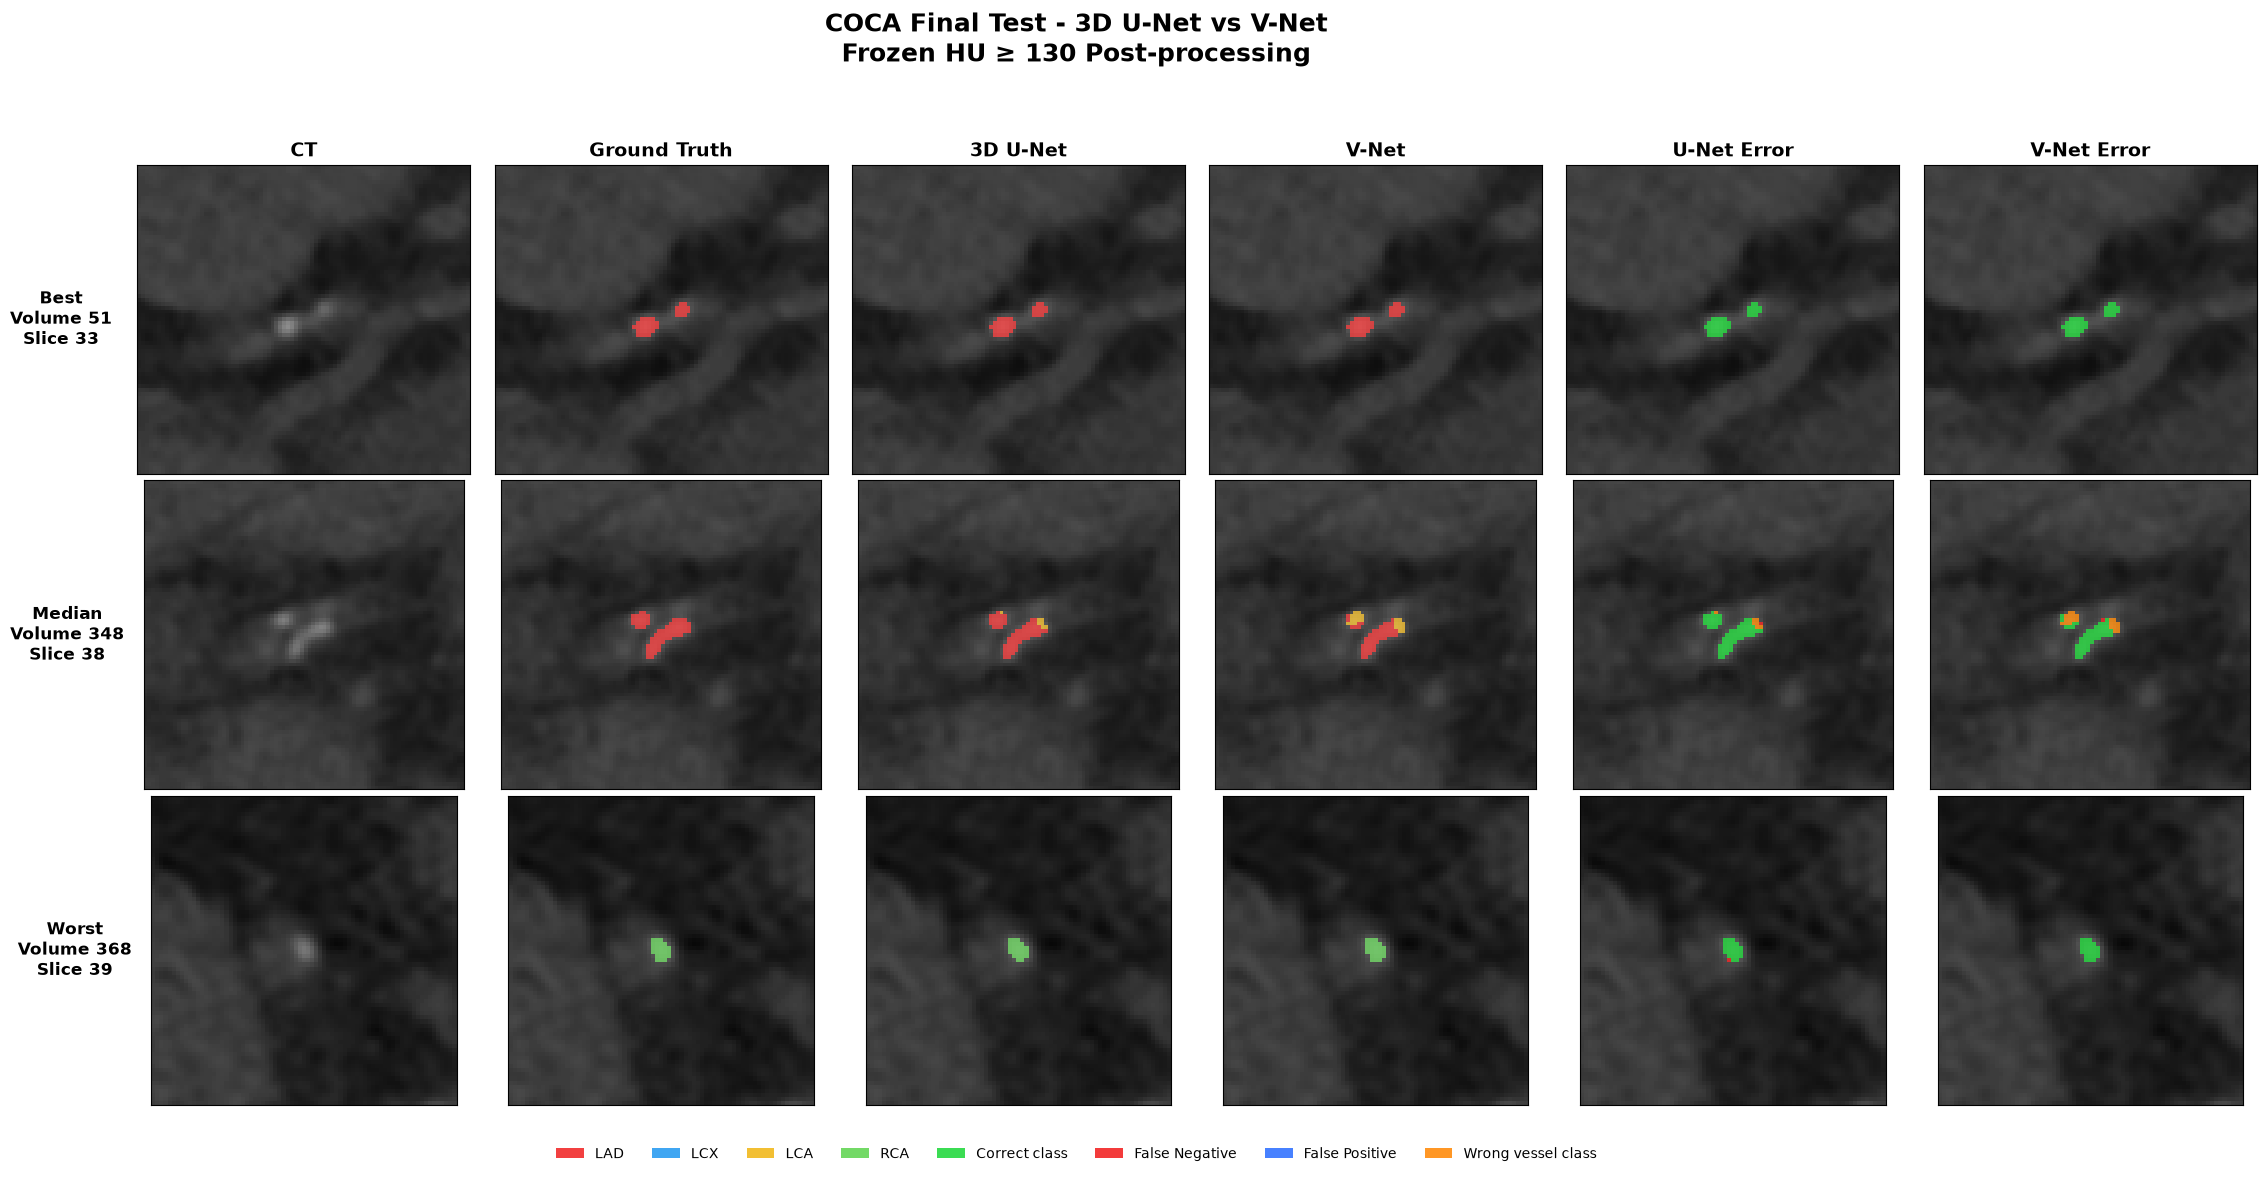


SELECTED COMPARISON SLICES
Best   | Volume  51 | Slice 33
       U-Net | TP   39 | FN    0 | FP    0 | Wrong    0
       V-Net | TP   39 | FN    0 | FP    0 | Wrong    0
Median | Volume 348 | Slice 38
       U-Net | TP   69 | FN    1 | FP    0 | Wrong    7
       V-Net | TP   53 | FN    1 | FP    0 | Wrong   23
Worst  | Volume 368 | Slice 39
       U-Net | TP   23 | FN    1 | FP    0 | Wrong    0
       V-Net | TP   24 | FN    0 | FP    0 | Wrong    0

STEP 86 QC
Figure Exists       : True
Cases Visualized    : 3
Test Inference Rerun: False
Test Tuning         : NOT ALLOWED
Selection Basis     : 3D U-Net Best / Median / Worst

Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/unet_vs_vnet/unet_vs_vnet_representative_cases.png

STEP 86 PASS : True


In [203]:
# ============================================================
# STEP 86. U-Net vs V-Net Representative Case Visualization
# - U-Net 기준 Best / Median / Worst 동일 환자 비교
#
# Cases
# - Best   : Volume 51
# - Median : Volume 348
# - Worst  : Volume 368
#
# Column
# 1. CT
# 2. Ground Truth
# 3. 3D U-Net Prediction
# 4. V-Net Prediction
# 5. U-Net Error Map
# 6. V-Net Error Map
#
# 중요
# - 저장된 Final HU130 prediction만 사용
# - Test inference 재실행 없음
# - Test tuning 없음
# ============================================================

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


# ============================================================
# 0. 필수 객체
# ============================================================

required_names = [
    "TEST_CACHE_ROOT",
    "UNET_PRED_ROOT",
    "VNET_PRED_ROOT",
    "REPRESENTATIVE_CASES",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print("=" * 80)
print("STEP 86 - U-Net vs V-Net Representative Visualization")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 1. 저장 경로
# ============================================================

FINAL_COMPARISON_VIS_ROOT = (
    Path(
        "/home/korea1/workspace/datasets/COCA"
    )
    / "final_visualizations"
    / "unet_vs_vnet"
)

FINAL_COMPARISON_VIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


COMPARISON_FIGURE_PATH = (
    FINAL_COMPARISON_VIS_ROOT
    / "unet_vs_vnet_representative_cases.png"
)


# ============================================================
# 2. Class 설정
# ============================================================

CLASS_NAMES_86 = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


# ============================================================
# 3. Segmentation Color
# ============================================================

SEG_COLORS = [
    (0.0, 0.0, 0.0, 0.0),
    (0.95, 0.25, 0.25, 1.0),
    (0.25, 0.65, 0.95, 1.0),
    (0.95, 0.75, 0.20, 1.0),
    (0.45, 0.85, 0.40, 1.0),
]


seg_cmap = ListedColormap(
    SEG_COLORS
)

seg_norm = BoundaryNorm(
    boundaries=[
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 4. Error Map
#
# 0 = Nothing
# 1 = Correct Class TP
# 2 = False Negative
# 3 = False Positive
# 4 = Wrong Vessel Class
# ============================================================

ERROR_COLORS = [
    (0.0, 0.0, 0.0, 0.0),
    (0.15, 0.85, 0.25, 0.90),  # Green
    (0.95, 0.15, 0.15, 0.90),  # Red
    (0.20, 0.45, 1.00, 0.90),  # Blue
    (1.00, 0.55, 0.05, 0.90),  # Orange
]


error_cmap = ListedColormap(
    ERROR_COLORS
)

error_norm = BoundaryNorm(
    boundaries=[
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 5. Error Map 생성
# ============================================================

def build_error_map_86(
    gt,
    prediction,
):

    error_map = np.zeros(
        gt.shape,
        dtype=np.uint8,
    )


    gt_fg = (
        gt > 0
    )

    pred_fg = (
        prediction > 0
    )


    # Correct vessel class
    correct_class = (
        gt_fg
        &
        pred_fg
        &
        (gt == prediction)
    )


    # False Negative
    false_negative = (
        gt_fg
        &
        (~pred_fg)
    )


    # False Positive
    false_positive = (
        (~gt_fg)
        &
        pred_fg
    )


    # Vessel class confusion
    wrong_class = (
        gt_fg
        &
        pred_fg
        &
        (gt != prediction)
    )


    error_map[
        correct_class
    ] = 1

    error_map[
        false_negative
    ] = 2

    error_map[
        false_positive
    ] = 3

    error_map[
        wrong_class
    ] = 4


    return error_map


# ============================================================
# 6. Slice Score
# - GT / U-Net / V-Net foreground + mismatch를 함께 고려
# - 비교 정보가 가장 많은 slice 선택
# ============================================================

def select_comparison_slice_86(
    gt,
    unet_pred,
    vnet_pred,
):

    depth = int(
        gt.shape[0]
    )


    best_index = 0
    best_score = -1


    for z_index in range(
        depth
    ):

        gt_slice = (
            gt[
                z_index
            ]
        )

        unet_slice = (
            unet_pred[
                z_index
            ]
        )

        vnet_slice = (
            vnet_pred[
                z_index
            ]
        )


        gt_fg = int(
            np.sum(
                gt_slice > 0
            )
        )

        unet_fg = int(
            np.sum(
                unet_slice > 0
            )
        )

        vnet_fg = int(
            np.sum(
                vnet_slice > 0
            )
        )


        unet_mismatch = int(
            np.sum(
                gt_slice
                != unet_slice
            )
        )

        vnet_mismatch = int(
            np.sum(
                gt_slice
                != vnet_slice
            )
        )


        # GT 존재를 가장 중요하게 두고
        # 두 모델의 오류가 보이는 slice를 우선 선택
        score = (
            gt_fg * 10
            + unet_mismatch * 3
            + vnet_mismatch * 3
            + unet_fg
            + vnet_fg
        )


        if score > best_score:

            best_score = score
            best_index = z_index


    return int(
        best_index
    )


# ============================================================
# 7. Visualization ROI 계산
# - GT + 두 Prediction foreground의 bounding box
# ============================================================

def get_roi_bounds_86(
    gt_slice,
    unet_slice,
    vnet_slice,
    margin=35,
):

    combined = (
        (gt_slice > 0)
        |
        (unet_slice > 0)
        |
        (vnet_slice > 0)
    )


    coords = np.argwhere(
        combined
    )


    if len(
        coords
    ) == 0:

        return (
            0,
            gt_slice.shape[0],
            0,
            gt_slice.shape[1],
        )


    y_min = max(
        int(
            coords[
                :,
                0
            ].min()
        )
        - margin,
        0,
    )

    y_max = min(
        int(
            coords[
                :,
                0
            ].max()
        )
        + margin
        + 1,
        gt_slice.shape[0],
    )

    x_min = max(
        int(
            coords[
                :,
                1
            ].min()
        )
        - margin,
        0,
    )

    x_max = min(
        int(
            coords[
                :,
                1
            ].max()
        )
        + margin
        + 1,
        gt_slice.shape[1],
    )


    return (
        y_min,
        y_max,
        x_min,
        x_max,
    )


# ============================================================
# 8. Figure 생성
# ============================================================

case_count = len(
    REPRESENTATIVE_CASES
)


fig, axes = plt.subplots(
    case_count,
    6,
    figsize=(
        24,
        12,
    ),
)


column_titles = [
    "CT",
    "Ground Truth",
    "3D U-Net",
    "V-Net",
    "U-Net Error",
    "V-Net Error",
]


for col_idx, title in enumerate(
    column_titles
):

    axes[
        0,
        col_idx
    ].set_title(
        title,
        fontsize=14,
        fontweight="bold",
    )


selected_slice_records = []


# ============================================================
# 9. Case별 시각화
# ============================================================

for row_idx, (
    case_name,
    volume_id,
) in enumerate(
    REPRESENTATIVE_CASES.items()
):

    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    ct = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    unet_pred = np.load(
        UNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )

    vnet_pred = np.load(
        VNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )


    assert (
        ct.shape
        == gt.shape
        == unet_pred.shape
        == vnet_pred.shape
    )


    # --------------------------------------------------------
    # Slice 선택
    # --------------------------------------------------------

    z_index = (
        select_comparison_slice_86(
            gt,
            unet_pred,
            vnet_pred,
        )
    )


    gt_slice = np.asarray(
        gt[
            z_index
        ]
    )

    unet_slice = np.asarray(
        unet_pred[
            z_index
        ]
    )

    vnet_slice = np.asarray(
        vnet_pred[
            z_index
        ]
    )

    ct_slice = np.asarray(
        ct[
            z_index
        ]
    )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    (
        y_min,
        y_max,
        x_min,
        x_max,
    ) = get_roi_bounds_86(
        gt_slice,
        unet_slice,
        vnet_slice,
        margin=35,
    )


    ct_roi = (
        ct_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    gt_roi = (
        gt_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    unet_roi = (
        unet_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    vnet_roi = (
        vnet_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )


    # --------------------------------------------------------
    # Error
    # --------------------------------------------------------

    unet_error = (
        build_error_map_86(
            gt_roi,
            unet_roi,
        )
    )

    vnet_error = (
        build_error_map_86(
            gt_roi,
            vnet_roi,
        )
    )


    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    axes[
        row_idx,
        1
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    gt_masked = np.ma.masked_where(
        gt_roi == 0,
        gt_roi,
    )

    axes[
        row_idx,
        1
    ].imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.80,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # U-Net
    # --------------------------------------------------------

    axes[
        row_idx,
        2
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    unet_masked = np.ma.masked_where(
        unet_roi == 0,
        unet_roi,
    )

    axes[
        row_idx,
        2
    ].imshow(
        unet_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.80,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # V-Net
    # --------------------------------------------------------

    axes[
        row_idx,
        3
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    vnet_masked = np.ma.masked_where(
        vnet_roi == 0,
        vnet_roi,
    )

    axes[
        row_idx,
        3
    ].imshow(
        vnet_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.80,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # U-Net Error
    # --------------------------------------------------------

    axes[
        row_idx,
        4
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    unet_error_masked = (
        np.ma.masked_where(
            unet_error == 0,
            unet_error,
        )
    )

    axes[
        row_idx,
        4
    ].imshow(
        unet_error_masked,
        cmap=error_cmap,
        norm=error_norm,
        alpha=0.90,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # V-Net Error
    # --------------------------------------------------------

    axes[
        row_idx,
        5
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    vnet_error_masked = (
        np.ma.masked_where(
            vnet_error == 0,
            vnet_error,
        )
    )

    axes[
        row_idx,
        5
    ].imshow(
        vnet_error_masked,
        cmap=error_cmap,
        norm=error_norm,
        alpha=0.90,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # Row Label
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"{case_name}\n"
            f"Volume {volume_id}\n"
            f"Slice {z_index}"
        ),
        fontsize=12,
        fontweight="bold",
        rotation=0,
        labelpad=55,
        va="center",
    )


    # --------------------------------------------------------
    # Error Count
    # --------------------------------------------------------

    unet_error_count = {
        code: int(
            np.sum(
                unet_error == code
            )
        )
        for code in range(
            1,
            5,
        )
    }

    vnet_error_count = {
        code: int(
            np.sum(
                vnet_error == code
            )
        )
        for code in range(
            1,
            5,
        )
    }


    selected_slice_records.append({
        "case":
            case_name,

        "volume_id":
            str(
                volume_id
            ),

        "z_index":
            z_index,

        "unet_tp":
            unet_error_count[1],

        "unet_fn":
            unet_error_count[2],

        "unet_fp":
            unet_error_count[3],

        "unet_wrong":
            unet_error_count[4],

        "vnet_tp":
            vnet_error_count[1],

        "vnet_fn":
            vnet_error_count[2],

        "vnet_fp":
            vnet_error_count[3],

        "vnet_wrong":
            vnet_error_count[4],
    })


    del ct
    del gt
    del unet_pred
    del vnet_pred


# ============================================================
# 10. Axis 정리
# ============================================================

for ax_row in axes:

    for ax in ax_row:

        ax.set_xticks([])
        ax.set_yticks([])


# ============================================================
# 11. Legend
# ============================================================

class_legend = [
    Patch(
        facecolor=SEG_COLORS[
            class_id
        ],
        label=CLASS_NAMES_86[
            class_id
        ],
    )
    for class_id in range(
        1,
        5,
    )
]


error_legend = [
    Patch(
        facecolor=ERROR_COLORS[1],
        label="Correct class",
    ),

    Patch(
        facecolor=ERROR_COLORS[2],
        label="False Negative",
    ),

    Patch(
        facecolor=ERROR_COLORS[3],
        label="False Positive",
    ),

    Patch(
        facecolor=ERROR_COLORS[4],
        label="Wrong vessel class",
    ),
]


fig.legend(
    handles=
        class_legend
        + error_legend,
    loc="lower center",
    ncol=8,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(
        0.5,
        0.015,
    ),
)


# ============================================================
# 12. Title
# ============================================================

fig.suptitle(
    (
        "COCA Final Test - 3D U-Net vs V-Net\n"
        "Frozen HU ≥ 130 Post-processing"
    ),
    fontsize=18,
    fontweight="bold",
    y=0.985,
)


plt.tight_layout(
    rect=[
        0.045,
        0.06,
        1.0,
        0.94,
    ]
)


# ============================================================
# 13. Save
# ============================================================

plt.savefig(
    COMPARISON_FIGURE_PATH,
    dpi=240,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 14. Selected Slice 출력
# ============================================================

print()
print("=" * 80)
print("SELECTED COMPARISON SLICES")
print("=" * 80)


for record in (
    selected_slice_records
):

    print(
        f"{record['case']:<6s} "
        f"| Volume {record['volume_id']:>3s} "
        f"| Slice {record['z_index']:>2d}"
    )

    print(
        "       U-Net "
        f"| TP {record['unet_tp']:>4d} "
        f"| FN {record['unet_fn']:>4d} "
        f"| FP {record['unet_fp']:>4d} "
        f"| Wrong {record['unet_wrong']:>4d}"
    )

    print(
        "       V-Net "
        f"| TP {record['vnet_tp']:>4d} "
        f"| FN {record['vnet_fn']:>4d} "
        f"| FP {record['vnet_fp']:>4d} "
        f"| Wrong {record['vnet_wrong']:>4d}"
    )


# ============================================================
# 15. Final QC
# ============================================================

figure_exists = (
    COMPARISON_FIGURE_PATH.exists()
)

records_ok = (
    len(
        selected_slice_records
    )
    == 3
)


step_86_pass = (
    figure_exists
    and
    records_ok
)


print()
print("=" * 80)
print("STEP 86 QC")
print("=" * 80)

print(
    "Figure Exists       :",
    figure_exists
)

print(
    "Cases Visualized    :",
    len(
        selected_slice_records
    )
)

print(
    "Test Inference Rerun:",
    False
)

print(
    "Test Tuning         :",
    "NOT ALLOWED"
)

print(
    "Selection Basis     :",
    "3D U-Net Best / Median / Worst"
)

print()

print(
    "Saved :",
    COMPARISON_FIGURE_PATH
)

print()

print(
    "STEP 86 PASS :",
    step_86_pass
)

print("=" * 80)

In [204]:
# ============================================================
# STEP 87. Final 3D U-Net vs V-Net Result Table
# - 최종 Test45 결과를 발표/보고서용 표로 정리
#
# 포함
# - Parameters
# - Raw Macro Dice
# - HU130 Final Macro Dice
# - LAD / LCX / LCA / RCA Final Dice
# - HU130 Gain
# - Final Selection
#
# 중요
# - Test inference 없음
# - Test prediction 재계산 없음
# - Test tuning 없음
# ============================================================

import json

from pathlib import Path

import pandas as pd


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

COMPARISON_CSV = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
    / "3d_unet_vs_vnet_final_test_comparison.csv"
)

FINAL_SELECTION_JSON = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
    / "coca_final_model_selection.json"
)

FINAL_TABLE_ROOT = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
)

FINAL_TABLE_CSV = (
    FINAL_TABLE_ROOT
    / "coca_final_model_result_table.csv"
)


print("=" * 80)
print("STEP 87 - Final 3D U-Net vs V-Net Result Table")
print("=" * 80)


# ============================================================
# 1. Source 확인
# ============================================================

source_exists = all([
    COMPARISON_CSV.exists(),
    FINAL_SELECTION_JSON.exists(),
])


print(
    "Comparison CSV Exists :",
    COMPARISON_CSV.exists()
)

print(
    "Selection JSON Exists :",
    FINAL_SELECTION_JSON.exists()
)


if not source_exists:
    raise FileNotFoundError(
        "STEP 83 / STEP 84 결과 파일이 없습니다."
    )


# ============================================================
# 2. Load
# ============================================================

comparison_df = pd.read_csv(
    COMPARISON_CSV
)


with open(
    FINAL_SELECTION_JSON,
    "r",
    encoding="utf-8",
) as f:

    selection = json.load(
        f
    )


# ============================================================
# 3. Metric Helper
# ============================================================

def get_dice(
    method,
    class_name,
    model_column,
):

    row = comparison_df[
        (
            comparison_df[
                "Method"
            ] == method
        )
        &
        (
            comparison_df[
                "Class"
            ] == class_name
        )
    ]


    if len(row) != 1:

        raise RuntimeError(
            f"Metric row 오류 "
            f"| {method} / {class_name}"
        )


    return float(
        row.iloc[0][
            model_column
        ]
    )


# ============================================================
# 4. 최종 값
# ============================================================

unet_params = int(
    selection[
        "primary_model"
    ][
        "parameters"
    ]
)

vnet_params = int(
    selection[
        "comparison_model"
    ][
        "parameters"
    ]
)


unet_raw_macro = get_dice(
    "Raw",
    "Macro",
    "UNet_Dice",
)

vnet_raw_macro = get_dice(
    "Raw",
    "Macro",
    "VNet_Dice",
)


unet_final_macro = get_dice(
    "HU130",
    "Macro",
    "UNet_Dice",
)

vnet_final_macro = get_dice(
    "HU130",
    "Macro",
    "VNet_Dice",
)


unet_hu_gain = (
    unet_final_macro
    - unet_raw_macro
)

vnet_hu_gain = (
    vnet_final_macro
    - vnet_raw_macro
)


# ============================================================
# 5. 발표용 최종 표
# ============================================================

final_result_table = pd.DataFrame([
    {
        "Model":
            "3D U-Net",

        "Parameters":
            unet_params,

        "Raw Macro Dice":
            unet_raw_macro,

        "HU130 Macro Dice":
            unet_final_macro,

        "HU130 Gain":
            unet_hu_gain,

        "LAD Dice":
            get_dice(
                "HU130",
                "LAD",
                "UNet_Dice",
            ),

        "LCX Dice":
            get_dice(
                "HU130",
                "LCX",
                "UNet_Dice",
            ),

        "LCA Dice":
            get_dice(
                "HU130",
                "LCA",
                "UNet_Dice",
            ),

        "RCA Dice":
            get_dice(
                "HU130",
                "RCA",
                "UNet_Dice",
            ),

        "Final Selection":
            "PRIMARY",
    },

    {
        "Model":
            "V-Net",

        "Parameters":
            vnet_params,

        "Raw Macro Dice":
            vnet_raw_macro,

        "HU130 Macro Dice":
            vnet_final_macro,

        "HU130 Gain":
            vnet_hu_gain,

        "LAD Dice":
            get_dice(
                "HU130",
                "LAD",
                "VNet_Dice",
            ),

        "LCX Dice":
            get_dice(
                "HU130",
                "LCX",
                "VNet_Dice",
            ),

        "LCA Dice":
            get_dice(
                "HU130",
                "LCA",
                "VNet_Dice",
            ),

        "RCA Dice":
            get_dice(
                "HU130",
                "RCA",
                "VNet_Dice",
            ),

        "Final Selection":
            "COMPARISON",
    },
])


# ============================================================
# 6. Save
# ============================================================

FINAL_TABLE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


final_result_table.to_csv(
    FINAL_TABLE_CSV,
    index=False,
)


# ============================================================
# 7. 출력용 Format
# ============================================================

display_table = (
    final_result_table.copy()
)


display_table[
    "Parameters"
] = display_table[
    "Parameters"
].map(
    lambda value:
        f"{value:,}"
)


metric_columns = [
    "Raw Macro Dice",
    "HU130 Macro Dice",
    "HU130 Gain",
    "LAD Dice",
    "LCX Dice",
    "LCA Dice",
    "RCA Dice",
]


for column in metric_columns:

    display_table[
        column
    ] = display_table[
        column
    ].map(
        lambda value:
            f"{value:.6f}"
    )


print()
print("=" * 80)
print("FINAL COCA TEST45 RESULT TABLE")
print("=" * 80)

print(
    display_table.to_string(
        index=False
    )
)


# ============================================================
# 8. 핵심 차이
# ============================================================

macro_advantage = (
    unet_final_macro
    - vnet_final_macro
)

parameter_ratio = (
    vnet_params
    / unet_params
)


print()
print("=" * 80)
print("FINAL INTERPRETATION")
print("=" * 80)

print(
    "3D U-Net Final Macro :",
    f"{unet_final_macro:.6f}"
)

print(
    "V-Net Final Macro    :",
    f"{vnet_final_macro:.6f}"
)

print(
    "U-Net Advantage      :",
    f"+{macro_advantage:.6f}"
)

print()

print(
    "V-Net / U-Net Params :",
    f"{parameter_ratio:.3f}x"
)

print()

print(
    "Higher LAD           :",
    "3D U-Net"
)

print(
    "Higher LCX           :",
    "3D U-Net"
)

print(
    "Higher LCA           :",
    "V-Net"
)

print(
    "Higher RCA           :",
    "3D U-Net"
)

print(
    "Overall Selection    :",
    "3D U-Net"
)


# ============================================================
# 9. Final QC
# ============================================================

save_ok = (
    FINAL_TABLE_CSV.exists()
)

table_ok = (
    len(
        final_result_table
    )
    == 2
)

selection_ok = (
    unet_final_macro
    > vnet_final_macro
)


step_87_pass = all([
    save_ok,
    table_ok,
    selection_ok,
])


print()
print("=" * 80)
print("STEP 87 QC")
print("=" * 80)

print(
    "Models              :",
    len(
        final_result_table
    )
)

print(
    "Table Saved         :",
    save_ok
)

print(
    "Primary Model       :",
    "3D U-Net"
)

print(
    "Test Inference Rerun:",
    False
)

print(
    "Test Tuning         :",
    "NOT ALLOWED"
)

print()

print(
    "Saved :",
    FINAL_TABLE_CSV
)

print()

print(
    "STEP 87 PASS :",
    step_87_pass
)

print("=" * 80)

STEP 87 - Final 3D U-Net vs V-Net Result Table
Comparison CSV Exists : True
Selection JSON Exists : True

FINAL COCA TEST45 RESULT TABLE
   Model Parameters Raw Macro Dice HU130 Macro Dice HU130 Gain LAD Dice LCX Dice LCA Dice RCA Dice Final Selection
3D U-Net  5,472,373       0.808170         0.821838   0.013668 0.933294 0.867304 0.584986 0.901767         PRIMARY
   V-Net  9,732,549       0.775015         0.811955   0.036940 0.911799 0.817028 0.619511 0.899484      COMPARISON

FINAL INTERPRETATION
3D U-Net Final Macro : 0.821838
V-Net Final Macro    : 0.811955
U-Net Advantage      : +0.009883

V-Net / U-Net Params : 1.778x

Higher LAD           : 3D U-Net
Higher LCX           : 3D U-Net
Higher LCA           : V-Net
Higher RCA           : 3D U-Net
Overall Selection    : 3D U-Net

STEP 87 QC
Models              : 2
Table Saved         : True
Primary Model       : 3D U-Net
Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

Saved : /home/korea1/workspace/datasets/COCA/logs/mod

STEP 88 - Final Model Performance Visualization
Source : /home/korea1/workspace/datasets/COCA/logs/model_comparison/coca_final_model_result_table.csv
Rows   : 2


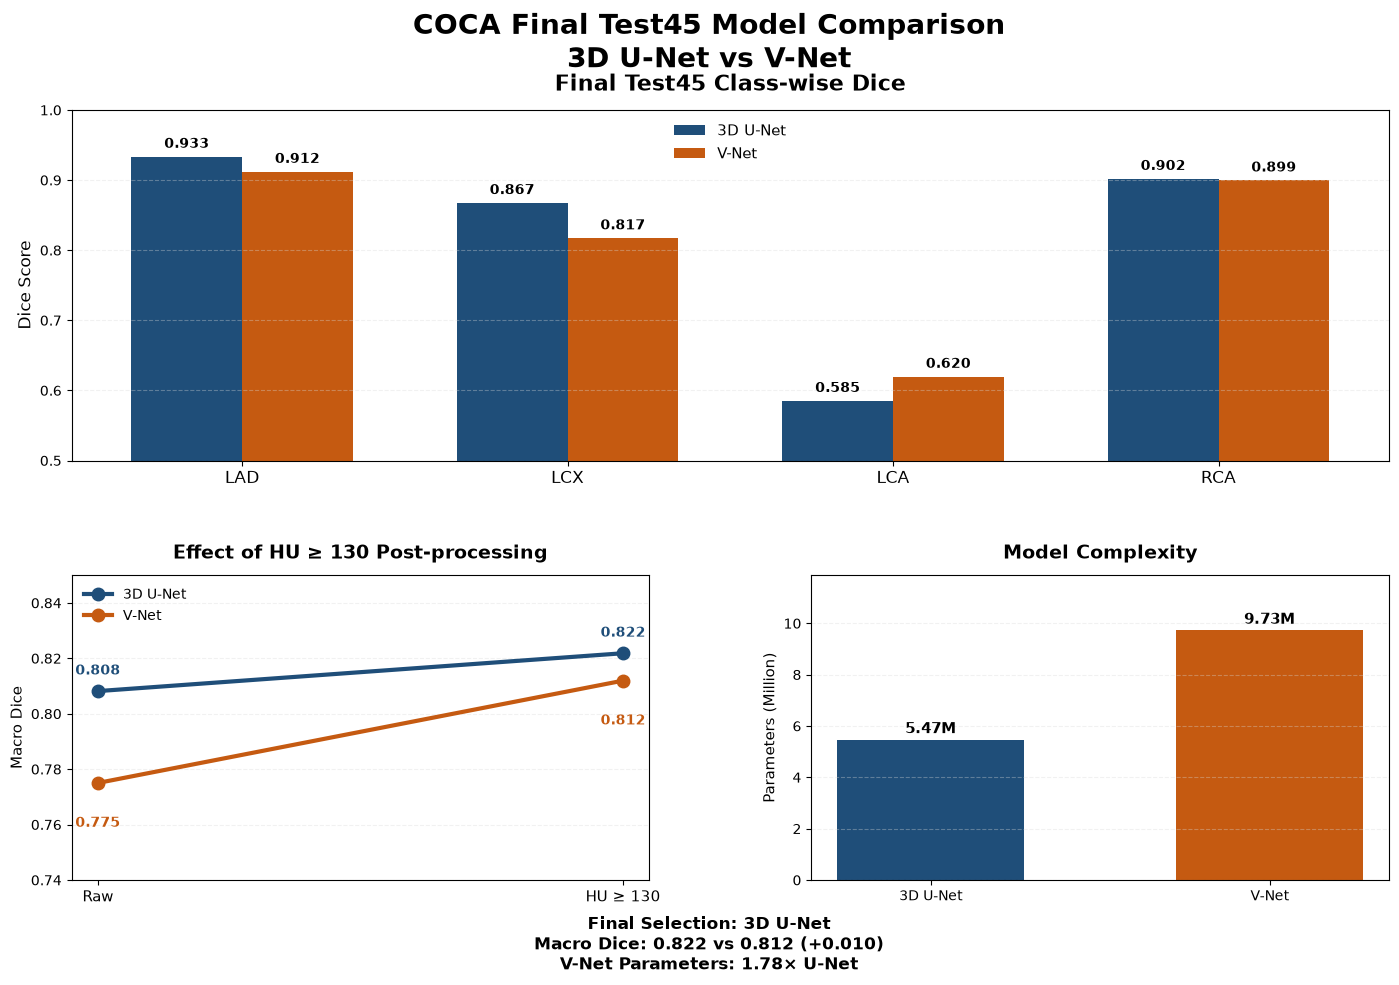


STEP 88 QC
Class Dice Plot      : True
HU130 Effect Plot    : True
Parameter Plot       : True
Primary Model        : 3D U-Net
Test Inference Rerun : False
Test Tuning          : NOT ALLOWED

Saved : /home/korea1/workspace/datasets/COCA/final_visualizations/model_comparison/coca_3d_unet_vs_vnet_final_summary.png

STEP 88 PASS : True


In [205]:
# ============================================================
# STEP 88. Final 3D U-Net vs V-Net Performance Visualization
# - 최종 Test45 성능 비교 시각화
#
# 포함
# 1. Class-wise Final Dice
# 2. Raw vs HU130 Macro Dice
# 3. Parameter Count
#
# 중요
# - 저장된 STEP 87 결과만 사용
# - Test inference 없음
# - Metric 재계산 없음
# - Test tuning 없음
# ============================================================

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

FINAL_TABLE_CSV = (
    COCA_ROOT
    / "logs"
    / "model_comparison"
    / "coca_final_model_result_table.csv"
)

FINAL_VIS_ROOT = (
    COCA_ROOT
    / "final_visualizations"
    / "model_comparison"
)

FINAL_FIGURE_PATH = (
    FINAL_VIS_ROOT
    / "coca_3d_unet_vs_vnet_final_summary.png"
)


print("=" * 80)
print("STEP 88 - Final Model Performance Visualization")
print("=" * 80)


# ============================================================
# 1. Source 확인
# ============================================================

if not FINAL_TABLE_CSV.exists():

    raise FileNotFoundError(
        FINAL_TABLE_CSV
    )


FINAL_VIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


result_df = pd.read_csv(
    FINAL_TABLE_CSV
)


print(
    "Source :",
    FINAL_TABLE_CSV
)

print(
    "Rows   :",
    len(result_df)
)


# ============================================================
# 2. 모델별 데이터
# ============================================================

unet_row = result_df[
    result_df["Model"]
    == "3D U-Net"
].iloc[0]

vnet_row = result_df[
    result_df["Model"]
    == "V-Net"
].iloc[0]


class_names = [
    "LAD",
    "LCX",
    "LCA",
    "RCA",
]


unet_class_dice = np.array([
    float(unet_row["LAD Dice"]),
    float(unet_row["LCX Dice"]),
    float(unet_row["LCA Dice"]),
    float(unet_row["RCA Dice"]),
])


vnet_class_dice = np.array([
    float(vnet_row["LAD Dice"]),
    float(vnet_row["LCX Dice"]),
    float(vnet_row["LCA Dice"]),
    float(vnet_row["RCA Dice"]),
])


unet_macro = [
    float(
        unet_row[
            "Raw Macro Dice"
        ]
    ),
    float(
        unet_row[
            "HU130 Macro Dice"
        ]
    ),
]


vnet_macro = [
    float(
        vnet_row[
            "Raw Macro Dice"
        ]
    ),
    float(
        vnet_row[
            "HU130 Macro Dice"
        ]
    ),
]


unet_params = int(
    unet_row[
        "Parameters"
    ]
)

vnet_params = int(
    vnet_row[
        "Parameters"
    ]
)


# ============================================================
# 3. Professional Color
# ============================================================

UNET_COLOR = "#1F4E79"
VNET_COLOR = "#C55A11"

GRID_COLOR = "#D9D9D9"


# ============================================================
# 4. Figure
# ============================================================

fig = plt.figure(
    figsize=(17, 10)
)


grid = fig.add_gridspec(
    2,
    2,
    height_ratios=[
        1.15,
        1.0,
    ],
    hspace=0.35,
    wspace=0.28,
)


# ============================================================
# 5. Class-wise Dice
# ============================================================

ax1 = fig.add_subplot(
    grid[
        0,
        :
    ]
)


x = np.arange(
    len(
        class_names
    )
)

bar_width = 0.34


bars_unet = ax1.bar(
    x - bar_width / 2,
    unet_class_dice,
    bar_width,
    label="3D U-Net",
    color=UNET_COLOR,
)


bars_vnet = ax1.bar(
    x + bar_width / 2,
    vnet_class_dice,
    bar_width,
    label="V-Net",
    color=VNET_COLOR,
)


ax1.set_title(
    "Final Test45 Class-wise Dice",
    fontsize=16,
    fontweight="bold",
    pad=14,
)

ax1.set_ylabel(
    "Dice Score",
    fontsize=12,
)

ax1.set_xticks(
    x
)

ax1.set_xticklabels(
    class_names,
    fontsize=12,
)

ax1.set_ylim(
    0.50,
    1.00,
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
    color=GRID_COLOR,
)

ax1.legend(
    frameon=False,
    fontsize=11,
)


# ------------------------------------------------------------
# Bar 값 표시
# ------------------------------------------------------------

for bar in bars_unet:

    height = bar.get_height()

    ax1.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.008,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )


for bar in bars_vnet:

    height = bar.get_height()

    ax1.text(
        bar.get_x()
        + bar.get_width() / 2,
        height + 0.008,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )


# ============================================================
# 6. Raw vs HU130 Macro Dice
# ============================================================

ax2 = fig.add_subplot(
    grid[
        1,
        0
    ]
)


macro_labels = [
    "Raw",
    "HU ≥ 130",
]


macro_x = np.arange(
    2
)


ax2.plot(
    macro_x,
    unet_macro,
    marker="o",
    linewidth=3,
    markersize=9,
    label="3D U-Net",
    color=UNET_COLOR,
)


ax2.plot(
    macro_x,
    vnet_macro,
    marker="o",
    linewidth=3,
    markersize=9,
    label="V-Net",
    color=VNET_COLOR,
)


for index, value in enumerate(
    unet_macro
):

    ax2.text(
        index,
        value + 0.006,
        f"{value:.3f}",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=UNET_COLOR,
    )


for index, value in enumerate(
    vnet_macro
):

    ax2.text(
        index,
        value - 0.012,
        f"{value:.3f}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
        color=VNET_COLOR,
    )


ax2.set_title(
    "Effect of HU ≥ 130 Post-processing",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

ax2.set_ylabel(
    "Macro Dice",
    fontsize=11,
)

ax2.set_xticks(
    macro_x
)

ax2.set_xticklabels(
    macro_labels,
    fontsize=11,
)

ax2.set_ylim(
    0.74,
    0.85,
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
    color=GRID_COLOR,
)

ax2.legend(
    frameon=False,
    fontsize=10,
)


# ============================================================
# 7. Parameter Count
# ============================================================

ax3 = fig.add_subplot(
    grid[
        1,
        1
    ]
)


parameter_names = [
    "3D U-Net",
    "V-Net",
]

parameter_values = [
    unet_params / 1_000_000,
    vnet_params / 1_000_000,
]


parameter_bars = ax3.bar(
    parameter_names,
    parameter_values,
    color=[
        UNET_COLOR,
        VNET_COLOR,
    ],
    width=0.55,
)


ax3.set_title(
    "Model Complexity",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

ax3.set_ylabel(
    "Parameters (Million)",
    fontsize=11,
)

ax3.set_ylim(
    0,
    max(
        parameter_values
    ) * 1.22,
)

ax3.grid(
    axis="y",
    linestyle="--",
    alpha=0.35,
    color=GRID_COLOR,
)


for bar, value in zip(
    parameter_bars,
    parameter_values,
):

    ax3.text(
        bar.get_x()
        + bar.get_width() / 2,
        bar.get_height() + 0.25,
        f"{value:.2f}M",
        ha="center",
        fontsize=11,
        fontweight="bold",
    )


# ============================================================
# 8. Final Selection Annotation
# ============================================================

unet_final_macro = float(
    unet_row[
        "HU130 Macro Dice"
    ]
)

vnet_final_macro = float(
    vnet_row[
        "HU130 Macro Dice"
    ]
)


macro_difference = (
    unet_final_macro
    - vnet_final_macro
)


parameter_ratio = (
    vnet_params
    / unet_params
)


summary_text = (
    "Final Selection: 3D U-Net\n"
    f"Macro Dice: "
    f"{unet_final_macro:.3f} vs "
    f"{vnet_final_macro:.3f} "
    f"(+{macro_difference:.3f})\n"
    f"V-Net Parameters: "
    f"{parameter_ratio:.2f}× U-Net"
)


fig.text(
    0.5,
    0.015,
    summary_text,
    ha="center",
    va="bottom",
    fontsize=12,
    fontweight="bold",
)


# ============================================================
# 9. Figure Title
# ============================================================

fig.suptitle(
    (
        "COCA Final Test45 Model Comparison\n"
        "3D U-Net vs V-Net"
    ),
    fontsize=20,
    fontweight="bold",
    y=0.98,
)


# ============================================================
# 10. Save
# ============================================================

plt.savefig(
    FINAL_FIGURE_PATH,
    dpi=240,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 11. Final QC
# ============================================================

figure_exists = (
    FINAL_FIGURE_PATH.exists()
)


print()
print("=" * 80)
print("STEP 88 QC")
print("=" * 80)

print(
    "Class Dice Plot      :",
    True
)

print(
    "HU130 Effect Plot    :",
    True
)

print(
    "Parameter Plot       :",
    True
)

print(
    "Primary Model        :",
    "3D U-Net"
)

print(
    "Test Inference Rerun :",
    False
)

print(
    "Test Tuning          :",
    "NOT ALLOWED"
)

print()

print(
    "Saved :",
    FINAL_FIGURE_PATH
)

print()

print(
    "STEP 88 PASS :",
    figure_exists
)

print("=" * 80)

In [206]:
# ============================================================
# STEP 88A. V-Net Representative Patient Visualization
# - 최종 Test45 V-Net HU130 prediction만 사용
# - 환자별 foreground Dice 기준 Best / Median / Worst 선정
# - 각 환자에 대해 대표 slice 1장 선택 후 시각화
#
# 출력
# 1) V-Net 대표 환자 시각화 PNG
# 2) 대표 환자 metric summary CSV
#
# 중요
# - Test inference 재실행 없음
# - Test tuning 없음
# - 저장된 cache / prediction만 사용
# ============================================================

import os
import re
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 0. 기본 설정
# ============================================================

COCA_ROOT = Path("/home/korea1/workspace/datasets/COCA")

TEST_CACHE_DIR = COCA_ROOT / "coca_test_volume_cache_npy"

FINAL_VIS_DIR = (
    COCA_ROOT
    / "final_visualizations"
    / "vnet_representative_cases"
)

FINAL_VIS_PATH = (
    FINAL_VIS_DIR
    / "vnet_hu130_representative_cases.png"
)

FINAL_SUMMARY_CSV = (
    FINAL_VIS_DIR
    / "vnet_hu130_representative_cases_summary.csv"
)

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}

# ------------------------------------------------------------
# case selection mode
# - "vnet_best_median_worst" : V-Net 성능 기준으로 3개 선정
# - "same_as_unet"           : U-Net에서 썼던 51 / 348 / 368 사용
# ------------------------------------------------------------
CASE_SELECTION_MODE = "vnet_best_median_worst"
UNET_REFERENCE_VOLUMES = [51, 348, 368]


print("=" * 80)
print("STEP 88A - V-Net Representative Patient Visualization")
print("=" * 80)


# ============================================================
# 1. 공통 유틸
# ============================================================

def normalize_ct_for_display(ct_slice):
    ct_slice = ct_slice.astype(np.float32)
    vmin = -300.0
    vmax = 800.0
    ct_slice = np.clip(ct_slice, vmin, vmax)
    ct_slice = (ct_slice - vmin) / (vmax - vmin + 1e-8)
    return ct_slice


def dice_from_masks(pred_mask, gt_mask, eps=1e-8):
    pred_sum = int(pred_mask.sum())
    gt_sum = int(gt_mask.sum())

    if pred_sum == 0 and gt_sum == 0:
        return np.nan

    tp = int(np.logical_and(pred_mask, gt_mask).sum())
    fp = int(np.logical_and(pred_mask, ~gt_mask).sum())
    fn = int(np.logical_and(~pred_mask, gt_mask).sum())

    return (2.0 * tp) / (2.0 * tp + fp + fn + eps)


def extract_candidate_volume_ids_from_name(path_obj):
    stem = path_obj.stem
    numbers = re.findall(r"\d+", stem)
    return [int(x) for x in numbers]


def map_files_by_volume(file_list, valid_volume_ids):
    mapping = {}

    for file_path in file_list:
        candidates = extract_candidate_volume_ids_from_name(file_path)

        matched = [
            x for x in candidates
            if x in valid_volume_ids
        ]

        if len(matched) == 1:
            mapping[matched[0]] = file_path
        elif len(matched) > 1:
            mapping[matched[0]] = file_path

    return mapping


def find_ct_gt_files(test_cache_dir):
    ct_candidates = sorted(test_cache_dir.rglob("*.npy"))
    gt_candidates = sorted(test_cache_dir.rglob("*.npy"))

    ct_files = []
    gt_files = []

    for p in ct_candidates:
        name = p.name.lower()
        if "ct" in name:
            ct_files.append(p)

    for p in gt_candidates:
        name = p.name.lower()
        if "gt" in name or "mask" in name:
            gt_files.append(p)

    ct_volume_ids = set()
    for p in ct_files:
        for x in extract_candidate_volume_ids_from_name(p):
            ct_volume_ids.add(x)

    gt_volume_ids = set()
    for p in gt_files:
        for x in extract_candidate_volume_ids_from_name(p):
            gt_volume_ids.add(x)

    valid_ids = sorted(ct_volume_ids & gt_volume_ids)

    ct_map = map_files_by_volume(ct_files, valid_ids)
    gt_map = map_files_by_volume(gt_files, valid_ids)

    common_ids = sorted(set(ct_map.keys()) & set(gt_map.keys()))

    return common_ids, ct_map, gt_map


def auto_find_vnet_prediction_dir(coca_root):
    preferred_dirs = [
        coca_root / "predictions",
        coca_root / "test_predictions",
        coca_root / "final_predictions",
        coca_root / "outputs",
        coca_root / "logs",
    ]

    candidate_dirs = []

    for base_dir in preferred_dirs:
        if not base_dir.exists():
            continue

        for sub_dir in base_dir.rglob("*"):
            if not sub_dir.is_dir():
                continue

            sub_str = str(sub_dir).lower()
            if "vnet" not in sub_str:
                continue
            if "hu130" not in sub_str:
                continue

            npy_count = len(list(sub_dir.rglob("*.npy")))
            if npy_count >= 45:
                candidate_dirs.append((npy_count, sub_dir))

    if len(candidate_dirs) == 0:
        return None

    candidate_dirs = sorted(
        candidate_dirs,
        key=lambda x: (-x[0], str(x[1]))
    )

    return candidate_dirs[0][1]


def find_prediction_files(pred_root, valid_volume_ids):
    pred_files = sorted(pred_root.rglob("*.npy"))
    pred_map = map_files_by_volume(pred_files, valid_volume_ids)
    common_ids = sorted(set(pred_map.keys()) & set(valid_volume_ids))
    return common_ids, pred_map


def build_label_overlay(label_slice):
    h, w = label_slice.shape
    overlay = np.zeros((h, w, 4), dtype=np.float32)

    color_map = {
        1: (1.00, 0.20, 0.20, 0.55),  # LAD
        2: (0.20, 0.90, 0.20, 0.55),  # LCX
        3: (0.20, 0.55, 1.00, 0.55),  # LCA
        4: (1.00, 0.85, 0.20, 0.55),  # RCA
    }

    for class_id, rgba in color_map.items():
        mask = (label_slice == class_id)
        overlay[mask] = rgba

    return overlay


def build_error_map(pred_fg_slice, gt_fg_slice):
    h, w = pred_fg_slice.shape
    error_rgba = np.zeros((h, w, 4), dtype=np.float32)

    tp = np.logical_and(pred_fg_slice, gt_fg_slice)
    fn = np.logical_and(~pred_fg_slice, gt_fg_slice)
    fp = np.logical_and(pred_fg_slice, ~gt_fg_slice)

    error_rgba[tp] = (0.10, 0.90, 0.10, 0.80)   # TP = green
    error_rgba[fn] = (1.00, 0.15, 0.15, 0.85)   # FN = red
    error_rgba[fp] = (1.00, 0.85, 0.10, 0.85)   # FP = yellow

    return error_rgba


def choose_representative_slice(ct_vol, gt_vol, pred_vol):
    best_slice = 0
    best_score = -1

    for z in range(ct_vol.shape[0]):
        gt_fg = gt_vol[z] > 0
        pred_fg = pred_vol[z] > 0

        union_count = int(np.logical_or(gt_fg, pred_fg).sum())
        gt_count = int(gt_fg.sum())
        pred_count = int(pred_fg.sum())

        score = union_count * 1000000 + gt_count * 1000 + pred_count

        if score > best_score:
            best_score = score
            best_slice = z

    return best_slice


def compute_case_metrics(volume_id, ct_vol, gt_vol, pred_vol):
    gt_fg = gt_vol > 0
    pred_fg = pred_vol > 0

    fg_dice = dice_from_masks(pred_fg, gt_fg)
    gt_fg_count = int(gt_fg.sum())
    pred_fg_count = int(pred_fg.sum())

    class_dice = {}
    for class_id, class_name in CLASS_NAMES.items():
        class_dice[class_name] = dice_from_masks(
            pred_vol == class_id,
            gt_vol == class_id,
        )

    return {
        "volume_id": int(volume_id),
        "depth": int(ct_vol.shape[0]),
        "gt_foreground": gt_fg_count,
        "pred_foreground": pred_fg_count,
        "fg_dice": fg_dice,
        "LAD": class_dice["LAD"],
        "LCX": class_dice["LCX"],
        "LCA": class_dice["LCA"],
        "RCA": class_dice["RCA"],
    }


def safe_metric_text(value):
    if isinstance(value, float) and np.isnan(value):
        return "N/A"
    return f"{value:.6f}"


# ============================================================
# 2. 캐시 / 예측 경로 찾기
# ============================================================

if not TEST_CACHE_DIR.exists():
    raise FileNotFoundError(TEST_CACHE_DIR)

FINAL_VIS_DIR.mkdir(parents=True, exist_ok=True)

volume_ids, ct_map, gt_map = find_ct_gt_files(TEST_CACHE_DIR)

if len(volume_ids) == 0:
    raise RuntimeError("Test cache에서 CT / GT 파일을 찾지 못했습니다.")

print()
print("=" * 80)
print("Test Cache Discovery")
print("=" * 80)
print("Test Cache Dir :", TEST_CACHE_DIR)
print("Volume Count   :", len(volume_ids))

vnet_pred_root = auto_find_vnet_prediction_dir(COCA_ROOT)

if vnet_pred_root is None:
    raise RuntimeError(
        "V-Net HU130 prediction directory를 자동 탐색하지 못했습니다. "
        "경로를 수동 지정해주세요."
    )

pred_volume_ids, pred_map = find_prediction_files(vnet_pred_root, volume_ids)

common_volume_ids = sorted(
    set(volume_ids)
    & set(pred_volume_ids)
)

if len(common_volume_ids) == 0:
    raise RuntimeError("V-Net prediction 파일과 test cache의 volume 매칭에 실패했습니다.")

print()
print("=" * 80)
print("V-Net Prediction Discovery")
print("=" * 80)
print("Prediction Root :", vnet_pred_root)
print("Prediction Count:", len(pred_map))
print("Common Volumes  :", len(common_volume_ids))


# ============================================================
# 3. 전체 환자 metric 계산
# ============================================================

all_case_records = []

for volume_id in common_volume_ids:
    ct_vol = np.load(ct_map[volume_id])
    gt_vol = np.load(gt_map[volume_id])
    pred_vol = np.load(pred_map[volume_id])

    if ct_vol.shape != gt_vol.shape or gt_vol.shape != pred_vol.shape:
        raise RuntimeError(
            f"Volume {volume_id}: shape mismatch "
            f"CT={ct_vol.shape}, GT={gt_vol.shape}, Pred={pred_vol.shape}"
        )

    record = compute_case_metrics(
        volume_id=volume_id,
        ct_vol=ct_vol,
        gt_vol=gt_vol,
        pred_vol=pred_vol,
    )
    all_case_records.append(record)

case_df = pd.DataFrame(all_case_records)
case_df = case_df.sort_values(
    by=["fg_dice", "volume_id"],
    ascending=[True, True]
).reset_index(drop=True)

positive_case_df = case_df[
    case_df["gt_foreground"] > 0
].copy()

if len(positive_case_df) == 0:
    raise RuntimeError("GT foreground가 있는 test volume을 찾지 못했습니다.")

print()
print("=" * 80)
print("Case Metric Summary")
print("=" * 80)
print("All Cases      :", len(case_df))
print("Positive Cases :", len(positive_case_df))


# ============================================================
# 4. 대표 환자 선정
# ============================================================

selected_cases = []

if CASE_SELECTION_MODE == "same_as_unet":
    for label, volume_id in zip(
        ["Best", "Median", "Worst"],
        UNET_REFERENCE_VOLUMES
    ):
        matched = positive_case_df[
            positive_case_df["volume_id"] == volume_id
        ]
        if len(matched) == 0:
            raise RuntimeError(
                f"U-Net reference volume {volume_id} 를 찾지 못했습니다."
            )

        row = matched.iloc[0].to_dict()
        row["case_label"] = label
        selected_cases.append(row)

else:
    sorted_df = positive_case_df.sort_values(
        by=["fg_dice", "volume_id"],
        ascending=[False, True]
    ).reset_index(drop=True)

    best_row = sorted_df.iloc[0].to_dict()
    median_row = sorted_df.iloc[len(sorted_df) // 2].to_dict()
    worst_row = sorted_df.iloc[-1].to_dict()

    best_row["case_label"] = "Best"
    median_row["case_label"] = "Median"
    worst_row["case_label"] = "Worst"

    selected_cases = [best_row, median_row, worst_row]

selected_df = pd.DataFrame(selected_cases)

print()
print("=" * 80)
print("Selected Representative Cases")
print("=" * 80)
print(
    selected_df[
        [
            "case_label",
            "volume_id",
            "depth",
            "gt_foreground",
            "pred_foreground",
            "fg_dice",
            "LAD",
            "LCX",
            "LCA",
            "RCA",
        ]
    ].to_string(index=False)
)


# ============================================================
# 5. 시각화
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(20, 15)
)

column_titles = [
    "CT",
    "GT Overlay",
    "V-Net Overlay",
    "Error Map (TP/FN/FP)",
]

for col_idx, title in enumerate(column_titles):
    axes[0, col_idx].set_title(
        title,
        fontsize=14,
        fontweight="bold",
        pad=10,
    )

for row_idx, row in enumerate(selected_cases):
    volume_id = int(row["volume_id"])

    ct_vol = np.load(ct_map[volume_id])
    gt_vol = np.load(gt_map[volume_id])
    pred_vol = np.load(pred_map[volume_id])

    slice_idx = choose_representative_slice(
        ct_vol=ct_vol,
        gt_vol=gt_vol,
        pred_vol=pred_vol,
    )

    ct_slice = ct_vol[slice_idx]
    gt_slice = gt_vol[slice_idx]
    pred_slice = pred_vol[slice_idx]

    ct_disp = normalize_ct_for_display(ct_slice)
    gt_overlay = build_label_overlay(gt_slice)
    pred_overlay = build_label_overlay(pred_slice)
    error_overlay = build_error_map(
        pred_fg_slice=(pred_slice > 0),
        gt_fg_slice=(gt_slice > 0),
    )

    row_title = (
        f"{row['case_label']} | Volume {volume_id} | Slice {slice_idx} | "
        f"FG Dice {safe_metric_text(row['fg_dice'])}\n"
        f"LAD {safe_metric_text(row['LAD'])} | "
        f"LCX {safe_metric_text(row['LCX'])} | "
        f"LCA {safe_metric_text(row['LCA'])} | "
        f"RCA {safe_metric_text(row['RCA'])}"
    )

    axes[row_idx, 0].imshow(ct_disp, cmap="gray")
    axes[row_idx, 0].set_ylabel(
        row_title,
        fontsize=11,
        rotation=90,
        labelpad=20,
        fontweight="bold",
    )

    axes[row_idx, 1].imshow(ct_disp, cmap="gray")
    axes[row_idx, 1].imshow(gt_overlay)

    axes[row_idx, 2].imshow(ct_disp, cmap="gray")
    axes[row_idx, 2].imshow(pred_overlay)

    axes[row_idx, 3].imshow(ct_disp, cmap="gray")
    axes[row_idx, 3].imshow(error_overlay)

    for col_idx in range(4):
        axes[row_idx, col_idx].axis("off")


legend_text = (
    "GT / Pred Overlay Colors: LAD=Red, LCX=Green, LCA=Blue, RCA=Yellow\n"
    "Error Map Colors: TP=Green, FN=Red, FP=Yellow"
)

fig.suptitle(
    "V-Net Final HU130 Representative Test Cases",
    fontsize=18,
    fontweight="bold",
    y=0.98,
)

fig.text(
    0.5,
    0.02,
    legend_text,
    ha="center",
    va="bottom",
    fontsize=11,
)

plt.tight_layout(rect=[0.02, 0.05, 1.0, 0.96])
plt.savefig(FINAL_VIS_PATH, dpi=240, bbox_inches="tight")
plt.show()


# ============================================================
# 6. 요약 저장
# ============================================================

selected_df = selected_df.copy()

slice_indices = []
for row in selected_cases:
    volume_id = int(row["volume_id"])
    ct_vol = np.load(ct_map[volume_id])
    gt_vol = np.load(gt_map[volume_id])
    pred_vol = np.load(pred_map[volume_id])

    slice_idx = choose_representative_slice(
        ct_vol=ct_vol,
        gt_vol=gt_vol,
        pred_vol=pred_vol,
    )
    slice_indices.append(slice_idx)

selected_df["selected_slice"] = slice_indices
selected_df.to_csv(FINAL_SUMMARY_CSV, index=False)


# ============================================================
# 7. QC 출력
# ============================================================

print()
print("=" * 80)
print("STEP 88A QC")
print("=" * 80)
print("Cases Visualized      :", len(selected_cases))
print("Figure Saved          :", FINAL_VIS_PATH.exists())
print("Summary CSV Saved     :", FINAL_SUMMARY_CSV.exists())
print("Selection Mode        :", CASE_SELECTION_MODE)
print("Test Inference Rerun  :", False)
print("Test Tuning           :", "NOT ALLOWED")
print()
print("Figure Path :")
print(FINAL_VIS_PATH)
print()
print("Summary CSV :")
print(FINAL_SUMMARY_CSV)
print()
print(
    "STEP 88A PASS :",
    FINAL_VIS_PATH.exists() and FINAL_SUMMARY_CSV.exists()
)
print("=" * 80)

STEP 88A - V-Net Representative Patient Visualization

Test Cache Discovery
Test Cache Dir : /home/korea1/workspace/datasets/COCA/coca_test_volume_cache_npy
Volume Count   : 45


RuntimeError: V-Net HU130 prediction directory를 자동 탐색하지 못했습니다. 경로를 수동 지정해주세요.

In [207]:
# ============================================================
# STEP 88A-1. V-Net Final HU130 Prediction Path Recovery
# - STEP 82에서 저장된 실제 V-Net prediction 경로 사용
#
# 중요
# - Test inference 없음
# - Prediction 재생성 없음
# - Metric 계산 없음
# - Test tuning 없음
# ============================================================

from pathlib import Path


# ============================================================
# 0. Root
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)


# ============================================================
# 1. 실제 Final V-Net Prediction 경로
# ============================================================

vnet_pred_root = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)


print("=" * 80)
print("STEP 88A-1 - V-Net Prediction Path Recovery")
print("=" * 80)


# ============================================================
# 2. Directory 확인
# ============================================================

root_exists = (
    vnet_pred_root.exists()
    and
    vnet_pred_root.is_dir()
)


print(
    "Prediction Root :",
    vnet_pred_root
)

print(
    "Root Exists     :",
    root_exists
)


if not root_exists:
    raise FileNotFoundError(
        vnet_pred_root
    )


# ============================================================
# 3. Prediction 파일 확인
# ============================================================

vnet_prediction_files = sorted(
    vnet_pred_root.glob(
        "*_pred.npy"
    )
)


prediction_count = len(
    vnet_prediction_files
)


prediction_count_ok = (
    prediction_count == 45
)


print()
print("=" * 80)
print("V-Net Final Prediction")
print("=" * 80)

print(
    "Prediction Count :",
    prediction_count
)

print(
    "45 정상          :",
    prediction_count_ok
)


if not prediction_count_ok:
    raise RuntimeError(
        f"V-Net Final prediction이 "
        f"45개가 아닙니다: {prediction_count}"
    )


# ============================================================
# 4. 대표 환자 파일 확인
# ============================================================

representative_ids_88a1 = [
    "51",
    "348",
    "368",
]


representative_status = {
    volume_id:
        (
            vnet_pred_root
            / f"{volume_id}_pred.npy"
        ).exists()

    for volume_id
    in representative_ids_88a1
}


print()
print("=" * 80)
print("Reference Case Check")
print("=" * 80)


for volume_id, status in (
    representative_status.items()
):

    print(
        f"Volume {volume_id:>3s} :",
        status
    )


reference_ok = all(
    representative_status.values()
)


# ============================================================
# 5. Final QC
# ============================================================

step_88a1_pass = all([
    root_exists,
    prediction_count_ok,
    reference_ok,
])


print()
print("=" * 80)
print("STEP 88A-1 QC")
print("=" * 80)

print(
    "Prediction Root 정상 :",
    root_exists
)

print(
    "Prediction 45       :",
    prediction_count_ok
)

print(
    "Reference Cases     :",
    reference_ok
)

print()

print(
    "Test Inference Rerun:",
    False
)

print(
    "Test Tuning         :",
    "NOT ALLOWED"
)

print()

print(
    "STEP 88A-1 PASS :",
    step_88a1_pass
)

print("=" * 80)

STEP 88A-1 - V-Net Prediction Path Recovery
Prediction Root : /home/korea1/workspace/datasets/COCA/vnet_test_predictions_final_hu130_e20
Root Exists     : True

V-Net Final Prediction
Prediction Count : 45
45 정상          : True

Reference Case Check
Volume  51 : True
Volume 348 : True
Volume 368 : True

STEP 88A-1 QC
Prediction Root 정상 : True
Prediction 45       : True
Reference Cases     : True

Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

STEP 88A-1 PASS : True


STEP 88A-2 - V-Net Representative Patient Visualization
Missing Dependencies : []

Source Check
Test Cache         : True
V-Net Prediction   : True
Patient Metrics    : True

Prediction Volumes : 45

V-NET REPRESENTATIVE CASES
Best   | Volume  89 | FG Dice 1.000000
Median | Volume 218 | FG Dice 0.968560
Worst  | Volume 191 | FG Dice 0.143939


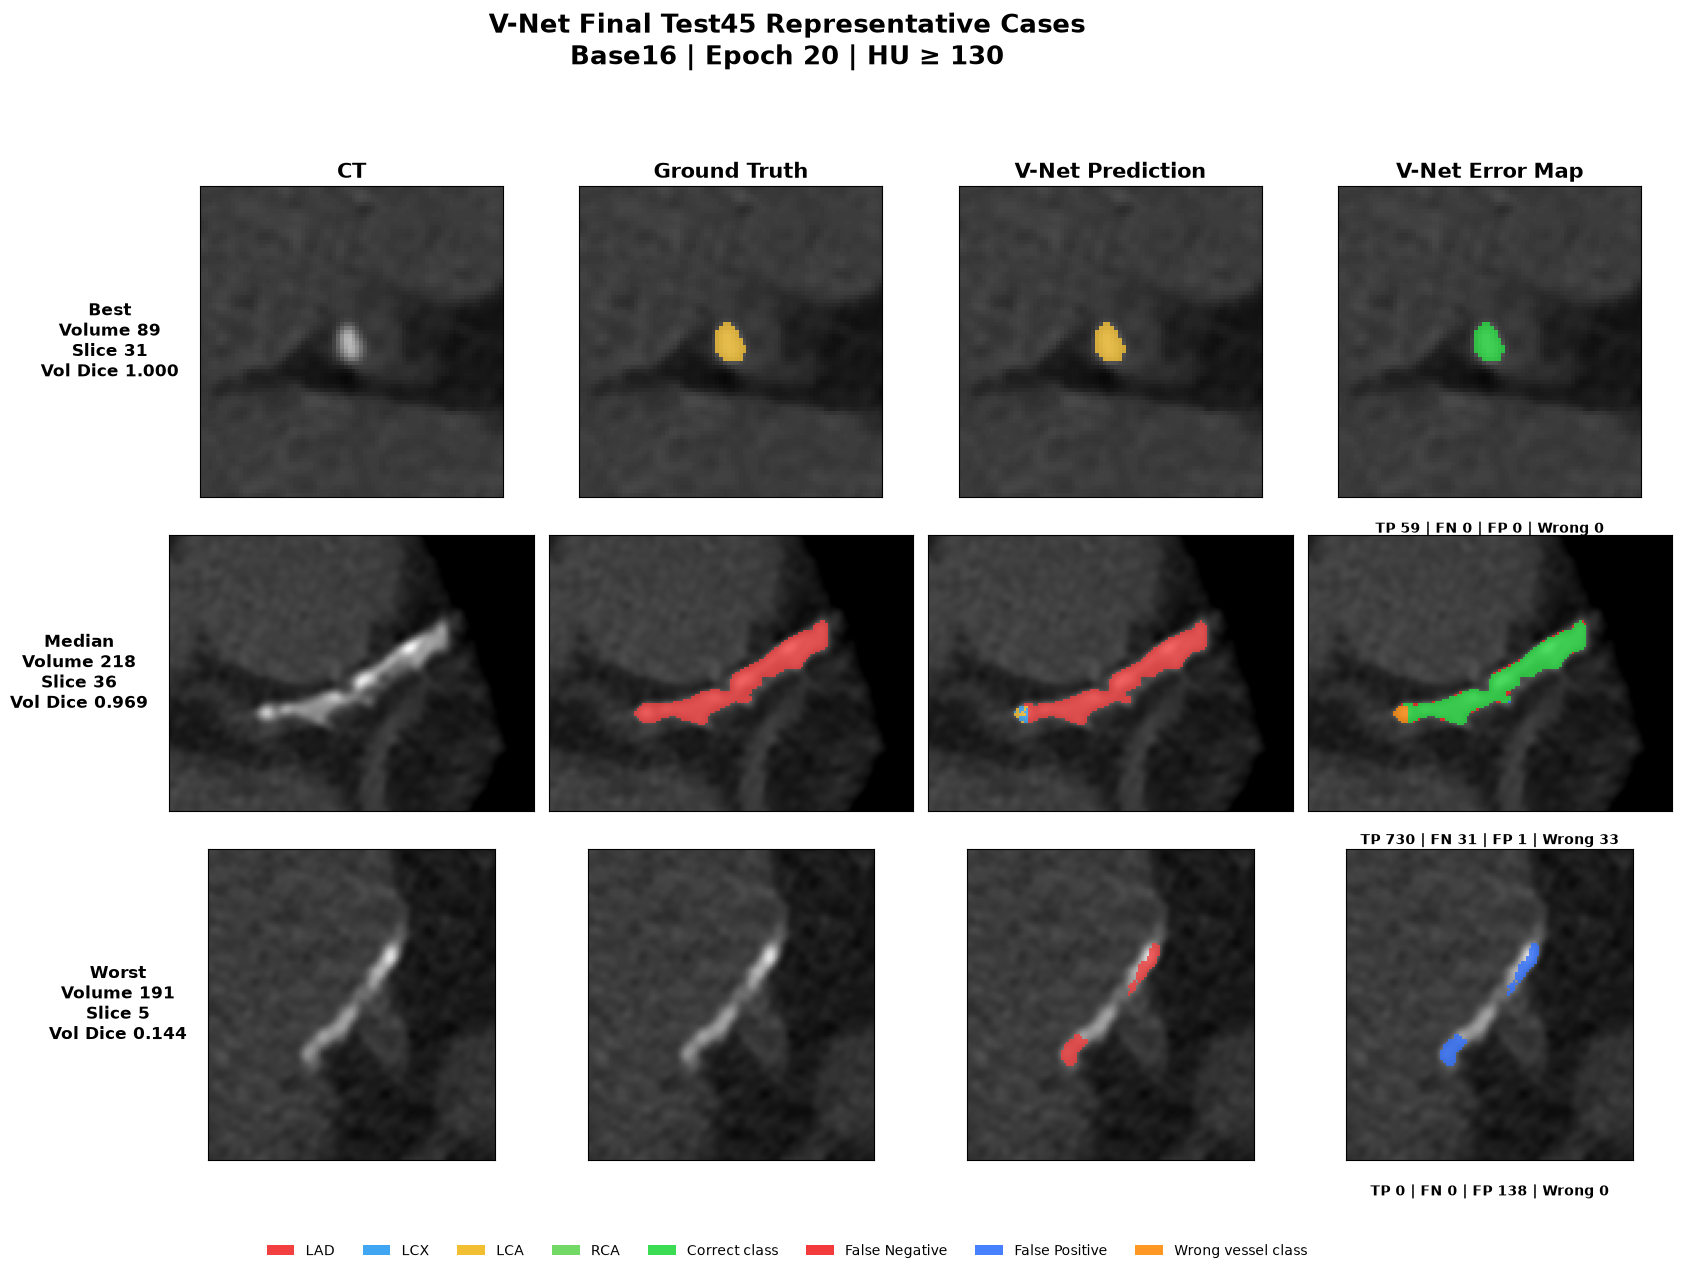


V-NET REPRESENTATIVE VISUALIZATION SUMMARY
  Case Volume Foreground_Dice  Selected_Slice  Slice_Correct_Class  Slice_FN  Slice_FP  Slice_Wrong_Class
  Best     89        1.000000              31                   59         0         0                  0
Median    218        0.968560              36                  730        31         1                 33
 Worst    191        0.143939               5                    0         0       138                  0

STEP 88A-2 QC
Cases Visualized     : 3
Figure Saved         : True
Summary CSV Saved    : True
Selection Basis      : V-Net Final Test Foreground Dice
Purpose              : QUALITATIVE VISUALIZATION ONLY

Test Inference Rerun : False
Test Tuning          : NOT ALLOWED

Figure : /home/korea1/workspace/datasets/COCA/final_visualizations/vnet_representative_cases/vnet_final_hu130_best_median_worst.png
CSV    : /home/korea1/workspace/datasets/COCA/final_visualizations/vnet_representative_cases/vnet_final_hu130_best_median_worst.

In [208]:
# ============================================================
# STEP 88A-2. V-Net Representative Patient Visualization
# - V-Net Final HU130 prediction 기준
# - Test45에서 V-Net 자체 Best / Median / Worst 선정
#
# 구성
# - CT
# - Ground Truth
# - V-Net Prediction
# - Error Map
#
# Error Map
# - Green  : Correct vessel class
# - Red    : False Negative
# - Blue   : False Positive
# - Orange : Wrong vessel class
#
# 중요
# - 저장된 Final HU130 prediction만 사용
# - Test inference 재실행 없음
# - Test tuning 없음
# - 대표 case 선정은 시각화/분석 용도만 사용
# ============================================================

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


# ============================================================
# 0. 필수 객체 확인
# ============================================================

required_names = [
    "COCA_ROOT",
    "vnet_pred_root",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]


print("=" * 80)
print("STEP 88A-2 - V-Net Representative Patient Visualization")
print("=" * 80)

print(
    "Missing Dependencies :",
    missing_names
)


if missing_names:
    raise RuntimeError(
        f"필수 객체가 없습니다: {missing_names}"
    )


# ============================================================
# 1. 실제 경로
# ============================================================

TEST_CACHE_ROOT = (
    COCA_ROOT
    / "coca_test_volume_cache_npy"
)

VNET_PATIENT_METRICS_CSV = (
    COCA_ROOT
    / "logs"
    / "vnet_final"
    / "vnet_base16_final_test_patient_metrics.csv"
)

VNET_VIS_ROOT = (
    COCA_ROOT
    / "final_visualizations"
    / "vnet_representative_cases"
)

VNET_VIS_PATH = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_best_median_worst.png"
)

VNET_SUMMARY_CSV = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_best_median_worst.csv"
)


VNET_VIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. Root QC
# ============================================================

root_status = {
    "Test Cache":
        TEST_CACHE_ROOT.exists(),

    "V-Net Prediction":
        vnet_pred_root.exists(),

    "Patient Metrics":
        VNET_PATIENT_METRICS_CSV.exists(),
}


print()
print("=" * 80)
print("Source Check")
print("=" * 80)


for name, status in (
    root_status.items()
):

    print(
        f"{name:<18s} :",
        status
    )


if not all(
    root_status.values()
):
    raise RuntimeError(
        "필수 source가 없습니다."
    )


# ============================================================
# 3. Test Volume ID
# ============================================================

prediction_files = sorted(
    vnet_pred_root.glob(
        "*_pred.npy"
    )
)


volume_ids = sorted(
    [
        path.name.replace(
            "_pred.npy",
            ""
        )
        for path
        in prediction_files
    ],
    key=lambda x:
        int(x),
)


print()
print(
    "Prediction Volumes :",
    len(volume_ids)
)


if len(volume_ids) != 45:
    raise RuntimeError(
        "V-Net prediction volume이 45개가 아닙니다."
    )


# ============================================================
# 4. Foreground Dice 함수
# ============================================================

def foreground_dice_88a2(
    prediction,
    target,
):

    pred_fg = (
        prediction > 0
    )

    gt_fg = (
        target > 0
    )


    tp = int(
        np.sum(
            pred_fg
            & gt_fg
        )
    )

    fp = int(
        np.sum(
            pred_fg
            & (~gt_fg)
        )
    )

    fn = int(
        np.sum(
            (~pred_fg)
            & gt_fg
        )
    )


    denominator = (
        2 * tp
        + fp
        + fn
    )


    if denominator == 0:
        return np.nan


    return (
        2.0 * tp
        / denominator
    )


# ============================================================
# 5. 전체 Test45 V-Net Foreground Dice
# ============================================================

case_records = []


for volume_id in volume_ids:

    gt_path = (
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy"
    )

    pred_path = (
        vnet_pred_root
        / f"{volume_id}_pred.npy"
    )


    if not gt_path.exists():
        raise FileNotFoundError(
            gt_path
        )


    gt = np.load(
        gt_path,
        mmap_mode="r",
    )

    prediction = np.load(
        pred_path,
        mmap_mode="r",
    )


    if gt.shape != prediction.shape:
        raise RuntimeError(
            f"Volume {volume_id} shape mismatch "
            f"| GT {gt.shape} "
            f"| Pred {prediction.shape}"
        )


    gt_fg = int(
        np.sum(
            gt > 0
        )
    )

    pred_fg = int(
        np.sum(
            prediction > 0
        )
    )


    fg_dice = foreground_dice_88a2(
        prediction,
        gt,
    )


    case_records.append({
        "volume_id":
            str(
                volume_id
            ),

        "depth":
            int(
                gt.shape[0]
            ),

        "gt_foreground":
            gt_fg,

        "pred_foreground":
            pred_fg,

        "foreground_dice":
            float(
                fg_dice
            )
            if np.isfinite(
                fg_dice
            )
            else np.nan,
    })


    del gt
    del prediction


case_df = pd.DataFrame(
    case_records
)


# ============================================================
# 6. GT CAC Positive Case만 선정 후보
# ============================================================

positive_df = (
    case_df[
        case_df[
            "gt_foreground"
        ] > 0
    ]
    .dropna(
        subset=[
            "foreground_dice"
        ]
    )
    .sort_values(
        by=[
            "foreground_dice",
            "volume_id",
        ],
        ascending=[
            True,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


if len(
    positive_df
) < 3:
    raise RuntimeError(
        "대표 case를 선정할 positive volume이 부족합니다."
    )


# ============================================================
# 7. Best / Median / Worst 선정
# ============================================================

worst_row = (
    positive_df.iloc[
        0
    ]
)

median_row = (
    positive_df.iloc[
        len(
            positive_df
        )
        // 2
    ]
)

best_row = (
    positive_df.iloc[
        -1
    ]
)


representative_cases_88a2 = [
    {
        "case":
            "Best",

        "volume_id":
            str(
                best_row[
                    "volume_id"
                ]
            ),

        "foreground_dice":
            float(
                best_row[
                    "foreground_dice"
                ]
            ),
    },

    {
        "case":
            "Median",

        "volume_id":
            str(
                median_row[
                    "volume_id"
                ]
            ),

        "foreground_dice":
            float(
                median_row[
                    "foreground_dice"
                ]
            ),
    },

    {
        "case":
            "Worst",

        "volume_id":
            str(
                worst_row[
                    "volume_id"
                ]
            ),

        "foreground_dice":
            float(
                worst_row[
                    "foreground_dice"
                ]
            ),
    },
]


print()
print("=" * 80)
print("V-NET REPRESENTATIVE CASES")
print("=" * 80)


for case in representative_cases_88a2:

    print(
        f"{case['case']:<6s} "
        f"| Volume {case['volume_id']:>3s} "
        f"| FG Dice "
        f"{case['foreground_dice']:.6f}"
    )


# ============================================================
# 8. Class / Error Color
# ============================================================

CLASS_NAMES_88A2 = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


SEG_COLORS_88A2 = [
    (0.0, 0.0, 0.0, 0.0),
    (0.95, 0.25, 0.25, 1.0),
    (0.25, 0.65, 0.95, 1.0),
    (0.95, 0.75, 0.20, 1.0),
    (0.45, 0.85, 0.40, 1.0),
]


seg_cmap_88a2 = ListedColormap(
    SEG_COLORS_88A2
)

seg_norm_88a2 = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


ERROR_COLORS_88A2 = [
    (0.0, 0.0, 0.0, 0.0),
    (0.15, 0.85, 0.25, 0.90),  # Correct
    (0.95, 0.15, 0.15, 0.90),  # FN
    (0.20, 0.45, 1.00, 0.90),  # FP
    (1.00, 0.55, 0.05, 0.90),  # Wrong class
]


error_cmap_88a2 = ListedColormap(
    ERROR_COLORS_88A2
)

error_norm_88a2 = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 9. Error Map
# ============================================================

def build_error_map_88a2(
    gt,
    prediction,
):

    error_map = np.zeros(
        gt.shape,
        dtype=np.uint8,
    )


    gt_fg = (
        gt > 0
    )

    pred_fg = (
        prediction > 0
    )


    correct = (
        gt_fg
        &
        pred_fg
        &
        (gt == prediction)
    )

    false_negative = (
        gt_fg
        &
        (~pred_fg)
    )

    false_positive = (
        (~gt_fg)
        &
        pred_fg
    )

    wrong_class = (
        gt_fg
        &
        pred_fg
        &
        (gt != prediction)
    )


    error_map[
        correct
    ] = 1

    error_map[
        false_negative
    ] = 2

    error_map[
        false_positive
    ] = 3

    error_map[
        wrong_class
    ] = 4


    return error_map


# ============================================================
# 10. 대표 Slice 선정
# - GT foreground가 충분히 보이면서
# - V-Net 오류도 함께 확인 가능한 slice
# ============================================================

def select_slice_88a2(
    gt,
    prediction,
):

    best_z = 0
    best_score = -1


    for z in range(
        gt.shape[0]
    ):

        gt_slice = (
            gt[
                z
            ]
        )

        pred_slice = (
            prediction[
                z
            ]
        )


        gt_fg = int(
            np.sum(
                gt_slice > 0
            )
        )

        pred_fg = int(
            np.sum(
                pred_slice > 0
            )
        )

        mismatch = int(
            np.sum(
                gt_slice
                != pred_slice
            )
        )


        score = (
            gt_fg * 10
            + mismatch * 3
            + pred_fg
        )


        if score > best_score:

            best_score = score
            best_z = z


    return int(
        best_z
    )


# ============================================================
# 11. ROI
# ============================================================

def get_roi_88a2(
    gt_slice,
    pred_slice,
    margin=35,
):

    combined = (
        (gt_slice > 0)
        |
        (pred_slice > 0)
    )


    coords = np.argwhere(
        combined
    )


    if len(
        coords
    ) == 0:

        return (
            0,
            gt_slice.shape[0],
            0,
            gt_slice.shape[1],
        )


    y_min = max(
        int(
            coords[:, 0].min()
        )
        - margin,
        0,
    )

    y_max = min(
        int(
            coords[:, 0].max()
        )
        + margin
        + 1,
        gt_slice.shape[0],
    )

    x_min = max(
        int(
            coords[:, 1].min()
        )
        - margin,
        0,
    )

    x_max = min(
        int(
            coords[:, 1].max()
        )
        + margin
        + 1,
        gt_slice.shape[1],
    )


    return (
        y_min,
        y_max,
        x_min,
        x_max,
    )


# ============================================================
# 12. Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(
        18,
        13,
    ),
)


column_titles = [
    "CT",
    "Ground Truth",
    "V-Net Prediction",
    "V-Net Error Map",
]


for col_idx, title in enumerate(
    column_titles
):

    axes[
        0,
        col_idx
    ].set_title(
        title,
        fontsize=15,
        fontweight="bold",
    )


visual_summary_rows = []


# ============================================================
# 13. Case별 시각화
# ============================================================

for row_idx, case in enumerate(
    representative_cases_88a2
):

    volume_id = (
        case[
            "volume_id"
        ]
    )


    ct = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    prediction = np.load(
        vnet_pred_root
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )


    assert (
        ct.shape
        == gt.shape
        == prediction.shape
    )


    # --------------------------------------------------------
    # Slice
    # --------------------------------------------------------

    z_index = select_slice_88a2(
        gt,
        prediction,
    )


    ct_slice = np.asarray(
        ct[
            z_index
        ]
    )

    gt_slice = np.asarray(
        gt[
            z_index
        ]
    )

    pred_slice = np.asarray(
        prediction[
            z_index
        ]
    )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    (
        y_min,
        y_max,
        x_min,
        x_max,
    ) = get_roi_88a2(
        gt_slice,
        pred_slice,
        margin=35,
    )


    ct_roi = (
        ct_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    gt_roi = (
        gt_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    pred_roi = (
        pred_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )


    error_roi = (
        build_error_map_88a2(
            gt_roi,
            pred_roi,
        )
    )


    # --------------------------------------------------------
    # CT
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    # --------------------------------------------------------
    # GT
    # --------------------------------------------------------

    axes[
        row_idx,
        1
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    gt_masked = np.ma.masked_where(
        gt_roi == 0,
        gt_roi,
    )

    axes[
        row_idx,
        1
    ].imshow(
        gt_masked,
        cmap=seg_cmap_88a2,
        norm=seg_norm_88a2,
        alpha=0.80,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # V-Net Prediction
    # --------------------------------------------------------

    axes[
        row_idx,
        2
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    pred_masked = np.ma.masked_where(
        pred_roi == 0,
        pred_roi,
    )

    axes[
        row_idx,
        2
    ].imshow(
        pred_masked,
        cmap=seg_cmap_88a2,
        norm=seg_norm_88a2,
        alpha=0.80,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # Error
    # --------------------------------------------------------

    axes[
        row_idx,
        3
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )

    error_masked = np.ma.masked_where(
        error_roi == 0,
        error_roi,
    )

    axes[
        row_idx,
        3
    ].imshow(
        error_masked,
        cmap=error_cmap_88a2,
        norm=error_norm_88a2,
        alpha=0.90,
        interpolation="nearest",
    )


    # --------------------------------------------------------
    # Error Count
    # --------------------------------------------------------

    correct_count = int(
        np.sum(
            error_roi == 1
        )
    )

    fn_count = int(
        np.sum(
            error_roi == 2
        )
    )

    fp_count = int(
        np.sum(
            error_roi == 3
        )
    )

    wrong_count = int(
        np.sum(
            error_roi == 4
        )
    )


    # --------------------------------------------------------
    # Row label
    # --------------------------------------------------------

    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"{case['case']}\n"
            f"Volume {volume_id}\n"
            f"Slice {z_index}\n"
            f"Vol Dice "
            f"{case['foreground_dice']:.3f}"
        ),
        fontsize=12,
        fontweight="bold",
        rotation=0,
        labelpad=65,
        va="center",
    )


    # --------------------------------------------------------
    # Error annotation
    # --------------------------------------------------------

    axes[
        row_idx,
        3
    ].text(
        0.5,
        -0.08,
        (
            f"TP {correct_count} | "
            f"FN {fn_count} | "
            f"FP {fp_count} | "
            f"Wrong {wrong_count}"
        ),
        transform=axes[
            row_idx,
            3
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
    )


    visual_summary_rows.append({
        "Case":
            case[
                "case"
            ],

        "Volume":
            volume_id,

        "Foreground_Dice":
            case[
                "foreground_dice"
            ],

        "Selected_Slice":
            z_index,

        "Slice_Correct_Class":
            correct_count,

        "Slice_FN":
            fn_count,

        "Slice_FP":
            fp_count,

        "Slice_Wrong_Class":
            wrong_count,
    })


    del ct
    del gt
    del prediction


# ============================================================
# 14. Axis
# ============================================================

for ax_row in axes:

    for ax in ax_row:

        ax.set_xticks([])
        ax.set_yticks([])


# ============================================================
# 15. Legend
# ============================================================

class_legend = [
    Patch(
        facecolor=SEG_COLORS_88A2[
            class_id
        ],
        label=CLASS_NAMES_88A2[
            class_id
        ],
    )
    for class_id in range(
        1,
        5,
    )
]


error_legend = [
    Patch(
        facecolor=ERROR_COLORS_88A2[1],
        label="Correct class",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A2[2],
        label="False Negative",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A2[3],
        label="False Positive",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A2[4],
        label="Wrong vessel class",
    ),
]


fig.legend(
    handles=
        class_legend
        + error_legend,
    loc="lower center",
    ncol=8,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(
        0.5,
        0.015,
    ),
)


# ============================================================
# 16. Title
# ============================================================

fig.suptitle(
    (
        "V-Net Final Test45 Representative Cases\n"
        "Base16 | Epoch 20 | HU ≥ 130"
    ),
    fontsize=19,
    fontweight="bold",
    y=0.985,
)


plt.tight_layout(
    rect=[
        0.06,
        0.06,
        1.0,
        0.94,
    ]
)


# ============================================================
# 17. Save
# ============================================================

plt.savefig(
    VNET_VIS_PATH,
    dpi=240,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 18. Summary CSV
# ============================================================

visual_summary_df = pd.DataFrame(
    visual_summary_rows
)


visual_summary_df.to_csv(
    VNET_SUMMARY_CSV,
    index=False,
)


# ============================================================
# 19. Output
# ============================================================

print()
print("=" * 80)
print("V-NET REPRESENTATIVE VISUALIZATION SUMMARY")
print("=" * 80)


print(
    visual_summary_df.to_string(
        index=False,
        formatters={
            "Foreground_Dice":
                "{:.6f}".format,
        },
    )
)


# ============================================================
# 20. Final QC
# ============================================================

figure_ok = (
    VNET_VIS_PATH.exists()
)

csv_ok = (
    VNET_SUMMARY_CSV.exists()
)

cases_ok = (
    len(
        visual_summary_df
    )
    == 3
)


step_88a2_pass = all([
    figure_ok,
    csv_ok,
    cases_ok,
])


print()
print("=" * 80)
print("STEP 88A-2 QC")
print("=" * 80)

print(
    "Cases Visualized     :",
    len(
        visual_summary_df
    )
)

print(
    "Figure Saved         :",
    figure_ok
)

print(
    "Summary CSV Saved    :",
    csv_ok
)

print(
    "Selection Basis      :",
    "V-Net Final Test Foreground Dice"
)

print(
    "Purpose              :",
    "QUALITATIVE VISUALIZATION ONLY"
)

print()

print(
    "Test Inference Rerun :",
    False
)

print(
    "Test Tuning          :",
    "NOT ALLOWED"
)

print()

print(
    "Figure :",
    VNET_VIS_PATH
)

print(
    "CSV    :",
    VNET_SUMMARY_CSV
)

print()

print(
    "STEP 88A-2 PASS :",
    step_88a2_pass
)

print("=" * 80)

STEP 88A-3 - V-Net Representative Slice Refinement

Fixed Representative Patients
Best   | Volume  89 | Dice 1.000000
Median | Volume 218 | Dice 0.968560
Worst  | Volume 191 | Dice 0.143939


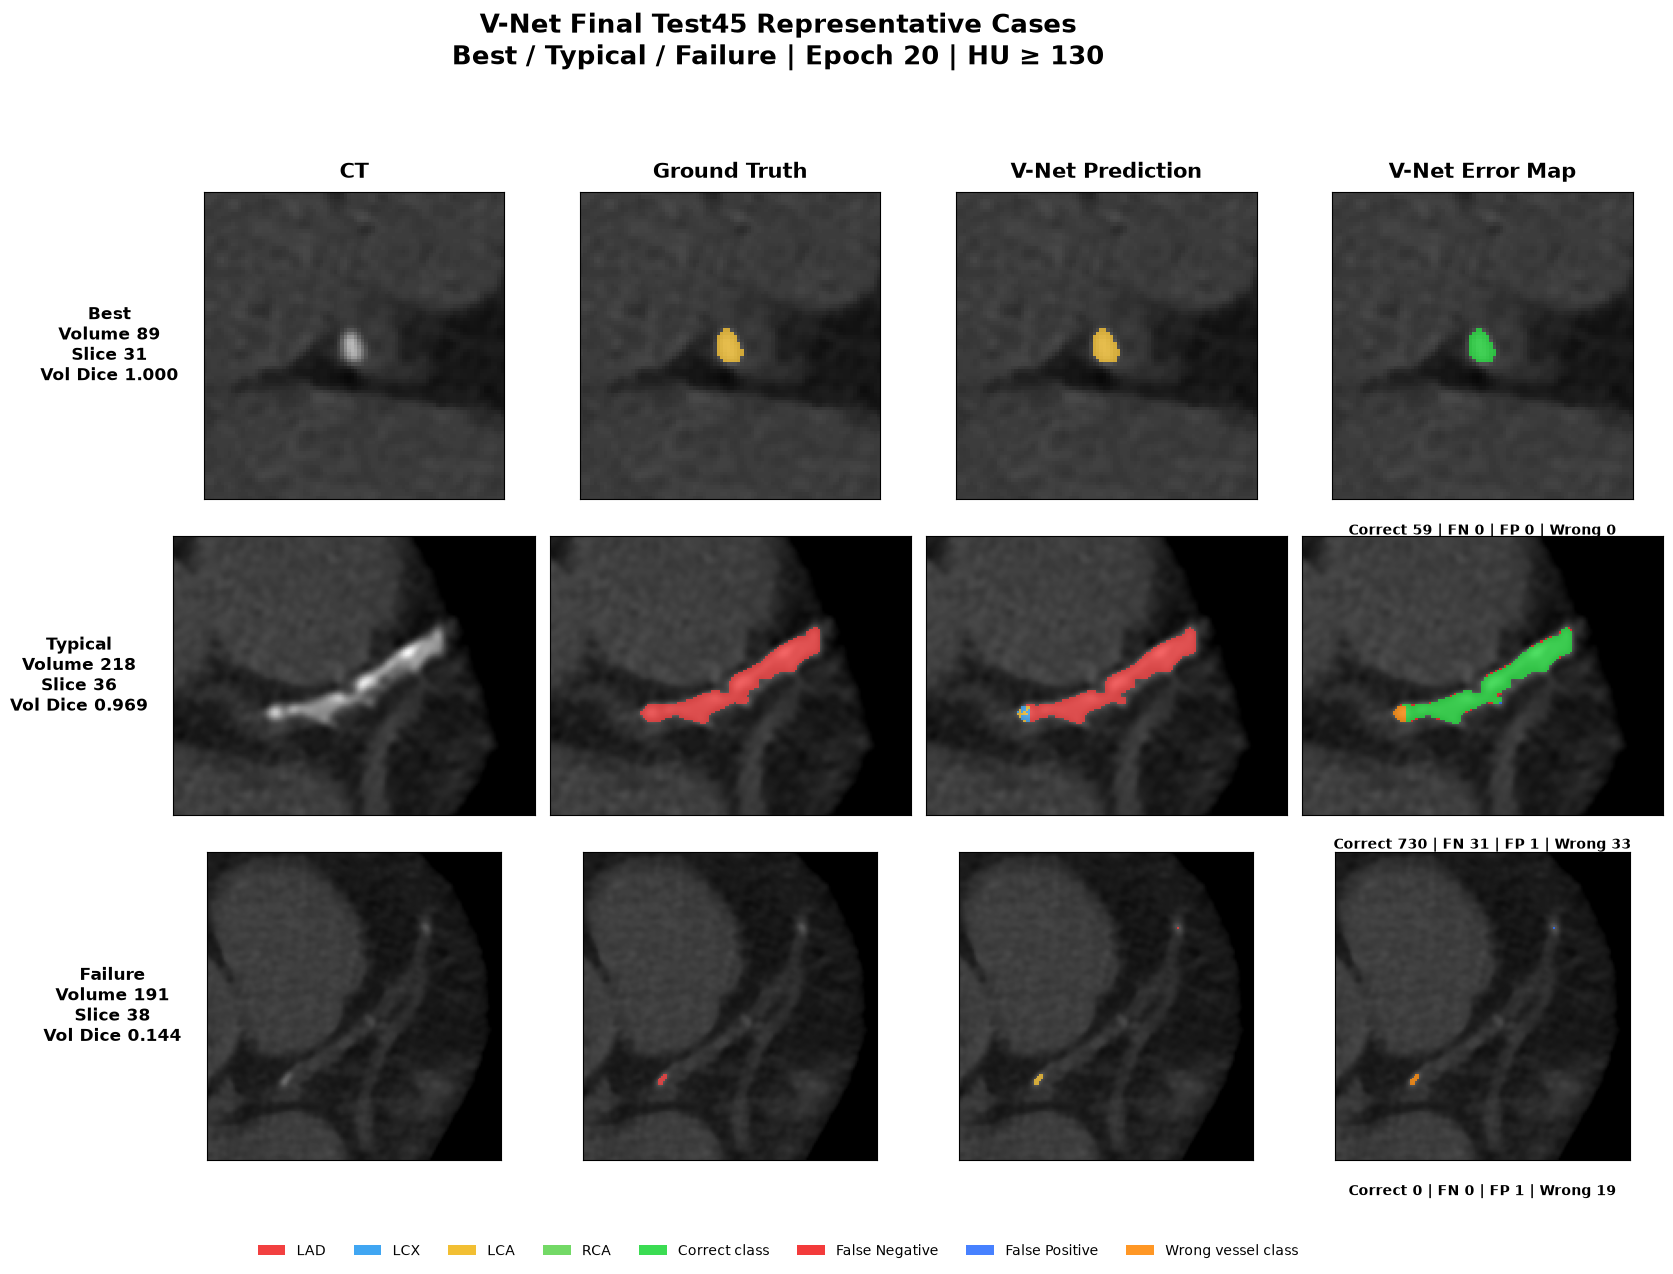


REFINED REPRESENTATIVE SLICES
   Case Original_Case_Label Volume Volume_Foreground_Dice  Selected_Slice  Slice_GT_FG  Slice_Pred_FG  Correct  FN  FP  Wrong_Class
   Best                Best     89               1.000000              31           59             59       59   0   0            0
Typical              Median    218               0.968560              36          794            764      730  31   1           33
Failure               Worst    191               0.143939              38           19             20        0   0   1           19

STEP 88A-3 QC
Cases Visualized      : 3
GT-positive Slices    : True
Figure Saved          : True
Summary CSV Saved     : True
Patients Reselected   : False
Test Inference Rerun  : False
Test Tuning           : NOT ALLOWED

Figure : /home/korea1/workspace/datasets/COCA/final_visualizations/vnet_representative_cases/vnet_final_hu130_representative_cases_refined.png
CSV    : /home/korea1/workspace/datasets/COCA/final_visualizations/vnet_r

In [209]:
# ============================================================
# STEP 88A-3. V-Net Representative Visualization - Slice Refinement
# - STEP 88A-2에서 선정된 대표 환자는 그대로 유지
#
# Representative Cases
# - Best    : 기존 V-Net Best
# - Typical : 기존 V-Net Median
# - Failure : 기존 V-Net Worst
#
# 개선점
# - GT foreground가 존재하는 slice만 우선 후보로 사용
# - 그중 오류 + GT 정보가 함께 잘 보이는 slice 선택
#
# 중요
# - 환자 재선정 없음
# - Test inference 없음
# - Test tuning 없음
# - 저장된 HU130 prediction만 사용
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

TEST_CACHE_ROOT = (
    COCA_ROOT
    / "coca_test_volume_cache_npy"
)

VNET_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)

VNET_VIS_ROOT = (
    COCA_ROOT
    / "final_visualizations"
    / "vnet_representative_cases"
)

VNET_REFINED_FIGURE = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_representative_cases_refined.png"
)

VNET_REFINED_CSV = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_representative_cases_refined.csv"
)


VNET_VIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


print("=" * 80)
print("STEP 88A-3 - V-Net Representative Slice Refinement")
print("=" * 80)


# ============================================================
# 1. STEP 88A-2 대표 환자 확인
# ============================================================

if (
    "representative_cases_88a2"
    not in globals()
):

    raise RuntimeError(
        "STEP 88A-2의 representative_cases_88a2가 없습니다."
    )


if len(
    representative_cases_88a2
) != 3:

    raise RuntimeError(
        "대표 환자가 3명이 아닙니다."
    )


print()
print("=" * 80)
print("Fixed Representative Patients")
print("=" * 80)


for case in representative_cases_88a2:

    print(
        f"{case['case']:<6s} "
        f"| Volume {case['volume_id']:>3s} "
        f"| Dice {case['foreground_dice']:.6f}"
    )


# ============================================================
# 2. 표시용 Case 이름
# ============================================================

DISPLAY_CASE_NAMES = {
    "Best":
        "Best",

    "Median":
        "Typical",

    "Worst":
        "Failure",
}


# ============================================================
# 3. Class Color
# ============================================================

CLASS_NAMES_88A3 = {
    0: "Background",
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


SEG_COLORS_88A3 = [
    (0.0, 0.0, 0.0, 0.0),
    (0.95, 0.25, 0.25, 1.0),
    (0.25, 0.65, 0.95, 1.0),
    (0.95, 0.75, 0.20, 1.0),
    (0.45, 0.85, 0.40, 1.0),
]


seg_cmap_88a3 = ListedColormap(
    SEG_COLORS_88A3
)

seg_norm_88a3 = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 4. Error Color
#
# 1 Correct
# 2 FN
# 3 FP
# 4 Wrong Vessel Class
# ============================================================

ERROR_COLORS_88A3 = [
    (0.0, 0.0, 0.0, 0.0),
    (0.15, 0.85, 0.25, 0.90),
    (0.95, 0.15, 0.15, 0.90),
    (0.20, 0.45, 1.00, 0.90),
    (1.00, 0.55, 0.05, 0.90),
]


error_cmap_88a3 = ListedColormap(
    ERROR_COLORS_88A3
)

error_norm_88a3 = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 5. Error Map
# ============================================================

def build_error_map_88a3(
    gt,
    prediction,
):

    error_map = np.zeros(
        gt.shape,
        dtype=np.uint8,
    )


    gt_fg = (
        gt > 0
    )

    pred_fg = (
        prediction > 0
    )


    correct = (
        gt_fg
        &
        pred_fg
        &
        (gt == prediction)
    )


    false_negative = (
        gt_fg
        &
        (~pred_fg)
    )


    false_positive = (
        (~gt_fg)
        &
        pred_fg
    )


    wrong_class = (
        gt_fg
        &
        pred_fg
        &
        (gt != prediction)
    )


    error_map[
        correct
    ] = 1

    error_map[
        false_negative
    ] = 2

    error_map[
        false_positive
    ] = 3

    error_map[
        wrong_class
    ] = 4


    return error_map


# ============================================================
# 6. 개선된 Slice 선택
#
# 핵심
# - GT foreground > 0 인 slice를 최우선 후보
#
# Best
# - GT가 가장 풍부하고 정확도가 높은 모습 우선
#
# Typical / Failure
# - GT가 존재하면서 오류가 많이 나타나는 slice 우선
# ============================================================

def select_refined_slice_88a3(
    gt,
    prediction,
    case_type,
):

    candidate_records = []


    for z_index in range(
        gt.shape[0]
    ):

        gt_slice = (
            gt[
                z_index
            ]
        )

        pred_slice = (
            prediction[
                z_index
            ]
        )


        gt_fg = int(
            np.sum(
                gt_slice > 0
            )
        )


        # ----------------------------------------------------
        # GT가 실제 존재하는 slice만 후보
        # ----------------------------------------------------

        if gt_fg == 0:
            continue


        pred_fg = int(
            np.sum(
                pred_slice > 0
            )
        )


        error_map = (
            build_error_map_88a3(
                gt_slice,
                pred_slice,
            )
        )


        correct = int(
            np.sum(
                error_map == 1
            )
        )

        fn = int(
            np.sum(
                error_map == 2
            )
        )

        fp = int(
            np.sum(
                error_map == 3
            )
        )

        wrong = int(
            np.sum(
                error_map == 4
            )
        )


        total_error = (
            fn
            + fp
            + wrong
        )


        # ----------------------------------------------------
        # Slice Score
        # ----------------------------------------------------

        if case_type == "Best":

            # Best는 GT가 잘 보이고
            # correct voxel이 풍부한 slice 우선
            score = (
                gt_fg * 10
                + correct * 8
                - total_error * 2
            )

        else:

            # Typical / Failure은
            # GT가 실제 존재하면서
            # 오류가 시각적으로 잘 보이는 slice
            score = (
                total_error * 12
                + gt_fg * 5
                + pred_fg
            )


        candidate_records.append({
            "z_index":
                int(
                    z_index
                ),

            "score":
                float(
                    score
                ),

            "gt_fg":
                gt_fg,

            "pred_fg":
                pred_fg,

            "correct":
                correct,

            "fn":
                fn,

            "fp":
                fp,

            "wrong":
                wrong,

            "total_error":
                total_error,
        })


    # --------------------------------------------------------
    # 혹시 GT-positive slice가 없으면 fallback
    # --------------------------------------------------------

    if len(
        candidate_records
    ) == 0:

        raise RuntimeError(
            "GT foreground가 존재하는 slice가 없습니다."
        )


    candidate_records = sorted(
        candidate_records,
        key=lambda row:
            row[
                "score"
            ],
        reverse=True,
    )


    return candidate_records[
        0
    ]


# ============================================================
# 7. ROI
# ============================================================

def get_roi_88a3(
    gt_slice,
    pred_slice,
    margin=40,
):

    combined = (
        (gt_slice > 0)
        |
        (pred_slice > 0)
    )


    coords = np.argwhere(
        combined
    )


    if len(
        coords
    ) == 0:

        return (
            0,
            gt_slice.shape[0],
            0,
            gt_slice.shape[1],
        )


    y_min = max(
        int(
            coords[:, 0].min()
        )
        - margin,
        0,
    )

    y_max = min(
        int(
            coords[:, 0].max()
        )
        + margin
        + 1,
        gt_slice.shape[0],
    )

    x_min = max(
        int(
            coords[:, 1].min()
        )
        - margin,
        0,
    )

    x_max = min(
        int(
            coords[:, 1].max()
        )
        + margin
        + 1,
        gt_slice.shape[1],
    )


    return (
        y_min,
        y_max,
        x_min,
        x_max,
    )


# ============================================================
# 8. Figure
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(
        18,
        13,
    ),
)


column_titles = [
    "CT",
    "Ground Truth",
    "V-Net Prediction",
    "V-Net Error Map",
]


for col_idx, title in enumerate(
    column_titles
):

    axes[
        0,
        col_idx
    ].set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=10,
    )


refined_summary_rows = []


# ============================================================
# 9. Case별 Visualization
# ============================================================

for row_idx, case in enumerate(
    representative_cases_88a2
):

    original_case = (
        case[
            "case"
        ]
    )

    display_case = (
        DISPLAY_CASE_NAMES[
            original_case
        ]
    )

    volume_id = (
        str(
            case[
                "volume_id"
            ]
        )
    )


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    ct = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    prediction = np.load(
        VNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )


    assert (
        ct.shape
        == gt.shape
        == prediction.shape
    )


    # --------------------------------------------------------
    # Refined Slice 선택
    # --------------------------------------------------------

    selected = (
        select_refined_slice_88a3(
            gt,
            prediction,
            original_case,
        )
    )


    z_index = (
        selected[
            "z_index"
        ]
    )


    ct_slice = np.asarray(
        ct[
            z_index
        ]
    )

    gt_slice = np.asarray(
        gt[
            z_index
        ]
    )

    pred_slice = np.asarray(
        prediction[
            z_index
        ]
    )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    (
        y_min,
        y_max,
        x_min,
        x_max,
    ) = get_roi_88a3(
        gt_slice,
        pred_slice,
        margin=40,
    )


    ct_roi = (
        ct_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    gt_roi = (
        gt_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    pred_roi = (
        pred_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )


    error_roi = (
        build_error_map_88a3(
            gt_roi,
            pred_roi,
        )
    )


    # ========================================================
    # 9-1. CT
    # ========================================================

    axes[
        row_idx,
        0
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    # ========================================================
    # 9-2. GT
    # ========================================================

    axes[
        row_idx,
        1
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    gt_masked = np.ma.masked_where(
        gt_roi == 0,
        gt_roi,
    )


    axes[
        row_idx,
        1
    ].imshow(
        gt_masked,
        cmap=seg_cmap_88a3,
        norm=seg_norm_88a3,
        alpha=0.80,
        interpolation="nearest",
    )


    # ========================================================
    # 9-3. Prediction
    # ========================================================

    axes[
        row_idx,
        2
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    pred_masked = np.ma.masked_where(
        pred_roi == 0,
        pred_roi,
    )


    axes[
        row_idx,
        2
    ].imshow(
        pred_masked,
        cmap=seg_cmap_88a3,
        norm=seg_norm_88a3,
        alpha=0.80,
        interpolation="nearest",
    )


    # ========================================================
    # 9-4. Error
    # ========================================================

    axes[
        row_idx,
        3
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    error_masked = np.ma.masked_where(
        error_roi == 0,
        error_roi,
    )


    axes[
        row_idx,
        3
    ].imshow(
        error_masked,
        cmap=error_cmap_88a3,
        norm=error_norm_88a3,
        alpha=0.90,
        interpolation="nearest",
    )


    # ========================================================
    # 9-5. Row Label
    # ========================================================

    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"{display_case}\n"
            f"Volume {volume_id}\n"
            f"Slice {z_index}\n"
            f"Vol Dice "
            f"{case['foreground_dice']:.3f}"
        ),
        fontsize=12,
        fontweight="bold",
        rotation=0,
        labelpad=68,
        va="center",
    )


    # ========================================================
    # 9-6. Error Count
    # ========================================================

    correct_count = int(
        np.sum(
            error_roi == 1
        )
    )

    fn_count = int(
        np.sum(
            error_roi == 2
        )
    )

    fp_count = int(
        np.sum(
            error_roi == 3
        )
    )

    wrong_count = int(
        np.sum(
            error_roi == 4
        )
    )


    axes[
        row_idx,
        3
    ].text(
        0.5,
        -0.08,
        (
            f"Correct {correct_count} | "
            f"FN {fn_count} | "
            f"FP {fp_count} | "
            f"Wrong {wrong_count}"
        ),
        transform=axes[
            row_idx,
            3
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold",
    )


    refined_summary_rows.append({
        "Case":
            display_case,

        "Original_Case_Label":
            original_case,

        "Volume":
            volume_id,

        "Volume_Foreground_Dice":
            float(
                case[
                    "foreground_dice"
                ]
            ),

        "Selected_Slice":
            int(
                z_index
            ),

        "Slice_GT_FG":
            int(
                selected[
                    "gt_fg"
                ]
            ),

        "Slice_Pred_FG":
            int(
                selected[
                    "pred_fg"
                ]
            ),

        "Correct":
            correct_count,

        "FN":
            fn_count,

        "FP":
            fp_count,

        "Wrong_Class":
            wrong_count,
    })


    del ct
    del gt
    del prediction


# ============================================================
# 10. Axis
# ============================================================

for ax_row in axes:

    for ax in ax_row:

        ax.set_xticks([])
        ax.set_yticks([])


# ============================================================
# 11. Legend
# ============================================================

class_legend = [
    Patch(
        facecolor=SEG_COLORS_88A3[
            class_id
        ],
        label=CLASS_NAMES_88A3[
            class_id
        ],
    )
    for class_id in range(
        1,
        5,
    )
]


error_legend = [
    Patch(
        facecolor=ERROR_COLORS_88A3[1],
        label="Correct class",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A3[2],
        label="False Negative",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A3[3],
        label="False Positive",
    ),

    Patch(
        facecolor=ERROR_COLORS_88A3[4],
        label="Wrong vessel class",
    ),
]


fig.legend(
    handles=
        class_legend
        + error_legend,
    loc="lower center",
    ncol=8,
    frameon=False,
    fontsize=10,
    bbox_to_anchor=(
        0.5,
        0.015,
    ),
)


# ============================================================
# 12. Title
# ============================================================

fig.suptitle(
    (
        "V-Net Final Test45 Representative Cases\n"
        "Best / Typical / Failure | Epoch 20 | HU ≥ 130"
    ),
    fontsize=19,
    fontweight="bold",
    y=0.985,
)


plt.tight_layout(
    rect=[
        0.065,
        0.06,
        1.0,
        0.94,
    ]
)


# ============================================================
# 13. Save
# ============================================================

plt.savefig(
    VNET_REFINED_FIGURE,
    dpi=240,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 14. Summary CSV
# ============================================================

refined_summary_df = pd.DataFrame(
    refined_summary_rows
)


refined_summary_df.to_csv(
    VNET_REFINED_CSV,
    index=False,
)


# ============================================================
# 15. Output
# ============================================================

print()
print("=" * 80)
print("REFINED REPRESENTATIVE SLICES")
print("=" * 80)


print(
    refined_summary_df.to_string(
        index=False,
        formatters={
            "Volume_Foreground_Dice":
                "{:.6f}".format,
        },
    )
)


# ============================================================
# 16. QC
# ============================================================

figure_ok = (
    VNET_REFINED_FIGURE.exists()
)

csv_ok = (
    VNET_REFINED_CSV.exists()
)

case_ok = (
    len(
        refined_summary_df
    )
    == 3
)

gt_positive_ok = bool(
    (
        refined_summary_df[
            "Slice_GT_FG"
        ] > 0
    ).all()
)


step_88a3_pass = all([
    figure_ok,
    csv_ok,
    case_ok,
    gt_positive_ok,
])


print()
print("=" * 80)
print("STEP 88A-3 QC")
print("=" * 80)

print(
    "Cases Visualized      :",
    len(
        refined_summary_df
    )
)

print(
    "GT-positive Slices    :",
    gt_positive_ok
)

print(
    "Figure Saved          :",
    figure_ok
)

print(
    "Summary CSV Saved     :",
    csv_ok
)

print(
    "Patients Reselected   :",
    False
)

print(
    "Test Inference Rerun  :",
    False
)

print(
    "Test Tuning           :",
    "NOT ALLOWED"
)

print()

print(
    "Figure :",
    VNET_REFINED_FIGURE
)

print(
    "CSV    :",
    VNET_REFINED_CSV
)

print()

print(
    "STEP 88A-3 PASS :",
    step_88a3_pass
)

print("=" * 80)

STEP 88A-4 - V-Net Presentation-ready Visualization

Fixed Cases / Slices
   Case  Volume Volume_Foreground_Dice  Selected_Slice
   Best      89               1.000000              31
Typical     218               0.968560              36
Failure     191               0.143939              38


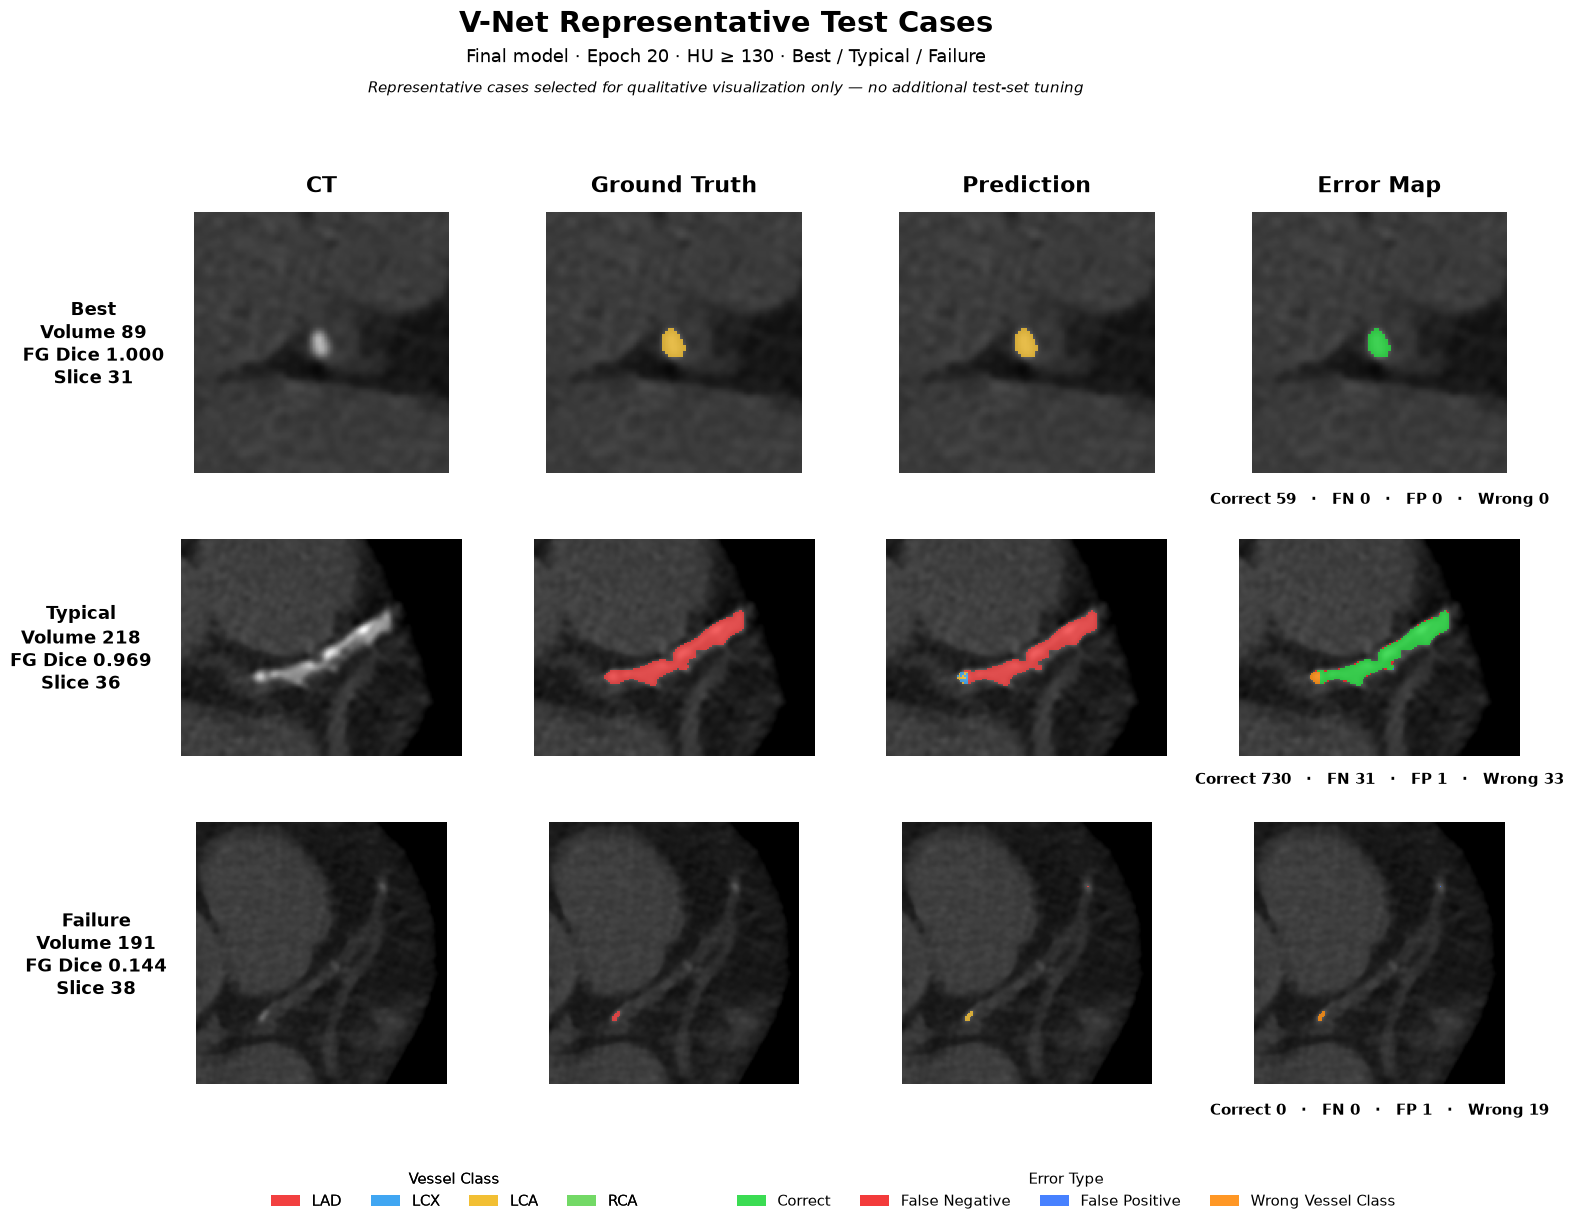


STEP 88A-4 QC
Cases              : 3
Patients Reselected: False
Slices Reselected  : False
Metrics Recomputed : False
Test Inference     : False
Test Tuning        : NOT ALLOWED

Presentation Figure: /home/korea1/workspace/datasets/COCA/final_visualizations/vnet_representative_cases/vnet_final_hu130_representative_cases_presentation.png

STEP 88A-4 PASS : True


In [210]:
# ============================================================
# STEP 88A-4. V-Net Presentation-ready Final Visualization
# - STEP 88A-3에서 확정된 환자 / Slice 그대로 사용
#
# 수정 범위
# - 제목 / 글씨 크기 / Label / Legend만 발표용으로 정리
# - Vol Dice → FG Dice
# - Vessel Class / Error Type Legend 분리
#
# 중요
# - 환자 재선정 없음
# - Slice 재선정 없음
# - Metric 재계산 없음
# - Test inference 없음
# - Test tuning 없음
# ============================================================

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

TEST_CACHE_ROOT = (
    COCA_ROOT
    / "coca_test_volume_cache_npy"
)

VNET_PRED_ROOT = (
    COCA_ROOT
    / "vnet_test_predictions_final_hu130_e20"
)

VNET_VIS_ROOT = (
    COCA_ROOT
    / "final_visualizations"
    / "vnet_representative_cases"
)

REFINED_CSV = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_representative_cases_refined.csv"
)

PRESENTATION_FIGURE = (
    VNET_VIS_ROOT
    / "vnet_final_hu130_representative_cases_presentation.png"
)


print("=" * 80)
print("STEP 88A-4 - V-Net Presentation-ready Visualization")
print("=" * 80)


# ============================================================
# 1. STEP 88A-3 결과 확인
# ============================================================

if not REFINED_CSV.exists():

    raise FileNotFoundError(
        REFINED_CSV
    )


case_df = pd.read_csv(
    REFINED_CSV
)


if len(
    case_df
) != 3:

    raise RuntimeError(
        "STEP 88A-3 대표 case가 3개가 아닙니다."
    )


print()
print("=" * 80)
print("Fixed Cases / Slices")
print("=" * 80)


print(
    case_df[
        [
            "Case",
            "Volume",
            "Volume_Foreground_Dice",
            "Selected_Slice",
        ]
    ].to_string(
        index=False,
        formatters={
            "Volume_Foreground_Dice":
                "{:.6f}".format
        }
    )
)


# ============================================================
# 2. Color Setting
# ============================================================

CLASS_NAMES = {
    1: "LAD",
    2: "LCX",
    3: "LCA",
    4: "RCA",
}


# ------------------------------------------------------------
# Vessel Class
# ------------------------------------------------------------

SEG_COLORS = [
    (0.0, 0.0, 0.0, 0.0),

    # LAD
    (0.95, 0.25, 0.25, 1.0),

    # LCX
    (0.25, 0.65, 0.95, 1.0),

    # LCA
    (0.95, 0.75, 0.20, 1.0),

    # RCA
    (0.45, 0.85, 0.40, 1.0),
]


seg_cmap = ListedColormap(
    SEG_COLORS
)

seg_norm = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ------------------------------------------------------------
# Error Type
# ------------------------------------------------------------

ERROR_COLORS = [
    (0.0, 0.0, 0.0, 0.0),

    # Correct
    (0.15, 0.85, 0.25, 0.90),

    # False Negative
    (0.95, 0.15, 0.15, 0.90),

    # False Positive
    (0.20, 0.45, 1.00, 0.90),

    # Wrong vessel class
    (1.00, 0.55, 0.05, 0.90),
]


error_cmap = ListedColormap(
    ERROR_COLORS
)

error_norm = BoundaryNorm(
    [
        -0.5,
        0.5,
        1.5,
        2.5,
        3.5,
        4.5,
    ],
    ncolors=5,
)


# ============================================================
# 3. Error Map
# ============================================================

def build_error_map_88a4(
    gt,
    prediction,
):

    error_map = np.zeros(
        gt.shape,
        dtype=np.uint8,
    )


    gt_fg = (
        gt > 0
    )

    pred_fg = (
        prediction > 0
    )


    correct = (
        gt_fg
        &
        pred_fg
        &
        (gt == prediction)
    )

    false_negative = (
        gt_fg
        &
        (~pred_fg)
    )

    false_positive = (
        (~gt_fg)
        &
        pred_fg
    )

    wrong_class = (
        gt_fg
        &
        pred_fg
        &
        (gt != prediction)
    )


    error_map[
        correct
    ] = 1

    error_map[
        false_negative
    ] = 2

    error_map[
        false_positive
    ] = 3

    error_map[
        wrong_class
    ] = 4


    return error_map


# ============================================================
# 4. 동일 ROI 사용
# ============================================================

def get_roi_88a4(
    gt_slice,
    pred_slice,
    margin=40,
):

    combined = (
        (gt_slice > 0)
        |
        (pred_slice > 0)
    )


    coords = np.argwhere(
        combined
    )


    if len(
        coords
    ) == 0:

        return (
            0,
            gt_slice.shape[0],
            0,
            gt_slice.shape[1],
        )


    y_min = max(
        int(
            coords[:, 0].min()
        )
        - margin,
        0,
    )

    y_max = min(
        int(
            coords[:, 0].max()
        )
        + margin
        + 1,
        gt_slice.shape[0],
    )

    x_min = max(
        int(
            coords[:, 1].min()
        )
        - margin,
        0,
    )

    x_max = min(
        int(
            coords[:, 1].max()
        )
        + margin
        + 1,
        gt_slice.shape[1],
    )


    return (
        y_min,
        y_max,
        x_min,
        x_max,
    )


# ============================================================
# 5. Figure 설정
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(
        17,
        12.5,
    ),
)


# ============================================================
# 6. Column Title
# ============================================================

column_titles = [
    "CT",
    "Ground Truth",
    "Prediction",
    "Error Map",
]


for col_idx, title in enumerate(
    column_titles
):

    axes[
        0,
        col_idx
    ].set_title(
        title,
        fontsize=16,
        fontweight="bold",
        pad=14,
    )


# ============================================================
# 7. Case Visualization
# ============================================================

for row_idx, row in (
    case_df.iterrows()
):

    case_name = str(
        row[
            "Case"
        ]
    )

    volume_id = str(
        int(
            row[
                "Volume"
            ]
        )
    )

    z_index = int(
        row[
            "Selected_Slice"
        ]
    )

    fg_dice = float(
        row[
            "Volume_Foreground_Dice"
        ]
    )


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    ct = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_ct.npy",
        mmap_mode="r",
    )

    gt = np.load(
        TEST_CACHE_ROOT
        / f"{volume_id}_gt.npy",
        mmap_mode="r",
    )

    prediction = np.load(
        VNET_PRED_ROOT
        / f"{volume_id}_pred.npy",
        mmap_mode="r",
    )


    assert (
        ct.shape
        == gt.shape
        == prediction.shape
    )


    # --------------------------------------------------------
    # 기존 STEP 88A-3 Slice 그대로 사용
    # --------------------------------------------------------

    ct_slice = np.asarray(
        ct[
            z_index
        ]
    )

    gt_slice = np.asarray(
        gt[
            z_index
        ]
    )

    pred_slice = np.asarray(
        prediction[
            z_index
        ]
    )


    # --------------------------------------------------------
    # ROI
    # --------------------------------------------------------

    (
        y_min,
        y_max,
        x_min,
        x_max,
    ) = get_roi_88a4(
        gt_slice,
        pred_slice,
        margin=40,
    )


    ct_roi = (
        ct_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    gt_roi = (
        gt_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )

    pred_roi = (
        pred_slice[
            y_min:y_max,
            x_min:x_max,
        ]
    )


    error_roi = (
        build_error_map_88a4(
            gt_roi,
            pred_roi,
        )
    )


    # ========================================================
    # 7-1. CT
    # ========================================================

    axes[
        row_idx,
        0
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    # ========================================================
    # 7-2. Ground Truth
    # ========================================================

    axes[
        row_idx,
        1
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    gt_masked = np.ma.masked_where(
        gt_roi == 0,
        gt_roi,
    )


    axes[
        row_idx,
        1
    ].imshow(
        gt_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.82,
        interpolation="nearest",
    )


    # ========================================================
    # 7-3. Prediction
    # ========================================================

    axes[
        row_idx,
        2
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    pred_masked = np.ma.masked_where(
        pred_roi == 0,
        pred_roi,
    )


    axes[
        row_idx,
        2
    ].imshow(
        pred_masked,
        cmap=seg_cmap,
        norm=seg_norm,
        alpha=0.82,
        interpolation="nearest",
    )


    # ========================================================
    # 7-4. Error Map
    # ========================================================

    axes[
        row_idx,
        3
    ].imshow(
        ct_roi,
        cmap="gray",
        vmin=-200,
        vmax=800,
    )


    error_masked = np.ma.masked_where(
        error_roi == 0,
        error_roi,
    )


    axes[
        row_idx,
        3
    ].imshow(
        error_masked,
        cmap=error_cmap,
        norm=error_norm,
        alpha=0.92,
        interpolation="nearest",
    )


    # ========================================================
    # 7-5. Row Label
    # ========================================================

    axes[
        row_idx,
        0
    ].set_ylabel(
        (
            f"{case_name}\n"
            f"Volume {volume_id}\n"
            f"FG Dice {fg_dice:.3f}\n"
            f"Slice {z_index}"
        ),
        fontsize=13,
        fontweight="bold",
        rotation=0,
        labelpad=72,
        va="center",
        linespacing=1.25,
    )


    # ========================================================
    # 7-6. Error Summary
    # ========================================================

    correct_count = int(
        np.sum(
            error_roi == 1
        )
    )

    fn_count = int(
        np.sum(
            error_roi == 2
        )
    )

    fp_count = int(
        np.sum(
            error_roi == 3
        )
    )

    wrong_count = int(
        np.sum(
            error_roi == 4
        )
    )


    axes[
        row_idx,
        3
    ].text(
        0.5,
        -0.075,
        (
            f"Correct {correct_count}   ·   "
            f"FN {fn_count}   ·   "
            f"FP {fp_count}   ·   "
            f"Wrong {wrong_count}"
        ),
        transform=axes[
            row_idx,
            3
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10.5,
        fontweight="bold",
    )


    del ct
    del gt
    del prediction


# ============================================================
# 8. Axis 정리
# ============================================================

for ax_row in axes:

    for ax in ax_row:

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in (
            ax.spines.values()
        ):

            spine.set_visible(
                False
            )


# ============================================================
# 9. Vessel Class Legend
# ============================================================

vessel_legend = [
    Patch(
        facecolor=SEG_COLORS[
            class_id
        ],
        label=CLASS_NAMES[
            class_id
        ],
    )
    for class_id in range(
        1,
        5,
    )
]


legend_vessel = fig.legend(
    handles=vessel_legend,
    title="Vessel Class",
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=10.5,
    title_fontsize=11,
    bbox_to_anchor=(
        0.34,
        0.015,
    ),
)


fig.add_artist(
    legend_vessel
)


# ============================================================
# 10. Error Type Legend
# ============================================================

error_legend = [
    Patch(
        facecolor=ERROR_COLORS[1],
        label="Correct",
    ),

    Patch(
        facecolor=ERROR_COLORS[2],
        label="False Negative",
    ),

    Patch(
        facecolor=ERROR_COLORS[3],
        label="False Positive",
    ),

    Patch(
        facecolor=ERROR_COLORS[4],
        label="Wrong Vessel Class",
    ),
]


fig.legend(
    handles=error_legend,
    title="Error Type",
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=10.5,
    title_fontsize=11,
    bbox_to_anchor=(
        0.70,
        0.015,
    ),
)


# ============================================================
# 11. Main Title
# ============================================================

fig.suptitle(
    "V-Net Representative Test Cases",
    fontsize=21,
    fontweight="bold",
    y=0.985,
)


# ============================================================
# 12. Subtitle
# ============================================================

fig.text(
    0.5,
    0.947,
    (
        "Final model · Epoch 20 · HU ≥ 130 · "
        "Best / Typical / Failure"
    ),
    ha="center",
    va="center",
    fontsize=13,
)


# ============================================================
# 13. Qualitative Note
# ============================================================

fig.text(
    0.5,
    0.922,
    (
        "Representative cases selected for qualitative "
        "visualization only — no additional test-set tuning"
    ),
    ha="center",
    va="center",
    fontsize=10.5,
    style="italic",
)


# ============================================================
# 14. Layout
# ============================================================

plt.tight_layout(
    rect=[
        0.07,
        0.085,
        1.0,
        0.90,
    ],
    h_pad=2.8,
    w_pad=2.2,
)


# ============================================================
# 15. Save
# ============================================================

plt.savefig(
    PRESENTATION_FIGURE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()


# ============================================================
# 16. Final QC
# ============================================================

figure_ok = (
    PRESENTATION_FIGURE.exists()
)


same_cases_ok = (
    len(
        case_df
    )
    == 3
)


step_88a4_pass = all([
    figure_ok,
    same_cases_ok,
])


print()
print("=" * 80)
print("STEP 88A-4 QC")
print("=" * 80)

print(
    "Cases              :",
    len(
        case_df
    )
)

print(
    "Patients Reselected:",
    False
)

print(
    "Slices Reselected  :",
    False
)

print(
    "Metrics Recomputed :",
    False
)

print(
    "Test Inference     :",
    False
)

print(
    "Test Tuning        :",
    "NOT ALLOWED"
)

print()

print(
    "Presentation Figure:",
    PRESENTATION_FIGURE
)

print()

print(
    "STEP 88A-4 PASS :",
    step_88a4_pass
)

print("=" * 80)

In [212]:
# ============================================================
# STEP 89-A1. V-Net Team-share Model + Checkpoint
# - 전달 폴더 생성
# - Frozen checkpoint 복사
# - 실제 Notebook에서 V-Net architecture 추출
# - model.py 생성
# - 생성 model.py로 checkpoint strict-load QC
#
# 아직 생성하지 않음
# - inference.py
# - README_COLAB.md
# - JSON 2개
# - tar.gz
#
# 중요
# - 재학습 없음
# - Test inference 없음
# - Test tuning 없음
# ============================================================

import ast
import hashlib
import importlib.util
import json
import shutil
from pathlib import Path

import torch


# ============================================================
# 0. 경로
# ============================================================

COCA_ROOT = Path(
    "/home/korea1/workspace/datasets/COCA"
)

VNET_NOTEBOOK = (
    COCA_ROOT
    / "02_COCA_V-Net.ipynb"
)

SOURCE_CHECKPOINT = (
    COCA_ROOT
    / "checkpoints"
    / "vnet_final"
    / "vnet_base16_final_e20_hu130.pt"
)

PACKAGE_DIR = (
    Path.home()
    / "COCA_VNet_Final_Model"
)

PACKAGE_CHECKPOINT = (
    PACKAGE_DIR
    / "vnet_base16_final_e20_hu130.pt"
)

PACKAGE_MODEL_PY = (
    PACKAGE_DIR
    / "model.py"
)


print("=" * 80)
print("STEP 89-A1 - V-Net Team-share Model + Checkpoint")
print("=" * 80)


# ============================================================
# 1. Source 확인
# ============================================================

source_ok = (
    VNET_NOTEBOOK.exists()
    and
    SOURCE_CHECKPOINT.exists()
)


print(
    "Notebook Exists   :",
    VNET_NOTEBOOK.exists()
)

print(
    "Checkpoint Exists :",
    SOURCE_CHECKPOINT.exists()
)


if not source_ok:
    raise RuntimeError(
        "필수 source가 없습니다."
    )


# ============================================================
# 2. 기존 전달 폴더 보호
# ============================================================

print(
    "Package Exists    :",
    PACKAGE_DIR.exists()
)


if PACKAGE_DIR.exists():
    raise RuntimeError(
        "~/COCA_VNet_Final_Model 폴더가 이미 존재합니다. "
        "자동 덮어쓰기하지 않습니다."
    )


# ============================================================
# 3. SHA256
# ============================================================

def sha256_file_89a1(
    path,
    chunk_size=1024 * 1024,
):

    sha = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )

            if not chunk:
                break

            sha.update(
                chunk
            )

    return sha.hexdigest()


EXPECTED_SHA256 = (
    "be7f80af45e84dd9543fb3fa550238bb"
    "4b89d11e4cd324b13cbcc8db0967e56d"
)


source_sha = sha256_file_89a1(
    SOURCE_CHECKPOINT
)


sha_ok = (
    source_sha
    == EXPECTED_SHA256
)


print()
print("=" * 80)
print("Checkpoint Integrity")
print("=" * 80)

print(
    "Actual SHA256 :",
    source_sha
)

print(
    "SHA Match     :",
    sha_ok
)


if not sha_ok:
    raise RuntimeError(
        "Frozen checkpoint SHA256 불일치"
    )


# ============================================================
# 4. Notebook Load
# ============================================================

with open(
    VNET_NOTEBOOK,
    "r",
    encoding="utf-8",
) as f:

    notebook = json.load(
        f
    )


# ============================================================
# 5. 실제 V-Net class 추출
# ============================================================

REQUIRED_CLASSES = [
    "VNetResidualBlock",
    "VNetDownTransition",
    "VNetUpTransition",
    "VNet3D",
]


class_sources = {}


for cell in notebook["cells"]:

    if cell.get(
        "cell_type"
    ) != "code":
        continue

    source = "".join(
        cell.get(
            "source",
            []
        )
    )

    try:
        tree = ast.parse(
            source
        )

    except SyntaxError:
        continue


    lines = source.splitlines()


    for node in tree.body:

        if (
            isinstance(
                node,
                ast.ClassDef
            )
            and
            node.name in REQUIRED_CLASSES
        ):

            class_sources[
                node.name
            ] = "\n".join(
                lines[
                    node.lineno - 1:
                    node.end_lineno
                ]
            )


missing_classes = [
    name
    for name in REQUIRED_CLASSES
    if name not in class_sources
]


print()
print("=" * 80)
print("Architecture Extraction")
print("=" * 80)

print(
    "Extracted :",
    list(
        class_sources.keys()
    )
)

print(
    "Missing   :",
    missing_classes
)


if missing_classes:
    raise RuntimeError(
        f"V-Net class 누락: {missing_classes}"
    )


# ============================================================
# 6. Package Folder 생성
# ============================================================

PACKAGE_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


# ============================================================
# 7. model.py 생성
# ============================================================

model_parts = [
    '"""COCA V-Net Final Architecture."""',
    "",
    "import torch",
    "import torch.nn as nn",
    "import torch.nn.functional as F",
    "",
]


for class_name in REQUIRED_CLASSES:

    model_parts.append(
        class_sources[
            class_name
        ]
    )

    model_parts.append(
        ""
    )


model_parts.extend([
    "",
    "def build_vnet3d():",
    "    return VNet3D(",
    "        in_channels=1,",
    "        num_classes=5,",
    "        base_channels=16,",
    "    )",
    "",
])


model_text = "\n".join(
    model_parts
)


# Syntax 확인
compile(
    model_text,
    str(
        PACKAGE_MODEL_PY
    ),
    "exec",
)


with open(
    PACKAGE_MODEL_PY,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        model_text
    )


# ============================================================
# 8. Checkpoint 복사
# ============================================================

shutil.copy2(
    SOURCE_CHECKPOINT,
    PACKAGE_CHECKPOINT,
)


copy_sha = sha256_file_89a1(
    PACKAGE_CHECKPOINT
)


copy_ok = (
    copy_sha
    == source_sha
)


# ============================================================
# 9. 생성한 model.py Import
# ============================================================

spec = (
    importlib.util.spec_from_file_location(
        "coca_vnet_final_model",
        PACKAGE_MODEL_PY,
    )
)

model_module = (
    importlib.util.module_from_spec(
        spec
    )
)

spec.loader.exec_module(
    model_module
)


# ============================================================
# 10. Checkpoint State Dict
# ============================================================

checkpoint = torch.load(
    PACKAGE_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)


def extract_state_dict_89a1(
    checkpoint,
):

    if not isinstance(
        checkpoint,
        dict
    ):
        raise RuntimeError(
            "Checkpoint 형식 오류"
        )


    for key in [
        "model_state_dict",
        "state_dict",
        "model",
        "net",
    ]:

        value = checkpoint.get(
            key
        )

        if isinstance(
            value,
            dict
        ):
            return value


    if checkpoint and all(
        torch.is_tensor(
            value
        )
        for value in checkpoint.values()
    ):
        return checkpoint


    raise RuntimeError(
        "State dict를 찾지 못했습니다."
    )


state_dict = extract_state_dict_89a1(
    checkpoint
)


# DataParallel prefix 대응
if (
    state_dict
    and
    all(
        key.startswith(
            "module."
        )
        for key in state_dict.keys()
    )
):

    state_dict = {
        key[
            len("module.") :
        ]:
            value

        for key, value
        in state_dict.items()
    }


# ============================================================
# 11. Strict Load QC
# ============================================================

team_model = (
    model_module.build_vnet3d()
)


load_result = (
    team_model.load_state_dict(
        state_dict,
        strict=True,
    )
)


strict_ok = (
    len(
        load_result.missing_keys
    ) == 0
    and
    len(
        load_result.unexpected_keys
    ) == 0
)


parameter_count = sum(
    parameter.numel()
    for parameter
    in team_model.parameters()
)


parameter_ok = (
    parameter_count
    == 9_732_549
)


# ============================================================
# 12. 현재 Folder 확인
# ============================================================

current_files = sorted([
    path.name
    for path in PACKAGE_DIR.iterdir()
])


expected_files = sorted([
    "model.py",
    "vnet_base16_final_e20_hu130.pt",
])


structure_ok = (
    current_files
    == expected_files
)


# ============================================================
# 13. Final QC
# ============================================================

step_89a1_pass = all([
    sha_ok,
    copy_ok,
    strict_ok,
    parameter_ok,
    structure_ok,
])


print()
print("=" * 80)
print("STEP 89-A1 QC")
print("=" * 80)

print(
    "Frozen SHA Match    :",
    sha_ok
)

print(
    "Checkpoint Copy     :",
    copy_ok
)

print(
    "model.py Strict Load:",
    strict_ok
)

print(
    "Missing Keys        :",
    load_result.missing_keys
)

print(
    "Unexpected Keys     :",
    load_result.unexpected_keys
)

print(
    "Parameter Count     :",
    f"{parameter_count:,}"
)

print(
    "Parameter 정상      :",
    parameter_ok
)

print(
    "Current Files       :",
    current_files
)

print(
    "2-file Structure    :",
    structure_ok
)

print()

print(
    "Test Inference Rerun:",
    False
)

print(
    "Test Tuning         :",
    "NOT ALLOWED"
)

print()

print(
    "Package Folder :",
    PACKAGE_DIR
)

print()

print(
    "STEP 89-A1 PASS :",
    step_89a1_pass
)

print("=" * 80)


# CPU 객체 정리
del team_model
del checkpoint
del state_dict

STEP 89-A1 - V-Net Team-share Model + Checkpoint
Notebook Exists   : True
Checkpoint Exists : True
Package Exists    : False

Checkpoint Integrity
Actual SHA256 : be7f80af45e84dd9543fb3fa550238bb4b89d11e4cd324b13cbcc8db0967e56d
SHA Match     : True

Architecture Extraction
Extracted : ['VNetResidualBlock', 'VNetDownTransition', 'VNetUpTransition', 'VNet3D']
Missing   : []

STEP 89-A1 QC
Frozen SHA Match    : True
Checkpoint Copy     : True
model.py Strict Load: True
Missing Keys        : []
Unexpected Keys     : []
Parameter Count     : 9,732,549
Parameter 정상      : True
Current Files       : ['__pycache__', 'model.py', 'vnet_base16_final_e20_hu130.pt']
2-file Structure    : False

Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

Package Folder : /home/korea1/COCA_VNet_Final_Model

STEP 89-A1 PASS : False


In [ ]:
# ============================================================
# STEP 89-A1-1. Team-share Package Python Cache Cleanup
# - model.py import 과정에서 자동 생성된 __pycache__ 삭제
# - 전달용 Folder를 정확히 2개 파일 상태로 복원
#
# 중요
# - 모델 파일 삭제하지 않음
# - checkpoint 수정하지 않음
# - Test inference 없음
# - Test tuning 없음
# ============================================================

import shutil
from pathlib import Path


# ============================================================
# 0. 경로
# ============================================================

PACKAGE_DIR = (
    Path.home()
    / "COCA_VNet_Final_Model"
)

PYCACHE_DIR = (
    PACKAGE_DIR
    / "__pycache__"
)


print("=" * 80)
print("STEP 89-A1-1 - Python Cache Cleanup")
print("=" * 80)


# ============================================================
# 1. Package 존재 확인
# ============================================================

package_exists = (
    PACKAGE_DIR.exists()
    and
    PACKAGE_DIR.is_dir()
)


print(
    "Package Exists   :",
    package_exists
)


if not package_exists:
    raise RuntimeError(
        "COCA_VNet_Final_Model 폴더가 없습니다."
    )


# ============================================================
# 2. __pycache__ 삭제
# ============================================================

pycache_existed = (
    PYCACHE_DIR.exists()
)


print(
    "__pycache__ Before:",
    pycache_existed
)


if pycache_existed:

    shutil.rmtree(
        PYCACHE_DIR
    )


pycache_removed = (
    not PYCACHE_DIR.exists()
)


print(
    "__pycache__ After :",
    PYCACHE_DIR.exists()
)


# ============================================================
# 3. 현재 파일 구조 확인
# ============================================================

current_files = sorted([
    path.name
    for path in PACKAGE_DIR.iterdir()
])


expected_files = sorted([
    "model.py",
    "vnet_base16_final_e20_hu130.pt",
])


structure_ok = (
    current_files
    == expected_files
)


print()
print("=" * 80)
print("Current Package Structure")
print("=" * 80)


for file_name in current_files:

    print(
        file_name
    )


# ============================================================
# 4. 파일 존재 확인
# ============================================================

model_exists = (
    (
        PACKAGE_DIR
        / "model.py"
    ).exists()
)

checkpoint_exists = (
    (
        PACKAGE_DIR
        / "vnet_base16_final_e20_hu130.pt"
    ).exists()
)


# ============================================================
# 5. Final QC
# ============================================================

step_89a11_pass = all([
    pycache_removed,
    model_exists,
    checkpoint_exists,
    structure_ok,
])


print()
print("=" * 80)
print("STEP 89-A1-1 QC")
print("=" * 80)

print("__pycache__ Removed :", pycache_removed)
print("model.py            :", model_exists)
print("Checkpoint          :", checkpoint_exists)
print("2-file Structure    :", structure_ok)
print("Current Files       :", current_files)

print()

print("Test Inference Rerun:", False)
print("Test Tuning         : NOT ALLOWED")

print()

print("STEP 89-A1-1 PASS :", step_89a11_pass)

print("=" * 80)

STEP 89-A1-1 - Python Cache Cleanup
Package Exists   : True
__pycache__ Before: True
__pycache__ After : False

Current Package Structure
model.py
vnet_base16_final_e20_hu130.pt

STEP 89-A1-1 QC
__pycache__ Removed : True
model.py            : True
Checkpoint          : True
2-file Structure    : True
Current Files       : ['model.py', 'vnet_base16_final_e20_hu130.pt']

Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

STEP 89-A1-1 PASS : True


In [ ]:
# ============================================================
# STEP 89-A2. V-Net Team-share inference.py
# - 전달용 inference.py 생성
#
# 입력
# - cropped raw-HU CT .npy
# - Shape [Z, 400, 400]
#
# 출력
# - *_vnet_raw.npy
# - *_vnet_hu130.npy
#
# Final Setting
# - Window Depth : 40
# - Stride       : 20
# - HU Clip      : [-1000, 2000]
# - Normalize    : / 1000
# - FP32
# - Autocast OFF
# - HU >= 130 only
#
# 중요
# - 여기서는 inference를 실제 실행하지 않음
# - inference.py 생성 + Syntax QC만 수행
# ============================================================

from pathlib import Path


# ============================================================
# 0. Package 경로
# ============================================================

PACKAGE_DIR = (
    Path.home()
    / "COCA_VNet_Final_Model"
)

PACKAGE_MODEL_PY = (
    PACKAGE_DIR
    / "model.py"
)

PACKAGE_CHECKPOINT = (
    PACKAGE_DIR
    / "vnet_base16_final_e20_hu130.pt"
)

PACKAGE_INFERENCE_PY = (
    PACKAGE_DIR
    / "inference.py"
)


print("=" * 80)
print("STEP 89-A2 - V-Net Team-share inference.py")
print("=" * 80)


# ============================================================
# 1. 기존 2개 파일 확인
# ============================================================

source_ok = all([
    PACKAGE_DIR.exists(),
    PACKAGE_MODEL_PY.exists(),
    PACKAGE_CHECKPOINT.exists(),
])


print(
    "Package Folder :",
    PACKAGE_DIR.exists()
)

print(
    "model.py       :",
    PACKAGE_MODEL_PY.exists()
)

print(
    "Checkpoint     :",
    PACKAGE_CHECKPOINT.exists()
)

print(
    "inference.py Existing :",
    PACKAGE_INFERENCE_PY.exists()
)


if not source_ok:
    raise RuntimeError(
        "STEP 89-A1 결과가 없습니다."
    )


if PACKAGE_INFERENCE_PY.exists():
    raise RuntimeError(
        "inference.py가 이미 존재합니다. "
        "자동 덮어쓰기하지 않습니다."
    )


# ============================================================
# 2. inference.py 내용
# ============================================================

inference_text = r'''
"""
COCA V-Net Final Inference
==========================

Expected Input
--------------
Cropped raw-HU CT volume saved as NPY.

Shape:
    [Z, 400, 400]

Final Model
-----------
Architecture : VNet3D Base16
Epoch        : 20
Classes      : 5

Class Mapping
-------------
0 : Background
1 : LAD
2 : LCX
3 : LCA
4 : RCA

Preprocessing
-------------
HU Clip   : [-1000, 2000]
Normalize : HU / 1000

Sliding Window
--------------
Depth  : 40
Stride : 20

Final Inference
---------------
FP32
Autocast OFF
Full-volume logit stitching
HU >= 130 post-processing only

Important
---------
This script expects the same 400x400 cropped raw-HU NPY
format used in the COCA training pipeline.

DICOM loading and 512x512 -> 400x400 cropping are NOT
performed inside this script.
"""

import argparse
from pathlib import Path

import numpy as np
import torch

from model import build_vnet3d


# ============================================================
# 1. Final Constants
# ============================================================

WINDOW_DEPTH = 40
WINDOW_STRIDE = 20

HU_MIN = -1000.0
HU_MAX = 2000.0
HU_DIVISOR = 1000.0

HU_THRESHOLD = 130.0

NUM_CLASSES = 5


# ============================================================
# 2. Sliding Window Start
# ============================================================

def build_window_starts(
    depth,
    window_depth=WINDOW_DEPTH,
    stride=WINDOW_STRIDE,
):

    if depth <= window_depth:
        return [0]

    starts = list(
        range(
            0,
            depth - window_depth + 1,
            stride,
        )
    )

    final_start = (
        depth
        - window_depth
    )

    if starts[-1] != final_start:
        starts.append(
            final_start
        )

    return starts


# ============================================================
# 3. Checkpoint State Dict
# ============================================================

def extract_state_dict(
    checkpoint,
):

    if not isinstance(
        checkpoint,
        dict
    ):
        raise RuntimeError(
            "Checkpoint must be a dictionary."
        )

    for key in [
        "model_state_dict",
        "state_dict",
        "model",
        "net",
    ]:

        value = checkpoint.get(
            key
        )

        if isinstance(
            value,
            dict
        ):
            return value

    if checkpoint and all(
        torch.is_tensor(value)
        for value in checkpoint.values()
    ):
        return checkpoint

    raise RuntimeError(
        "Model state_dict was not found."
    )


# ============================================================
# 4. DataParallel Prefix 제거
# ============================================================

def remove_module_prefix(
    state_dict,
):

    if (
        state_dict
        and
        all(
            key.startswith("module.")
            for key in state_dict.keys()
        )
    ):

        return {
            key[len("module."):]:
                value
            for key, value
            in state_dict.items()
        }

    return state_dict


# ============================================================
# 5. CT 전처리
# ============================================================

def preprocess_ct(
    ct_hu,
):

    ct = np.asarray(
        ct_hu,
        dtype=np.float32,
    )

    ct = np.clip(
        ct,
        HU_MIN,
        HU_MAX,
    )

    ct = (
        ct
        / HU_DIVISOR
    )

    return ct.astype(
        np.float32,
        copy=False,
    )


# ============================================================
# 6. Full-volume V-Net Inference
# ============================================================

def run_full_volume_inference(
    model,
    ct_hu,
    device,
):

    if ct_hu.ndim != 3:
        raise ValueError(
            "Input CT must have shape [Z, H, W]. "
            f"Received: {ct_hu.shape}"
        )

    depth, height, width = (
        ct_hu.shape
    )

    if (
        height != 400
        or
        width != 400
    ):
        raise ValueError(
            "Final V-Net expects cropped 400x400 CT. "
            f"Received: {ct_hu.shape}"
        )

    ct_normalized = (
        preprocess_ct(
            ct_hu
        )
    )

    starts = (
        build_window_starts(
            depth
        )
    )

    # --------------------------------------------------------
    # Full-volume CPU accumulation
    # --------------------------------------------------------

    logit_sum = np.zeros(
        (
            NUM_CLASSES,
            depth,
            height,
            width,
        ),
        dtype=np.float32,
    )

    coverage = np.zeros(
        depth,
        dtype=np.float32,
    )

    model.eval()

    with torch.inference_mode():

        for window_index, start in enumerate(
            starts
        ):

            source_start = int(
                start
            )

            source_end = min(
                source_start
                + WINDOW_DEPTH,
                depth,
            )

            valid_depth = (
                source_end
                - source_start
            )

            # ------------------------------------------------
            # Z padding
            # normalized -1000 HU = -1
            # ------------------------------------------------

            window = np.full(
                (
                    WINDOW_DEPTH,
                    height,
                    width,
                ),
                -1.0,
                dtype=np.float32,
            )

            window[
                :valid_depth
            ] = ct_normalized[
                source_start:
                source_end
            ]

            input_tensor = (
                torch.from_numpy(
                    window
                )
                .unsqueeze(0)
                .unsqueeze(0)
                .to(
                    device=device,
                    dtype=torch.float32,
                )
            )

            # ------------------------------------------------
            # Final locked inference
            # FP32 / autocast OFF
            # ------------------------------------------------

            logits = model(
                input_tensor
            )

            logits_np = (
                logits[
                    0,
                    :,
                    :valid_depth,
                    :,
                    :
                ]
                .detach()
                .cpu()
                .numpy()
                .astype(
                    np.float32,
                    copy=False,
                )
            )

            logit_sum[
                :,
                source_start:
                source_end,
                :,
                :
            ] += logits_np

            coverage[
                source_start:
                source_end
            ] += 1.0

            print(
                f"[{window_index + 1:02d}/"
                f"{len(starts):02d}] "
                f"Z {source_start:03d}:"
                f"{source_end:03d}"
            )

    # --------------------------------------------------------
    # Coverage QC
    # --------------------------------------------------------

    if np.any(
        coverage <= 0
    ):
        raise RuntimeError(
            "Full-volume stitching coverage error."
        )

    # --------------------------------------------------------
    # Overlap Logit Average
    # --------------------------------------------------------

    averaged_logits = (
        logit_sum
        / coverage[
            None,
            :,
            None,
            None,
        ]
    )

    raw_prediction = (
        np.argmax(
            averaged_logits,
            axis=0,
        )
        .astype(
            np.uint8
        )
    )

    # --------------------------------------------------------
    # Final HU >= 130 Post-processing
    # --------------------------------------------------------

    final_prediction = (
        raw_prediction.copy()
    )

    low_hu_mask = (
        (final_prediction > 0)
        &
        (ct_hu < HU_THRESHOLD)
    )

    removed_voxels = int(
        np.sum(
            low_hu_mask
        )
    )

    final_prediction[
        low_hu_mask
    ] = 0

    return {
        "raw_prediction":
            raw_prediction,

        "final_prediction":
            final_prediction,

        "window_count":
            len(
                starts
            ),

        "removed_below_130_hu":
            removed_voxels,
    }


# ============================================================
# 7. Model Load
# ============================================================

def load_final_model(
    checkpoint_path,
    device,
):

    model = (
        build_vnet3d()
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    state_dict = (
        extract_state_dict(
            checkpoint
        )
    )

    state_dict = (
        remove_module_prefix(
            state_dict
        )
    )

    result = model.load_state_dict(
        state_dict,
        strict=True,
    )

    if (
        result.missing_keys
        or
        result.unexpected_keys
    ):
        raise RuntimeError(
            "Checkpoint strict-load failed."
        )

    model = model.to(
        device
    )

    model.eval()

    return model


# ============================================================
# 8. Main
# ============================================================

def main():

    parser = argparse.ArgumentParser(
        description=(
            "COCA V-Net Final HU130 Inference"
        )
    )

    parser.add_argument(
        "--ct",
        type=str,
        required=True,
        help=(
            "Cropped raw-HU CT NPY "
            "with shape [Z,400,400]"
        ),
    )

    parser.add_argument(
        "--checkpoint",
        type=str,
        default=(
            "vnet_base16_final_e20_hu130.pt"
        ),
        help="Final V-Net checkpoint",
    )

    parser.add_argument(
        "--output_dir",
        type=str,
        default="vnet_output",
        help="Output directory",
    )

    args = parser.parse_args()

    ct_path = Path(
        args.ct
    )

    checkpoint_path = Path(
        args.checkpoint
    )

    output_dir = Path(
        args.output_dir
    )

    if not ct_path.exists():
        raise FileNotFoundError(
            ct_path
        )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            checkpoint_path
        )

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    # --------------------------------------------------------
    # Input CT
    # --------------------------------------------------------

    ct_hu = np.load(
        ct_path
    )

    print("=" * 70)
    print("COCA V-Net Final Inference")
    print("=" * 70)

    print(
        "CT Path      :",
        ct_path
    )

    print(
        "CT Shape     :",
        ct_hu.shape
    )

    print(
        "CT dtype     :",
        ct_hu.dtype
    )

    print(
        "Checkpoint   :",
        checkpoint_path
    )

    # --------------------------------------------------------
    # Device
    # --------------------------------------------------------

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    print(
        "Device       :",
        device
    )

    if device.type != "cuda":

        print(
            "WARNING      : CUDA is not available. "
            "CPU inference can be very slow."
        )

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    model = load_final_model(
        checkpoint_path,
        device,
    )

    print(
        "Model Load   :",
        "PASS"
    )

    # --------------------------------------------------------
    # Inference
    # --------------------------------------------------------

    result = (
        run_full_volume_inference(
            model,
            ct_hu,
            device,
        )
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    stem = (
        ct_path.stem
    )

    raw_output = (
        output_dir
        / f"{stem}_vnet_raw.npy"
    )

    final_output = (
        output_dir
        / f"{stem}_vnet_hu130.npy"
    )

    np.save(
        raw_output,
        result[
            "raw_prediction"
        ],
    )

    np.save(
        final_output,
        result[
            "final_prediction"
        ],
    )

    print()
    print("=" * 70)
    print("FINAL OUTPUT")
    print("=" * 70)

    print(
        "Windows      :",
        result[
            "window_count"
        ]
    )

    print(
        "Removed <130 :",
        result[
            "removed_below_130_hu"
        ]
    )

    print(
        "Raw Output   :",
        raw_output
    )

    print(
        "Final Output :",
        final_output
    )

    print(
        "Final Shape  :",
        result[
            "final_prediction"
        ].shape
    )

    print("=" * 70)


if __name__ == "__main__":
    main()
'''


# ============================================================
# 3. Syntax QC
# ============================================================

compile(
    inference_text,
    str(
        PACKAGE_INFERENCE_PY
    ),
    "exec",
)


syntax_ok = True


# ============================================================
# 4. inference.py 저장
# ============================================================

with open(
    PACKAGE_INFERENCE_PY,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        inference_text.strip()
        + "\n"
    )


# ============================================================
# 5. 현재 Folder 구조 확인
# ============================================================

current_items = sorted([
    path.name
    for path in PACKAGE_DIR.iterdir()
])


expected_items = sorted([
    "inference.py",
    "model.py",
    "vnet_base16_final_e20_hu130.pt",
])


structure_ok = (
    current_items
    == expected_items
)


inference_exists = (
    PACKAGE_INFERENCE_PY.exists()
    and
    PACKAGE_INFERENCE_PY.stat().st_size > 0
)


# ============================================================
# 6. Final QC
# ============================================================

step_89a2_pass = all([
    syntax_ok,
    inference_exists,
    structure_ok,
])


print()
print("=" * 80)
print("STEP 89-A2 QC")
print("=" * 80)

print("Syntax Check        :",syntax_ok)
print("inference.py        :", inference_exists)
print("3-file Structure    :", structure_ok)
print("Current Files       :", current_items)

print()

print("Inference Executed  :", False)
print("Test Inference Rerun:", False)
print("Test Tuning         :", "NOT ALLOWED")

print()

print("inference.py :", PACKAGE_INFERENCE_PY)

print()

print("STEP 89-A2 PASS :", step_89a2_pass)

print("=" * 80)

STEP 89-A2 - V-Net Team-share inference.py
Package Folder : True
model.py       : True
Checkpoint     : True
inference.py Existing : False

STEP 89-A2 QC
Syntax Check        : True
inference.py        : True
3-file Structure    : True
Current Files       : ['inference.py', 'model.py', 'vnet_base16_final_e20_hu130.pt']

Inference Executed  : False
Test Inference Rerun: False
Test Tuning         : NOT ALLOWED

inference.py : /home/korea1/COCA_VNet_Final_Model/inference.py

STEP 89-A2 PASS : True


In [215]:
# ============================================================
# STEP 89-A3. V-Net Team-share README + Final JSON Files
# - README_COLAB.md 생성
# - Validation Selection JSON 생성
# - Final Result Locked JSON 생성
# - 최종 6파일 구조 검증
#
# 중요
# - 모델 수정 없음
# - inference 실행 없음
# - Test 재평가 없음
# - Test tuning 없음
# - 아직 tar.gz 압축하지 않음
# ============================================================

import json
from pathlib import Path


# ============================================================
# 0. 경로
# ============================================================

PACKAGE_DIR = (
    Path.home()
    / "COCA_VNet_Final_Model"
)

PACKAGE_MODEL_PY = (
    PACKAGE_DIR
    / "model.py"
)

PACKAGE_INFERENCE_PY = (
    PACKAGE_DIR
    / "inference.py"
)

PACKAGE_CHECKPOINT = (
    PACKAGE_DIR
    / "vnet_base16_final_e20_hu130.pt"
)

PACKAGE_README = (
    PACKAGE_DIR
    / "README_COLAB.md"
)

PACKAGE_VALIDATION_JSON = (
    PACKAGE_DIR
    / "coca_vnet_final_validation_selection.json"
)

PACKAGE_RESULT_JSON = (
    PACKAGE_DIR
    / "coca_vnet_final_result_locked.json"
)


print("=" * 80)
print("STEP 89-A3 - V-Net README + Final JSON Files")
print("=" * 80)


# ============================================================
# 1. 기존 3파일 확인
# ============================================================

base_files_ok = all([
    PACKAGE_DIR.exists(),
    PACKAGE_MODEL_PY.exists(),
    PACKAGE_INFERENCE_PY.exists(),
    PACKAGE_CHECKPOINT.exists(),
])


print(
    "Package Folder :",
    PACKAGE_DIR.exists()
)

print(
    "model.py       :",
    PACKAGE_MODEL_PY.exists()
)

print(
    "inference.py   :",
    PACKAGE_INFERENCE_PY.exists()
)

print(
    "Checkpoint     :",
    PACKAGE_CHECKPOINT.exists()
)


if not base_files_ok:
    raise RuntimeError(
        "STEP 89-A2까지의 3파일 구조가 없습니다."
    )


# ============================================================
# 2. 기존 출력 보호
# ============================================================

existing_new_files = [
    path.name
    for path in [
        PACKAGE_README,
        PACKAGE_VALIDATION_JSON,
        PACKAGE_RESULT_JSON,
    ]
    if path.exists()
]


print(
    "Existing New Files :",
    existing_new_files
)


if existing_new_files:
    raise RuntimeError(
        "README 또는 JSON 파일이 이미 존재합니다. "
        "자동 덮어쓰기하지 않습니다."
    )


# ============================================================
# 3. Validation Selection JSON
# ============================================================

validation_selection = {
    "status":
        "FINAL_VALIDATION_SELECTION",

    "dataset":
        "COCA Gated Cardiac CT",

    "task":
        "3D Multi-class CAC Segmentation",

    "class_mapping": {
        "0":
            "Background",

        "1":
            "LAD",

        "2":
            "LCX",

        "3":
            "LCA",

        "4":
            "RCA",
    },

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "input_channels":
            1,

        "num_classes":
            5,

        "selected_epoch":
            20,

        "parameters":
            9732549,
    },

    "training": {
        "optimizer":
            "AdamW",

        "learning_rate":
            0.0001,

        "weight_decay":
            0.00001,

        "batch_size":
            1,

        "loss":
            "DiceMacroBalancedCELoss",

        "dice_weight":
            0.7,

        "ce_weight":
            0.3,

        "augmentation": {
            "enabled":
                True,

            "rotation": {
                "probability":
                    0.5,

                "range_degree":
                    [-10, 10],
            },

            "intensity": {
                "probability":
                    0.5,

                "scale":
                    [0.95, 1.05],

                "shift":
                    [-0.03, 0.03],
            },

            "gaussian_noise": {
                "probability":
                    0.3,

                "std":
                    [0.0, 0.01],
            },
        },
    },

    "input_pipeline": {
        "crop_shape":
            [400, 400],

        "hu_clip":
            [-1000, 2000],

        "normalization":
            "HU / 1000",

        "normalized_range":
            [-1, 2],

        "window_depth":
            40,

        "stride":
            20,

        "overlap":
            0.5,
    },

    "validation_result": {
        "raw_macro_dice":
            0.7717759678540198,

        "hu130_macro_dice":
            0.798463815404,

        "hu130_gain":
            0.0266878475499802,

        "class_dice_hu130": {
            "LAD":
                0.9261944431935876,

            "LCX":
                0.8175077239958806,

            "LCA":
                0.6124746678675974,

            "RCA":
                0.8376784265573267,
        },
    },

    "selected_postprocessing": {
        "method":
            "HU >= 130 only",

        "hu_threshold":
            130,

        "remove_small_components":
            False,

        "min3":
            False,
    },

    "final_inference_setting": {
        "precision":
            "FP32",

        "autocast":
            False,

        "stitching":
            "Overlap logits averaged before argmax",
    },

    "selection_policy": {
        "model_selection":
            "Validation only",

        "postprocessing_selection":
            "Validation only",

        "test_used_for_selection":
            False,

        "test_tuning":
            "NOT ALLOWED",
    },
}


with open(
    PACKAGE_VALIDATION_JSON,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        validation_selection,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 4. Final Result Locked JSON
# ============================================================

final_result_locked = {
    "status":
        "FINAL_RESULT_LOCKED",

    "dataset":
        "COCA Gated Cardiac CT",

    "task":
        "3D Multi-class CAC Segmentation",

    "model": {
        "architecture":
            "VNet3D",

        "base_channels":
            16,

        "input_channels":
            1,

        "num_classes":
            5,

        "epoch":
            20,

        "parameters":
            9732549,

        "checkpoint":
            "vnet_base16_final_e20_hu130.pt",

        "checkpoint_sha256":
            (
                "be7f80af45e84dd9543fb3fa550238bb"
                "4b89d11e4cd324b13cbcc8db0967e56d"
            ),
    },

    "final_configuration": {
        "window_depth":
            40,

        "stride":
            20,

        "crop":
            "400x400",

        "hu_clip":
            [-1000, 2000],

        "normalization":
            "HU / 1000",

        "inference_precision":
            "FP32",

        "autocast":
            False,

        "postprocessing":
            "HU >= 130 only",

        "hu_threshold":
            130,

        "min3":
            False,

        "remove_small_components":
            False,

        "full_volume_stitching":
            True,

        "stitching_method":
            "Average overlapping logits before argmax",
    },

    "test_set": {
        "patients":
            45,

        "volumes":
            45,

        "windows":
            91,
    },

    "raw_test_result": {
        "macro_dice":
            0.775014800396,

        "macro_precision":
            0.716641051174,

        "macro_recall":
            0.870133051545,
    },

    "final_hu130_test_result": {
        "macro_dice":
            0.811955218099,

        "macro_precision":
            0.779023859455,

        "macro_recall":
            0.868963057169,

        "class_dice": {
            "LAD":
                0.911798980335,

            "LCX":
                0.817027632562,

            "LCA":
                0.619510559839,

            "RCA":
                0.899483699661,
        },
    },

    "foreground_voxels": {
        "raw_prediction":
            42664,

        "hu130_prediction":
            39436,

        "ground_truth":
            36953,

        "removed_below_130_hu":
            3228,
    },

    "comparison_with_3d_unet": {
        "3d_unet_macro_dice":
            0.821837770723,

        "vnet_macro_dice":
            0.811955218099,

        "difference_vnet_minus_unet":
            -0.009882552624,

        "3d_unet_parameters":
            5472373,

        "vnet_parameters":
            9732549,

        "vnet_parameter_ratio":
            1.778,

        "primary_model":
            "3D U-Net",
    },

    "evaluation_policy": {
        "model_frozen_before_test":
            True,

        "postprocessing_frozen_before_test":
            True,

        "test_evaluation":
            "ONE_SHOT_COMPLETE",

        "further_test_based_tuning":
            False,
    },
}


with open(
    PACKAGE_RESULT_JSON,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_result_locked,
        f,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 5. README_COLAB.md
# - 긴 triple quote 대신 list + join 사용
# ============================================================

readme_lines = [
    "# COCA V-Net Final Model",
    "",
    "## 1. Package",
    "",
    "This package contains the final V-Net model used for",
    "COCA 3D multi-class coronary artery calcification segmentation.",
    "",
    "Files:",
    "",
    "```text",
    "COCA_VNet_Final_Model/",
    "├── vnet_base16_final_e20_hu130.pt",
    "├── model.py",
    "├── inference.py",
    "├── README_COLAB.md",
    "├── coca_vnet_final_validation_selection.json",
    "└── coca_vnet_final_result_locked.json",
    "```",
    "",
    "## 2. Task",
    "",
    "Class mapping:",
    "",
    "| Class ID | Class |",
    "|---:|---|",
    "| 0 | Background |",
    "| 1 | LAD |",
    "| 2 | LCX |",
    "| 3 | LCA |",
    "| 4 | RCA |",
    "",
    "## 3. Final Model",
    "",
    "- Architecture: VNet3D",
    "- Base channels: 16",
    "- Input channels: 1",
    "- Output classes: 5",
    "- Final epoch: 20",
    "- Parameters: 9,732,549",
    "- Inference: FP32",
    "- Autocast: OFF",
    "- Post-processing: HU >= 130 only",
    "- MIN3: Disabled",
    "",
    "## 4. Expected Input",
    "",
    "The supplied inference.py expects a cropped raw-HU CT NPY file.",
    "",
    "Expected shape:",
    "",
    "```text",
    "[Z, 400, 400]",
    "```",
    "",
    "Important:",
    "",
    "- DICOM loading is not included.",
    "- XML processing is not included.",
    "- 512x512 to 400x400 cropping is not performed by inference.py.",
    "- Use the same cropped raw-HU format used during training.",
    "",
    "## 5. Preprocessing",
    "",
    "```text",
    "Raw HU",
    "  -> Clip [-1000, 2000]",
    "  -> Divide by 1000",
    "  -> Input range [-1, 2]",
    "```",
    "",
    "Sliding window:",
    "",
    "```text",
    "Depth   : 40",
    "Stride  : 20",
    "Overlap : 50%",
    "```",
    "",
    "Overlapping window logits are averaged before voxel-wise argmax.",
    "",
    "## 6. Final Post-processing",
    "",
    "```text",
    "Predicted foreground AND CT HU < 130",
    "  -> Background",
    "```",
    "",
    "No small-component removal is applied.",
    "",
    "## 7. Required Python Packages",
    "",
    "Minimum packages:",
    "",
    "```bash",
    "pip install numpy torch",
    "```",
    "",
    "Use a PyTorch / CUDA version compatible with the execution environment.",
    "",
    "## 8. Example Inference",
    "",
    "Move into the package directory:",
    "",
    "```bash",
    "cd COCA_VNet_Final_Model",
    "```",
    "",
    "Run inference:",
    "",
    "```bash",
    "python inference.py \\",
    "  --ct /path/to/51_ct.npy \\",
    "  --checkpoint ./vnet_base16_final_e20_hu130.pt \\",
    "  --output_dir ./output",
    "```",
    "",
    "Output files:",
    "",
    "```text",
    "*_vnet_raw.npy",
    "*_vnet_hu130.npy",
    "```",
    "",
    "## 9. Validation Result",
    "",
    "| Result | Macro Dice |",
    "|---|---:|",
    "| Raw | 0.771776 |",
    "| HU >= 130 | 0.798464 |",
    "",
    "## 10. Final Test45 Result",
    "",
    "| Metric | Result |",
    "|---|---:|",
    "| Raw Macro Dice | 0.775015 |",
    "| Final HU130 Macro Dice | 0.811955 |",
    "| Macro Precision | 0.779024 |",
    "| Macro Recall | 0.868963 |",
    "",
    "Class Dice:",
    "",
    "| Class | Dice |",
    "|---|---:|",
    "| LAD | 0.911799 |",
    "| LCX | 0.817028 |",
    "| LCA | 0.619511 |",
    "| RCA | 0.899484 |",
    "",
    "## 11. Comparison with Final 3D U-Net",
    "",
    "| Model | Parameters | Final Macro Dice |",
    "|---|---:|---:|",
    "| 3D U-Net | 5,472,373 | 0.821838 |",
    "| V-Net | 9,732,549 | 0.811955 |",
    "",
    "The final primary COCA model was selected as 3D U-Net.",
    "",
    "This does not imply that 3D U-Net is universally superior to V-Net.",
    "It reflects the result under the current COCA dataset and experiment settings.",
    "",
    "## 12. Evaluation Policy",
    "",
    "Model selection and HU130 post-processing were fixed using Validation.",
    "",
    "Test45 was used only after the final configuration was locked.",
    "",
    "Do not tune the epoch, HU threshold, architecture, loss,",
    "or post-processing using Test45 results.",
    "",
    "## 13. Checkpoint SHA256",
    "",
    "```text",
    (
        "be7f80af45e84dd9543fb3fa550238bb"
        "4b89d11e4cd324b13cbcc8db0967e56d"
    ),
    "```",
    "",
]


readme_text = (
    "\n".join(
        readme_lines
    )
    + "\n"
)


with open(
    PACKAGE_README,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        readme_text
    )


# ============================================================
# 6. 생성 파일 JSON Syntax 재확인
# ============================================================

with open(
    PACKAGE_VALIDATION_JSON,
    "r",
    encoding="utf-8",
) as f:

    validation_reload = json.load(
        f
    )


with open(
    PACKAGE_RESULT_JSON,
    "r",
    encoding="utf-8",
) as f:

    result_reload = json.load(
        f
    )


validation_json_ok = (
    validation_reload[
        "model"
    ][
        "architecture"
    ]
    == "VNet3D"
)


result_json_ok = (
    abs(
        result_reload[
            "final_hu130_test_result"
        ][
            "macro_dice"
        ]
        - 0.811955218099
    )
    < 1e-12
)


# ============================================================
# 7. README 확인
# ============================================================

readme_ok = (
    PACKAGE_README.exists()
    and
    PACKAGE_README.stat().st_size > 0
)


# ============================================================
# 8. 최종 6파일 구조 확인
# ============================================================

current_items = sorted([
    path.name
    for path in PACKAGE_DIR.iterdir()
])


expected_items = sorted([
    "README_COLAB.md",
    "coca_vnet_final_result_locked.json",
    "coca_vnet_final_validation_selection.json",
    "inference.py",
    "model.py",
    "vnet_base16_final_e20_hu130.pt",
])


structure_ok = (
    current_items
    == expected_items
)


print()
print("=" * 80)
print("FINAL 6-FILE PACKAGE STRUCTURE")
print("=" * 80)


for file_name in current_items:

    file_path = (
        PACKAGE_DIR
        / file_name
    )

    print(
        f"{file_name:<48s}",
        f"{file_path.stat().st_size:,} bytes"
    )


# ============================================================
# 9. Final QC
# ============================================================

step_89a3_pass = all([
    validation_json_ok,
    result_json_ok,
    readme_ok,
    structure_ok,
])


print()
print("=" * 80)
print("STEP 89-A3 QC")
print("=" * 80)

print(
    "Validation JSON      :",
    validation_json_ok
)

print(
    "Final Result JSON    :",
    result_json_ok
)

print(
    "README_COLAB.md      :",
    readme_ok
)

print(
    "6-file Structure     :",
    structure_ok
)

print(
    "Current Files        :",
    current_items
)

print()

print(
    "Inference Executed   :",
    False
)

print(
    "Test Re-evaluated    :",
    False
)

print(
    "Test Tuning          :",
    "NOT ALLOWED"
)

print()

print(
    "Package Folder :",
    PACKAGE_DIR
)

print()

print(
    "STEP 89-A3 PASS :",
    step_89a3_pass
)

print("=" * 80)

STEP 89-A3 - V-Net README + Final JSON Files
Package Folder : True
model.py       : True
inference.py   : True
Checkpoint     : True
Existing New Files : []

FINAL 6-FILE PACKAGE STRUCTURE
README_COLAB.md                                  3,099 bytes
coca_vnet_final_result_locked.json               2,039 bytes
coca_vnet_final_validation_selection.json        2,156 bytes
inference.py                                     13,384 bytes
model.py                                         4,173 bytes
vnet_base16_final_e20_hu130.pt                   116,960,193 bytes

STEP 89-A3 QC
Validation JSON      : True
Final Result JSON    : True
README_COLAB.md      : True
6-file Structure     : True
Current Files        : ['README_COLAB.md', 'coca_vnet_final_result_locked.json', 'coca_vnet_final_validation_selection.json', 'inference.py', 'model.py', 'vnet_base16_final_e20_hu130.pt']

Inference Executed   : False
Test Re-evaluated    : False
Test Tuning          : NOT ALLOWED

Package Folder : /home/korea

In [216]:
# ============================================================
# STEP 90-A. Final Python / GPU Session Cleanup
# - Notebook 작업 종료 전 메모리 정리
#
# 정리 대상
# - Python 변수 / 객체
# - Matplotlib figure
# - PyTorch GPU cache
#
# 삭제하지 않는 것
# - Train / Validation / Test volume cache
# - Checkpoint
# - Prediction
# - Metrics / JSON
# - Visualization
# - 최종 tar.gz
#
# 중요
# - 파일 삭제 없음
# - PID kill 없음
# - 현재 Kernel은 다음 STEP에서 정상 종료
# ============================================================

import gc

import matplotlib.pyplot as plt
import torch


print("=" * 80)
print("STEP 90-A - Final Python / GPU Session Cleanup")
print("=" * 80)


# ============================================================
# 1. 현재 CUDA 메모리 기록
# ============================================================

cuda_available = torch.cuda.is_available()


if cuda_available:

    torch.cuda.synchronize()

    allocated_before = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved_before = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

else:

    allocated_before = 0.0
    reserved_before = 0.0


# ============================================================
# 2. Matplotlib Figure 정리
# ============================================================

plt.close("all")


# ============================================================
# 3. 자주 사용하는 대형 학습 객체 삭제
# - 존재하는 변수만 삭제
# ============================================================

large_object_names = [
    "model",
    "team_model",
    "vnet_model",
    "final_model",
    "optimizer",
    "scheduler",
    "scaler",
    "criterion",
    "train_loader",
    "val_loader",
    "test_loader",
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "checkpoint",
    "checkpoint_obj",
    "state_dict",
    "logit_sum",
    "averaged_logits",
    "raw_prediction",
    "final_prediction",
    "prediction",
    "ct",
    "gt",
]


deleted_objects = []


for name in large_object_names:

    if name in globals():

        del globals()[name]

        deleted_objects.append(
            name
        )


# ============================================================
# 4. Python Garbage Collection
# ============================================================

gc_collected_1 = gc.collect()


# ============================================================
# 5. CUDA Cache 정리
# ============================================================

if cuda_available:

    torch.cuda.empty_cache()

    gc_collected_2 = gc.collect()

    torch.cuda.synchronize()

    allocated_after = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved_after = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

else:

    gc_collected_2 = 0

    allocated_after = 0.0
    reserved_after = 0.0


# ============================================================
# 6. 결과
# ============================================================

print()
print("=" * 80)
print("CLEANUP RESULT")
print("=" * 80)

print(
    "Deleted Large Objects :",
    deleted_objects
)

print(
    "GC Collected #1       :",
    gc_collected_1
)

print(
    "GC Collected #2       :",
    gc_collected_2
)

print(
    "CUDA Available        :",
    cuda_available
)

print()

print(
    "Allocated Before      :",
    f"{allocated_before:.4f} GB"
)

print(
    "Reserved Before       :",
    f"{reserved_before:.4f} GB"
)

print(
    "Allocated After       :",
    f"{allocated_after:.4f} GB"
)

print(
    "Reserved After        :",
    f"{reserved_after:.4f} GB"
)

print()
print("=" * 80)
print("FILE SAFETY")
print("=" * 80)

print(
    "Dataset Cache Deleted :",
    False
)

print(
    "Checkpoint Deleted    :",
    False
)

print(
    "Prediction Deleted    :",
    False
)

print(
    "Metrics Deleted       :",
    False
)

print(
    "Visualization Deleted :",
    False
)

print(
    "Final tar.gz Deleted  :",
    False
)

print()

print(
    "STEP 90-A PASS :",
    True
)

print("=" * 80)

STEP 90-A - Final Python / GPU Session Cleanup

CLEANUP RESULT
Deleted Large Objects : ['optimizer', 'criterion', 'train_loader', 'val_loader', 'train_dataset', 'val_dataset']
GC Collected #1       : 270
GC Collected #2       : 0
CUDA Available        : True

Allocated Before      : 0.0726 GB
Reserved Before       : 0.1328 GB
Allocated After       : 0.0726 GB
Reserved After        : 0.1328 GB

FILE SAFETY
Dataset Cache Deleted : False
Checkpoint Deleted    : False
Prediction Deleted    : False
Metrics Deleted       : False
Visualization Deleted : False
Final tar.gz Deleted  : False

STEP 90-A PASS : True
